   ## 4.1 Import librerie

In [135]:
import numpy as np
import pandas as pd
import datetime
from datetime import timedelta
import os
from typing import Dict
import random
import gurobipy as gp

import logging
import oemof.solph as solph
from pyomo import environ as po
from pyomo.opt import TerminationCondition
import gzip
import pickle
import json
import re
from pathlib import Path
import glob
import gc
from collections import defaultdict


#Stampa grafici
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from tqdm import tqdm
from matplotlib import cm
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import math
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# debug
from time import perf_counter
from contextlib import contextmanager
from collections import Counter


# Ottenere l'orario di inizio
orario_inizio = datetime.datetime.now()
print(f"L'orario di inizio : {orario_inizio}")

L'orario di inizio : 2026-07-09 13:47:19.047985


   ## 4.2 Sezioni selezionabili

In [136]:
# ------------------------------------------------------------
#   Sec 4.2 -- 1) AZIONI PRINCIPALI DEL NOTEBOOK
# ------------------------------------------------------------
# Questi sono i soli flag "di primo livello" da modificare di solito.
# Ogni sezione main 4.7-4.15 dovrebbe dipendere da uno di questi.

RUN_BUILD_10MIN_PROFILES = False        # 4.7: ricostruisce profili 10 min prezzi/FV
RUN_BUILD_RB_REFERENCE   = True        # 4.9: costruisce profili rule-based reference usati nelle config mixed
RUN_SOLVE_MIXED_SCENARIOS = True        # 4.10: risolve le configurazioni mixed Case 0-7
RUN_PLOT_SCENARIO_GRAPHS = True        # 4.11: grafici dettagliati per singola configurazione
RUN_COMPARE_MULTIRUN     = True         # 4.14: confronto multi-run tra Case 0-7
RUN_COMPARE_DHW_SOC_TWO_CONFIGS = True  # 4.15: stampa grafico SOC di due configurazioni con ESWH (electric storage water heater)

# ------------------------------------------------------------
#   Sec 4.2 --2) OUTPUT MULTI-RUN DA PRODURRE
# ------------------------------------------------------------
RUN_PLOT_MULTIRUN_COST_PERCENTILES = True   # 4.14: stampa grafici percentili costi 
RUN_PLOT_MULTIRUN_DEMAND_COVERAGE = True   # 4.14: stampa grafici internal self-sufficiency
RUN_SAVE_MULTIRUN_SUMMARY_CACHE = True      # 4.14: stampa file summary multi-run




# ------------------------------------------------------------
#   Sec 4.2 --3) OPZIONI POWER-FLOW / VINCOLI RETE
# ------------------------------------------------------------
USE_PF_LINE_LIMITS_V1 = False           # 1° run opt-prob va fatto solo con limiti termici rete (False), 2° run opt-prob eventualmente includendo nuovi limiti rete emersi con analisi Power-Flow



# ------------------------------------------------------------
#   Sec 4.2 --4) DEBUG / LOG
# ------------------------------------------------------------
RUN_DEBUG_INFEASIBLE_POSTPROCESS = False
DEBUG_RB = False
DEBUG_CAN_SCAN = True

### 4.2.2 Configurazioni miste OPT/RB da simulare

In [137]:
# ------------------------------------------------------------
# Sec 4.2 -- 2.1) CONFIGURAZIONI MISTE OPT/RB PER TECNOLOGIA DI FLESSIBILITA'
# ------------------------------------------------------------
RUN_MIXED_TECH_CONTROL = True                   # Se definire i diversi setup dentro RUN_CONTROL_CONFIGS e usarli per confronto grafico

INCLUDE_SHARES_IN_RUN_TAG = False               # Wheter to include storage share in file's name (MIX_BNO_VRB_HRB --> MIX_BNO_VRB_HRB__PV100_B100_V100_H100)
INCLUDE_CONTEXT_IN_RUN_TAG = False              # Wheter to include n° households and region in file's name


# COMMENTARE quelle configurazioni che non si vogliono testare nel "multi-run"
RUN_CONTROL_CONFIGS = [
    {
        # Case 0/base case: base load + additional load,
        # DHW and EV rule-based, no BESS.
        "mode": "MIX_BNO_VRB_HRB",
        "label": "BESS NO | EV RB | DHW RB",
        "case_label": "Base case",
        "control": {
            "BESS": "NO",
            "BEV": "RB",
            "DHW": "RB",
        },
    },

    {
        # Case 1: no BESS, EV rule-based, DHW smart.
        "mode": "MIX_BNO_VRB_HOPT",
        "label": "BESS NO | EV RB | DHW OPT",
        "case_label": "Case 1",
        "control": {
            "BESS": "NO",
            "BEV": "RB",
            "DHW": "OPT",
        },
    },

    {
        # Case 2: no BESS, EV smart, DHW rule-based.
        "mode": "MIX_BNO_VOPT_HRB",
        "label": "BESS NO | EV OPT | DHW RB",
        "case_label": "Case 2",
        "control": {
            "BESS": "NO",
            "BEV": "OPT",
            "DHW": "RB",
        },
    },

    {
        # Case 3: no BESS, EV smart, DHW smart.
        "mode": "MIX_BNO_VOPT_HOPT",
        "label": "BESS NO | EV OPT | DHW OPT",
        "case_label": "Case 3",
        "control": {
            "BESS": "NO",
            "BEV": "OPT",
            "DHW": "OPT",
        },
    },

    {
        # Case 4: BESS smart, EV rule-based, DHW rule-based.
        "mode": "MIX_BOPT_VRB_HRB",
        "label": "BESS OPT | EV RB | DHW RB",
        "case_label": "Case 4",
        "control": {
            "BESS": "OPT",
            "BEV": "RB",
            "DHW": "RB",
        },
    },

    {
        # Case 5: BESS smart, EV rule-based, DHW smart.
        "mode": "MIX_BOPT_VRB_HOPT",
        "label": "BESS OPT | EV RB | DHW OPT",
        "case_label": "Case 5",
        "control": {
            "BESS": "OPT",
            "BEV": "RB",
            "DHW": "OPT",
        },
    },

    {
        # Case 6: BESS smart, EV smart, DHW rule-based.
        "mode": "MIX_BOPT_VOPT_HRB",
        "label": "BESS OPT | EV OPT | DHW RB",
        "case_label": "Case 6",
        "control": {
            "BESS": "OPT",
            "BEV": "OPT",
            "DHW": "RB",
        },
    },

    {
        # Case 7: BESS smart, EV smart, DHW smart.
        "mode": "MIX_BOPT_VOPT_HOPT",
        "label": "BESS OPT | EV OPT | DHW OPT",
        "case_label": "Case 7",
        "control": {
            "BESS": "OPT",
            "BEV": "OPT",
            "DHW": "OPT",
        },
    },

    # {
    #     # Eventuale caso aggiuntivo: BESS rule-based, EV smart, DHW smart.
    #     "mode": "MIX_BRB_VOPT_HOPT",
    #     "label": "BESS RB | EV OPT | DHW OPT",
    #     "case_label": "Case 8",
    #     "control": {
    #         "BESS": "RB",
    #         "BEV": "OPT",
    #         "DHW": "OPT",
    #     },
    # },
]


### 4.2.3 Parametri aggiuntivi

In [138]:
# ---------------------------
# Sec 4.2 -- 3.1) Parametri per analisi topologia e informazioni su rete LV
# ---------------------------
PRINT_KERBER_BT_LABEL_TABLE = True              # Se vuoi plottare tabelle di mappatura per le reti (solo Kerber) per leggibilità          

plt_load_duration_LV_grid_all = False           # Se vuoi plottare curve di durata dei prelievi dalla rete verso le utenze (per tutte le case)
plt_load_duration_LV_grid_lines = True          # Se vuoi plottare curve di durata dei flussi NETTI lungo le parti di rete

DEBUG_CAN_SCAN = True                           # Se vuoi fare debug su costruzione profili per ricarica BEV (casa v. outdoor)

# ---------------------------
# Sec 4.2 -- 3.2) Parametri componenti "shortage-based" aggiuntivi per casi critici
# ---------------------------
# Opzioni aggiuntive per rendere confrontabili RB v. OPT
ENABLE_DHW_BOOST_RB =   True        # se True, nel RB consento boost DHW addizionale quando il boiler non basta
ENABLE_BEV_OUTDOOR_RB = True        # se True, nel RB contabilizzo la ricarica outdoor BEV quando il SoC non basta
ENABLE_PV_CURTAILMENT = True        # se True, prevista sink per gli eccessi di FV che non si riescono a smaltire immettendoli in rete



# ---------------------------
# Sec 4.2 -- 3.3) Parametri componenti "shortage-based" aggiuntivi per casi critici
# ---------------------------
# Parametri per livello di dettaglio su informazioni costi da salvare
# Export fogli di dettaglio costi obiettivo
SAVE_OBJECTIVE_TERMS_BY_FLOW_XLSX = False
SAVE_OBJECTIVE_TERMS_BY_HOUSE_XLSX = True

# Se True, nel file ris_OPT / ris_RB salvo una versione "pulita"
# di objective_terms_ts / summary, senza voci tecniche poco leggibili
FILTER_OBJECTIVE_TERMS_TS_FOR_EXPORT = True
FILTER_OBJECTIVE_TERMS_SUMMARY_FOR_EXPORT = True




# ------------------------------------------------------------
#   Sec 4.2 -- 3.4) vecchie SEZIONI LEGACY
# ------------------------------------------------------------
# Le lascio come archivio, ma fuori dal flusso principale.
# Se False, le sezioni 4.12 e 4.13 non devono eseguire nulla.
RUN_ENABLE_LEGACY_SECTIONS = False

RUN_LEGACY_PLOT_RB_REFERENCE = False
RUN_LEGACY_COMPARE_OPT_RB    = False

# Questi flag non dovrebbero più guidare la logica nuova.
# Restano solo per retrocompatibilità con funzioni molto vecchie.
RUN_OPT = False                         # caso configurazione solo opt
RUN_RULE_BASED = False                  # caso configurazione solo rule-based

ALLOW_LEGACY_HAS_FROM_OPT_PICKLE = False                    # Se True ammette la possibilità di guardare a vecchie configurazioni delle quali non si vuole far rigirare una run per risolvere problema di ottimizzazione (attenzione, rischio problemi nomenclatura)


   ## 4.3 Parametri in ingresso

### 4.3.1 Parametri archetipo rete - Economics - Technical

In [139]:
# ---------------------------------------
#       Sec 4.3 -- 1) SCELTA ARCHETIPO RETE LV
# ---------------------------------------

# Tipologia di rete (guarda tabella commentata seguente per scegliere quale rete usare), potenza trasformatore, numero utenze/carichi
BT_ARCHETYPE = "kerber_rural_grid_A"
pot_apparente_cab_sec = 125                 # 125 | 400 | 630 [kVA] Potenza apparente, valori tipici per complessi residenziali sono 250-400-630-1000 kVA per le cabine secondarie 
n_nuclei_familiari = 14                     

# Parametri generici 
regione_selezionata = 'Cen'                 # Scegliere fra (N-O, N-E, Cen, Sud, Isl)


"""
Caratteristiche utili su archetipi di rete disponibili con Kebel:

		        Lines	Total Length	Loads	Installed Power (= n° loads * single power)  Transmission power [kVA]

RETE RURALE -----------------------------------------------
Kerber Landnetze				
Freileitung 1	    13	0.273 km	13	0.104 MW    (8 kW each user)    0.125 MVA       # kerber_rural_grid_D
Freileitung 2	    8	0.390 km	8	0.064 MW     (8 kW each user)    0.125 MVA       # kerber_rural_grid_B
Kabel 1	            16	1.046 km	8	0.064 MW     (8 kW each user)    0.125 MVA       # kerber_rural_grid_C
Kabel 2	            28	1.343 km	14	0.112 MW    (8 kW each user)    0.125 MVA       # kerber_rural_grid_A
-----------------------------------------------------------
	
RETE MISTA ------------------------------------------------			
Kerber Dorfnetz	    114	3.412 km	57	0.342 MW    (6 kW each user)    0.4 MVA         # kerber_mixed_grid
-----------------------------------------------------------

RETE URBANA -----------------------------------------------				
Kerber Vorstadtnetze				
Kabel 1	            292	4.476 km	146	0.292 MW    (2 kW each user)    0.63 MVA        # kerber_urban_grid_B
Kabel 2	            288	4.689 km	144	0.288 MW    (2 kW each user)    0.63 MVA        # kerber_urban_grid_A
-----------------------------------------------------------

info su: https://pandapower.readthedocs.io/en/latest/networks/kerber.html
"""
#----------------------------------------------------------------------------------------


# potenze e capacità FV e BESS
pot_FV = 3                              # [kWp], definiti stessi valori sia per RULE-BASED che per ottimizzazione (in alternativa leggo da "nominal_value")


pot_BESS = 3                            # [kWp], definiti stessi valori sia per RULE-BASED che per ottimizzazione (in alternativa leggo da "nominal_value")
capacita_BESS = 12                      # [kWh], definiti stessi valori sia per RULE-BASED che per ottimizzazione (in alternativa leggo da "nominal_value")
eta_BEV = 0.9                           # sia per carica che scarica BEV
FACTOR_KWH_10MIN_TO_KW = 6              # fattore per passare da energia ogni 10' a potenza sostenuta in quel momento: 10' = 1/6 h → kWh/10' * 6 = kW

# Penetrazione tecnologie
share_FV = 100                          # case con FV
standalone_ratio = 0.01                 # es: max 1% delle BESS totali può essere stand-alone (senza FV accoppiato)
share_induzione = 100                   # Piani cottura a induzione
share_PdC = 100                         # pompe di calore
share_cooler = 100                      # condizionatori

# Opzioni flessibilità
share_boiler_DHW = 100                  # boiler elettrici intelligenti con storage
share_BESS = 100                        # % case (sul totale) con BESS 
share_BEV = 100                         # veicoli elettrici
share_V2G = 100                         # quota di case con BEV che hanno anche V2G (TBD)
#----------------------------------------------------------------------------------




#-----------------------------------------------
# Sec 4.3 -- 2) Parametri per creazione SERIE TEMPORALI da 10 minuti e
#                parametri ECONOMICI
#-----------------------------------------------
file_prezzi_orario = 'prezzi_GME_2023'

# Riporta serie orarie con 3 orientamenti di FV diversi
file_FV_orario = 'PV_2023_Roma_scelta_profili'         # ATTENZIONE che se si CAMBIA zona geografica/PERIODO OSSERVATO bisogna ricavare nuovi profili con PVGis (es se Cen --> Roma, N-O --> Milano?)
tratta_come_energia = True                      # False se i valori orari sono kW (potenza); True se sono kWh/ora (energia)

# Assunzioni su prezzo vendita (reimmissione su rete BT eccessi) e di acquisto da rete BT
additional_fees = 0.045                         # [€/kWh_el] (0.045 €/kWh a partire da aprile 2025) costi aggiuntivi che utente domestico deve pagare (es costi contatore, trasporto per energia) rispetto al PUN --> check file "elettricita-domestici-2017-2024.xlsx" e vedi chat con FF @Polimi del 20/08/2025
quota_revenues_vs_PUN = 0.50                    # assumo ricavi vendita EE pari al 50% del PUN 


# Parametri economici per shortage/excess (non valori troppo fuori scala; max PUN = 0.33 €/kWh per confronto)
PV_curtail_cost = 0.001                  # [€/kWh] costo per smaltire eccesso produzione da FV che non può essere immesso in rete per limiti di trasmissione
cost_outdoor_charger = 0.001            # [€/kWh] costo per ricaricare BEV in ambiente esterno (es colonnina)
cost_boost_DHW = 0.1                  # [€/kWh] costo per poter usare la resistenza aggiuntiva di "boost" e ricaricare più velocemente boiler DHW (oltre a sua potenza di ricarica "standard" da 1.5/2 kW)


#---------------------------------------------------------------------------------


#-----------------------------------------------
# Sec 4.3 -- 3) Parametri per TOPOLOGIA RETE su HAGRID
#-----------------------------------------------

# Parametri solph per rappresentare linee Kerber come link bidirezionali (Converter)
KERBER_LINE_ETA = 0.999                         # efficienza linea (proxy perdite)
KERBER_LINE_COST = 1e-6                         # costo microscopico [€/kWh] per penalizzare loop in reti con maglie
KERBER_DEFAULT_PMAX_KW = 250.0                  # fallback se nel blueprint manca Pmax per qualche linea
MAX_BT_BUSES_TO_EXPORT = 80                     # se rete Kerber ha >N bus, export risultati limitato a root+bus con POD


# Override opzionale dei limiti di capacità trasmissione linea con output PF-calibrati dal notebook 05
""" 
Questa parte definisce gli eventuali nuovi limiti di potenza di trasmissione 
sulla rete che rispettino le criticità emerse dall'analisi Power Flow (es caduta
o eccesso di tensione, carico/saturazione sulla linea superiore ai limiti termici ecc).

I nuovi valori vengono così impiegati in una nuova "run" del problema di ottimizzazione operation
che terrà conto dei nuovi vincoli PF-derived per restituire una nuova configurazione più
vicina ai limiti fisici della rete stessa.

Nel processo iterativo si andrà quindi ad ottenere un ottimo economico (modulo IV, oemof-solph)
che tenga conto anche dei limiti fisici di PF (emersi in modulo V, PandaPower)

"""


PF_LIMITS_PF_MODE = "balanced"              # deve combaciare col PF_ANALYSIS_MODE usato nel notebook 05
PF_LIMITS_SHEET = "pf_line_limits_v1"
PF_INTERFACE_SHEET = "pf_interface_limits_v1"
PF_LIMITS_FALLBACK_TO_BLUEPRINT = True

# Mappe PF inizializzate a vuoto.
# Se RUN_OPT/PF carica limiti specifici, queste vengono sovrascritte.
# Se invece sto facendo solo grafici comparativi fra varie configurazioni/setups (section 4.14), evitano NameError.
PF_LINE_LIMITS_MAP = {}
PF_INTERFACE_LIMITS_MAP = {}



KERBER_BT_LABEL_TABLE = None                # DataFrame con mapping bus_id<->label (bus_root/bus_n/bus_h)
KERBER_BT_LABEL_TABLE_MAX_ROWS = 120        # limite righe stampate (se rete grande)

# Variabili globali inizializzate dopo la lettura blueprint (se Kerber)
KERBER_BP = None
HOUSE_TO_BT_BUS_LABEL = {}
BT_ROOT_LABEL = None
BT_BUS_LABELS_ALL = []
BT_BUS_LABELS_EXPORT = []

# Serve per definire i massimi dei grafici (1° pass calcola limiti/cache, 2° pass ristampa i grafici con assi uniformi)
OPT_TWO_PASS_YLIM = True  
#----------------------------------------------------------------------------------


#-----------------------------------------------
# Sec 4.3 -- 4) Parametri per OTTIMIZZAZIONE con aggregatore HAGRID
#-----------------------------------------------
number_timesteps = 1008

# Parametri tecno economici rete
eta_grid = 1.0
fattore_di_potenza_cab_sec = 0.95               # ossia il cos(Fi); ARERA dice che deve essere almeno maggiore o uguale a 0.95 [Delibera AEEG 180/2013/R/EEL: Cosφ a 0,95 dal primo gennaio 2016]
pot_cabina_secondaria = pot_apparente_cab_sec * fattore_di_potenza_cab_sec      # [kW] (sapendo che kW = kVA * cos (Fi), pot attiva+pot reattiva)



# Topologia della rete
DORSAL_SIZE = 25                                # n° utenze lungo stessa dorsale (caso urbano)
eta_bt   = 1.0    # eta_grid                    # efficienza su scambio BT
eta_line = 1.0   # eta_grid                     # oppure 1.0 o un valore diverso per perdite linea
# pot_dorsale_BT = 1000                           # kW di potenza che può circolare lungo la dorsale (da definire)
thresholds = (3, 4.5, 6, 9, 12, 15, 20)         # soglie potenza prelevata da rete BT [kW] (per curve di durata)

MAX_OVERLAY_LINES = 8                           # quante linee “top” plottare come overlay (per non affollare)
USE_ABS_FOR_LINES_DURCURVE = False               # curve di durata in valore assoluto |X|



# BESS e BEV
eta_BESS = 0.95
initial_SoC_BESS = 0.0                          # livello di carica ad inizio periodo
initial_SoC_BEV = 0.8                           # livello di carica ad inizio periodo
BESS_loss_rate = 0.0
eta_charger = 0.99
eta_V2G = 0.99
BEV_loss_rate = 0.0
min_storage_level_BEV = 0.00                    # [%] *100 livello di carica minima da garantire per poter ricaricare EV fuori da casa
pot_casa_kw = 3                                 # i kW con cui può caricarsi e cedere energia alla rete la BEV (tramite charger e V2G)
capacita_BEV_default = 50                       # un valore di "fallback" di capacità di batteria BEV standard (55 kWh), se non vengono letti i valori per singola BEV
min_dwell_steps_home = 1                             # n° timestep consecutivi a casa necessari per "abilitare la ricarica BEV" (i.e., se pausa a casa solo di 50', non ricarico la BEV)
# SOC_MIN_DEP = 0.50                              # Impone il state of charge (SOC) minimo prima della partenza della BEV da casa (es. 50% prima di uscire)
SOC_BEV_TARGET_frac = 0.8                       # soglia minima (80%) da raggiungere prima di smettere di caricare BEV
P_outdoor_charger = 150                          # kW per ricarica fast in charger outdoor 



# DHW
initial_SoC_DHW = 1         # livello di carica ad inizio periodo
eta_DHW = 0.98              # quasi tutta l'elettricità convertita in calore (95%-99%)
DHW_loss_rate = 0.005       # [perdita_%/ora] perdita termica relativa ORARIA del boiler (0.5%/h) --> 0,5 kWh ogni 24h ​≈0,02 kWh/h (0.5% ogni ora--> quasi uno 0.1% ogni 10 minuti) --> loss rate in GenericStorage deve essere in [%/h] poi convertito automaticamente in %/timestep
pot_kW_DHW = 1.5            # [kW], potenza elettrica per un boiler da 80L (resistenze circa 1-5-2 kW) (per confronto boiler di appartamento = 75L, 1.2 kW potenza)
cap_kWh_DHW = 4.2             # [kWh], per un boiler da 100 litri (2.4 kWh se boiler 50L, 4.2 kWh per boiler 100L). taglia per 2-3 persone
P_boost_DHW = 10             # [kW] potenza di una resistenza elettrica aggiuntiva di "boost" per sopperire alla domanda ACS quando boiler da solo non sufficiente
# standing_loss_default = 1.35        # [kWh/24h] standing loss per un boiler medio da 100 litri


# Dizionario ACS: tipologia nucleo → (n_persone, capacità boiler [kWh_th]) (check file "2026.04 calcoli_DHW_storage.xlsx" in case)
diz_ACS = {
    'membro_isolato': (1,  4.2,     1.5,    0.013),             # 1.35),     # ~80 L, 4.2 kWh, 1.5 kW, 1.3%/h perdite statiche,   1.35 kWh/24h (standing loss @T_hot=65°C e T_amb=20°C),
    'coppia_SF':      (2,  5.2,     2,      0.013),             # 1.56),     # ~100 L, 5.2 kWh, 2 kW, 1.3%/h,                   1.56 kWh/24h,
    'coppia_CF_3':    (3,  10.5,    3,      0.007),             # 1.88),     # ~200 L, 10.5 kWh, 3 kW, 0.7%/h,                   1.88 kWh/24h
    'coppia_CF_4':    (4,  15.7,    4,      0.007),             # 2.6),      # ~300 L, 15-7 kWh, 4 kW, 0.7%/h,                 2.6 kWh/24h
    'coppia_CF_5':    (5,  15.7,    4,      0.007),             # 2.6),      # ~300 L, 15.7 kWh, 4 kW, 0.7%/h,                 2.6 kWh/24h
    'coppia_CF_6':    (6,  20.9,    6,      0.006),             # 3.6),      # 500 L, 20.9 kWh, 4 kW, 0.6%/h,                  3.6 kWh/24h,  --- (cfr noi 422 L in famiglia da 4, caso ampio) stessa taglia delle famiglie molto grandi
    'mono_CF_M_2':    (3,  5.2,     2,      0.013),             # 1.56),     # famiglia “monogenitoriale” 2 membri → uso taglia 3 pers
    'mono_CF_F_2':    (3,  5.2,     2,      0.013),             # 1.56),
}


# Parametri per costruzione parametri ottimizzazione
# Se i flussi sono in kW e non in kWh per timestep impostare True (convertirà in kWh)
energy_values_are_in_kW = True
minutes_per_timestep = 10  # 10 minuti -> fattore di conversione se energy_values_are_in_kW



# soglie isteresi SOC per DHW (soglia sotto cui si accende la carica, soglia sopra cui si spegne)
SOC_HYST_DEFAULT = (0.30, 0.95)     # (soglia % accensione, soglia % spegnimento)

#-------------------------------------------




#-----------------------------------------------
# Sec 4.3 -- 5) Parametri per DEBUG INFEASIBLE
#-----------------------------------------------

DEBUG_INFEASIBLE_ON_SOLVE = True        # se True, salva LP quando non ottimo
STOP_ON_INFEASIBLE = True               # se True, interrompe i loop dopo aver salvato (senza raise)
COMPUTE_IIS_WITH_GUROBI = True          # se True, prova a calcolare IIS via gurobipy leggendo il .lp
SAVE_IIS_JSON = True                    # salva un json "pulito" con i nomi vincoli e bounds IIS
RUN_DEBUG_INFEASIBLE = True             # se True, visualizza condizioni/vincoli non soddisfatti per analisi ex-post  
PRINT_LP_PREVIEW = True                 # se True, fornisce una sintesi delle condizioni di infeasible salvate nella run

# Registry per usare la sezione di analisi finale
INFEASIBLE_DEBUG_REGISTRY = {}        # {stagione: {...}}
LAST_INFEASIBLE_SEASON = None

# per interrompere anche il loop esterno (MODE) se STOP_ON_INFEASIBLE=True
ABORT_ALL_RUNS = False

DEBUG_SELECT_STAGIONE = None   # es. "inverno"; se None usa LAST_INFEASIBLE_SEASON
DEBUG_LP_PATH = None           # override manuale (path al debug_infeasible_*.lp)
DEBUG_IIS_JSON_PATH = None     # override manuale (path iis_*.json)

LP_PREVIEW_HEAD = 80
LP_PREVIEW_TAIL = 60

MAX_LIST_NAMES = 2000
GREP_MAX_HITS = 60
GREP_CONTEXT = 2


# Parametri per studiare profili ricarica outdoor/domestica (definiti in CAN)
CAN_SCAN_PRINT_LIMIT = 40   # quante righe max stampare
can_scan_hits = 0
can_scan_rows = []          # per fare una tabellina finale se vuoi

#----------------------------------------------------------------------------------

### 4.3.2 Parametri & funzioni per definizione directories

In [140]:
#-------------------------------------------------------------------
#       Sec 4.3 -- 2.1) FUNZIONI PER CORRETTA COSTRUZIONE DELLE DIRECTORIES/CARTELLE dove salvare file varie configurazioni
#-------------------------------------------------------------------
pot_FV_tag = int(pot_FV) if float(pot_FV).is_integer() else pot_FV

# Funzione per restituire stringa corretta dei nomi di file/cartelle
def _safe_fs_tag(x):
    """
    Rende una stringa sicura per nomi file/cartelle.
    """
    s = str(x)
    s = s.replace(" ", "_")
    s = s.replace("|", "_")
    s = s.replace("/", "_")
    s = s.replace("\\", "_")
    s = s.replace(":", "_")
    s = s.replace(";", "_")
    s = s.replace(",", "_")
    s = re.sub(r"_+", "_", s)
    return s.strip("_")


# Funzione per raggruppare gli archetipi di rete (Kerber) in maniera leggibile (urban-mixed-rural) 
def _grid_family_from_bt_archetype(bt_archetype):
    """
    Raggruppa gli archetipi Kerber in cartelle leggibili.
    """
    s = str(bt_archetype).lower()

    if "urban" in s:
        return "urban"
    if "mixed" in s:
        return "mixed"
    if "rural" in s:
        return "rural"

    return _safe_fs_tag(bt_archetype)


# Funzione per formattare gli share tecnologie ai fini di impiego nei percorsi delle cartelle
def _fmt_share_tag_value(x):
    """
    Formatta una share per il nome cartella:
      100.0 -> 100
      25.0  -> 25
      12.5  -> 12p5
    """
    x = float(x)

    if x.is_integer():
        return str(int(x))

    return str(x).replace(".", "p")


# Funzione che recupera le share delle varie tecnologie di flessibiltà
def _global_shares_dict():
    """
    Share fisiche globali definite nei parametri.
    """
    return {
        "FV":   float(share_FV),
        "BESS": float(share_BESS),
        "BEV":  float(share_BEV),
        "DHW":  float(share_boiler_DHW),
    }


# Funzione che definisce le share della configurazione specifica, se non usate quelle globali
def _shares_from_cfg_or_global(cfg=None):
    """
    Restituisce le share effettive della configurazione.
    Se cfg non ha 'shares', usa le globali.
    """
    out = _global_shares_dict()

    if cfg is None:
        return out

    cfg_shares = cfg.get("shares", {}) or {}

    for k in ["FV", "BESS", "BEV", "DHW"]:
        if k in cfg_shares:
            out[k] = float(cfg_shares[k])

    return out


# Funzione che associa e distingue fra share globali e della configurazione specifica
def _physical_share_tag_from_shares(shares):
    """
    Tag share fisiche/potenziali.
    """
    return (
        f"{_fmt_share_tag_value(shares['FV'])}%PV_"
        f"{_fmt_share_tag_value(shares['BESS'])}%B_"
        f"{_fmt_share_tag_value(shares['BEV'])}%V_"
        f"{_fmt_share_tag_value(shares['DHW'])}%H_"
        f"{pot_FV_tag}kWp"
    )

# Funzione per assegnare tag su presenza tecnologie nel nome dei file
def _compact_share_tag_from_shares(shares):
    """
    Tag share compatto ma leggibile share tecnologie (ex PV100_B100_V100_H100)
    """
    return (
        f"PV{_fmt_share_tag_value(shares['FV'])}_"
        f"B{_fmt_share_tag_value(shares['BESS'])}_"
        f"V{_fmt_share_tag_value(shares['BEV'])}_"
        f"H{_fmt_share_tag_value(shares['DHW'])}"
    )

# Funzione che associa il tag completo alla specifica configurazione
def _run_tag_from_mode_and_shares(mode, shares):
    """
    Tag directory per una configurazione mixed.

    Default consigliato:
      MIX_BNO_VRB_HRB

    Se INCLUDE_SHARES_IN_RUN_TAG=True:
      MIX_BNO_VRB_HRB__PV100_B100_V100_H100

    Se INCLUDE_CONTEXT_IN_RUN_TAG=True:
      14nuc_Cen__MIX_BNO_VRB_HRB
      oppure
      14nuc_Cen__MIX_BNO_VRB_HRB__PV100_B100_V100_H100
    """
    mode_tag = _safe_fs_tag(mode)

    parts = []

    if INCLUDE_CONTEXT_IN_RUN_TAG:
        parts.append(f"{n_nuclei_familiari}nuc_{regione_selezionata}")

    parts.append(mode_tag)

    if INCLUDE_SHARES_IN_RUN_TAG:
        parts.append(_compact_share_tag_from_shares(shares))

    return "__".join(parts)

# Funzione per associare tag fra configurazioni che condividono lo stesso share 
def _shared_tag_from_global_shares():
    """
    Tag per cartelle shared legate alle share globali massime.
    """
    return (
        f"00_shared_{n_nuclei_familiari}_nuc_{regione_selezionata}_"
        f"{_physical_share_tag_from_shares(_global_shares_dict())}"
    )






#-------------------------------------------------------------------
#       Sec 4.3 -- 2.2) FUNZIONI PER DEFINIZIONE CONFIGURAZIONI DA TESTARE (per tecnologie flessibilità)
#-------------------------------------------------------------------

# Funzione per normalizzare le definizioni delle configurazioni da definire per le opzioni di flessibilità
def _norm_control_value(x):
    """
    Normalizza valori di controllo tecnologia.

    Valori ammessi:
      - OPT: tecnologia presente e ottimizzata
      - RB : tecnologia presente con profilo convenzionale/rule-based
      - NO : tecnologia assente nella run, anche se la share globale è > 0
    """
    s = str(x).upper().strip()

    if s in {"OPT", "SMART", "OPTIMIZED", "OTTIMIZZATO"}:
        return "OPT"

    if s in {"RB", "RB_FIXED", "RULE_BASED", "RULE-BASED", "CONVENTIONAL"}:
        return "RB"

    if s in {"NO", "NONE", "OFF", "ABSENT", "NOT_PRESENT", "0", "FALSE"}:
        return "NO"

    raise ValueError(f"Controllo tecnologia non riconosciuto: {x}")



# Funzione per definire quale configurazione associare ad ogni tecnologia di flessibilità (OPT-RB-NONE)
def _normalize_run_control_config(cfg):
    """
    Rende una configurazione robusta e completa.

    Ogni configurazione può specificare opzionalmente:
      - control: OPT/RB/NO per BESS, BEV, DHW
      - shares: share fisiche FV/BESS/BEV/DHW da usare per questa configurazione

    Se shares non è presente, vengono usate le share globali.
    """
    control = cfg.get("control", {})

    out_control = {
        "BESS": _norm_control_value(control.get("BESS", "OPT")),
        "BEV":  _norm_control_value(control.get("BEV",  "OPT")),
        "DHW":  _norm_control_value(control.get("DHW",  "OPT")),
    }

    raw_shares = cfg.get("shares", {}) or {}

    out_shares = {
        "FV":   float(raw_shares.get("FV",   share_FV)),
        "BESS": float(raw_shares.get("BESS", share_BESS)),
        "BEV":  float(raw_shares.get("BEV",  share_BEV)),
        "DHW":  float(raw_shares.get("DHW",  share_boiler_DHW)),
    }

    mode = str(cfg.get("mode", "")).strip()
    if mode == "":
        mode = (
            f"MIX_B{out_control['BESS']}_"
            f"V{out_control['BEV']}_"
            f"H{out_control['DHW']}"
        )

    mode = _safe_fs_tag(mode) if "_safe_fs_tag" in globals() else (
        mode.replace(" ", "_")
            .replace("|", "_")
            .replace("/", "_")
            .replace("\\", "_")
            .replace(":", "_")
    )

    return {
        "mode": mode,
        "label": cfg.get("label", mode),
        "case_label": cfg.get("case_label", cfg.get("label", mode)),
        "control": out_control,
        "shares": out_shares,
    }


# Funzione per casistica con almeno una tecnologia in modalità RB
def _run_uses_any_rb(control):
    """
    True se almeno una tecnologia presente usa profilo RB.
    Le tecnologie NO non richiedono profili RB.
    """
    return any(str(v).upper() == "RB" for v in control.values())


def _tech_control_mode(control, tech):
    return _norm_control_value(control.get(tech, "OPT"))


# Funzione se quella tecnologia nella configurazione osservata è OPT
def _tech_is_opt(control, tech):
    return _tech_control_mode(control, tech) == "OPT"


# Funzione se quella tecnologia nella configurazione osservata è RB
def _tech_is_rb(control, tech):
    return _tech_control_mode(control, tech) == "RB"


# Funzione se quella tecnologia nella configurazione osservata NON è presente
def _tech_is_no(control, tech):
    return _tech_control_mode(control, tech) == "NO"


# Funzione se quella tecnologia nella configurazione osservata è presente
def _tech_is_present(control, tech):
    return _tech_control_mode(control, tech) in {"OPT", "RB"}








#-------------------------------------------------------------------
#       Sec 4.3 -- 2.3) FUNZIONI PER RICOSTRUZIONE DIRECTORIES IMPORT nelle varie configurazioni ibride
#-------------------------------------------------------------------

# Funzione per aggiornare gli alias delle assegnazioni delle tecnologie nelle varie configurazioni
def _set_has_aliases_from_has_dict(has_dict):
    """
    Aggiorna gli alias legacy:
      has_FV, has_BESS, has_BEV, has_el_boiler, ...
    partendo dal dizionario has globale.
    """
    global has
    global has_FV, has_BESS, has_BEV, has_el_boiler
    global has_HP, has_cooler, has_induction

    has = has_dict

    has_FV        = set(has.get("FV", set()) or set())
    has_BESS      = set(has.get("BESS", set()) or set())
    has_BEV       = set(has.get("BEV", set()) or set())
    has_el_boiler = set(has.get("DHW", set()) or set())
    has_HP        = set(has.get("HP", set()) or set())
    has_cooler    = set(has.get("COOL", set()) or set())
    has_induction = set(has.get("INDUCTION", set()) or set())


def _has_global_is_valid(has_candidate):
    """
    Verifica minima che has sia già disponibile in memoria.
    """
    if not isinstance(has_candidate, dict):
        return False

    required_keys = ["FV", "BESS", "BEV", "DHW", "HP", "COOL", "INDUCTION"]

    return all(k in has_candidate for k in required_keys)


### 4.3.2 Parametri configurazioni e assegnazione tecnologie

In [141]:
# ------------------------------------------------------------
# Sec 4.3 -- 3.1) Normalizzazione configurazioni + flag derivati
# ------------------------------------------------------------

if RUN_MIXED_TECH_CONTROL:
    RUN_CONTROL_CONFIGS = [
        _normalize_run_control_config(cfg)
        for cfg in RUN_CONTROL_CONFIGS
    ]
else:
    RUN_CONTROL_CONFIGS = []


# Info: se share globale > 0 ma control=NO, non è un errore.
# Significa che la tecnologia è disponibile nello scenario fisico,
# ma disattivata in quella specifica run.
for cfg in RUN_CONTROL_CONFIGS:
    ctrl = cfg["control"]

    if ctrl["BESS"] == "NO" and share_BESS > 0:
        print(
            f"[INFO][RUN CONFIG] {cfg['mode']}: BESS=NO con share_BESS={share_BESS}%. "
            "La share globale non viene modificata; BESS sarà semplicemente disattivata nella run."
        )

    if ctrl["BEV"] == "NO" and share_BEV > 0:
        print(
            f"[INFO][RUN CONFIG] {cfg['mode']}: BEV=NO con share_BEV={share_BEV}%. "
            "La share globale non viene modificata; BEV sarà semplicemente disattivata nella run."
        )

    if ctrl["DHW"] == "NO" and share_boiler_DHW > 0:
        print(
            f"[INFO][RUN CONFIG] {cfg['mode']}: DHW=NO con share_boiler_DHW={share_boiler_DHW}%. "
            "La share globale non viene modificata; DHW sarà semplicemente disattivata nella run."
        )


# ------------------------------------------------------------
# Sec 4.3 -- 3.1.bis) Flag derivati del workflow
# ------------------------------------------------------------
# Regola:
# - RUN_* = flag manuali, definiti in 4.2.
# - NEED_* = dipendenze tecniche, calcolate qui una sola volta.
# - Le sezioni successive devono dipendere da NEED_* quando caricano dati
#   o oggetti intermedi, e da RUN_* quando producono output finali.

SOLVE_RUN_CONFIGS = (
    RUN_CONTROL_CONFIGS.copy()
    if RUN_SOLVE_MIXED_SCENARIOS
    else []
)

NEED_RB_PROFILES = (
    RUN_BUILD_RB_REFERENCE
    or RUN_RULE_BASED
    or any(
        _run_uses_any_rb(cfg["control"])
        for cfg in SOLVE_RUN_CONFIGS
    )
)

# Lettura pesante di input timeseries:
# prezzi, FV, domanda base/addizionale, occupazione, BEV meta.
# Non includere RUN_COMPARE_DHW_SOC_TWO_CONFIGS: per quello basta lazy-load
# di prezzo/FV nella funzione SOC.
NEED_INPUT_TIMESERIES = (
    RUN_BUILD_RB_REFERENCE
    or RUN_RULE_BASED
    or RUN_SOLVE_MIXED_SCENARIOS
)

# Serve avere has_tech anche senza caricare tutte le timeseries, per esempio:
# - grafici singola configurazione 4.11;
# - confronto SOC 4.15 con PV totale installato per configurazione.
NEED_HAS_TECH = (
    NEED_INPUT_TIMESERIES
    or RUN_PLOT_SCENARIO_GRAPHS
    or RUN_COMPARE_DHW_SOC_TWO_CONFIGS
)

# Serve solo a 4.15 se non sto già caricando tutta la 4.8.
NEED_SOC_SECONDARY_TIMESERIES = (
    RUN_COMPARE_DHW_SOC_TWO_CONFIGS
    and not NEED_INPUT_TIMESERIES
)

# Vecchio caricamento prezzi orari: solo legacy.
NEED_LEGACY_PRICE_SHEETS = (
    RUN_RULE_BASED
    or RUN_ENABLE_LEGACY_SECTIONS
)

NEED_PF_LIMITS_INPUT = (
    RUN_SOLVE_MIXED_SCENARIOS
    and USE_PF_LINE_LIMITS_V1
)

print(
    "[INFO][FLAGS] "
    f"NEED_HAS_TECH={NEED_HAS_TECH}, "
    f"NEED_INPUT_TIMESERIES={NEED_INPUT_TIMESERIES}, "
    f"NEED_RB_PROFILES={NEED_RB_PROFILES}, "
    f"NEED_SOC_SECONDARY_TIMESERIES={NEED_SOC_SECONDARY_TIMESERIES}, "
    f"N_SOLVE_RUN_CONFIGS={len(SOLVE_RUN_CONFIGS)}"
)


# ------------------------------------------------------------
# Sec 4.3 -- 3.2) Assegnazione tecnologie a famiglie
# ------------------------------------------------------------
ID = [f"c_{i}" for i in range(1, n_nuclei_familiari + 1)]

start_nuc = 1
end_nuc = n_nuclei_familiari
nuclei_list = None

if nuclei_list is not None and len(nuclei_list) > 0:
    nuclei_global = [c for c in nuclei_list if c in ID]
elif (start_nuc is not None) and (end_nuc is not None):
    nuclei_global = [
        f"c_{i}" for i in range(start_nuc, end_nuc + 1)
        if f"c_{i}" in ID
    ]
else:
    nuclei_global = ID[:]

if len(nuclei_global) == 0:
    nuclei_global = ID[:]


# Creo una nuova dotazione has solo se sto risolvendo nuove configurazioni.
# Se sto solo facendo grafici/confronti, has deve essere caricato in 4.8
# dal file shared salvato dalla run originale.
RUN_CREATE_NEW_HAS_TECH = RUN_SOLVE_MIXED_SCENARIOS

RANDOM_SEED_HAS_TECH = 12345

if RUN_CREATE_NEW_HAS_TECH:

    random.seed(RANDOM_SEED_HAS_TECH)
    np.random.seed(RANDOM_SEED_HAS_TECH)

    n_FV = int(round(n_nuclei_familiari * share_FV / 100))
    has_FV = set(random.sample(ID, k=n_FV))

    n_BESS_target = int(round(n_nuclei_familiari * share_BESS / 100))
    non_FV = list(set(ID) - has_FV)

    n_BESS_standalone_base = int(round(n_BESS_target * standalone_ratio))
    n_BESS_standalone_base = min(n_BESS_standalone_base, len(non_FV))

    has_BESS_standalone = set(random.sample(non_FV, k=n_BESS_standalone_base))

    remaining_BESS = n_BESS_target - len(has_BESS_standalone)
    n_BESS_in_FV = min(remaining_BESS, len(has_FV))
    has_BESS_in_FV = set(random.sample(list(has_FV), k=n_BESS_in_FV))

    has_BESS = has_BESS_standalone | has_BESS_in_FV

    remaining_BESS = n_BESS_target - len(has_BESS)

    if remaining_BESS > 0:
        non_FV_available = list(set(non_FV) - has_BESS_standalone)
        extra_BESS = min(remaining_BESS, len(non_FV_available))

        if extra_BESS > 0:
            extra_BESS_ids = set(random.sample(non_FV_available, k=extra_BESS))
            has_BESS |= extra_BESS_ids

    has_HP = set(random.sample(
        ID,
        k=int(round(n_nuclei_familiari * share_PdC / 100)),
    ))

    has_cooler = set(random.sample(
        ID,
        k=int(round(n_nuclei_familiari * share_cooler / 100)),
    ))

    has_induction = set(random.sample(
        ID,
        k=int(round(n_nuclei_familiari * share_induzione / 100)),
    ))

    has_BEV = set(random.sample(
        ID,
        k=int(round(n_nuclei_familiari * share_BEV / 100)),
    ))

    n_BEV_tot = len(has_BEV)
    n_V2G = int(round(n_BEV_tot * share_V2G / 100))
    n_V2G = min(n_V2G, n_BEV_tot)

    if n_V2G > 0:
        has_V2G = set(random.sample(list(has_BEV), k=n_V2G))
    else:
        has_V2G = set()

    has_BEV_only = has_BEV - has_V2G

    has_el_boiler = set(random.sample(
        ID,
        k=int(round(n_nuclei_familiari * share_boiler_DHW / 100)),
    ))

    has = {
        "FV": has_FV,
        "BESS": has_BESS,
        "BEV": has_BEV,
        "DHW": has_el_boiler,
        "HP": has_HP,
        "COOL": has_cooler,
        "INDUCTION": has_induction,
    }

    print("[INFO][HAS] Creato nuovo has_tech perché RUN_SOLVE_MIXED_SCENARIOS=True.")

else:

    has_FV = set()
    has_BESS = set()
    has_BEV = set()
    has_el_boiler = set()
    has_HP = set()
    has_cooler = set()
    has_induction = set()
    has_V2G = set()
    has_BEV_only = set()

    has = None

    print(
        "[INFO][HAS] Non creo nuovo has_tech. "
        "Se necessario, verrà caricato da file shared in 4.8."
    )




#----------------------------------------------------
# Sec 4.3 -- 3.3) Parametri per SIMULAZIONE RULE-BASED
#----------------------------------------------------
# Definizione parametri

h_eq_BESS = capacita_BESS / pot_BESS
timestep_minutes = 10

# Flag: i file contengono valori di potenza (kW) o già energia per timestep (kWh)?
data_is_power = True  # probabilmente TRUE se i profili sono in kW





#----------------------------------------------------
# Sec 4.3 -- 3.4) Dizionari vuoti per definizione funzioni e poi costruzione in HAGRID (sezione 4.7 import serie input)
#----------------------------------------------------

# 2) Pre-caricamento profili (serve poi in parte 4.7)
pv_fix_dicts = {}        # pv_fix_dicts[stagione][nucleo] -> pd.Series

ee_rev_series = {}       # ee_rev_series[stagione] -> pd.Series (CSUD)
ee_cost_series = {}      # ee_cost_series[stagione] -> pd.Series (PUN)
cop_el_fix_dicts = {}    # prof['cop_series'] <---- avevo una funzione che caricava i profili ATTENZIONE

# carichi elettrici (base+addizionali)
# dmd_el_fix_dicts = {}    # idem per domanda elettrica <------- qui era un carico elettrico unico
dmd_ACS_el_fix_dicts = {}
dmd_Cool_el_fix_dicts = {}
dmd_Heat_el_fix_dicts = {}
dmd_Cook_el_fix_dicts = {}
dmd_BEV_el_fix_dicts = {}
dmd_base_el_fix_dicts = {}

# dizionari per i profili "grezzi" in kW (come escono dagli Excel)
pv_raw_dicts        = {}
dmd_base_raw_dicts  = {}
dmd_ACS_raw_dicts   = {}
dmd_Cool_raw_dicts  = {}
dmd_Heat_raw_dicts  = {}
dmd_Cook_raw_dicts  = {}
dmd_BEV_raw_dicts   = {}

# Dizionari normalizzati (serie FV e carichi elettrici normalizzate col rispettivo valore massimo)
pv_pnom_perkwp_dicts = {}  # <--- nuovo: P_nom di FV per 1 kWp (kW per nucleo)
dmd_ACS_pnom_dicts = {}
dmd_Cool_pnom_dicts = {}
dmd_Heat_pnom_dicts = {}
dmd_Cook_pnom_dicts = {}
dmd_BEV_pnom_dicts = {}
dmd_base_pnom_dicts = {}

[INFO][RUN CONFIG] MIX_BNO_VRB_HRB: BESS=NO con share_BESS=100%. La share globale non viene modificata; BESS sarà semplicemente disattivata nella run.
[INFO][RUN CONFIG] MIX_BNO_VRB_HOPT: BESS=NO con share_BESS=100%. La share globale non viene modificata; BESS sarà semplicemente disattivata nella run.
[INFO][RUN CONFIG] MIX_BNO_VOPT_HRB: BESS=NO con share_BESS=100%. La share globale non viene modificata; BESS sarà semplicemente disattivata nella run.
[INFO][RUN CONFIG] MIX_BNO_VOPT_HOPT: BESS=NO con share_BESS=100%. La share globale non viene modificata; BESS sarà semplicemente disattivata nella run.
[INFO][FLAGS] NEED_HAS_TECH=True, NEED_INPUT_TIMESERIES=True, NEED_RB_PROFILES=True, NEED_SOC_SECONDARY_TIMESERIES=False, N_SOLVE_RUN_CONFIGS=8
[INFO][HAS] Creato nuovo has_tech perché RUN_SOLVE_MIXED_SCENARIOS=True.


### 4.3.3 Parametri per stampa grafici comparativi configurazioni

In [142]:
# ------------------------------------------------------------
#   Sec 4.3 -- 3) Parametri e dizionari grafici per figure journal / two-column
# ------------------------------------------------------------
SHOW_MULTIRUN_FIGURE_TITLE = False
SHOW_SOC_COMPARE_TITLE = False

SAVE_JOURNAL_PDF = True

# -----------------------
# Parametri grafici journal / two-column
# -----------------------
JOURNAL_FONT_SIZE = 9.0
JOURNAL_AXIS_LABEL_SIZE = 10.0
JOURNAL_TICK_LABEL_SIZE = 8.5
JOURNAL_LEGEND_FONT_SIZE = 8.0
JOURNAL_LEGEND_TITLE_SIZE = 8.5
JOURNAL_TITLE_SIZE = 10.5


# -----------------------
# Font tabella
# -----------------------
# Nota: la tabella ha 8-9 colonne, quindi se il font è identico
# a quello degli assi risulta inevitabilmente troppo compressa.
# Uso una dimensione leggermente inferiore ma coerente visivamente.
JOURNAL_TABLE_FONT_SIZE = 6.9
JOURNAL_TABLE_SYMBOL_FONT_SIZE = 7.8
JOURNAL_TABLE_HEADER_FONT_SIZE = 6.9
JOURNAL_TABLE_NOTE_FONT_SIZE = 6.9

# -----------------------
# Dimensioni figure two-column
# -----------------------
# Cost percentile: legenda dentro, quindi posso usare quasi tutta la larghezza.
# Demand coverage: legenda a destra, quindi figura un po' più larga.
JOURNAL_TWO_COLUMN_FIGSIZE_COST = (7.20, 4.85)
JOURNAL_TWO_COLUMN_FIGSIZE_DEMAND = (7.80, 5.00)
JOURNAL_TWO_COLUMN_FIGSIZE_SOC = (7.20, 3.95)

# Legende differenziate per tipo di grafico
MULTIRUN_COST_LEGEND_MODE = "upper_right_inside"
MULTIRUN_DEMAND_LEGEND_MODE = "right_outside"

# Marker del costo di sistema
MULTIRUN_SYSTEM_COST_MARKER_SIZE = 3.8
MULTIRUN_LEGEND_SYSTEM_COST_MARKER_SIZE = 3.8

# Togli la nota simboli dalla figura: meglio nella caption.
MULTIRUN_TABLE_SHOW_SYMBOL_NOTE = False

# Palette fissa coerente con i grafici stacked consumption.
BASE_LOAD_LABEL = "Conventional"
BASE_LOAD_COLOR = "#B3B3B3"

STACKED_CONSUMPTION_COLOR_MAP = {
    "Conventional": "#B3B3B3",
    "DHW": "#0072B2",
    "Cooking": "#E69F00",
    "Cooling": "#009E73",
    "EV": "#D55E00",
    "Heating": "#7E57C2",
}

STACKED_CONSUMPTION_ORDER = [
    "Conventional",
    "DHW",
    "Cooking",
    "Cooling",
    "EV",
    "Heating",
]

### 4.3.4 Parametri grafici confronto SOC fra due configurazioni 

In [143]:
# ------------------------------------------------------------
# Sec 4.3.4 -- Parametri per GRAFICI confronto SOC DHW tra due configurazioni
# ------------------------------------------------------------

SOC_COMPARE_MODE_A = "MIX_BNO_VRB_HRB"              # Base case
SOC_COMPARE_MODE_B = "MIX_BNO_VRB_HOPT"             # Case 4

SOC_COMPARE_SEASONS = None                          # None = tutte le stagioni; altrimenti ["primavera"]
SOC_COMPARE_PV_SOURCE = "total_installed"           # "total_installed" = somma FV delle case con FV nella configurazione vs. "single_house"    = prende una sola casa
SOC_COMPARE_SINGLE_PV_HOUSE = None                  # None = tutte le abitazioni; altrimenti "c_1" .. "c_100"


SOC_COMPARE_COLOR_MODE = "case_contrast"            # usa "tech_control" se si vuole usare la logica della tecnologia/setup (DHW OPT rosso, DHW RB arancio, ecc.)
SOC_COMPARE_USE_HATCHES = False                     # Se True, aggiunge hatch alle bande del caso B (utile se bande sovrapposte)

# Linee mediane: riportate a spessore più leggero, adatto a figura journal.
SOC_COMPARE_MEDIAN_LINEWIDTH = 1.5

# Linea del profilo secondario, es. prezzo o PV.
SOC_COMPARE_SECONDARY_LINEWIDTH = 1.2

# Legenda SOC più compatta.
SOC_COMPARE_LEGEND_FONT_SIZE = 6.8
SOC_COMPARE_LEGEND_TITLE_SIZE = 7.2
SOC_COMPARE_LEGEND_TITLE = None
SOC_COMPARE_LEGEND_NCOL = 2
SOC_COMPARE_LEGEND_LOC = "lower left"

# Label brevi in legenda.
# Base case -> Base
# Case 1 -> C1
# Case 4 -> C4, ecc.
SOC_COMPARE_SHORT_CASE_LABELS = True

# Etichette brevi per legenda e asse secondario.
SOC_COMPARE_PRICE_LEGEND_LABEL = "El. price"
SOC_COMPARE_PRICE_AXIS_LABEL = "El. price [EUR/kWh]"


SOC_COMPARE_PV_LEGEND_LABEL = "PV gen."
SOC_COMPARE_PV_AXIS_LABEL = "PV generation [kW]"

# Marker linea secondaria prezzo/FV.
SOC_COMPARE_SECONDARY_MARKERSIZE = 1.6

   ## 4.4 Directories

In [ ]:
# Directory generiche
cartella_input = 'input' 
cartella_output = 'output'

#-----------------------------------------------
# Sec 4.4 -- 0) Percorsi SERIE TEMPORALI da 10 minuti
#-----------------------------------------------
#  --- INPUT ---
cartella_prezzi_input = os.path.join(cartella_input, "04_PV_EE_prices", "Prezzi EE GME")
cartella_FV_input = os.path.join(cartella_input, "04_PV_EE_prices", "FV orario")

# --- OUTPUT ---
cartella_profili_output = os.path.join(cartella_output, "04_PV_EE_profiles_Xls", "Prezzi EE GME")
cartella_output_pv10 = os.path.join(cartella_output, "04_PV_EE_profiles_Xls", "FV_10min_weeks")
#-------------------------------------------------------------------------------------



#-----------------------------------------------
# Sec 4.4 -- 1) Percorsi archetipi rete LV (da PANDAPOWER - Kerber)
#-----------------------------------------------

# --- INPUT ---
cartella_input_archetipi_reti = os.path.join(cartella_output, "05_Kerber_grid_archetypes_Py")



#-----------------------------------------------
# Sec 4.4 -- 2) Percorsi file richiesti in INPUT allo strumento
#-----------------------------------------------

# --- INPUT ---
cartella_consumi_addiz_input = os.path.join(cartella_output, "03_additional_consumption_Xls")
cartella_consumi_base_input = os.path.join(cartella_output, "02_base_consumption_Xls")

# Carichi addizionali (individui x nucleo)
file_dmd_ACS = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_DHW_consumption_kWh.xlsx")
file_dmd_Cool = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_Cooling_consumption_kWh.xlsx")
file_dmd_Heat = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_Heating_consumption_kWh.xlsx")
file_dmd_Cook = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_induction_consumption_kWh.xlsx")

# 1) Profilo di consumo delle BEV (quando effettivamente si spostano e quindi consumano elettricità): a questo va aggiunto anche profilo occupazione per quando possono ricaricarsi a casa!
file_dmd_BEV = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_EV_electricity_demand_kWh.xlsx")     
# 2) Profilo di ricarica domestico "greedy/dumb" ossia quando posso ricaricare la BEV a casa tenendo conto dell'occupazione della casa
file_charge_BEV_home_greedy = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_home_greedy_charging_kWh.xlsx")
# 3) Profilo occupazione domestica individui
file_occupazione = os.path.join(cartella_consumi_addiz_input, f"{n_nuclei_familiari}_households_{regione_selezionata}_occupancy.xlsx") 


# Carichi base (nuclei familiari - elettrod+illuminazione + elettrod costanti)
file_dmd_base = os.path.join(cartella_output,"02_base_consumption_Xls", f"{n_nuclei_familiari}_households_{regione_selezionata}_ts_kWh_aggregated_households_base.xlsx")  # <----- ATTENZIONE, qui file che legge i consumi dei singoli individui (trascura consumi costanti nucleo, frigo ecc)

# FV
file_FV_path_10min = os.path.join(cartella_output_pv10, f"{n_nuclei_familiari}_nuc_{regione_selezionata}_FV_10min_stagioni_1kWp.xlsx")#  <---- sostituisci con cartella_output_pv10 

# Prezzi acquisto e vendita energia
prezzi_path_10min = os.path.join(cartella_profili_output, "prezzi_GME_2023_10min.xlsx")


# Nominal Values
InputData = os.path.join(cartella_input, "04_PV_EE_prices","dati_input_Season_Opt_20.08.2025.xlsx")  # <---- ATTENZIONE A STRUTTURA DATI, non tutti i fogli da leggere

# --- Metadati BEV per nucleo (capacità batteria, ecc.) ---
file_bev_meta = os.path.join(cartella_output, "03_additional_consumption_Xls", f"{n_nuclei_familiari}_households_{regione_selezionata}_ev_metadata_by_person.xlsx")





# ------------------------------------------------------------
# Sec 4.4 -- 3) Struttura percorsi output HAGRID per configurazioni mixed
# ------------------------------------------------------------

HAGRID_GRID_GROUP = _grid_family_from_bt_archetype(BT_ARCHETYPE)

# Root nuove cartelle (Xls, Py, Pics, Power-Flow)
cartella_hagrid_results_xls_root = os.path.join(cartella_output, "04_HGD_res_xls", HAGRID_GRID_GROUP,)
cartella_hagrid_results_py_root = os.path.join(cartella_output, "04_HGD_res_py", HAGRID_GRID_GROUP)
cartella_hagrid_results_pics_root = os.path.join(cartella_output, "04_HGD_res_pics", HAGRID_GRID_GROUP)

cartella_hagrid_pflow_py_root = os.path.join(cartella_output, "04_HGD_for_PF_Py", HAGRID_GRID_GROUP,)
cartella_hagrid_pf_limits_root = os.path.join(cartella_output, "05_Power_Flow_Xlsx", HAGRID_GRID_GROUP)

cartella_hagrid_multirun_root = os.path.join(cartella_output, "04_HGD_cfr", HAGRID_GRID_GROUP)


# Cartella condivisa: has globale, metadati comuni, eventuali oggetti non specifici del MODE
HAGRID_SHARED_TAG = _shared_tag_from_global_shares()

cartella_output_shared_xls = os.path.join(cartella_hagrid_results_xls_root, HAGRID_SHARED_TAG,)
cartella_output_shared_py = os.path.join(cartella_hagrid_results_py_root,HAGRID_SHARED_TAG,)
cartella_output_shared_pics = os.path.join(cartella_hagrid_results_pics_root, HAGRID_SHARED_TAG)

cartella_output_shared_pflow_py = os.path.join(cartella_hagrid_pflow_py_root, HAGRID_SHARED_TAG)
cartella_input_PF_limits_shared = os.path.join(cartella_hagrid_pf_limits_root, HAGRID_SHARED_TAG)



# -----------
# Cache profili Rule-Based usati come INPUT dalle configurazioni mixed
cartella_hagrid_rb_cache_root = os.path.join(cartella_output, "04_HAGRID_rb_profiles_cache", HAGRID_GRID_GROUP,)
cartella_rb_cache_xls = os.path.join(cartella_hagrid_rb_cache_root, "xls", HAGRID_SHARED_TAG,)
cartella_rb_cache_py = os.path.join(cartella_hagrid_rb_cache_root, "py", HAGRID_SHARED_TAG,)
cartella_rb_cache_pics = os.path.join(cartella_hagrid_rb_cache_root, "pics", HAGRID_SHARED_TAG,)

# Alias legacy: le vecchie sezioni RB continueranno a usare questi nomi,
# ma ora puntano alla cache RB, non ai risultati finali.
cartella_output_rule_based = cartella_rb_cache_xls
cartella_output_rule_based_graph = cartella_rb_cache_pics
cartella_output_rule_based_py = cartella_rb_cache_py

RB_PROFILE_CACHE_TAG = "RB_reference"



# -----------
# Funzioni per ricostruire il percorso cartelle in maniera dinamica con le configurazioni da simulare
def get_hagrid_output_dirs_for_mode(mode=None, shares=None, create=True):
    """
    Restituisce tutte le cartelle output per una specifica configurazione.

    Se mode=None, ritorna cartelle shared.
    Se mode è valorizzato, il tag include:
      - numero nuclei
      - regione
      - share fisiche
      - MODE
    """
    if mode is None:
        tag = HAGRID_SHARED_TAG
    else:
        if shares is None:
            shares = _global_shares_dict()

        tag = _run_tag_from_mode_and_shares(mode, shares)

    dirs = {
        "tag": tag,
        "xls": os.path.join(cartella_hagrid_results_xls_root, tag),
        "py": os.path.join(cartella_hagrid_results_py_root, tag),
        "pics": os.path.join(cartella_hagrid_results_pics_root, tag),
        "pflow_py": os.path.join(cartella_hagrid_pflow_py_root, tag),
        "pf_limits": os.path.join(cartella_hagrid_pf_limits_root, tag),
    }

    if create:
        for k, p in dirs.items():
            if k != "tag":
                os.makedirs(p, exist_ok=True)

    return dirs


# Funzione per aggiornare variabili per salvataggio directories cartelle
def set_hagrid_output_dirs_for_mode(mode=None, shares=None):
    """
    Aggiorna le variabili storiche usate dal resto del notebook.

    In questo modo non devi riscrivere tutte le funzioni di salvataggio:
      cartella_output_ottimiz
      cartella_output_py_based
      cartella_output_ottimiz_graph
      cartella_output_per_PF_py_based
      cartella_input_PF_limits
    """
    global cartella_output_ottimiz
    global cartella_output_py_based
    global cartella_output_ottimiz_graph
    global cartella_output_per_PF_py_based
    global cartella_input_PF_limits

    dirs = get_hagrid_output_dirs_for_mode(
        mode=mode,
        shares=shares,
        create=True,
    )

    cartella_output_ottimiz = dirs["xls"]
    cartella_output_py_based = dirs["py"]
    cartella_output_ottimiz_graph = dirs["pics"]
    cartella_output_per_PF_py_based = dirs["pflow_py"]
    cartella_input_PF_limits = dirs["pf_limits"]

    return dirs


# Default iniziale: cartelle condivise.
# Verranno sovrascritte dentro il loop MODE della 4.10c.
_SHARED_DIRS = set_hagrid_output_dirs_for_mode(mode=None)

# Alias legacy per parti vecchie del notebook
cartella_output_rule_based = cartella_rb_cache_xls
cartella_output_rule_based_graph = cartella_rb_cache_pics
cartella_output_rule_based_py = cartella_rb_cache_py



#-----------------------------------------------
# Sec 4.4 -- 3) Percorsi modello HAGRID RULE-BASED (simulazione)
#-----------------------------------------------

# --- INPUT ---
base_cartella_input = r"C:\Users\Francesco\OneDrive - Politecnico di Milano\Lavoro_FM_Online\Dottorato FM\Mie elaborazioni\modello-100-case-GH\codice modello\input 100 case" # <------ da sostituire con file_dmd_addiz vari


# Lettura prezzi
prezzi_path_orario = os.path.join(cartella_input, "04_PV_EE_prices","prezzi_GME_2023_orario.xlsx") 
          
all_prezzi_sheets = None

if NEED_LEGACY_PRICE_SHEETS:
    if os.path.exists(prezzi_path_orario):
        all_prezzi_sheets = pd.read_excel(
            prezzi_path_orario,
            sheet_name=None,
            header=0,
        )
    else:
        print(f"[WARN][LEGACY RB] File prezzi orario non trovato: {prezzi_path_orario}")
#-------------------------------------------------------------------------------------



# Crea le varie cartelle se non esistono
for cartella in [cartella_input, 
                 cartella_output, 

                 # profili timeseries (FV,prezzi EE)
                 cartella_prezzi_input,
                 cartella_FV_input, 
                 cartella_profili_output,
                 cartella_output_pv10,

                # consumi elettrici
                cartella_consumi_addiz_input,
                cartella_consumi_base_input,

                # nuove root HAGRID
                cartella_hagrid_results_xls_root,
                cartella_hagrid_results_py_root,
                cartella_hagrid_results_pics_root,
                cartella_hagrid_pflow_py_root,
                cartella_hagrid_pf_limits_root,
                cartella_hagrid_multirun_root,

                # shared HAGRID
                cartella_output_shared_xls,
                cartella_output_shared_py,
                cartella_output_shared_pics,
                cartella_output_shared_pflow_py,
                cartella_input_PF_limits_shared,

                # informazioni rule-based
                cartella_hagrid_rb_cache_root,
                cartella_rb_cache_xls,
                cartella_rb_cache_py,
                cartella_rb_cache_pics,

                 ]:
    os.makedirs(cartella, exist_ok=True)




# ------------------------------------------------------------
# Sec 4.4 -- 4) Controllo path richiesti dal workflow attivo
# ------------------------------------------------------------
# Nota:
# - paths_to_check resta vuoto se sto facendo solo analisi/grafici
#   che leggono risultati già salvati.
# - aggiungo solo i file davvero necessari al workflow attivo.
# - il controllo è scritto esteso qui, senza funzione dedicata.

paths_to_check = []


# ------------------------------------------------------------
# 4.4.4.1) Input necessari se devo costruire profili 10 minuti
# ------------------------------------------------------------
if RUN_BUILD_10MIN_PROFILES:
    paths_to_check += [
        os.path.join(cartella_prezzi_input, f"{file_prezzi_orario}_orario.xlsx"),
        os.path.join(cartella_FV_input, f"{file_FV_orario}.xlsx"),
    ]


# ------------------------------------------------------------
# 4.4.4.2) Input completi necessari se devo costruire RB/reference
#        o risolvere scenari mixed
# ------------------------------------------------------------
if NEED_INPUT_TIMESERIES:
    paths_to_check += [
        file_dmd_ACS,
        file_dmd_Cool,
        file_dmd_Heat,
        file_dmd_Cook,
        file_dmd_BEV,
        file_charge_BEV_home_greedy,
        file_occupazione,
        file_dmd_base,
        file_FV_path_10min,
        prezzi_path_10min,
        file_bev_meta,
        InputData,
    ]


# ------------------------------------------------------------
# 4.4.4.3) Input minimi per confronto SOC con asse secondario
#        prezzo/FV, quando NON sto già caricando tutte le timeseries
# ------------------------------------------------------------
elif NEED_SOC_SECONDARY_TIMESERIES:
    paths_to_check += [
        file_FV_path_10min,
        prezzi_path_10min,
    ]


# ------------------------------------------------------------
# 4.4.4.4) Eventuali input PF-derived se uso limiti di rete da Power Flow
# ------------------------------------------------------------
if NEED_PF_LIMITS_INPUT:
    paths_to_check += [
        os.path.join(
            cartella_input_PF_limits_shared,
            f"{PF_LIMITS_SHEET}.xlsx",
        ),
    ]


# ------------------------------------------------------------
# 4.4.4.5) Controllo effettivo dei path
# ------------------------------------------------------------
# Rimuovo duplicati preservando l'ordine.
paths_to_check = list(dict.fromkeys([
    p for p in paths_to_check
    if p is not None
]))

if paths_to_check:

    missing_paths = []
    existing_paths = []

    for path in paths_to_check:
        if os.path.exists(path):
            existing_paths.append(path)
        else:
            missing_paths.append(path)

    print(
        f"[INFO][PATH] Controllo path workflow attivo: "
        f"{len(existing_paths)} trovati, {len(missing_paths)} mancanti."
    )

    if missing_paths:
        print("[WARN][PATH] File/cartelle mancanti richiesti dal workflow attivo:")
        for path in missing_paths:
            print(f"  - {path}")

    else:
        print("[INFO][PATH] Tutti i path richiesti dal workflow attivo sono disponibili.")

else:
    print("[INFO][PATH] Nessun input timeseries richiesto dal workflow attivo.")

[INFO][PATH] Controllo path workflow attivo: 12 trovati, 0 mancanti.
[INFO][PATH] Tutti i path richiesti dal workflow attivo sono disponibili.


   ## 4.5 Dizionari

   ### 4.5.0 Dizionari per creazione timeseries, ottimizzazione, rule-based, topologia rete

In [145]:
# ------------------------------------------------------------
#        Sec 4.5 -- 000)   DIZIONARI VARI
# ------------------------------------------------------------

# --------- Dizionari TIMESERIES da 10 minuti
# Stagioni (ATTENZIONE  se non già definita in precedenza nella costruzione dei profili stagionali)
stag = [
    'inverno SUM',
    'primavera SUM',
    'estate SUM',
    'autunno SUM'
    ]

# anche qui ATTENZIONE se si cambiano i periodi - Mappatura stagione
season_periods = {
    "inverno":  ("2023-02-15 00:00:00", "2023-02-21 23:00:00"),
    "primavera":("2023-04-19 00:00:00", "2023-04-25 23:00:00"),
    "estate":   ("2023-07-12 00:00:00", "2023-07-18 23:00:00"),
    "autunno":  ("2023-10-11 00:00:00", "2023-10-17 23:00:00"),
}

# Colonne di prezzo da importare
cols_required = [
    'PUN [€/kWh_e]', 
    'NORD [€/kWh_e]' ,
    'CNOR [€/kWh_e]', 
    'CSUD [€/kWh_e]', 
    'SUD [€/kWh_e]', 
    'SICI [€/kWh_e]', 
    'SARD [€/kWh_e]'
    ]





#--------- Dizionari costruzione ARCHETIPI RETI (PandaPower) ------------
KERBER_BLUEPRINT_FILES = {
    # rurale (lineare, poche utenze)
    "kerber_rural_grid_A": "kerber_rural_grid_kabel_2.json",           
    "kerber_rural_grid_B": "kerber_rural_grid_freileitung_2.json",

    "kerber_rural_grid_C": "kerber_rural_grid_kabel_1.json",           
    "kerber_rural_grid_D": "kerber_rural_grid_freileitung_1.json",

    # "mista" / villaggio (lineare + anello aperto)
    "kerber_mixed_grid": "kerber_mixed_grid.json",

    # urbana/suburbana (anello aperto / magliata)
    "kerber_urban_grid_A": "kerber_urban_grid_kabel_2.json",    
    "kerber_urban_grid_B": "kerber_urban_grid_kabel_1.json" ,
}
# -------------------------------------------------------------------



#--------- Dizionari OTTIMIZZAZIONE HAGRID -----------------
stagioni_dict = {
    'inverno SUM': 'inverno',
    'primavera SUM': 'primavera',
    'estate SUM': 'estate',
    'autunno SUM': 'autunno',
    }




#---------- Dizionari RULE-BASED HAGRID ----------------------------------
region_to_price_col = {
    'N-O': 'NORD',
    'N-E': 'NORD',   # modifica se preferisci una mappatura diversa
    'Cen' : 'CSUD',  # Centro -> CSUD (Centro-Sud)
    'Sud' : 'SUD',
    'Isl' : 'SICI'   # isole -> SICI (o SARD), scegli tu  # DA AGGIUSTARE! e manca zona di mercato CALABRIA
}

flow_names = [
    "demand_kwh", 
    "pv_kwh",
    "pv_to_load_kwh",
    "excess_pv_kwh", 
    "pv_to_batt_input_kwh",
    "energy_added_to_soc_kwh", 
    "batt_draw_from_soc_kwh",
    "batt_delivered_to_load_kwh",
    "soc_kwh", 
    "grid_export_kwh", 
    "grid_import_kwh"
]

# Per tenere traccia dei flussi verso storage DHW e BEV (caso RB)
extra_flow_names = [
    # --- DHW ---
    "SOC_DHW_prev_kWh",
    "SOC_DHW_after_loss_kWh",
    "SOC_DHW_raw_kWh",
    "SOC_DHW_kWh",
    "SOC_DHW_%",
    "P_el_to_DHW_kw",
    "DHW_boost_th_kWh",
    "DHW_boost_el_kw",
    "DHW_shortage_th_kWh",

    # --- BEV ---
    "P_el_to_BEV_kw",
    "SOC_BEV_kWh",
    "SOC_BEV_%",
    "BEV_deficit_kWh",
    "BEV_outdoor_el_kWh",
    "BEV_outdoor_el_kw",
    "BEV_shortage_kWh",

    # --- economia ---
    "econ_€"
]

PROTECTED_KEYS = set(extra_flow_names)


TECH_TAGS = {
    "FV":        ["PV"],
    "BESS":      ["BESS"],
    "BEV":       ["CHARGER", "V2G"],          # BEV = charger/V2G
    "DHW":       ["DHW_BOOST", "DHW_STORAGE"],# DHW elettrico
    "HP":        ["DMD_ELC_HEAT"],            # HP = Heat
    "COOL":      ["DMD_ELC_COOL"],            # Cooling
    "INDUCTION": ["DMD_ELC_COOK"],            # Induction = Cook
}
TECH_KEYS = list(TECH_TAGS.keys())


REQUIRE_NONZERO_BY_TECH = {
    "FV": True,
    "BESS": False,
    "BEV": False,
    "DHW": False,
    "HP": False,
    "COOL": False,
    "INDUCTION": False,
}


#----------- Dizionari STAMPA SOC -----------------------------
stagioni_sum_dict = {
    'inverno': 'inverno SUM', 
    'primavera': 'primavera SUM',
    'estate': 'estate SUM', 
    'autunno':'autunno SUM'
}

SOC_FILE_STEMS = {
    "BESS": "soc_bess",
    "DHW": "soc_dhw",
    "BEV": "soc_bev",
}




# Parte per utilizzare dizionario con definite le configurazioni multirun da impiegare
if "RUN_CONTROL_CONFIGS" not in globals():
    raise RuntimeError(
        "RUN_CONTROL_CONFIGS non definita: esegui prima le sezioni 4.2 e 4.3.2."
    )

_required_derived_flags = [
    "NEED_HAS_TECH",
    "NEED_INPUT_TIMESERIES",
    "NEED_RB_PROFILES",
    "NEED_SOC_SECONDARY_TIMESERIES",
]

_missing_derived_flags = [
    name for name in _required_derived_flags
    if name not in globals()
]

if _missing_derived_flags:
    raise RuntimeError(
        "Flag derivati non definiti. "
        "Esegui prima la Sec. 4.3.2. "
        f"Mancano: {_missing_derived_flags}"
    )
# ------------------------------------------------------------------

  ### 4.5.0bis Topologia rete (da archetipo) - prima parte



  Qui vengono definite le prime variabili, funzioni e la nomenclatura, in base a tipologia di rete selezionata (urbana-mista-rurale)

In [146]:
# ------------------------------------------------------------
#        Sec 4.5 -- 001)   FUNZIONI per ARCHETIPI RETE POWER-FLOW
# ------------------------------------------------------------

# Funzione che carica i file con le informazioni degli archetipi di rete (da modello di Kerber)
def _load_kerber_blueprint(archetype: str) -> dict:
    fn = KERBER_BLUEPRINT_FILES.get(archetype, None)
    if fn is None:
        raise ValueError(f"[BT] Archetype non riconosciuto: {archetype}. Scelte: {list(KERBER_BLUEPRINT_FILES)}")
    fp = Path(cartella_input_archetipi_reti) / fn
    if not fp.exists():
        raise FileNotFoundError(
            f"[BT] Blueprint Kerber non trovato: {fp}.\n"
            f"    → Lancia prima lo script Notebook 05_Power_Flow_import_rete&analisi_flussi.jpynb per generare i JSON."
        )
    with open(fp, "r", encoding="utf-8") as f:
        return json.load(f)



# Funzione per mappare e associare casa c_i a punto di rete specifico della rete di Kerber
def _build_house_to_bt_bus_label(id_list, bp: dict, strategy: str = "by_load_id") -> dict:
    """
    Mappa ogni casa c_i ad un bus LV della rete Kerber.

    strategy:
      - "by_load_id" (DEFAULT): c_1 -> load_id=1, c_2 -> load_id=2, ...
        richiede bp["loads_lv"] esportato dal notebook "05_Power_Flow_import_rete&analisi_flussi"
      - "round_robin": fallback (ma così si perde la corrispondenza 1:1)
    """
    # ordino le case c_1, c_2, ...
    id_sorted = sorted(id_list, key=lambda x: int(str(x).split("_")[1]))

    if strategy == "by_load_id":
        loads = bp.get("loads_lv", None)
        if not loads:
            raise ValueError(
                "[BT] Blueprint Kerber non contiene 'loads_lv'.\n"
                "Rigenera i JSON con il notebook 05 aggiornato (export di load_id->bus)."
            )

        loads_sorted = sorted(loads, key=lambda d: int(d.get("load_id", 0)))
        if len(loads_sorted) != len(id_sorted):
            raise ValueError(
                f"[BT] Numero case ({len(id_sorted)}) != numero load nel blueprint ({len(loads_sorted)}). "
                "Imposta n_nuclei_familiari coerente con l'archetipo Kerber."
            )

        out = {}
        mism = []
        for c, ld in zip(id_sorted, loads_sorted):
            i = int(c.split("_")[1])
            load_id = int(ld["load_id"])
            if load_id != i:
                mism.append((c, i, load_id))
            out[c] = f"bus_el_BT_{int(ld['bus'])}"

        if mism:
            print("[WARN] Disallineamento c_i v. load_id nel blueprint (prime 10):", mism[:10])

        return out

    # fallback legacy: round-robin sui bus con load (si perde corrispondenza c_1 --> load_id=1)
    load_buses = bp.get("load_buses_lv", []) or []
    load_buses = [int(x) for x in load_buses]
    if not load_buses:
        lv_buses = [int(x) for x in bp.get("lv_buses", [])]
        root = int(bp.get("root_lv_bus", lv_buses[0] if lv_buses else 0))
        candidates = [b for b in lv_buses if b != root]
        load_buses = candidates if candidates else lv_buses
    if not load_buses:
        raise ValueError("[BT] Blueprint Kerber non contiene bus LV utilizzabili (lv_buses/load_buses_lv).")

    out = {}
    for k, c in enumerate(id_sorted):
        b = load_buses[k % len(load_buses)]
        out[c] = f"bus_el_BT_{b}"
    return out



# Funzione per assegnare una nomenclatura ai vari bus/nodi della rete (distingue fra nodi domestici e nodi infrastrutturali)
def _build_kerber_bt_labels(bp: dict, id_list, pad: int = 3):
    """
    Costruisce una nomenclatura leggibile per i bus LV di Kerber.

    ------------------------------------------------------------
        Nomenclatura
    - bus_root  : nodo BT lato trasformatore/CS (root_lv_bus)
    - bus_n00X  : nodi "di rete" (giunzioni/derivazioni) senza POD
    - bus_h00Y  : nodi POD delle case (c_Y)
    ------------------------------------------------------------

    Ritorna:
      - bus_root_label (str)
      - bt_bus_labels_all (list[str])  in ordine coerente con bp["lv_buses"]
      - house_to_bt_bus_label (dict)   c_i -> bus_h00i (o bus_root se POD sul root)
      - bus_id_to_label (dict[int,str])  bus_id pandapower -> label
      - label_to_bus_id (dict[str,int])  label -> bus_id pandapower
      - bus_role (dict[str,str])         label -> "root" | "net" | "house"    

    """
    root_bus = int(bp["root_lv_bus"])
    lv_buses = [int(b) for b in bp.get("lv_buses", [])]
    if not lv_buses:
        raise ValueError("[BT] Blueprint Kerber non contiene 'lv_buses'.")



    # -----------------------
    # Sec 4.5 -- 002) mapping case -> bus_id (via load_id)
    # -----------------------
    # ordino le case c_1, c_2, ...
    id_sorted = sorted(id_list, key=lambda x: int(str(x).split("_")[1]))

    loads = bp.get("loads_lv", None)
    if not loads:
        raise ValueError(
            "[BT] Blueprint Kerber non contiene 'loads_lv'.\n"
            "Rigenera i JSON con il notebook <<05_Power_Flow_import_rete&analisi_flussi.jpynb>> aggiornato (export di load_id->bus)."
        )

    loads_sorted = sorted(loads, key=lambda d: int(d.get("load_id", 0)))
    if len(loads_sorted) != len(id_sorted):
        raise ValueError(
            f"[BT] Numero case ({len(id_sorted)}) != numero load nel blueprint ({len(loads_sorted)}). "
            "Imposta n_nuclei_familiari coerente con l'archetipo Kerber."
        )

    house_to_bus_id = {}
    bus_to_house_ids = defaultdict(list)

    mism = []
    for c, ld in zip(id_sorted, loads_sorted):
        i = int(c.split("_")[1])
        load_id = int(ld["load_id"])
        if load_id != i:
            mism.append((c, i, load_id))
        b = int(ld["bus"])
        house_to_bus_id[c] = b
        bus_to_house_ids[b].append(i)

    if mism:
        print("[WARN] Disallineamento c_i vs load_id nel blueprint (prime 10):", mism[:10])

    # -----------------------
    # Sec 4.5 -- 003) BFS dal root per numerare i nodi di rete in modo "topologico"
    # -----------------------
    adj = defaultdict(set)
    for e in bp.get("lines_lv", []) or []:
        a = int(e["from_bus"])
        b = int(e["to_bus"])
        adj[a].add(b)
        adj[b].add(a)

    # BFS deterministico: vicini ordinati per bus_id
    bfs = []
    seen = {root_bus}
    q = [root_bus]
    while q:
        u = q.pop(0)
        for v in sorted(adj.get(u, [])):
            if v in seen:
                continue
            seen.add(v)
            bfs.append(v)
            q.append(v)

    # se qualche bus non è raggiungibile (raro), li appendo in coda in ordine crescente
    for b in sorted(set(lv_buses) - set(seen)):
        bfs.append(b)

    # -----------------------
    # Sec 4.5 -- 004) Assegnazione label
    # -----------------------
    bus_id_to_label = {}
    label_to_bus_id = {}
    bus_role = {}

    # root
    bus_id_to_label[root_bus] = "bus_root"
    label_to_bus_id["bus_root"] = root_bus
    bus_role["bus_root"] = "root"

    # house buses: label dedicata; se più case sullo stesso bus, uso bus_h<first>_mK
    # ossia --- bus_h (house i)_m (multiple user) K (n° of multiple users) ---
    # (tutte le case sullo stesso bus puntano allo stesso label)
    for bus_id, house_ids in sorted(bus_to_house_ids.items(), key=lambda x: min(x[1])):
        if bus_id == root_bus:
            # POD sul root: mantengo bus_root
            continue
        house_ids_sorted = sorted(house_ids)
        if len(house_ids_sorted) == 1:
            lbl = f"bus_h{house_ids_sorted[0]:0{pad}d}"
        else:
            lbl = f"bus_h{house_ids_sorted[0]:0{pad}d}_m{len(house_ids_sorted)}"     # "_mK" = multiple K-users
        bus_id_to_label[bus_id] = lbl
        label_to_bus_id[lbl] = bus_id
        bus_role[lbl] = "house"

    # nodi di rete: tutto il resto (escludo root e house buses)
    net_bus_ids = [b for b in bfs if b != root_bus and b not in bus_id_to_label]
    for k, b in enumerate(net_bus_ids, start=1):
        lbl = f"bus_n{k:0{pad}d}"
        bus_id_to_label[b] = lbl
        label_to_bus_id[lbl] = b
        bus_role[lbl] = "net"

    # safety: eventuali bus ancora senza label (non dovrebbe accadere)
    for b in lv_buses:
        if b not in bus_id_to_label:
            k = len([x for x in bus_role.values() if x == "net"]) + 1
            lbl = f"bus_n{k:0{pad}d}"
            bus_id_to_label[b] = lbl
            label_to_bus_id[lbl] = b
            bus_role[lbl] = "net"

    # -----------------------
    # Sec 4.5 -- 005) Output
    # -----------------------
    bt_root_label = bus_id_to_label[root_bus]
    bt_bus_labels_all = [bus_id_to_label[int(b)] for b in lv_buses]

    # c_i -> label del bus associato
    house_to_bt_bus_label = {}
    for c in id_sorted:
        b = house_to_bus_id[c]
        house_to_bt_bus_label[c] = bus_id_to_label[b]  # può essere bus_root se POD sul root

    return bt_root_label, bt_bus_labels_all, house_to_bt_bus_label, bus_id_to_label, label_to_bus_id, bus_role


# Funzione che restituisce una tabella riassuntiva della nomenclatura dei bus/nodi di rete (infrastrutturali v. delle case)
def _build_kerber_bt_label_table(bp: dict,
                                 bus_id_to_label: dict,
                                 bus_role: dict,
                                 house_to_bt_bus_label: dict):
    """Crea una tabella (DataFrame) per capire rapidamente la topologia BT Kerber.

    Colonne:
      - bus_id_pp: id bus LV nel blueprint - archetipo pandapower
      - label:    label usato in oemof (bus_root/bus_nXXX/bus_hYYY[_mK])  (trasformatore - nodo infrastrutturale - nodo domestico [con multiple users])
      - role:     root | net | house
      - dist_edges_from_root: distanza in numero di linee dal root (BFS)
      - houses:   lista case (c_i) agganciate a quel bus (se presenti)
      - n_houses: numero case sul bus
    """
    root_bus = int(bp.get("root_lv_bus", 0))
    lv_buses = [int(b) for b in bp.get("lv_buses", [])]

    # adjacency da lines_lv
    adj = defaultdict(set)
    for e in bp.get("lines_lv", []) or []:
        a = int(e["from_bus"])
        b = int(e["to_bus"])
        adj[a].add(b)
        adj[b].add(a)

    # BFS distanze
    dist = {root_bus: 0}
    q = [root_bus]
    while q:
        u = q.pop(0)
        for v in sorted(adj.get(u, [])):
            if v in dist:
                continue
            dist[v] = dist[u] + 1
            q.append(v)

    # invert: label -> [case]
    label_to_houses = defaultdict(list)
    for c, lbl in (house_to_bt_bus_label or {}).items():
        label_to_houses[lbl].append(c)

    rows = []
    for b in lv_buses:
        lbl = bus_id_to_label.get(b, f"bus_n???")
        role = bus_role.get(lbl, "net")
        houses = sorted(label_to_houses.get(lbl, []), key=lambda x: int(str(x).split("_")[1]))
        rows.append({
            "bus_id_pp": b,
            "label": lbl,
            "role": role,
            "dist_edges_from_root": dist.get(b, None),
            "houses": ", ".join(houses),
            "n_houses": len(houses),
        })

    df = pd.DataFrame(rows)

    # Ordine: prima per distanza, poi root/net/house
    role_order = {"root": 0, "net": 1, "house": 2}
    df["role_order"] = df["role"].map(role_order).fillna(9).astype(int)
    df["dist_sort"] = df["dist_edges_from_root"].fillna(10**9).astype(int)
    df = (df.sort_values(["dist_sort", "role_order", "bus_id_pp"], ascending=[True, True, True])
            .drop(columns=["role_order", "dist_sort"]))
    return df



# Funzione per stampare la tabella riassuntiva della nomenclatura usata nella costruzione topologia rete
def _print_kerber_bt_label_table(df: "pd.DataFrame", archetype: str = "", max_rows: int = 120):
    """Stampa la tabella mapping BT in forma compatta (evita output enorme)."""
    if df is None:
        return
    n = len(df)
    header = f"\n[KERBER] Tabella bus BT (bus_root/bus_n/bus_h) - '{archetype}' - {n} righe"
    print(header)
    if n <= max_rows:
        print(df.to_string(index=False))
    else:
        print(df.head(max_rows).to_string(index=False))
        print(f"... (mostrate {max_rows} righe su {n}). Imposta KERBER_BT_LABEL_TABLE_MAX_ROWS per cambiare il limite.")



# Funzione per estrarre nome "sintetico" dei bus di rete (bus_h, bus_n, bus_root) da usare per costruzione converter/linee rete
def _short_bt_bus_label(x: str) -> str:
    """
    Rende compatte le label dei bus:
      - bt_root  -> root
      - bt_n001  -> n001
      - bt_h001  -> h001
      - bus_n001 -> n001   (se mai presente)
    """
    s = str(x)
    for pref in ("bus_", "bt_"):
        if s.startswith(pref):
            s = s[len(pref):]
    return s


#---------------------------------------------------------------------------------------



# ------------------------------------------------------------
#        Sec 4.5 -- 006)   Definizione DIZIONARI e VARIABILI TOPOLOGIA RETE
# ------------------------------------------------------------

# Importo informazioni archetipo di rete e associo i componenti per poi ricostruirla in oemof-solph con HAGRID
# A seconda della tipologia di rete scelta

# 1) caso senza topologia (ie tutte le case collegate a stesso bus rete "fittizio")
if BT_ARCHETYPE == "single_bus":
    bt_root = "bus_el_BT"
    bt_bus_labels = [bt_root]

    BT_ROOT_LABEL = bt_root
    BT_BUS_LABELS_ALL = bt_bus_labels.copy()
    BT_BUS_LABELS_EXPORT = bt_bus_labels.copy()

    HOUSE_TO_BT_BUS_LABEL = {c: bt_root for c in ID}


# 2) caso vecchia topologia (ie unica dorsale e tutte le case in serie) 
elif BT_ARCHETYPE == "legacy_rural_chain":
    bt_root = "bus_el_BT_0"
    bt_bus_labels = [bt_root]

    # dorsale unica "Da": nodi Da_1 ... Da_N
    bt_bus_labels += [f"bus_el_BT_Da_{k}" for k in range(1, n_nuclei_familiari + 1)]

    BT_ROOT_LABEL = bt_root
    BT_BUS_LABELS_ALL = bt_bus_labels.copy()
    BT_BUS_LABELS_EXPORT = bt_bus_labels.copy()

    HOUSE_TO_BT_BUS_LABEL = {f"c_{i}": f"bus_el_BT_Da_{i}" for i in range(1, n_nuclei_familiari + 1)}


# 3) caso NUOVA topologia: da archetipi di rete (rurale v. urbana v. mista)
elif BT_ARCHETYPE in KERBER_BLUEPRINT_FILES:
    KERBER_BP = _load_kerber_blueprint(BT_ARCHETYPE)

    (BT_ROOT_LABEL,
     BT_BUS_LABELS_ALL,
     HOUSE_TO_BT_BUS_LABEL,
     KERBER_BUS_ID_TO_LABEL,
     KERBER_LABEL_TO_BUS_ID,
     KERBER_BUS_ROLE) = _build_kerber_bt_labels(KERBER_BP, ID, pad=3)
    KERBER_BT_LABEL_TABLE = _build_kerber_bt_label_table(
        KERBER_BP,
        KERBER_BUS_ID_TO_LABEL,
        KERBER_BUS_ROLE,
        HOUSE_TO_BT_BUS_LABEL
    )
    if PRINT_KERBER_BT_LABEL_TABLE:
        _print_kerber_bt_label_table(KERBER_BT_LABEL_TABLE, archetype=BT_ARCHETYPE, max_rows=KERBER_BT_LABEL_TABLE_MAX_ROWS)

    bt_root = BT_ROOT_LABEL
    bt_bus_labels = BT_BUS_LABELS_ALL.copy()

    # Se la rete è grande, limito l'export dei risultati (evito file enormi e postprocessing pesante)
    if len(bt_bus_labels) > int(MAX_BT_BUSES_TO_EXPORT):
        pod_buses = sorted(set(HOUSE_TO_BT_BUS_LABEL.values()))
        bt_bus_labels = [bt_root] + [b for b in pod_buses if b != bt_root]

        print(
            f"[INFO] Kerber '{BT_ARCHETYPE}': {len(BT_BUS_LABELS_ALL)} bus LV. "
            f"Per output/export userò solo root+POD bus ({len(bt_bus_labels)}). "
            f"Aumenta MAX_BT_BUSES_TO_EXPORT per esportare tutto."
        )

    BT_BUS_LABELS_EXPORT = bt_bus_labels.copy()

else:
    raise ValueError(
        f"[BT] BT_ARCHETYPE='{BT_ARCHETYPE}' non valido. "
        f"Usa: single_bus | legacy_rural_chain | {list(KERBER_BLUEPRINT_FILES.keys())}"
    )
#----------------------------------------------------------




[KERBER] Tabella bus BT (bus_root/bus_n/bus_h) - 'kerber_rural_grid_A' - 29 righe
 bus_id_pp    label  role  dist_edges_from_root houses  n_houses
         1 bus_root  root                     0                0
         2 bus_n001   net                     1                0
        26 bus_n002   net                     1                0
         4 bus_n003   net                     2                0
        28 bus_n004   net                     2                0
         3 bus_h001 house                     2    c_1         1
        27 bus_h013 house                     2   c_13         1
         6 bus_n005   net                     3                0
         5 bus_h002 house                     3    c_2         1
        29 bus_h014 house                     3   c_14         1
         8 bus_n006   net                     4                0
         7 bus_h003 house                     4    c_3         1
        10 bus_n007   net                     5                0
       

   ### 4.5.1 Stampa grafici ottimizzazione (dizionari flows) (ELIMINARE?)







   Qui raggruppate le categorie di flussi da stampare (lato case e lato rete BT). A seconda delle tecnologie considerate, valutare se aggiornare

In [147]:
#---------- Dizionari STAMPA GRAFICI (ottimizzazione) -----------------------
stagioni = ['inverno', 'primavera', 'estate', 'autunno']
stagioni_ingl_dict = {
    'inverno': 'Winter', 
    'primavera': 'Spring',
    'estate': 'Summer', 
    'autunno':'Fall'
    }

percentile_cols = [
    "p10_eur", "p20_eur", "p30_eur", "p40_eur", "p50_eur",
    "p60_eur", "p70_eur", "p80_eur", "p90_eur",
]


# ================================
# Sec 4.5 -- 007) DEFINIZIONE CATEGORIE FLESSIBILITÀ
# ================================

CATEGORIE_FLEX = [
    'case_0',   # nessuna flessibilità
    'case_B',   # solo BESS
    'case_V',   # solo BEV
    'case_H',   # solo DHW storage
    'case_BV',  # BESS + BEV
    'case_BH',  # BESS + DHW
    'case_VH',  # BEV + DHW
    'case_BVH'  # BESS + BEV + DHW
]

# Descrizione breve per le etichette in inglese
descr_flex = {
    'case_0':   'NO flex',      # nessuna flessibilità
    'case_B':   'B',            # solo BESS
    'case_V':   'V',            # solo BEV
    'case_H':   'W',            # solo DHW storage
    'case_BV':  'B + V',        # BESS + BEV
    'case_BH':  'B + W',        # BESS + DHW
    'case_VH':  'V + W',        # BEV + DHW
    'case_BVH': 'B + V + W'     # BESS + BEV + DHW
}

# ==================================================
# Sec 4.5 -- 008) LISTA COLONNE INTERESSANTI (RISULTATI AGGREGATI)
# ==================================================

# Lato case: principali flussi aggregati per ogni categoria
# - Export verso BT
# - PV (utile alla casa, al netto di curtailment) → bus_el
# - Carica BESS
# - BEV charging
# - V2G
# - DHW storage
colonne_interessate_case = []
for pref in CATEGORIE_FLEX:
    colonne_interessate_case.extend([
        (f'{pref}_bus_el', f'{pref}_to_the_grid_BT', 'flow'),
        (f'{pref}_PV', f'{pref}_bus_el', 'flow'),
        (f'{pref}_bus_el', f'{pref}_BESS', 'flow'),
        (f'{pref}_bus_el', f'{pref}_charger', 'flow'),
        (f'{pref}_V2G', f'{pref}_bus_el', 'flow'),
        (f'{pref}_bus_el', f'{pref}_DHW_storage', 'flow'),
    ])


# ------------------
#  Sec 4.5 -- 008.1) Lato BT: tutti i prelievi verso case_x + tutte le immissioni da case_x + scambi con MT
# ------------------

colonne_per_linee_BT = []

# per ogni bus BT (root e segmenti) aggiungo tutte le possibili "from_the_grid" verso le categorie
for bt in bt_bus_labels:
    for pref in CATEGORIE_FLEX:
        # es.: ('bus_el_BT_12', 'from_the_grid_BT_to_case_0', 'flow')
        colonne_per_linee_BT.append((bt, f'from_the_grid_BT_to_{pref}', 'flow'))

# aggiungo il collegamento verso MT SOLO sul root
colonne_per_linee_BT.append((bt_root, 'excess_to_grid_MT', 'flow'))

# colonne_per_linee_BT = [
#     # LINEE SOVRAPPOSTE: Prelievi dalla rete BT verso le diverse classi di case
#     ('bus_el_BT', 'from_the_grid_BT_to_case_0',   'flow'),  # senza flessibilità
#     ('bus_el_BT', 'from_the_grid_BT_to_case_B',   'flow'),  # con BESS
#     ('bus_el_BT', 'from_the_grid_BT_to_case_V',   'flow'),  # con BEV
#     ('bus_el_BT', 'from_the_grid_BT_to_case_H',   'flow'),  # con DHW
#     ('bus_el_BT', 'from_the_grid_BT_to_case_BV',  'flow'),  # BESS + BEV
#     ('bus_el_BT', 'from_the_grid_BT_to_case_BH',  'flow'),  # BESS + DHW
#     ('bus_el_BT', 'from_the_grid_BT_to_case_VH',  'flow'),  # BEV + DHW
#     ('bus_el_BT', 'from_the_grid_BT_to_case_BVH', 'flow'),  # BESS + BEV + DHW

#     # Eccessi verso MT
#     ('bus_el_BT', 'excess_to_grid_MT', 'flow')
# ]

#------------------------------------------


# ----------------------
# Sec 4.5 -- 008.2) Lato aree: immissioni da case verso ciascun bus BT
# ----------------------
colonne_per_aree_BT = []

for bt in bt_bus_labels:
    for pref in CATEGORIE_FLEX:
        # es.: ('case_0_to_the_grid_BT', 'bus_el_BT_12', 'flow')
        colonne_per_aree_BT.append((f'{pref}_to_the_grid_BT', bt, 'flow'))

# import da MT -> solo su root
colonne_per_aree_BT.append(('supply_from_grid_MT', bt_root, 'flow'))
# colonne_per_aree_BT = [
#     # AREE SOVRAPPOSTE: immissioni da case sulla BT
#     ('case_0_to_the_grid_BT',   'bus_el_BT', 'flow'),
#     ('case_B_to_the_grid_BT',   'bus_el_BT', 'flow'),
#     ('case_V_to_the_grid_BT',   'bus_el_BT', 'flow'),
#     ('case_H_to_the_grid_BT',   'bus_el_BT', 'flow'),
#     ('case_BV_to_the_grid_BT',  'bus_el_BT', 'flow'),
#     ('case_BH_to_the_grid_BT',  'bus_el_BT', 'flow'),
#     ('case_VH_to_the_grid_BT',  'bus_el_BT', 'flow'),
#     ('case_BVH_to_the_grid_BT', 'bus_el_BT', 'flow'),

#     # Import da MT
#     ('supply_from_grid_MT', 'bus_el_BT', 'flow')
# ]

# # colonne_interessate_BT = tutte quelle rilevanti lato BT (linee + aree)
# colonne_interessate_BT = colonne_per_linee_BT + colonne_per_aree_BT

#------------------------------------------


# ============================
# Sec 4.5 -- 008.3) NOMI COLONNE LATO RETE BT
# ============================

nomi_colonne_BT = {}

# Linee: prelievo da BT verso ciascuna categoria di case
for pref, descr in descr_flex.items():
    key_line = ('bus_el_BT', f'from_the_grid_BT_to_{pref}', 'flow')
    nomi_colonne_BT[key_line] = f'Withdrawal from LV grid to {descr}'

# Linee: eccesso verso MT
nomi_colonne_BT[('bus_el_BT', 'excess_to_grid_MT', 'flow')] = 'Excess to MV grid'

# Aree: feed-in da case verso BT
for pref, descr in descr_flex.items():
    key_area = (f'{pref}_to_the_grid_BT', 'bus_el_BT', 'flow')
    nomi_colonne_BT[key_area] = f'Electricity feed-in to LV grid from {descr}'

# Aree: import da MT
nomi_colonne_BT[('supply_from_grid_MT', 'bus_el_BT', 'flow')] = 'Import from MV grid'


# ============================
# Sec 4.5 -- 008.4) COLORI LATO RETE BT
# ============================

# Colori per le aree (feed-in delle diverse categorie + import MT)
colori_per_aree_BT = {
    'case_0_to_the_grid_BT':   '#fde0dd',  # rosa chiaro
    'case_B_to_the_grid_BT':   "#b76076",
    'case_V_to_the_grid_BT':   '#c51b8a',
    'case_H_to_the_grid_BT':   '#7a0177',
    'case_BV_to_the_grid_BT':  '#a6bddb',
    'case_BH_to_the_grid_BT':  '#3690c0',
    'case_VH_to_the_grid_BT':  '#045a8d',
    'case_BVH_to_the_grid_BT': '#023858',
    'supply_from_grid_MT':     'lightblue'
}

# Colori per le linee (prelievi + eccesso a MT)
colori_per_linee_BT = {
    'from_the_grid_BT_to_case_0':   "#45af41",
    'from_the_grid_BT_to_case_B':   '#377eb8',
    'from_the_grid_BT_to_case_V':   "#c02528",
    'from_the_grid_BT_to_case_H':   '#984ea3',
    'from_the_grid_BT_to_case_BV':  '#ff7f00',
    'from_the_grid_BT_to_case_BH':  '#a65628',
    'from_the_grid_BT_to_case_VH':  '#f781bf',
    'from_the_grid_BT_to_case_BVH': '#999999',
    'excess_to_grid_MT':            'black'
}




# =====================================
# Sec 4.5 -- 008.5) LATO CASE: COLONNE PER LINEE E AREE
# =====================================

# Qui scelgo come linee:
# - domanda base
# - carica BEV
# - carica DHW
# - carica BESS
colonne_per_linee = []
for pref in CATEGORIE_FLEX:
    colonne_per_linee.extend([
        (f'{pref}_bus_el', f'{pref}_dmd_elc_base',    'flow'),  # domanda base
        (f'{pref}_bus_el', f'{pref}_charger',         'flow'),  # BEV charging
        (f'{pref}_bus_el', f'{pref}_DHW_storage',     'flow'),  # DHW charging
        (f'{pref}_bus_el', f'{pref}_BESS',            'flow'),  # BESS charge
    ])

# AREE (GENERATION) in ordine:
# 1) tutte le PV (case_0, case_B, ..., case_BVH)
# 2) tutti gli import da LV grid
# 3) tutte le scariche BESS
colonne_per_aree = []

# 1) PV per tutte le categorie
for pref in CATEGORIE_FLEX:
    colonne_per_aree.append((f'{pref}_PV', f'{pref}_bus_el', 'flow'))

# 2) Import da BT per tutte le categorie
for pref in CATEGORIE_FLEX:
    colonne_per_aree.append((f'from_the_grid_BT_to_{pref}', f'{pref}_bus_el', 'flow'))

# 3) Scarica BESS per tutte le categorie
for pref in CATEGORIE_FLEX:
    colonne_per_aree.append((f'{pref}_BESS', f'{pref}_bus_el', 'flow'))


# =====================================
# Sec 4.5 -- 008.6) NOMI COLONNE LATO CASE
# =====================================

nomi_colonne = {}


# -------- NOMI DOMANDA AGGREGATA lato case -----------------------------
nomi_colonne[('ALL_bus_el', 'ALL_dmd_elc_base', 'flow')] = \
    'Base electric demand (all houses)'
nomi_colonne[('ALL_bus_el', 'ALL_dmd_elc_Cool', 'flow')] = \
    'Cooling demand (all houses)'
nomi_colonne[('ALL_bus_el', 'ALL_dmd_elc_Heat', 'flow')] = \
    'Heating demand (all houses)'
nomi_colonne[('ALL_bus_el', 'ALL_dmd_elc_Cook', 'flow')] = \
    'Cooking demand (all houses)'

# Se includo anche scambi tecnologia addizionale "boost DHW"
nomi_colonne[('ALL_bus_el', 'ALL_DHW_boost', 'flow')] = \
    'El to DHW boost'

#----------------------------------------------------------------

for pref, descr in descr_flex.items():

    #-------------------- DECOMMENTARE SE VOGLIO DOMANDE DIVISE PER CLASSE (es case BESS, case BESS+DHW ecc) -------------------------
    # domanda base
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_dmd_elc_base', 'flow')] = \
        f'Base electric demand {descr}'

    # Cooling
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_dmd_elc_Cool', 'flow')] = \
        f'Cooling demand {descr}'

    # Heating
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_dmd_elc_Heat', 'flow')] = \
        f'Heating demand {descr}'

    # Cooking
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_dmd_elc_Cook', 'flow')] = \
        f'Cooking demand {descr}'
    #--------------------------------------------------------------------------------------------------

    # BEV charging
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_charger', 'flow')] = \
        f'El to BEV ({descr})'

    # DHW storage charging
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_DHW_storage', 'flow')] = \
        f'El to DHW storage ({descr})'

    # BESS charge
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_BESS', 'flow')] = \
        f'El to BESS ({descr})'

    # BESS discharge
    nomi_colonne[(f'{pref}_BESS', f'{pref}_bus_el', 'flow')] = \
        f'El from BESS ({descr})'

    # PV generation
    nomi_colonne[(f'{pref}_PV', f'{pref}_bus_el', 'flow')] = \
        f'PV ({descr})'

    # Export to LV grid
    nomi_colonne[(f'{pref}_bus_el', f'{pref}_to_the_grid_BT', 'flow')] = \
        f'Injection to LV grid ({descr})'

    # Import from LV grid
    nomi_colonne[(f'from_the_grid_BT_to_{pref}', f'{pref}_bus_el', 'flow')] = \
        f'LV grid withdraw ({descr})'


### 4.5.3 Dizionari per confronto configurazioni differenti

In [148]:
# ------------------------------------------------------------
#   Sec 4.5.3 -- 0) KPI principale e costo usato
# ------------------------------------------------------------

TOTAL_COST_COL_FOR_MULTIRUN_PLOT = (
    "total_system_cost_including_all_objective_terms_eur"
)

share_FV_TBCompared = share_FV

# ------------------------------------------------------------
#   Sec 4.5.3 -- 1) Grafici multi-run richiesti
# ------------------------------------------------------------
# I grafici effettivamente prodotti sono governati dai RUN_* di 4.2.
# Qui costruisco una lista unica, comoda da usare nelle funzioni.

MULTIRUN_GRAPHS_TO_PLOT = []

if RUN_PLOT_MULTIRUN_COST_PERCENTILES:
    MULTIRUN_GRAPHS_TO_PLOT.append("cost_percentiles")

if RUN_PLOT_MULTIRUN_DEMAND_COVERAGE:
    MULTIRUN_GRAPHS_TO_PLOT.append("demand_coverage")


# ------------------------------------------------------------
#   Sec 4.5.3 -- 2) Politica dati per i grafici configurazioni miste
# ------------------------------------------------------------
# Logica semplice:
# 1. prova a usare il summary/cache esistente;
# 2. se non contiene le colonne richieste, ricostruisci da pickle;
# 3. salva il summary/cache aggiornato.

MULTIRUN_USE_CACHE_IF_COMPLETE = True
MULTIRUN_REBUILD_FROM_PICKLE_IF_NEEDED = True
MULTIRUN_SAVE_UPDATED_CACHE = RUN_SAVE_MULTIRUN_SUMMARY_CACHE

# Per i grafici finali uso i pickle come sorgente di verità quando devo ricostruire.
MULTIRUN_REBUILD_ENERGY_SOURCE = "pickle"


# ------------------------------------------------------------
#   Sec 4.5.3 -- 3) Opzioni grafiche comuni
# ------------------------------------------------------------

MULTIRUN_USE_COMMON_YLIMS = True                    # Stessi limiti su asse verticale fra varie stagioni

MULTIRUN_COST_PERCENTILE_YLIM_FLOOR_ZERO = False    # Stesso limite inferiore a zero grafico percentili costi
MULTIRUN_DEMAND_ENERGY_YLIM_FLOOR_ZERO = True       # Stesso limite inferiore a zero grafico internal self-sufficiency
MULTIRUN_TOTAL_SYSTEM_COST_YLIM_FLOOR_ZERO = False  # Stesso limite inferiore a zero asse secondario costi

MULTIRUN_SYSTEM_COST_MARKER_SIZE = 3.8
MULTIRUN_LEGEND_SYSTEM_COST_MARKER_SIZE = 3.8


# ------------------------------------------------------------
# Sec 4.5.3 -- 4) Output extra opzionali / analisi di sicurezza bilanci Net import - Demand - Internal self-sufficiency
# ------------------------------------------------------------
# Default: spenti. Li riaccendi solo se servono davvero.
MULTIRUN_EXPORT_MARKET_TS = False                   # Se True salva una tabella con timeseries costi mercato per ogni configurazione e per ogni stagione
MULTIRUN_SAVE_SELF_SUFFICIENCY_TABLE = True         # salva self_sufficiency_<tag>.xlsx con df_plot + skipped
MULTIRUN_SAVE_ADDITIONAL_COST_AUDIT = False         # Se True salva una tabella riassuntiva del peso dei vari costi "addizionali" (eg shortage, PV curtailment, DHW boost) sostenuti dal sistema
MULTIRUN_RUN_SELF_SUFFICIENCY_AUDIT = True
MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES = False   # Se True, stampa anche le curve di durata del costo per timestep tra le configurazioni (per avere un'idea del costo medio del sistema sull'orizzonte osservato)

# Parametri audit self-sufficiency
MULTIRUN_SELF_SUFF_GAP_WARN_PCT_DEMAND = 2.0
MULTIRUN_SELF_SUFF_GAP_WARN_ABS_KWH = 100.0

# Parametri controllo demand coverage nei grafici
MULTIRUN_DEMAND_MISMATCH_ACTION = "warn"
MULTIRUN_PRINT_DEMAND_COVERAGE_CHECKS = False

# Metrica principale per curve di durata costo.
# Deve essere una colonna esportabile da system_cost_ts.
MULTIRUN_DURATION_CURVE_COST_COLUMN = "total_system_cost_per_timestep_eur"

# Se True e MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES=True,
# costruisce automaticamente df_market_ts_wide anche se MULTIRUN_EXPORT_MARKET_TS=False.
MULTIRUN_BUILD_MARKET_TS_FOR_DURATION_CURVES = True


# ------------------------------------------------------------
#   Sec 4.5.3 -- 5) Colonne timeseries mercato / KPI opzionali
# ------------------------------------------------------------
# Usate solo se MULTIRUN_EXPORT_MARKET_TS=True.

MULTIRUN_MARKET_TS_COLUMNS = [
    # Costo totale del sistema nel timestep, ricostruito dalla objective.
    "total_system_cost_per_timestep_eur",

    # Versione normalizzata sulla domanda del timestep.
    "total_system_cost_per_kwh_demand_timestep",

    # Settlement energetico coerente con la objective.
    "objective_energy_settlement_eur",

    # Alias/fallback mercato.
    "market_mt_net_cost_eur",
    "market_mt_purchase_cost_eur",
    "market_mt_sale_revenues_eur",
    "market_mt_net_cost_eur_per_kwh_demand",

    # KPI energetici.
    "gross_mv_import_share_of_demand_ts",
    "gross_mv_export_share_of_demand_ts",
    "gross_mv_exchange_share_of_demand_ts",
]



# ------------------------------------------------------------
#   Sec 4.5.3 -- 6) Dizionario pickle risultati
# ------------------------------------------------------------
# Usato dalle funzioni flow_pickle_path / resolve_flow_pickle_path.

FLOW_PICKLE_STEMS = {
    "flow_el_df": "flow_el",
    "flow_grid_df": "flow_grid",
    "flow_grid_root": "flow_grid_root",
    "flow_DHW_use_df": "flow_dhw_use",
    "flow_charge_el_BEV_df": "flow_bev_charge",
    "flow_discharge_el_BEV_df": "flow_bev_discharge",
    "flow_grid_lines_only_df": "flow_grid_lines",
}


# ------------------------------------------------------------
# Sec 4.5.3 -- 7) Simboli tabella scenario
# ------------------------------------------------------------
# Opzioni:
#   "check_x_no"      -> OPT=✓, RB=X,  NO=no
#   "letters"         -> OPT=OPT, RB=RB, NO=NO
#   "minimal_shapes"  -> OPT=●, RB=○,  NO=–
#   "diamonds"        -> OPT=◆, RB=◇,  NO=–
#   "icons"           -> OPT=★, RB=↻,  NO=–
MULTIRUN_CONTROL_SYMBOL_STYLE = "diamonds"

MULTIRUN_CONTROL_SYMBOL_MAPS = {
    # Opzione con spunta - X - no
    "check_x_no": {
        "OPT": "✓",
        "RB": "X",
        "NO": "no",
    },

    # Opzione di partenza con nomi
    "letters": {
        "OPT": "OPT",
        "RB": "RB",
        "NO": "NO",
    },

    # Opzione simboli pieni/vuoti (cerchio)
    "minimal_shapes": {
        "OPT": "●",
        "RB": "○",
        "NO": "–",
    },

    # Opzione simboli pieni/vuoti (rombo)
    "diamonds": {
        "OPT": "◆",
        "RB": "◇",
        "NO": "–",
    },

    # Opzione icone (attenzione però a quali font disponibili su paper)
    "icons": {
        "OPT": "★",
        "RB": "↻",
        "NO": "–",
    },
}

### 4.5.4 Filtri per grafici singola configurazione

In [149]:
# ------------------------------------------------------------
# Sec 4.5.4 -- Opzioni stampa grafici singola configurazione, Sec. 4.11
# ------------------------------------------------------------

# Se None: stampa tutte le configurazioni in RUN_CONTROL_CONFIGS.
# Se lista: stampa solo quei MODE.
PLOT_ONLY_MODES = [
    "MIX_BNO_VRB_HRB",
    "MIX_BNO_VRB_HOPT",
]

# Se None: stampa tutte le stagioni.
# Se lista: stampa solo quelle stagioni.
PLOT_ONLY_SEASONS = None
# Esempio:
# PLOT_ONLY_SEASONS = ["primavera", "estate"]

# Tecnologie SOC da stampare in 4.11.
PLOT_ONLY_SOC_TECHS = ["BESS", "DHW", "BEV"]

   ## 4.6 Funzioni

   ### 4.6.1 F(x)  I/O, pickle, metadata, path

In [150]:
# -------------------------------------------------------------------
#       Sec 4.6 -- 1.0) FUNZIONI PER Pickle, caricamento e salvataggio file
#-------------------------------------------------------------------

# Funzione per salvare dataframe con pickle e gzip
def save_compressed_pickle(dataframe, filename):
    filename = os.fspath(filename)

    parent = os.path.dirname(os.path.abspath(filename))
    if parent:
        os.makedirs(parent, exist_ok=True)

    abs_path = os.path.abspath(filename)
    if os.name == "nt" and len(abs_path) > 230:
        print(
            f"[WARN][PATH LENGTH] Path lungo {len(abs_path)} caratteri. "
            f"Possibile problema Windows/OneDrive:\n{abs_path}"
        )

    with gzip.open(filename, 'wb') as f:
        pickle.dump(dataframe, f, protocol=pickle.HIGHEST_PROTOCOL)



# Funzione per caricare i dataframe
def carica_dataframe(filename):
    with gzip.open(filename, 'rb') as f:
        return pickle.load(f)



# -------------------------------------------------------------------
#       Sec 4.6 -- 1.1) FUNZIONI PER metadata run e JSON
#-------------------------------------------------------------------

# Funzione per convertire oggetti in modo da salvare le informazioni/metadata della configurazione in file json
def _json_safe(x):
    """
    Converte oggetti Python/numpy/pandas non serializzabili direttamente
    in forme compatibili con json.dump().
    """
    if x is None:
        return None

    if isinstance(x, (str, int, float, bool)):
        return x

    if isinstance(x, (np.integer,)):
        return int(x)

    if isinstance(x, (np.floating,)):
        return float(x)

    if isinstance(x, (set, tuple, list)):
        return [_json_safe(v) for v in x]

    if isinstance(x, dict):
        return {str(k): _json_safe(v) for k, v in x.items()}

    if isinstance(x, Path):
        return str(x)

    if isinstance(x, pd.Timestamp):
        return x.isoformat()

    return str(x)


# Funzione per salvare i metadata di ogni configurazione osservata
def save_run_metadata(
    dirs,
    mode,
    shares,
    control,
    mode_label=None,
    has_run=None,
    extra=None,
):
    """
    Salva un file run_meta.json nelle cartelle della configurazione.

    Il metadata serve perché i path vengono accorciati:
      - la cartella contiene il MODE
      - i file hanno nomi corti
      - tutte le informazioni complete stanno qui
    """
    created_at = datetime.datetime.now().isoformat(timespec="seconds")

    meta = {
        "created_at": created_at,

        # Identità run
        "mode": mode,
        "mode_label": mode_label,
        "run_output_tag": dirs.get("tag"),

        # Contesto scenario
        "BT_ARCHETYPE": BT_ARCHETYPE,
        "HAGRID_GRID_GROUP": HAGRID_GRID_GROUP,
        "n_nuclei_familiari": n_nuclei_familiari,
        "regione_selezionata": regione_selezionata,

        # Controllo mixed OPT/RB/NO
        "control": control,

        # Share effettive della configurazione
        "shares": shares,

        # Parametri principali
        "pot_FV_kWp": pot_FV,
        "pot_BESS_kW": pot_BESS,
        "capacita_BESS_kWh": capacita_BESS,
        "share_PdC": share_PdC,
        "share_cooler": share_cooler,
        "share_induzione": share_induzione,
        "share_V2G": share_V2G,

        # Directory effettive
        "dirs": {
            "xls": dirs.get("xls"),
            "py": dirs.get("py"),
            "pics": dirs.get("pics"),
            "pflow_py": dirs.get("pflow_py"),
            "pf_limits": dirs.get("pf_limits"),
        },

        # Convenzione nomi file corti
        "pickle_file_schema": {
            "flow_el_df": "flow_el_{season}.pkl.gz",
            "flow_grid_df": "flow_grid_{season}.pkl.gz",
            "flow_grid_root": "flow_grid_root_{season}.pkl.gz",
            "flow_DHW_use_df": "flow_dhw_use_{season}.pkl.gz",
            "flow_charge_el_BEV_df": "flow_bev_charge_{season}.pkl.gz",
            "flow_discharge_el_BEV_df": "flow_bev_discharge_{season}.pkl.gz",
            "flow_grid_lines_only_df": "flow_grid_lines_{season}.pkl.gz",
            "excel_results": "ris_{season}.xlsx",
        },
    }

    if has_run is not None:
        meta["active_tech_counts"] = {
            "FV": len(has_run.get("FV", [])),
            "BESS": len(has_run.get("BESS", [])),
            "BEV": len(has_run.get("BEV", [])),
            "DHW": len(has_run.get("DHW", [])),
            "HP": len(has_run.get("HP", [])),
            "COOL": len(has_run.get("COOL", [])),
            "INDUCTION": len(has_run.get("INDUCTION", [])),
        }

    if extra:
        meta.update(extra)

    meta = _json_safe(meta)

    # Lo scrivo in tutte le cartelle principali, così è sempre vicino ai file.
    for key in ["xls", "py", "pics", "pflow_py", "pf_limits"]:
        out_dir = dirs.get(key)
        if out_dir is None:
            continue

        os.makedirs(out_dir, exist_ok=True)

        meta_path = os.path.join(out_dir, "run_meta.json")
        with open(meta_path, "w", encoding="utf-8") as f:
            json.dump(meta, f, indent=2, ensure_ascii=False)

    return meta



# -------------------------------------------------------------------
#       Sec 4.6 -- 1.2) FUNZIONI per PATH dei PICKLE RISULTATI
#-------------------------------------------------------------------

# Funzione per restituire la directory dei file di risultato del problema di ottimizzazione
def flow_pickle_path(metric_name, stagione, base_dir=None):
    """
    Restituisce il path compatto per un pickle di flusso.

    La configurazione/MODE non sta più nel filename:
    è già nella directory cartella_output_py_based.
    """
    if base_dir is None:
        base_dir = cartella_output_py_based

    if metric_name not in FLOW_PICKLE_STEMS:
        raise KeyError(
            f"Metric name non riconosciuto: {metric_name}. "
            f"Valori ammessi: {list(FLOW_PICKLE_STEMS)}"
        )

    stem = FLOW_PICKLE_STEMS[metric_name]
    fname = f"{stem}_{stagione}.pkl.gz"

    return os.path.join(base_dir, fname)


# Funzione per recuperare vecchi file da cui ricostruire grafici
def flow_pickle_path_legacy(metric_name, stagione, mode, base_dir=None):
    """
    Fallback temporaneo per leggere i vecchi file, se non hai ancora risalvato
    tutto con i nomi corti.
    """
    if base_dir is None:
        base_dir = cartella_output_py_based

    legacy_names = {
        "flow_el_df": f"flow_el_df_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
        "flow_grid_df": f"flow_grid_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
        "flow_grid_root": f"flow_grid_root_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
        "flow_DHW_use_df": f"flow_DHW_use_df_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
        "flow_charge_el_BEV_df": f"flow_charge_el_BEV_df_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
        "flow_discharge_el_BEV_df": f"flow_discharge_el_BEV_df_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
        "flow_grid_lines_only_df": f"flow_grid_lines_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.pkl.gz",
    }

    return os.path.join(base_dir, legacy_names[metric_name])


# Funzione per ricostruire la directory da cui ricavare i file per il confronto configurazioni e stampa grafici
def resolve_flow_pickle_path(metric_name, stagione, mode, base_dir=None, required=True):
    """
    Cerca prima il nome corto.
    Se non esiste, prova il vecchio nome con MODE.
    """
    if base_dir is None:
        base_dir = cartella_output_py_based

    p_short = flow_pickle_path(metric_name, stagione, base_dir=base_dir)
    if os.path.exists(p_short):
        return p_short

    p_legacy = flow_pickle_path_legacy(metric_name, stagione, mode, base_dir=base_dir)
    if os.path.exists(p_legacy):
        print(f"[WARN][PLOT] Uso filename legacy per {metric_name}: {p_legacy}")
        return p_legacy

    if required:
        raise FileNotFoundError(
            f"[ERRORE][PLOT] File pickle non trovato per metric={metric_name}, "
            f"stagione={stagione}, mode={mode}.\n"
            f"Provato nome corto:\n  {p_short}\n"
            f"Provato legacy:\n  {p_legacy}"
        )

    return None



# -------------------------------------------------------------------
#       Sec 4.6 -- 1.4) FUNZIONI per INDICI TEMPORALI, timing e aggregatori safe
#-------------------------------------------------------------------
# Funzione per associare una timeseries riferita ad un periodo preciso (es autunno) ed associarla ad una serie con timeindex canonico (es 00:00 1/1/2000)
def to_canonical(series_or_df, idx_reale, idx_can):
    """
    Prende una Series/DataFrame indicizzata con idx_reale e restituisce
    la stessa cosa indicizzata su idx_can (stessi valori, nuovo index).
    """
    x = series_or_df.reindex(idx_reale)  # safety
    x = x.copy()
    x.index = idx_can
    return x


# Funzione che riassegna il timeindex reale alla serie (che ha un indice canonico) 
def set_real_index(df, idx_real):
    df2 = df.copy()
    df2.index = idx_real
    return df2


# Funzione per restituire il formato di un orario in ore:minuti:secondi
def _format_hms(seconds: float) -> str:
    seconds = int(round(seconds))
    td = timedelta(seconds=seconds)
    h = td.seconds // 3600
    m = (td.seconds % 3600) // 60
    s = td.seconds % 60
    if td.days > 0:
        h += 24 * td.days
    if h > 0:
        return f"{h}h{m:02d}'{s:02d}\""
    elif m > 0:
        return f"{m}m{s:02d}s"
    else:
        return f"{s}s"



# Funzione per valutare quando e quanto impiega una parte di codice per essere svolta
@contextmanager
def timed(label, store=None):
    t0 = perf_counter()
    yield
    dt = perf_counter() - t0
    print(f"[TIMER] {label}: {dt:8.3f} s")
    if store is not None:
        store[label] = store.get(label, 0.0) + dt




# Funzione per stampare tabella con informazioni riassuntive tempi computazionali varie parti
def save_timings_txt(
    timings: dict,
    total_run_seconds: float,
    out_dir: str,
    filename: str = "timings_summary.txt"
):
    """
    timings: dict {label: seconds}
    """
    # ordina per tempo decrescente
    sorted_items = sorted(timings.items(), key=lambda x: x[1], reverse=True)

    lines = []
    lines.append(f"Totale run: {_format_hms(total_run_seconds)}")
    lines.append("")
    lines.append("=== TIMINGS SUMMARY (sorted) ===")

    for label, sec in sorted_items:
        lines.append(f"{sec:10.2f} s  {label}")

    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, filename)

    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

    print(f"[INFO] Timings salvati in: {path}")




# Funzione per sommare, nella creazione dei df risultati economici
def _sum_if_present(df, col):
    return df[col].sum() if col in df.columns else np.nan

# Funzione per identificare/ordinare, nella creazione dei df risultati economici
def _first_if_present(df, col):
    return df[col].iloc[0] if (col in df.columns and len(df) > 0) else np.nan

# Funzione per identificare il massimo, nella creazione dei df risultati economici
def _max_if_present(df, col):
    return df[col].max() if col in df.columns else np.nan

# --------------------------------------------------------------

### 4.6.2 F(x) Utility colonne, ID case, dataframe

In [151]:
# -------------------------------------------------------------------
#       Sec 4.6 -- 2.0) FUNZIONI per CONVERSIONE e NORMALIZZAZIONE nomi colonna
#-------------------------------------------------------------------
# Funzione che estrare la stringa da "nomenclatura risultati" per prepararla e riconvertirla in formato richiesto a sezione di stampa grafici 
def _col_to_arrow_string(col) -> str:
    """
    Estrae una stringa tipo 'A -> B' da un'etichetta colonna:
    - colonne stringa
    - MultiIndex: (group, 'A -> B') o anche più livelli
    Ritorna stringa rappresentativa (se non trova '->', ritorna una stringa "flat").
    """
    if isinstance(col, str):
        return col

    if isinstance(col, tuple):
        # prova a trovare un livello che contenga '->'
        for x in reversed(col):
            if isinstance(x, str) and "->" in x:
                return x
        # fallback: flatten
        return " | ".join(str(x) for x in col if x is not None)

    return str(col)


# Funzione per appiattire tuple colonne risultati Multiindex in stringa flat ed estrarre il nome di una colonna
def _col_to_text(col) -> str:
    """Trasforma una colonna MultiIndex/tuple annidata in stringa 'flat'."""
    parts = []

    def _flatten(x):
        if x is None:
            return
        if isinstance(x, tuple):
            for y in x:
                _flatten(y)
        else:
            parts.append(str(x))

    _flatten(col)
    return " | ".join(parts)




# Funzione per passare da multiindex a singola stringa
def col_to_str(col):
    """Trasforma una colonna (MultiIndex o stringa) in una singola stringa rappresentativa."""
    if isinstance(col, tuple):
        return '|'.join([str(x) for x in col])
    return str(col)



# Funzione per ricercare correttamente nomi colonne in dataframe
def _col_to_searchable_string(col):
    """
    Rende una colonna MultiIndex/stringa ricercabile con semplici substring.
    """
    if isinstance(col, tuple):
        return " | ".join(str(x) for x in col if x is not None)
    return str(col)


# Funzione che ricostruisce la struttura di "nomenclatura delle colonne risultati" come richiesta dalla sezione per stampa grafici 
def convert_busseq_to_flowtuple_df(df):
    """
    Converte df con colonne:
      - 'A -> B'                     -> (A, B, 'flow')
      - MultiIndex (..., 'A -> B')   -> (A, B, 'flow')
      - ((A,B),'flow')              -> (A, B, 'flow')
      - (A,B,'flow')                -> invariato
    Se una colonna non è parseabile, la lascia invariata.
    """
    if df is None or not hasattr(df, "columns"):
        return df

    cols_new = []
    changed = False

    for col in df.columns:

        # --- già nel formato target (A,B,'flow')
        if isinstance(col, tuple) and len(col) == 3 and str(col[2]).lower() == "flow":
            cols_new.append((str(col[0]), str(col[1]), "flow"))
            continue

        # --- legacy: ((A,B),'flow')
        if (
            isinstance(col, tuple) and len(col) == 2
            and isinstance(col[0], tuple) and len(col[0]) >= 2
            and str(col[1]).lower() == "flow"
        ):
            cols_new.append((str(col[0][0]), str(col[0][1]), "flow"))
            changed = True
            continue

        # --- bus-sequences: 'A -> B' (anche dentro MultiIndex)
        s = _col_to_arrow_string(col)
        if "->" in s:
            left, right = s.split("->", 1)
            cols_new.append((left.strip(), right.strip(), "flow"))
            changed = True
        else:
            cols_new.append(col)

    if changed:
        out = df.copy()
        out.columns = cols_new
        return out

    return df






# -------------------------------------------------------------------
#       Sec 4.6 -- 2.2) FUNZIONI per MAPPING NOMI NUCLEI/CASE
#-------------------------------------------------------------------
# Funzione per mappare colonne tipo "Nucleo_1"/"Nucleo 10" -> "c_1"/"c_10" ----
def map_colname_to_c(colname, prefix_out='c'):
    """
    Cerca il primo numero nella stringa e restituisce prefix_out_<numero>.
    Se non trova numeri, restituisce None.
    """
    if colname is None:
        return None
    m = re.search(r'(\d+)', str(colname))
    if m:
        return f"{prefix_out}_{int(m.group(1))}"
    return None

# Funzione per rinominare le colonne di un dataframe (da Nucleo_i --> c_i) - funziona SOLO per df con nuclei aggregati e non singoli individui
def rename_axis_to_c(df, axis='columns', prefix_out='c'):
    """
    Rinomina colonne (axis='columns') o indice (axis='index') sostituendo
    tutte le etichette che contengono un numero con prefix_out_<numero>.
    Restituisce df_renamed, mapping_dict.
    """
    if axis == 'columns':
        labels = df.columns
    else:
        labels = df.index

    mapping = {}
    for lab in labels:
        new = map_colname_to_c(lab, prefix_out=prefix_out)
        if new:
            mapping[lab] = new

    if axis == 'columns':
        return df.rename(columns=mapping), mapping
    else:
        return df.rename(index=mapping), mapping
    


# Funzione per rinominare e aggregare le colonne (appartenenti al medesimo nucleo) di un dataframe (consumi individui stesso nucleo sommate in unica colonna)    
def rename_and_aggregate_nuclei(df, prefix_out='c'):
    """
    Da colonne tipo:
        'Nucleo_1_Membro_1_inverno_membro_isolato', 'Nucleo_1_Membro_2_...',
    crea colonne aggregate per nucleo:
        'c_1', 'c_2', ...
    (somma tutti i membri dello stesso nucleo).

    Ritorna:
        df_agg  : DataFrame con colonne c_1, c_2, ...
        mapping : dict {nome_colonna_originale -> nuova_colonna}
    """
    original_cols = list(df.columns)
    new_name_by_original = {}

    for col in original_cols:
        m = re.search(r'Nucleo_(\d+)', str(col))
        if not m:
            raise ValueError(f"Nessun 'Nucleo_x' trovato nel nome colonna '{col}'")
        nucleo_id = m.group(1)          # es. "1", "2", ...
        new_name_by_original[col] = f"{prefix_out}_{nucleo_id}"   # es. "c_1"

    # rinomino le colonne: multiple colonne possono diventare lo stesso 'c_1'
    df_tmp = df.rename(columns=new_name_by_original)

    # aggrego (somma) tutte le colonne con lo stesso nome (quindi sommo i membri del nucleo)
    df_agg = df_tmp.T.groupby(level=0).sum().T

    return df_agg, new_name_by_original



CASE_RE = re.compile(r"\bc_\d+\b", flags=re.IGNORECASE)

# Funzione per identifica l'ID di una casa che abbia una determinata tecnologia
def extract_case_id(col) -> str | None:
    """
    Ritorna 'c_i' in lowercase.
    Priorità:
    1) se MultiIndex e livello 0 è 'c_1' -> usa quello
    2) altrimenti regex su stringa flattened
    """
    # caso tipico: col = ('c_1', (('c_1_PV','c_1_bus_el'),'flow'))
    if isinstance(col, tuple) and len(col) >= 1:
        lvl0 = col[0]
        if isinstance(lvl0, str) and CASE_RE.search(lvl0):
            return CASE_RE.search(lvl0).group(0).lower()

    s = _col_to_text(col)
    m = CASE_RE.search(s)
    return m.group(0).lower() if m else None


# Funzione per ricavare il nome della utenza osservata (c_i)
def extract_house_ids(col_strings):
    """Estrae gli identificativi casa del tipo c_1, c_2, ... dai nomi di colonna."""
    ids = set()
    for s in col_strings:
        found = re.findall(r'c_\d+', s)
        for f in found:
            ids.add(f)
    return sorted(list(ids), key=lambda x: int(x.split('_')[1]))


# Funzione per estrarre correttamente informazioni per salvare correttamente costi (es charger outdoor nel caso RB)
def extract_house_id_from_labels(from_label, to_label):
    for lab in [from_label, to_label]:
        m = re.match(r"^(c_\d+)_", str(lab))
        if m:
            return m.group(1)
    return None


# funzione di conversione nome c_# -> Nucleo_#
def to_nucleo_name(c):
    """
    Normalizza il nome del nucleo:
    - 'c_1', 'c_01', 'Nucleo_1', ' nucleo 1 '  -> 'Nucleo_1'
    - altrimenti restituisce la stringa così com'è.
    """
    s = str(c).strip()
    m = re.search(r"(\d+)", s)
    if m:
        return f"Nucleo_{int(m.group(1))}"
    return s
# -------------------------------------------------------------------



# -------------------------------------------------------------------
#       Sec 4.6 -- 2.2) CONVERSIONI NUMERICHE SERIE TEMPORALI
#-------------------------------------------------------------------
# Funzione per convertire in potenza le timeseries ricevute in ingresso (sia di FV che dei consumi elettrici base+addizionali, espressi in energia kWh/10')
def convert_kwh10_to_kw(df):
    """
    Converte un DataFrame che contiene energia per timestep da 10' (kWh/10')
    in potenza media (kW), moltiplicando tutte le colonne numeriche per 6.
    L'indice (datetime) non viene toccato.
    """
    numeric_cols = df.select_dtypes(include=["number"]).columns
    df.loc[:, numeric_cols] = df[numeric_cols] * FACTOR_KWH_10MIN_TO_KW
    return df

# Funzione per normalizzare le timeseries (in kW) rispetto al massimo registrato in quella serie
def normalize_ts_dict(ts_dict_by_case):
    """
    ts_dict_by_case: dict {c: Series in kW}
    Ritorna:
      - fix_dict:   {c: Series normalizzata 0–1}
      - p_nom_dict: {c: float P_nominale (kW)}
    """
    fix_dict = {}
    p_nom_dict = {}

    for c, s in ts_dict_by_case.items():
        s = s.astype(float)
        max_val = s.max()

        # gestisci serie a zero o NaN
        if pd.isna(max_val) or max_val <= 0:
            p_nom = 0.001   # piccolo valore fittizio per evitare nominal_value=0
            fix = s * 0.0
        else:
            p_nom = float(max_val)
            fix = s / p_nom

        p_nom_dict[c] = p_nom
        fix_dict[c] = fix

    return fix_dict, p_nom_dict


### 4.6.3 F(x) Configurazioni mixed e dotazioni tecnologiche

In [152]:
# -------------------------------------------------------------------
#       Sec 4.6 -- 3.0) FUNZIONI PER CONFIGURAZIONI DA PLOTTARE
#-------------------------------------------------------------------
# Funzione per definire di quali configurazioni stampare i grafici 
def build_plot_run_configs_from_run_control_configs():
    """
    Restituisce le configurazioni da plottare nella 4.11.

    Usa solo RUN_CONTROL_CONFIGS come sorgente.
    Se PLOT_ONLY_MODES è None, stampa tutte.
    Se PLOT_ONLY_MODES è una lista, stampa solo quei mode.
    """
    plot_runs = RUN_CONTROL_CONFIGS.copy()

    selected_modes = globals().get("PLOT_ONLY_MODES", None)

    if selected_modes is not None:
        selected_modes = {str(x) for x in selected_modes}
        plot_runs = [
            cfg for cfg in plot_runs
            if str(cfg.get("mode", "")) in selected_modes
        ]

    return plot_runs



# -------------------------------------------------------------------
#       Sec 4.6 -- 3.1) DOTAZIONI ATTIVE E POTENZIALI PER OGNI RUN
#-------------------------------------------------------------------
# Funzione per mostrare quali siano le tecnologie/storage attualmente disponibili nella configurazione da osservare
def _active_has_for_run(has_global, control):
    """
    Restituisce gli insiemi di tecnologie effettivamente attive nella run.

    has_global deriva dalle share globali:
      - share_BESS
      - share_BEV
      - share_boiler_DHW

    control decide invece se, nella specifica configurazione, la tecnologia è:
      - OPT
      - RB
      - NO

    Se control[tech] == "NO", l'insieme attivo è vuoto anche se la share globale è 100%.
    """
    if has_global is None:
        raise ValueError(
            "has_global è None. Devi avere già costruito/caricato il dizionario has "
            "prima di costruire HAS_RUN."
        )

    out = {}

    # Tecnologie fisiche/non controllate dal mix OPT/RB/NO
    for k in ["FV", "HP", "COOL", "INDUCTION"]:
        out[k] = set(has_global.get(k, set()) or set())

    # Tecnologie di flessibilità controllate dal mix
    for tech in ["BESS", "BEV", "DHW"]:
        if _tech_is_no(control, tech):
            out[tech] = set()
        else:
            out[tech] = set(has_global.get(tech, set()) or set())

    return out


# Funzione per ordinare l'ordine dei nuclei familiari
def _sort_house_ids(ids):
    """
    Ordina c_1, c_2, ... in modo numerico.
    """
    return sorted(
        list(ids),
        key=lambda x: int(str(x).split("_")[1])
    )


# Funzione per raggruppare nuclei coerente con gli share delle tecnologie associati per la configurazione
def _subset_house_set_by_share(house_set, target_share, n_total):
    """
    Restituisce un sottoinsieme deterministico coerente con target_share.

    Non crea nuove case: seleziona solo tra quelle già presenti in has globale.
    Quindi le share globali devono essere almeno pari alla massima share richiesta
    nelle RUN_CONTROL_CONFIGS.
    """
    target_n = int(round(n_total * float(target_share) / 100.0))
    ordered = _sort_house_ids(house_set)

    if target_n > len(ordered):
        raise ValueError(
            f"Share richiesta troppo alta: target_n={target_n}, "
            f"ma il set globale contiene solo {len(ordered)} case. "
            "Imposta le share globali almeno pari alla massima share richiesta "
            "nelle RUN_CONTROL_CONFIGS."
        )

    return set(ordered[:target_n])


# Funzione che definisce l'effettivo share di una tecnologia per la configurazione osservata
def _potential_has_for_config_shares(has_global, cfg_shares):
    """
    Costruisce la dotazione fisica potenziale della configurazione,
    partendo dall'has globale e riducendolo secondo le share opzionali.

    Esempio:
      share_BESS globale = 100%
      cfg_shares["BESS"] = 25%

    Allora:
      has_global["BESS"] contiene fino al 100%
      out["BESS"] contiene il 25%
    """
    out = {}

    out["FV"] = _subset_house_set_by_share(
        has_global.get("FV", set()),
        cfg_shares["FV"],
        n_nuclei_familiari,
    )

    out["BESS"] = _subset_house_set_by_share(
        has_global.get("BESS", set()),
        cfg_shares["BESS"],
        n_nuclei_familiari,
    )

    out["BEV"] = _subset_house_set_by_share(
        has_global.get("BEV", set()),
        cfg_shares["BEV"],
        n_nuclei_familiari,
    )

    out["DHW"] = _subset_house_set_by_share(
        has_global.get("DHW", set()),
        cfg_shares["DHW"],
        n_nuclei_familiari,
    )

    # Tecnologie non controllate dal mix
    out["HP"] = set(has_global.get("HP", set()) or set())
    out["COOL"] = set(has_global.get("COOL", set()) or set())
    out["INDUCTION"] = set(has_global.get("INDUCTION", set()) or set())

    return out


### 4.6.4 F(x)Inferenza tecnologie e diagnostica has

In [153]:
# -------------------------------------------------------------------
#       Sec 4.6 -- 4.0) INFERENZA TECNOLOGIE DAI DATAFRAME RISULTATI
#-------------------------------------------------------------------
# Funzione generica per identificare quali nuclei c_i abbiano effettivamente le varie tecnologie/storage (es BESS, BEV, HP...)
def infer_has_from_flows(df, tech_tags, require_nonzero=True):
    """
    df: dataframe flussi (colonne MultiIndex come da df_raw_case)
    tech_tags: lista tag (es. ["PV"] oppure ["DMD_ELC_HEAT"])
    require_nonzero: se True richiede almeno un valore != 0
    """
    if df is None or df.empty:
        return set()

    tags = [t.upper() for t in tech_tags]
    out = set()

    for col in df.columns:
        s = _col_to_text(col).upper()

        # match tag tecnologia
        if not any(tag in s for tag in tags):
            continue

        # estrai casa
        cid = extract_case_id(col)
        if not cid:
            continue

        if require_nonzero:
            try:
                arr = df[col].to_numpy()
                if np.any(arr != 0):
                    out.add(cid)
            except Exception:
                # fallback: se la serie non è numerica, considera presenza colonna
                out.add(cid)
        else:
            out.add(cid)

    return out



# Funzione per identificare quali nuclei c_i abbiano effettivamente lo storage BESS (cerca una colonna di charge/discharge BESS)
def infer_has_bess_from_flows(df_raw_case):
    """
    Ritorna set di c_i che hanno almeno una colonna con pattern *_BESS (tipicamente flussi bus_el<->BESS).
    """
    out = set()
    for col in df_raw_case.columns:
        s = _col_to_text(col)
        # prendo c_i solo se compare anche "_BESS"
        if "_BESS" in s:
            out.update(re.findall(r"(c_\d+)", s))
    return out



# Funzione per identificare quali nuclei c_i abbiano effettivamente lo storage DHW (cerca una colonna di charge/discharge BESS)
def infer_has_dhw_from_flows(df_flussi_case_dhw):
    """
    Ritorna set di c_i che hanno almeno una colonna con pattern *_DHW_storage
    (sia carica che scarica, da df_raw_case + df_dhw_use).
    """
    out = set()
    for col in df_flussi_case_dhw.columns:
        s = _col_to_text(col)
        if "_DHW_storage" in s:
            out.update(re.findall(r"(c_\d+)", s))
    return out


# Funzione per identificare quali nuclei c_i abbiano effettivamente l'auto elettrica BEV (cerca una colonna di charge/discharge BEV)
def infer_has_bev_from_flows(df_bev_charge, df_bev_dis):
    """
    Ritorna set di c_i che hanno almeno una colonna con *_BEV_storage o bus_el_*BEV.
    """
    out = set()
    for df in [df_bev_charge, df_bev_dis]:
        if df is None:
            continue
        for col in df.columns:
            s = _col_to_text(col)
            if ("_BEV_storage" in s) or ("_bus_el_charge_BEV" in s) or ("_bus_el_discharge_BEV" in s):
                out.update(re.findall(r"(c_\d+)", s))
    return out




# Funzione per inferire (identificare) gli "has_" che identificano quali nuclei c_i abbiano quali tecnologie
def build_has_from_dfraw(df_raw_case):
    """Inferisce TUTTI gli has_* da df_raw_case usando TECH_TAGS e infer_has_from_flows."""
    has_local = {}
    for k in TECH_KEYS:
        req = REQUIRE_NONZERO_BY_TECH.get(k, True)
        has_local[k] = infer_has_from_flows(df_raw_case, TECH_TAGS[k], require_nonzero=req)
    return has_local

# -----------------------------------------------------------------------


# -------------------------------------------------------------------
#       Sec 4.6 -- 4.1) VALIDAZIONE E NORMALIZZAZIONE DIZIONARI "has"
#-------------------------------------------------------------------
# La logica attuale usa:
#   - has globale creato/caricato in 4.3/4.8
#   - _set_has_aliases_from_has_dict(...)
#   - build_effective_has_for_run(...)
#   - print_has_summary(...) per diagnostica.
# Funzione per salvare informazioni riassuntive su quali utenze abbiano quale opzione di flessibilità 
def print_has_summary(has: dict, ID=None, max_show=30, title="HAS_TECH SUMMARY"):
    """
    Stampa a video cosa stai per salvare in 'has'.
    - ID: lista di tutti gli ID validi (es ['c_1','c_2',...]) per sanity check.
    - max_show: quanti elementi mostrare per ciascuna tech (0 = non mostrare liste).
    """
    print("\n" + "="*90)
    print(f"[DEBUG] {title}")
    if not isinstance(has, dict):
        print(f"[ERROR] 'has' non è un dict: type={type(has)}")
        print("="*90)
        return

    keys = list(has.keys())
    print(f"[DEBUG] keys ({len(keys)}): {keys}")

    valid = set(ID) if ID is not None else None

    # sorting robusto per c_i
    def _sort_key(ci):
        try:
            return int(str(ci).split("_")[1])
        except Exception:
            return 10**9

    for k in sorted(keys):
        s = has.get(k, set())
        # normalizza a set
        if s is None:
            s = set()
        elif not isinstance(s, set):
            try:
                s = set(s)
            except Exception:
                s = {str(s)}

        # ordina
        s_sorted = sorted(list(s), key=_sort_key)
        n = len(s_sorted)

        # sanity: elementi fuori da ID
        if valid is not None:
            extras = sorted([x for x in s_sorted if x not in valid], key=_sort_key)
            missing = []  # non ha senso "missing" qui, solo extras
        else:
            extras = []

        print(f"\n[DEBUG] {k}: len={n}")
        if valid is not None and len(extras) > 0:
            print(f"  [WARN] elementi NON in ID ({len(extras)}): {extras[:max_show]}")

        if max_show > 0:
            if n <= max_show:
                print("  IDs:", s_sorted)
            else:
                print("  IDs (head):", s_sorted[:max_show])
                print("  ...")
                print("  IDs (tail):", s_sorted[-min(10, max_show):])

    print("="*90 + "\n")
#----------------------------------------------




# -------------------------------------------------------------------
#       Sec 4.6 -- 4.2) METADATI BEV
#-------------------------------------------------------------------
# Funzione per identificare il tipo di nucleo per ogni famiglia (es single v. coppia_SF...)
def estrai_nuc_to_tipologia_da_bev_meta(df_bev_meta: pd.DataFrame) -> Dict[str, str]:
    """
    Estrae un dizionario { 'Nucleo_i' : 'tipologia_nucleo' } 
    partendo dalla colonna 'persona' di bev_meta_by_persona.xlsx.

    Esempio 'persona':
      'Nucleo_1_Membro_1_autunno_coppia_CF_4'
       → nucleo = 'Nucleo_1'
       → tipologia = 'coppia_CF_4'
    """
    if 'persona' not in df_bev_meta.columns:
        raise KeyError("Nel file bev_meta manca la colonna 'persona'.")

    # pattern: (Nucleo_x)_(Membro_y)_(stagione)_(tipologia con underscore)
    estratti = df_bev_meta['persona'].str.extract(
        r'^(Nucleo_\d+)_Membro_\d+_[^_]+_(.*)$'
    )
    estratti.columns = ['nucleo', 'tipologia']

    if estratti.isnull().any().any():
        raise ValueError(
            "Non sono riuscito a parsare alcune righe di 'persona'. "
            "Controlla il formato: Nucleo_i_Membro_j_stagione_tipologia."
        )

    # Se ci sono più righe per lo stesso nucleo (più membri),
    # prendo la prima tipologia (dovrebbero coincidere).
    nuc_to_tipologia = (
        estratti
        .groupby('nucleo')['tipologia']
        .first()
        .to_dict()
    )

    return nuc_to_tipologia

   ### 4.6.5 F(x) Debug, infeasibility e diagnostica LP/IIS

In [154]:
# -------------------------------------------------------------------
#       Sec 4.6 -- 5.1) DEBUG CONFRONTO INPUT RB v. OPT
#-------------------------------------------------------------------
# Funzione di DEBUGGING per confrontare serie input in ingresso in ottimizzazione e rule-based
def debug_totale_rule_vs_opt(
    stagione: str,
    nucleo: str,
    timestep_minutes: int,
    df_dmd_all,                 # dal RULE-BASED
    dmd_base_el_fix_dicts,
    dmd_base_pnom_dicts,
    dmd_ACS_el_fix_dicts,
    dmd_ACS_pnom_dicts,
    dmd_Cool_el_fix_dicts,
    dmd_Cool_pnom_dicts,
    dmd_Heat_el_fix_dicts,
    dmd_Heat_pnom_dicts,
    dmd_Cook_el_fix_dicts,
    dmd_Cook_pnom_dicts,
    dmd_BEV_el_fix_dicts,
    dmd_BEV_pnom_dicts,
    has_el_boiler,
    has_cooler,
    has_HP,
    has_induction,
    has_BEV,
):
    dt_h = timestep_minutes / 60.0

    print("\n=========== DEBUG TOTALE RULE v. OPT ===========")
    print(f"Stagione: {stagione}  -  Nucleo: {nucleo}")

    # ----- 1) TOTALE da RULE (base + acs + cool + heat + cook + bev) -----
    if (stagione not in df_dmd_all) or (nucleo not in df_dmd_all[stagione].columns):
        print("  [ERR] df_dmd_all non contiene questa stagione o nucleo")
        return

    dmd_rule_kw = df_dmd_all[stagione][nucleo].astype(float)
    dmd_rule_kwh = dmd_rule_kw * dt_h

    print("  >>> RULE (totale)")
    print(f"    max RULE_kw       : {dmd_rule_kw.max():.6f}")
    print(f"    max RULE_kWh/ts   : {dmd_rule_kwh.max():.6f}")

    # ----- 2) Ricostruisco lo stesso TOTALE dal lato OTTIMIZZAZIONE -----
    # base (sempre)
    base_fix  = dmd_base_el_fix_dicts[stagione][nucleo]
    base_pnom = dmd_base_pnom_dicts[stagione][nucleo]
    base_kw   = base_fix * base_pnom

    # ACS
    if nucleo in has_el_boiler and nucleo in dmd_ACS_el_fix_dicts[stagione]:
        acs_fix  = dmd_ACS_el_fix_dicts[stagione][nucleo]
        acs_pnom = dmd_ACS_pnom_dicts[stagione][nucleo]
        acs_kw   = acs_fix * acs_pnom
    else:
        acs_kw = 0.0

    # COOL
    if nucleo in has_cooler and nucleo in dmd_Cool_el_fix_dicts[stagione]:
        cool_fix  = dmd_Cool_el_fix_dicts[stagione][nucleo]
        cool_pnom = dmd_Cool_pnom_dicts[stagione][nucleo]
        cool_kw   = cool_fix * cool_pnom
    else:
        cool_kw = 0.0

    # HEAT
    if nucleo in has_HP and nucleo in dmd_Heat_el_fix_dicts[stagione]:
        heat_fix  = dmd_Heat_el_fix_dicts[stagione][nucleo]
        heat_pnom = dmd_Heat_pnom_dicts[stagione][nucleo]
        heat_kw   = heat_fix * heat_pnom
    else:
        heat_kw = 0.0

    # COOK
    if nucleo in has_induction and nucleo in dmd_Cook_el_fix_dicts[stagione]:
        cook_fix  = dmd_Cook_el_fix_dicts[stagione][nucleo]
        cook_pnom = dmd_Cook_pnom_dicts[stagione][nucleo]
        cook_kw   = cook_fix * cook_pnom
    else:
        cook_kw = 0.0

    # BEV
    if nucleo in has_BEV and nucleo in dmd_BEV_el_fix_dicts[stagione]:
        bev_fix  = dmd_BEV_el_fix_dicts[stagione][nucleo]
        bev_pnom = dmd_BEV_pnom_dicts[stagione][nucleo]
        bev_kw   = bev_fix * bev_pnom
    else:
        bev_kw = 0.0

    # Somma totale OPT
    # (usa reindex su un indice comune, per sicurezza)
    idx_common = dmd_rule_kw.index
    base_kw  = base_kw.reindex(idx_common).fillna(0.0)
    acs_kw   = (acs_kw if isinstance(acs_kw, pd.Series) else pd.Series(acs_kw, index=idx_common))
    cool_kw  = (cool_kw if isinstance(cool_kw, pd.Series) else pd.Series(cool_kw, index=idx_common))
    heat_kw  = (heat_kw if isinstance(heat_kw, pd.Series) else pd.Series(heat_kw, index=idx_common))
    cook_kw  = (cook_kw if isinstance(cook_kw, pd.Series) else pd.Series(cook_kw, index=idx_common))
    bev_kw   = (bev_kw if isinstance(bev_kw, pd.Series) else pd.Series(bev_kw, index=idx_common))

    dmd_opt_kw  = base_kw + acs_kw + cool_kw + heat_kw + cook_kw + bev_kw
    dmd_opt_kwh = dmd_opt_kw * dt_h

    print("  >>> OPT (totale ricostruito)")
    print(f"    max OPT_tot_kw    : {dmd_opt_kw.max():.6f}")
    print(f"    max OPT_tot_kWh/ts: {dmd_opt_kwh.max():.6f}")

    # ----- 3) differenze -----
    diff_kw  = (dmd_rule_kw  - dmd_opt_kw).abs()
    diff_kwh = (dmd_rule_kwh - dmd_opt_kwh).abs()

    print("  >>> Differenze RULE v. OPT (totale)")
    print(f"    max |RULE-OPT| [kW]    : {diff_kw.max():.6f}")
    print(f"    max |RULE-OPT| [kWh/ts]: {diff_kwh.max():.6f}")
    print("=====================================================")



# -------------------------------------------------------------------
#       Sec 4.6 -- 5.2) DEBUG LP/IIS infeasible
#-------------------------------------------------------------------

# Funzione per cercare quante occorrenze un vincolo avviene
def lp_grep(lp_path, pattern, max_hits=60, context=2, flags=re.IGNORECASE):
    """
    Cerca 'pattern' nel LP e stampa max_hits occorrenze con righe di contesto.
    """
    rx = re.compile(pattern, flags)
    with open(lp_path, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    hits = 0
    for i, line in enumerate(lines):
        if rx.search(line):
            hits += 1
            lo = max(0, i - context)
            hi = min(len(lines), i + context + 1)
            print(f"\n--- HIT {hits} @ line {i+1} ---")
            print("".join(lines[lo:hi]))
            if hits >= max_hits:
                break

    if hits == 0:
        print("[grep] nessun match per:", pattern)


# Funzione per recuperare directory dove salvati i file con info infeasibility
def auto_pick_paths():
    """
    Se non fornisci path manuali, prova a recuperarli da:
    1) INFEASIBLE_DEBUG_REGISTRY e LAST_INFEASIBLE_SEASON
    2) glob nella cartella output
    """
    season = DEBUG_SELECT_STAGIONE or LAST_INFEASIBLE_SEASON

    lp_path = DEBUG_LP_PATH
    iis_json_path = DEBUG_IIS_JSON_PATH

    if (season is not None) and (season in INFEASIBLE_DEBUG_REGISTRY):
        info = INFEASIBLE_DEBUG_REGISTRY[season]
        lp_path = lp_path or info.get("lp_path")
        iis_json_path = iis_json_path or info.get("iis_json_path")

    # fallback: cerca i più recenti in cartella output
    if lp_path is None:
        candidates = sorted(glob.glob(os.path.join(cartella_output_ottimiz, "debug_infeasible_*.lp")), key=os.path.getmtime)
        if candidates:
            lp_path = candidates[-1]

    if iis_json_path is None:
        candidates = sorted(glob.glob(os.path.join(cartella_output_ottimiz, "iis_*.json")), key=os.path.getmtime)
        if candidates:
            iis_json_path = candidates[-1]

    return season, lp_path, iis_json_path


# Funzione per visualizzare un file con riassunto motivazioni infeasibility
def preview_text_file(path, head=80, tail=60, encoding="utf-8"):
    path = str(path)
    with open(path, "r", encoding=encoding, errors="ignore") as f:
        lines = f.readlines()
    print(f"\n--- PREVIEW: {path} (n_lines={len(lines)}) ---")
    print("".join(lines[:head]))
    if tail > 0:
        print("\n... [SNIP] ...\n")
        print("".join(lines[-tail:]))


# Funzione per identificare ed estrarre i nomi dei vincoli non rispettati durante l'ottimizzazione
def lp_constraint_names(lp_path, contains=None, max_names=2000):
    """
    Estrae i nomi dei vincoli dalla sezione 'Subject To' del file LP.
    """
    names = []
    in_subj = False
    with open(lp_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not in_subj:
                if s.lower().startswith("subject to"):
                    in_subj = True
                continue

            # fine sezione vincoli
            if s.lower().startswith(("bounds", "binary", "binaries", "general", "generals", "end")):
                break

            # riga di inizio vincolo: "<name>: ..."
            m = re.match(r"^\s*([^\s:]+)\s*:\s*", line)
            if m:
                name = m.group(1)
                if (contains is None) or (contains.lower() in name.lower()):
                    names.append(name)
                    if len(names) >= max_names:
                        break
    return names



# Funzione per raggruppare le famiglie di vincoli
def _prefix(name: str):
    # raggruppa famiglie di vincoli: taglia su [, (, :
    for sep in ("[", "(", ":"):
        if sep in name:
            return name.split(sep)[0]
    return name


# Funzione per riassumere i nomi
def summarize_names(names, top=30):
    c = Counter(_prefix(n) for n in names)
    print("\n--- TOP famiglie (prefissi) ---")
    for k, v in c.most_common(top):
        print(f"{k:45s}  {v}")


# Funzione per caricare il file con le informazioni per l'infeasibility della run
def load_iis_json(iis_json_path):
    with open(iis_json_path, "r", encoding="utf-8") as f:
        return json.load(f)





# Funzione per analizzare profili di disponibilità alla ricarica domestica/outdoor veicoli BEV
def _scan_print(msg):
    global can_scan_hits
    if can_scan_hits < CAN_SCAN_PRINT_LIMIT:
        print(msg)
    can_scan_hits += 1

   ### 4.6.6 F(x) Profili input 10 minuti (FV, prezzi), occupazione e presenza domestica

In [155]:
#-------------------------------------------------------------------
#       Sec 4.6 -- 6.1) FUNZIONI PER CREAZIONE PROFILI DI 10 MINUTI (FV, prezzi)
#-------------------------------------------------------------------
# Funzione per selezionare casualmente ed assegnare un profilo specifico a ciascun nucleo familiare (es orientamento FV ad ogni abitazione)
def seleziona_profilo_casuale(num_persone, df):
    colonne_profilo = df.columns[1:]
    colonne_scelte = []

    # Verifica se colonne_profilo è vuota
    if  colonne_profilo.empty:
        raise ValueError("Nessun profilo trovato per il fotovoltaico a Prosto")
    
    
    for persona in tqdm(range(num_persone), desc= f"Assegnazione casuale profili FV n° {num_persone} individui"): 
        # Seleziona casualmente uno dei profili
        scelta = random.choice(colonne_profilo)
        colonne_scelte.append(scelta)  # Aggiungi la scelta alla lista
    
    # Crea un dizionario per costruire il DataFrame
    data = {'Datetime': df['Datetime']}  # Mantiene la colonna 'Datetime'

    for idx, colonna in enumerate(colonne_scelte):
        data[f'Nucleo_{idx+1}'] = df[colonna]

    # Crea un DataFrame da tutti i dati in una singola operazione
    df_selezionato = pd.DataFrame(data)
    
    # Restituisce il DataFrame con i profili selezionati
    return df_selezionato

#-----------------------------------------------------------------------------------------------------------------------------



#-------------------------------------------------------------------
#       Sec 4.6 -- 6.2) FUNZIONI PER OCCUPAZIONE E PRESENZA DOMESTICA
#-------------------------------------------------------------------
# Funzione per definire profilo "disponibile" alla ricarica domestica delle BEV (i.e., quando a casa e posso ricaricare, ma non devo per forza)
def build_profilo_max_occupazione(
    df_occupazione: pd.DataFrame,
    idx: pd.DatetimeIndex,
    c: str,
    stagione_corrente: str | None = None,
    min_dwell_steps: int = 1,
    membro: int = 1,
) -> pd.Series:
    """
    Ritorna una Series (index=idx) in [0,1] usabile come Flow(max=...).
    Regola:
    - uso SOLO Membro_{membro}
    - abilito ricarica (max=1) solo dopo min_dwell_steps consecutivi con occ=1
    """

    # c_1 -> Nucleo_1
    m = re.match(r"c_(\d+)", str(c))
    if not m:
        raise ValueError(f"Formato nucleo non riconosciuto: {c}")
    nucleo_num = int(m.group(1))
    nucleo_tag = f"Nucleo_{nucleo_num}_Membro_{membro}_"

    # colonne candidate: tipicamente contengono anche stagione e tipologia
    cand_cols = [col for col in df_occupazione.columns if nucleo_tag in str(col)]

    # se vuoi filtrare anche per stagione (consigliato se nel file ci sono tutte le stagioni insieme)
    if stagione_corrente is not None:
        cand_cols_stag = [col for col in cand_cols if f"_{stagione_corrente}_" in str(col)]
        if len(cand_cols_stag) > 0:
            cand_cols = cand_cols_stag

    if len(cand_cols) == 0:
        print(f"[WARN] Occupazione non trovata per {c} -> uso max=1 (no vincolo).")
        return pd.Series(1.0, index=idx, name=f"max_occ_{c}")

    # Se per qualche motivo hai più colonne (es più tipologie), faccio OR logico (max su asse colonne)
    occ_raw = df_occupazione[cand_cols].max(axis=1)

    # riallineo all'indice del modello (stessa granularità e stessa finestra temporale)
    occ = occ_raw.reindex(idx).fillna(0).astype(int)

    # dwell logic
    out = np.zeros(len(idx), dtype=float)
    dwell = 0
    for t in range(len(idx)):
        if occ.iat[t] == 1:
            dwell += 1
        else:
            dwell = 0

        out[t] = 1.0 if dwell >= min_dwell_steps else 0.0

    return pd.Series(out, index=idx, name=f"max_occ_{c}")


# Funzione per definire quando membro famiglia è a casa oppure no (per definire profilo ricarica outdoor)
def build_profilo_presence_home(
    df_occupazione: pd.DataFrame,
    idx: pd.DatetimeIndex,
    c: str,
    stagione_corrente: str | None = None,
    membro: int = 1,
) -> pd.Series:
    """
    Ritorna una Series 0/1 che indica semplicemente se il membro BEV è a casa.
    NON applica dwell logic.
    """
    m = re.match(r"c_(\d+)", str(c))
    if not m:
        raise ValueError(f"Formato nucleo non riconosciuto: {c}")

    nucleo_num = int(m.group(1))
    nucleo_tag = f"Nucleo_{nucleo_num}_Membro_{membro}_"

    cand_cols = [col for col in df_occupazione.columns if nucleo_tag in str(col)]

    if stagione_corrente is not None:
        cand_cols_stag = [col for col in cand_cols if f"_{stagione_corrente}_" in str(col)]
        if len(cand_cols_stag) > 0:
            cand_cols = cand_cols_stag

    if len(cand_cols) == 0:
        print(f"[WARN] Occupazione grezza non trovata per {c} -> assumo sempre fuori casa = 0")
        return pd.Series(0.0, index=idx, name=f"home_presence_{c}")

    occ_raw = df_occupazione[cand_cols].max(axis=1)
    occ = occ_raw.reindex(idx).fillna(0).astype(float).clip(0.0, 1.0)
    return pd.Series(occ, index=idx, name=f"home_presence_{c}")

### 4.6.7 F(x) Rule-based profiles

In [156]:
#-------------------------------------------------------------------
#       Sec 4.6 -- 7.1) FUNZIONI PER SIMULAZIONE PROFILI BESS (caso rule-based)
#-------------------------------------------------------------------
# ---------- Funzione di simulazione utenza domestica con timestep di 10 minuti  ----------
def simulate_bess_series(
    demand_sr,                   # serie su domanda singole utenze domestiche (valori in kWh/timestep)
    pv_1kwp_sr,                  # serie produzione FV singole utenze domestiche (valori in kWh/timestep)
    pot_FV_kWp,                  # =3, potenza FV (kWp)
    capacity_kwh,                # =12, capacità batteria (kWh)
    eta_ch, eta_dis,             # =0.9, efficienze BESS
    soc0_kwh,                    # =0.0, SoC iniziale in kWh
    p_charge_max_kw=None,        # limite carica BESS in kW (optional)
    p_discharge_max_kw=None,     # limite scarica BESS in kW (optional)
    timestep_minutes=10,
    data_is_power = True,        # True se le serie sono in kW; False se già in kWh per timestep
):
    """
    Restituisce DataFrame con flussi in kWh per timestep (stesso index di demand_sr).
    """
    # ---------- RIALLINEAMENTO INDICI ----------
    # assicurati che siano pandas.Series
    if not isinstance(demand_sr, pd.Series) or not isinstance(pv_1kwp_sr, pd.Series):
        raise ValueError("demand_sr e pv_1kwp_sr devono essere pandas.Series")

    # prendo l'intersezione degli indici (evita errori se manca qualche riga)
    idx_common = demand_sr.index.intersection(pv_1kwp_sr.index)
    if len(idx_common) == 0:
        raise ValueError("Intersezione degli indici vuota: controlla date/format dei file FV e domanda")
    demand_sr = demand_sr.reindex(idx_common)
    pv_1kwp_sr = pv_1kwp_sr.reindex(idx_common)

    
    # conversione unità
    timestep_hours = timestep_minutes / 60.0
    
    # Se i dati sono in potenza (kW), li trasformo in energia per timestep (kWh)
    if data_is_power:
        demand_kwh = demand_sr * timestep_hours
        pv_kwh_per_1kwp = pv_1kwp_sr * timestep_hours
    else:
        # i dati sono già energia per timestep (kWh)
        demand_kwh = demand_sr.astype(float)
        pv_kwh_per_1kwp = pv_1kwp_sr.astype(float)
    
    # scala il profilo FV in base alla potenza installata (kWp)
    pv_kwh = pv_kwh_per_1kwp * float(pot_FV_kWp)
    
    # converti limiti di potenza in energia per timestep (kWh per timestep)
    p_charge_max_kwh = None if p_charge_max_kw is None else float(p_charge_max_kw) * timestep_hours
    p_discharge_max_kwh = None if p_discharge_max_kw is None else float(p_discharge_max_kw) * timestep_hours


    # ---------- simulazione (loop) ----------
    n = len(demand_kwh)
    pv = pv_kwh.values                             
    demand = demand_kwh.values
    
    pv_to_load = np.minimum(pv, demand)             # quota FV autoconsumata
    excess_pv = np.maximum(pv - pv_to_load, 0.0)    # quota FV non consumata (mandata a BESS o in rete BT)
    pv_to_batt_input = np.zeros(n)                  # quota FV mandata in BESS (al lordo di eta_charge)
    energy_added_to_soc = np.zeros(n)               # quanta energia effettivamente ricarica BESS (al netto di eta charge)
    batt_draw_from_soc = np.zeros(n)                # energia prelevata da BESS (al lordo di eta_discharge)
    batt_delivered_to_load = np.zeros(n)            # energia erogata da BESS (usata da utenza domestica, al netto di eta_discharge)
    soc = np.zeros(n)                               # State of Charge
    grid_export = np.zeros(n)                       # quota FV ceduta a rete BT
    grid_import = np.zeros(n)                       # energia prelevata da rete BT (usata per utenza)
    
    soc_prev = float(soc0_kwh)
    capacity = float(capacity_kwh)
    
    for t in range(n):
        demand_remaining = demand[t] - pv_to_load[t]
        # CHARGE da PV eccedente
        max_storable = capacity - soc_prev
        if max_storable <= 1e-12:
            pv_input_allowed = 0.0
        else:
            charge_limit = np.inf if p_charge_max_kwh is None else p_charge_max_kwh
            pv_input_allowed = min(excess_pv[t], charge_limit, max_storable / eta_ch)
        
        pv_to_batt_input[t] = pv_input_allowed
        energy_added_to_soc[t] = pv_input_allowed * eta_ch
        soc_after_charge = soc_prev + energy_added_to_soc[t]
        grid_export[t] = max(excess_pv[t] - pv_input_allowed, 0.0)
        
        # DISCHARGE per coprire demand_remaining
        discharge_limit = np.inf if p_discharge_max_kwh is None else p_discharge_max_kwh
        max_deliverable_to_load = soc_after_charge * eta_dis
        # rispettare il limite di potenza trasformato in energia per timestep
        if np.isfinite(discharge_limit):
            max_deliverable_to_load = min(max_deliverable_to_load, discharge_limit * eta_dis)
        energy_from_batt_to_load = min(max_deliverable_to_load, demand_remaining)
        batt_delivered_to_load[t] = energy_from_batt_to_load
        batt_draw = (energy_from_batt_to_load / eta_dis) if energy_from_batt_to_load > 0 else 0.0
        batt_draw_from_soc[t] = batt_draw
        soc_after_discharge = soc_after_charge - batt_draw
        grid_import[t] = max(demand_remaining - energy_from_batt_to_load, 0.0)
        
        soc[t] = soc_after_discharge
        soc_prev = soc[t]
            
    # dati sono in energia [kWh]
    df_out = pd.DataFrame({
        "demand_kwh": demand,
        "pv_kwh": pv,
        "pv_to_load_kwh": pv_to_load,                               # autoconsumo
        "excess_pv_kwh": excess_pv,                                 # quota FV non consumata subito. può andare in BESS o rete BT
        "pv_to_batt_input_kwh": pv_to_batt_input,                   # quota FV inviata a BESS
        "energy_added_to_soc_kwh": energy_added_to_soc,             # En effettivamente aggiunta allo SoC della BESS (effettivam caricata, prima chiamata "energy_stored" ed equivocabile)
        "batt_draw_from_soc_kwh": batt_draw_from_soc,               # En prelevata da BESS
        "batt_delivered_to_load_kwh": batt_delivered_to_load,       # En effettivamente erogata da BESS (post eta discharge)
        "soc_kwh": soc,
        "grid_export_kwh": grid_export,                             # quota FV non autoconsumata né inviata a BESS ma a rete BT
        "grid_import_kwh": grid_import                              # En richiesta a rete BT per compensare mancanze (BESS e FV)
    }, index=idx_common)
    
    return df_out
# ------------------------------------------------------------------




#-------------------------------------------------------------------
#       Sec 4.6 -- 7.2) FUNZIONI PER CALCOLO SOC GENERICO E LOSS TIMESTEP
#-------------------------------------------------------------------


# Funzione per il corretto calcolo della perdita nel boiler (da perdita oraria a perdita per 10' nel caso RB)
def effective_loss_fraction_over_timestep(loss_rate_per_hour, dt_hours):
    """
    Converte un loss_rate definito per ORA nella perdita effettiva del timestep.
    Coerente con GenericStorage di oemof-solph.
    """
    if loss_rate_per_hour is None:
        return 0.0

    try:
        lr = float(loss_rate_per_hour)
    except (TypeError, ValueError):
        return 0.0

    lr = min(max(lr, 0.0), 1.0)
    dt_h = max(float(dt_hours or 0.0), 0.0)

    if (lr <= 0.0) or (dt_h <= 0.0):
        return 0.0

    return 1.0 - (1.0 - lr) ** dt_h
#-----------------------------------------------------------------------------------------------------------------------------


#-------------------------------------------------------------------
#       Sec 4.6 -- 7.3) FUNZIONI PER SIMULAZIONE PROFILI DHW e BEV (caso rule-based)
#-------------------------------------------------------------------
# Funzione per calcolo flussi ingresso in boiler DHW (caso RB)  (ora se ho una domanda DHW tale per cui boiler RB non riesce a soddisfarla, prevista integrazione con una DHW_boost, definendone un profilo per la quota mancante)
def rb_simulate_dhw_soc_and_charge(
    idx,
    dhw_draw_kwh_ts: pd.Series,     # domanda DHW (energia termica richiesta) kWh/timestep
    cap_kwh: float,
    pmax_kw: float,
    eta: float,
    loss_rate: float,               # interpretato come perdita relativa ORARIA
    soc0_kwh: float,
    hyst_on: float,
    hyst_off: float,
    timestep_minutes: int = 10,
    pboost_kw: float = None,        # limite di potenza elettrica del boost; se None -> boost non limitato
):
    dt_h = timestep_minutes / 60.0
    eta_eff = float(eta if eta is not None else 1.0)
    eta_eff = max(eta_eff, 1e-9)

    cap_kwh = float(max(0.0, cap_kwh))
    pmax_kw = float(max(0.0, pmax_kw))
    soc_prev = float(min(max(0.0, soc0_kwh), cap_kwh))
    step_loss = effective_loss_fraction_over_timestep(loss_rate, dt_h)

    soc_prev_arr = np.zeros(len(idx))
    soc_after_loss_arr = np.zeros(len(idx))
    soc_raw_arr = np.zeros(len(idx))          # può essere negativo
    soc_arr = np.zeros(len(idx))              # SoC fisico del boiler, non negativo
    soc_pct_arr = np.zeros(len(idx))

    p_charge_el_arr = np.zeros(len(idx))      # kW elettrici per carica boiler
    dhw_boost_th_arr = np.zeros(len(idx))     # kWh_th mancanti per servire la domanda
    dhw_boost_el_arr = np.zeros(len(idx))     # kW elettrici equivalenti del boost
    dhw_shortage_th_arr = np.zeros(len(idx))  # eventuale quota non coperta se pboost è limitato

    is_on = False

    for t in range(len(idx)):
        soc_prev_arr[t] = soc_prev

        # 1) perdite
        soc_after_loss = soc_prev * (1.0 - step_loss)
        soc_after_loss_arr[t] = soc_after_loss

        # 2) draw DHW
        e_out = float(max(0.0, dhw_draw_kwh_ts.iloc[t]))
        soc_raw = soc_after_loss - e_out
        soc_raw_arr[t] = soc_raw

        # deficit termico che il boiler da solo non riesce a coprire
        e_boost_th_req = max(0.0, -soc_raw)

        # boost elettrico equivalente
        p_boost_el_req = (e_boost_th_req / (dt_h * eta_eff)) if dt_h > 0 else 0.0

        if (pboost_kw is not None) and (pboost_kw > 0):
            p_boost_el = min(p_boost_el_req, float(pboost_kw))
        else:
            p_boost_el = p_boost_el_req

        e_boost_th_served = p_boost_el * dt_h * eta_eff
        e_shortage_th = max(0.0, e_boost_th_req - e_boost_th_served)

        dhw_boost_th_arr[t] = e_boost_th_served
        dhw_boost_el_arr[t] = p_boost_el
        dhw_shortage_th_arr[t] = e_shortage_th

        # SoC fisico del boiler dopo il draw: non può andare sotto zero
        soc_after_draw = max(0.0, soc_raw)

        # 3) isteresi sul boiler fisico
        soc_pct = soc_after_draw / cap_kwh if cap_kwh > 0 else 0.0
        if (not is_on) and (soc_pct <= hyst_on):
            is_on = True
        elif is_on and (soc_pct >= hyst_off):
            is_on = False

        # 4) carica standard del boiler
        if is_on and (pmax_kw > 0.0) and (dt_h > 0.0):
            e_in_th_max = pmax_kw * dt_h * eta_eff
            e_room = max(0.0, cap_kwh - soc_after_draw)
            e_in_th = min(e_in_th_max, e_room)

            p_el = e_in_th / (dt_h * eta_eff)
            p_charge_el_arr[t] = p_el
            soc_new = soc_after_draw + e_in_th
        else:
            soc_new = soc_after_draw

        soc_new = min(max(soc_new, 0.0), cap_kwh)

        soc_arr[t] = soc_new
        soc_pct_arr[t] = (soc_new / cap_kwh * 100.0) if cap_kwh > 0 else 0.0
        soc_prev = soc_new

    return {
        "SOC_DHW_prev_kWh": pd.Series(soc_prev_arr, index=idx, name="SOC_DHW_prev_kWh"),
        "SOC_DHW_after_loss_kWh": pd.Series(soc_after_loss_arr, index=idx, name="SOC_DHW_after_loss_kWh"),
        "SOC_DHW_raw_kWh": pd.Series(soc_raw_arr, index=idx, name="SOC_DHW_raw_kWh"),
        "SOC_DHW_kWh": pd.Series(soc_arr, index=idx, name="SOC_DHW_kWh"),
        "SOC_DHW_%": pd.Series(soc_pct_arr, index=idx, name="SOC_DHW_%"),
        "P_el_to_DHW_kw": pd.Series(p_charge_el_arr, index=idx, name="P_el_to_DHW_kw"),
        "DHW_boost_th_kWh": pd.Series(dhw_boost_th_arr, index=idx, name="DHW_boost_th_kWh"),
        "DHW_boost_el_kw": pd.Series(dhw_boost_el_arr, index=idx, name="DHW_boost_el_kw"),
        "DHW_shortage_th_kWh": pd.Series(dhw_shortage_th_arr, index=idx, name="DHW_shortage_th_kWh"),
    }


# -------- SoC BEV (caso RB) --------------
# Funzione per calcolare SOC delle BEV in maniera "stupida" (appena a casa, ricarico il più possibile fino a soglia, aggiungendo possibilità di "charger_outdoor" se necessario)
def rb_simulate_bev_soc_and_charge_greedy_to_target(
    idx,
    bev_use_kwh_ts,          # kWh/timestep domanda mobilità lato "use"
    max_profile,             # 0..1 disponibilità ricarica domestica
    outdoor_profile,         # 0..1 disponibilità ricarica outdoor
    cap_kwh,
    pmax_kw,
    pmax_outdoor_kw,
    eta_ch,                  # efficienza totale di carica
    eta_dis,                 # efficienza di scarica contenuto BEV -> domanda mobilità
    loss_rate,
    soc0_kwh,
    soc_target_pct=0.80,     # target di ricarica da raggiungere quando collegata a casa
    min_home_ts=1,           # n° min di ts consecutivi per cui abilitare ricarica domestica
    timestep_minutes=10,
    enable_outdoor=True,
):
    idx = pd.DatetimeIndex(idx)
    n = len(idx)
    dt_h = float(timestep_minutes) / 60.0

    use = pd.to_numeric(pd.Series(bev_use_kwh_ts, index=idx), errors="coerce").fillna(0.0).clip(lower=0.0)
    mp = pd.to_numeric(pd.Series(max_profile, index=idx), errors="coerce").fillna(0.0).clip(0.0, 1.0)
    op = pd.to_numeric(pd.Series(outdoor_profile, index=idx), errors="coerce").fillna(0.0).clip(0.0, 1.0)

    cap_kwh = float(max(0.0, cap_kwh))
    if cap_kwh <= 0.0:
        z = pd.Series(0.0, index=idx)
        return z, z, z, z, z, z

    pmax_kw = float(max(0.0, pmax_kw))
    pmax_outdoor_kw = float(max(0.0, pmax_outdoor_kw))
    eta_ch = float(max(1e-6, eta_ch))
    eta_dis = float(max(1e-6, eta_dis))
    loss_rate = float(max(0.0, loss_rate))

    soc_target_kwh = float(soc_target_pct) * cap_kwh

    soc = np.zeros(n, dtype=float)
    p_charge = np.zeros(n, dtype=float)
    deficit_storage = np.zeros(n, dtype=float)    # deficit lato contenuto batteria (es se batteria insufficiente per soddisfare domanda mobilità)
    outdoor_el_kwh = np.zeros(n, dtype=float)     # energia elettrica charger outdoor usata
    outdoor_el_kw = np.zeros(n, dtype=float)      # potenza charger outdoor equivalente
    bev_shortage_kwh = np.zeros(n, dtype=float)   # eventuale deficit residuo non coperto nemmeno da charger outdoor (es se colonnina non potente a sufficienza)

    soc_now = float(min(max(0.0, soc0_kwh), cap_kwh))
    home_run = 0

    for t in range(n):
        can_charge_home = mp.iat[t] > 0.0
        can_charge_outdoor = op.iat[t] > 0.0

        if can_charge_home:
            home_run += 1
        else:
            home_run = 0

        # perdite storage
        soc_now *= (1.0 - loss_rate)

        # domanda mobilità
        draw = float(use.iat[t])
        if draw > 0.0:
            need_from_batt = draw / eta_dis

            if soc_now >= need_from_batt:
                soc_now -= need_from_batt
            else:
                # quanto contenuto batteria manca per soddisfare la domanda (da chiedere quindi a charger outdoor)
                deficit_storage_t = need_from_batt - soc_now
                deficit_storage[t] = deficit_storage_t
                soc_now = 0.0

                # equivalente "outdoor charger" nel RB
                if enable_outdoor and can_charge_outdoor and pmax_outdoor_kw > 0.0:
                    # energia elettrica outdoor necessaria per fornire quel contenuto di batteria
                    e_outdoor_el_req = deficit_storage_t / eta_ch
                    e_outdoor_el_max = pmax_outdoor_kw * float(op.iat[t]) * dt_h
                    e_outdoor_el = min(e_outdoor_el_req, e_outdoor_el_max)

                    outdoor_el_kwh[t] = e_outdoor_el
                    outdoor_el_kw[t] = e_outdoor_el / dt_h if dt_h > 0 else 0.0

                    # eventuale shortage residuo se nemmeno l'outdoor basta (es colonnina non potente abbastanza)
                    bev_shortage_kwh[t] = max(0.0, deficit_storage_t - e_outdoor_el * eta_ch)
                else:
                    bev_shortage_kwh[t] = deficit_storage_t

        # carica domestica greedy fino al SoC target
        if can_charge_home and home_run >= int(min_home_ts) and pmax_kw > 0.0 and soc_now < soc_target_kwh:
            pmax_t_kw = pmax_kw * float(mp.iat[t])
            e_max_kwh = pmax_t_kw * dt_h

            room_to_target = max(0.0, soc_target_kwh - soc_now)    # kWh lato batteria
            e_need_kwh = room_to_target / eta_ch                   # kWh elettrici necessari

            e_charge_kwh = min(e_max_kwh, e_need_kwh)
            if e_charge_kwh > 0.0:
                soc_now += e_charge_kwh * eta_ch
                soc_now = min(soc_now, cap_kwh)
                p_charge[t] = e_charge_kwh / dt_h

        soc[t] = soc_now

    soc_sr = pd.Series(soc, index=idx, name="SOC_BEV_kWh")
    soc_pct_sr = (soc_sr / cap_kwh) * 100.0
    p_charge_sr = pd.Series(p_charge, index=idx, name="P_el_to_BEV_kw")
    deficit_sr = pd.Series(deficit_storage, index=idx, name="BEV_deficit_kWh")
    outdoor_el_kwh_sr = pd.Series(outdoor_el_kwh, index=idx, name="BEV_outdoor_el_kWh")
    outdoor_el_kw_sr = pd.Series(outdoor_el_kw, index=idx, name="BEV_outdoor_el_kw")
    bev_shortage_kwh_sr = pd.Series(bev_shortage_kwh, index=idx, name="BEV_shortage_kWh")

    return (
        soc_sr,
        soc_pct_sr,
        p_charge_sr,
        deficit_sr,
        outdoor_el_kwh_sr,
        outdoor_el_kw_sr,
        bev_shortage_kwh_sr,
    )

   ### 4.6.8 F(x) Modello HAGRID: solph, objective e adapter profili

In [157]:
#-------------------------------------------------------------------
#       Sec 4.6 --8.1) BUS/TOPOLOGIA LV & LINK DI RETE
#-------------------------------------------------------------------
# Funzione per generalizzare costruzione bus tenendo conto della topologia
def _bt_node_name(dorsale: str, i: int) -> str:
    # dorsale = "Da" per ora
    return f"bus_el_BT_{dorsale}_{i}"


# Funzione per costruzione primo bus sulla "testa" della cabina secondaria
def _bt_root_name() -> str:
    return "bus_el_BT_0"


# Funzione che identifica gli indici dei bus (rete) compresi fra le abitazioni
def bt_bus_name(idx: int, dorsale: str, bt_root_name_func, bt_node_name_func) -> str:
    """
    idx=0  -> root (es bus_el_BT_0)
    idx>=1 -> dorsale (es bus_el_BT_Da_1)
    """
    return bt_root_name_func() if idx == 0 else bt_node_name_func(dorsale, idx)


# Funzione per assegnare il nome dei componenti di rete compresi fra le abitazioni
def bt_link_labels(idx_a: int, idx_b: int, dorsale: str = "Da") -> tuple[str, str]:
    """
    Naming richiesto:
    forw: bt_link_forw_Da0_1 (a -> b)
    back: bt_link_back_Da1_0 (b -> a)
    """
    lab_forw = f"bt_link_forw_{dorsale}{idx_a}_{idx_b}"
    lab_back = f"bt_link_back_{dorsale}{idx_b}_{idx_a}"
    return lab_forw, lab_back


# Funzione per raggruppare tutti i nominativi di indici e nomi per componenti di rete BT
def build_bt_link_recipes(n_nuclei_familiari: int, dorsale: str = "Da") -> list[dict]:
    """
    Restituisce una lista di 'ricette' link per la dorsale:
    0<->1, 1<->2, ..., (N-1)<->N

    Ogni ricetta contiene:
    - idx_a, idx_b
    - lab_forw, lab_back
    """
    recipes = []

    # 0 <-> 1
    lab_forw, lab_back = bt_link_labels(0, 1, dorsale=dorsale)
    recipes.append({"idx_a": 0, "idx_b": 1, "lab_forw": lab_forw, "lab_back": lab_back})

    # 1 <-> 2, ..., (N-1) <-> N
    for k in range(1, n_nuclei_familiari):
        lab_forw, lab_back = bt_link_labels(k, k + 1, dorsale=dorsale)
        recipes.append({"idx_a": k, "idx_b": k + 1, "lab_forw": lab_forw, "lab_back": lab_back})

    return recipes



# Funzione che mappa le case sul bus di rete BT
def _bt_bus_for_house(i_house: int, n_nuclei_familiari: int, dorsale: str = "Da") -> str:
    """
    Mappa la casa c_i sul bus BT della dorsale.

    Default: c_1 -> bus_el_BT_Da_1, ..., c_N -> bus_el_BT_Da_N
    """
    i = int(i_house)
    if i < 1 or i > int(n_nuclei_familiari):
        raise ValueError(f"Indice casa fuori range: i={i}, atteso 1..{n_nuclei_familiari}")
    return _bt_node_name(dorsale, i)
# --------------------------------------------------------------------------



#-------------------------------------------------------------------
#       Sec 4.6 --8.2) ESTRAZIONE FLUSSI DAI RISULTATI SOLPH
#-------------------------------------------------------------------
# Funzione che estrae la serie del flusso specifico da "results"
def _get_flow_series_from_sequences(seq_df):
    """Estrae la series di flusso da data['sequences'] in modo robusto."""
    if seq_df is None or len(seq_df) == 0:
        return None
    # solph tipicamente usa 'flow' oppure ('flow',)
    if "flow" in seq_df.columns:
        return seq_df["flow"]
    if ("flow",) in seq_df.columns:
        return seq_df[("flow",)]
    return None


# Funzione che estrare l'intera serie temporale di risultati, senza perdersi eventuali ts "vuoti/nulli"
def _full_ts_series(s, timeindex_canonico):
    """Forza lunghezza n_ts su timeindex_canonico + fill di sicurezza."""
    if s is None:
        return pd.Series(0.0, index=timeindex_canonico)
    # se già allineata, reindex è quasi free; se manca qualcosa, completa a 0
    return s.reindex(timeindex_canonico).fillna(0.0)


# Funzione per leggere flusso specifico dai risultati ottimizzazione (es per ricostruire import/export rete MV)
def _get_edge_flow_series(results, from_label, to_label, timeindex_canonico):
    """
    Estrae la serie temporale del flusso results[(from_label, to_label)].
    Se non trovata, restituisce serie di zeri su timeindex_canonico.
    """
    for (frm, to), data in results.items():
        if not isinstance(data, dict):
            continue
        if "sequences" not in data:
            continue

        if getattr(frm, "label", None) == from_label and getattr(to, "label", None) == to_label:
            s = _get_flow_series_from_sequences(data["sequences"])
            return _full_ts_series(s, timeindex_canonico).astype(float)

    return pd.Series(0.0, index=timeindex_canonico, dtype=float)



# Funzione che restituisce tutti i flow scambiati rispetto un "label" specifico di bus
def collect_bus_sequences_from_results(results, bus_label, timeindex_canonico):
    """
    Ritorna DF con tutte le colonne di flusso entranti/uscienti associate al bus.
    Colonne: "X -> bus" (in) e "bus -> Y" (out)
    Index: timeindex_canonico (lunghezza n_ts garantita)
    """
    cols = {}

    for (frm, to), data in results.items():
        if not isinstance(data, dict):
            continue
        if "sequences" not in data:
            continue

        flow_s = _get_flow_series_from_sequences(data["sequences"])
        if flow_s is None:
            continue

        # entrante nel bus
        if hasattr(to, "label") and to.label == bus_label:
            key = f"{frm.label} -> {bus_label}"
            cols[key] = _full_ts_series(flow_s, timeindex_canonico)

        # uscente dal bus
        if hasattr(frm, "label") and frm.label == bus_label:
            key = f"{bus_label} -> {to.label}"
            cols[key] = _full_ts_series(flow_s, timeindex_canonico)

    if not cols:
        return pd.DataFrame(index=timeindex_canonico)

    return pd.DataFrame(cols, index=timeindex_canonico)

# --------------------------------------------------------------------------



#-------------------------------------------------------------------
#       Sec 4.6 --8.3) OBJECTIVE/COST BREAKDOWN
#-------------------------------------------------------------------
# Funzione per leggere il valore della funzione obiettivo
def _safe_objective_value(om):
    """
    Recupera in modo robusto il valore della objective function.
    """
    try:
        return float(po.value(om.objective))
    except Exception:
        pass

    try:
        meta = solph.processing.meta_results(om, undefined=True)
        obj = meta.get("objective", np.nan)
        return float(obj) if pd.notna(obj) else np.nan
    except Exception:
        return np.nan
    

# Funzione per allineare costi a indice temporale reale
def _align_cost_parameter_to_real_index(param, idx_real, timeindex_canonico, default: float = 0.0) -> pd.Series:
    if param is None:
        return pd.Series(float(default), index=idx_real, dtype=float)

    if np.isscalar(param):
        try:
            return pd.Series(float(param), index=idx_real, dtype=float)
        except Exception:
            return pd.Series(float(default), index=idx_real, dtype=float)

    if isinstance(param, pd.Series):
        s = param.copy()
        try:
            s = pd.to_numeric(s, errors="coerce")
        except Exception:
            s = s.astype(float)

        if len(s) == len(idx_real):
            if not s.index.equals(idx_real):
                s.index = idx_real
            return s.reindex(idx_real).fillna(float(default)).astype(float)

        if len(s) == len(timeindex_canonico):
            if not s.index.equals(timeindex_canonico):
                s.index = timeindex_canonico
            return set_real_index(pd.DataFrame({"v": _full_ts_series(s, timeindex_canonico)}), idx_real)["v"].astype(float)

        try:
            return s.reindex(idx_real).fillna(float(default)).astype(float)
        except Exception:
            pass

    try:
        arr = np.asarray(param, dtype=float).reshape(-1)
        if arr.size == 1:
            return pd.Series(float(arr[0]), index=idx_real, dtype=float)
        if arr.size == len(idx_real):
            return pd.Series(arr, index=idx_real, dtype=float)
        if arr.size == len(timeindex_canonico):
            s = pd.Series(arr, index=timeindex_canonico, dtype=float)
            return set_real_index(pd.DataFrame({"v": _full_ts_series(s, timeindex_canonico)}), idx_real)["v"].astype(float)
    except Exception:
        pass

    return pd.Series(float(default), index=idx_real, dtype=float)


# Funzione per classificare le varie voci di costo della funzione obiettivo
def _classify_objective_flow_term(from_label: str | None, to_label: str | None) -> tuple[str, str, str]:
    fl = str(from_label or "")
    tl = str(to_label or "")

    if tl.startswith("from_the_grid_BT_to_"):
        return (
            "bt_energy_import_settlement_eur",
            "energy_settlement_bt",
            "Costo acquisto energia sui converter BT -> casa",
        )

    if fl.endswith("_to_the_grid_BT"):
        return (
            "bt_energy_export_settlement_eur",
            "energy_settlement_bt",
            "Termine di cessione energia sui converter casa -> BT",
        )

    if fl.startswith("line_forw_") or fl.startswith("line_back_") or fl.startswith("bt_link_forw") or fl.startswith("bt_link_back"):
        return (
            "kerber_line_transfer_cost_eur",
            "network_transfer",
            "Penalita microscopica di trasferimento su linee BT (anti-loop, non costo business)",
        )

    if tl.endswith("_DHW_boost"):
        return (
            "dhw_boost_cost_eur",
            "flexibility_penalty",
            "Costo/penalita uso boost DHW",
        )

    if fl.endswith("_charger_outdoor"):
        return (
            "bev_outdoor_charge_cost_eur",
            "flexibility_penalty",
            "Costo/penalita ricarica BEV outdoor",
        )

    if tl.endswith("_PV_curtail"):
        return (
            "pv_curtail_cost_eur",
            "flexibility_penalty",
            "Costo/penalita curtailment FV",
        )

    if "shortage" in fl.lower() or "shortage" in tl.lower():
        return (
            "shortage_cost_eur",
            "flexibility_penalty",
            "Costo/penalita shortage",
        )

    return (
        "other_variable_cost_terms_eur",
        "other",
        "Altri termini variabili dell'obiettivo",
    )



# Funzione per "spacchettare" le voci della funzione obiettivo
def build_objective_cost_breakdown(
    om,
    results,
    idx_real,
    timeindex_canonico,
    timestep_minutes,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, float]:
    dt_h = float(timestep_minutes) / 60.0

    ts_by_category: dict[str, pd.Series] = {}
    flow_rows: list[dict] = []

    for (frm, to), flow_obj in getattr(om, "flows", {}).items():
        from_label = getattr(frm, "label", None)
        to_label = getattr(to, "label", None)
        var_costs = getattr(flow_obj, "variable_costs", None)

        if var_costs is None:
            continue

        s_flow_kw = _get_edge_flow_series(results, from_label, to_label, timeindex_canonico)
        s_flow_kw = set_real_index(pd.DataFrame({"flow_kw": s_flow_kw}), idx_real)["flow_kw"].astype(float)
        s_var_cost = _align_cost_parameter_to_real_index(var_costs, idx_real, timeindex_canonico, default=0.0)
        s_term_eur = s_flow_kw * dt_h * s_var_cost

        if not np.isfinite(s_term_eur.to_numpy(dtype=float)).any():
            continue

        category, cost_group, description = _classify_objective_flow_term(from_label, to_label)
        ts_by_category.setdefault(category, pd.Series(0.0, index=idx_real, dtype=float))
        ts_by_category[category] = ts_by_category[category].add(s_term_eur, fill_value=0.0)

        flow_rows.append({
            "from_label": from_label,
            "to_label": to_label,
            "house_id": extract_house_id_from_labels(from_label, to_label),
            "category": category,
            "cost_group": cost_group,
            "description": description,
            "flow_total_kwh": float((s_flow_kw * dt_h).sum()),
            "avg_variable_cost_eur_per_kwh": float(s_var_cost.mean()),
            "term_total_eur": float(s_term_eur.sum()),
            "term_abs_total_eur": float(s_term_eur.abs().sum()),
            "n_nonzero_ts": int((s_term_eur.abs() > 1e-12).sum()),
        })

    df_terms_ts = pd.DataFrame(index=idx_real)
    for cat, s in sorted(ts_by_category.items()):
        df_terms_ts[cat] = s.astype(float)

    if not df_terms_ts.empty:
        df_terms_ts["objective_variable_cost_terms_eur"] = df_terms_ts.sum(axis=1)

    df_terms_by_flow = pd.DataFrame(flow_rows)

    if df_terms_by_flow.empty:
        df_terms_summary = pd.DataFrame(columns=["category", "cost_group", "description", "term_total_eur", "term_abs_total_eur", "n_flows", "n_nonzero_ts_max"])
        objective_variable_cost_terms_eur = 0.0
    else:
        df_terms_summary = (
            df_terms_by_flow.groupby(["category", "cost_group", "description"], dropna=False, as_index=False)
            .agg(
                term_total_eur=("term_total_eur", "sum"),
                term_abs_total_eur=("term_abs_total_eur", "sum"),
                n_flows=("from_label", "count"),
                n_nonzero_ts_max=("n_nonzero_ts", "max"),
            )
            .sort_values(["cost_group", "category"])
            .reset_index(drop=True)
        )
        objective_variable_cost_terms_eur = float(df_terms_summary["term_total_eur"].sum())

    return df_terms_ts, df_terms_by_flow, df_terms_summary, objective_variable_cost_terms_eur



# Funzione per raccogliere le informazioni economiche ottenute risolvendo problema di ottimizzazione (min costo operation)
def build_opt_system_cost_outputs(
    om,
    results,
    bt_root,
    idx_real,
    timeindex_canonico,
    stagione_corrente,
    MODE,
    ee_cost_series,
    ee_rev_series,
    timestep_minutes,
    BT_ARCHETYPE=None,
    n_nuclei_familiari=None,
    regione_selezionata=None,
    USE_PF_LINE_LIMITS_V1=False,
    PF_LINE_LIMITS_MAP=None,
    PF_INTERFACE_LIMITS_MAP=None,
    cap_imp_mt_kw=None,
    cap_exp_mt_kw=None,
    cost_boost_dhw_eur_per_kwh=None,
    cost_outdoor_charger_eur_per_kwh=None,
    shortage_cost_eur_per_kwh=0.0,
    eps_active_kw=1e-9,
):
    """
    Costruisce:
      1) df_cost_ts: serie temporale dei termini economici usati nel summary
      2) df_cost_summary: summary 1-riga per confronto scenari
      3) df_objective_terms_ts / by_flow / summary: breakdown completo dei variable_costs dell'obiettivo
      4) df_objective_reconciliation: tabella tecnica di riconciliazione dell'obiettivo

    NOTE:
      - 'bt_sale_settlement_eur' resta come voce tecnica (positiva) per riconciliazione
      - 'bt_sale_revenues_eur' e' la voce business da report, negativa in quanto revenue
      - 'bt_energy_net_settlement_eur' e' il saldo netto business: acquisti + revenues negative
      - le voci di shortage restano commentate/pronte, ma escluse dal summary per ora
    """
    dt_h = float(timestep_minutes) / 60.0

    if cost_boost_dhw_eur_per_kwh is None:
        cost_boost_dhw_eur_per_kwh = float(cost_boost_DHW)

    if cost_outdoor_charger_eur_per_kwh is None:
        cost_outdoor_charger_eur_per_kwh = float(cost_outdoor_charger)

    def _to_real_index(series, colname):
        return set_real_index(pd.DataFrame({colname: series}), idx_real)[colname].astype(float)

    def _sum_result_flows_by_match_local(match_fn, colname):
        s_tot = pd.Series(0.0, index=timeindex_canonico, dtype=float)
        matched = []

        for (frm, to), data in results.items():
            if not isinstance(data, dict):
                continue
            if "sequences" not in data:
                continue

            frm_label = getattr(frm, "label", str(frm))
            to_label = getattr(to, "label", str(to))

            if not match_fn(frm_label, to_label):
                continue

            s = _get_flow_series_from_sequences(data["sequences"])
            if s is None:
                continue

            s = _full_ts_series(s, timeindex_canonico).astype(float)
            s_tot = s_tot.add(s, fill_value=0.0)
            matched.append((frm_label, to_label))

        return _to_real_index(s_tot, colname), matched

    def _active_houses_for_match(match_fn):
        active = set()

        for (frm, to), data in results.items():
            if not isinstance(data, dict):
                continue
            if "sequences" not in data:
                continue

            frm_label = getattr(frm, "label", str(frm))
            to_label = getattr(to, "label", str(to))

            if not match_fn(frm_label, to_label):
                continue

            s = _get_flow_series_from_sequences(data["sequences"])
            if s is None:
                continue

            s = _full_ts_series(s, timeindex_canonico).astype(float)

            # considero attiva la casa solo se il flusso totale e' effettivamente > 0
            if float((s.abs() * dt_h).sum()) <= eps_active_kw:
                continue

            house_id = extract_house_id_from_labels(frm_label, to_label)
            if house_id is not None:
                active.add(house_id)

        return active

    # ------------------------------------------------------------------
    # 1) Breakdown completo dei variable_costs dell'obiettivo
    # ------------------------------------------------------------------
    (
        df_objective_terms_ts,
        df_objective_terms_by_flow,
        df_objective_terms_summary,
        objective_variable_cost_terms_eur,
    ) = build_objective_cost_breakdown(
        om=om,
        results=results,
        idx_real=idx_real,
        timeindex_canonico=timeindex_canonico,
        timestep_minutes=timestep_minutes,
    )

    # ------------------------------------------------------------------
    # 2) Flussi da esporre nel summary business
    # ------------------------------------------------------------------
    s_bt_import_kw, matched_bt_import = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).startswith("from_the_grid_BT_to_"),
        "bt_import_house_kw",
    )
    s_bt_export_kw, matched_bt_export = _sum_result_flows_by_match_local(
        lambda frm, to: str(frm).endswith("_to_the_grid_BT"),
        "bt_export_house_kw",
    )
    s_dhw_boost_kw, matched_dhw_boost = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_DHW_boost"),
        "dhw_boost_kw",
    )
    s_bev_outdoor_kw, matched_bev_outdoor = _sum_result_flows_by_match_local(
        lambda frm, to: str(frm).endswith("_charger_outdoor"),
        "bev_outdoor_kw",
    )
    s_pv_curtail_kw, matched_pv_curtail = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_PV_curtail"),
        "pv_curtail_kw",
    )

    # ------------------------------------------------------------
    # Flussi energetici per grafici multi-run:
    # - domanda elettrica totale utenze
    # - import da rete MT
    # - quota coperta localmente/autoconsumo netto
    # ------------------------------------------------------------

    s_total_local_demand_kw, matched_total_local_demand = _sum_result_flows_by_match_local(
        lambda frm, to: (
            str(to).endswith("_dmd_elc_base")
            or str(to).endswith("_dmd_elc_Cool")
            or str(to).endswith("_dmd_elc_Heat")
            or str(to).endswith("_dmd_elc_Cook")
            or str(to).endswith("_charger")
            or str(to).endswith("_DHW_storage")
            or str(to).endswith("_DHW_boost")
        ),
        "total_local_demand_kw",
    )


    # ------------------------------------------------------------
    # Energy demand brekdown (base + cooling + heating + cooking + EV charge + DHW)
    # ------------------------------------------------------------

    s_demand_base_kw, matched_demand_base = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_dmd_elc_base"),"demand_base_kw",)

    s_demand_cooling_kw, matched_demand_cooling = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_dmd_elc_Cool"), "demand_cooling_kw",)

    s_demand_heating_kw, matched_demand_heating = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_dmd_elc_Heat"), "demand_heating_kw",)

    s_demand_cooking_kw, matched_demand_cooking = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_dmd_elc_Cook"), "demand_cooking_kw",)

    s_demand_ev_charging_kw, matched_demand_ev_charging = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_charger"), "demand_ev_charging_kw",)

    s_demand_dhw_storage_kw, matched_demand_dhw_storage = _sum_result_flows_by_match_local(
        lambda frm, to: str(to).endswith("_DHW_storage"), "demand_dhw_storage_kw",)




    s_mt_import_kw, matched_mt_import = _sum_result_flows_by_match_local(
        lambda frm, to: (
            str(frm) == "supply_from_grid_MT"
            and str(to) == str(bt_root)
        ),
        "mt_import_kw",
    )

    # Export lordo verso rete MT/MV
    s_mt_export_kw, matched_mt_export = _sum_result_flows_by_match_local(
        lambda frm, to: (
            str(to).endswith("excess_to_grid_MT")
        ),
        "mt_export_kw",
    )

    # Linee BT Kerber / legacy:
    # costo microscopico KERBER_LINE_COST usato in obiettivo per penalizzare loop.
    # Lo ricostruisco direttamente dai risultati, perché il breakdown via om.flows
    # può non intercettarlo sempre in modo robusto.
    s_kerber_line_kw, matched_kerber_line = _sum_result_flows_by_match_local(
        lambda frm, to: (
            str(frm).startswith("line_forw_")
            or str(frm).startswith("line_back_")
            or str(frm).startswith("bt_link_forw")
            or str(frm).startswith("bt_link_back")
        ),
        "kerber_line_transfer_kw",
    )

    # --- SHORTAGE: tenuto pronto ma escluso dal summary per ora ---
    houses_dhw_boost_active = _active_houses_for_match(
        lambda frm, to: str(to).endswith("_DHW_boost")
    )
    houses_bev_outdoor_active = _active_houses_for_match(
        lambda frm, to: str(frm).endswith("_charger_outdoor")
    )
    houses_pv_curtail_active = _active_houses_for_match(
        lambda frm, to: str(to).endswith("_PV_curtail")
    )

    buy_price = ee_cost_series[stagione_corrente].reindex(idx_real).astype(float)
    sell_price = ee_rev_series[stagione_corrente].reindex(idx_real).astype(float)


    df_cost_ts = pd.DataFrame(index=idx_real)
    df_cost_ts["bt_import_house_kw"] = s_bt_import_kw
    df_cost_ts["bt_export_house_kw"] = s_bt_export_kw
    df_cost_ts["dhw_boost_kw"] = s_dhw_boost_kw
    df_cost_ts["bev_outdoor_kw"] = s_bev_outdoor_kw
    df_cost_ts["pv_curtail_kw"] = s_pv_curtail_kw
    df_cost_ts["kerber_line_transfer_kw"] = s_kerber_line_kw
    # df_cost_ts["shortage_kw"] = s_shortage_kw

    # Grandezze energetiche per grafici multi-run
    df_cost_ts["total_local_demand_kw"] = s_total_local_demand_kw

    # Scambi lordi con rete MT/MV
    df_cost_ts["mt_import_kw"] = s_mt_import_kw
    df_cost_ts["mt_export_kw"] = s_mt_export_kw
    df_cost_ts["mt_net_import_kw"] = (
        df_cost_ts["mt_import_kw"] - df_cost_ts["mt_export_kw"]
    )

    # Breakdown domanda elettrica finale per componente
    df_cost_ts["demand_base_kw"] = s_demand_base_kw
    df_cost_ts["demand_cooling_kw"] = s_demand_cooling_kw
    df_cost_ts["demand_heating_kw"] = s_demand_heating_kw
    df_cost_ts["demand_cooking_kw"] = s_demand_cooking_kw
    df_cost_ts["demand_ev_charging_kw"] = s_demand_ev_charging_kw
    df_cost_ts["demand_dhw_storage_kw"] = s_demand_dhw_storage_kw

    # DHW totale = carica storage + boost
    df_cost_ts["demand_dhw_total_kw"] = (
        df_cost_ts["demand_dhw_storage_kw"] + df_cost_ts["dhw_boost_kw"]
    )


    df_cost_ts["bt_import_house_kwh"] = df_cost_ts["bt_import_house_kw"] * dt_h
    df_cost_ts["bt_export_house_kwh"] = df_cost_ts["bt_export_house_kw"] * dt_h
    df_cost_ts["dhw_boost_kwh"] = df_cost_ts["dhw_boost_kw"] * dt_h
    df_cost_ts["bev_outdoor_kwh"] = df_cost_ts["bev_outdoor_kw"] * dt_h
    df_cost_ts["pv_curtail_kwh"] = df_cost_ts["pv_curtail_kw"] * dt_h
    df_cost_ts["kerber_line_transfer_kwh"] = df_cost_ts["kerber_line_transfer_kw"] * dt_h
    # df_cost_ts["shortage_kwh"] = df_cost_ts["shortage_kw"] * dt_h


    # Grandezze energetiche per grafici multi-run
    df_cost_ts["total_local_demand_kwh"] = df_cost_ts["total_local_demand_kw"] * dt_h

    # Scambi lordi e netti con rete MT/MV
    df_cost_ts["mt_import_kwh"] = df_cost_ts["mt_import_kw"] * dt_h
    df_cost_ts["mt_export_kwh"] = df_cost_ts["mt_export_kw"] * dt_h
    df_cost_ts["mt_net_import_kwh"] = (
        df_cost_ts["mt_import_kwh"] - df_cost_ts["mt_export_kwh"]
    )

    # (rapporto fra quanto importato lordo e domanda finale)
    df_cost_ts["gross_mv_import_share_of_demand_ts"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["mt_import_kwh"] / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )

    # (rapporto fra quanto immesso lordo in rete MV e domanda finale)
    df_cost_ts["gross_mv_export_share_of_demand_ts"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["mt_export_kwh"] / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )


    # (rapporto fra quanto importato NETTO e domanda finale)
    df_cost_ts["net_mv_import_share_of_demand_ts"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["mt_net_import_kwh"] / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )




    # Breakdown domanda elettrica finale per componente [kWh]
    df_cost_ts["demand_base_kwh"] = df_cost_ts["demand_base_kw"] * dt_h
    df_cost_ts["demand_cooling_kwh"] = df_cost_ts["demand_cooling_kw"] * dt_h
    df_cost_ts["demand_heating_kwh"] = df_cost_ts["demand_heating_kw"] * dt_h
    df_cost_ts["demand_cooking_kwh"] = df_cost_ts["demand_cooking_kw"] * dt_h
    df_cost_ts["demand_ev_charging_kwh"] = df_cost_ts["demand_ev_charging_kw"] * dt_h
    df_cost_ts["demand_dhw_storage_kwh"] = df_cost_ts["demand_dhw_storage_kw"] * dt_h
    df_cost_ts["demand_dhw_total_kwh"] = df_cost_ts["demand_dhw_total_kw"] * dt_h

    df_cost_ts["demand_components_total_kwh"] = (
        df_cost_ts["demand_base_kwh"]
        + df_cost_ts["demand_cooling_kwh"]
        + df_cost_ts["demand_heating_kwh"]
        + df_cost_ts["demand_cooking_kwh"]
        + df_cost_ts["demand_ev_charging_kwh"]
        + df_cost_ts["demand_dhw_total_kwh"]
    )

    # Check: dovrebbe essere circa zero.
    # Se diverso da zero, significa che total_local_demand_kwh include qualche flusso
    # che non è stato mappato nel breakdown componenti.
    df_cost_ts["demand_components_gap_kwh"] = (
        df_cost_ts["total_local_demand_kwh"]
        - df_cost_ts["demand_components_total_kwh"]
    )

    # Quota di domanda coperta da generazione/autoconsumo locale.
    # Uso clip lower=0 per evitare piccoli valori negativi numerici.
    df_cost_ts["local_self_consumption_kwh"] = (
        df_cost_ts["total_local_demand_kwh"] - df_cost_ts["mt_import_kwh"]
    ).clip(lower=0.0)

    df_cost_ts["mt_import_share_of_demand"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["mt_import_kwh"] / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )

    df_cost_ts["local_self_consumption_share_of_demand"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["local_self_consumption_kwh"] / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )

    df_cost_ts["buy_price_eur_per_kwh"] = buy_price
    df_cost_ts["sell_price_eur_per_kwh"] = sell_price

    # -----------------------------
    # Settlement / revenues
    # -----------------------------
    # Convenzione adottata:
    # - buy_price_eur_per_kwh  > 0
    # - sell_price_eur_per_kwh < 0
    #
    # Quindi il termine di export e' gia' una revenue negativa:
    # export_kWh * prezzo_vendita_negativo = valore negativo.
    # Non va applicato nessun ulteriore segno meno.
    # --------------------
    df_cost_ts["bt_purchase_cost_eur"] = (
        df_cost_ts["bt_import_house_kwh"] * df_cost_ts["buy_price_eur_per_kwh"]
    )

    # serie tecnica locale: NON la salvo in system_cost_ts
    bt_sale_settlement_series = (
        df_cost_ts["bt_export_house_kwh"] * df_cost_ts["sell_price_eur_per_kwh"]
    )

    # voce business da report: negativa in quanto revenue
    df_cost_ts["bt_sale_revenues_eur"] = bt_sale_settlement_series

    # saldo netto business corretto:
    # costi acquisto positivi + revenues negative
    df_cost_ts["bt_energy_net_settlement_eur"] = (
        df_cost_ts["bt_purchase_cost_eur"] + df_cost_ts["bt_sale_revenues_eur"]
    )

    # saldo energetico coerente con la funzione obiettivo
    # se il converter casa -> BT usa variable_costs = ee_rev_can negativo,
    # allora questo e' esattamente il settlement dell'obiettivo per import/export.
    df_cost_ts["bt_energy_objective_settlement_eur"] = (
        df_cost_ts["bt_purchase_cost_eur"] + bt_sale_settlement_series
    )


    # ------------------------------------------------------------
    # Market cost/revenue su scambi lordi MT/MV
    # ------------------------------------------------------------
    # Queste colonne sono un KPI post-processing sugli scambi MT/MV.
    # La funzione obiettivo, invece, nel modello attuale applica i costi
    # sui converter BT -> case e case -> BT.
    # ------------------------------------------------------------

    df_cost_ts["market_mt_purchase_cost_eur"] = (
        df_cost_ts["mt_import_kwh"] * df_cost_ts["buy_price_eur_per_kwh"]
    )

    df_cost_ts["market_mt_sale_revenues_eur"] = (
        df_cost_ts["mt_export_kwh"] * df_cost_ts["sell_price_eur_per_kwh"]
    )

    df_cost_ts["market_mt_net_cost_eur"] = (
        df_cost_ts["market_mt_purchase_cost_eur"]
        + df_cost_ts["market_mt_sale_revenues_eur"]
    )

    df_cost_ts["market_mt_gross_absolute_value_eur"] = (
        df_cost_ts["market_mt_purchase_cost_eur"].abs()
        + df_cost_ts["market_mt_sale_revenues_eur"].abs()
    )

    df_cost_ts["market_mt_net_cost_eur_per_kwh_demand"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["market_mt_net_cost_eur"] / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )

    # Alias leggibile: settlement di mercato effettivamente usato nella objective
    # lato BT-house.
    df_cost_ts["market_bt_objective_settlement_eur"] = (
        df_cost_ts["bt_energy_objective_settlement_eur"]
    )


















    # -----------------------------
    # Flessibilita' / penalita'
    # -----------------------------
    df_cost_ts["dhw_boost_cost_eur"] = (
        df_cost_ts["dhw_boost_kwh"] * float(cost_boost_dhw_eur_per_kwh)
    )
    df_cost_ts["bev_outdoor_charge_cost_eur"] = (
        df_cost_ts["bev_outdoor_kwh"] * float(cost_outdoor_charger_eur_per_kwh)
    )
    df_cost_ts["pv_curtail_cost_eur"] = (
        df_cost_ts["pv_curtail_kwh"] * float(PV_curtail_cost)
    )

    # Costo tecnico di trasferimento su linee BT Kerber.
    # Questo costo entra effettivamente nella funzione obiettivo tramite variable_costs=KERBER_LINE_COST.
    df_cost_ts["kerber_line_transfer_cost_eur"] = (
        df_cost_ts["kerber_line_transfer_kwh"] * float(KERBER_LINE_COST)
    )

    # --- SHORTAGE: tenuto pronto ma escluso dal summary / ts per ora ---
    # df_cost_ts["shortage_cost_eur"] = (
    #     df_cost_ts["shortage_kwh"] * float(shortage_cost_eur_per_kwh)
    # )


    # ------------------------------------------------------------
    # Total system cost BUSINESS:
    # formula FM:
    # costs + revenues negative + BEV outdoor + DHW boost + PV curtailment
    # ------------------------------------------------------------
    df_cost_ts["total_system_cost_business_eur"] = (
        df_cost_ts["bt_purchase_cost_eur"]
        + df_cost_ts["bt_sale_revenues_eur"]
        + df_cost_ts["dhw_boost_cost_eur"]
        + df_cost_ts["bev_outdoor_charge_cost_eur"]
        + df_cost_ts["pv_curtail_cost_eur"]
    )

    # ------------------------------------------------------------
    # Termini extra presenti nella funzione obiettivo
    # ------------------------------------------------------------
    # Il breakdown completo dei variable_costs e' gia' stato calcolato in:
    # df_objective_terms_ts
    #
    # Qui recupero alcune voci tecniche, per esempio:
    # - KERBER_LINE_COST
    # - altri variable costs non classificati
    # - shortage se in futuro attivato
    # ------------------------------------------------------------

    obj_terms_aligned = df_objective_terms_ts.reindex(index=idx_real).fillna(0.0).copy()

    objective_extra_cols = [
        "other_variable_cost_terms_eur",
        "shortage_cost_eur",
    ]

    for col in objective_extra_cols:
        if col in obj_terms_aligned.columns:
            df_cost_ts[col] = obj_terms_aligned[col].astype(float)
        else:
            df_cost_ts[col] = 0.0

    df_cost_ts["objective_extra_variable_cost_terms_eur"] = (
        df_cost_ts["kerber_line_transfer_cost_eur"]
        + df_cost_ts[objective_extra_cols].sum(axis=1)
    )

    # Costo sistema = formula FM + voci tecniche effettivamente conteggiate
    # tra i variable_costs dell'obiettivo.
    df_cost_ts["total_system_cost_including_objective_variable_terms_eur"] = (
        df_cost_ts["total_system_cost_business_eur"]
        + df_cost_ts["objective_extra_variable_cost_terms_eur"]
    )

    # Alias compatto per analisi timeseries:
    # costo totale ricostruito nel singolo timestep.
    df_cost_ts["total_system_cost_per_timestep_eur"] = (
        df_cost_ts["total_system_cost_including_objective_variable_terms_eur"]
    )

    df_cost_ts["total_system_cost_per_kwh_demand_timestep"] = np.where(
        df_cost_ts["total_local_demand_kwh"] > 1e-12,
        df_cost_ts["total_system_cost_per_timestep_eur"]
        / df_cost_ts["total_local_demand_kwh"],
        np.nan,
    )

    # ------------------------------------------------------------
    # Parte tecnica: riconciliazione dell'obiettivo
    # ------------------------------------------------------------
    df_cost_ts["explained_objective_terms_eur"] = (
        df_cost_ts["bt_energy_objective_settlement_eur"]
        + df_cost_ts["dhw_boost_cost_eur"]
        + df_cost_ts["bev_outdoor_charge_cost_eur"]
        + df_cost_ts["pv_curtail_cost_eur"]
        # + df_cost_ts["shortage_cost_eur"]
        + df_cost_ts["objective_extra_variable_cost_terms_eur"]
    )

    objective_total_eur = _safe_objective_value(om)
    explained_terms_eur = float(df_cost_ts["explained_objective_terms_eur"].sum())
    reconstructed_total_system_cost_eur = float(
        df_cost_ts["total_system_cost_including_objective_variable_terms_eur"].sum()
    )

    # Dopo aver incluso Kerber line cost, questa dovrebbe essere circa zero,
    # salvo tolleranze numeriche molto piccole.
    objective_gap_vs_reconstructed_total_eur = (
        float(objective_total_eur - reconstructed_total_system_cost_eur)
        if np.isfinite(objective_total_eur) else np.nan
    )

    # Questa invece è una diagnostica tecnica:
    # indica quanto della funzione obiettivo NON viene catturato dal breakdown automatico
    # dei soli om.flows.variable_costs.
    # Può includere DHW boost, BEV outdoor, PV curtailment o termini ricostruiti manualmente.
    objective_gap_vs_variable_cost_breakdown_eur = (
        float(objective_total_eur - objective_variable_cost_terms_eur)
        if np.isfinite(objective_total_eur) else np.nan
    )

    terms_not_captured_by_variable_cost_breakdown_eur = (
        reconstructed_total_system_cost_eur - objective_variable_cost_terms_eur
    )

    objective_match_tolerance_eur = 1e-4
    objective_match_ok = (
        abs(objective_gap_vs_reconstructed_total_eur) <= objective_match_tolerance_eur
        if np.isfinite(objective_gap_vs_reconstructed_total_eur) else False
    )


    # ------------------------------------------------------------
    # Aggregati energetici/economici usati nel summary
    # ------------------------------------------------------------
    _total_demand_kwh_sum = float(df_cost_ts["total_local_demand_kwh"].sum())
    _mt_import_gross_kwh_sum = float(df_cost_ts["mt_import_kwh"].sum())
    _mt_export_gross_kwh_sum = float(df_cost_ts["mt_export_kwh"].sum())
    _mt_net_import_kwh_sum = float(df_cost_ts["mt_net_import_kwh"].sum())

    _market_mt_purchase_cost_eur_sum = float(df_cost_ts["market_mt_purchase_cost_eur"].sum())
    _market_mt_sale_revenues_eur_sum = float(df_cost_ts["market_mt_sale_revenues_eur"].sum())
    _market_mt_net_cost_eur_sum = float(df_cost_ts["market_mt_net_cost_eur"].sum())
    _market_mt_gross_absolute_value_eur_sum = float(
        df_cost_ts["market_mt_gross_absolute_value_eur"].sum()
    )

    _average_market_mt_net_cost_eur_per_timestep = float(
        df_cost_ts["market_mt_net_cost_eur"].mean()
    )

    _average_total_system_cost_eur_per_timestep = float(
        df_cost_ts["total_system_cost_per_timestep_eur"].mean()
    )

    _average_market_mt_net_cost_eur_per_kwh_demand = (
        _market_mt_net_cost_eur_sum / _total_demand_kwh_sum
        if _total_demand_kwh_sum > 1e-12
        else np.nan
    )

    _average_market_mt_purchase_price_eur_per_kwh = (
        _market_mt_purchase_cost_eur_sum / _mt_import_gross_kwh_sum
        if _mt_import_gross_kwh_sum > 1e-12
        else np.nan
    )

    _average_market_mt_sale_price_eur_per_kwh = (
        _market_mt_sale_revenues_eur_sum / _mt_export_gross_kwh_sum
        if _mt_export_gross_kwh_sum > 1e-12
        else np.nan
    )

    _gross_mv_import_share_of_demand = (
        _mt_import_gross_kwh_sum / _total_demand_kwh_sum
        if _total_demand_kwh_sum > 1e-12
        else np.nan
    )

    _gross_mv_export_share_of_demand = (
        _mt_export_gross_kwh_sum / _total_demand_kwh_sum
        if _total_demand_kwh_sum > 1e-12
        else np.nan
    )

    _net_mv_import_share_of_demand = (
        _mt_net_import_kwh_sum / _total_demand_kwh_sum
        if _total_demand_kwh_sum > 1e-12
        else np.nan
    )


    # ------------------------------------------------------------
    # Summary principale da esportare nei file system_cost_summary_*.xlsx
    # ------------------------------------------------------------
    df_cost_summary = pd.DataFrame([{
        "mode": MODE,
        "season": stagione_corrente,
        "bt_archetype": BT_ARCHETYPE,
        "region": regione_selezionata,
        "n_houses": n_nuclei_familiari,
        "timesteps": len(df_cost_ts),
        "dt_minutes": float(timestep_minutes),

        # Metadato sintetico di scenario
        "use_pf_limits": bool(USE_PF_LINE_LIMITS_V1),
        "mt_import_cap_kw": float(cap_imp_mt_kw) if cap_imp_mt_kw is not None else np.nan,
        "mt_export_cap_kw": float(cap_exp_mt_kw) if cap_exp_mt_kw is not None else np.nan,

        # Scambi BT
        "bt_import_total_kwh": float(df_cost_ts["bt_import_house_kwh"].sum()),
        "bt_export_total_kwh": float(df_cost_ts["bt_export_house_kwh"].sum()),
        "bt_purchase_cost_eur": float(df_cost_ts["bt_purchase_cost_eur"].sum()),
        "bt_sale_revenues_eur": float(df_cost_ts["bt_sale_revenues_eur"].sum()),
        "bt_energy_net_settlement_eur": float(df_cost_ts["bt_energy_net_settlement_eur"].sum()),
        
        # Domanda e copertura energetica
        "total_local_demand_kwh": _total_demand_kwh_sum,

        # Scambi lordi/netti con rete MT/MV
        "mt_import_total_kwh": _mt_import_gross_kwh_sum,
        "mt_export_total_kwh": _mt_export_gross_kwh_sum,
        "mt_net_import_total_kwh": _mt_net_import_kwh_sum,

        # Alias espliciti per coerenza con le funzioni multi-run
        "mv_import_total_kwh": _mt_import_gross_kwh_sum,
        "mv_export_total_kwh": _mt_export_gross_kwh_sum,
        "net_mv_import_kwh_raw": _mt_net_import_kwh_sum,

        # KPI richiesto: gross import / demand
        "gross_mv_import_share_of_demand": _gross_mv_import_share_of_demand,
        "gross_mv_export_share_of_demand": _gross_mv_export_share_of_demand,
        "net_mv_import_share_of_demand": _net_mv_import_share_of_demand,

        "gross_mv_import_exceeds_demand": bool(
            _mt_import_gross_kwh_sum > _total_demand_kwh_sum + 1e-6
        ),

        "local_self_consumption_kwh": float(df_cost_ts["local_self_consumption_kwh"].sum()),

        # Breakdown domanda elettrica finale per componente
        "demand_base_kwh": float(df_cost_ts["demand_base_kwh"].sum()),
        "demand_cooling_kwh": float(df_cost_ts["demand_cooling_kwh"].sum()),
        "demand_heating_kwh": float(df_cost_ts["demand_heating_kwh"].sum()),
        "demand_cooking_kwh": float(df_cost_ts["demand_cooking_kwh"].sum()),
        "demand_ev_charging_kwh": float(df_cost_ts["demand_ev_charging_kwh"].sum()),
        "demand_dhw_storage_kwh": float(df_cost_ts["demand_dhw_storage_kwh"].sum()),
        "demand_dhw_total_kwh": float(df_cost_ts["demand_dhw_total_kwh"].sum()),
        "demand_components_total_kwh": float(df_cost_ts["demand_components_total_kwh"].sum()),
        "demand_components_gap_kwh": float(df_cost_ts["demand_components_gap_kwh"].sum()),

        "n_edges_demand_base_matched": int(len(matched_demand_base)),
        "n_edges_demand_cooling_matched": int(len(matched_demand_cooling)),
        "n_edges_demand_heating_matched": int(len(matched_demand_heating)),
        "n_edges_demand_cooking_matched": int(len(matched_demand_cooking)),
        "n_edges_demand_ev_charging_matched": int(len(matched_demand_ev_charging)),
        "n_edges_demand_dhw_storage_matched": int(len(matched_demand_dhw_storage)),


        "mt_import_share_of_demand": (
            float(df_cost_ts["mt_import_kwh"].sum() / df_cost_ts["total_local_demand_kwh"].sum())
            if float(df_cost_ts["total_local_demand_kwh"].sum()) > 1e-12
            else np.nan
        ),
        "local_self_consumption_share_of_demand": (
            float(df_cost_ts["local_self_consumption_kwh"].sum() / df_cost_ts["total_local_demand_kwh"].sum())
            if float(df_cost_ts["total_local_demand_kwh"].sum()) > 1e-12
            else np.nan
        ),

        "n_edges_total_local_demand_matched": int(len(matched_total_local_demand)),
        "n_edges_mt_import_matched": int(len(matched_mt_import)),
        "n_edges_mt_export_matched": int(len(matched_mt_export)),

        # Costi/revenues
        "total_system_cost_business_eur": float(df_cost_ts["total_system_cost_business_eur"].sum()),
        # Market cost/revenues su scambi lordi MT/MV
        "market_mt_purchase_cost_eur": _market_mt_purchase_cost_eur_sum,
        "market_mt_sale_revenues_eur": _market_mt_sale_revenues_eur_sum,
        "market_mt_net_cost_eur": _market_mt_net_cost_eur_sum,
        "market_mt_gross_absolute_value_eur": _market_mt_gross_absolute_value_eur_sum,

        "average_market_mt_net_cost_eur_per_timestep": _average_market_mt_net_cost_eur_per_timestep,
        "average_total_system_cost_eur_per_timestep": _average_total_system_cost_eur_per_timestep,
        "average_market_mt_net_cost_eur_per_kwh_demand": _average_market_mt_net_cost_eur_per_kwh_demand,
        "average_market_mt_purchase_price_eur_per_kwh": _average_market_mt_purchase_price_eur_per_kwh,
        "average_market_mt_sale_price_eur_per_kwh": _average_market_mt_sale_price_eur_per_kwh,

        # Settlement lato BT-house, cioè quello più vicino alla objective attuale
        "market_bt_objective_settlement_eur": float(
            df_cost_ts["market_bt_objective_settlement_eur"].sum()
        ),




        # DHW boost
        "dhw_boost_total_kwh": float(df_cost_ts["dhw_boost_kwh"].sum()),
        "dhw_boost_active_timesteps": int((df_cost_ts["dhw_boost_kw"] > eps_active_kw).sum()),
        "dhw_boost_cost_eur": float(df_cost_ts["dhw_boost_cost_eur"].sum()),
        "n_houses_dhw_boost_active": int(len(houses_dhw_boost_active)),
        "n_edges_dhw_boost_matched": int(len(matched_dhw_boost)),

        # BEV outdoor
        "bev_outdoor_total_kwh": float(df_cost_ts["bev_outdoor_kwh"].sum()),
        "bev_outdoor_active_timesteps": int((df_cost_ts["bev_outdoor_kw"] > eps_active_kw).sum()),
        "bev_outdoor_charge_cost_eur": float(df_cost_ts["bev_outdoor_charge_cost_eur"].sum()),
        "n_houses_bev_outdoor_active": int(len(houses_bev_outdoor_active)),
        "n_edges_bev_outdoor_matched": int(len(matched_bev_outdoor)),

        # PV curtailment
        "pv_curtail_total_kwh": float(df_cost_ts["pv_curtail_kwh"].sum()),
        "pv_curtail_active_timesteps": int((df_cost_ts["pv_curtail_kw"] > eps_active_kw).sum()),
        "pv_curtail_cost_eur": float(df_cost_ts["pv_curtail_cost_eur"].sum()),
        "n_houses_pv_curtail_active": int(len(houses_pv_curtail_active)),
        "n_edges_pv_curtail_matched": int(len(matched_pv_curtail)),


        # Extra tecnici effettivamente presenti tra i variable_costs dell'obiettivo
        "kerber_line_transfer_total_kwh": float(df_cost_ts["kerber_line_transfer_kwh"].sum()),
        "kerber_line_transfer_cost_eur": float(df_cost_ts["kerber_line_transfer_cost_eur"].sum()),
        "n_edges_kerber_line_matched": int(len(matched_kerber_line)),

        "other_variable_cost_terms_eur": float(df_cost_ts["other_variable_cost_terms_eur"].sum()),
        "shortage_cost_eur": float(df_cost_ts["shortage_cost_eur"].sum()),
        "objective_extra_variable_cost_terms_eur": float(
            df_cost_ts["objective_extra_variable_cost_terms_eur"].sum()
        ),

        # Formula ricostruita + voci tecniche variabili dell'obiettivo
        "total_system_cost_including_objective_variable_terms_eur": reconstructed_total_system_cost_eur,

        # Valori letti direttamente dalla funzione obiettivo
        "objective_variable_cost_terms_eur": objective_variable_cost_terms_eur,

        # Diagnostiche di riconciliazione
        "terms_not_captured_by_variable_cost_breakdown_eur": terms_not_captured_by_variable_cost_breakdown_eur,
        "objective_gap_vs_variable_cost_breakdown_eur": objective_gap_vs_variable_cost_breakdown_eur,
        "objective_gap_vs_reconstructed_total_eur": objective_gap_vs_reconstructed_total_eur,
        "objective_match_ok": bool(objective_match_ok),

        # Questa è la funzione obiettivo completa Pyomo/oemof
        "total_system_cost_including_all_objective_terms_eur": objective_total_eur,
        "objective_total_eur": objective_total_eur,

    }])


    # ------------------------------------------------------------
    # Foglio tecnico separato: lasciato per debug/riconciliazione
    # ------------------------------------------------------------
    df_objective_reconciliation = pd.DataFrame([{
        # Valore letto direttamente dall'obiettivo Pyomo/oemof
        "objective_total_eur": objective_total_eur,

        # Breakdown automatico dei soli om.flows con variable_costs
        "objective_variable_cost_terms_eur": objective_variable_cost_terms_eur,

        # Ricostruzione manuale completa: business cost + extra objective terms
        "reconstructed_total_system_cost_eur": reconstructed_total_system_cost_eur,

        # Termini spiegati nel df_cost_ts
        "explained_objective_terms_eur": explained_terms_eur,

        # Differenza tra obiettivo Pyomo/oemof e ricostruzione completa.
        # Questa è la diagnostica principale: dovrebbe tendere a zero.
        "objective_gap_vs_reconstructed_total_eur": objective_gap_vs_reconstructed_total_eur,

        # Differenza tra obiettivo Pyomo/oemof e breakdown automatico dei variable_costs.
        # Può essere diversa da zero se alcuni termini sono ricostruiti manualmente.
        "objective_gap_vs_variable_cost_breakdown_eur": objective_gap_vs_variable_cost_breakdown_eur,

        # Termini inclusi nella ricostruzione manuale ma non catturati dal breakdown automatico.
        "terms_not_captured_by_variable_cost_breakdown_eur": terms_not_captured_by_variable_cost_breakdown_eur,

        # Check booleano sintetico
        "objective_match_ok": bool(objective_match_ok),

        # Dettaglio componenti principali
        "bt_energy_objective_settlement_eur": float(df_cost_ts["bt_energy_objective_settlement_eur"].sum()),
        "dhw_boost_cost_eur": float(df_cost_ts["dhw_boost_cost_eur"].sum()),
        "bev_outdoor_charge_cost_eur": float(df_cost_ts["bev_outdoor_charge_cost_eur"].sum()),
        "pv_curtail_cost_eur": float(df_cost_ts["pv_curtail_cost_eur"].sum()),
        "kerber_line_transfer_cost_eur": float(df_cost_ts["kerber_line_transfer_cost_eur"].sum()),
        "other_variable_cost_terms_eur": float(df_cost_ts["other_variable_cost_terms_eur"].sum()),
        "shortage_cost_eur": float(df_cost_ts["shortage_cost_eur"].sum()),
    }])

    return (
        df_cost_ts,
        df_cost_summary,
        df_objective_terms_ts,
        df_objective_terms_by_flow,
        df_objective_terms_summary,
        df_objective_reconciliation,
    )
# -------------------------------------------------------------------------------------------------




#-------------------------------------------------------------------
#       Sec 4.6 --8.4) ADAPTER PROFILI FIXED/RB
#-------------------------------------------------------------------
# Funzione per esportare i profili su boiler DHW e BEV per confrontare configurazione RB con caso OPT (i componenti costruiti sono diversi)
def _rb_profile_series_kw(rb_prof, key, c, idx_real, timeindex_canonico):
    """
    Estrae da rb_prof[key][c] una Series in kW allineata a timeindex_canonico.
    Se il profilo non esiste, restituisce zeri.
    """
    if (
        rb_prof is not None
        and key in rb_prof
        and isinstance(rb_prof[key], pd.DataFrame)
        and c in rb_prof[key].columns
    ):
        s = to_canonical(rb_prof[key][c], idx_real, timeindex_canonico)
        return pd.to_numeric(s, errors="coerce").fillna(0.0).astype(float)

    return pd.Series(0.0, index=timeindex_canonico, dtype=float)



# Funzione per esportare la stessa domanda esogena usata nelle due configurazioni RB e caso OPT (domanda DHW e domanda BEV)
def _fixed_input_series_kw(fix_dicts, pnom_dicts, stagione_corrente, c, idx_real, timeindex_canonico):
    """
    Ricostruisce il profilo di input del modello come fix * P_nom, in kW.
    Utile per confrontare RB v. OPT sulle domande esogene.
    """
    if (
        stagione_corrente in fix_dicts
        and stagione_corrente in pnom_dicts
        and c in fix_dicts[stagione_corrente]
        and c in pnom_dicts[stagione_corrente]
    ):
        s_fix = pd.to_numeric(fix_dicts[stagione_corrente][c], errors="coerce").fillna(0.0).astype(float)
        p_nom = float(pnom_dicts[stagione_corrente][c])
        s_kw = s_fix * p_nom
        s_kw = to_canonical(s_kw, idx_real, timeindex_canonico)
        return pd.to_numeric(s_kw, errors="coerce").fillna(0.0).astype(float)

    return pd.Series(0.0, index=timeindex_canonico, dtype=float)


   ### 4.6.9 F(x) SOC (BESS, EV, ESWHs) e confronto SOC due configurazioni

In [158]:
#-------------------------------------------------------------------
#       Sec 4.6 -- 9.1) PATH E SALVATAGGIO SOC
#-------------------------------------------------------------------
# *** VERSIONI NUOVE PER CONFIGURAZIONI MISTE
# Funzione per directory da cui recuperare file SOC
def soc_output_path(tech, stagione, base_dir=None):
    """
    Path compatto per file SOC.

    La configurazione è nella cartella del MODE.
    Il file contiene solo tecnologia + stagione.
    """
    if base_dir is None:
        base_dir = cartella_output_ottimiz

    tech = str(tech).upper()
    if tech not in SOC_FILE_STEMS:
        raise KeyError(f"Tech SOC non riconosciuta: {tech}")

    return os.path.join(base_dir, f"{SOC_FILE_STEMS[tech]}_{stagione}.xlsx")


# Funzione per salvare i file SOC in .xlsx
def save_soc_excel(soc_kwh, soc_pct, output_path, meta=None):
    """
    Salva SOC kWh e SOC percentuale in Excel.
    """
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    if soc_kwh is None:
        soc_kwh = pd.DataFrame()
    if soc_pct is None:
        soc_pct = pd.DataFrame()

    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        soc_kwh.to_excel(writer, sheet_name="SOC_kWh", index=True)
        soc_pct.to_excel(writer, sheet_name="SOC_pct", index=True)

        if meta is not None:
            pd.DataFrame([meta]).to_excel(writer, sheet_name="meta", index=False)

    print(f"[INFO][SOC] Salvato: {output_path}")


# Funzione per estrarre il SOC nella configurazione convenzionale/RB della tecnologia
def rb_soc_df_from_profile(rb_prof, key, idx_real, columns=None):
    """
    Estrae un dataframe SOC RB da rb_prof e lo riallinea in modo sicuro.
    """
    if rb_prof is None or key not in rb_prof:
        return pd.DataFrame(index=idx_real)

    df = rb_prof[key]

    if isinstance(df, pd.Series):
        df = df.to_frame()

    if df is None or not isinstance(df, pd.DataFrame):
        return pd.DataFrame(index=idx_real)

    out = df.reindex(idx_real).fillna(0.0).astype(float)

    if columns is not None:
        cols = [c for c in columns if c in out.columns]
        out = out.loc[:, cols] if cols else out.iloc[:, 0:0]

    return out
# -----------------------------------------------------------


#-------------------------------------------------------------------
#       Sec 4.6 -- 9.2) RICERCA COLONNE STORAGE
#-------------------------------------------------------------------
# Funzione per identificare i flussi nell'elenco risultati da oemof
def find_flow_columns_for_house_by_text(df, house_id):
    """
    Cerca nelle colonne di `df` le colonne di flusso relative a house_id.
    Ritorna (charge_col, discharge_col) dove:
      - charge_col  -> flusso (bus_el -> BESS)  [carica]
      - discharge_col -> flusso (BESS -> bus_el) [scarica]
    Funziona con colonne MultiIndex (qualsiasi numero di livelli).
    """
    charge_col = None
    discharge_col = None

    patt_bess = re.compile(re.escape(f"{house_id}_BESS"), re.I)
    patt_bus  = re.compile(re.escape(f"{house_id}_bus_el"), re.I)

    for col in df.columns:
        if isinstance(col, tuple):
            s = ' | '.join([str(x) for x in col if x is not None])
        else:
            s = str(col)

        found_bess = patt_bess.search(s)
        found_bus  = patt_bus.search(s)

        if found_bess and found_bus:
            if found_bess.start() < found_bus.start():
                # BESS appare prima -> (BESS, bus_el) => discharge
                if discharge_col is None:
                    discharge_col = col
            else:
                # bus_el appare prima -> (bus_el, BESS) => charge
                if charge_col is None:
                    charge_col = col

    return charge_col, discharge_col


# Funzione per identificare i flussi carica/scarica BEV
def find_flow_columns_for_house_bev(df, house_id):
    """
    Trova le colonne di flusso BEV per una certa casa.

    Flussi attesi (come da risultato oemof):

      - carica:   (('c_i_bus_el_charge_BEV', 'c_i_BEV_storage'), 'flow')
      - scarica:  (('c_i_BEV_storage', 'c_i_bus_el_discharge_BEV'), 'flow')

    `df` è il dataframe dei flussi (es df_raw_case), con colonne MultiIndex.
    Ritorna:
      - charge_col: colonna (bus_el_charge_BEV -> BEV_storage)
      - discharge_col: colonna (BEV_storage -> bus_el_discharge_BEV)
    """

    charge_col = None
    discharge_col = None

    patt_storage       = re.escape(f"{house_id}_BEV_storage")
    patt_bus_charge    = re.escape(f"{house_id}_bus_el_charge_BEV")
    patt_bus_discharge = re.escape(f"{house_id}_bus_el_discharge_BEV")

    for col in df.columns:
        if isinstance(col, tuple):
            s = ' | '.join([str(x) for x in col if x is not None])
        else:
            s = str(col)

        # carica: nodo storage + bus_el_charge_BEV
        if (re.search(patt_storage, s) and re.search(patt_bus_charge, s)) and (charge_col is None):
            charge_col = col

        # scarica: nodo storage + bus_el_discharge_BEV
        if (re.search(patt_storage, s) and re.search(patt_bus_discharge, s)) and (discharge_col is None):
            discharge_col = col

    return charge_col, discharge_col


# Funzione per identificare i flussi di carica/scarica per lo storage termico DHW
def find_dhw_flow_columns_for_house(df, house_id):
    """
    Cerca nelle colonne di `df` i flussi DHW relativi a house_id.
    Ritorna (charge_col, discharge_col) dove:
      - charge_col    -> (c_i_bus_el -> c_i_DHW_storage)
      - discharge_col -> (c_i_DHW_storage -> c_i_bus_DHW_use)
    Funziona con MultiIndex e con tuple annidate tipo:
        (('c_1_DHW_storage', 'c_1_bus_DHW_use'), 'flow')
    """

    def flatten_tuple(x):
        """Appiattisce tuple annidate in una lista di stringhe."""
        out = []
        if isinstance(x, tuple):
            for el in x:
                out.extend(flatten_tuple(el))
        elif x is not None:
            out.append(str(x))
        return out

    charge_col = None
    discharge_col = None

    storage_tag = f"{house_id}_DHW_storage"
    bus_el_tag  = f"{house_id}_bus_el"
    bus_dhw_tag = f"{house_id}_bus_DHW_use"

    for col in df.columns:
        # col può essere: 
        #   ('qualcosa', ( 'c_1_DHW_storage', 'c_1_bus_DHW_use'), 'flow')
        #   (('c_1_DHW_storage', 'c_1_bus_DHW_use'), 'flow')
        #   '((c_1_DHW_storage, c_1_bus_DHW_use), flow)'
        tokens = flatten_tuple(col)
        s = " | ".join(tokens)

        has_storage = storage_tag in s
        has_bus_el  = bus_el_tag  in s
        has_bus_dhw = bus_dhw_tag in s

        # bus_el <-> DHW_storage  → carica
        if has_storage and has_bus_el and not has_bus_dhw:
            if charge_col is None:
                charge_col = col

        # DHW_storage <-> bus_DHW_use → scarica
        if has_storage and has_bus_dhw and not has_bus_el:
            if discharge_col is None:
                discharge_col = col

    # Fallback di sicurezza: se la scarica non è stata trovata,
    # cerca QUALSIASI colonna che abbia storage + bus_DHW_use.
    if discharge_col is None:
        for col in df.columns:
            tokens = flatten_tuple(col)
            s = " | ".join(tokens)
            if (storage_tag in s) and (bus_dhw_tag in s):
                discharge_col = col
                break
    
    return charge_col, discharge_col
# -------------------------------------------------------------


#-------------------------------------------------------------------
#       Sec 4.6 -- 9.3) CALCOLO SOC
#-------------------------------------------------------------------
# Funzione per il calcolo vero e proprio dello state of charge BESS singole utenze
def calcola_soc_bess_per_stagione(
        df_flussi_case,
        stagione,
        cartella_output_soc,
        capacity_kwh_default,
        power_limit_kw_default,
        eta_charge_default,
        eta_discharge_default,
        initial_soc_kwh_default=0.0,
        capacity_kwh_by_house=None,
        power_limit_kw_by_house=None,
        eta_charge_by_house=None,
        eta_discharge_by_house=None,
        initial_soc_kwh_by_house=None,
    ):
    """
    Calcola il SoC (kWh e %) delle batterie BESS per ogni casa (c_1, c_2, ...)
    a partire dal dataframe dei flussi elettrici 'df_flussi_case' (Flow Electric).

    Considera solo le case che hanno effettivamente un BESS:
      - se capacity_kwh_by_house è un dict, usa solo le case presenti lì;
      - altrimenti usa il valore di default per tutte le case.
    """

    # 1) timestep in ore
    if isinstance(df_flussi_case.index, pd.DatetimeIndex) and len(df_flussi_case.index) > 1:
        dt_hours = (df_flussi_case.index[1] - df_flussi_case.index[0]).total_seconds() / 3600.0
    else:
        dt_hours = timestep_minutes / 60.0  # fallback

    # 2) normalizzo i nomi colonna in stringa e individuo le case
    cols = list(df_flussi_case.columns)
    cols_str_map = {orig: col_to_str(orig) for orig in cols}
    houses = extract_house_ids(cols_str_map.values())

    if len(houses) == 0:
        print(f"[WARN BESS] Stagione {stagione}: nessuna 'c_i' trovata nei flussi.")
        return

    # 3) DataFrame di output (SoC in kWh) + memoria capacità effettivamente usata
    soc_kwh = pd.DataFrame(index=df_flussi_case.index)
    cap_used = {}

    # 4) loop sulle case
    for h in houses:
        # capacità BESS per questa casa
        if capacity_kwh_by_house is not None:
            cap_kwh = capacity_kwh_by_house.get(h, None)
        else:
            cap_kwh = capacity_kwh_default

        # se non c'è capacità > 0, niente BESS per questa casa
        if (cap_kwh is None) or pd.isna(cap_kwh) or (cap_kwh <= 0):
            continue

        cap_kwh = float(cap_kwh)
        cap_used[h] = cap_kwh

        # altri parametri per casa
        p_lim_kw = (power_limit_kw_by_house or {}).get(h, power_limit_kw_default)
        eta_ch   = (eta_charge_by_house   or {}).get(h, eta_charge_default)
        eta_dis  = (eta_discharge_by_house or {}).get(h, eta_discharge_default)

        # SoC iniziale
        soc0 = (initial_soc_kwh_by_house or {}).get(h, initial_soc_kwh_default)
        if soc0 is None:
            soc0 = 0.5 * cap_kwh  # fallback: metà capacità
        soc0 = float(soc0)

        # colonne di carica/scarica
        charge_col, discharge_col = find_flow_columns_for_house_by_text(df_flussi_case, h)
        if charge_col is None and discharge_col is None:
            continue


        if charge_col is None:
            charge_series = pd.Series(0.0, index=df_flussi_case.index)
        else:
            charge_series = df_flussi_case[charge_col].astype(float).fillna(0.0)

        if discharge_col is None:
            discharge_series = pd.Series(0.0, index=df_flussi_case.index)
        else:
            discharge_series = df_flussi_case[discharge_col].astype(float).fillna(0.0)

        # integrazione nel tempo del SoC
        soc_list = []
        soc_prev = soc0

        for t in range(len(df_flussi_case)):
            p_charge    = max(0.0, charge_series.iloc[t])
            p_discharge = max(0.0, discharge_series.iloc[t])

            # limiti di potenza (se definiti)
            if (p_lim_kw is not None) and (p_lim_kw > 0):
                p_charge    = min(p_charge, p_lim_kw)
                p_discharge = min(p_discharge, p_lim_kw)

            # efficienze "sicure"
            eta_ch_eff  = eta_ch  if (eta_ch  is not None and eta_ch  > 0) else 1.0
            eta_dis_eff = eta_dis if (eta_dis is not None and eta_dis > 0) else 1.0

            # energia (kWh)
            energy_in  = p_charge    * dt_hours * eta_ch_eff      # immagazzinata
            energy_out = p_discharge * dt_hours / eta_dis_eff     # estratta

            # limiti su capacità / SoC
            actual_energy_in  = min(energy_in,  cap_kwh - soc_prev)
            actual_energy_out = min(energy_out, soc_prev)

            soc_new = soc_prev + actual_energy_in - actual_energy_out
            soc_new = min(max(soc_new, 0.0), cap_kwh)

            soc_list.append(soc_new)
            soc_prev = soc_new

        soc_kwh[h + '_SOC_kWh'] = soc_list

    if soc_kwh.empty:
        print(f"[WARN BESS] Stagione {stagione}: nessun SoC BESS calcolato (nessuna casa con capacità > 0).")
        return

    # 5) percentuali per casa (usando la capacità effettiva di quella casa)
    soc_pct = pd.DataFrame(index=soc_kwh.index)
    for h, cap_kwh in cap_used.items():
        col_kwh = h + '_SOC_kWh'
        if col_kwh in soc_kwh.columns and cap_kwh > 0:
            soc_pct[h + '_SOC_pct'] = soc_kwh[col_kwh] / cap_kwh * 100.0

    # 6) salvataggio su Excel
    if not os.path.exists(cartella_output_soc):
        os.makedirs(cartella_output_soc, exist_ok=True)

    output_path = soc_output_path("BESS", stagione, base_dir=cartella_output_soc)

    with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
        soc_kwh.to_excel(writer, sheet_name='SOC_kWh', index=True)
        soc_pct.to_excel(writer, sheet_name='SOC_pct', index=True)

    print(f"[INFO] SoC BESS salvato in: {output_path}")


# Funzione per il calcolo SOC BEV per ogni stagione
def calcola_soc_bev_per_stagione(
        df_flussi_case,
        stagione,
        cartella_output_soc,
        capacity_kwh_default,
        power_limit_kw_default,
        eta_charge_default,
        eta_discharge_default,
        loss_rate_default,
        initial_soc_kwh_default=None,
        capacity_kwh_by_house=None,
        power_limit_kw_by_house=None,
        eta_charge_by_house=None,
        eta_discharge_by_house=None,
        loss_rate_by_house=None,
        initial_soc_kwh_by_house=None,
    ):
    """
    Calcola il SoC (kWh e %) delle batterie BEV per ogni casa (c_1, c_2, ...).

    Considera solo le case che hanno capacità BEV > 0 (via capacity_kwh_by_house o default).
    """

    # 1) timestep in ore
    if isinstance(df_flussi_case.index, pd.DatetimeIndex) and len(df_flussi_case.index) > 1:
        dt_hours = (df_flussi_case.index[1] - df_flussi_case.index[0]).total_seconds() / 3600.0
    else:
        dt_hours = timestep_minutes / 60.0

    # 2) case
    cols = list(df_flussi_case.columns)
    cols_str_map = {orig: col_to_str(orig) for orig in cols}
    houses = extract_house_ids(cols_str_map.values())

    if len(houses) == 0:
        print(f"[WARN BEV] Stagione {stagione}: nessuna 'c_i' trovata nei flussi BEV.")
        return

    soc_kwh = pd.DataFrame(index=df_flussi_case.index)
    houses_effettive = []

    # 4) loop sulle case
    for h in houses:
        if capacity_kwh_by_house is not None:
            cap_kwh = capacity_kwh_by_house.get(h, None)
        else:
            cap_kwh = capacity_kwh_default

        if (cap_kwh is None) or pd.isna(cap_kwh) or (cap_kwh <= 0):
            # casa senza BEV
            continue

        cap_kwh   = float(cap_kwh)
        p_lim_kw  = (power_limit_kw_by_house or {}).get(h, power_limit_kw_default)
        eta_ch    = (eta_charge_by_house    or {}).get(h, eta_charge_default)
        eta_dis   = (eta_discharge_by_house or {}).get(h, eta_discharge_default)
        loss_rate = (loss_rate_by_house     or {}).get(h, loss_rate_default)

        # SoC iniziale in kWh (default 0 kWh)
        soc0 = (initial_soc_kwh_by_house or {}).get(h, initial_soc_kwh_default)
        if soc0 is None:
            soc0 = 0.0
        soc0 = float(soc0)

        # colonne di carica/scarica BEV
        charge_col, discharge_col = find_flow_columns_for_house_bev(df_flussi_case, h)
        if charge_col is None and discharge_col is None:
            continue


        if charge_col is None:
            charge_series = pd.Series(0.0, index=df_flussi_case.index)
        else:
            charge_series = df_flussi_case[charge_col].astype(float).fillna(0.0)

        if discharge_col is None:
            discharge_series = pd.Series(0.0, index=df_flussi_case.index)
        else:
            discharge_series = df_flussi_case[discharge_col].astype(float).fillna(0.0)

        # integrazione nel tempo
        soc_list = []
        soc_prev = soc0

        loss_rate_eff = 0.0 if loss_rate is None else loss_rate
        eta_ch_eff    = eta_ch  if (eta_ch  is not None and eta_ch  > 0) else 1.0
        eta_dis_eff   = eta_dis if (eta_dis is not None and eta_dis > 0) else 1.0

        for t in range(len(df_flussi_case)):
            p_charge    = max(0.0, charge_series.iloc[t])     # kW in ingresso storage
            p_discharge = max(0.0, discharge_series.iloc[t])  # kW in uscita dallo storage

            if p_lim_kw is not None and p_lim_kw > 0:
                p_charge    = min(p_charge,    p_lim_kw)
                p_discharge = min(p_discharge, p_lim_kw)

            # step 1: perdite sul contenuto
            soc_after_losses = soc_prev * (1.0 - loss_rate_eff)

            # step 2: energia caricata/scaricata
            energy_in  = p_charge    * dt_hours * eta_ch_eff
            energy_out = p_discharge * dt_hours / eta_dis_eff

            # step 3: limiti di capacità
            actual_energy_in  = min(energy_in,  cap_kwh - soc_after_losses)
            actual_energy_out = min(energy_out, soc_after_losses)

            soc_new = soc_after_losses + actual_energy_in - actual_energy_out
            soc_new = min(max(soc_new, 0.0), cap_kwh)

            soc_list.append(soc_new)
            soc_prev = soc_new

        soc_kwh[h + '_SOC_BEV_kWh'] = soc_list
        houses_effettive.append(h)

    if len(houses_effettive) == 0:
        print(f"[WARN BEV] Stagione {stagione}: nessuna BEV con capacità valida trovata.")
        return

    # 5) percentuali per ogni casa
    soc_pct = pd.DataFrame(index=df_flussi_case.index)
    for h in houses_effettive:
        if capacity_kwh_by_house is not None:
            cap_kwh = capacity_kwh_by_house.get(h, capacity_kwh_default)
        else:
            cap_kwh = capacity_kwh_default

        col_kwh = h + '_SOC_BEV_kWh'
        col_pct = h + '_SOC_BEV_pct'

        if col_kwh in soc_kwh.columns and cap_kwh not in (None, 0):
            soc_pct[col_pct] = soc_kwh[col_kwh] / cap_kwh * 100.0

    # 6) salvataggio
    if not os.path.exists(cartella_output_soc):
        os.makedirs(cartella_output_soc, exist_ok=True)

    output_path = soc_output_path("BEV", stagione, base_dir=cartella_output_soc)

    with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
        soc_kwh.to_excel(writer, sheet_name='SOC_kWh', index=True)
        soc_pct.to_excel(writer, sheet_name='SOC_pct', index=True)

    print(f"[INFO] SoC BEV salvato in: {output_path}")



# Funzione per il calcolo SOC del boiler DHW per ogni stagione
def calcola_soc_dhw_per_stagione(
        df_flussi_case,
        stagione,
        cartella_output_soc,
        capacity_kwh_default,
        power_limit_kw_default,
        eta_charge_default,
        eta_discharge_default,
        loss_rate_default        = 0.0,
        initial_soc_kwh_default  = None,
        capacity_kwh_by_house    = None,
        power_limit_kw_by_house  = None,
        power_limit_out_kw_default = None,
        power_limit_out_kw_by_house = None,
        eta_charge_by_house      = None,
        eta_discharge_by_house   = None,
        loss_rate_by_house       = None,
        initial_soc_kwh_by_house = None,
    ):
    """
    Calcola il SoC (kWh e %) del boiler elettrico DHW per ogni casa (c_1, c_2, ...).
    Usa i flussi:
        - carica:    (c_i_bus_el -> c_i_DHW_storage)
        - scarica:   (c_i_DHW_storage -> c_i_bus_DHW_use)

    Coerenza con GenericStorage:
      - loss_rate è interpretato come perdita relativa ORARIA
      - il limite di potenza in ingresso può essere diverso da quello in uscita
      - se non passi un limite di scarica, la scarica NON viene clampata
    """

    # 1) dt in ore
    if isinstance(df_flussi_case.index, pd.DatetimeIndex) and len(df_flussi_case.index) > 1:
        dt_hours = (df_flussi_case.index[1] - df_flussi_case.index[0]).total_seconds() / 3600.0
    else:
        dt_hours = timestep_minutes / 60.0

    # 2) quali case (c_i) compaiono nei flussi?
    cols_str_map = {col: col_to_str(col) for col in df_flussi_case.columns}
    houses = extract_house_ids(cols_str_map.values())

    if len(houses) == 0:
        print(f"[WARN DHW] Stagione {stagione}: nessuna casa trovata nei flussi.")
        return

    soc_kwh = pd.DataFrame(index=df_flussi_case.index)
    cap_used = {}

    for h in houses:

        if capacity_kwh_by_house is not None:
            cap_kwh = capacity_kwh_by_house.get(h, None)
        else:
            cap_kwh = capacity_kwh_default

        if (cap_kwh is None) or pd.isna(cap_kwh) or (cap_kwh <= 0):
            continue

        cap_kwh = float(cap_kwh)
        cap_used[h] = cap_kwh

        p_lim_in_kw  = (power_limit_kw_by_house or {}).get(h, power_limit_kw_default)
        p_lim_out_kw = (power_limit_out_kw_by_house or {}).get(h, power_limit_out_kw_default)
        eta_ch       = (eta_charge_by_house or {}).get(h, eta_charge_default)
        eta_dis      = (eta_discharge_by_house or {}).get(h, eta_discharge_default)
        loss_rate    = (loss_rate_by_house or {}).get(h, loss_rate_default)

        eta_in  = float(eta_ch if eta_ch is not None else 1.0)
        eta_out = float(eta_dis if (eta_dis is not None and eta_dis > 0) else 1.0)

        # perdita effettiva del timestep, coerente con GenericStorage
        step_loss = effective_loss_fraction_over_timestep(loss_rate, dt_hours)

        # SoC iniziale
        if initial_soc_kwh_by_house and (h in initial_soc_kwh_by_house):
            soc0 = float(initial_soc_kwh_by_house[h])
        else:
            if initial_soc_kwh_default is not None:
                soc0 = float(initial_soc_kwh_default)
            else:
                soc0 = cap_kwh

        soc_prev = float(min(max(0.0, soc0), cap_kwh))

        charge_col, discharge_col = find_dhw_flow_columns_for_house(df_flussi_case, h)
        if charge_col is None and discharge_col is None:
            continue

        if charge_col is None:
            charge_series = pd.Series(0.0, index=df_flussi_case.index)
        else:
            charge_series = df_flussi_case[charge_col].astype(float).fillna(0.0)

        if discharge_col is None:
            discharge_series = pd.Series(0.0, index=df_flussi_case.index)
        else:
            discharge_series = df_flussi_case[discharge_col].astype(float).fillna(0.0)

        soc_list = []

        for t in range(len(df_flussi_case)):
            p_charge = max(0.0, charge_series.iloc[t])
            p_discharge = max(0.0, discharge_series.iloc[t])

            # limite solo in carica
            if (p_lim_in_kw is not None) and (p_lim_in_kw > 0):
                p_charge = min(p_charge, p_lim_in_kw)

            # limite in scarica solo se lo passi esplicitamente
            if (p_lim_out_kw is not None) and (p_lim_out_kw > 0):
                p_discharge = min(p_discharge, p_lim_out_kw)

            soc_after_loss = soc_prev * (1.0 - step_loss)

            energy_in  = p_charge    * dt_hours * eta_in
            energy_out = p_discharge * dt_hours / eta_out

            actual_energy_in  = min(energy_in,  max(0.0, cap_kwh - soc_after_loss))
            actual_energy_out = min(energy_out, max(0.0, soc_after_loss))

            soc_new = soc_after_loss + actual_energy_in - actual_energy_out
            soc_new = min(max(soc_new, 0.0), cap_kwh)

            soc_list.append(soc_new)
            soc_prev = soc_new

        soc_kwh[h + '_SOC_DHW_kWh'] = soc_list

    if soc_kwh.empty:
        print(f"[WARN DHW] Stagione {stagione}: nessun SoC DHW calcolato (nessuna casa con boiler).")
        return

    soc_pct = pd.DataFrame(index=soc_kwh.index)
    for h, cap_kwh in cap_used.items():
        col = h + '_SOC_DHW_kWh'
        if col in soc_kwh.columns and cap_kwh > 0:
            soc_pct[h + '_SOC_DHW_pct'] = soc_kwh[col] / cap_kwh * 100.0

    if not os.path.exists(cartella_output_soc):
        os.makedirs(cartella_output_soc, exist_ok=True)

    output_path = soc_output_path("DHW", stagione, base_dir=cartella_output_soc)

    with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
        soc_kwh.to_excel(writer, sheet_name='SOC_kWh', index=True)
        soc_pct.to_excel(writer, sheet_name='SOC_pct', index=True)

    print(f"[INFO] SoC DHW salvato in: {output_path}")
#-------------------------------------------------------------------




# ------------------------------------------------------------
# Sec 4.6 -- 9.4) Stile colori SOC per tecnologia e controllo
# ------------------------------------------------------------
# Funzione per identificare il setup della tecnologia nello scenario analizzato
def _control_for_mode_and_tech(mode, tech):
    """
    Recupera OPT/RB/NO per una tecnologia dato un MODE.
    """
    mode = str(mode)
    tech = str(tech).upper()

    for cfg in RUN_CONTROL_CONFIGS:
        if str(cfg.get("mode", "")) == mode:
            return _norm_control_value(cfg.get("control", {}).get(tech, "OPT"))

    if mode == "OPT":
        return "OPT"

    if mode in {"RB", "RB_FIXED"}:
        return "RB"

    return "OPT"


# Funzione per associare il gradiente di colori ad ogni tecnologia nei grafici
def _soc_plot_style(tech, control, variant=0):
    """
    Restituisce colori per grafici SOC percentile.

    Mapping richiesto:
      - BESS OPT: blu
      - BESS RB : azzurri
      - DHW OPT : rossi
      - DHW RB  : arancioni
      - BEV OPT : verdi scuri
      - BEV RB  : verdi chiari

    variant serve nei grafici di confronto tra due configurazioni:
      variant=0 e variant=1 usano la stessa famiglia cromatica ma
      con intensità leggermente diverse.
    """
    tech = str(tech).upper()
    control = _norm_control_value(control)

    cmap_name = {
        ("BESS", "OPT"): "Blues",
        ("BESS", "RB"):  "GnBu",
        ("DHW",  "OPT"): "Reds",
        ("DHW",  "RB"):  "Oranges",
        ("BEV",  "OPT"): "Greens",
        ("BEV",  "RB"):  "YlGn",
    }.get((tech, control), "Greys")

    cmap = plt.get_cmap(cmap_name)

    if int(variant) == 0:
        levels = [0.25, 0.40, 0.58, 0.76]
        median_level = 0.92
    else:
        levels = [0.18, 0.34, 0.52, 0.70]
        median_level = 0.86

    return {
        "cmap_name": cmap_name,
        "band_colors": [cmap(v) for v in levels],
        "median_color": cmap(median_level),
        "alpha_bands": [0.22, 0.30, 0.42, 0.56],
    }


# Funzione stampa grafici sui percentili SOC
def plot_soc_percentiles_from_xlsx(
    tech,
    stagione,
    out_dir_graph,
    mode,
    mode_label=None,
    base_dir_soc=None,
    control_mode=None,
):
    """
    Legge soc_<tech>_<stagione>.xlsx prodotto in 4.10
    e salva il grafico percentili SOC in 4.11.

    Ora usa scale colore diverse per tecnologia e tipo controllo:
      - BESS OPT: blu
      - BESS RB : azzurri
      - DHW OPT : rossi
      - DHW RB  : arancioni
      - BEV OPT : verdi scuri
      - BEV RB  : verdi chiari
    """
    if base_dir_soc is None:
        base_dir_soc = cartella_output_ottimiz

    tech_u = str(tech).upper()

    if control_mode is None:
        control_mode = _control_for_mode_and_tech(mode, tech_u)

    control_mode = _norm_control_value(control_mode)

    soc_path = soc_output_path(
        tech_u,
        stagione,
        base_dir=base_dir_soc,
    )

    if not os.path.exists(soc_path):
        print(f"[INFO][SOC PLOT] File SOC non trovato, salto {tech_u}: {soc_path}")
        return None

    xls = pd.ExcelFile(soc_path)

    if "SOC_pct" in xls.sheet_names:
        df_soc_pct = pd.read_excel(soc_path, sheet_name="SOC_pct", index_col=0)
    elif "SOC_%" in xls.sheet_names:
        df_soc_pct = pd.read_excel(soc_path, sheet_name="SOC_%", index_col=0)
    else:
        print(f"[WARN][SOC PLOT] Nessun foglio SOC_pct in {soc_path}")
        return None

    if df_soc_pct.empty:
        print(f"[INFO][SOC PLOT] SOC vuoto, salto {tech_u}: {soc_path}")
        return None

    try:
        df_soc_pct.index = pd.to_datetime(df_soc_pct.index)
    except Exception:
        pass

    df_soc_pct = df_soc_pct.apply(pd.to_numeric, errors="coerce")
    df_soc_pct = df_soc_pct.dropna(axis=1, how="all")

    if df_soc_pct.empty:
        print(f"[INFO][SOC PLOT] Nessuna colonna SOC numerica valida, salto {tech_u}: {soc_path}")
        return None

    qs = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

    df_pct = pd.DataFrame(
        {
            f"p{int(q * 100)}": df_soc_pct.quantile(q, axis=1)
            for q in qs
        },
        index=df_soc_pct.index,
    )

    style = _soc_plot_style(
        tech=tech_u,
        control=control_mode,
        variant=0,
    )

    fig, ax = plt.subplots(figsize=(12.5, 5.4))

    bands = [
        ("p10", "p90", "10-90%"),
        ("p20", "p80", "20-80%"),
        ("p30", "p70", "30-70%"),
        ("p40", "p60", "40-60%"),
    ]

    for (lo, hi, lab), color, alpha in zip(
        bands,
        style["band_colors"],
        style["alpha_bands"],
    ):
        ax.fill_between(
            df_pct.index,
            df_pct[lo],
            df_pct[hi],
            alpha=alpha,
            color=color,
            label=lab,
        )

    ax.plot(
        df_pct.index,
        df_pct["p50"],
        linewidth=2.2,
        color=style["median_color"],
        label="Median p50",
    )

    ax.set_title(
        f"SOC {tech_u} percentiles - {stagioni_ingl_dict.get(stagione, stagione)} "
        f"({mode_label or mode}; {tech_u}={control_mode})"
    )

    ax.set_ylabel("SOC [%]")
    ax.set_xlabel("Time")
    ax.set_ylim(0.0, 100.0)
    ax.grid(True, axis="both", linestyle=":", alpha=0.35)

    try:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
    except Exception:
        pass

    leg = ax.legend(
        loc="best",
        frameon=True,
        fontsize=8,
        title=f"{tech_u} {control_mode}",
        title_fontsize=9,
    )
    leg.get_frame().set_alpha(0.90)

    os.makedirs(out_dir_graph, exist_ok=True)

    out_png = os.path.join(
        out_dir_graph,
        f"soc_{tech_u.lower()}_percentiles_{control_mode.lower()}_{stagione}.png",
    )

    fig.tight_layout()
    fig.savefig(out_png, dpi=250, bbox_inches="tight", pad_inches=0.04)
    plt.close(fig)

    print(f"[INFO][SOC PLOT] Salvato: {out_png}")

    return out_png





# ------------------------------------------------------------
# Sec 4.6 -- 9.4ter) Label brevi configurazioni
# ------------------------------------------------------------
# Funzione per recuperare configurazione da stampare
def _run_cfg_by_mode(mode):
    """
    Recupera configurazione da RUN_CONTROL_CONFIGS.
    """
    mode = str(mode)

    for cfg in RUN_CONTROL_CONFIGS:
        if str(cfg.get("mode", "")) == mode:
            return cfg

    raise KeyError(
        f"MODE '{mode}' non trovato in RUN_CONTROL_CONFIGS. "
        f"Mode disponibili: {[cfg.get('mode') for cfg in RUN_CONTROL_CONFIGS]}"
    )


# Funzione che restituisce il "label" sintetico della configurazione osservata
def _run_case_label_by_mode(mode):
    """
    Restituisce la label breve:
      Base case, Case 1, Case 2, ...

    Funziona anche se RUN_CONTROL_CONFIGS è già stato normalizzato
    e ha perso temporaneamente case_label.
    """
    mode = str(mode)

    for i, cfg in enumerate(RUN_CONTROL_CONFIGS):
        if str(cfg.get("mode", "")) == mode:

            case_label = cfg.get("case_label", None)

            if case_label is not None and str(case_label).strip() != "":
                return str(case_label)

            # Fallback robusto basato sull'ordine in RUN_CONTROL_CONFIGS
            return "Base case" if i == 0 else f"Case {i}"

    return mode


# Funzione per restituire il label della configurazione osservata
def _run_label_by_mode(mode):
    """
    Alias compatibile con funzioni precedenti.
    Ora restituisce sempre la label breve.
    """
    return _run_case_label_by_mode(mode)


# Funzione per riscrivere il tag breve di ogni configurazione osservata
def _run_case_file_tag_by_mode(mode):
    """
    Tag breve per nomi file:
      Base case -> base_case
      Case 4    -> case_4
    """
    return _safe_fs_tag(
        _run_case_label_by_mode(mode)
    ).lower()



# ------------------------------------------------------------
# Sec 4.6 -- 9.4quater) Stile forte per confronto SOC due casi
# ------------------------------------------------------------
# Funzione che converte i colori
def _rgba(color, alpha):
    """
    Converte colore Matplotlib in RGBA con alpha desiderata.
    """
    r, g, b, _ = mcolors.to_rgba(color)
    return (r, g, b, alpha)


# Funzione che associa i colori alla casistica/configurazione scelta
def _soc_compare_case_style(tech, control, case_index):
    """
    Stile per confronto diretto tra due configurazioni.

    Se SOC_COMPARE_COLOR_MODE = "case_contrast":
      - caso A: arancio/rosso
      - caso B: blu/viola
      - caso B con hatch opzionale
      - mediane molto distinguibili

    Se SOC_COMPARE_COLOR_MODE = "tech_control":
      usa la palette tecnologia/controllo di _soc_plot_style.
    """
    color_mode = globals().get(
        "SOC_COMPARE_COLOR_MODE",
        "case_contrast",
    )

    use_hatches = globals().get(
        "SOC_COMPARE_USE_HATCHES",
        True,
    )

    tech = str(tech).upper()
    control = _norm_control_value(control)

    if color_mode == "tech_control":
        base = _soc_plot_style(
            tech=tech,
            control=control,
            variant=case_index,
        )

        return {
            "outer_face": base["band_colors"][0],
            "inner_face": base["band_colors"][2],
            "outer_alpha": 0.22,
            "inner_alpha": 0.36,
            "edge_color": base["median_color"],
            "median_color": base["median_color"],
            "median_linestyle": "-" if case_index == 0 else "-",
            "hatch_outer": "" if case_index == 0 else ("///" if use_hatches else ""),
            "hatch_inner": "" if case_index == 0 else ("..." if use_hatches else ""),
        }

    # Default: contrasto forte tra caso A e caso B
    if int(case_index) == 0:
        main = "#D35400"      # arancio scuro
        inner = "#E67E22"     # arancio
        hatch_outer = ""
        hatch_inner = ""
        linestyle = "-"
    else:
        main = "#2C3E50"      # blu/viola scuro
        inner = "#5D6DFF"     # blu/viola
        hatch_outer = "///" if use_hatches else ""
        hatch_inner = "..." if use_hatches else ""
        linestyle = "--"

    return {
        "outer_face": _rgba(inner, 0.18),
        "inner_face": _rgba(inner, 0.34),
        "outer_alpha": None,
        "inner_alpha": None,
        "edge_color": main,
        "median_color": main,
        "median_linestyle": linestyle,
        "hatch_outer": hatch_outer,
        "hatch_inner": hatch_inner,
    }






# ------------------------------------------------------------
# Sec 4.6 -- 9.5) Confronto SOC DHW due configurazioni + prezzo/FV
# ------------------------------------------------------------
# Funzione per definire la directory del file SOC della configurazione scelta
def _soc_path_for_mode(
    mode,
    stagione,
    tech="DHW",
):
    """
    Path file SOC per una configurazione mixed.
    """
    cfg = _run_cfg_by_mode(mode)
    shares = _shares_from_cfg_or_global(cfg)

    dirs = get_hagrid_output_dirs_for_mode(
        mode=cfg["mode"],
        shares=shares,
        create=False,
    )

    return soc_output_path(
        tech=tech,
        stagione=stagione,
        base_dir=dirs["xls"],
    )


# Funzione per leggere il file con le bande percentili di SOC configurazione scelta
def _read_soc_pct_for_mode(
    mode,
    stagione,
    tech="DHW",
):
    """
    Legge SOC_pct per una configurazione.
    """
    soc_path = _soc_path_for_mode(
        mode=mode,
        stagione=stagione,
        tech=tech,
    )

    if not os.path.exists(soc_path):
        raise FileNotFoundError(
            f"File SOC non trovato per mode={mode}, tech={tech}, stagione={stagione}:\n"
            f"{soc_path}"
        )

    xls = pd.ExcelFile(soc_path)

    if "SOC_pct" in xls.sheet_names:
        df = pd.read_excel(soc_path, sheet_name="SOC_pct", index_col=0)
    elif "SOC_%" in xls.sheet_names:
        df = pd.read_excel(soc_path, sheet_name="SOC_%", index_col=0)
    else:
        raise KeyError(
            f"Nessun foglio SOC_pct/SOC_% trovato in:\n{soc_path}\n"
            f"Fogli disponibili: {xls.sheet_names}"
        )

    try:
        df.index = pd.to_datetime(df.index)
    except Exception:
        pass

    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna(axis=1, how="all")

    if df.empty:
        raise ValueError(f"Nessuna colonna SOC valida in:\n{soc_path}")

    return df


# Funzione che prende le bande percentili su ogni ts
def _soc_percentiles_dataframe(df_soc_pct):
    """
    Calcola p10...p90 per timestep.
    """
    qs = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

    return pd.DataFrame(
        {
            f"p{int(q * 100)}": df_soc_pct.quantile(q, axis=1)
            for q in qs
        },
        index=df_soc_pct.index,
    )


# Funzione che allinea una serie all'indice richiesto
def _align_series_to_index(s, target_index):
    """
    Allinea una serie al target_index.
    """
    s = pd.to_numeric(s, errors="coerce")

    try:
        s.index = pd.to_datetime(s.index)
    except Exception:
        pass

    target_index = pd.Index(target_index)

    try:
        out = (
            s.reindex(s.index.union(target_index))
             .sort_index()
             .interpolate(method="time")
             .ffill()
             .bfill()
             .reindex(target_index)
        )
    except Exception:
        out = s.reindex(target_index).ffill().bfill()

    return pd.to_numeric(out, errors="coerce")


# Funzione che recupera la serie dei prezzi per inserirla nel grafico dei SOC percentili
def _get_purchase_price_series_for_soc_compare(
    stagione,
    target_index,
):
    """
    Prezzo acquisto [EUR/kWh] per asse secondario SOC.

    Ordine:
      1) ee_cost_series, se già caricato dalla 4.8;
      2) lettura lazy dal file prezzi 10min.
    """
    if (
        "ee_cost_series" in globals()
        and isinstance(ee_cost_series, dict)
        and stagione in ee_cost_series
    ):
        return _align_series_to_index(
            ee_cost_series[stagione],
            target_index,
        )

    try:
        df_prezzi = pd.read_excel(
            prezzi_path_10min,
            sheet_name=stagione,
            index_col=0,
            parse_dates=True,
        )
    except ValueError:
        df_prezzi = pd.read_excel(
            prezzi_path_10min,
            sheet_name=f"{stagione} SUM",
            index_col=0,
            parse_dates=True,
        )

    try:
        df_prezzi.index = pd.to_datetime(df_prezzi.index)
    except Exception:
        pass

    if (
        "Prezzo acquisto finale [€/kWh_e]" not in df_prezzi.columns
        and "PUN [€/kWh_e]" in df_prezzi.columns
    ):
        df_prezzi["Prezzo acquisto finale [€/kWh_e]"] = (
            pd.to_numeric(df_prezzi["PUN [€/kWh_e]"], errors="coerce")
            + float(additional_fees)
        )

    price_candidates = [
        "Prezzo acquisto finale [€/kWh_e]",
        "buy_price_eur_per_kwh",
        "PUN [€/kWh_e]",
    ]

    zone_col = region_to_price_col.get(regione_selezionata, None)
    if zone_col is not None:
        price_candidates.append(f"{zone_col} [€/kWh_e]")
        price_candidates.append(zone_col)

    for col in price_candidates:
        if col in df_prezzi.columns:
            return _align_series_to_index(
                df_prezzi[col],
                target_index,
            )

    raise KeyError(
        f"Prezzo acquisto non trovato per stagione={stagione}. "
        f"Colonne disponibili: {df_prezzi.columns.tolist()}"
    )


# Funzione che recupera la serie di PV generation per inserirla nel grafico percentili SOC
def _get_pv_generation_series_for_soc_compare(
    stagione,
    target_index,
    mode=None,
    pv_source="total_installed",
    single_house=None,
):
    """
    Profilo FV su asse secondario.

    Ordine:
      1) pv_raw_dicts, se già caricato dalla 4.8;
      2) lettura lazy del solo foglio FV 10min necessario.

    pv_source:
      - 'total_installed': somma tutte le case FV della configurazione;
      - 'single_house': usa una singola casa.
    """
    if (
        "pv_raw_dicts" in globals()
        and isinstance(pv_raw_dicts, dict)
        and stagione in pv_raw_dicts
        and isinstance(pv_raw_dicts[stagione], dict)
    ):
        pv_source_dict = pv_raw_dicts[stagione]

    else:
        try:
            pv_df = pd.read_excel(
                file_FV_path_10min,
                sheet_name=stagione,
                index_col=0,
                parse_dates=True,
            )
        except ValueError:
            pv_df = pd.read_excel(
                file_FV_path_10min,
                sheet_name=f"{stagione} SUM",
                index_col=0,
                parse_dates=True,
            )

        try:
            pv_df.index = pd.to_datetime(pv_df.index)
        except Exception:
            pass

        missing_pv_cols = [
            c for c in ID
            if c not in pv_df.columns
        ]

        if missing_pv_cols:
            raise KeyError(
                f"Colonne FV mancanti per stagione={stagione}. "
                f"Prime mancanti: {missing_pv_cols[:10]}. "
                f"Colonne disponibili: {pv_df.columns.tolist()[:20]}"
            )

        pv_source_dict = {
            c: pd.to_numeric(pv_df[c], errors="coerce").fillna(0.0)
            for c in ID
        }

    available_houses = [
        c for c in ID
        if c in pv_source_dict
    ]

    if len(available_houses) == 0:
        raise ValueError(
            f"Nessun profilo FV disponibile per stagione={stagione}."
        )

    pv_source = str(pv_source).lower().strip()

    if pv_source == "single_house":
        if single_house is None:
            selected_houses = [available_houses[0]]
        elif single_house in pv_source_dict:
            selected_houses = [single_house]
        else:
            raise KeyError(
                f"single_house={single_house} non presente nei profili FV per stagione={stagione}."
            )

    else:
        selected_houses = available_houses

        has_global = globals().get("has", None)

        if (
            mode is not None
            and _has_global_is_valid(has_global)
        ):
            try:
                cfg = _run_cfg_by_mode(mode)
                shares = _shares_from_cfg_or_global(cfg)

                has_potential = _potential_has_for_config_shares(
                    has_global=has_global,
                    cfg_shares=shares,
                )

                selected_houses = sorted(
                    [
                        c for c in has_potential.get("FV", set())
                        if c in pv_source_dict
                    ],
                    key=lambda x: int(str(x).split("_")[1]),
                )

            except Exception as e:
                print(
                    "[WARN][SOC PV] Non riesco a filtrare FV per configurazione; "
                    f"uso tutte le case disponibili. Dettaglio: {e}"
                )
                selected_houses = available_houses

        if len(selected_houses) == 0:
            selected_houses = available_houses

    pieces = []

    for c in selected_houses:
        s = pd.to_numeric(
            pv_source_dict[c],
            errors="coerce",
        ).fillna(0.0)

        # I profili FV sono per 1 kWp; moltiplico per pot_FV installata.
        pieces.append(s * float(pot_FV))

    pv_total = pd.concat(pieces, axis=1).sum(axis=1)

    return _align_series_to_index(
        pv_total,
        target_index,
    )



# Funzione che costruisce percorso/directory per il confronto varie simulazioni.
def build_compare_output_dir(cartella_output, compare_tag: str):
    base_root = globals().get(
        "cartella_hagrid_multirun_root",
        os.path.join(
            cartella_output,
            "04_HAGRID_cfr_multiple_runs",
            globals().get("HAGRID_GRID_GROUP", _safe_fs_tag(BT_ARCHETYPE)),
        ),
    )
    out_dir = os.path.join(base_root, _safe_fs_tag(compare_tag))
    os.makedirs(out_dir, exist_ok=True)
    return out_dir



# Funzione per definire la directory cartella salvataggio grafici configurazione
def _soc_compare_output_dir():
    """
    Cartella standard per i grafici comparativi SOC tra configurazioni.
    Evita errori se build_compare_output_dir non è ancora stata eseguita.
    """
    return build_compare_output_dir(
        cartella_output,
        f"{n_nuclei_familiari}_nuc_{regione_selezionata}_soc_compare",
    )


# Funzione per assegnare label ristretti nella stampa grafico SOC ESWH confrontati
def _soc_compare_short_case_label(label):
    """
    Label corta per legenda SOC:
    - 'Base case' -> 'Base'
    - 'Case 1'    -> 'C1'
    - 'Case 4'    -> 'C4'
    """
    if not globals().get("SOC_COMPARE_SHORT_CASE_LABELS", True):
        return str(label)

    s = str(label).strip()

    if s.lower() == "base case":
        return "Base"

    m = re.match(r"Case\s+(\d+)", s, flags=re.IGNORECASE)

    if m:
        return f"C{m.group(1)}"

    return s





# Funzione per stampare grafico con bande percentili SOC di 2 configurazioni + asse secondario (prezzo o PV)
def plot_compare_dhw_soc_two_configs_with_secondary(
    stagione,
    mode_a,
    mode_b,
    secondary_kind="pv",
    out_dir=None,
    pv_source=None,
    single_house=None,
    save_xlsx=True,
    show_title=None,
    save_pdf=None,
):
    """
    Confronta percentili SOC DHW di due configurazioni e aggiunge:
      - secondary_kind='pv'    -> profilo FV su asse secondario
      - secondary_kind='price' -> prezzo acquisto su asse secondario

    Usa label brevi:
      Base case, Case 1, Case 4, ...
    sia nei nomi file sia nella legenda.
    """
    tech = "DHW"

    if show_title is None:
        show_title = globals().get("SHOW_SOC_COMPARE_TITLE", False)

    if save_pdf is None:
        save_pdf = globals().get("SAVE_JOURNAL_PDF", True)


    secondary_kind = str(secondary_kind).lower().strip()

    label_a = _run_case_label_by_mode(mode_a)
    label_b = _run_case_label_by_mode(mode_b)

    legend_label_a = _soc_compare_short_case_label(label_a)
    legend_label_b = _soc_compare_short_case_label(label_b)

    cfg_a = _run_cfg_by_mode(mode_a)
    cfg_b = _run_cfg_by_mode(mode_b)

    ctrl_a = cfg_a.get("control", {}).get("DHW", "OPT")
    ctrl_b = cfg_b.get("control", {}).get("DHW", "OPT")

    ctrl_a = _norm_control_value(ctrl_a)
    ctrl_b = _norm_control_value(ctrl_b)

    df_soc_a = _read_soc_pct_for_mode(
        mode=mode_a,
        stagione=stagione,
        tech=tech,
    )

    df_soc_b = _read_soc_pct_for_mode(
        mode=mode_b,
        stagione=stagione,
        tech=tech,
    )

    pct_a = _soc_percentiles_dataframe(df_soc_a)
    pct_b = _soc_percentiles_dataframe(df_soc_b)

    idx_common = pct_a.index.intersection(pct_b.index)

    pct_a = pct_a.loc[idx_common].copy()
    pct_b = pct_b.loc[idx_common].copy()

    if pct_a.empty or pct_b.empty:
        raise ValueError(
            f"Nessun indice temporale comune tra {label_a} e {label_b}, "
            f"stagione={stagione}."
        )

    if secondary_kind == "price":
        secondary_series = _get_purchase_price_series_for_soc_compare(
            stagione=stagione,
            target_index=idx_common,
        )
        secondary_label = "Electricity purchase price [EUR/kWh]"
        secondary_axis_label = globals().get(
            "SOC_COMPARE_PRICE_AXIS_LABEL",
            "El. price [EUR/kWh]",
        )
        secondary_legend_label = globals().get(
            "SOC_COMPARE_PRICE_LEGEND_LABEL",
            "El. price",
        )
        secondary_tag = "price"

    elif secondary_kind == "pv":
        if pv_source is None:
            pv_source = globals().get(
                "SOC_COMPARE_PV_SOURCE",
                "total_installed",
            )

        if single_house is None:
            single_house = globals().get(
                "SOC_COMPARE_SINGLE_PV_HOUSE",
                None,
            )

        secondary_series = _get_pv_generation_series_for_soc_compare(
            stagione=stagione,
            target_index=idx_common,
            mode=mode_a,
            pv_source=pv_source,
            single_house=single_house,
        )

        if str(pv_source).lower().strip() == "single_house":
            secondary_label = f"PV generation {single_house or 'single house'} [kW]"
        else:
            secondary_label = "Total installed PV generation [kW]"

        secondary_axis_label = globals().get(
            "SOC_COMPARE_PV_AXIS_LABEL",
            "PV generation [kW]",
        )
        secondary_legend_label = globals().get(
            "SOC_COMPARE_PV_LEGEND_LABEL",
            "PV gen.",
        )


        secondary_tag = "pv_generation"

    else:
        raise ValueError("secondary_kind deve essere 'pv' oppure 'price'.")

    if out_dir is None:
        out_dir = _soc_compare_output_dir()

    os.makedirs(out_dir, exist_ok=True)

    case_a_tag = _run_case_file_tag_by_mode(mode_a)
    case_b_tag = _run_case_file_tag_by_mode(mode_b)

    out_xlsx = os.path.join(
        out_dir,
        f"compare_soc_dhw_{secondary_tag}_{case_a_tag}_vs_{case_b_tag}_{stagione}.xlsx",
    )

    if save_xlsx:
        with pd.ExcelWriter(out_xlsx, engine="openpyxl") as writer:
            pct_a.to_excel(writer, sheet_name=f"{case_a_tag}_percentiles")
            pct_b.to_excel(writer, sheet_name=f"{case_b_tag}_percentiles")

            pd.DataFrame({
                secondary_label: secondary_series,
            }).to_excel(writer, sheet_name="secondary_series")

            pd.DataFrame([
                {
                    "stagione": stagione,
                    "mode_a": mode_a,
                    "label_a": label_a,
                    "control_DHW_a": ctrl_a,
                    "mode_b": mode_b,
                    "label_b": label_b,
                    "control_DHW_b": ctrl_b,
                    "secondary_kind": secondary_kind,
                    "secondary_label": secondary_label,
                }
            ]).to_excel(writer, sheet_name="meta", index=False)

        print(f"[OK] Salvati dati confronto SOC DHW: {out_xlsx}")

    style_a = _soc_compare_case_style(
        tech="DHW",
        control=ctrl_a,
        case_index=0,
    )

    style_b = _soc_compare_case_style(
        tech="DHW",
        control=ctrl_b,
        case_index=1,
    )

    with plt.rc_context({
        "font.size": globals().get("JOURNAL_FONT_SIZE", 9.5),
        "axes.labelsize": globals().get("JOURNAL_AXIS_LABEL_SIZE", 10.5),
        "xtick.labelsize": globals().get("JOURNAL_TICK_LABEL_SIZE", 9.0),
        "ytick.labelsize": globals().get("JOURNAL_TICK_LABEL_SIZE", 9.0),
        "legend.fontsize": globals().get("JOURNAL_LEGEND_FONT_SIZE", 8.5),
        "axes.titlesize": globals().get("JOURNAL_TITLE_SIZE", 11.0),
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }):

        fig, ax1 = plt.subplots(
            figsize=globals().get("JOURNAL_TWO_COLUMN_FIGSIZE_SOC", (7.20, 3.95)),
            constrained_layout=False,
        )
        ax2 = ax1.twinx()

        x = pct_a.index

        # Conversioni robuste per matplotlib/fill_between.
        # Evitano errori silenziosi o TypeError con DatetimeIndex + Series pandas.
        if isinstance(x, pd.DatetimeIndex):
            x_plot = x.to_pydatetime()
        else:
            x_plot = np.asarray(x)

        p10_a = pd.to_numeric(pct_a["p10"], errors="coerce").to_numpy(dtype=float)
        p30_a = pd.to_numeric(pct_a["p30"], errors="coerce").to_numpy(dtype=float)
        p50_a = pd.to_numeric(pct_a["p50"], errors="coerce").to_numpy(dtype=float)
        p70_a = pd.to_numeric(pct_a["p70"], errors="coerce").to_numpy(dtype=float)
        p90_a = pd.to_numeric(pct_a["p90"], errors="coerce").to_numpy(dtype=float)

        p10_b = pd.to_numeric(pct_b["p10"], errors="coerce").to_numpy(dtype=float)
        p30_b = pd.to_numeric(pct_b["p30"], errors="coerce").to_numpy(dtype=float)
        p50_b = pd.to_numeric(pct_b["p50"], errors="coerce").to_numpy(dtype=float)
        p70_b = pd.to_numeric(pct_b["p70"], errors="coerce").to_numpy(dtype=float)
        p90_b = pd.to_numeric(pct_b["p90"], errors="coerce").to_numpy(dtype=float)

        secondary_y = (
            pd.to_numeric(secondary_series.reindex(idx_common), errors="coerce")
            .to_numpy(dtype=float)
        )



        band_linewidth = 0.0
        median_linestyle = "-"
        secondary_linestyle = "-"

        # Marker asse secondario: pochi marker, non uno per timestep.
        markevery_secondary = max(1, len(x_plot) // 48)

        if secondary_kind == "price":
            secondary_marker = "o" #"o"
        else:
            secondary_marker = "^" #"^"

        # ------------------------------------------------------------
        # Caso A: bande percentili
        # ------------------------------------------------------------
        ax1.fill_between(
            x_plot,
            p10_a,
            p90_a,
            facecolor=style_a["outer_face"],
            edgecolor="none",
            alpha=0.10,
            linewidth=band_linewidth,
            label=f"{legend_label_a} p10-p90",
            zorder=2,
        )

        ax1.fill_between(
            x_plot,
            p30_a,
            p70_a,
            facecolor=style_a["inner_face"],
            edgecolor="none",
            alpha=0.28,
            linewidth=band_linewidth,
            label=f"{legend_label_a} p30-p70",
            zorder=3,
        )

        ax1.plot(
            x_plot,
            p50_a,
            color=style_a["median_color"],
            linewidth=globals().get("SOC_COMPARE_MEDIAN_LINEWIDTH", 2.6),
            linestyle=median_linestyle,
            label=f"{legend_label_a} median",
            zorder=5,
        )

        # ------------------------------------------------------------
        # Caso B: bande percentili
        # ------------------------------------------------------------
        ax1.fill_between(
            x_plot,
            p10_b,
            p90_b,
            facecolor=style_b["outer_face"],
            edgecolor="none",
            alpha=0.10,
            linewidth=band_linewidth,
            label=f"{legend_label_b} p10-p90",
            zorder=2,
        )

        ax1.fill_between(
            x_plot,
            p30_b,
            p70_b,
            facecolor=style_b["inner_face"],
            edgecolor="none",
            alpha=0.28,
            linewidth=band_linewidth,
            label=f"{legend_label_b} p30-p70",
            zorder=4,
        )

        ax1.plot(
            x_plot,
            p50_b,
            color=style_b["median_color"],
            linewidth=globals().get("SOC_COMPARE_MEDIAN_LINEWIDTH", 2.6),
            linestyle=median_linestyle,
            label=f"{legend_label_b} median",
            zorder=6,
        )

        # ------------------------------------------------------------
        # Asse secondario
        # ------------------------------------------------------------
        if secondary_kind == "price":
            sec_color = "darkgreen"
            sec_style = "-"
            title_secondary = "purchase price"
        else:
            sec_color = "darkgreen"
            sec_style = "-"
            title_secondary = "PV generation"

        ax2.plot(
            x_plot,
            secondary_y,
            linewidth=0.7,
            linestyle=secondary_linestyle,
            marker=secondary_marker,
            markersize=globals().get("SOC_COMPARE_SECONDARY_MARKERSIZE", 1.6),
            markevery=markevery_secondary,
            color=sec_color,
            alpha=0.85,
            label=secondary_legend_label,
            zorder=10,
        )

        ax1.set_ylim(0.0, 100.0)
        ax1.set_ylabel("ESWH state of charge [%]")
        ax2.set_ylabel(secondary_axis_label)
        ax1.set_xlabel("Time")

        if show_title:
            ax1.set_title(
                f"ESWH SOC percentiles comparison + {title_secondary}\n"
                f"{label_a} v. {label_b} - Season: {stagioni_ingl_dict.get(stagione, stagione)}",
                pad=8,
            )

        ax1.grid(True, axis="both", linestyle=":", alpha=0.35)
        # ax1.grid(True, axis="both", linestyle="-", alpha=0.35)
        try:
            ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
        except Exception:
            pass

        ax1.set_zorder(2)
        ax1.patch.set_visible(False)
        ax2.set_zorder(1)

        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()

        leg = ax1.legend(
            h1 + h2,
            l1 + l2,
            loc=globals().get("SOC_COMPARE_LEGEND_LOC", "lower left"),
            frameon=True,
            fontsize=globals().get("SOC_COMPARE_LEGEND_FONT_SIZE", 6.8),
            title=globals().get("SOC_COMPARE_LEGEND_TITLE", None),
            title_fontsize=globals().get("SOC_COMPARE_LEGEND_TITLE_SIZE", 7.2),
            ncol=globals().get("SOC_COMPARE_LEGEND_NCOL", 2),
            labelspacing=0.22,
            handlelength=1.25,
            handletextpad=0.35,
            columnspacing=0.55,
            borderpad=0.35,
        )
        leg.get_frame().set_alpha(0.88)
        leg.get_frame().set_linewidth(0.6)

        fig.subplots_adjust(
            left=0.080,
            right=0.895,
            top=0.92 if not show_title else 0.84,
            bottom=0.16,
        )

        out_png = os.path.join(
            out_dir,
            f"compare_soc_dhw_{secondary_tag}_{case_a_tag}_vs_{case_b_tag}_{stagione}.png",
        )

        try:
            fig.savefig(out_png, dpi=600, bbox_inches="tight", pad_inches=0.04)

            if save_pdf:
                out_pdf = os.path.splitext(out_png)[0] + ".pdf"
                fig.savefig(out_pdf, bbox_inches="tight", pad_inches=0.04)
            else:
                out_pdf = None

            if not os.path.exists(out_png):
                raise RuntimeError(f"fig.savefig non ha creato il file PNG atteso: {out_png}")

            print(f"[OK] Salvato grafico confronto SOC DHW: {out_png}")

            if save_pdf and out_pdf is not None:
                print(f"[OK] Salvato grafico confronto SOC DHW PDF: {out_pdf}")

        finally:
            plt.close(fig)
            
        return {
            "out_png": out_png,
            "out_xlsx": out_xlsx if save_xlsx else None,
            "pct_a": pct_a,
            "pct_b": pct_b,
            "secondary_series": secondary_series,
        }

   ### 4.6.10 F(x) Costi per nucleo

In [159]:
#---------------------------------------------------------------------
#           Sec 4.6 -- 10.1) CARICAMENTO FLAT FILE E COLONNE COSTO
#---------------------------------------------------------------------
# Funzione per leggere risultati ottimizzazione (flows, ma senza tuple/MultiIndex)
def load_flow_file_flat(flow_path: str,
                        sheet_name: str | None = None,
                        prefer_sheets: list[str] | None = None,
                        verbose: bool = False) -> pd.DataFrame:
    """
    Legge i flussi dall'xlsx (opt) in modo robusto:
    - sceglie automaticamente il foglio più probabile (se sheet_name=None)
    - gestisce header multi-riga (MultiIndex) e li "flattena" in stringhe
      tipo "A -> B" (o usa il livello già 'A -> B' se presente)
    - index = DatetimeIndex
    - dati numerici (NaN -> 0)
    """
    xls = pd.ExcelFile(flow_path)

    if prefer_sheets is None:
        prefer_sheets = [
            "electricity_flows", "electricity_flows_flat", "flows",
            "df_result_el", "results_el", "power_flows",
            "rete_BT", "df_result_rete_BT"
        ]

    if sheet_name is None:
        for cand in prefer_sheets:
            if cand in xls.sheet_names:
                sheet_name = cand
                break
        if sheet_name is None:
            sheet_name = xls.sheet_names[0]

    if verbose:
        print(f"[load_flow_file_flat] file={os.path.basename(flow_path)} sheet='{sheet_name}'")

    # Prova prima con header MultiIndex (tipico quando scrivi MultiIndex su Excel)
    read_attempts = [
        dict(sheet_name=sheet_name, header=[0, 1, 2], index_col=0),
        dict(sheet_name=sheet_name, header=[0, 1], index_col=0),
        dict(sheet_name=sheet_name, header=0, index_col=0),
        # fallback: il tuo vecchio comportamento (header_row=2 ma senza index_col)
        dict(sheet_name=sheet_name, header=2),
    ]

    last_err = None
    df = None
    for kwargs in read_attempts:
        try:
            df_try = pd.read_excel(flow_path, **kwargs)
            df = df_try
            break
        except Exception as e:
            last_err = e
            continue

    if df is None:
        raise RuntimeError(f"Impossibile leggere {flow_path}. Ultimo errore: {last_err}")

    # Se nel fallback header=2 non ho index_col, imposto index dalla prima colonna
    if not isinstance(df.index, pd.DatetimeIndex):
        # caso tipico: prima colonna è timestamp
        first_col = df.columns[0]
        df[first_col] = pd.to_datetime(df[first_col], errors="coerce")
        df = df.set_index(first_col)

    # pulizia index
    df.index = pd.to_datetime(df.index, errors="coerce")
    df = df.loc[~df.index.isna()].sort_index()

    # flatten colonne (MultiIndex -> stringa)
    def _flatten_col(col) -> str:
        if isinstance(col, tuple):
            parts = []
            for p in col:
                if p is None:
                    continue
                s = str(p).strip()
                if not s or s.lower() == "nan":
                    continue
                if s.startswith("Unnamed"):
                    continue
                parts.append(s)

            if not parts:
                return ""

            # se esiste già una forma "A -> B" in uno dei livelli, usala
            for p in parts:
                if "->" in p:
                    return p

            # se ultimo livello è 'flow', lo tolgo
            if parts and parts[-1].lower() == "flow":
                parts = parts[:-1]

            if len(parts) == 1:
                return parts[0]
            if len(parts) == 2:
                return f"{parts[0]} -> {parts[1]}"
            return " | ".join(parts)

        return str(col)

    df.columns = [ _flatten_col(c) for c in df.columns ]
    # rimuovi colonne vuote
    df = df.loc[:, [c for c in df.columns if isinstance(c, str) and c.strip() != ""]]

    # numerico
    df = df.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    return df



# Funzione per estrazione elenco case dai nomi colonna "piatti" ----------
def extract_cases_from_flat_columns(df):
    """
    Estrae tutti i token 'c_#' dai nomi colonna e ritorna lista ordinata (c_1, c_2, ...).
    """
    s = " ".join(df.columns)
    found = set(re.findall(r"c_(\d+)", s))
    cases = [f"c_{int(x)}" for x in found]
    cases.sort(key=lambda x: int(x.split('_')[1]))
    return cases


# Funzione per trovare colonne import/export usando match testuale esatto ----------
def find_import_export_cols_flat(flow_df: pd.DataFrame,
                                 case: str,
                                 house_to_bt_bus_label: dict | None = None,
                                 prefer_user_side: bool = True) -> tuple[str | list[str] | None, str | list[str] | None]:
    """
    Trova colonne di import/export per un 'case' (es. 'c_1') anche con colonne nuove:
    - vecchio formato: stringhe con 'from_the_grid_BT_to_c_1', 'c_1_bus_el', 'flow' ecc.
    - nuovo formato: 'X -> Y' (senza livello 'flow')

    Ritorna (imp_col, exp_col) dove ciascuno può essere:
    - None
    - string (nome colonna)
    - lista di stringhe (se match multipli)
    """

    case = str(case).strip()
    bus_el = f"{case}_bus_el"
    imp_conv = f"from_the_grid_BT_to_{case}"
    exp_conv = f"{case}_to_the_grid_BT"

    cols = list(flow_df.columns)

    def _match_all(colname: str, tokens: list[str]) -> bool:
        s = str(colname)
        return all(t in s for t in tokens)

    # ---- 1) pattern "lato utente" (preferito, coerente con la vecchia logica costi) ----
    imp_pref = f"{imp_conv} -> {bus_el}"
    exp_pref = f"{bus_el} -> {exp_conv}"

    imp_cands = [c for c in cols if _match_all(c, [imp_conv, bus_el])]
    exp_cands = [c for c in cols if _match_all(c, [bus_el, exp_conv])]

    def _pick(cands: list[str], preferred_substr: str | None = None) -> str | list[str] | None:
        if not cands:
            return None
        if preferred_substr:
            for c in cands:
                if preferred_substr in str(c):
                    return c
        # se più candidate, tieni la lista (può succedere se hai doppie esportazioni)
        if len(cands) == 1:
            return cands[0]
        return cands

    imp_col = _pick(imp_cands, preferred_substr=imp_pref if prefer_user_side else None)
    exp_col = _pick(exp_cands, preferred_substr=exp_pref if prefer_user_side else None)

    # ---- 2) fallback: pattern "lato rete" (BT bus -> converter, converter -> BT bus) ----
    bt_bus = None
    if house_to_bt_bus_label and case in house_to_bt_bus_label:
        bt_bus = str(house_to_bt_bus_label[case])

    if bt_bus:
        if imp_col is None:
            # es: "bus_h001 -> from_the_grid_BT_to_c_1"
            imp2 = [c for c in cols if _match_all(c, [bt_bus, imp_conv])]
            imp_col = _pick(imp2, preferred_substr=f"{bt_bus} -> {imp_conv}")

        if exp_col is None:
            # es: "c_1_to_the_grid_BT -> bus_h001"
            exp2 = [c for c in cols if _match_all(c, [exp_conv, bt_bus])]
            exp_col = _pick(exp2, preferred_substr=f"{exp_conv} -> {bt_bus}")

    # ---- 3) fallback Kerber puro: se NON esistono converter import/export per case,
    #         prova con le linee verso il bus BT della casa (bus_hXXX) ----
    if bt_bus and (imp_col is None and exp_col is None):
        # bt_bus tipo 'bus_h001' -> suffix 'h001'
        suffix = bt_bus.replace("bus_", "")

        if imp_col is None:
            # preferisci output verso bt_bus: "line_forw_*_to_h001 -> bus_h001"
            imp3 = [c for c in cols if ("line_forw" in str(c)) and (f"to_{suffix}" in str(c)) and (bt_bus in str(c))]
            if not imp3:
                # fallback input: "bus_* -> line_forw_*_to_h001"
                imp3 = [c for c in cols if ("line_forw" in str(c)) and (f"to_{suffix}" in str(c))]
            imp_col = _pick(imp3, preferred_substr=f"-> {bt_bus}")

        if exp_col is None:
            # preferisci input da bt_bus: "bus_h001 -> line_back_h001_to_*"
            exp3 = [c for c in cols if ("line_back" in str(c)) and (suffix in str(c)) and (bt_bus in str(c))]
            if not exp3:
                exp3 = [c for c in cols if ("line_back" in str(c)) and (suffix in str(c))]
            exp_col = _pick(exp3, preferred_substr=f"{bt_bus} ->")

    return imp_col, exp_col
#---------------------------------------------------------------------





#---------------------------------------------------------------------
#           Sec 4.6 -- 10.2) SERIE PREZZI E UTILITY SERIE
#---------------------------------------------------------------------
# Funzione che seleziona i prezzi da assegnare ai flussi scambiati fra case-rete BT
def build_price_series_for_index(all_prezzi_sheets, target_index):
    """
    Costruisce una tabella prezzi (DataFrame) con indice target_index.
    all_prezzi_sheets: dict restituito da pd.read_excel(..., sheet_name=None)
    La funzione concatena tutti gli sheets (se servisse) e poi riallinea/interpola i prezzi.
    """
    # concat tutti gli sheet (ignoriamo duplicati di indice usando append e poi sort+drop_duplicates)
    price_df = pd.concat(all_prezzi_sheets.values(), axis=0)
    # assicura indice DatetimeIndex e ordinato
    price_df.index = pd.to_datetime(price_df.index)
    price_df = price_df.sort_index()
    # rimuove eventuali duplicati d'indice (mantieni il primo)
    price_df = price_df[~price_df.index.duplicated(keep='first')]

    # riallinea su target_index: reindex e forward-fill (preserva valori per ogni timestep)
    price_df = price_df.reindex(price_df.index.union(target_index)).sort_index()
    price_df = price_df.ffill().reindex(target_index)
    return price_df


# Funzione che restituisce serie da colonne (?)
def _series_from_cols(df: pd.DataFrame, cols):
    if cols is None:
        return pd.Series(0.0, index=df.index)
    if isinstance(cols, (list, tuple, set)):
        cols_ok = [c for c in cols if c in df.columns]
        if not cols_ok:
            return pd.Series(0.0, index=df.index)
        return df[cols_ok].apply(pd.to_numeric, errors="coerce").fillna(0.0).sum(axis=1)
    if cols in df.columns:
        return pd.to_numeric(df[cols], errors="coerce").fillna(0.0)
    return pd.Series(0.0, index=df.index)


# Funzione per sommare colonne richieste di un dataframe
def _sum_flow_columns_by_tokens(df, required_tokens):
    """
    Somma tutte le colonne del dataframe che contengono tutti i token richiesti.

    Ritorna:
      - Series somma
      - lista colonne usate
    """
    if df is None or df.empty:
        return pd.Series(dtype=float), []

    cols = []
    for col in df.columns:
        s = _col_to_searchable_string(col)
        if all(tok in s for tok in required_tokens):
            cols.append(col)

    if not cols:
        return pd.Series(0.0, index=df.index, dtype=float), []

    out = (
        df.loc[:, cols]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
        .sum(axis=1)
    )

    return out, cols
# -------------------------------------------------------------------


#---------------------------------------------------------------------
#           Sec 4.6 -- 10.3) COSTI DA DATAFRAME FLAT
#---------------------------------------------------------------------
# Funzione per selezionare (nei risultati ottimizzazione) i flussi (colonne) dove ci sono
# i flussi energetici scambiati con la rete BT (e quindi determinanti costs/revenues)
def compute_costs_for_flow_df_flat(flow_df, 
                                   price_df, 
                                   cases=None,
                                   energy_in_kw=False, 
                                   minutes_per_timestep=10,
                                   price_col_map=None, 
                                   debug=False,
                                   house_to_bt_bus_label=None
                                   ):
    """
    Usa l'header piatto per sommare esattamente:
      import = "(('from_the_grid_BT_to_c_i','c_i_bus_el'),'flow')"
      export = "(('c_i_bus_el','c_i_to_the_grid_BT'),'flow')"
    """
    flow_df = flow_df.copy()
    price_df = price_df.copy()

    if not flow_df.index.equals(price_df.index):
        price_df = price_df.reindex(flow_df.index).ffill()

    # trova colonne prezzo
    if price_col_map and all(k in price_col_map for k in ('buy','sell')):
        buy_col, sell_col = price_col_map['buy'], price_col_map['sell']
    else:
        cols_str = [str(c).lower() for c in price_df.columns]
        buy_idx = next((i for i,s in enumerate(cols_str) if 'prezzo acquisto' in s or 'acquisto' in s), None)
        sell_idx = next((i for i,s in enumerate(cols_str) if 'prezzo vendita' in s or 'vendita' in s or 'revenues' in s), None)
        if buy_idx is None or sell_idx is None:
            raise RuntimeError(f"Colonne prezzo non trovate. Disponibili: {list(price_df.columns)}")
        buy_col = price_df.columns[buy_idx]
        sell_col = price_df.columns[sell_idx]

    buy_price = price_df[buy_col].astype(float)
    sell_price = price_df[sell_col].astype(float)

    # elenco case
    if cases is None:
        cases = extract_cases_from_flat_columns(flow_df)

    factor = (minutes_per_timestep / 60.0) if energy_in_kw else 1.0

    # prepara risultato
    tuples = []
    for c in cases:
        tuples.extend([(c, 'imported_kWh'), (c, 'exported_kWh'), (c, 'cost_eur')])
    detailed = pd.DataFrame(index=flow_df.index, columns=pd.MultiIndex.from_tuples(tuples), dtype=float)

    for case in cases:
        imp_col, exp_col = find_import_export_cols_flat(flow_df, case, house_to_bt_bus_label=house_to_bt_bus_label)

        
        imported = _series_from_cols(flow_df, imp_col) * factor
        exported = _series_from_cols(flow_df, exp_col) * factor

        if debug and (imported.abs().sum() == 0) and (exported.abs().sum() == 0):
            print(f"[WARN] {case}: import/export nulli (imp_col={imp_col}, exp_col={exp_col})")

        cost_series = imported * buy_price - exported * sell_price

        detailed[(case, 'imported_kWh')] = imported.values
        detailed[(case, 'exported_kWh')] = exported.values
        detailed[(case, 'cost_eur')] = cost_series.values

    # summary per casa
    summary = (detailed
               .stack(0)[['imported_kWh','exported_kWh','cost_eur']]
               .groupby(level=0).sum())
    summary.index.name = 'case'

    return detailed, summary



# Funzione per calcolo parametri economici nella ottimizzazione
def calcola_costi_per_una_stagione_flat(flow_path, all_prezzi_sheets, cartella_output, n_case,
                                        stag, energy_values_are_in_KW=True, minutes_per_timestep=10,
                                        price_col_map=None, save_detailed=True, debug=False):
    # 1) leggi flussi "piatti"
    flow_df = load_flow_file_flat(
        flow_path,
        sheet_name="Flow Electric",  
        verbose=debug
    )

    # 2) prezzi riallineati
    price_df = build_price_series_for_index(all_prezzi_sheets, flow_df.index)

    # 3) calcolo costi
    detailed, summary = compute_costs_for_flow_df_flat(
        flow_df, price_df,
        cases=None,
        energy_in_kw=energy_values_are_in_KW,
        minutes_per_timestep=minutes_per_timestep,
        price_col_map=price_col_map,
        debug=debug,
        house_to_bt_bus_label=globals().get("HOUSE_TO_BT_BUS_LABEL", None)
    )

    # --- Prepara DataFrame per i 3 fogli richiesti ---
    # estrai lista case nell'ordine corretto
    cases = list(dict.fromkeys(detailed.columns.get_level_values(0)))  # preserva ordine

    # crea df vuoti con indice identico (e riempi con 0 se manca)
    df_export = pd.DataFrame(index=flow_df.index)
    df_import = pd.DataFrame(index=flow_df.index)
    df_costs  = pd.DataFrame(index=flow_df.index)

    for c in cases:
        nuc_name = to_nucleo_name(c)
        # exported_kWh
        try:
            df_export[nuc_name] = detailed[(c, 'exported_kWh')]
        except Exception:
            df_export[nuc_name] = 0.0
        # imported_kWh
        try:
            df_import[nuc_name] = detailed[(c, 'imported_kWh')]
        except Exception:
            df_import[nuc_name] = 0.0
        # cost
        try:
            df_costs[nuc_name] = detailed[(c, 'cost_eur')]
        except Exception:
            df_costs[nuc_name] = 0.0

    # se vuoi un controllo sulla dimensione (l'utente indicava 1008 timestep)
    if len(flow_df) != 1008:
        if debug:
            print(f"[INFO] timestep stagione '{stag}': attesi 1008, trovati {len(flow_df)}. Salvo comunque.")


    # --- SOMMA TOTALE DELLA TIMESERIES PER OGNI NUCLEO (senza raggruppamenti) ---
    # somma su tutte le righe (timestep) per ogni colonna (nucleo)
    total_costs_series = df_costs.sum(axis=0)  # Series indexed by 'Nucleo_#'

    # --- Trasponi l'output: una sola colonna, tante righe quanti i nuclei ---
    total_costs_df = total_costs_series.rename('total_costs_eur').to_frame()
    total_costs_df.index.name = 'Nucleo'


    # 4) salva unico xlsx per la stagione con i 3 fogli principali (+ opzionali)
    os.makedirs(cartella_output_ottimiz, exist_ok=True)
    out_xlsx = os.path.join(cartella_output_ottimiz, f'ris_opt_{n_case}_nuc_{regione_selezionata}_{stag}_costs.xlsx')

    with pd.ExcelWriter(out_xlsx, engine='openpyxl') as writer:
        # fogli principali richiesti
        df_export.to_excel(writer, sheet_name='grid_export_kwh')
        df_import.to_excel(writer, sheet_name='grid_import_kwh')
        df_costs.to_excel(writer, sheet_name='econ_€')
        total_costs_df.to_excel(writer, sheet_name='total_costs_per_nucleo')
        
        # opzionali: mantengo il 'detailed' e 'summary' se vuoi ispezionarli
        if save_detailed:
            # detailed è MultiIndex; ExcelWriter lo accetta
            detailed.to_excel(writer, sheet_name='detailed')
            summary.to_excel(writer, sheet_name='summary')

    print(f"[OK] {stag}: salvato {out_xlsx}")
    return out_xlsx, flow_df, detailed, summary


#---------------------------------------------------------------------


#---------------------------------------------------------------------
#           Sec 4.6 -- 10.4) COSTI TOTALI PER NUCLEO DA FLOW/OBJECTIVE
#---------------------------------------------------------------------
# Funzione per ricostruire informazioni di costo a livello di nucleo familiare nelle varie configurazioni
def build_total_costs_per_nucleo_from_flow_el(
    flow_el_df,
    df_objective_terms_by_house,
    house_ids,
    ee_cost_real,
    ee_rev_real,
    timestep_minutes,
    values_are_power_kw=True,
):
    """
    Ricostruisce un costo per nucleo per i nuovi MODE mixed/le nuove configurazioni ibride.

    Componenti incluse:
      1) costo import BT per singola casa:
         from_the_grid_BT_to_c_i -> c_i_bus_el

      2) ricavo export BT per singola casa:
         c_i_bus_el -> c_i_to_the_grid_BT
         Nota: ee_rev_real deve restare negativo.

      3) eventuali costi house-specific da objective_terms_by_house:
         DHW boost, BEV outdoor, PV curtailment, ecc.

    Output:
      dataframe con una riga per casa, compatibile con stampa grafici multirun (Sec 4.14)
    """
    if flow_el_df is None or flow_el_df.empty:
        return pd.DataFrame(columns=[
            "house_id",
            "bt_import_kwh",
            "bt_export_kwh",
            "bt_purchase_cost_eur",
            "bt_sale_revenues_eur",
            "bt_energy_net_settlement_eur",
            "extra_objective_terms_eur",
            "total_eur",
        ])

    dt_h = float(timestep_minutes) / 60.0

    price_buy = (
        pd.Series(ee_cost_real)
        .reindex(flow_el_df.index)
        .astype(float)
        .fillna(method="ffill")
        .fillna(method="bfill")
        .fillna(0.0)
    )

    price_sell = (
        pd.Series(ee_rev_real)
        .reindex(flow_el_df.index)
        .astype(float)
        .fillna(method="ffill")
        .fillna(method="bfill")
        .fillna(0.0)
    )

    # Costi house-specific extra, se disponibili.
    extra_by_house = pd.Series(dtype=float)

    if (
        df_objective_terms_by_house is not None
        and not df_objective_terms_by_house.empty
        and "house_id" in df_objective_terms_by_house.columns
        and "term_total_eur" in df_objective_terms_by_house.columns
    ):
        tmp_extra = df_objective_terms_by_house.copy()

        # Evito eventuale doppio conteggio se un domani venissero incluse
        # anche voci bt_energy_* nel dettaglio per casa.
        if "category" in tmp_extra.columns:
            mask_not_bt = ~tmp_extra["category"].astype(str).str.contains(
                "bt_energy",
                case=False,
                na=False,
            )
            tmp_extra = tmp_extra.loc[mask_not_bt].copy()

        extra_by_house = (
            tmp_extra
            .groupby("house_id")["term_total_eur"]
            .sum()
        )

    rows = []

    for c in house_ids:
        # Import casa: from_the_grid_BT_to_c_i -> c_i_bus_el
        s_imp_kw, cols_imp = _sum_flow_columns_by_tokens(
            flow_el_df,
            required_tokens=[
                f"from_the_grid_BT_to_{c}",
                f"{c}_bus_el",
            ],
        )

        # Export casa: c_i_bus_el -> c_i_to_the_grid_BT
        s_exp_kw, cols_exp = _sum_flow_columns_by_tokens(
            flow_el_df,
            required_tokens=[
                f"{c}_bus_el",
                f"{c}_to_the_grid_BT",
            ],
        )

        if values_are_power_kw:
            s_imp_kwh = s_imp_kw * dt_h
            s_exp_kwh = s_exp_kw * dt_h
        else:
            s_imp_kwh = s_imp_kw
            s_exp_kwh = s_exp_kw

        bt_import_kwh = float(s_imp_kwh.sum())
        bt_export_kwh = float(s_exp_kwh.sum())

        bt_purchase_cost_eur = float((s_imp_kwh * price_buy).sum())

        # price_sell deve essere già negativo.
        bt_sale_revenues_eur = float((s_exp_kwh * price_sell).sum())

        bt_energy_net_settlement_eur = (
            bt_purchase_cost_eur
            + bt_sale_revenues_eur
        )

        extra_terms_eur = float(extra_by_house.get(c, 0.0))

        total_eur = (
            bt_energy_net_settlement_eur
            + extra_terms_eur
        )

        rows.append({
            "house_id": c,
            "bt_import_kwh": bt_import_kwh,
            "bt_export_kwh": bt_export_kwh,
            "bt_purchase_cost_eur": bt_purchase_cost_eur,
            "bt_sale_revenues_eur": bt_sale_revenues_eur,
            "bt_energy_net_settlement_eur": bt_energy_net_settlement_eur,
            "extra_objective_terms_eur": extra_terms_eur,
            "total_eur": total_eur,
            "n_cols_import_matched": len(cols_imp),
            "n_cols_export_matched": len(cols_exp),
        })

    return pd.DataFrame(rows)






### 4.6.11 F(x) Post-processing tecnico rete LV, PowerFlow e curve durata

In [160]:
#---------------------------------------------------------------------
#           Sec 4.6 -- 11.1) UTILITY EXCEL E TEMPO
#---------------------------------------------------------------------
# Funzione per aggiungere numerosi fogli di informazioni ad excel esistente (per aggiungere info curve durata rete BT e DHW boost)
def write_many_sheets(xlsx_path: str, sheets: dict, overwrite: bool = True):
    """
    Scrive più fogli in un Excel.
    - overwrite=True: crea/riscrive il file da zero (mode='w') -> molto più veloce e NON carica workbook esistente.
    - overwrite=False: se il file esiste, appende e rimpiazza solo i fogli passati.
    """
    def _safe_sheetname(name: str) -> str:
        name = str(name)[:31]  # limite Excel
        return name

    if overwrite or (not os.path.exists(xlsx_path)):
        # NUOVO FILE (non apre/legge nulla -> più rapido)
        with pd.ExcelWriter(xlsx_path, engine="openpyxl", mode="w") as w:
            for name, df in sheets.items():
                if df is None:
                    continue
                df.to_excel(w, sheet_name=_safe_sheetname(name), index=True)
    else:
        # APPEND (carica workbook esistente -> più lento)
        with pd.ExcelWriter(xlsx_path, engine="openpyxl", mode="a", if_sheet_exists="replace") as w:
            for name, df in sheets.items():
                if df is None:
                    continue
                df.to_excel(w, sheet_name=_safe_sheetname(name), index=True)


# Funzione per restituire specifici messaggi di testo
def _message_df(message: str, meta: dict | None = None) -> pd.DataFrame:
    rows = [{"Messaggio": message}]
    if meta:
        rows += [{"Chiave": k, "Valore": v} for k, v in meta.items()]
    return pd.DataFrame(rows)


# Funzione per identificare il timestep corrente
def _dt_hours_from_index(df_index, timestep_minutes_fallback=10):
    if isinstance(df_index, pd.DatetimeIndex) and len(df_index) > 1:
        return (df_index[1] - df_index[0]).total_seconds() / 3600.0
    return timestep_minutes_fallback / 60.


# Funzione per collegare correttamente gli indici temporali da esportare con i flussi netti per PF (e non avere indice canonico 01-01-2000)
def ensure_datetime_index(idx, name="index"):
    """
    Converte idx in DatetimeIndex in modo robusto.
    Supporta stringhe tipo '2023.02.18' o '2023-02-18' e varianti con orario.
    """
    if isinstance(idx, pd.DatetimeIndex):
        return idx

    # Prova parsing diretto
    dt = pd.to_datetime(idx, errors="coerce", dayfirst=False, infer_datetime_format=True)

    # Se tutto NaT, prova a sostituire i punti con trattini (caso 2023.02.18)
    if dt.isna().all():
        idx2 = pd.Index(idx).astype(str).str.replace(".", "-", regex=False)
        dt = pd.to_datetime(idx2, errors="coerce", dayfirst=False, infer_datetime_format=True)

    if dt.isna().any():
        bad = pd.Index(idx)[pd.isna(dt)].astype(str).unique()[:10]
        raise ValueError(f"[{name}] Date non parsabili (prime 10): {bad}")

    return pd.DatetimeIndex(dt)
#---------------------------------------------------------------------



#---------------------------------------------------------------------
#           Sec 4.6 -- 11.2) IMPORT/EXPORT/NET LV PER HOUSE
#---------------------------------------------------------------------
# Funzione per estrarre flusso prelevato da rete BT da ogni casa c_i
def extract_import_bt_series_by_house(df_raw_case, ID, fill_zeros_if_missing=True):
    """
    Estrae per ogni c_i la serie di import da rete BT verso la casa c_i.
    Target logico: from_the_grid_BT_to_c_i  ->  c_i_bus_el   (flow)

    Funziona anche se le colonne sono:
      - MultiIndex annidato: ((('from...', 'c_bus'), 'flow'))  [il tuo caso]
      - MultiIndex 3 livelli: ('from...', 'c_bus', 'flow')
      - MultiIndex con ordine diverso
      - colonne appiattite a stringa (fallback)

    Ritorna dict: { 'c_i': pd.Series(kW) }.
    """
    out = {}

    cols = df_raw_case.columns

    # helper: “normalizza” una colonna (tuple/str) in una lista di token stringa
    def _tokens(col):
        # col può essere: tuple annidata, tuple semplice, stringa
        tokens = []

        def rec(x):
            if isinstance(x, tuple):
                for y in x:
                    rec(y)
            else:
                s = str(x)
                tokens.append(s)

                # Se trovi 'A -> B', aggiungi anche 'A' e 'B' come token separati
                if "->" in s:
                    parts = [p.strip() for p in s.split("->") if p.strip()]
                    tokens.extend(parts)

        rec(col)
        return tokens

    # precomputo tokens per tutte le colonne (costa poco e velocizza lookup)
    col_tokens = {col: _tokens(col) for col in cols}

    for c in ID:
        src = f"from_the_grid_BT_to_{c}"
        dst = f"{c}_bus_el"

        # 1) tentativo: match esatto (il tuo formato)
        exact = ((src, dst), "flow")
        if exact in cols:
            s = df_raw_case[exact]
            out[c] = pd.to_numeric(s, errors="coerce").fillna(0.0).astype(float)
            continue

        # 2) tentativo: altri formati comuni
        cand_list = [
            (src, dst, "flow"),
            ("flow", src, dst),
            (src, "flow", dst),
            (dst, src, "flow"),
            (src, dst),  # nel caso non ci sia 'flow' come livello
        ]
        found = None
        for cand in cand_list:
            if cand in cols:
                found = cand
                break

        if found is not None:
            s = df_raw_case[found]
            out[c] = pd.to_numeric(s, errors="coerce").fillna(0.0).astype(float)
            continue

        # 3) fallback robusto: cerca tra tutte le colonne quelle che contengono src + dst (+ flow)
        matches = []
        for col, toks in col_tokens.items():
            has_src = any(t == src for t in toks)
            has_dst = any(t == dst for t in toks)
            has_flow = any(t == "flow" for t in toks)
            if has_src and has_dst and has_flow:
                matches.append(col)

        # se non trovata con 'flow', prova senza vincolo flow
        if not matches:
            for col, toks in col_tokens.items():
                has_src = any(t == src for t in toks)
                has_dst = any(t == dst for t in toks)
                if has_src and has_dst:
                    matches.append(col)

        if len(matches) == 1:
            s = df_raw_case[matches[0]]
            out[c] = pd.to_numeric(s, errors="coerce").fillna(0.0).astype(float)
        elif len(matches) > 1:
            # ambiguità: sommo (di solito è raro, ma meglio che scegliere a caso)
            ssum = None
            for m in matches:
                s = pd.to_numeric(df_raw_case[m], errors="coerce").fillna(0.0).astype(float)
                ssum = s if ssum is None else (ssum + s)
            out[c] = ssum
            print(f"[WARN] Import BT ambigua per {c}: trovate {len(matches)} colonne, le sommo.")
        else:
            if fill_zeros_if_missing:
                out[c] = pd.Series(0.0, index=df_raw_case.index, dtype=float)
            # altrimenti: skip

    return out


# Funzione per estrarre flusso immesso/ceduto in rete BT da ogni casa c_i (export)
def extract_export_bt_series_by_house(df_raw_case, ID, fill_zeros_if_missing=True):
    """
    Estrae per ciascun nucleo c_i la serie (kW) ceduta alla rete BT (export):
        (f'{c_i}_bus_el' -> f'{c_i}_to_the_grid_BT')

    Funziona con:
    - colonne tuple (from,to,'flow')
    - legacy ((from,to),'flow')
    - stringhe 'A -> B' (anche MultiIndex)
    """
    out = {}
    cols = df_raw_case.columns

    def _tokens(col):
        tokens = []

        def rec(x):
            if isinstance(x, tuple):
                for y in x:
                    rec(y)
            else:
                s = str(x)
                tokens.append(s)
                if "->" in s:
                    parts = [p.strip() for p in s.split("->") if p.strip()]
                    tokens.extend(parts)

        rec(col)
        return tokens

    def _pick(require_flow: bool):
        for col in cols:
            tks = _tokens(col)
            # match (substring ok)
            has_bus = any(f"{case}_bus_el" in tk for tk in tks)
            has_exp = any(f"{case}_to_the_grid_BT" in tk for tk in tks)
            if not (has_bus and has_exp):
                continue

            if require_flow:
                if any(tk == "flow" or "flow" in tk for tk in tks):
                    return col
            else:
                return col
        return None

    for case in ID:
        chosen = _pick(require_flow=True)
        if chosen is None:
            chosen = _pick(require_flow=False)

        if chosen is None:
            out[case] = pd.Series(0.0, index=df_raw_case.index, dtype=float) if fill_zeros_if_missing else None
        else:
            out[case] = pd.to_numeric(df_raw_case[chosen], errors="coerce").fillna(0.0).astype(float)

    return out


# Funzione per calcolare il prelievo netto da rete BT (import - export) per ciascuna casa
def compute_net_bt_by_house(import_dict, export_dict):
    """
    net = import - export
    (valori < 0 => la casa ha eccesso e rivende alla rete BT)
    """
    out = {}
    for c, s_imp in import_dict.items():
        s_exp = export_dict.get(c, None)
        if s_exp is None:
            s_exp = pd.Series(0.0, index=s_imp.index)
        out[c] = pd.to_numeric(s_imp, errors="coerce").fillna(0.0) - pd.to_numeric(s_exp, errors="coerce").fillna(0.0)
    return out
#---------------------------------------------------------------------







#---------------------------------------------------------------------
#           Sec 4.6 -- 11.3) CURVE DURATA ED EXCEEDANCE
#---------------------------------------------------------------------
# Funzione per calcolare l'effettiva curva di durata scambi rete BT-casa c_i
def build_duration_curves(import_dict):
    """
    Ordina ogni serie in decrescente -> curva di durata.
    Ritorna df: index=rank (0..N-1), columns=c_i, values=kW sorted desc.
    """
    if not import_dict:
        return pd.DataFrame()

    N = len(next(iter(import_dict.values())))
    df = pd.DataFrame(index=np.arange(N))

    for c, s in import_dict.items():
        arr = np.asarray(s.values, dtype=float)
        arr = np.nan_to_num(arr, nan=0.0)
        arr_sorted = np.sort(arr)[::-1]  # decrescente
        df[c] = arr_sorted

    return df



# Funzione per creare curva di durata data una serie in ingresso
def duration_curve_from_series(series: pd.Series) -> pd.Series:
    s = pd.to_numeric(series, errors="coerce").fillna(0.0)
    return s.sort_values(ascending=False).reset_index(drop=True)


# Funzione per creare tabella riassuntiva su quanti ts superino una certa soglia di potenza (es P> 6 kW)
def exceedance_table_ts(
    import_dict: dict,
    thresholds_kw=(3, 4.5, 6, 9, 12, 15, 20),
    n_ts_week=1008,
    strict_gt=True,
) -> pd.DataFrame:
    """
    Per ogni casa c: conta quanti timestep (10') superano ciascuna soglia (kW)
    e la % sul totale timestep della settimana.
    
    Output:
    index = c_i
    columns:
        "max import power [kW]"
        ts_gt_{thr}kW
        pct_ts_gt_{thr}kW
    """
    if not import_dict:
        return pd.DataFrame()

    rows = []
    for c, s in import_dict.items():
        v = pd.to_numeric(s, errors="coerce").fillna(0.0).to_numpy(dtype=float)

        rec = {"c": c, "max import power [kW]": float(v.max()) if v.size else 0.0}

        for thr in thresholds_kw:
            if strict_gt:
                n_ts = int((v > thr).sum())
                col_ts  = f"timesteps with P>{thr} kW"
                col_pct = f"[% of the week] with P>{thr} kW"

            else:
                n_ts = int((v >= thr).sum())
                col_ts  = f"timesteps with P≥{thr} kW"
                col_pct = f"[% of the week] with P≥{thr} kW"


            rec[col_ts] = n_ts
            rec[col_pct] = float(n_ts) / float(n_ts_week) if n_ts_week else np.nan

        rows.append(rec)

    df = pd.DataFrame(rows).set_index("c")

    # sort c_1, c_2, ...
    try:
        df = df.sort_index(key=lambda idx: idx.str.split("_").str[1].astype(int))
    except Exception:
        df = df.sort_index()

    return df


# Funzione che calcola i percentili sui ts in cui si supera una soglia di potenza di prelievo da rete BT
def exceedance_summary_percentiles_ts(
        df_exceed: pd.DataFrame,
        thresholds_kw=(3, 4.5, 6, 9, 12, 15, 20),
        strict_gt=True,
    ) -> pd.DataFrame:
        """
        Percentili (p10/p50/p90) e media:
        - sui timestep sopra soglia (ts)
        - sulla percentuale di timestep sopra soglia (%)
        aggregando su tutte le case.
        
        n_houses_with_exceedance = quante case hanno almeno 1 ts sopra soglia
        """
        if df_exceed is None or df_exceed.empty:
            return pd.DataFrame()

        out = []
        for thr in thresholds_kw:
            if strict_gt:
                col_ts = f"timesteps with P>{thr} kW"
                col_pct = f"[% of the week] with P>{thr} kW"
            else:
                col_ts = f"ts_ge_{thr}kW"
                col_pct = f"pct_ts_ge_{thr}kW"

            if col_ts not in df_exceed.columns or col_pct not in df_exceed.columns:
                continue

            x_ts = pd.to_numeric(df_exceed[col_ts], errors="coerce").fillna(0.0).to_numpy(dtype=float)
            x_pct = pd.to_numeric(df_exceed[col_pct], errors="coerce").fillna(0.0).to_numpy(dtype=float)

            out.append({
                "Soglia potenza domestica prelievo [kW]": thr,

                "timestep (ts) in cui p10 con P>soglia [n°]": float(np.percentile(x_ts, 10)),
                "ts in cui p50 con P>soglia [n°]": float(np.percentile(x_ts, 50)),
                "ts in cui p90 con P>soglia [n°]": float(np.percentile(x_ts, 90)),
                "ts in cui media con P>soglia [n°]": float(np.mean(x_ts)),

                "share settimana in cui p10 con P>soglia [%]": float(np.percentile(x_pct, 10)),
                "share settimana in cui p50 con P>soglia [%]": float(np.percentile(x_pct, 50)),
                "share settimana in cui p90 con P>soglia [%]": float(np.percentile(x_pct, 90)),
                "share settimana in cui mediana con P>soglia [%]": float(np.mean(x_pct)),

                "n° case con P>soglia [n°]": int(np.sum(x_ts > 0)),
            })

        return pd.DataFrame(out)
#---------------------------------------------------------------------







#---------------------------------------------------------------------
#           Sec 4.6 -- 11.4) DHW BOOST POST-PROCESSING
#---------------------------------------------------------------------
# Funzione per identificare in quali case viene usata la tecnologia addizionale "di boost" per produzione di DHW
def extract_dhw_boost_series_by_house(df_flows, ID):
    """
    Estrae per ogni casa c_i la serie del flusso del DHW_boost:
    Converter c_i_DHW_boost : (c_i_bus_el -> c_i_bus_DHW_use)

    Ritorna dict: { 'c_i': pd.Series(kW) }.
    """
    out = {}

    for c in ID:
        # caso 1: colonne come ((from,to),'flow')
        col1 = ((f"{c}_bus_el", f"{c}_DHW_boost"), "flow")          # ATTENZIONE: dipende da come oemof salva i label
        col2 = ((f"{c}_DHW_boost", f"{c}_bus_DHW_use"), "flow")     # più tipico per converter: (label_converter, bus_out)

        # caso 2: colonne appiattite (from,to,'flow')
        col1b = (f"{c}_bus_el", f"{c}_DHW_boost", "flow")
        col2b = (f"{c}_DHW_boost", f"{c}_bus_DHW_use", "flow")

        # Provo tutte le possibilità e prendo quella che c'è
        chosen = None
        for col in (col2, col2b, col1, col1b):
            if col in df_flows.columns:
                chosen = col
                break

        if chosen is None:
            continue

        out[c] = pd.to_numeric(df_flows[chosen], errors="coerce").fillna(0.0)

    return out


# Funzione per calcolare grado di utilizzo di tecnologia "boost" per DHW
def dhw_boost_usage_table(
    boost_dict: dict,
    n_ts_week: int,
    timestep_min: int = 10,
    eps_kw: float = 1e-6
) -> pd.DataFrame:
    """
    boost_dict: {c: Series(kW)}
    Output per casa:
      - ts_active: # timestep con P>0
      - pct_ts_active: ts_active / n_ts_week
      - n_starts: # attivazioni (0 -> >0)
      - energy_kwh: somma kW * dt(h)
      - max_kw: picco kW
    """
    if not boost_dict:
        return pd.DataFrame()

    dt_h = timestep_min / 60.0

    rows = []
    for c, s in boost_dict.items():
        v = pd.to_numeric(s, errors="coerce").fillna(0.0).to_numpy(dtype=float)

        active = v > eps_kw
        ts_active = int(active.sum())

        # attivazioni: quante volte passa da 0 a >0
        # (active[0] True conta come start)
        starts = int(np.sum(active & ~np.r_[False, active[:-1]]))

        energy_kwh = float(v.sum() * dt_h)
        max_kw = float(v.max()) if v.size else 0.0

        rows.append({
            "c": c,
            "ts_active (10min)": ts_active,
            "share_week [%]": 100.0 * ts_active / float(n_ts_week) if n_ts_week else np.nan,
            "n_starts": starts,
            "energy_week [kWh]": energy_kwh,
            "max [kW]": max_kw,
        })

    df = pd.DataFrame(rows).set_index("c")

    # ordina c_1, c_2, ...
    try:
        df = df.sort_index(key=lambda idx: idx.str.split("_").str[1].astype(int))
    except Exception:
        df = df.sort_index()

    return df


# Funzione per il calcolo dei percentili e riassunto delle informazioni utilizzo tecnologia "boost" DHW
def dhw_boost_usage_summary_percentiles(df_usage: pd.DataFrame, qs=(10,50,90)) -> pd.DataFrame:
    """
    Riassunto percentili su tutte le case (per colonne numeriche principali).
    """
    if df_usage is None or df_usage.empty:
        return pd.DataFrame()

    cols = ["ts_active (10min)", "share_week [%]", "n_starts", "energy_week [kWh]", "max [kW]"]
    cols = [c for c in cols if c in df_usage.columns]

    out = {}
    for c in cols:
        x = pd.to_numeric(df_usage[c], errors="coerce").fillna(0.0).to_numpy(dtype=float)
        for q in qs:
            out[f"{c} - p{q}"] = float(np.percentile(x, q))
        out[f"{c} - mean"] = float(np.mean(x))

    # quante case usano il boost almeno una volta
    if "ts_active (10min)" in df_usage.columns:
        out["n_houses_with_boost"] = int((df_usage["ts_active (10min)"] > 0).sum())

    return pd.DataFrame([out])


# Funzione per valutare se sia stata usata la tecnologia DHW "boost" e stampa messaggio di avviso
def dhw_boost_is_used(boost_dict: dict, eps_kw: float = 1e-6) -> bool:
    """
    True se almeno una casa ha almeno un timestep con P_boost > eps_kw.
    """
    if not boost_dict:
        return False
    for s in boost_dict.values():
        v = pd.to_numeric(s, errors="coerce").fillna(0.0).to_numpy(dtype=float)
        if np.any(v > eps_kw):
            return True
    return False
#---------------------------------------------------------------------







#---------------------------------------------------------------------
#           Sec 4.6 -- 11.5) EXPORT POST-PROCESSING STAGIONE
#---------------------------------------------------------------------
# Funzione per salvare il postprocessing della configurazione osservata
def export_postproc_xlsx_for_season(
    flow_el_df,
    flow_grid_root,
    stagione,
    out_dir,
    mode,
    mode_label=None,
):
    """
    Salva il postprocessing tecnico della configurazione/stagione.

    Sostituisce il vecchio:
      postproc_OPT_<n>_nuc_<regione>_<stagione>.xlsx

    Nuovo:
      postproc_<stagione>.xlsx

    La configurazione è già identificata dalla cartella MODE.
    """
    os.makedirs(out_dir, exist_ok=True)

    df_result_el = convert_busseq_to_flowtuple_df(flow_el_df)
    df_result_rete_BT_root = convert_busseq_to_flowtuple_df(flow_grid_root)

    dt_hours = _dt_hours_from_index(
        df_result_el.index,
        timestep_minutes_fallback=timestep_minutes,
    )

    # ------------------------------------------------------------
    # Import/export BT per casa e curve durata
    # ------------------------------------------------------------
    import_bt_dict = extract_import_bt_series_by_house(df_result_el, ID)
    export_bt_dict = extract_export_bt_series_by_house(df_result_el, ID)
    net_bt_dict = compute_net_bt_by_house(import_bt_dict, export_bt_dict)

    df_dur_import_bt = (
        build_duration_curves(import_bt_dict)
        if import_bt_dict else pd.DataFrame()
    )

    df_dur_net_bt = (
        build_duration_curves(net_bt_dict)
        if net_bt_dict else pd.DataFrame()
    )

    n_ts_week = len(next(iter(import_bt_dict.values()))) if import_bt_dict else len(df_result_el.index)

    # ------------------------------------------------------------
    # Percentili curve durata import BT
    # ------------------------------------------------------------
    if df_dur_import_bt is not None and not df_dur_import_bt.empty:
        qs_pct = (5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95)
        df_pct = pd.DataFrame(
            {
                f"p{q}": df_dur_import_bt.quantile(q / 100.0, axis=1)
                for q in qs_pct
            },
            index=df_dur_import_bt.index,
        )
    else:
        df_pct = pd.DataFrame()

    # ------------------------------------------------------------
    # Tabella superamenti soglie import BT
    # ------------------------------------------------------------
    df_exc = exceedance_table_ts(
        import_dict=import_bt_dict,
        thresholds_kw=thresholds,
        n_ts_week=n_ts_week,
        strict_gt=True,
    )

    df_exceed_pct = exceedance_summary_percentiles_ts(
        df_exceed=df_exc,
        thresholds_kw=thresholds,
        strict_gt=True,
    )

    df_exceed_pct_round = df_exceed_pct.copy()

    for col in df_exceed_pct_round.columns:
        if "ts" in col and "share" not in col:
            df_exceed_pct_round[col] = (
                pd.to_numeric(df_exceed_pct_round[col], errors="coerce")
                .round(0)
                .astype("Int64")
            )

        if "share settimana" in col or "share" in col:
            df_exceed_pct_round[col] = (
                100 * pd.to_numeric(df_exceed_pct_round[col], errors="coerce")
            ).round(1)

    # ------------------------------------------------------------
    # DHW boost usage
    # ------------------------------------------------------------
    dhw_boost_dict = extract_dhw_boost_series_by_house(df_result_el, ID)
    n_ts_week_boost = len(next(iter(dhw_boost_dict.values()))) if dhw_boost_dict else len(df_result_el.index)

    if not dhw_boost_is_used(dhw_boost_dict, eps_kw=1e-6):
        msg = (
            "Non è stata impiegata la tecnologia DHW_boost per nessuna "
            "delle case osservate."
        )
        meta = {
            "mode": mode,
            "mode_label": mode_label or mode,
            "stagione": stagione,
            "n_case_totali": len(ID),
            "n_ts_settimana": n_ts_week_boost,
            "nota": (
                "Se ti aspettavi uso >0, verifica che DHW_boost sia incluso "
                "nel modello e che la colonna sia presente nei risultati."
            ),
        }
        df_dhw_boost_usage = _message_df(msg, meta)
        df_dhw_boost_summary = _message_df(msg, meta)
    else:
        df_dhw_boost_usage = dhw_boost_usage_table(
            boost_dict=dhw_boost_dict,
            n_ts_week=n_ts_week_boost,
            timestep_min=timestep_minutes,
            eps_kw=1e-6,
        )
        df_dhw_boost_summary = dhw_boost_usage_summary_percentiles(
            df_dhw_boost_usage
        )

    # ------------------------------------------------------------
    # Export Excel
    # ------------------------------------------------------------
    xlsx_postproc = os.path.join(out_dir, f"postproc_{stagione}.xlsx")

    df_dur_import_bt_to_save = df_dur_import_bt.copy()
    if not df_dur_import_bt_to_save.empty:
        df_dur_import_bt_to_save.index.name = "Duration [ts=10min]"

    df_dur_net_bt_to_save = df_dur_net_bt.copy()
    if not df_dur_net_bt_to_save.empty:
        df_dur_net_bt_to_save.index.name = "Duration [ts=10min]"

    df_pct_to_save = df_pct.copy()
    if not df_pct_to_save.empty:
        df_pct_to_save.index.name = "Rank [10min timestep]"

    sheets_out = {
        "DurCurve_ImportBT": df_dur_import_bt_to_save,
        "DurCurve_ImportBT_PCT": df_pct_to_save,
        "DurCurve_NetBT": df_dur_net_bt_to_save,
        "ImportBT_Exceed": df_exc,
        "ImportBT_Exceed_summary": df_exceed_pct_round,
        "DHW_Boost_Usage": df_dhw_boost_usage,
        "DHW_Boost_Usage_Summary": df_dhw_boost_summary,
    }

    write_many_sheets(xlsx_postproc, sheets_out)

    print(f"[INFO][POSTPROC] Salvato: {xlsx_postproc}")

    return {
        "postproc_xlsx": xlsx_postproc,
        "df_dur_import_bt": df_dur_import_bt,
        "df_dur_net_bt": df_dur_net_bt,
        "df_import_bt_exceed": df_exc,
        "df_dhw_boost_usage": df_dhw_boost_usage,
    }
#---------------------------------------------------------------------







#---------------------------------------------------------------------
#           Sec 4.6 -- 11.6) EXPORT INPUT POWER-FLOW per house/bus LV
#---------------------------------------------------------------------
# Funzione per raccogliere identificativo per ciascuna utenza (da usare poi per calcolo flussi scambiati con rete BT)
def _get_bt_bus_key_for_house(c: str, i: int,
                             BT_ARCHETYPE: str,
                             n_nuclei_familiari: int,
                             KERBER_BLUEPRINT_FILES,
                             HOUSE_TO_BT_BUS_LABEL: dict,
                             BT_ROOT_LABEL: str,
                             _bt_bus_for_house):
    """
    Restituisce la label del bus BT a cui la casa c è connessa,
    coerente con la logica usata in 4.10c.
    """
    if BT_ARCHETYPE == "single_bus":                         # no-topology
        return "bus_el_BT"
    elif BT_ARCHETYPE == "legacy_rural_chain":               # vecchia dorsale unica
        return _bt_bus_for_house(i, n_nuclei_familiari, dorsale="Da")
    elif BT_ARCHETYPE in KERBER_BLUEPRINT_FILES:             # nuove topologie Kerber
        return HOUSE_TO_BT_BUS_LABEL.get(c, BT_ROOT_LABEL)
    else:
        raise ValueError(f"[BT] BT_ARCHETYPE='{BT_ARCHETYPE}' non valido.")
    


# Funzione per salvare come output.py i flussi NETTI scambiati fra rete BT-utenze
def export_pf_inputs_house_bt(results, noded,
                              BT_ARCHETYPE: str,
                              n_nuclei_familiari: int,
                              KERBER_BLUEPRINT_FILES,
                              HOUSE_TO_BT_BUS_LABEL: dict,
                              BT_ROOT_LABEL: str,
                              _bt_bus_for_house,
                              out_dir: Path,
                              season_tag: str,
                              mode_tag: str,
                              to_mw_factor: float = 1/1000,
                              idx_real=None):
    """
    Esporta serie temporali lato BT per pandapower:
      - import (MW) per casa
      - export (MW) per casa
      - net load = import - export (MW) per casa

    to_mw_factor:
      - se i flussi oemof sono in kW => 1/1000
      - se sono in W  => 1/1e6
      - se sono già in MW => 1
    """

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # timeindex: prendo il primo risultato disponibile
    any_key = next(iter(results.keys()))
    timeindex = results[any_key]["sequences"].index

    houses = [f"c_{k}" for k in range(1, n_nuclei_familiari + 1)]

    p_imp = pd.DataFrame(index=timeindex, columns=houses, dtype=float)
    p_exp = pd.DataFrame(index=timeindex, columns=houses, dtype=float)

    meta = {
        "bt_archetype": BT_ARCHETYPE,
        "season": season_tag,
        "mode": mode_tag,
        "to_mw_factor": to_mw_factor,
        "houses": houses,
        "bt_bus_key_by_house": {}
    }

    for i, c in enumerate(houses, start=1):
        bt_bus_key = _get_bt_bus_key_for_house(
            c, i,
            BT_ARCHETYPE=BT_ARCHETYPE,
            n_nuclei_familiari=n_nuclei_familiari,
            KERBER_BLUEPRINT_FILES=KERBER_BLUEPRINT_FILES,
            HOUSE_TO_BT_BUS_LABEL=HOUSE_TO_BT_BUS_LABEL,
            BT_ROOT_LABEL=BT_ROOT_LABEL,
            _bt_bus_for_house=_bt_bus_for_house
        )
        meta["bt_bus_key_by_house"][c] = bt_bus_key

        bt_bus = noded[bt_bus_key]
        conv_exp = noded[c + "_to_the_grid_BT"]
        conv_imp = noded["from_the_grid_BT_to_" + c]

        # export: converter -> bt_bus
        try:
            s_exp = results[(conv_exp, bt_bus)]["sequences"]["flow"]
        except KeyError:
            # fallback: alcune versioni solph possono usare chiavi leggermente diverse
            s_exp = results[(conv_exp, bt_bus)]["sequences"].loc[:, "flow"]

        # import: bt_bus -> converter
        try:
            s_imp = results[(bt_bus, conv_imp)]["sequences"]["flow"]
        except KeyError:
            s_imp = results[(bt_bus, conv_imp)]["sequences"].loc[:, "flow"]

        p_exp[c] = s_exp.values * to_mw_factor
        p_imp[c] = s_imp.values * to_mw_factor

    p_net = (p_imp - p_exp)  # MW, + = load netto, - = immissione netta

    # applica indice reale ai flussi esportati (evita utilizzo di indice canonico 01-01-2000) ---
    if idx_real is not None:
        idx_real = ensure_datetime_index(idx_real, name="idx_real")
        # Se le lunghezze non combaciano, fermati (meglio errore che file sbagliato)
        if len(p_net) != len(idx_real):
            raise ValueError(f"Len mismatch: p_net={len(p_net)} v. idx_real={len(idx_real)}")
        p_net = p_net.copy(); p_net.index = idx_real

        if "p_imp" in locals() and p_imp is not None:
            if len(p_imp) != len(idx_real):
                raise ValueError(f"Len mismatch: p_imp={len(p_imp)} v. idx_real={len(idx_real)}")
            p_imp = p_imp.copy(); p_imp.index = idx_real

        if "p_exp" in locals() and p_exp is not None:
            if len(p_exp) != len(idx_real):
                raise ValueError(f"Len mismatch: p_exp={len(p_exp)} v. idx_real={len(idx_real)}")
            p_exp = p_exp.copy(); p_exp.index = idx_real    

    # salvataggi (pickle gzip: veloce e mantiene index datetime)
    stem = f"{BT_ARCHETYPE}_{mode_tag}_{season_tag}"
    p_imp.to_pickle(out_dir / f"pf_p_mw_import_{stem}.pkl.gz", compression="gzip")
    p_exp.to_pickle(out_dir / f"pf_p_mw_export_{stem}.pkl.gz", compression="gzip")
    p_net.to_pickle(out_dir / f"pf_p_mw_load_{stem}.pkl.gz", compression="gzip")

    with open(out_dir / f"pf_meta_{stem}.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)

    return p_net, meta
#---------------------------------------------------------------------







#---------------------------------------------------------------------
#           Sec 4.6 -- 11.7) LIMITI PF E RICETTE LINEE KERBER
#---------------------------------------------------------------------
#   Funzioni per importare limiti rete da analisi PF
# Funzione che carica i limiti di trasmissione definiti da analisi PF per nuova run "operation-optimization"
def _load_pf_line_limits_for_season(
    stagione_corrente: str,
    bt_archetype: str | None = None,
    hagrid_mode: str | None = None,
) -> dict[int, float]:
    """Legge i limiti di linea PF-calibrati prodotti dal notebook 05."""
    if not USE_PF_LINE_LIMITS_V1:
        return {}

    bt = bt_archetype
    if bt is None:
        bt = globals().get("BT_ARCHETYPE", globals().get("HAGRID_BT_ARCHETYPE", None))

    mode = hagrid_mode
    if mode is None:
        mode = globals().get("MODE", globals().get("HAGRID_MODE", None))

    if bt is None or mode is None:
        print(
            f"[WARN][PF LIMITS] Impossibile costruire il nome file: "
            f"BT_ARCHETYPE={bt}, MODE/HAGRID_MODE={mode}"
        )
        return {}

    fp = os.path.join(
        cartella_input_PF_limits,
        f"pf_{str(PF_LIMITS_PF_MODE).strip().lower()}_{bt}_{mode}_{stagione_corrente}.xlsx"
    )

    if not os.path.exists(fp):
        print(f"[WARN][PF LIMITS] File non trovato per la stagione {stagione_corrente}: {fp}")
        return {}

    try:
        df_lim = pd.read_excel(fp, sheet_name=PF_LIMITS_SHEET)
    except Exception as e:
        print(f"[WARN][PF LIMITS] Impossibile leggere sheet '{PF_LIMITS_SHEET}' da {fp}: {type(e).__name__}: {e}")
        return {}

    req = {"line_id", "p_limit_kw_feas"}
    if not req.issubset(set(df_lim.columns)):
        print(f"[WARN][PF LIMITS] Colonne mancanti in {fp}: attese {req}, trovate {set(df_lim.columns)}")
        return {}

    out = {}
    for _, r in df_lim.iterrows():
        try:
            lid = int(r["line_id"])
            val = float(r["p_limit_kw_feas"])
        except Exception:
            continue
        if np.isfinite(val) and val > 0.0:
            out[lid] = val
    return out


# Funzione che identifica i nuovi limiti potenza di trasmissione rete da associare a rete Kerber
def _get_kerber_line_p_limit_kw(e: dict, pf_limits_map: dict[int, float] | None = None) -> float:
    lid = e.get("line_id", None)
    lid = int(lid) if lid is not None and str(lid) != "" else None

    p_base = None
    raw = e.get("pmax_kw")
    if raw is not None:
        try:
            val = float(raw)
            if np.isfinite(val) and val > 0.0:
                p_base = val
        except Exception:
            pass

    p_pf = None
    if pf_limits_map and lid is not None and lid in pf_limits_map:
        try:
            val = float(pf_limits_map[lid])
            if np.isfinite(val) and val > 0.0:
                p_pf = val
        except Exception:
            pass

    if p_base is not None and p_pf is not None:
        return min(p_base, p_pf)
    if p_pf is not None:
        return p_pf
    if p_base is not None:
        return p_base

    return float(KERBER_DEFAULT_PMAX_KW)


# Funzione per importare limiti al trasformatore/trafo
def _load_pf_interface_limits_for_season(
    stagione_corrente: str,
    bt_archetype: str | None = None,
    hagrid_mode: str | None = None,
) -> dict[str, float]:

    if not USE_PF_LINE_LIMITS_V1:
        return {}

    bt = bt_archetype if bt_archetype is not None else globals().get("BT_ARCHETYPE", globals().get("HAGRID_BT_ARCHETYPE", None))
    mode = hagrid_mode if hagrid_mode is not None else globals().get("MODE", globals().get("HAGRID_MODE", None))

    if bt is None or mode is None:
        return {}

    fp = os.path.join(
        cartella_input_PF_limits,
        f"pf_{str(PF_LIMITS_PF_MODE).strip().lower()}_{bt}_{mode}_{stagione_corrente}.xlsx"
    )

    if not os.path.exists(fp):
        return {}

    try:
        df_lim = pd.read_excel(fp, sheet_name=PF_INTERFACE_SHEET)
    except Exception:
        return {}

    req = {"direction", "p_limit_kw_feas"}
    if not req.issubset(set(df_lim.columns)):
        return {}

    out = {}
    for _, r in df_lim.iterrows():
        try:
            direction = str(r["direction"]).strip().lower()
            val = float(r["p_limit_kw_feas"])
        except Exception:
            continue
        if np.isfinite(val) and val > 0.0:
            out[direction] = val
    return out


# Funzione che identifica i nuovi limiti potenza di trasmissione del trasformatore/trafo da associare a rete Kerber
def _get_pf_interface_limit_kw(
    pf_limits_map: dict[str, float] | None,
    direction: str,
    fallback_kw: float,
) -> float:
    p_pf = None
    if pf_limits_map:
        for k in (str(direction).lower(), "both"):
            if k in pf_limits_map:
                try:
                    val = float(pf_limits_map[k])
                    if np.isfinite(val) and val > 0.0:
                        p_pf = val
                        break
                except Exception:
                    pass

    p_base = float(fallback_kw)

    if p_pf is not None and np.isfinite(p_base) and p_base > 0.0:
        return min(p_pf, p_base)
    if p_pf is not None:
        return p_pf
    return p_base



# ---------------------
#   Funzioni creazione output e topologia rete
# Funzione per definire topologia rete per definire limiti saturazione linee
def build_kerber_line_recipes_for_current_limits(PF_LINE_LIMITS_MAP=None):
    """
    Costruisce le ricette delle linee Kerber per calcolo flussi netti e saturazioni.
    """
    recipes = []

    if BT_ARCHETYPE not in KERBER_BLUEPRINT_FILES:
        return recipes

    if PF_LINE_LIMITS_MAP is None:
        PF_LINE_LIMITS_MAP = {}

    for e in KERBER_BP["lines_lv"]:
        fb = int(e["from_bus"])
        tb = int(e["to_bus"])

        a_key = KERBER_BUS_ID_TO_LABEL[fb]
        b_key = KERBER_BUS_ID_TO_LABEL[tb]

        a_s = _short_bt_bus_label(a_key)
        b_s = _short_bt_bus_label(b_key)

        role_a = KERBER_BUS_ROLE.get(a_key, "unknown")
        role_b = KERBER_BUS_ROLE.get(b_key, "unknown")

        pmax_kw = _get_kerber_line_p_limit_kw(e, PF_LINE_LIMITS_MAP)

        kind = (
            "branch_house"
            if ("house" in (role_a, role_b) or a_s.startswith("h") or b_s.startswith("h"))
            else "backbone"
        )

        recipes.append({
            "a_key": a_key,
            "b_key": b_key,
            "a_s": a_s,
            "b_s": b_s,
            "lab_forw": f"line_forw_{a_s}_to_{b_s}",
            "lab_back": f"line_back_{b_s}_to_{a_s}",
            "role_a": role_a,
            "role_b": role_b,
            "pmax_kw": pmax_kw,
            "kind": kind,
        })

    return recipes
#---------------------------------------------------------------------







#---------------------------------------------------------------------
#           Sec 4.6 -- 11.8) NET LINE OUTPUTS DA RISULTATI operation MIXED
#---------------------------------------------------------------------
# Funzione per trovare colonne anche se contengono oggetti oemof nei dataframe da caricare per stampare grafici
def _find_col_by_str(cols, target_3tuple):
    if target_3tuple in cols:
        return target_3tuple
    t0, t1, t2 = target_3tuple
    for c in cols:
        if isinstance(c, tuple) and len(c) == 3:
            if (str(c[0]) == str(t0)) and (str(c[1]) == str(t1)) and (str(c[2]) == str(t2)):
                return c
    return None


# Funzione che ricostruisce i flussi circolanti lungo le linee rete e le info ad essi collegate
def build_net_lines_outputs(df_result_rete_BT_lines, kerber_line_recipes):
    """
    Da flow_grid_lines_only_df costruisce:
      - flussi netti signed per linea
      - flussi netti per duration curve
      - duration curve
      - saturazione %
      - duration curve saturazione %
      - metadata linee
    """
    if df_result_rete_BT_lines is None or df_result_rete_BT_lines.empty:
        return {}

    src_lines = convert_busseq_to_flowtuple_df(df_result_rete_BT_lines)
    idx = src_lines.index

    net_lines_dict_signed = {}
    missing_forw = 0
    missing_back = 0

    for r in kerber_line_recipes:
        col_forw = (r["lab_forw"], r["b_key"], "flow")
        col_back = (r["lab_back"], r["a_key"], "flow")

        c_forw = _find_col_by_str(src_lines.columns, col_forw)
        if c_forw is not None:
            s_forw = pd.to_numeric(src_lines[c_forw], errors="coerce").fillna(0.0)
        else:
            missing_forw += 1
            s_forw = pd.Series(0.0, index=idx, dtype=float)

        c_back = _find_col_by_str(src_lines.columns, col_back)
        if c_back is not None:
            s_back = pd.to_numeric(src_lines[c_back], errors="coerce").fillna(0.0)
        else:
            missing_back += 1
            s_back = pd.Series(0.0, index=idx, dtype=float)

        net_lines_dict_signed[f"net_line_{r['a_s']}_to_{r['b_s']}"] = s_forw - s_back

    df_net_lines_ts_signed = pd.DataFrame(net_lines_dict_signed, index=idx)

    df_net_lines_ts_for_dur = (
        df_net_lines_ts_signed.abs()
        if USE_ABS_FOR_LINES_DURCURVE
        else df_net_lines_ts_signed
    )

    df_dur_net_lines = build_duration_curves(
        {c: df_net_lines_ts_for_dur[c] for c in df_net_lines_ts_for_dur.columns}
    )

    pmax_map = {
        f"net_line_{r['a_s']}_to_{r['b_s']}": r["pmax_kw"]
        for r in kerber_line_recipes
    }
    kind_map = {
        f"net_line_{r['a_s']}_to_{r['b_s']}": r["kind"]
        for r in kerber_line_recipes
    }

    s_pmax = pd.Series(pmax_map).reindex(df_net_lines_ts_signed.columns)
    s_kind = pd.Series(kind_map).reindex(df_net_lines_ts_signed.columns)

    df_sat_lines_ts_pct = (
        100.0
        * df_net_lines_ts_signed.abs()
        .divide(s_pmax, axis=1)
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0.0)
    ).clip(lower=0.0)

    df_dur_sat_lines = build_duration_curves(
        {c: df_sat_lines_ts_pct[c] for c in df_sat_lines_ts_pct.columns}
    )

    df_lines_meta = pd.DataFrame({
        "pmax_kw": s_pmax,
        "kind": s_kind,
    })

    return {
        "net_lines_ts_signed": df_net_lines_ts_signed,
        "net_lines_ts_for_dur": df_net_lines_ts_for_dur,
        "durcurve_net_lines": df_dur_net_lines,
        "lines_meta": df_lines_meta,
        "sat_lines_ts_pct": df_sat_lines_ts_pct,
        "durcurve_sat_lines_pct": df_dur_sat_lines,
        "missing_forw": missing_forw,
        "missing_back": missing_back,
    }


# Funzione per leggere i file sulla rete per fare grafici
def load_net_lines_outputs_for_plot(stagione, base_dir=None):
    """
    Legge i file net_lines_<stagione>.xlsx prodotti in 4.10 e
      fare grafici senza ricalcolare tutto.
    """
    if base_dir is None:
        base_dir = cartella_output_ottimiz

    fp = os.path.join(base_dir, f"net_lines_{stagione}.xlsx")

    if not os.path.exists(fp):
        raise FileNotFoundError(f"File net_lines non trovato: {fp}")

    out = {}

    sheet_map = {
        "net_lines_ts_signed": "net_lines_ts_signed",
        "net_lines_ts_for_dur": "net_lines_ts_for_dur",
        "durcurve_net_lines": "durcurve_net_lines",
        "lines_meta": "lines_meta",
        "sat_lines_ts_pct": "sat_lines_ts_pct",
        "durcurve_sat_lines_pct": "durcurve_sat_lines_pct",
    }

    for key, sheet in sheet_map.items():
        out[key] = pd.read_excel(fp, sheet_name=sheet, index_col=0)

    return out
#---------------------------------------------------------------------

   ### 4.6.12 F(x) Grafici singola configurazione: mapping, aggregazione flussi e curve durata

In [161]:
#-------------------------------------------------------------------
#       Sec 4.6 -- 12.1) STILE GRAFICI E MAPPE COLORI/NOMI
#-------------------------------------------------------------------
# Funzione per assegnare un gradiente di X colori nei grafici con X classi di abitazioni (es senza flessibilità, case con BESS, case con BESS+BEV ecc)
def make_gradient(cmap_name, n):
    """
    Restituisce n colori da una colormap matplotlib
    (rgba tuple) in modo uniforme.
    """
    cmap = cm.get_cmap(cmap_name)
    if n == 1:
        return [cmap(0.5)]
    return [cmap(i / (n - 1)) for i in range(n)]


# Funzione per assegnare colore bordo aree (grafico profilo gen-dmd) più scuro
def darken_color(color, amount=0.7):
    """
    Rende un colore un po' più scuro.
    color: qualsiasi formato accettato da matplotlib (nome, hex, rgba...)
    amount < 1 -> più scuro, >1 -> più chiaro (in teoria).
    """
    try:
        c = mcolors.to_rgb(color)
    except ValueError:
        # se matplotlib non riesce a interpretarlo, restituisco il colore originale
        return color
    return (c[0]*amount, c[1]*amount, c[2]*amount)


# Funzione che definisce la struttura del grafico generazione-domanda (sia RB che Opt)
def init_gen_dmd_plot_maps(CATEGORIE_FLEX, make_gradient):
    """
    Inizializza strutture condivise tra grafici OPT e RB:
    - colonne_per_aree / colonne_per_linee
    - colori_colonne_gen / colori_colonne_dom
    - nomi_colonne (se già esiste, non la distrugge: aggiorna/merge)
    Ritorna: colonne_per_aree, colonne_per_linee, colori_colonne_gen, colori_colonne_dom, nomi_colonne
    """

    # -----------------------
    # Sec 4.6 -- 6.3.1) Liste colonne
    # -----------------------
    colonne_per_aree = []
    # 1) FV utile al bus elettrico della casa (per categoria)
    #    La colonna aggregata resta sempre:
    #    (pref_PV -> pref_bus_el)
    #    ma a monte puo' provenire:
    #    - direttamente da c_i_PV -> c_i_bus_el
    #    - oppure da c_i_PV_to_house -> c_i_bus_el se il curtailment e' attivo
    for pref in CATEGORIE_FLEX:
        colonne_per_aree.append((f'{pref}_PV', f'{pref}_bus_el', 'flow'))
    # 2) Import BT (per categoria)
    for pref in CATEGORIE_FLEX:
        colonne_per_aree.append((f'from_the_grid_BT_to_{pref}', f'{pref}_bus_el', 'flow'))
    # 3) BESS discharge (per categoria)
    for pref in CATEGORIE_FLEX:
        colonne_per_aree.append((f'{pref}_BESS', f'{pref}_bus_el', 'flow'))

    colonne_per_linee = []
    # domande aggregate
    colonne_per_linee.extend([
        ('ALL_bus_el', 'ALL_dmd_elc_base', 'flow'),
        ('ALL_bus_el', 'ALL_dmd_elc_Cool', 'flow'),
        ('ALL_bus_el', 'ALL_dmd_elc_Heat', 'flow'),
        ('ALL_bus_el', 'ALL_dmd_elc_Cook', 'flow'),
    ])
    # BEV charger (per categoria)
    for pref in CATEGORIE_FLEX:
        colonne_per_linee.append((f'{pref}_bus_el', f'{pref}_charger', 'flow'))
    # DHW storage (per categoria)
    for pref in CATEGORIE_FLEX:
        colonne_per_linee.append((f'{pref}_bus_el', f'{pref}_DHW_storage', 'flow'))
    # BESS charge (per categoria)
    for pref in CATEGORIE_FLEX:
        colonne_per_linee.append((f'{pref}_bus_el', f'{pref}_BESS', 'flow'))

    # NB: DHW_boost lo aggiungiamo sempre qui così è disponibile sia OPT che RB
    col_boost_all = ('ALL_bus_el', 'ALL_DHW_boost', 'flow')
    if col_boost_all not in colonne_per_linee:
        colonne_per_linee.append(col_boost_all)

    # -----------------------
    # Sec 4.6 -- 6.3.2) Dizionari colori
    # -----------------------
    colori_colonne_gen = {}
    pv_colors = make_gradient('YlOrBr', len(CATEGORIE_FLEX))
    for pref, col in zip(CATEGORIE_FLEX, pv_colors):
        colori_colonne_gen[(f'{pref}_PV', f'{pref}_bus_el', 'flow')] = col

    imp_colors = make_gradient('Blues', len(CATEGORIE_FLEX))
    for pref, col in zip(CATEGORIE_FLEX, imp_colors):
        colori_colonne_gen[(f'from_the_grid_BT_to_{pref}', f'{pref}_bus_el', 'flow')] = col

    bess_dis_colors = make_gradient('Greens', len(CATEGORIE_FLEX))
    for pref, col in zip(CATEGORIE_FLEX, bess_dis_colors):
        colori_colonne_gen[(f'{pref}_BESS', f'{pref}_bus_el', 'flow')] = col

    colori_colonne_dom = {}
    # colori domande aggregate (1 colore per tipo)
    colori_colonne_dom[('ALL_bus_el', 'ALL_dmd_elc_base', 'flow')] = '#bdbdbd'
    colori_colonne_dom[('ALL_bus_el', 'ALL_dmd_elc_Cool', 'flow')] = '#1f77b4'
    colori_colonne_dom[('ALL_bus_el', 'ALL_dmd_elc_Heat', 'flow')] = "#d515cf88"
    colori_colonne_dom[('ALL_bus_el', 'ALL_dmd_elc_Cook', 'flow')] = "#0ef7ffc7"
    colori_colonne_dom[('ALL_bus_el', 'ALL_DHW_boost', 'flow')]    = 'tab:olive'

    # BEV charger (per categoria)
    charger_colors = make_gradient('Reds', len(CATEGORIE_FLEX))
    for pref, col in zip(CATEGORIE_FLEX, charger_colors):
        colori_colonne_dom[(f'{pref}_bus_el', f'{pref}_charger', 'flow')] = col

    # DHW storage (per categoria)
    dhw_colors = make_gradient('Blues', len(CATEGORIE_FLEX))
    for pref, col in zip(CATEGORIE_FLEX, dhw_colors):
        colori_colonne_dom[(f'{pref}_bus_el', f'{pref}_DHW_storage', 'flow')] = col

    # BESS charge (per categoria)
    bess_chg_colors = make_gradient('Greens', len(CATEGORIE_FLEX))
    for pref, col in zip(CATEGORIE_FLEX, bess_chg_colors):
        colori_colonne_dom[(f'{pref}_bus_el', f'{pref}_BESS', 'flow')] = col

    # -----------------------
    # Sec 4.6 -- 6.3.3) Nomi legenda (merge-safe)
    # -----------------------
    # se esiste già in globals, non la resetto
    try:
        nomi_colonne = globals().get('nomi_colonne', {})
        if nomi_colonne is None:
            nomi_colonne = {}
    except Exception:
        nomi_colonne = {}

    # aggiungi/override voci utili
    nomi_colonne.update({
        ('ALL_bus_el', 'ALL_dmd_elc_base', 'flow'): "El base demand",
        ('ALL_bus_el', 'ALL_dmd_elc_Cool', 'flow'): "El cooling demand",
        ('ALL_bus_el', 'ALL_dmd_elc_Heat', 'flow'): "El heating demand",
        ('ALL_bus_el', 'ALL_dmd_elc_Cook', 'flow'): "El cooking demand",
        ('ALL_bus_el', 'ALL_DHW_boost', 'flow'):    "El to DHW boost",
    })

    return colonne_per_aree, colonne_per_linee, colori_colonne_gen, colori_colonne_dom, nomi_colonne
# ---------------------------------------




#-------------------------------------------------------------------
#       Sec 4.6 -- 12.1) FILTRI STRUTTURALI COLONNE E TECNOLOGIE
#-------------------------------------------------------------------
# Funzione per identificare a quale classe di flessibilità appartenga la singola casa/nucleo
def _extract_pref_from_node(node, categorie_flex):
    """Ritorna 'case_BV' ecc se node inizia con 'case_BV_'."""
    s = str(node)
    for pref in categorie_flex:
        if s.startswith(pref + "_"):
            return pref
    return None


# Funzione per assegnare quale tecnologia di storage alla casa
def _category_has_tech(pref, tech_letter):
    """
    pref: 'case_BVH' ecc
    tech_letter: 'B' (BESS), 'V' (BEV), 'H' (DHW storage)
    """
    if pref is None or pref == "case_0":
        return False
    suffix = pref.replace("case_", "")  # es 'BVH'
    return tech_letter in suffix


# Funzione per identificare quali flussi dovrebbero essere cercati per essere associati alle classi di flessibilità (i.e., presenza storage)
def _flow_required_tech(col):
    """
    col è una 3-tuple tipo (from, to, 'flow').
    Se la colonna riguarda BESS/BEV/DHW ritorna 'B'/'V'/'H', altrimenti None.
    """
    if not isinstance(col, tuple) or len(col) < 2:
        return None

    a = str(col[0])
    b = str(col[1])
    s = a + " | " + b

    # BESS
    if "_BESS" in s:
        return "B"

    # BEV (charger / V2G)
    if "_charger" in s or "V2G" in s or "_BEV" in s:
        return "V"

    # DHW storage / boost
    if "_DHW_storage" in s or "_DHW_boost" in s or "_bus_DHW_use" in s:
        return "H"

    return None


# Funzione per assegnare solo quelle colonne "possibili" da stampare nei grafici (es casa B+V non può avere flusso elettrico per carica DHW)
def filter_cols_structural(cols, categorie_flex):
    """
    Elimina le colonne strutturalmente impossibili per la categoria.
    (Non usa il valore numerico, solo la coerenza categoria↔tecnologia.)
    """
    out = []
    for col in cols:
        # se è una colonna ALL_* la tengo sempre
        from_node = col[0] if isinstance(col, tuple) and len(col) > 0 else ""
        to_node   = col[1] if isinstance(col, tuple) and len(col) > 1 else ""

        pref = _extract_pref_from_node(from_node, categorie_flex) or _extract_pref_from_node(to_node, categorie_flex)
        if pref is None:
            out.append(col)
            continue

        tech = _flow_required_tech(col)
        if tech is None:
            out.append(col)
            continue

        if _category_has_tech(pref, tech):
            out.append(col)
        # else: scarto (impossibile: es. BESS in case_V)

    return out
# -----------------------------------------------





#-------------------------------------------------------------------
#       Sec 4.6 -- 12.3) CLASSIFICAZIONE CASE E AGGREGAZIONE FLUSSI
#-------------------------------------------------------------------
# Funzione che restituisce le chiavi di categorie di flessibilità in cui possono essere assegnati nuclei familiari
def classify_flex_case(
    c: str,
    has_BESS: set,
    has_BEV: set,
    has_el_boiler: set,
) -> str:
    """
    Ritorna una delle chiavi in CATEGORIE_FLEX in base alle opzioni
    di flessibilità presenti per il nucleo 'c'.

    Usa gli insiemi passati come argomento, quindi funziona sia con:
    - has globali, usati in 4.9 per costruire profili RB potenziali;
    - has_*_run, usati in 4.10c per configurazioni mixed OPT/RB/NO.
    """
    hasB = c in set(has_BESS or set())
    hasV = c in set(has_BEV or set())
    hasH = c in set(has_el_boiler or set())

    mapping = {
        (False, False, False): "case_0",
        (True,  False, False): "case_B",
        (False, True,  False): "case_V",
        (False, False, True ): "case_H",
        (True,  True,  False): "case_BV",
        (True,  False, True ): "case_BH",
        (False, True,  True ): "case_VH",
        (True,  True,  True ): "case_BVH",
    }

    return mapping[(hasB, hasV, hasH)]



# Funzione per sommare le colonne rilevanti (lato case)
def somma_flussi_case(df, case_list, col_origin_keyword, col_dest_keyword, col_sum_name, df_target):    # FM_explain: rispettivamente dataframe dove cercare, lista di case da considerare, punti di partenza e arrivo del flow, nome "scambio" cumulato da costruire
    df_target[(col_sum_name, 'flow')] = 0                                                               # Inizializza la colonna aggregata
    for case in case_list:
        if col_origin_keyword == 'from_the_grid_BT_to':
            col_origin = f'{col_origin_keyword}_{case}'
        else:
            col_origin = f'{case}_{col_origin_keyword}'
        
        if col_dest_keyword == 'from_the_grid_BT_to':
            col_dest = f'{col_dest_keyword}_{case}'
        else:
            col_dest = f'{case}_{col_dest_keyword}'
        colonne_rilevanti = [
            col for col in df.columns 
            if col[0] == col_origin and col[1] == col_dest # and col[2] == 'flow'                       # FM_explain: il nome della colonna è una tupla di due elementi (il primo elemento la "sotto-tupla" partenza e destinazione del flow, il secondo la stringa "flow")
        ]
        if colonne_rilevanti:
            df_target[(col_sum_name, 'flow')] += df[colonne_rilevanti].sum(axis=1)
        # altrimenti: nessuna colonna, ma è normale per case senza quella tecnologia



# Funzione specifica per sommare i flussi FV lato case,
# gestendo sia il caso SENZA curtailment sia il caso CON curtailment.
def somma_flussi_case_from_pv(df, case_list, col_sum_name, df_target):
    """
    Aggrega i flussi FV utili al bus elettrico delle case.

    Gestisce entrambe le casistiche:
    1) senza PV curtailment:
        c_i_PV -> c_i_bus_el

    2) con PV curtailment:
        c_i_PV_to_house -> c_i_bus_el

    Il risultato viene salvato sempre nella stessa colonna aggregata:
        (prefisso_PV, prefisso_bus_el, 'flow')
    così i grafici restano compatibili.
    """
    df_target[(col_sum_name, 'flow')] = 0.0

    for case in case_list:
        colonne_rilevanti = []

        # Caso legacy / senza curtailment
        col_origin_direct = f'{case}_PV'
        col_dest_direct = f'{case}_bus_el'

        # Caso con curtailment: il FV passa dal converter PV_to_house
        col_origin_curt = f'{case}_PV_to_house'
        col_dest_curt = f'{case}_bus_el'

        for col in df.columns:
            if (
                (col[0] == col_origin_direct and col[1] == col_dest_direct)
                or
                (col[0] == col_origin_curt and col[1] == col_dest_curt)
            ):
                colonne_rilevanti.append(col)

        if colonne_rilevanti:
            df_target[(col_sum_name, 'flow')] += df[colonne_rilevanti].sum(axis=1)


# Funzione che somma i contributi di scambio con la rete BT (lungo dorsale) nelle varie categorie di case con flessibilità (cfr sezione 4.11, parte 2.3.2 per grafici)
def _sum_cols_safe(df: pd.DataFrame, cols):
    """
    Somma in modo robusto un insieme di colonne (anche se mancanti / non numeriche).
    Ritorna una Series indicizzata come df.index.
    """
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)

    cols_ok = [c for c in cols if c in df.columns]
    if not cols_ok:
        return pd.Series(0.0, index=df.index, dtype=float)

    sub = df.loc[:, cols_ok]

    # sub può essere DataFrame: to_numeric NON accetta 2D -> applico colonna per colonna
    sub_num = sub.apply(pd.to_numeric, errors="coerce").fillna(0.0)
    return sub_num.sum(axis=1)
#--------------------------------------------------------------------------------------    





#-------------------------------------------------------------------
#       Sec 4.6 -- 12.4) LAYOUT LEGENDA E PLOT CURVE DURATA
#-------------------------------------------------------------------
# Funzione per suddividere le colonne nelle legende molto lunghe (grafici)
def auto_ncol_legend(labels, fig, max_cols=4, min_cols=1, char_px=7):
    """
    Sceglie automaticamente ncol per la legenda in base
    alla larghezza della figura e alla lunghezza media delle stringhe.

    labels : lista di stringhe (etichette legenda)
    fig    : oggetto Figure
    max_cols : numero massimo di colonne
    min_cols : numero minimo di colonne
    char_px  : larghezza media di un carattere in pixel (euristica)
    """
    if not labels:
        return 1

    # Assicura che la figura abbia renderer
    fig.canvas.draw()

    fig_width_px = fig.get_size_inches()[0] * fig.dpi
    avg_len = np.mean([len(s) for s in labels])

    if avg_len <= 0:
        # fallback
        return max(min_cols, min(len(labels), max_cols))

    approx_label_width_px = avg_len * char_px
    max_labels_per_row = max(1, int(fig_width_px // approx_label_width_px))

    ncol = min(len(labels), max_labels_per_row, max_cols)
    ncol = max(min_cols, ncol)

    return ncol


# Funzione per creare grafici curve durata TUTTI flussi rete BT-case c_i
def plot_duration_curves(
        df_duration, 
        dt_hours, 
        stagione, 
        out_png,
        timestep_min=10, 
        title_prefix="Duration curve - Import from BT \n (Time-resolution: 10-minute)",
        ylim=None,
        ):
    
    """
    Plot tutte le case: x = ore cumulative, y = kW ordinati.
    """
    if df_duration.empty:
        print(f"[WARN] Nessuna curva durata import BT per {stagioni_ingl_dict[stagione]}.")
        return

    # Se voglio un asse con la legenda in ore (ma sempre serie da 10min)
    # x_hours = np.arange(len(df_duration)) * dt_hours
    # Altrimenti asse con dettaglio 10'
    x = df_duration.index.values # * (timestep_min/60.0)  # 1008 punti

    fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

    # molte case -> linee sottili e trasparenti
    for c in df_duration.columns:
        # ax.plot(x_hours, df_duration[c].values, linewidth=0.8, alpha=0.35)        # asse X riporta etichette in ore
        ax.plot(x, df_duration[c].values, linewidth=0.8, alpha=0.35)                # asse X riporta etichette in 10' (1008 ts settimanli)
    ax.set_xlabel("Cumulative duration (10-min resolution)")
    ax.set_ylabel("Import power from BT [kW]")
    ax.set_title(f"{title_prefix} ({stagioni_ingl_dict[stagione]})")
    ax.grid(True, linestyle=":", alpha=0.35)
    if ylim is not None:
        ax.set_ylim(ylim[0], ylim[1])

    fig.tight_layout()
    os.makedirs(os.path.dirname(out_png), exist_ok=True)
    fig.savefig(out_png, dpi=200, bbox_inches="tight")
    plt.close(fig)



# Funzione per stampare grafico curve durata con fasce percentili       
def plot_duration_curve_percentile_bands(
    df_duration: pd.DataFrame,
    dt_hours: float,
    stagione: str,
    out_png: str,
    x_mode: str = "rank",   # "hours" oppure "rank"
    qs=(5,10,20,30,40,50,60,70,80,90,95),
    bands=((5,95), (10,90), (20,80), (30,70), (40,60)),
    cmap_name="Greens",
    y_label="Import power [kW]",
    x_label="Duration [10-min resolution]",
    ylim=None,
):

    """
    Plotta bande percentile + mediana per curve di durata import BT.
    df_pct: output di duration_curve_percentiles (index=rank, columns=p10..p90)
    """
    if df_duration is None or df_duration.empty:
        print(f"[WARN] df_duration vuoto: skip plot {stagione}")
        return

    
    # Calcolo percentili per ogni rank
    arr = df_duration.to_numpy(dtype=float)
    arr = np.nan_to_num(arr, nan=0.0)

    pct = np.percentile(arr, qs, axis=1)  # shape (len(qs), N)
    pct_df = pd.DataFrame(pct.T, index=df_duration.index, columns=[f"p{q}" for q in qs])

    rank = df_duration.index.to_numpy()

    if x_mode == "hours":
        x = rank * dt_hours
        xlabel = "Duration [h]"
    else:
        x = rank
        xlabel = "Duration rank (10-min timesteps)"

    fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

    
    # colori bande da cmap (chiaro->scuro)
    cmap = plt.get_cmap(cmap_name)
    colors_from_cmap = [cmap(v) for v in np.linspace(0.15, 0.75, len(bands))]


    # bande percentile
    alpha_bases = [ 0.28, 0.38, 0.52, 0.65, 0.80]  # simile ai SOC: più interne più scure
    for (lo, hi), alpha_base, col in zip(bands, alpha_bases, colors_from_cmap):
        lo_col = f"p{lo}"
        hi_col = f"p{hi}"
        if lo_col not in pct_df.columns or hi_col not in pct_df.columns:
            continue
            
        ax.fill_between(
            x,
            pct_df[lo_col].to_numpy(dtype=float),
            pct_df[hi_col].to_numpy(dtype=float),
            alpha=float(alpha_base),
            color=col,
            label=f"{lo}-{hi}%"
        )

    # mediana
    ax.plot(
        x,
        pct_df["p50"].to_numpy(dtype=float),
        linewidth=1.6,
        color="k",
        label="Median (p50)"
    )
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(f"Duration curve percentiles – Import BT – {stagioni_ingl_dict[stagione]}")
    ax.grid(axis="y", linestyle=":", alpha=0.4)
    ax.legend(loc="best", fontsize=9)

    # limiti asse Y (se richiesti, usati per uniformare tra stagioni)
    if ylim is not None:
        ax.set_ylim(ylim[0], ylim[1])
    else:
        y_max = np.nanmax(df_duration.values)
        if np.isfinite(y_max) and y_max > 0:
            ax.set_ylim(0, y_max * 1.05)


    ax.legend(loc="best", fontsize=9, framealpha=0.9)
    fig.tight_layout()
    fig.savefig(out_png, dpi=200, bbox_inches="tight", pad_inches=0.03)
    plt.close(fig)

    return pct_df 


# Funzione per stampare la curva di durata "netta" (che preveda quindi anche valori negativi = cessioni alla rete BT)
def plot_duration_curve_percentile_bands_with_overlays(
    df_duration: pd.DataFrame,
    percentiles=(5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95),
    title="Load duration curve (percentiles)",
    xlabel="Sorted timesteps",
    ylabel="Power [kW]",
    overlays=None,            # dict {label: Series(kW)}
    overlays_style=None,      # dict {label: dict kwargs plt.plot}
    savepath=None,
    cmap_name="Blues",        # <-- colormap per le bande
    cmap_span=(0.18, 0.78),   # <-- range del cmap usato per le band
    ylim=None,
):
    # percentiles in [0,100] -> quantili in [0,1]
    qs = [p / 100.0 for p in percentiles]

    # quantili per ciascun rank (riga) across le case (colonne)
    df_q = df_duration.quantile(qs, axis=1)
    df_pct = df_q.T.copy()

    # Rinomina colonne da float quantile a interi percentili (per accesso comodo)
    df_pct.columns = list(percentiles)

    plt.figure(figsize=(9, 5))
    x = df_pct.index

    # Bande
    bands = [(10, 90), (20, 80), (30, 70), (40, 60)]
    alpha_bases = [0.22, 0.30, 0.42, 0.60]

    cmap = plt.get_cmap(cmap_name)
    v0, v1 = cmap_span
    colors_from_cmap = [cmap(v) for v in np.linspace(v0, v1, len(bands))]

    for (lo, hi), a, col in zip(bands, alpha_bases, colors_from_cmap):
        if (lo in df_pct.columns) and (hi in df_pct.columns):
            plt.fill_between(
                x, df_pct[lo], df_pct[hi],
                alpha=a,
                color=col,
                label=f"{lo}-{hi}%",
                zorder=1                                                                # zorder più basso per lasciare in risalto mediana su asse Z
            )
            
    # Mediana
    if 50 in df_pct.columns:
        plt.plot(x, df_pct[50], linewidth=2.2, color="k", label="Median (p50)", zorder=10 )        # zorder serve per mettere la mediana "più in alto" sull'asse Z
    else:
        # fallback: percentile centrale
        mid = percentiles[len(percentiles)//2]
        plt.plot(x, df_pct[mid], color="k", linewidth=2.2, label=f"p{mid}")

    # Overlay (es. famiglia media lato MT)
    if overlays:
        for lab, s in overlays.items():
            dur = duration_curve_from_series(s)
            xx = np.arange(len(dur))
            style = {}
            if overlays_style and lab in overlays_style:
                style.update(overlays_style[lab])
            plt.plot(xx, dur.values, label=lab, **style)

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()


    # prima di save/show:
    if ylim is not None:
        plt.ylim(ylim[0], ylim[1])


    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")

    plt.show()

    return df_pct

   ### 4.6.13 F(x) Multi-run dataset/cache/audit

In [162]:

# --------------------------------------------------------------------
# Sec 4.6 -- 14.2) FUNZIONI (legacy) PER CERCARE I COSTI STAGIONALI nelle VARIE CONFIGURAZIONI (RB v. Opt) e PLOT BANDS
# --------------------------------------------------------------------
# Funzione per definire il percorso cartella dove trovare il file sui costi della simulazione di interesse
# def _comparison_paths(cartella_output, n_nuclei_familiari, regione_selezionata, share_FV,
#                     share_BESS, share_BEV, share_boiler_DHW, stag, pot_FV):
#     cartella_output_ottimiz = os.path.join(
#         cartella_output,
#         "04_HAGRID_Ottimiz_Xls",
#         f"{n_nuclei_familiari}_nuc_{regione_selezionata}_{share_FV}%PV_{share_BESS}%B_{share_BEV}%V_{share_boiler_DHW}%H_{pot_FV}kWp"
#     )
#     comparison_outfile = os.path.join(
#         cartella_output_ottimiz,
#         f"comparison_sim_vs_opt_{n_nuclei_familiari}_nuc_{regione_selezionata}_ECON_percentiles_{stag}.xlsx"
#     )
#     return cartella_output_ottimiz, comparison_outfile


# Funzione per estrapolare le colonne con le informazioni di costo dal file
def _first_cost_col(df, preferred=None):
    """
    Restituisce la colonna dei costi:
    - se preferred esiste, usa quella
    - altrimenti cerca una colonna che finisce con '_total_eur'
    - fallback: cerca 'total' e 'eur' nel nome
    """
    if preferred and preferred in df.columns:
        return preferred

    for c in df.columns:
        if str(c).endswith("_total_eur"):
            return c

    for c in df.columns:
        name = str(c).lower()
        if ("total" in name) and ("eur" in name):
            return c

    raise KeyError(f"Nessuna colonna costo trovata. Colonne disponibili: {list(df.columns)}")


# Funzione per leggere i fogli con le informazioni di costo e percentile dal file .xlsx selezionato
# def _read_opt_sim_sheets(comparison_outfile, stag):
#     """
#     Nel comparison il codice usa prefix = stag[:24] e scrive:
#     {prefix}_opt_totals  e  {prefix}_sim_totals
#     (con try/except che può ripiegare su nomi più corti, ma nella pratica di solito esistono i *_totals)
#     """
#     prefix = stag[:24]
#     opt_sheet_candidates = [f"{prefix}_opt_totals", f"{prefix}_opt"]
#     sim_sheet_candidates = [f"{prefix}_sim_totals", f"{prefix}_sim"]

#     xls = pd.ExcelFile(comparison_outfile)

#     opt_sheet = next((s for s in opt_sheet_candidates if s in xls.sheet_names), None)
#     sim_sheet = next((s for s in sim_sheet_candidates if s in xls.sheet_names), None)

#     if opt_sheet is None:
#         raise KeyError(f"Foglio OPT non trovato in {comparison_outfile}. Sheets: {xls.sheet_names}")
#     if sim_sheet is None:
#         # RB potrebbe mancare (es. run senza RB), lo gestiamo dopo
#         sim_sheet = None

#     df_opt = pd.read_excel(comparison_outfile, sheet_name=opt_sheet)
#     df_sim = pd.read_excel(comparison_outfile, sheet_name=sim_sheet) if sim_sheet else None
#     return df_opt, df_sim, opt_sheet, sim_sheet



# Funzione per definire la lista delle configurazioni che voglio osservare nel grafico
# def build_configs_from_var(var_share_code, var_values,
#                         share_BESS_fixed=0, share_BEV_fixed=0, share_DHW_fixed=0):
#     """
#     Genera la lista configs nello stesso stile di run_multiple_runs_peak_mt_by_season.

#     var_share_code:
#     - "H": varia share_boiler_DHW, fissi BESS/BEV
#     - "B": varia share_BESS, fissi BEV/DHW
#     - "V": varia share_BEV, fissi BESS/DHW
#     """
#     var_share_code = str(var_share_code).upper().strip()
#     if var_share_code not in {"H", "B", "V"}:
#         raise ValueError("var_share_code deve essere uno tra 'H', 'B', 'V'")

#     configs = []
#     for val in var_values:
#         val = int(val)
#         if var_share_code == "H":
#             b, v, h = int(share_BESS_fixed), int(share_BEV_fixed), val
#         elif var_share_code == "B":
#             b, v, h = val, int(share_BEV_fixed), int(share_DHW_fixed)
#         else:  # "V"
#             b, v, h = int(share_BESS_fixed), val, int(share_DHW_fixed)

#         configs.append({
#             "share_BESS": b,
#             "share_BEV": v,
#             "share_boiler_DHW": h
#         })

#     return configs


# Funzione per creare una tabella di summary contenente costi, percentili e configurazione osservata
# def build_cost_summary_for_configs(cartella_output, n_nuclei_familiari, regione_selezionata, share_FV,
#                                 configs, stagioni, pot_FV):
#     """
#     configs: lista di dict, es:
#     {"share_BESS":0, "share_BEV":0, "share_boiler_DHW":0}
#     {"share_BESS":0, "share_BEV":0, "share_boiler_DHW":10}
#     ...
#     """
#     rows = []

#     for cfg in configs:
#         b = int(cfg["share_BESS"])
#         v = int(cfg["share_BEV"])
#         h = int(cfg["share_boiler_DHW"])
#         cfg_label = f"{b}B-{v}V-{h}H"

#         for stag in stagioni:
#             _, comparison_outfile = _comparison_paths(
#                 cartella_output, n_nuclei_familiari, regione_selezionata, share_FV, b, v, h, stag, pot_FV
#             )

#             if not os.path.exists(comparison_outfile):
#                 print(f"[WARN] manca comparison file: {comparison_outfile} -> skip")
#                 continue

#             try:
#                 df_opt, df_sim, opt_sheet, sim_sheet = _read_opt_sim_sheets(comparison_outfile, stag)
#             except Exception as e:
#                 print(f"[WARN] lettura fallita {comparison_outfile}: {e}")
#                 continue

#             # --- OPT percentili su costi nuclei ---
#             opt_cost_col = _first_cost_col(df_opt, preferred="opt_total_eur")
#             s_opt = pd.to_numeric(df_opt[opt_cost_col], errors="coerce").dropna()
#             if s_opt.empty:
#                 print(f"[WARN] OPT vuoto in {comparison_outfile} ({opt_sheet})")
#                 continue

#             p10, p50, p90 = np.percentile(s_opt.values, [10, 50, 90]).astype(float)
#             rows.append({
#                 "stagione": stag,
#                 "config": cfg_label,
#                 "share_BESS_%": b,
#                 "share_BEV_%": v,
#                 "share_DHW_%": h,
#                 "mode": "OPT",
#                 "p10_eur": p10, "p50_eur": p50, "p90_eur": p90,
#                 "comparison_file": comparison_outfile
#             })

#             # --- RB percentili (se presenti) ---
#             if df_sim is not None:
#                 sim_cost_col = _first_cost_col(df_sim)  # spesso 'sim_total_eur'
#                 s_sim = pd.to_numeric(df_sim[sim_cost_col], errors="coerce").dropna()
#                 if not s_sim.empty:
#                     q10, q50, q90 = np.percentile(s_sim.values, [10, 50, 90]).astype(float)
#                     rows.append({
#                         "stagione": stag,
#                         "config": cfg_label,
#                         "share_BESS_%": b,
#                         "share_BEV_%": v,
#                         "share_DHW_%": h,
#                         "mode": "RB",
#                         "p10_eur": q10, "p50_eur": q50, "p90_eur": q90,
#                         "comparison_file": comparison_outfile
#                     })
#                 else:
#                     print(f"[INFO] RB vuoto in {comparison_outfile} ({sim_sheet})")

#     df = pd.DataFrame(rows)
#     if df.empty:
#         print("⚠️ Nessun dato aggregato.")
#         return df

#     return df.sort_values(["stagione","share_BESS_%","share_BEV_%","share_DHW_%","mode"]).reset_index(drop=True)


# Funzione per stampare il grafico di confronto coi costi (caso Opt e caso RB) delle varie configurazioni osservate
# def plot_bands_by_config(df_season, titolo, var_share_code, out_png=None,  y_max_global=None):
#     """
#     Per ogni configurazione (variazione di una sola tecnologia):
#     - asse X = share % della componente variabile (H/V/B)
#     - banda p10–p90 trasparente
#     - mediana come lineetta
#     OPT e RB sovrapposti con offset, con mediana indicata esplicitamente in legenda.
#     """
#     if df_season.empty:
#         print("⚠️ df_season vuoto -> skip plot")
#         return

#     var_share_code = str(var_share_code).upper().strip()
#     col_map = {
#         "H": "share_DHW_%",
#         "V": "share_BEV_%",
#         "B": "share_BESS_%"
#     }
#     if var_share_code not in col_map:
#         raise ValueError("var_share_code deve essere uno tra 'H','V','B'")

#     col_x = col_map[var_share_code]

#     # valori di share da usare sull'asse X (ordinati)
#     x_vals = sorted(df_season[col_x].unique())
#     x = np.array(x_vals, dtype=float)

#     fig, ax = plt.subplots(figsize=(9.2, 5.4))

#     offsets = {"OPT": -1.2, "RB": +1.2}
#     width = 3.5
#     band_alpha = 0.22

#     # per non ripetere la label "median" mille volte
#     median_label_done = set()

#     for mode in ["RB", "OPT"]:  # ordine a piacere
#         d = df_season[df_season["mode"] == mode].set_index(col_x).reindex(x_vals)
#         if d.empty or d["p10_eur"].isna().all():
#             continue

#         xx = x + offsets[mode]

#         # banda p10–p90
#         ax.bar(
#             xx,
#             (d["p90_eur"] - d["p10_eur"]).values,
#             bottom=d["p10_eur"].values,
#             width=width,
#             alpha=band_alpha,
#             label=f"{mode} p10–p90"
#         )

#         # mediana: piccola lineetta con label distinta in legenda
#         for xc, med in zip(xx, d["p50_eur"].values):
#             if np.isfinite(med):
#                 lbl = f"{mode} median" if mode not in median_label_done else None
#                 ax.plot(
#                     [xc - width/2, xc + width/2],
#                     [med, med],
#                     lw=2,
#                     label=lbl
#                 )
#                 if lbl is not None:
#                     median_label_done.add(mode)

#     # Asse X: mostra solo lo share % della componente variabile
#     ax.set_xticks(x)
#     ax.set_xticklabels([f"{int(v)}%" for v in x_vals], rotation=0)

#     # label asse X più parlante
#     if var_share_code == "H":
#         x_lab_var = "hot water tank (H)"
#     elif var_share_code == "V":
#         x_lab_var = "electric vehicle (V)"
#     else:
#         x_lab_var = "battery (B)"

#     ax.set_xlabel(f"Share of households with {x_lab_var} [%]")

#     # Asse Y: parte da 0
#     ax.set_ylim(bottom=0)
#     if y_max_global is not None and np.isfinite(y_max_global):
#         ax.set_ylim(0, float(y_max_global))


#     ax.set_ylabel("Seasonal cost [€]")
#     ax.set_title(titolo)
#     ax.grid(True, axis="y", alpha=0.3)
#     ax.legend()
#     fig.tight_layout()

#     if out_png:
#         fig.savefig(out_png, dpi=200, bbox_inches="tight")
#     plt.show()

#-----------------------------------------------------------------




# --------------------------------------------------------------------
# Sec 4.6 -- 14.3) FUNZIONI PER NUOVI PATH E LETTURA SCENARI MIXED
# --------------------------------------------------------------------
#  GRAFICO MULTI-RUN:
# percentili costo nuclei + total system cost su asse secondario
# Funzione per identificare la directory dei file delle varie configurazioni da confrontare
def _scenario_run_dir(
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    share_BESS,
    share_BEV,
    share_boiler_DHW,
    pot_FV,
    summary_mode=None,
    mode=None,
):
    """
    Directory risultati Xlsx per una configurazione mixed.

    Usa lo stesso generatore di directory del resto del codice,
    così 4.14 resta coerente con:
      - root compatte 04_HGD_res_xls
      - tag compact MIX_BNO_VRB_HRB
      - eventuale INCLUDE_SHARES_IN_RUN_TAG
    """
    mode_eff = summary_mode if summary_mode is not None else mode

    shares = {
        "FV": float(share_FV),
        "BESS": float(share_BESS),
        "BEV": float(share_BEV),
        "DHW": float(share_boiler_DHW),
    }

    dirs = get_hagrid_output_dirs_for_mode(
        mode=mode_eff,
        shares=shares,
        create=False,
    )

    return dirs["xls"]


# Funzione per identificare i file summary con le info economiche delle configurazioni da confrontare
def _scenario_summary_file(
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    share_BESS,
    share_BEV,
    share_boiler_DHW,
    pot_FV,
    summary_mode=None,
):
    """
    Summary costi della singola configurazione.

    Per i mixed mode legge:
      system_cost_summary_{MODE}_{n}_nuc_{reg}.xlsx
    """
    run_dir = _scenario_run_dir(
        cartella_output=cartella_output,
        n_nuclei_familiari=n_nuclei_familiari,
        regione_selezionata=regione_selezionata,
        share_FV=share_FV,
        share_BESS=share_BESS,
        share_BEV=share_BEV,
        share_boiler_DHW=share_boiler_DHW,
        pot_FV=pot_FV,
        summary_mode=summary_mode,
    )

    if summary_mode is not None:
        return os.path.join(
            run_dir,
            f"system_cost_summary_{summary_mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}.xlsx"
        )

    return os.path.join(
        run_dir,
        f"system_cost_summary_ALLMODES_{n_nuclei_familiari}_nuc_{regione_selezionata}.xlsx"
    )


# Funzione per identificare quali file delle configurazioni da confrontare
def _scenario_comparison_file(
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    share_BESS,
    share_BEV,
    share_boiler_DHW,
    pot_FV,
    stagione,
    summary_mode=None,
):
    """
    File comparison OPT v. RB.

    Per configurazioni mixed questo file può non esistere.
    Se comparison_kind non è opt/sim, la 4.14 legge direttamente i file ris_{MODE}_...
    """
    run_dir = _scenario_run_dir(
        cartella_output=cartella_output,
        n_nuclei_familiari=n_nuclei_familiari,
        regione_selezionata=regione_selezionata,
        share_FV=share_FV,
        share_BESS=share_BESS,
        share_BEV=share_BEV,
        share_boiler_DHW=share_boiler_DHW,
        pot_FV=pot_FV,
        summary_mode=summary_mode,
    )

    return os.path.join(
        run_dir,
        f"comparison_sim_vs_opt_{n_nuclei_familiari}_nuc_{regione_selezionata}_"
        f"ECON_percentiles_{stagione}.xlsx"
    )


# Funzione per rilevare i costi dai file economici delle configurazioni da confrontare
def _read_total_system_cost_from_summary(
    summary_file,
    stagione,
    summary_mode,
    preferred_total_cost_col="total_system_cost_including_all_objective_terms_eur",
):
    """
    Legge il total system cost dal file system_cost_summary_ALLMODES_...

    preferred_total_cost_col:
    - "total_system_cost_including_all_objective_terms_eur":
        coincide con objective_total_eur, cioe' tutte le voci effettive dell'obiettivo.
    - "total_system_cost_including_objective_variable_terms_eur":
        formula FM + Kerber line cost + altri variable costs.
    - "total_system_cost_business_eur":
        solo formula FM business.
    """

    if not os.path.exists(summary_file):
        raise FileNotFoundError(f"Summary file non trovato: {summary_file}")

    xls = pd.ExcelFile(summary_file)
    if "all_modes_by_season" in xls.sheet_names:
        df = pd.read_excel(summary_file, sheet_name="all_modes_by_season")
    elif "by_season" in xls.sheet_names:
        df = pd.read_excel(summary_file, sheet_name="by_season")
    else:
        df = pd.read_excel(summary_file, sheet_name=xls.sheet_names[0])

    d = df.copy()

    if "season" not in d.columns:
        raise KeyError(f"Colonna 'season' non trovata in {summary_file}")

    if "mode" not in d.columns:
        raise KeyError(f"Colonna 'mode' non trovata in {summary_file}")

    d = d[
        (d["season"].astype(str) == str(stagione))
        & (d["mode"].astype(str) == str(summary_mode))
    ].copy()

    if d.empty:
        raise ValueError(
            f"Nessuna riga trovata in {summary_file} per season={stagione}, mode={summary_mode}"
        )

    # Preferenza colonne:
    # 1) nuova colonna completa
    # 2) objective_total_eur vecchia
    # 3) variable costs
    # 4) business formula
    candidate_cols = [
        preferred_total_cost_col,
        "total_system_cost_including_all_objective_terms_eur",
        "objective_total_eur",
        "total_system_cost_including_objective_variable_terms_eur",
        "objective_variable_cost_terms_eur",
        "total_system_cost_business_eur",
    ]

    for col in candidate_cols:
        if col in d.columns:
            return float(pd.to_numeric(d[col], errors="coerce").iloc[0]), col

    # fallback: ricostruzione formula business se il file e' vecchio
    business_cols = [
        "bt_purchase_cost_eur",
        "bt_sale_revenues_eur",
        "dhw_boost_cost_eur",
        "bev_outdoor_charge_cost_eur",
        "pv_curtail_cost_eur",
    ]
    missing = [c for c in business_cols if c not in d.columns]
    if missing:
        raise KeyError(
            f"Nessuna colonna total cost trovata e impossibile ricostruire business formula. "
            f"Colonne mancanti: {missing}"
        )

    value = float(d[business_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1).iloc[0])
    return value, "business_formula_rebuilt"


# Funzione per rilevare i costi dei percentili delle famiglie nelle varie configurazioni da confrontare
def _read_house_costs_from_comparison(
    comparison_file,
    stagione,
    comparison_kind,
):
    """
    comparison_kind:
    - "opt": legge foglio *_opt_totals e colonna opt_total_eur
    - "sim": legge foglio *_sim_totals e colonna sim_total_eur
    """

    if not os.path.exists(comparison_file):
        raise FileNotFoundError(f"Comparison file non trovato: {comparison_file}")

    comparison_kind = str(comparison_kind).lower().strip()
    if comparison_kind not in {"opt", "sim"}:
        raise ValueError("comparison_kind deve essere 'opt' oppure 'sim'")

    prefix = str(stagione)[:24]
    sheet_candidates = [
        f"{prefix}_{comparison_kind}_totals",
        f"{prefix}_{comparison_kind}",
    ]

    xls = pd.ExcelFile(comparison_file)
    sheet = next((s for s in sheet_candidates if s in xls.sheet_names), None)

    if sheet is None:
        raise KeyError(
            f"Foglio {comparison_kind} non trovato in {comparison_file}. "
            f"Sheets disponibili: {xls.sheet_names}"
        )

    df = pd.read_excel(comparison_file, sheet_name=sheet)

    preferred_col = "opt_total_eur" if comparison_kind == "opt" else "sim_total_eur"
    cost_col = _first_cost_col(df, preferred=preferred_col)

    s = pd.to_numeric(df[cost_col], errors="coerce").dropna()

    if s.empty:
        raise ValueError(f"Nessun costo nucleo valido in {comparison_file}, sheet={sheet}, col={cost_col}")

    return s, sheet, cost_col




# Funzione per cercare risultati configurazioni ibride
def _mode_results_file(
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    share_BESS,
    share_BEV,
    share_boiler_DHW,
    pot_FV,
    mode,
    stagione=None,
):
    """
    Cerca il file risultati Excel del singolo MODE.

    Nuova struttura:
      <mode_dir>/ris_<stagione>.xlsx

    Fallback:
      cerca anche vecchi nomi lunghi.
    """
    scenario_dir = _scenario_run_dir(
        cartella_output=cartella_output,
        n_nuclei_familiari=n_nuclei_familiari,
        regione_selezionata=regione_selezionata,
        share_FV=share_FV,
        share_BESS=share_BESS,
        share_BEV=share_BEV,
        share_boiler_DHW=share_boiler_DHW,
        pot_FV=pot_FV,
        summary_mode=mode,
    )

    mode = str(mode)
    stagione = None if stagione is None else str(stagione)

    patterns = []

    if stagione is not None:
        # Nuovo nome corto
        patterns.append(os.path.join(scenario_dir, f"ris_{stagione}.xlsx"))

        # Fallback legacy
        patterns.extend([
            os.path.join(
                scenario_dir,
                f"ris_{mode}_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione}.xlsx"
            ),
            os.path.join(
                scenario_dir,
                f"{n_nuclei_familiari}_nuc_{regione_selezionata}_ris_{mode}_{stagione}.xlsx"
            ),
            os.path.join(scenario_dir, f"*ris*{mode}*{stagione}*.xlsx"),
            os.path.join(scenario_dir, f"*ris*{stagione}*.xlsx"),
        ])

    patterns.append(os.path.join(scenario_dir, "ris_*.xlsx"))

    matches = []
    for pat in patterns:
        matches.extend(glob.glob(pat))

    excluded_tokens = [
        "system_cost_summary",
        "comparison_sim_vs_opt",
        "multirun",
        "cost_percentiles",
        "self_sufficiency",
        "postproc",
        "net_lines",
        "soc_",
    ]

    filtered = []

    for p in sorted(set(matches)):
        bn = os.path.basename(p).lower()

        if "ris" not in bn:
            continue

        if any(tok in bn for tok in excluded_tokens):
            continue

        if stagione is not None and stagione.lower() not in bn:
            continue

        filtered.append(p)

    filtered = sorted(filtered, key=os.path.getmtime, reverse=True)

    if not filtered:
        raise FileNotFoundError(
            f"Nessun file risultati ris_* trovato per mode={mode}, "
            f"stagione={stagione} in {scenario_dir}"
        )

    return filtered[0]


# Funzione per leggere i costi dai file di una specifica configurazione
def _read_house_costs_from_mode_results(
    results_file,
    mode,
):
    """
    Legge i costi per nucleo direttamente dal file risultati di un MODE.

    Prova diversi nomi foglio/colonna per essere robusta.
    """
    if not os.path.exists(results_file):
        raise FileNotFoundError(f"File risultati non trovato: {results_file}")

    xls = pd.ExcelFile(results_file)

    sheet_candidates = [
        "total_costs_per_nucleo",
        "costs_per_nucleo",
        "household_costs",
        "economics_sum_week",
    ]

    sheet = next((s for s in sheet_candidates if s in xls.sheet_names), None)

    if sheet is None:
        raise KeyError(
            f"Nessun foglio costi per nucleo trovato in {results_file}. "
            f"Sheets disponibili: {xls.sheet_names}"
        )

    df = pd.read_excel(results_file, sheet_name=sheet)

    col_candidates = [
        "total_eur",
        "total_costs_eur",
        "total_cost_eur",
        "objective_total_eur",
        "opt_total_eur",
        "sim_total_eur",
        "cost_total_eur",
        "econ_€",
    ]

    cost_col = next((c for c in col_candidates if c in df.columns), None)

    if cost_col is None:
        # fallback: prima colonna numerica sensata
        numeric_cols = [
            c for c in df.columns
            if pd.api.types.is_numeric_dtype(df[c])
        ]

        if not numeric_cols:
            raise KeyError(
                f"Nessuna colonna numerica di costo trovata in {results_file}, sheet={sheet}. "
                f"Colonne disponibili: {df.columns.tolist()}"
            )

        cost_col = numeric_cols[-1]

    s = pd.to_numeric(df[cost_col], errors="coerce").dropna()

    if s.empty:
        raise ValueError(
            f"Nessun costo valido nel file {results_file}, sheet={sheet}, col={cost_col}"
        )

    return s, sheet, cost_col





# Function to read all required info for system configurations comparison
def _read_multirun_energy_breakdown_from_summary(
    summary_file,
    stagione,
    summary_mode,
    allow_missing=False,
):
    """
    Legge dal system_cost_summary le grandezze energetiche necessarie
    al grafico multi-run.

    Questa funzione NON cerca nei pickle.
    Serve solo per leggere il summary se già aggiornato.
    """

    if not os.path.exists(summary_file):
        raise FileNotFoundError(f"Summary file non trovato: {summary_file}")

    xls = pd.ExcelFile(summary_file)

    if "all_modes_by_season" in xls.sheet_names:
        df = pd.read_excel(summary_file, sheet_name="all_modes_by_season")
    elif "by_season" in xls.sheet_names:
        df = pd.read_excel(summary_file, sheet_name="by_season")
    else:
        df = pd.read_excel(summary_file, sheet_name=xls.sheet_names[0])

    d = df[
        (df["season"].astype(str) == str(stagione))
        & (df["mode"].astype(str) == str(summary_mode))
    ].copy()

    if d.empty:
        raise ValueError(
            f"Nessuna riga trovata in {summary_file} "
            f"per season={stagione}, mode={summary_mode}"
        )

    row = d.iloc[0]

    required_cols = [
        "total_local_demand_kwh",
        "mt_import_total_kwh",
        "local_self_consumption_kwh",
        "demand_base_kwh",
        "demand_cooling_kwh",
        "demand_heating_kwh",
        "demand_cooking_kwh",
        "demand_ev_charging_kwh",
        "demand_dhw_total_kwh",
    ]

    missing = [c for c in required_cols if c not in d.columns]

    if missing and not allow_missing:
        raise KeyError(
            f"Nel summary mancano colonne energetiche: {missing}. "
            f"File: {summary_file}"
        )

    def _num(col, default=np.nan):
        if col not in d.columns:
            return default
        val = pd.to_numeric(row[col], errors="coerce")
        return float(val) if pd.notna(val) else default

    mv_import_total_kwh = _num("mv_import_total_kwh", _num("mt_import_total_kwh"))
    mv_export_total_kwh = _num("mv_export_total_kwh", _num("mt_export_total_kwh", 0.0))

    net_mv_import_kwh_raw = _num(
        "net_mv_import_kwh_raw",
        mv_import_total_kwh - mv_export_total_kwh
        if pd.notna(mv_import_total_kwh) and pd.notna(mv_export_total_kwh)
        else np.nan
    )

    total_local_demand_kwh = _num("total_local_demand_kwh")

    gross_mv_import_share_of_demand = (
        mv_import_total_kwh / total_local_demand_kwh
        if pd.notna(mv_import_total_kwh)
        and pd.notna(total_local_demand_kwh)
        and total_local_demand_kwh > 1e-12
        else np.nan
    )

    gross_mv_export_share_of_demand = (
        mv_export_total_kwh / total_local_demand_kwh
        if pd.notna(mv_export_total_kwh)
        and pd.notna(total_local_demand_kwh)
        and total_local_demand_kwh > 1e-12
        else np.nan
    )

    net_mv_import_share_of_demand = (
        net_mv_import_kwh_raw / total_local_demand_kwh
        if pd.notna(net_mv_import_kwh_raw)
        and pd.notna(total_local_demand_kwh)
        and total_local_demand_kwh > 1e-12
        else np.nan
    )

    net_mv_import_for_demand_kwh = _num(
        "net_mv_import_for_demand_kwh",
        min(max(net_mv_import_kwh_raw, 0.0), total_local_demand_kwh)
        if pd.notna(net_mv_import_kwh_raw) and pd.notna(total_local_demand_kwh)
        else np.nan
    )

    internal_self_sufficiency_kwh = _num(
        "internal_self_sufficiency_kwh",
        max(0.0, total_local_demand_kwh - net_mv_import_for_demand_kwh)
        if pd.notna(total_local_demand_kwh) and pd.notna(net_mv_import_for_demand_kwh)
        else np.nan
    )

    out = {
        "total_local_demand_kwh": total_local_demand_kwh,
        "total_el_demand_kwh": total_local_demand_kwh,

        "mv_import_total_kwh": mv_import_total_kwh,
        "mv_export_total_kwh": mv_export_total_kwh,
        "net_mv_import_kwh_raw": net_mv_import_kwh_raw,
        "net_mv_import_for_demand_kwh": net_mv_import_for_demand_kwh,

        "gross_mv_import_share_of_demand": gross_mv_import_share_of_demand,
        "gross_mv_export_share_of_demand": gross_mv_export_share_of_demand,
        "net_mv_import_share_of_demand": net_mv_import_share_of_demand,

        # Retrocompatibilità
        "mt_import_total_kwh": net_mv_import_for_demand_kwh,
        "mt_import_total_kwh_raw": mv_import_total_kwh,
        "mt_export_total_kwh": mv_export_total_kwh,

        "internal_self_sufficiency_kwh": internal_self_sufficiency_kwh,
        "local_self_consumption_kwh": internal_self_sufficiency_kwh,

        "demand_base_kwh": _num("demand_base_kwh"),
        "demand_cooling_kwh": _num("demand_cooling_kwh"),
        "demand_heating_kwh": _num("demand_heating_kwh"),
        "demand_cooking_kwh": _num("demand_cooking_kwh"),
        "demand_ev_charging_kwh": _num("demand_ev_charging_kwh"),
        "demand_dhw_storage_kwh": _num("demand_dhw_storage_kwh"),
        "demand_dhw_boost_kwh": _num("demand_dhw_boost_kwh"),
        "demand_dhw_total_kwh": _num("demand_dhw_total_kwh"),
        "demand_components_total_kwh": _num("demand_components_total_kwh"),
        "demand_components_gap_kwh": _num("demand_components_gap_kwh"),

        "energy_breakdown_source": "summary",
        "flow_el_pickle_used": "",
        "flow_grid_root_pickle_used": "",
        "net_mv_import_exceeds_demand": (
            bool(net_mv_import_kwh_raw > total_local_demand_kwh + 1e-6)
            if pd.notna(net_mv_import_kwh_raw) and pd.notna(total_local_demand_kwh)
            else False
        ),
    }

    return out
#-----------------------------------------------------------------




# --------------------------------------------------------------------
# Sec 4.6 -- 14.4) FALLBACK PICKLE PER RICOSTRUIRE METRICHE ENERGETICHE MULTI-RUN
# --------------------------------------------------------------------

# Funzione per indicare dove cercare i file pickle per il confronto delle configurazioni
def _scenario_pickle_search_dirs(
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    share_BESS,
    share_BEV,
    share_boiler_DHW,
    pot_FV,
    summary_mode=None,
):
    """
    Cartelle in cui cercare i pickle di uno specifico MODE.
    Nuova struttura mixed.
    """
    shares = {
        "FV": float(share_FV),
        "BESS": float(share_BESS),
        "BEV": float(share_BEV),
        "DHW": float(share_boiler_DHW),
    }

    dirs = get_hagrid_output_dirs_for_mode(
        mode=summary_mode,
        shares=shares,
        create=False,
    )

    return [
        dirs["py"],
        dirs["pflow_py"],
    ]



# Funzione per identificare i file pickle dei df da cui estrarre le informazioni per il confronto
def _find_pickle_file_for_metric(
    search_dirs,
    metric_name,
    stagione,
    summary_mode,
    required=True,
):
    """
    Cerca in modo stretto il pickle corretto per:
      - metrica
      - mode: OPT / RB_FIXED
      - stagione

    Versione silenziosa:
    - solleva errore solo se required=True e il pickle manca
    """

    mode = str(summary_mode).upper()
    stagione = str(stagione)

    for d in search_dirs:
        if not os.path.exists(d):
            continue

        try:
            p_short = flow_pickle_path(
                metric_name,
                stagione,
                base_dir=d,
            )
            if os.path.exists(p_short):
                return p_short
        except Exception:
            pass

    

    if mode == "OPT":
        aliases = ["OPT"]
    elif mode in {"RB_FIXED", "RB", "RULE_BASED"}:
        aliases = ["RB_FIXED"]
    else:
        aliases = [str(summary_mode)]

    extensions = [".pkl.gz", ".pickle.gz", ".pkl", ".pickle"]

    all_candidates = []

    for d in search_dirs:
        if not os.path.exists(d):
            continue

        for ext in extensions:
            pattern = os.path.join(d, f"*{metric_name}*{ext}")
            all_candidates.extend(glob.glob(pattern))

    valid = []

    for p in sorted(set(all_candidates)):
        bn = os.path.basename(p)

        has_metric = metric_name in bn
        has_season = stagione in bn
        has_mode = any(a in bn for a in aliases)

        if has_metric and has_season and has_mode:
            valid.append(p)

    if len(valid) > 0:
        valid = sorted(valid, key=os.path.getmtime, reverse=True)
        return valid[0]

    if required:
        raise FileNotFoundError(
            f"Nessun pickle trovato per metric_name={metric_name}, "
            f"mode={summary_mode}, stagione={stagione}. "
            f"Cartelle cercate: {search_dirs}"
        )

    return None


# Funzione per caricare i pickle
def _load_pickle_any(path):
    """
    Carica pickle compresso o non compresso.
    Usa carica_dataframe se disponibile, altrimenti fallback manuale.
    """

    if path is None:
        return None

    if str(path).endswith(".gz"):
        with gzip.open(path, "rb") as f:
            return pickle.load(f)

    with open(path, "rb") as f:
        return pickle.load(f)


# Funzione per  normalizzare struttura flussi contenuti nei file pickle da leggere nel confronto configurazioni
def _as_flow_tuple_columns(df):
    """
    Prova a normalizzare le colonne dei dataframe flussi in formato:
      (from_label, to_label, "flow")

    Usa convert_busseq_to_flowtuple_df se già definita nel notebook.
    """

    if df is None or not hasattr(df, "columns"):
        return df

    try:
        return convert_busseq_to_flowtuple_df(df)
    except Exception:
        return df


# Funzione per estrarre i label dei flussi nei file pickle
def _flow_col_labels(col):
    """
    Restituisce from_label, to_label da una colonna di dataframe flussi.

    Supporta:
    - tuple già pulite: ("from", "to", "flow")
    - tuple legacy: (("from", "to"), "flow")
    - MultiIndex Excel-like/pickle: ("c_1", "c_1_bus_el -> c_1_charger")
    - stringhe: "from -> to"

    La cosa importante è cercare PRIMA una stringa contenente '->'
    dentro la tuple, perché flow_el_df spesso ha colonne tipo:
        ("c_1", "c_1_bus_el -> c_1_dmd_elc_base")
    """

    # Caso tuple
    if isinstance(col, tuple):

        # Caso già corretto: (from, to, flow)
        if len(col) >= 3 and str(col[2]).lower() == "flow":
            return str(col[0]), str(col[1])

        # Caso legacy: ((from, to), flow)
        if (
            len(col) >= 2
            and isinstance(col[0], tuple)
            and len(col[0]) >= 2
            and str(col[1]).lower() == "flow"
        ):
            return str(col[0][0]), str(col[0][1])

        # Caso MultiIndex: cerco il livello che contiene "A -> B"
        for x in reversed(col):
            sx = str(x)
            if "->" in sx:
                a, b = sx.split("->", 1)
                return a.strip(), b.strip()

        # Fallback tuple non parseabile
        if len(col) >= 2:
            return str(col[0]), str(col[1])

    # Caso stringa
    s = str(col)
    if "->" in s:
        a, b = s.split("->", 1)
        return a.strip(), b.strip()

    return "", s


# Funzione per sommare i vari flussi di interesse (es cooling+heating+cooking..) nei file pickle per confronto
def _sum_flow_df_kwh_by_match(
    df,
    match_fn,
    timestep_minutes=10,
    values_are_power_kw=True,
):
    """
    Somma tutte le colonne di un dataframe flussi che soddisfano match_fn(frm, to).

    Se values_are_power_kw=True:
      valori in kW medi sul timestep -> moltiplico per dt_h

    Se values_are_power_kw=False:
      valori già in kWh/timestep -> non moltiplico
    """

    if df is None or not hasattr(df, "columns") or df.empty:
        return 0.0, []

    d = _as_flow_tuple_columns(df).copy()

    dt_h = float(timestep_minutes) / 60.0 if values_are_power_kw else 1.0

    total = 0.0
    matched_cols = []

    for col in d.columns:
        frm, to = _flow_col_labels(col)

        if not match_fn(frm, to):
            continue

        vals = pd.to_numeric(d[col], errors="coerce").fillna(0.0)
        total += float(vals.sum() * dt_h)
        matched_cols.append(col)

    return total, matched_cols


# Funzione per quantificare la quota di FV effettivamente immessa in casa (al netto del curtailment)
def _is_useful_pv_to_local_bus(frm, to):
    """
    True per il FV effettivamente immesso nel sistema elettrico locale.

    Include:
    - c_i_PV -> c_i_bus_el
    - c_i_PV_to_house -> c_i_bus_el

    Esclude:
    - flussi verso curtailment
    - FV potenziale non immesso
    """

    frm_s = str(frm)
    to_s = str(to)

    s_all = f"{frm_s} | {to_s}".lower()

    if "curtail" in s_all:
        return False

    from_is_pv = (
        frm_s.endswith("_PV")
        or frm_s.endswith("_PV_to_house")
        or "_PV_to_house" in frm_s
    )

    to_is_local_bus = (
        to_s.endswith("_bus_el")
        or "_bus_el" in to_s
    )

    return bool(from_is_pv and to_is_local_bus)


# Funzione per estrarre nominativo nucleo familiare dalla tecnologia in questione
def _extract_case_id_any(x):
    """
    Estrae c_i da un nome colonna SOC o flow.
    """
    m = re.search(r"\bc_\d+\b", str(x))
    return m.group(0) if m else None


# Funzione per ricostruire la capacità complessiva dello storage assegnato ad ogni nucleo
def _infer_capacity_from_soc_kwh_pct(soc_kwh, soc_pct):
    """
    Ricostruisce la capacità per casa usando:
        capacity = SOC_kWh / (SOC_pct / 100)

    Funziona se nel file SOC sono presenti entrambi i fogli:
        SOC_kWh
        SOC_pct
    """

    if soc_kwh is None or soc_pct is None:
        return {}

    if soc_kwh.empty or soc_pct.empty:
        return {}

    cap_by_case = {}

    for col_kwh in soc_kwh.columns:
        c = _extract_case_id_any(col_kwh)

        if c is None:
            continue

        pct_candidates = [
            col_pct for col_pct in soc_pct.columns
            if _extract_case_id_any(col_pct) == c
        ]

        if not pct_candidates:
            continue

        col_pct = pct_candidates[0]

        kwh = pd.to_numeric(soc_kwh[col_kwh], errors="coerce")
        pct = pd.to_numeric(soc_pct[col_pct], errors="coerce")

        mask = (
            kwh.notna()
            & pct.notna()
            & (pct.abs() > 1e-9)
        )

        if not mask.any():
            continue

        cap_series = kwh[mask] / (pct[mask] / 100.0)
        cap_series = cap_series.replace([np.inf, -np.inf], np.nan).dropna()

        if cap_series.empty:
            continue

        cap_by_case[c] = float(cap_series.median())

    return cap_by_case


# Funzione per definire la differenza di carica fra fine ed inizio periodo per ogni storage
def _read_soc_delta_for_tech(
    tech,
    stagione,
    base_dir_xls,
    initial_soc_fraction=None,
    fallback_use_first_row=True,
):
    """
    Legge soc_<tech>_<stagione>.xlsx e restituisce:
        ΔSoC = SoC_finale - SoC_iniziale

    Per quanto possibile usa la capacità ricostruita da SOC_kWh/SOC_pct e
    la frazione iniziale globale:
        BESS -> initial_SoC_BESS
        BEV  -> initial_SoC_BEV
        DHW  -> initial_SoC_DHW

    Se non riesce, usa come fallback:
        SoC_iniziale ≈ prima riga del file SOC_kWh

    Nota:
    la prima riga del SOC salvato è generalmente dopo il primo timestep,
    quindi il fallback è approssimato. La stima con capacità + frazione
    iniziale è preferibile.
    """

    tech_u = str(tech).upper()

    out = {
        f"soc_{tech_u.lower()}_path": "",
        f"soc_{tech_u.lower()}_initial_kwh": np.nan,
        f"soc_{tech_u.lower()}_final_kwh": np.nan,
        f"soc_{tech_u.lower()}_delta_kwh": 0.0,
        f"soc_{tech_u.lower()}_n_cols": 0,
        f"soc_{tech_u.lower()}_source": "missing",
    }

    try:
        soc_path = soc_output_path(
            tech_u,
            stagione,
            base_dir=base_dir_xls,
        )
    except Exception:
        return out

    out[f"soc_{tech_u.lower()}_path"] = soc_path

    if not os.path.exists(soc_path):
        return out

    try:
        soc_kwh = pd.read_excel(
            soc_path,
            sheet_name="SOC_kWh",
            index_col=0,
        )
    except Exception as e:
        out[f"soc_{tech_u.lower()}_source"] = f"read_error_SOC_kWh_{type(e).__name__}"
        return out

    if soc_kwh is None or soc_kwh.empty:
        out[f"soc_{tech_u.lower()}_source"] = "empty_SOC_kWh"
        return out

    soc_kwh = soc_kwh.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    try:
        soc_pct = pd.read_excel(
            soc_path,
            sheet_name="SOC_pct",
            index_col=0,
        )
        soc_pct = soc_pct.apply(pd.to_numeric, errors="coerce")
    except Exception:
        soc_pct = None

    final_total = float(soc_kwh.iloc[-1].sum())

    initial_total = np.nan
    source = ""

    cap_by_case = _infer_capacity_from_soc_kwh_pct(soc_kwh, soc_pct)

    if initial_soc_fraction is not None and len(cap_by_case) > 0:
        initial_total = float(
            sum(float(cap) * float(initial_soc_fraction)
                for cap in cap_by_case.values())
        )
        source = "initial_from_capacity_and_global_initial_fraction"

    elif initial_soc_fraction is not None and tech_u == "BESS":
        # fallback robusto per BESS omogenee
        n_cols = len(soc_kwh.columns)
        initial_total = float(n_cols * capacita_BESS * float(initial_soc_fraction))
        source = "initial_from_global_BESS_capacity"

    elif fallback_use_first_row:
        initial_total = float(soc_kwh.iloc[0].sum())
        source = "initial_approximated_from_first_SOC_row"

    else:
        initial_total = np.nan
        source = "initial_unavailable"

    if pd.notna(initial_total):
        delta = final_total - initial_total
    else:
        delta = np.nan

    out[f"soc_{tech_u.lower()}_initial_kwh"] = initial_total
    out[f"soc_{tech_u.lower()}_final_kwh"] = final_total
    out[f"soc_{tech_u.lower()}_delta_kwh"] = delta
    out[f"soc_{tech_u.lower()}_n_cols"] = len(soc_kwh.columns)
    out[f"soc_{tech_u.lower()}_source"] = source

    return out


# Funzione per leggere lo stato di carica degli storage e calcolare il delta sul periodo (i.e utile se alcuni storage hanno balanced=False)
def _read_storage_soc_delta_audit(
    stagione,
    base_dir_xls,
):
    """
    Legge i file SOC BESS, BEV, DHW e restituisce il ΔSoC totale.

    Convenzione:
        ΔSoC = SoC_finale - SoC_iniziale

    ΔSoC > 0:
        gli storage sono sink netti nel periodo.

    ΔSoC < 0:
        gli storage sono source netti nel periodo.
    """

    pieces = {}

    tech_specs = {
        "BESS": initial_SoC_BESS if "initial_SoC_BESS" in globals() else None,
        "BEV":  initial_SoC_BEV  if "initial_SoC_BEV"  in globals() else None,
        "DHW":  initial_SoC_DHW  if "initial_SoC_DHW"  in globals() else None,
    }

    total_delta = 0.0
    any_valid = False

    for tech, init_frac in tech_specs.items():
        d_tech = _read_soc_delta_for_tech(
            tech=tech,
            stagione=stagione,
            base_dir_xls=base_dir_xls,
            initial_soc_fraction=init_frac,
            fallback_use_first_row=True,
        )

        pieces.update(d_tech)

        delta_key = f"soc_{tech.lower()}_delta_kwh"
        delta_val = d_tech.get(delta_key, np.nan)

        if pd.notna(delta_val):
            total_delta += float(delta_val)
            any_valid = True

    pieces["soc_delta_total_kwh"] = total_delta if any_valid else np.nan
    pieces["soc_delta_source"] = "soc_xlsx" if any_valid else "missing_soc_xlsx"

    pieces["storage_net_sink_kwh"] = (
        max(total_delta, 0.0)
        if any_valid else np.nan
    )

    pieces["storage_net_source_kwh"] = (
        max(-total_delta, 0.0)
        if any_valid else np.nan
    )

    return pieces




# Funzione per ricostruire le metriche usate nel confronto della internal self-sufficiency tra le varie configurazioni 
def _read_multirun_energy_breakdown_from_pickles(
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    share_BESS,
    share_BEV,
    share_boiler_DHW,
    pot_FV,
    stagione,
    summary_mode,
    timestep_minutes=10,
    values_are_power_kw=True,
    control_BEV=None,
    control_DHW=None,
):
    """
    Ricostruisce le metriche energetiche del grafico multi-run dai pickle.

    Fonti corrette:
    - flow_el_df:
        base, cooling, heating, cooking
    - flow_DHW_use_df:
        domanda finale DHW già elettrica/elettrico-equivalente (NON uso il flusso di carica del boiler/storage)
        In OPT uso il flusso verso il sink domanda finale DHW:
            c_i_bus_DHW_use -> c_i_dmd_th_DHW
        In RB uso il profilo input della domanda finale:
        input_dmd_th_DHW_kw
    - flow_discharge_el_BEV_df:
        domanda finale BEV già elettrica (NON uso il flusso di ricarica domestica/outdoor)
        In OPT uso il flusso verso il sink domanda mobilità:
            c_i_bus_el_discharge_BEV -> c_i_dmd_elc_BEV
        In RB uso il profilo input della domanda finale:
        input_dmd_elc_BEV_kw
    - flow_grid_root:
        import/export rete MV
    """

    def _control_is_opt(x):
        return str(x).upper().strip() in {"OPT", "OPTIMIZED", "SMART"}

    def _control_is_rb(x):
        return str(x).upper().strip() in {"RB", "RB_FIXED", "RULE_BASED"}

    def _infer_tech_control_from_summary_mode(summary_mode, tech):
        """
        Fallback solo per retrocompatibilità.

        Nei mixed scenarios è molto meglio passare esplicitamente:
            control_BEV = sc["control_BEV"]
            control_DHW = sc["control_DHW"]

        Però questo fallback mantiene compatibilità con vecchie run pure:
            summary_mode == "OPT"
            summary_mode == "RB_FIXED"
        """
        m = str(summary_mode).upper().strip()

        if m == "OPT":
            return "OPT"

        if m in {"RB", "RB_FIXED", "RULE_BASED"}:
            return "RB"

        # Per mixed mode provo a leggere dal nome, ma è solo backup.
        # Esempi:
        #   MIX_BNO_VRB_HOPT
        #   MIX_BNO_VOPT_HRB
        #   MIX_BOPT_VOPT_HOPT
        if tech == "BEV":
            if "_VOPT" in m:
                return "OPT"
            if "_VRB" in m:
                return "RB"

        if tech == "DHW":
            if "_HOPT" in m:
                return "OPT"
            if "_HRB" in m:
                return "RB"

        return None

    control_BEV_eff = control_BEV or _infer_tech_control_from_summary_mode(summary_mode, "BEV")
    control_DHW_eff = control_DHW or _infer_tech_control_from_summary_mode(summary_mode, "DHW")

    search_dirs = _scenario_pickle_search_dirs(
        cartella_output=cartella_output,
        n_nuclei_familiari=n_nuclei_familiari,
        regione_selezionata=regione_selezionata,
        share_FV=share_FV,
        share_BESS=share_BESS,
        share_BEV=share_BEV,
        share_boiler_DHW=share_boiler_DHW,
        pot_FV=pot_FV,
        summary_mode=summary_mode,
    )

    flow_el_path = _find_pickle_file_for_metric(
        search_dirs=search_dirs,
        metric_name="flow_el_df",
        stagione=stagione,
        summary_mode=summary_mode,
        required=True,
    )

    flow_grid_root_path = _find_pickle_file_for_metric(
        search_dirs=search_dirs,
        metric_name="flow_grid_root",
        stagione=stagione,
        summary_mode=summary_mode,
        required=True,
    )

    flow_dhw_use_path = _find_pickle_file_for_metric(
        search_dirs=search_dirs,
        metric_name="flow_DHW_use_df",
        stagione=stagione,
        summary_mode=summary_mode,
        required=False,
    )

    flow_bev_discharge_path = _find_pickle_file_for_metric(
        search_dirs=search_dirs,
        metric_name="flow_discharge_el_BEV_df",
        stagione=stagione,
        summary_mode=summary_mode,
        required=False,
    )

    flow_el_df = _load_pickle_any(flow_el_path)
    flow_grid_root = _load_pickle_any(flow_grid_root_path)
    flow_DHW_use_df = _load_pickle_any(flow_dhw_use_path) if flow_dhw_use_path else None
    flow_discharge_el_BEV_df = _load_pickle_any(flow_bev_discharge_path) if flow_bev_discharge_path else None

    def _is_flow_to_component(frm, to, target_suffix):
        """
        Match robusto di un flusso verso una domanda finale.
        Esempi:
          c_1_bus_el -> c_1_dmd_elc_base
          c_8_bus_DHW_use -> c_8_dmd_th_DHW
          c_11_bus_el_discharge_BEV -> c_11_dmd_elc_BEV
        """
        frm_s = str(frm)
        to_s = str(to)

        if to_s.endswith(target_suffix):
            return True

        if "->" in to_s:
            left, right = to_s.split("->", 1)
            if right.strip().endswith(target_suffix):
                return True

        if "->" in frm_s:
            left, right = frm_s.split("->", 1)
            if right.strip().endswith(target_suffix):
                return True

        return False

    # ------------------------------------------------------------
    # 1) Domande elettriche domestiche da flow_el_df
    # ------------------------------------------------------------
    demand_base_kwh, cols_base = _sum_flow_df_kwh_by_match(
        flow_el_df,
        lambda frm, to: _is_flow_to_component(frm, to, "_dmd_elc_base"),
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    demand_cooling_kwh, cols_cooling = _sum_flow_df_kwh_by_match(
        flow_el_df,
        lambda frm, to: _is_flow_to_component(frm, to, "_dmd_elc_Cool"),
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    demand_heating_kwh, cols_heating = _sum_flow_df_kwh_by_match(
        flow_el_df,
        lambda frm, to: _is_flow_to_component(frm, to, "_dmd_elc_Heat"),
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    demand_cooking_kwh, cols_cooking = _sum_flow_df_kwh_by_match(
        flow_el_df,
        lambda frm, to: _is_flow_to_component(frm, to, "_dmd_elc_Cook"),
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    # ------------------------------------------------------------
    # 2) Domanda DHW finale
    # ------------------------------------------------------------
    if flow_DHW_use_df is not None and not flow_DHW_use_df.empty:

        if _control_is_opt(control_DHW_eff):
            # Caso OPT:
            # c_i_bus_DHW_use -> c_i_dmd_th_DHW
            demand_dhw_final_kwh, cols_dhw = _sum_flow_df_kwh_by_match(
                flow_DHW_use_df,
                lambda frm, to: _is_flow_to_component(frm, to, "_dmd_th_DHW"),
                timestep_minutes=timestep_minutes,
                values_are_power_kw=values_are_power_kw,
            )

            demand_dhw_source = "OPT_final_DHW_from_flow_DHW_use_df"

        elif _control_is_rb(control_DHW_eff):
            # Caso RB_FIXED:
            # (c_i, input_dmd_th_DHW_kw, flow)
            demand_dhw_final_kwh, cols_dhw = _sum_flow_df_kwh_by_match(
                flow_DHW_use_df,
                lambda frm, to: (
                    "input_dmd_th_DHW_kw" in str(frm)
                    or "input_dmd_th_DHW_kw" in str(to)
                ),
                timestep_minutes=timestep_minutes,
                values_are_power_kw=values_are_power_kw,
            )

            demand_dhw_source = "RB_final_DHW_input_dmd_th_DHW_kw"

        else:
            demand_dhw_total_kwh = 0.0
            cols_dhw = []
            demand_dhw_source = f"unknown_DHW_control_{control_DHW_eff}"

    else:
        demand_dhw_final_kwh = 0.0
        cols_dhw = []
        demand_dhw_source = "missing_flow_DHW_use_df"

    # ------------------------------------------------------------
    # 3) Domanda EV finale
    # ------------------------------------------------------------
    if flow_discharge_el_BEV_df is not None and not flow_discharge_el_BEV_df.empty:

        if _control_is_opt(control_BEV_eff):
            # Caso OPT:
            # c_i_bus_el_discharge_BEV -> c_i_dmd_elc_BEV
            demand_bev_final_kwh, cols_ev = _sum_flow_df_kwh_by_match(
                flow_discharge_el_BEV_df,
                lambda frm, to: _is_flow_to_component(frm, to, "_dmd_elc_BEV"),
                timestep_minutes=timestep_minutes,
                values_are_power_kw=values_are_power_kw,
            )

            demand_ev_source = "OPT_final_EV_from_flow_discharge_el_BEV_df"

        elif _control_is_rb(control_BEV_eff):
            # Caso RB_FIXED:
            # (c_i, input_dmd_elc_BEV_kw, flow)
            demand_bev_final_kwh, cols_ev = _sum_flow_df_kwh_by_match(
                flow_discharge_el_BEV_df,
                lambda frm, to: (
                    "input_dmd_elc_BEV_kw" in str(frm)
                    or "input_dmd_elc_BEV_kw" in str(to)
                ),
                timestep_minutes=timestep_minutes,
                values_are_power_kw=values_are_power_kw,
            )

            demand_ev_source = "RB_final_EV_input_dmd_elc_BEV_kw"

        else:
            demand_ev_charging_kwh = 0.0
            cols_ev = []
            demand_ev_source = f"unknown_BEV_control_{control_BEV_eff}"

    else:
        demand_bev_final_kwh = 0.0
        cols_ev = []
        demand_ev_source = "missing_flow_discharge_el_BEV_df"

    # ------------------------------------------------------------
    # 4) Domanda finale totale
    # ------------------------------------------------------------
    demand_components_total_kwh = (
        demand_base_kwh
        + demand_cooling_kwh
        + demand_heating_kwh
        + demand_cooking_kwh
        + demand_bev_final_kwh
        + demand_dhw_final_kwh
    )

    total_final_demand_kwh = demand_components_total_kwh

    # ------------------------------------------------------------
    # 5) Import/export rete MV da flow_grid_root
    # ------------------------------------------------------------
    mv_import_total_kwh, cols_mv_import = _sum_flow_df_kwh_by_match(
        flow_grid_root,
        lambda frm, to: (
            "supply_from_grid_MT" in str(frm)
            or "supply_from_grid_MT" in str(to)
            or "import from mv grid" in str(frm).lower()
            or "import from mv grid" in str(to).lower()
        ),
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    mv_export_total_kwh, cols_mv_export = _sum_flow_df_kwh_by_match(
        flow_grid_root,
        lambda frm, to: (
            "excess_to_grid_MT" in str(frm)
            or "excess_to_grid_MT" in str(to)
            or "excess to mv grid" in str(frm).lower()
            or "excess to mv grid" in str(to).lower()
        ),
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    net_mv_import_kwh_raw = mv_import_total_kwh - mv_export_total_kwh

    # ------------------------------------------------------------
    # 5bis) Bilancio per tenere correttamente traccia di perdite, ΔSoC
    # ------------------------------------------------------------

    # FV utile effettivamente immesso verso il sistema locale (al netto del curtailment)
    pv_to_local_bus_kwh, cols_pv_to_local_bus = _sum_flow_df_kwh_by_match(
        flow_el_df,
        _is_useful_pv_to_local_bus,
        timestep_minutes=timestep_minutes,
        values_are_power_kw=values_are_power_kw,
    )

    # Ricostruisco la cartella xls dello scenario per leggere i file SOC.
    shares_eff = {
        "FV": float(share_FV),
        "BESS": float(share_BESS),
        "BEV": float(share_BEV),
        "DHW": float(share_boiler_DHW),
    }

    dirs_eff = get_hagrid_output_dirs_for_mode(
        mode=summary_mode,
        shares=shares_eff,
        create=False,
    )

    scenario_xls_dir = dirs_eff["xls"]

    soc_audit = _read_storage_soc_delta_audit(
        stagione=stagione,
        base_dir_xls=scenario_xls_dir,
    )

    soc_delta_total_kwh = soc_audit.get("soc_delta_total_kwh", np.nan)

    # Se net_mv_import_kwh_raw < 0, questa può superare la domanda.
    internal_self_sufficiency_signed_kwh = (
        total_final_demand_kwh
        - net_mv_import_kwh_raw
    )

    internal_self_sufficiency_signed_share = (
        internal_self_sufficiency_signed_kwh / total_final_demand_kwh
        if abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )

    # Gen = Dmd + perdite --> PV + NetImp = Dmd + ΔSoC + perdite
    if pd.notna(soc_delta_total_kwh):
        internal_self_sufficiency_soc_corrected_kwh = (
            internal_self_sufficiency_signed_kwh
            + soc_delta_total_kwh
        )
    else:
        internal_self_sufficiency_soc_corrected_kwh = np.nan

    internal_self_sufficiency_soc_corrected_share = (
        internal_self_sufficiency_soc_corrected_kwh / total_final_demand_kwh
        if pd.notna(internal_self_sufficiency_soc_corrected_kwh)
        and abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )

    # Residuo dovrebbe rappresentare perdite + mismatch non tracciati.
    if pd.notna(internal_self_sufficiency_soc_corrected_kwh):
        pv_vs_soc_corrected_self_suff_gap_kwh = (
            pv_to_local_bus_kwh
            - internal_self_sufficiency_soc_corrected_kwh
        )
    else:
        pv_vs_soc_corrected_self_suff_gap_kwh = np.nan

    pv_vs_soc_corrected_self_suff_gap_pct_pv = (
        100.0 * pv_vs_soc_corrected_self_suff_gap_kwh / pv_to_local_bus_kwh
        if pd.notna(pv_vs_soc_corrected_self_suff_gap_kwh)
        and abs(pv_to_local_bus_kwh) > 1e-12
        else np.nan
    )

    pv_vs_soc_corrected_self_suff_gap_pct_demand = (
        100.0 * pv_vs_soc_corrected_self_suff_gap_kwh / total_final_demand_kwh
        if pd.notna(pv_vs_soc_corrected_self_suff_gap_kwh)
        and abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )

    # Controllo semplice Dmd - PV v. NetImp.
    demand_minus_useful_pv_kwh = (
        total_final_demand_kwh
        - pv_to_local_bus_kwh
    )

    simple_pv_mv_gap_kwh = (
        demand_minus_useful_pv_kwh
        - net_mv_import_kwh_raw
    )

    simple_pv_mv_gap_pct_demand = (
        100.0 * simple_pv_mv_gap_kwh / total_final_demand_kwh
        if abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )

    net_mv_import_positive_kwh = max(net_mv_import_kwh_raw, 0.0)
    net_mv_export_positive_kwh = max(-net_mv_import_kwh_raw, 0.0)

    gross_mv_import_share_of_demand = (
        mv_import_total_kwh / total_final_demand_kwh
        if abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )

    gross_mv_export_share_of_demand = (
        mv_export_total_kwh / total_final_demand_kwh
        if abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )

    net_mv_import_share_of_demand = (
        net_mv_import_kwh_raw / total_final_demand_kwh
        if abs(total_final_demand_kwh) > 1e-12
        else np.nan
    )





    if net_mv_import_kwh_raw > 1e-6:
        mv_net_position = "net_importer"
    elif net_mv_import_kwh_raw < -1e-6:
        mv_net_position = "net_exporter"
    else:
        mv_net_position = "balanced"

    # ------------------------------------------------------------
    # Grandezze clippate per il grafico coverage (ie se ho export netto verso MV, metto import MV a zero, non lo considero negativo)
    # ------------------------------------------------------------
    net_mv_import_for_demand_kwh = min(
        max(net_mv_import_kwh_raw, 0.0),
        total_final_demand_kwh
    )

    internal_self_sufficiency_kwh = max(
        0.0,
        total_final_demand_kwh - net_mv_import_for_demand_kwh
    )

    net_mv_import_exceeds_demand = bool(
        net_mv_import_kwh_raw > total_final_demand_kwh + 1e-6
    )

    out = {
        "total_local_demand_kwh": total_final_demand_kwh,
        "total_el_demand_kwh": total_final_demand_kwh,
        "total_final_demand_kwh": total_final_demand_kwh,

        "mv_import_total_kwh": mv_import_total_kwh,
        "mv_export_total_kwh": mv_export_total_kwh,

        # Netto MV firmato.
        # > 0 import netto; < 0 export netto.
        "net_mv_import_kwh_raw": net_mv_import_kwh_raw,
        "net_mv_import_positive_kwh": net_mv_import_positive_kwh,
        "net_mv_export_positive_kwh": net_mv_export_positive_kwh,
        "mv_net_position": mv_net_position,

        "gross_mv_import_share_of_demand": gross_mv_import_share_of_demand,
        "gross_mv_export_share_of_demand": gross_mv_export_share_of_demand,
        "net_mv_import_share_of_demand": net_mv_import_share_of_demand,

        # Netto MV clippato (ie export verso MV a zero, non negativo) usato dal grafico coverage.
        "net_mv_import_for_demand_kwh": net_mv_import_for_demand_kwh,

        # FV utile e controllo semplice A-B v. E.
        "pv_to_local_bus_kwh": pv_to_local_bus_kwh,
        "demand_minus_useful_pv_kwh": demand_minus_useful_pv_kwh,
        "simple_pv_mv_gap_kwh": simple_pv_mv_gap_kwh,
        "simple_pv_mv_gap_pct_demand": simple_pv_mv_gap_pct_demand,
        "n_cols_pv_to_local_bus_matched": len(cols_pv_to_local_bus),

        # ΔSoC storage.
        "soc_delta_total_kwh": soc_delta_total_kwh,
        "storage_net_sink_kwh": soc_audit.get("storage_net_sink_kwh", np.nan),
        "storage_net_source_kwh": soc_audit.get("storage_net_source_kwh", np.nan),
        "soc_delta_source": soc_audit.get("soc_delta_source", ""),

        "soc_bess_initial_kwh": soc_audit.get("soc_bess_initial_kwh", np.nan),
        "soc_bess_final_kwh": soc_audit.get("soc_bess_final_kwh", np.nan),
        "soc_bess_delta_kwh": soc_audit.get("soc_bess_delta_kwh", np.nan),
        "soc_bess_source": soc_audit.get("soc_bess_source", ""),

        "soc_bev_initial_kwh": soc_audit.get("soc_bev_initial_kwh", np.nan),
        "soc_bev_final_kwh": soc_audit.get("soc_bev_final_kwh", np.nan),
        "soc_bev_delta_kwh": soc_audit.get("soc_bev_delta_kwh", np.nan),
        "soc_bev_source": soc_audit.get("soc_bev_source", ""),

        "soc_dhw_initial_kwh": soc_audit.get("soc_dhw_initial_kwh", np.nan),
        "soc_dhw_final_kwh": soc_audit.get("soc_dhw_final_kwh", np.nan),
        "soc_dhw_delta_kwh": soc_audit.get("soc_dhw_delta_kwh", np.nan),
        "soc_dhw_source": soc_audit.get("soc_dhw_source", ""),

        # Retrocompatibilità
        "mt_import_total_kwh": net_mv_import_for_demand_kwh,
        "mt_import_total_kwh_raw": mv_import_total_kwh,
        "mt_export_total_kwh": mv_export_total_kwh,

        # Self-sufficiency clippata (ie export verso rete MV a zero, non negativo), usata nel grafico coverage.
        "internal_self_sufficiency_kwh": internal_self_sufficiency_kwh,
        "local_self_consumption_kwh": internal_self_sufficiency_kwh,

        # Self-sufficiency firmata e corretta per ΔSoC (ie considera correttamente imp - exp con perdite).
        "internal_self_sufficiency_signed_kwh": internal_self_sufficiency_signed_kwh,
        "internal_self_sufficiency_signed_share": internal_self_sufficiency_signed_share,

        "internal_self_sufficiency_soc_corrected_kwh": internal_self_sufficiency_soc_corrected_kwh,
        "internal_self_sufficiency_soc_corrected_share": internal_self_sufficiency_soc_corrected_share,

        # Residuo interpretabile come perdite + mismatch non tracciato.
        "pv_vs_soc_corrected_self_suff_gap_kwh": pv_vs_soc_corrected_self_suff_gap_kwh,
        "pv_vs_soc_corrected_self_suff_gap_pct_pv": pv_vs_soc_corrected_self_suff_gap_pct_pv,
        "pv_vs_soc_corrected_self_suff_gap_pct_demand": pv_vs_soc_corrected_self_suff_gap_pct_demand,

        "demand_base_kwh": demand_base_kwh,
        "demand_cooling_kwh": demand_cooling_kwh,
        "demand_heating_kwh": demand_heating_kwh,
        "demand_cooking_kwh": demand_cooking_kwh,
        "demand_bev_final_kwh": demand_bev_final_kwh,
        "demand_ev_final_kwh": demand_bev_final_kwh,
        "demand_dhw_final_kwh": demand_dhw_final_kwh,

        # Alias retrocompatibili.
        # Attenzione: demand_ev_charging_kwh NON rappresenta più la carica BEV.
        # Lo tengo solo per non rompere codice vecchio.
        "demand_ev_charging_kwh": demand_bev_final_kwh,
        "demand_dhw_total_kwh": demand_dhw_final_kwh,

        "demand_components_total_kwh": demand_components_total_kwh,
        "demand_components_gap_kwh": total_final_demand_kwh - demand_components_total_kwh,

        "energy_breakdown_source": "pickle_fallback_component_specific",
        "flow_el_pickle_used": flow_el_path,
        "flow_grid_root_pickle_used": flow_grid_root_path,
        "flow_dhw_use_pickle_used": flow_dhw_use_path or "",
        "flow_discharge_bev_pickle_used": flow_bev_discharge_path or "",

        "demand_dhw_source": demand_dhw_source,
        "demand_ev_source": demand_ev_source,
        "control_BEV_used_for_energy": control_BEV_eff,
        "control_DHW_used_for_energy": control_DHW_eff,

        "net_mv_import_exceeds_demand": net_mv_import_exceeds_demand,

        "n_cols_demand_base_matched": len(cols_base),
        "n_cols_demand_cooling_matched": len(cols_cooling),
        "n_cols_demand_heating_matched": len(cols_heating),
        "n_cols_demand_cooking_matched": len(cols_cooking),
        "n_cols_demand_ev_matched": len(cols_ev),
        "n_cols_demand_dhw_matched": len(cols_dhw),
        "n_cols_mv_import_matched": len(cols_mv_import),
        "n_cols_mv_export_matched": len(cols_mv_export),
    }
    return out
# ---------------------------------------------------------



# ---------------------------------------------------------
#       Sec 4.6 -- 14.5) DATASET FINALE E GRAFICI 4.14
# ---------------------------------------------------------
# Funzione per salvare in dizionari i percentili economici dei nuclei familiari nelle varie configurazioni da confrontare
def build_multirun_cost_percentile_summary(
    scenarios,
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    pot_FV,
    preferred_total_cost_col="total_system_cost_including_all_objective_terms_eur",
    skip_missing=True,
    allow_energy_pickle_fallback=True,
    pickle_values_are_power_kw=True,
    energy_source="pickle",
):
    """
    Costruisce la tabella per il grafico multi-run.

    Ogni scenario è un dizionario, per esempio:

    {
        "label": "OPT - 75% BESS",
        "stagione": "estate",
        "share_FV": 100,
        "share_BESS": 75,
        "share_BEV": 0,
        "share_boiler_DHW": 0,
        "pot_FV": 3,
        "summary_mode": "OPT",
        "comparison_kind": "opt",
    }

    summary_mode:
      - "OPT"
      - "RB_FIXED"

    comparison_kind:
      - "opt" legge opt_total_eur dai file comparison_sim_vs_opt
      - "sim" legge sim_total_eur dai file comparison_sim_vs_opt
    """

    rows = []
    skipped = []

    for i, sc in enumerate(scenarios, start=1):
        label = sc.get("label", f"Scenario {i}")
        stagione = sc.get("stagione", sc.get("season", None))
        if stagione is None:
            raise KeyError(f"Scenario senza stagione: {sc}")

        fv = int(sc.get("share_FV", share_FV))
        b = int(sc.get("share_BESS", share_BESS))
        v = int(sc.get("share_BEV", share_BEV))
        h = int(sc.get("share_boiler_DHW", sc.get("share_DHW", share_boiler_DHW)))
        p_fv = sc.get("pot_FV", pot_FV)

        summary_mode = sc.get("summary_mode", sc.get("mode", "OPT"))
        comparison_kind = sc.get(
            "comparison_kind",
            "opt" if str(summary_mode).upper() == "OPT" else "sim"
        )

        summary_file = sc.get("summary_file", None)
        if summary_file is None:
            summary_file = _scenario_summary_file(
                cartella_output=cartella_output,
                n_nuclei_familiari=n_nuclei_familiari,
                regione_selezionata=regione_selezionata,
                share_FV=fv,
                share_BESS=b,
                share_BEV=v,
                share_boiler_DHW=h,
                pot_FV=p_fv,
                summary_mode=summary_mode,
            )

        comparison_file = sc.get("comparison_file", None)
        if comparison_file is None:
            comparison_file = _scenario_comparison_file(
                cartella_output=cartella_output,
                n_nuclei_familiari=n_nuclei_familiari,
                regione_selezionata=regione_selezionata,
                share_FV=fv,
                share_BESS=b,
                share_BEV=v,
                share_boiler_DHW=h,
                pot_FV=p_fv,
                stagione=stagione,
                summary_mode=summary_mode,
            )

        try:
            comparison_kind_l = str(comparison_kind).lower().strip()

            if comparison_kind_l in {"opt", "sim"}:
                s_costs, comparison_sheet, comparison_cost_col = _read_house_costs_from_comparison(
                    comparison_file=comparison_file,
                    stagione=stagione,
                    comparison_kind=comparison_kind_l,
                )
                house_cost_source_file = comparison_file

            else:
                mode_results_file = _mode_results_file(
                    cartella_output=cartella_output,
                    n_nuclei_familiari=n_nuclei_familiari,
                    regione_selezionata=regione_selezionata,
                    share_FV=fv,
                    share_BESS=b,
                    share_BEV=v,
                    share_boiler_DHW=h,
                    pot_FV=p_fv,
                    mode=summary_mode,
                    stagione=stagione,
                )

                s_costs, comparison_sheet, comparison_cost_col = _read_house_costs_from_mode_results(
                    results_file=mode_results_file,
                    mode=summary_mode,
                )
                house_cost_source_file = mode_results_file

            total_system_cost, total_cost_col_used = _read_total_system_cost_from_summary(
                summary_file=summary_file,
                stagione=stagione,
                summary_mode=summary_mode,
                preferred_total_cost_col=preferred_total_cost_col,
            )
            
            energy_source_l = str(energy_source).lower().strip()

            def _energy_from_pickles():
                return _read_multirun_energy_breakdown_from_pickles(
                    cartella_output=cartella_output,
                    n_nuclei_familiari=n_nuclei_familiari,
                    regione_selezionata=regione_selezionata,
                    share_FV=fv,
                    share_BESS=b,
                    share_BEV=v,
                    share_boiler_DHW=h,
                    pot_FV=p_fv,
                    stagione=stagione,
                    summary_mode=summary_mode,
                    timestep_minutes=timestep_minutes,
                    values_are_power_kw=pickle_values_are_power_kw,
                    control_BEV=sc.get("control_BEV", None),
                    control_DHW=sc.get("control_DHW", None),
                )

            def _energy_from_summary():
                return _read_multirun_energy_breakdown_from_summary(
                    summary_file=summary_file,
                    stagione=stagione,
                    summary_mode=summary_mode,
                    allow_missing=False,
                )

            if energy_source_l == "pickle":
                energy_breakdown = _energy_from_pickles()

            elif energy_source_l == "summary":
                energy_breakdown = _energy_from_summary()

            elif energy_source_l == "auto":
                try:
                    energy_breakdown = _energy_from_summary()
                except Exception as e_summary_energy:
                    if not allow_energy_pickle_fallback:
                        raise
                    print(
                        f"[WARN][MULTIRUN ENERGY] Summary non utilizzabile per "
                        f"scenario '{label}', stagione={stagione}. "
                        f"Uso pickle. Errore summary: {type(e_summary_energy).__name__}: {e_summary_energy}"
                    )
                    energy_breakdown = _energy_from_pickles()

            else:
                raise ValueError(
                    "energy_source deve essere uno tra: 'pickle', 'summary', 'auto'."
                )

            # Settimana osservata: uso l'indice del pickle flow_el_df se disponibile.
            week_start = ""
            week_end = ""

            if isinstance(energy_breakdown.get("flow_el_pickle_used", ""), str):
                try:
                    _tmp_flow_el = _load_pickle_any(energy_breakdown["flow_el_pickle_used"])
                    if hasattr(_tmp_flow_el, "index") and len(_tmp_flow_el.index) > 0:
                        week_start = str(pd.to_datetime(_tmp_flow_el.index[0]))
                        week_end = str(pd.to_datetime(_tmp_flow_el.index[-1]))
                except Exception:
                    pass


            total_el_demand_kwh = float(
                energy_breakdown.get("total_local_demand_kwh", np.nan)
            )

            total_demand_col_used = energy_breakdown.get(
                "energy_breakdown_source",
                "unknown"
            )

            avg_system_cost_eur_per_kwh = (
                total_system_cost / total_el_demand_kwh
                if pd.notna(total_el_demand_kwh) and total_el_demand_kwh > 1e-12
                else np.nan
            )


            
            # costo operativo di sistema della settimana medio sulla famiglia (i.e. costo totale diviso per il numero di household)
            n_households_for_avg_cost = int(s_costs.shape[0])
            avg_household_weekly_system_cost_eur = (
                total_system_cost / n_households_for_avg_cost
                if n_households_for_avg_cost > 0 and pd.notna(total_system_cost)
                else np.nan
            )


        except Exception as e:
            msg = (
                f"[WARN][MULTIRUN COST] Skip scenario '{label}' "
                f"per errore: {type(e).__name__}: {e}"
            )
            print(msg)

            skipped.append({
                "x_order": i,
                "label": label,
                "stagione": stagione,
                "share_FV_%": fv,
                "share_BESS_%": b,
                "share_BEV_%": v,
                "share_DHW_%": h,
                "summary_mode": summary_mode,
                "comparison_kind": comparison_kind,
                "summary_file": summary_file,
                "comparison_file": comparison_file,
                "error": str(e),
                "house_cost_source_file": locals().get("house_cost_source_file", ""),
            })

            if skip_missing:
                continue
            else:
                raise

        pct_values = np.percentile(
            s_costs.values,
            [10, 20, 30, 40, 50, 60, 70, 80, 90]
        ).astype(float)

        rows.append({
            "x_order": i,
            "label": label,
            "scenario_display_label": sc.get(
                "scenario_display_label",
                "Case base" if i == 1 else f"Case {i - 1}"
            ),
            "stagione": stagione,
            "summary_mode": summary_mode,
            "comparison_kind": comparison_kind,

            "control_BESS": sc.get("control_BESS", ""),
            "control_BEV": sc.get("control_BEV", ""),
            "control_DHW": sc.get("control_DHW", ""),

            "share_FV_%": fv,
            "share_BESS_%": b,
            "share_BEV_%": v,
            "share_DHW_%": h,

            "p10_eur": pct_values[0],
            "p20_eur": pct_values[1],
            "p30_eur": pct_values[2],
            "p40_eur": pct_values[3],
            "p50_eur": pct_values[4],
            "p60_eur": pct_values[5],
            "p70_eur": pct_values[6],
            "p80_eur": pct_values[7],
            "p90_eur": pct_values[8],

            "total_system_cost_eur": total_system_cost,
            "total_cost_col_used": total_cost_col_used,
            "total_el_demand_kwh": total_el_demand_kwh,
            "total_demand_col_used": total_demand_col_used,
            "avg_system_cost_eur_per_kwh": avg_system_cost_eur_per_kwh,                     # costo sistema per unità di domanda da soddisfare [€/kWh]
            "n_households_for_avg_cost": n_households_for_avg_cost,
            "avg_household_weekly_system_cost_eur": avg_household_weekly_system_cost_eur,   # costo settimanale medio per famiglia (costo totale/n° famiglie) [€/famiglia]


            "scenario_group": sc.get("scenario_group", "other"),

            "week_start": week_start,
            "week_end": week_end,

            # Grandezze energetiche per grafico:
            # colonna 1 = net MV import + internal self sufficiency
            # colonna 2 = componenti domanda finale
            "total_final_demand_kwh": energy_breakdown.get("total_final_demand_kwh", np.nan),
            "mv_import_total_kwh": energy_breakdown.get("mv_import_total_kwh", np.nan),
            "mv_export_total_kwh": energy_breakdown.get("mv_export_total_kwh", np.nan),

            "net_mv_import_kwh_raw": energy_breakdown.get("net_mv_import_kwh_raw", np.nan),
            "net_mv_import_positive_kwh": energy_breakdown.get("net_mv_import_positive_kwh", np.nan),
            "net_mv_export_positive_kwh": energy_breakdown.get("net_mv_export_positive_kwh", np.nan),
            "mv_net_position": energy_breakdown.get("mv_net_position", ""),

            "net_mv_import_for_demand_kwh": energy_breakdown.get("net_mv_import_for_demand_kwh", np.nan),

            "gross_mv_import_share_of_demand": energy_breakdown.get("gross_mv_import_share_of_demand", np.nan),
            "gross_mv_export_share_of_demand": energy_breakdown.get("gross_mv_export_share_of_demand", np.nan),
            "net_mv_import_share_of_demand": energy_breakdown.get("net_mv_import_share_of_demand", np.nan),

            # Audit FV utile e bilancio MV.
            "pv_to_local_bus_kwh": energy_breakdown.get("pv_to_local_bus_kwh", np.nan),
            "demand_minus_useful_pv_kwh": energy_breakdown.get("demand_minus_useful_pv_kwh", np.nan),
            "simple_pv_mv_gap_kwh": energy_breakdown.get("simple_pv_mv_gap_kwh", np.nan),
            "simple_pv_mv_gap_pct_demand": energy_breakdown.get("simple_pv_mv_gap_pct_demand", np.nan),
            "n_cols_pv_to_local_bus_matched": energy_breakdown.get("n_cols_pv_to_local_bus_matched", np.nan),

            # ΔSoC storage.
            "soc_delta_total_kwh": energy_breakdown.get("soc_delta_total_kwh", np.nan),
            "storage_net_sink_kwh": energy_breakdown.get("storage_net_sink_kwh", np.nan),
            "storage_net_source_kwh": energy_breakdown.get("storage_net_source_kwh", np.nan),
            "soc_delta_source": energy_breakdown.get("soc_delta_source", ""),

            "soc_bess_initial_kwh": energy_breakdown.get("soc_bess_initial_kwh", np.nan),
            "soc_bess_final_kwh": energy_breakdown.get("soc_bess_final_kwh", np.nan),
            "soc_bess_delta_kwh": energy_breakdown.get("soc_bess_delta_kwh", np.nan),
            "soc_bess_source": energy_breakdown.get("soc_bess_source", ""),

            "soc_bev_initial_kwh": energy_breakdown.get("soc_bev_initial_kwh", np.nan),
            "soc_bev_final_kwh": energy_breakdown.get("soc_bev_final_kwh", np.nan),
            "soc_bev_delta_kwh": energy_breakdown.get("soc_bev_delta_kwh", np.nan),
            "soc_bev_source": energy_breakdown.get("soc_bev_source", ""),

            "soc_dhw_initial_kwh": energy_breakdown.get("soc_dhw_initial_kwh", np.nan),
            "soc_dhw_final_kwh": energy_breakdown.get("soc_dhw_final_kwh", np.nan),
            "soc_dhw_delta_kwh": energy_breakdown.get("soc_dhw_delta_kwh", np.nan),
            "soc_dhw_source": energy_breakdown.get("soc_dhw_source", ""),

            # Retrocompatibilità
            "mt_import_total_kwh": energy_breakdown.get("mt_import_total_kwh", np.nan),
            "mt_import_total_kwh_raw": energy_breakdown.get("mt_import_total_kwh_raw", np.nan),
            "mt_export_total_kwh": energy_breakdown.get("mt_export_total_kwh", np.nan),
            "internal_self_sufficiency_kwh": energy_breakdown.get("internal_self_sufficiency_kwh", np.nan),
            "local_self_consumption_kwh": energy_breakdown.get("local_self_consumption_kwh", np.nan),

            "internal_self_sufficiency_signed_kwh": energy_breakdown.get("internal_self_sufficiency_signed_kwh", np.nan),
            "internal_self_sufficiency_signed_share": energy_breakdown.get("internal_self_sufficiency_signed_share", np.nan),

            "internal_self_sufficiency_soc_corrected_kwh": energy_breakdown.get("internal_self_sufficiency_soc_corrected_kwh", np.nan),
            "internal_self_sufficiency_soc_corrected_share": energy_breakdown.get("internal_self_sufficiency_soc_corrected_share", np.nan),

            "pv_vs_soc_corrected_self_suff_gap_kwh": energy_breakdown.get("pv_vs_soc_corrected_self_suff_gap_kwh", np.nan),
            "pv_vs_soc_corrected_self_suff_gap_pct_pv": energy_breakdown.get("pv_vs_soc_corrected_self_suff_gap_pct_pv", np.nan),
            "pv_vs_soc_corrected_self_suff_gap_pct_demand": energy_breakdown.get("pv_vs_soc_corrected_self_suff_gap_pct_demand", np.nan),

            "demand_base_kwh": energy_breakdown.get("demand_base_kwh", np.nan),
            "demand_cooling_kwh": energy_breakdown.get("demand_cooling_kwh", np.nan),
            "demand_heating_kwh": energy_breakdown.get("demand_heating_kwh", np.nan),
            "demand_cooking_kwh": energy_breakdown.get("demand_cooking_kwh", np.nan),
            # "demand_ev_charging_kwh": energy_breakdown.get("demand_ev_charging_kwh", np.nan),
            # "demand_dhw_total_kwh": energy_breakdown.get("demand_dhw_total_kwh", np.nan),
            "demand_bev_final_kwh": energy_breakdown.get("demand_bev_final_kwh", energy_breakdown.get("demand_ev_final_kwh", energy_breakdown.get("demand_ev_charging_kwh", np.nan))),
            "demand_ev_final_kwh": energy_breakdown.get("demand_ev_final_kwh", energy_breakdown.get("demand_bev_final_kwh", energy_breakdown.get("demand_ev_charging_kwh", np.nan))),
            "demand_dhw_final_kwh": energy_breakdown.get("demand_dhw_final_kwh", energy_breakdown.get("demand_dhw_total_kwh", np.nan)),


            # Alias retrocompatibili
            "demand_ev_charging_kwh": energy_breakdown.get("demand_ev_charging_kwh", energy_breakdown.get("demand_ev_final_kwh", energy_breakdown.get("demand_bev_final_kwh", np.nan))),
            "demand_dhw_total_kwh": energy_breakdown.get("demand_dhw_total_kwh", energy_breakdown.get("demand_dhw_final_kwh", np.nan)),     

            
            "demand_components_total_kwh": energy_breakdown.get("demand_components_total_kwh", np.nan),
            "demand_components_gap_kwh": energy_breakdown.get("demand_components_gap_kwh", np.nan),

            "energy_breakdown_source": energy_breakdown.get("energy_breakdown_source", ""),
            "flow_el_pickle_used": energy_breakdown.get("flow_el_pickle_used", ""),
            "flow_grid_root_pickle_used": energy_breakdown.get("flow_grid_root_pickle_used", ""),
            "flow_dhw_use_pickle_used": energy_breakdown.get("flow_dhw_use_pickle_used", ""),
            "flow_discharge_bev_pickle_used": energy_breakdown.get("flow_discharge_bev_pickle_used", ""),


            "demand_dhw_source": energy_breakdown.get("demand_dhw_source", ""),
            "demand_ev_source": energy_breakdown.get("demand_ev_source", ""),
            "net_mv_import_exceeds_demand": energy_breakdown.get("net_mv_import_exceeds_demand", False),

            "control_BEV_used_for_energy": energy_breakdown.get("control_BEV_used_for_energy", ""),
            "control_DHW_used_for_energy": energy_breakdown.get("control_DHW_used_for_energy", ""),

            "house_cost_source_file": house_cost_source_file,


            "n_cols_demand_base_matched": energy_breakdown.get("n_cols_demand_base_matched", np.nan),
            "n_cols_demand_cooling_matched": energy_breakdown.get("n_cols_demand_cooling_matched", np.nan),
            "n_cols_demand_heating_matched": energy_breakdown.get("n_cols_demand_heating_matched", np.nan),
            "n_cols_demand_cooking_matched": energy_breakdown.get("n_cols_demand_cooking_matched", np.nan),
            "n_cols_demand_ev_matched": energy_breakdown.get("n_cols_demand_ev_matched", np.nan),
            "n_cols_demand_dhw_matched": energy_breakdown.get("n_cols_demand_dhw_matched", np.nan),
            "n_cols_mv_import_matched": energy_breakdown.get("n_cols_mv_import_matched", np.nan),
            "n_cols_mv_export_matched": energy_breakdown.get("n_cols_mv_export_matched", np.nan),


            "n_house_costs": int(s_costs.shape[0]),
            "summary_file": summary_file,
            "comparison_file": comparison_file,
            "comparison_sheet": comparison_sheet,
            "comparison_cost_col": comparison_cost_col,
        })

    df_plot = pd.DataFrame(rows)
    df_skipped = pd.DataFrame(skipped)

    if not df_skipped.empty:
        print("\n[INFO][MULTIRUN COST] Scenari scartati:")
        cols_show = [
            "label",
            "stagione",
            "summary_mode",
            "comparison_kind",
            "summary_file",
            "comparison_file",
            "error",
        ]
        cols_show = [c for c in cols_show if c in df_skipped.columns]
        print(df_skipped[cols_show].to_string(index=False))

    if df_plot.empty:
        raise ValueError(
            "\nNessuno scenario valido trovato per il grafico multi-run.\n"
            "Guarda la tabella [INFO][MULTIRUN COST] sopra: lì trovi il motivo preciso.\n"
            "Cause tipiche nel nuovo schema mixed:\n"
            "1) file system_cost_summary_<MODE>_<n>_nuc_<regione>.xlsx mancante nella cartella del MODE;\n"
            "2) file ris_<stagione>.xlsx mancante nella cartella del MODE;\n"
            "3) foglio total_costs_per_nucleo assente in ris_<stagione>.xlsx;\n"
            "4) pickle flow_el_<stagione>.pkl.gz o flow_grid_root_<stagione>.pkl.gz mancanti;\n"
            "5) _scenario_run_dir/_scenario_pickle_search_dirs non allineate alle root compatte 04_HGD_res_*.\n"
            "Nota: comparison_sim_vs_opt è solo legacy e non deve servire per i MODE mixed.\n"
        )

    return (
        df_plot.sort_values("x_order").reset_index(drop=True),
        df_skipped.sort_values("x_order").reset_index(drop=True) if not df_skipped.empty else df_skipped,
    )



# ------------------------------------------------------------
#       Sec 4.6 -- 14.6) KPI mercato e audit costi addizionali
# ------------------------------------------------------------
# Funzione per leggere i costi di sistema da file risultati
def _read_system_cost_ts_from_results_file(results_file):
    """
    Legge il foglio system_cost_ts da ris_<stagione>.xlsx.
    """
    if not os.path.exists(results_file):
        raise FileNotFoundError(f"File risultati non trovato: {results_file}")

    xls = pd.ExcelFile(results_file)

    if "system_cost_ts" not in xls.sheet_names:
        raise KeyError(
            f"Foglio 'system_cost_ts' non trovato in {results_file}. "
            f"Fogli disponibili: {xls.sheet_names}"
        )

    df = pd.read_excel(results_file, sheet_name="system_cost_ts", index_col=0)

    try:
        df.index = pd.to_datetime(df.index)
    except Exception:
        pass

    return df


# Funzione per integrare le voci di costo mancanti/di interesse nei file risultati
def _ensure_market_cost_columns(df_ts):
    """
    Aggiunge colonne economiche mancanti, usando quello che è già disponibile
    nei vecchi file ris_<stagione>.xlsx.

    Non richiede di rilanciare l'ottimizzazione.

    Gerarchia:
      1) uso colonne nuove, se già presenti;
      2) altrimenti uso colonne vecchie di system_cost_ts;
      3) se manca qualcosa, creo NaN o fallback sicuri.
    """
    df = df_ts.copy()

    # ------------------------------------------------------------
    # 1) Alias del costo totale per timestep
    # ------------------------------------------------------------
    if "total_system_cost_per_timestep_eur" not in df.columns:
        for candidate in [
            "total_system_cost_including_objective_variable_terms_eur",
            "total_system_cost_business_eur",
            "objective_variable_cost_terms_eur",
        ]:
            if candidate in df.columns:
                df["total_system_cost_per_timestep_eur"] = pd.to_numeric(
                    df[candidate],
                    errors="coerce",
                )
                break

    if "total_system_cost_per_timestep_eur" not in df.columns:
        df["total_system_cost_per_timestep_eur"] = np.nan

    # ------------------------------------------------------------
    # 2) Domanda locale per normalizzazioni €/kWh
    # ------------------------------------------------------------
    if "total_local_demand_kwh" not in df.columns:
        df["total_local_demand_kwh"] = np.nan

    # ------------------------------------------------------------
    # 3) Settlement energetico coerente con la objective
    # ------------------------------------------------------------
    # Nei vecchi file questa colonna c'è già ed è la più coerente
    # con il modo in cui hai costruito la funzione obiettivo.
    if "objective_energy_settlement_eur" not in df.columns:
        if "bt_energy_objective_settlement_eur" in df.columns:
            df["objective_energy_settlement_eur"] = pd.to_numeric(
                df["bt_energy_objective_settlement_eur"],
                errors="coerce",
            )

        elif "bt_energy_net_settlement_eur" in df.columns:
            df["objective_energy_settlement_eur"] = pd.to_numeric(
                df["bt_energy_net_settlement_eur"],
                errors="coerce",
            )

        else:
            purchase = pd.to_numeric(
                df.get("bt_purchase_cost_eur", 0.0),
                errors="coerce",
            ).fillna(0.0)

            sale = pd.to_numeric(
                df.get("bt_sale_revenues_eur", 0.0),
                errors="coerce",
            ).fillna(0.0)

            # Mantengo la convenzione del tuo vecchio output:
            # settlement = purchase + export_settlement,
            # perché bt_sale_revenues_eur nel file è positivo.
            df["objective_energy_settlement_eur"] = purchase + sale

    # ------------------------------------------------------------
    # 4) Fallback market_* per compatibilità con funzioni multi-run
    # ------------------------------------------------------------
    # Attenzione: se non hai mt_export_kwh nel system_cost_ts,
    # questi market_* sono alias/fallback basati sul settlement BT-house,
    # non veri scambi lordi MT.
    if "market_mt_purchase_cost_eur" not in df.columns:
        df["market_mt_purchase_cost_eur"] = pd.to_numeric(
            df.get("bt_purchase_cost_eur", np.nan),
            errors="coerce",
        )

    if "market_mt_sale_revenues_eur" not in df.columns:
        df["market_mt_sale_revenues_eur"] = pd.to_numeric(
            df.get("bt_sale_revenues_eur", np.nan),
            errors="coerce",
        )

    if "market_mt_net_cost_eur" not in df.columns:
        # Per vecchi file uso la grandezza objective-consistent.
        # È più robusta rispetto a ricostruzioni parziali MT.
        df["market_mt_net_cost_eur"] = pd.to_numeric(
            df["objective_energy_settlement_eur"],
            errors="coerce",
        )

    if "market_mt_gross_absolute_value_eur" not in df.columns:
        df["market_mt_gross_absolute_value_eur"] = (
            pd.to_numeric(df["market_mt_purchase_cost_eur"], errors="coerce").abs()
            + pd.to_numeric(df["market_mt_sale_revenues_eur"], errors="coerce").abs()
        )

    # ------------------------------------------------------------
    # 5) Costi normalizzati sulla domanda del timestep
    # ------------------------------------------------------------
    if "market_mt_net_cost_eur_per_kwh_demand" not in df.columns:
        df["market_mt_net_cost_eur_per_kwh_demand"] = np.where(
            pd.to_numeric(df["total_local_demand_kwh"], errors="coerce") > 1e-12,
            pd.to_numeric(df["market_mt_net_cost_eur"], errors="coerce")
            / pd.to_numeric(df["total_local_demand_kwh"], errors="coerce"),
            np.nan,
        )

    if "total_system_cost_per_kwh_demand_timestep" not in df.columns:
        df["total_system_cost_per_kwh_demand_timestep"] = np.where(
            pd.to_numeric(df["total_local_demand_kwh"], errors="coerce") > 1e-12,
            pd.to_numeric(df["total_system_cost_per_timestep_eur"], errors="coerce")
            / pd.to_numeric(df["total_local_demand_kwh"], errors="coerce"),
            np.nan,
        )

    # ------------------------------------------------------------
    # 6) KPI import/export su domanda
    # ------------------------------------------------------------
    if "gross_mv_import_share_of_demand_ts" not in df.columns:
        if "mt_import_kwh" in df.columns:
            df["gross_mv_import_share_of_demand_ts"] = np.where(
                pd.to_numeric(df["total_local_demand_kwh"], errors="coerce") > 1e-12,
                pd.to_numeric(df["mt_import_kwh"], errors="coerce")
                / pd.to_numeric(df["total_local_demand_kwh"], errors="coerce"),
                np.nan,
            )
        else:
            df["gross_mv_import_share_of_demand_ts"] = np.nan

    if "gross_mv_export_share_of_demand_ts" not in df.columns:
        if "mt_export_kwh" in df.columns:
            df["gross_mv_export_share_of_demand_ts"] = np.where(
                pd.to_numeric(df["total_local_demand_kwh"], errors="coerce") > 1e-12,
                pd.to_numeric(df["mt_export_kwh"], errors="coerce")
                / pd.to_numeric(df["total_local_demand_kwh"], errors="coerce"),
                np.nan,
            )
        else:
            df["gross_mv_export_share_of_demand_ts"] = np.nan

    if "gross_mv_exchange_share_of_demand_ts" not in df.columns:
        if ("mt_import_kwh" in df.columns) and ("mt_export_kwh" in df.columns):
            df["gross_mv_exchange_share_of_demand_ts"] = np.where(
                pd.to_numeric(df["total_local_demand_kwh"], errors="coerce") > 1e-12,
                (
                    pd.to_numeric(df["mt_import_kwh"], errors="coerce").fillna(0.0)
                    + pd.to_numeric(df["mt_export_kwh"], errors="coerce").fillna(0.0)
                )
                / pd.to_numeric(df["total_local_demand_kwh"], errors="coerce"),
                np.nan,
            )
        else:
            df["gross_mv_exchange_share_of_demand_ts"] = np.nan

    return df


# Funzione per ricostruire serie temporale costo di sistema (per ts) di ogni configurazione e di ogni stagione
def build_multirun_market_cost_timeseries_dataset(
    scenarios,
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    pot_FV,
    columns_to_export=None,
):
    """
    Costruisce:
      - df_market_ts_wide: timeseries wide, colonne = Scenario | metrica
      - df_market_summary: KPI sintetici per scenario

    Funziona anche su vecchi risultati, usando fallback su system_cost_ts.
    """
    if columns_to_export is None:
        columns_to_export = globals().get(
            "MULTIRUN_MARKET_TS_COLUMNS",
            [
                "market_mt_net_cost_eur",
                "market_mt_purchase_cost_eur",
                "market_mt_sale_revenues_eur",
                "market_mt_net_cost_eur_per_kwh_demand",
                "total_system_cost_per_timestep_eur",
            ],
        )

    wide_parts = []
    summary_rows = []
    skipped_rows = []

    for i, sc in enumerate(scenarios, start=1):
        label = sc.get("label", f"Scenario {i}")
        display_label = sc.get(
            "scenario_display_label",
            "Base case" if i == 1 else f"Case {i - 1}",
        )

        stagione = sc.get("stagione", sc.get("season", None))
        summary_mode = sc.get("summary_mode", sc.get("mode", "OPT"))

        fv = int(sc.get("share_FV", share_FV))
        b = int(sc.get("share_BESS", share_BESS))
        v = int(sc.get("share_BEV", share_BEV))
        h = int(sc.get("share_boiler_DHW", sc.get("share_DHW", share_boiler_DHW)))
        p_fv = sc.get("pot_FV", pot_FV)

        try:
            results_file = _mode_results_file(
                cartella_output=cartella_output,
                n_nuclei_familiari=n_nuclei_familiari,
                regione_selezionata=regione_selezionata,
                share_FV=fv,
                share_BESS=b,
                share_BEV=v,
                share_boiler_DHW=h,
                pot_FV=p_fv,
                mode=summary_mode,
                stagione=stagione,
            )

            df_ts = _read_system_cost_ts_from_results_file(results_file)
            df_ts = _ensure_market_cost_columns(df_ts)

            # Wide dataframe
            df_piece = pd.DataFrame(index=df_ts.index)

            for col in columns_to_export:
                if col in df_ts.columns:
                    df_piece[f"{display_label} | {col}"] = pd.to_numeric(
                        df_ts[col],
                        errors="coerce",
                    )
                else:
                    df_piece[f"{display_label} | {col}"] = np.nan

            wide_parts.append(df_piece)

            total_demand = float(
                pd.to_numeric(df_ts.get("total_local_demand_kwh", np.nan), errors="coerce").sum()
            )

            mt_import = float(
                pd.to_numeric(df_ts.get("mt_import_kwh", np.nan), errors="coerce").sum()
            ) if "mt_import_kwh" in df_ts.columns else np.nan

            mt_export = float(
                pd.to_numeric(df_ts.get("mt_export_kwh", np.nan), errors="coerce").sum()
            ) if "mt_export_kwh" in df_ts.columns else np.nan

            market_net = float(
                pd.to_numeric(df_ts["market_mt_net_cost_eur"], errors="coerce").sum()
            )

            market_purchase = float(
                pd.to_numeric(df_ts["market_mt_purchase_cost_eur"], errors="coerce").sum()
            )

            market_revenues = float(
                pd.to_numeric(df_ts["market_mt_sale_revenues_eur"], errors="coerce").sum()
            )

            total_system_ts = float(
                pd.to_numeric(df_ts["total_system_cost_per_timestep_eur"], errors="coerce").sum()
            )

            summary_rows.append({
                "x_order": i,
                "label": label,
                "scenario_display_label": display_label,
                "stagione": stagione,
                "summary_mode": summary_mode,
                "results_file": results_file,

                "total_local_demand_kwh": total_demand,
                "mv_import_total_kwh": mt_import,
                "mv_export_total_kwh": mt_export,
                "mv_net_import_kwh": (
                    mt_import - mt_export
                    if pd.notna(mt_import) and pd.notna(mt_export)
                    else np.nan
                ),

                "gross_mv_import_share_of_demand": (
                    mt_import / total_demand
                    if pd.notna(mt_import) and total_demand > 1e-12
                    else np.nan
                ),
                "gross_mv_export_share_of_demand": (
                    mt_export / total_demand
                    if pd.notna(mt_export) and total_demand > 1e-12
                    else np.nan
                ),
                "gross_mv_exchange_share_of_demand": (
                    (mt_import + mt_export) / total_demand
                    if pd.notna(mt_import)
                    and pd.notna(mt_export)
                    and total_demand > 1e-12
                    else np.nan
                ),

                "market_mt_purchase_cost_eur": market_purchase,
                "market_mt_sale_revenues_eur": market_revenues,
                "market_mt_net_cost_eur": market_net,
                "total_system_cost_from_ts_eur": total_system_ts,

                "average_market_mt_net_cost_eur_per_timestep": float(
                    pd.to_numeric(df_ts["market_mt_net_cost_eur"], errors="coerce").mean()
                ),
                "average_total_system_cost_eur_per_timestep": float(
                    pd.to_numeric(df_ts["total_system_cost_per_timestep_eur"], errors="coerce").mean()
                ),
                "average_market_mt_net_cost_eur_per_kwh_demand": (
                    market_net / total_demand
                    if total_demand > 1e-12
                    else np.nan
                ),
            })

        except Exception as e:
            skipped_rows.append({
                "x_order": i,
                "label": label,
                "scenario_display_label": display_label,
                "stagione": stagione,
                "summary_mode": summary_mode,
                "error": f"{type(e).__name__}: {e}",
            })

    if wide_parts:
        df_market_ts_wide = pd.concat(wide_parts, axis=1)
    else:
        df_market_ts_wide = pd.DataFrame()

    df_market_summary = pd.DataFrame(summary_rows)
    df_market_skipped = pd.DataFrame(skipped_rows)

    return df_market_ts_wide, df_market_summary, df_market_skipped


# ------------------------------------------------------------
#       Sec 4.6 -- 14.6bis) Curve di durata costi per timestep
# ------------------------------------------------------------
# Funzione per identificare il nome della configurazione analizzata
def _market_ts_scenario_label_from_col(col, metric_col):
    """
    Da:
        'Case 1 | total_system_cost_per_timestep_eur'
    restituisce:
        'Case 1'
    """
    s = str(col)
    suffix = f" | {metric_col}"

    if s.endswith(suffix):
        return s[:-len(suffix)]

    if " | " in s:
        return s.split(" | ", 1)[0]

    return s


# Funzione per costruire il dataframe in cui includere le curve di durata dei costi di sistema delle varie configurazioni
def build_multirun_duration_curve_dataframe(
    df_market_ts_wide,
    metric_col="total_system_cost_per_timestep_eur",
    descending=True,
):
    """
    Costruisce un dataframe wide con curve di durata.

    Righe:
      exceedance_percent [%]

    Colonne:
      scenari

    Valori:
      metrica ordinata dal valore più alto al più basso.
    """
    if df_market_ts_wide is None or df_market_ts_wide.empty:
        return pd.DataFrame()

    suffix = f" | {metric_col}"

    metric_cols = [
        c for c in df_market_ts_wide.columns
        if str(c).endswith(suffix)
    ]

    if not metric_cols:
        print(
            f"[WARN][DURATION CURVE] Nessuna colonna trovata per metric_col='{metric_col}'."
        )
        print("[INFO] Colonne disponibili in df_market_ts_wide:")
        print(list(df_market_ts_wide.columns))
        return pd.DataFrame()

    curves = []

    for col in metric_cols:
        s = (
            pd.to_numeric(df_market_ts_wide[col], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        if s.empty:
            continue

        values = np.sort(s.values)

        if descending:
            values = values[::-1]

        exceedance_percent = (
            np.arange(1, len(values) + 1, dtype=float)
            / float(len(values))
            * 100.0
        )

        scenario_label = _market_ts_scenario_label_from_col(col, metric_col)

        curves.append(
            pd.Series(
                data=values,
                index=exceedance_percent,
                name=scenario_label,
            )
        )

    if not curves:
        return pd.DataFrame()

    df_duration = pd.concat(curves, axis=1)
    df_duration.index.name = "exceedance_percent"

    return df_duration


# Funzione per stampare il grafico con curve di durata del costo di sistema per ts nelle varie configurazioni
def plot_multirun_system_cost_duration_curves(
    df_market_ts_wide,
    title,
    metric_col="total_system_cost_per_timestep_eur",
    out_png=None,
    out_xlsx=None,
    y_label=None,
    legend_mode=None,
):
    """
    Grafico curve di durata della metrica economica per timestep.

    Lettura:
      - x = quota di timestep ordinati dal costo maggiore al minore;
      - y = costo nel timestep.

    Utile per capire se uno scenario è conveniente solo sul totale
    del periodo oppure anche nella distribuzione temporale dei costi.
    """
    df_duration = build_multirun_duration_curve_dataframe(
        df_market_ts_wide=df_market_ts_wide,
        metric_col=metric_col,
        descending=True,
    )

    if df_duration is None or df_duration.empty:
        print("[WARN][DURATION CURVE] Nessun dato valido: skip grafico.")
        return df_duration

    if y_label is None:
        y_label_map = {
            "total_system_cost_per_timestep_eur": "Total system cost per timestep [EUR]",
            "objective_energy_settlement_eur": "Objective energy settlement per timestep [EUR]",
            "market_mt_net_cost_eur": "Market/energy settlement per timestep [EUR]",
            "market_mt_net_cost_eur_per_kwh_demand": "Market/energy settlement [EUR/kWh demand]",
            "total_system_cost_per_kwh_demand_timestep": "Total system cost [EUR/kWh demand]",
        }

        y_label = y_label_map.get(metric_col, metric_col)

    if out_xlsx:
        os.makedirs(os.path.dirname(out_xlsx), exist_ok=True)
        with pd.ExcelWriter(out_xlsx, engine="openpyxl") as writer:
            df_duration.to_excel(writer, sheet_name="duration_curves", index=True)

        print(f"[OK] Salvata tabella curve di durata: {out_xlsx}")

    fig, ax = plt.subplots(
        figsize=(max(11.0, 1.25 * len(df_duration.columns) + 4.0), 6.5),
        constrained_layout=False,
    )

    for col in df_duration.columns:
        ax.plot(
            df_duration.index.values,
            pd.to_numeric(df_duration[col], errors="coerce").values,
            linewidth=1.8,
            label=str(col),
        )

    ax.set_xlim(0.0, 100.0)
    ax.set_xlabel("Share of timesteps sorted from highest to lowest cost [%]")
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(axis="both", linestyle=":", alpha=0.4)

    ylo, yhi = ax.get_ylim()
    if ylo < 0.0 < yhi:
        ax.axhline(
            0.0,
            color="black",
            linewidth=0.8,
            alpha=0.45,
        )

    handles, labels = ax.get_legend_handles_labels()

    _add_smart_inside_legend(
        ax=ax,
        handles=handles,
        labels=labels,
        title="Scenario",
        fontsize=8,
        title_fontsize=9,
        ncol=2,
        legend_mode=legend_mode,
    )

    fig.subplots_adjust(
        left=0.08,
        right=0.95,
        top=0.86,
        bottom=0.12,
    )

    if out_png:
        os.makedirs(os.path.dirname(out_png), exist_ok=True)
        fig.savefig(out_png, dpi=300, bbox_inches="tight", pad_inches=0.04)
        print(f"[OK] Salvato grafico curve di durata costi: {out_png}")

    plt.show()

    return df_duration









# ---------------------------------------------------
#   Sec 4.6 -- 14.6ter) Funzione per calcolo voci di costo sul totale
# ---------------------------------------------------

# Funzione che controlla il peso delle voci di costo addizionale/shortage (es PV curtailment, DHW boost, BEV outdoor) rispetto a costo di sistema
def build_multirun_additional_cost_weight_audit(
    scenarios,
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    pot_FV,
):
    """
    Controlla il peso delle voci di costo addizionale rispetto al costo totale.

    Esclude:
      - bt_energy_import_settlement_eur
      - bt_energy_export_settlement_eur

    Include:
      - dhw_boost_cost_eur
      - bev_outdoor_charge_cost_eur
      - pv_curtail_cost_eur
      - kerber_line_transfer_cost_eur
      - shortage_cost_eur
      - other_variable_cost_terms_eur
    """
    excluded_categories = {
        "bt_energy_import_settlement_eur",
        "bt_energy_export_settlement_eur",
    }

    detail_rows = []
    summary_rows = []
    skipped_rows = []

    for i, sc in enumerate(scenarios, start=1):
        label = sc.get("label", f"Scenario {i}")
        display_label = sc.get(
            "scenario_display_label",
            "Base case" if i == 1 else f"Case {i - 1}",
        )

        stagione = sc.get("stagione", sc.get("season", None))
        summary_mode = sc.get("summary_mode", sc.get("mode", "OPT"))

        fv = int(sc.get("share_FV", share_FV))
        b = int(sc.get("share_BESS", share_BESS))
        v = int(sc.get("share_BEV", share_BEV))
        h = int(sc.get("share_boiler_DHW", sc.get("share_DHW", share_boiler_DHW)))
        p_fv = sc.get("pot_FV", pot_FV)

        try:
            results_file = _mode_results_file(
                cartella_output=cartella_output,
                n_nuclei_familiari=n_nuclei_familiari,
                regione_selezionata=regione_selezionata,
                share_FV=fv,
                share_BESS=b,
                share_BEV=v,
                share_boiler_DHW=h,
                pot_FV=p_fv,
                mode=summary_mode,
                stagione=stagione,
            )

            xls = pd.ExcelFile(results_file)

            if "objective_terms_summary" not in xls.sheet_names:
                raise KeyError("Foglio objective_terms_summary assente")

            df_obj = pd.read_excel(results_file, sheet_name="objective_terms_summary")

            if "system_cost_summary" in xls.sheet_names:
                df_sys = pd.read_excel(results_file, sheet_name="system_cost_summary")
                sys_row = df_sys.iloc[0] if not df_sys.empty else pd.Series(dtype=float)
            else:
                sys_row = pd.Series(dtype=float)

            objective_total = pd.to_numeric(
                sys_row.get("objective_total_eur", np.nan),
                errors="coerce",
            )

            total_system_cost = pd.to_numeric(
                sys_row.get(
                    "total_system_cost_including_all_objective_terms_eur",
                    objective_total,
                ),
                errors="coerce",
            )

            if "category" not in df_obj.columns:
                raise KeyError("objective_terms_summary non contiene la colonna category")

            df_obj = df_obj.copy()
            df_obj["term_total_eur"] = pd.to_numeric(
                df_obj.get("term_total_eur", 0.0),
                errors="coerce",
            ).fillna(0.0)

            df_obj["term_abs_total_eur"] = pd.to_numeric(
                df_obj.get("term_abs_total_eur", df_obj["term_total_eur"].abs()),
                errors="coerce",
            ).fillna(df_obj["term_total_eur"].abs())

            df_obj["is_energy_settlement"] = df_obj["category"].isin(excluded_categories)
            df_obj["is_additional_cost"] = ~df_obj["is_energy_settlement"]

            for _, r in df_obj.iterrows():
                term_total = float(r["term_total_eur"])
                term_abs = float(r["term_abs_total_eur"])

                detail_rows.append({
                    "x_order": i,
                    "label": label,
                    "scenario_display_label": display_label,
                    "stagione": stagione,
                    "summary_mode": summary_mode,
                    "category": r.get("category", ""),
                    "cost_group": r.get("cost_group", ""),
                    "description": r.get("description", ""),
                    "term_total_eur": term_total,
                    "term_abs_total_eur": term_abs,
                    "is_energy_settlement": bool(r["is_energy_settlement"]),
                    "is_additional_cost": bool(r["is_additional_cost"]),
                    "share_of_objective_total": (
                        term_total / objective_total
                        if pd.notna(objective_total) and abs(objective_total) > 1e-12
                        else np.nan
                    ),
                    "share_abs_of_abs_objective_total": (
                        term_abs / abs(objective_total)
                        if pd.notna(objective_total) and abs(objective_total) > 1e-12
                        else np.nan
                    ),
                    "results_file": results_file,
                })

            df_add = df_obj[df_obj["is_additional_cost"]].copy()

            additional_total = float(df_add["term_total_eur"].sum())
            additional_abs_total = float(df_add["term_abs_total_eur"].sum())

            summary_rows.append({
                "x_order": i,
                "label": label,
                "scenario_display_label": display_label,
                "stagione": stagione,
                "summary_mode": summary_mode,
                "objective_total_eur": float(objective_total) if pd.notna(objective_total) else np.nan,
                "total_system_cost_eur": float(total_system_cost) if pd.notna(total_system_cost) else np.nan,
                "additional_cost_total_eur": additional_total,
                "additional_cost_abs_total_eur": additional_abs_total,
                "additional_cost_share_of_objective": (
                    additional_total / objective_total
                    if pd.notna(objective_total) and abs(objective_total) > 1e-12
                    else np.nan
                ),
                "additional_abs_cost_share_of_abs_objective": (
                    additional_abs_total / abs(objective_total)
                    if pd.notna(objective_total) and abs(objective_total) > 1e-12
                    else np.nan
                ),
                "n_additional_categories": int(df_add["category"].nunique()),
                "results_file": results_file,
            })

        except Exception as e:
            skipped_rows.append({
                "x_order": i,
                "label": label,
                "scenario_display_label": display_label,
                "stagione": stagione,
                "summary_mode": summary_mode,
                "error": f"{type(e).__name__}: {e}",
            })

    return (
        pd.DataFrame(detail_rows),
        pd.DataFrame(summary_rows),
        pd.DataFrame(skipped_rows),
    )










# ------------------------------------------------------------
#       Sec 4.6 -- 14.7) Funzioni per controllare internal self-sufficiency 
# ------------------------------------------------------------
# Funzione per  distinguere fra autoconsumo (lato rete) e autoconsumo lato utenze, tenendo traccia di cosa viene accumulato negli storage (ΔSoC)
def print_multirun_self_sufficiency_audit(
    df_plot,
    out_xlsx=None,
    gap_warn_pct_demand=2.0,
    gap_warn_abs_kwh=100.0,
):
    """
    Controllo di coerenza della quota interna di periodo per distinguere:
    - self-sufficiency clippata da grafico (ie considero export verso MV a zero, non negativo);
    - self-sufficiency firmata (ie considera correttamente imp ed exp, con perdite);
    - correzione per ΔSoC storage;
    - confronto con FV utile escluso curtailment.

    Grandezza chiave:

        internal_self_sufficiency_soc_corrected
        =
        total_final_demand
        - net_mv_import_raw
        + ΔSoC_storage

    Questa dovrebbe essere confrontabile con:
        PV utile - perdite

    Il gap:
        PV utile - internal_self_sufficiency_soc_corrected

    è interpretabile come:
        perdite + mismatch non tracciato
    """

    if df_plot is None or df_plot.empty:
        print("[WARN][SELF-SUFF CHECK] df_plot vuoto.")
        return pd.DataFrame()

    d = df_plot.copy()

    cols = [
        "label",
        "stagione",
        "summary_mode",

        "total_final_demand_kwh",

        "mv_import_total_kwh",
        "mv_export_total_kwh",
        "net_mv_import_kwh_raw",
        "net_mv_import_positive_kwh",
        "net_mv_export_positive_kwh",
        "mv_net_position",

        "net_mv_import_for_demand_kwh",

        "internal_self_sufficiency_kwh",
        "internal_self_sufficiency_signed_kwh",
        "internal_self_sufficiency_soc_corrected_kwh",

        "pv_to_local_bus_kwh",

        "soc_delta_total_kwh",
        "storage_net_sink_kwh",
        "storage_net_source_kwh",

        "soc_bess_delta_kwh",
        "soc_bev_delta_kwh",
        "soc_dhw_delta_kwh",

        "pv_vs_soc_corrected_self_suff_gap_kwh",
        "pv_vs_soc_corrected_self_suff_gap_pct_demand",
        "pv_vs_soc_corrected_self_suff_gap_pct_pv",

        "simple_pv_mv_gap_kwh",
        "simple_pv_mv_gap_pct_demand",

        "n_cols_pv_to_local_bus_matched",
        "n_cols_mv_import_matched",
        "n_cols_mv_export_matched",

        "soc_delta_source",
        "soc_bess_source",
        "soc_bev_source",
        "soc_dhw_source",
    ]

    cols = [c for c in cols if c in d.columns]
    audit = d[cols].copy()

    print("\n[CHECK][Controllo di coerenza quota interna WITH SOC CORRECTION]")
    print("D = total final demand")
    print("E = MV import - MV export")
    print("PV = useful PV to local buses, excluding curtailment")
    print("ΔSoC = final storage energy - initial storage energy")
    print("signed self-sufficiency = D - E")
    print("SoC-corrected self-sufficiency = D - E + ΔSoC")
    print("PV gap = PV - SoC-corrected self-sufficiency")
    print(audit.to_string(index=False))

    if "pv_vs_soc_corrected_self_suff_gap_pct_demand" in audit.columns:
        gap_pct = pd.to_numeric(
            audit["pv_vs_soc_corrected_self_suff_gap_pct_demand"],
            errors="coerce",
        )

        gap_abs = pd.to_numeric(
            audit["pv_vs_soc_corrected_self_suff_gap_kwh"],
            errors="coerce",
        ).abs()

        bad = audit[
            (gap_pct.abs() > float(gap_warn_pct_demand))
            | (gap_abs > float(gap_warn_abs_kwh))
        ]

        if not bad.empty:
            print(
                "\n[WARN][SELF-SUFF CHECK] Gap rilevante tra FV utile e "
                "self-sufficiency corretta per ΔSoC. "
                "Può indicare perdite elevate, mismatch flussi, curtailment non escluso "
                "correttamente, o dinamiche storage/rete da investigare."
            )

            warn_cols = [
                c for c in [
                    "label",
                    "pv_to_local_bus_kwh",
                    "internal_self_sufficiency_soc_corrected_kwh",
                    "soc_delta_total_kwh",
                    "pv_vs_soc_corrected_self_suff_gap_kwh",
                    "pv_vs_soc_corrected_self_suff_gap_pct_demand",
                    "mv_net_position",
                ]
                if c in bad.columns
            ]

            print(bad[warn_cols].to_string(index=False))

    if out_xlsx:
        os.makedirs(os.path.dirname(out_xlsx), exist_ok=True)
        audit.to_excel(out_xlsx, index=False)
        print(f"[OK][SELF-SUFF AUDIT] Salvato audit: {out_xlsx}")

    return audit






# Funzione per avere label colonne grafico multi-run meglio distrbuito (andando a capo)
def _multiline_scenario_label(label):
    """
    Converte label tipo:
        'BESS NO | EV RB | DHW RB'

    in:
        'BESS NO |\\nEV RB\\nDHW RB'

    per rendere leggibili molte colonne affiancate.
    """
    s = str(label)

    if "|" not in s:
        return s

    parts = [p.strip() for p in s.split("|")]

    if len(parts) == 1:
        return s

    return parts[0] + " |\n" + "\n".join(parts[1:])


# Funzione per ottenere gradiente di un colore
def _lighten_color(color, amount=0.5):
    """
    Schiarisce un colore.
    amount=0 -> colore originale
    amount=1 -> bianco
    """
    try:
        c = np.array(mcolors.to_rgb(color))
    except Exception:
        c = np.array(mcolors.to_rgb("grey"))
    white = np.array([1.0, 1.0, 1.0])
    return tuple(c + (white - c) * amount)


# Funzione per restituire X se valore vuoto/None (Funzioni per mini-tabella configurazioni sotto i grafici 4.14)
def _is_missing_like(x):
    """
    True se x è vuoto/NaN/None.
    """
    if x is None:
        return True

    try:
        if pd.isna(x):
            return True
    except Exception:
        pass

    return str(x).strip() == ""


# Funzione per definire tecnologie smart presenti in configurazione osservata (Funzioni per mini-tabella configurazioni sotto i grafici 4.14)
def _extract_control_from_label(label, tech):
    """
    Fallback: estrae controllo tecnologia dalla label tipo:
        'BESS NO | EV RB | DHW OPT'

    Nota importante:
      - DHW resta il nome interno usato dal modello.
      - ESWH è solo un'etichetta grafica/testuale.
      - Quindi ESWH viene trattato come alias di DHW.
    """
    label = str(label)
    tech = str(tech).upper().strip()

    tech_aliases = {
        "BEV": "EV",
        "ESWH": "DHW",
        "E-SWH": "DHW",
        "EL STORAGE WATER HEATER": "DHW",
        "ELECTRIC STORAGE WATER HEATER": "DHW",
    }
    tech = tech_aliases.get(tech, tech)

    aliases = {
        "BESS": ["BESS"],
        "EV": ["EV", "BEV"],
        "DHW": ["DHW", "ESWH", "E-SWH"],
    }

    for part in label.split("|"):
        p = part.strip()
        p_up = p.upper()

        if any(p_up.startswith(a) for a in aliases.get(tech, [tech])):
            tokens = p_up.split()
            if len(tokens) >= 2:
                return tokens[-1]

    return ""


# Funzione per associare carattere a tipo di tecnologia flessibilità presente nella configurazione
def _control_state_from_value(control_value):
    """
    Normalizza il controllo tecnologia in uno stato:
      OPT, RB, NO
    """
    if _is_missing_like(control_value):
        return ""

    s = str(control_value).strip().upper()

    if s in {"NO", "NONE", "NAN", "NA", "ASSENTE", "ABSENT", "OFF", "FALSE", "0"}:
        return "NO"

    if s in {"OPT", "SMART", "SPUNTA", "OPTIMIZED", "OTTIMIZZATO"} or "OPT" in s:
        return "OPT"

    if s in {"RB", "RB_FIXED", "RULE_BASED", "RULE-BASED", "X", "CONVENTIONAL"} or "RULE" in s:
        return "RB"

    return s


# Funzione per assegnare simboli tabella nei grafici comparativi
def _normalize_control_for_table(control_value, symbol_style=None):
    """
    Mapping grafico per la tabella sotto i grafici confronto simulazioni.

    Stile selezionato da:
        MULTIRUN_CONTROL_SYMBOL_STYLE
    """
    state = _control_state_from_value(control_value)

    if state == "":
        return ""

    if symbol_style is None:
        symbol_style = globals().get(
            "MULTIRUN_CONTROL_SYMBOL_STYLE",
            "check_x_no",
        )

    symbol_map = MULTIRUN_CONTROL_SYMBOL_MAPS.get(
        symbol_style,
        MULTIRUN_CONTROL_SYMBOL_MAPS["check_x_no"],
    )

    return symbol_map.get(state, state)


# Funzione per stampare la legenda tabella grafici comparativi configurazioni associando simboli scelti a significato 
def _control_legend_note(symbol_style=None):
    """
    Nota dinamica da stampare sotto la tabella configurazioni.
    """
    if symbol_style is None:
        symbol_style = globals().get(
            "MULTIRUN_CONTROL_SYMBOL_STYLE",
            "check_x_no",
        )

    symbol_map = MULTIRUN_CONTROL_SYMBOL_MAPS.get(
        symbol_style,
        MULTIRUN_CONTROL_SYMBOL_MAPS["check_x_no"],
    )

    return (
        f"Legend: {symbol_map['RB']} = rule-based/conventional; "
        f"{symbol_map['OPT']} = smart; "
        f"{symbol_map['NO']} = absent"
    )





# Funzione per definire quale simbolo associare a quale tecnologia nella tabella grafici comparativi
def _scenario_control_symbol(row, tech):
    """
    Restituisce il simbolo da stampare nella mini-tabella per una tecnologia.
    Prima usa le colonne control_BESS/control_BEV/control_DHW.
    Se non ci sono, prova a ricostruire dalla label.

    Nota importante:
      - ESWH è solo il nome mostrato in tabella.
      - Internamente ESWH deve leggere la colonna control_DHW.
    """
    tech = str(tech).upper().strip()

    tech_aliases = {
        "BEV": "EV",
        "ESWH": "DHW",
        "E-SWH": "DHW",
        "EL STORAGE WATER HEATER": "DHW",
        "ELECTRIC STORAGE WATER HEATER": "DHW",
    }
    tech = tech_aliases.get(tech, tech)

    col_map = {
        "BESS": "control_BESS",
        "EV": "control_BEV",
        "DHW": "control_DHW",
    }

    col = col_map[tech]
    value = row.get(col, "")

    if _is_missing_like(value):
        value = _extract_control_from_label(row.get("label", ""), tech)

    return _normalize_control_for_table(value)


# Funzione che associa un nome "compatto" alla configurazione osservata 
def _scenario_display_label_for_plot(row, i_zero_based):
    """
    Label breve per colonne scenario:
      Case base, Case 1, Case 2, ...
    """
    value = row.get("scenario_display_label", "")

    if not _is_missing_like(value):
        return str(value)

    return "Case base" if i_zero_based == 0 else f"Case {i_zero_based}"


# Funzione per aggiungere sotto l'asse dell'immagine comparativa configurazioni, una tabella che identifichi quali tecnologie presenti
def _add_scenario_config_table_under_axis(
    ax,
    d,
    include_first_column=False,
    first_column_label="",
    table_y=None,
    table_height=None,
    font_size=None,
    symbol_font_size=None,
    header_font_size=None,
    note_font_size=None,
    add_legend_note=None,
    show_column_labels=False,
):
    """
    Aggiunge sotto l'asse x una control strip BESS / EV / ESWH.

    Versione paper:
    - senza header colonne, perché gli scenari sono già label dell'asse x;
    - font più piccolo e meno dominante;
    - simboli leggibili ma non eccessivi;
    - nota simboli opzionale, consigliata in caption.
    """
    d = d.reset_index(drop=True).copy()

    if font_size is None:
        font_size = globals().get("JOURNAL_TABLE_FONT_SIZE", 6.9)

    if symbol_font_size is None:
        symbol_font_size = globals().get("JOURNAL_TABLE_SYMBOL_FONT_SIZE", 7.8)

    if header_font_size is None:
        header_font_size = globals().get("JOURNAL_TABLE_HEADER_FONT_SIZE", font_size)

    if note_font_size is None:
        note_font_size = globals().get("JOURNAL_TABLE_NOTE_FONT_SIZE", font_size)

    if add_legend_note is None:
        add_legend_note = globals().get("MULTIRUN_TABLE_SHOW_SYMBOL_NOTE", False)

    row_labels = ["BESS", "EV", "ESWH"]

    cell_text = []

    for tech in row_labels:
        row_values = [
            _scenario_control_symbol(row, tech)
            for _, row in d.iterrows()
        ]

        if include_first_column:
            row_values = [""] + row_values

        cell_text.append(row_values)

    # Se voglio ancora l'header, lo creo. Per il paper consiglio False.
    if show_column_labels:
        col_labels = [
            _scenario_display_label_for_plot(row, i).replace(" ", "\n")
            for i, (_, row) in enumerate(d.iterrows())
        ]

        if include_first_column:
            if first_column_label in {"Demand\ncomponents", "Demand components"}:
                first_column_label = "Demand\ncomp."
            col_labels = [first_column_label] + col_labels
    else:
        col_labels = None

    if table_height is None:
        table_height = 0.205 if not show_column_labels else 0.305

    if table_y is None:
        table_y = -(table_height + 0.125)

    n_cols = len(cell_text[0])
    col_widths = [1.0 / n_cols] * n_cols

    table = ax.table(
        cellText=cell_text,
        rowLabels=row_labels,
        colLabels=col_labels,
        cellLoc="center",
        rowLoc="center",
        loc="bottom",
        bbox=[0.0, table_y, 1.0, table_height],
        colWidths=col_widths,
    )

    table.auto_set_font_size(False)
    table.set_fontsize(font_size)

    for (r, c), cell in table.get_celld().items():
        cell.PAD = 0.020
        cell.set_edgecolor("0.68")
        cell.set_linewidth(0.45)

        # Header colonne, se presente
        if show_column_labels and r == 0:
            cell.set_facecolor("0.93")
            cell.set_text_props(
                weight="bold",
                fontsize=header_font_size,
                va="center",
                ha="center",
            )

        # Label righe
        if c == -1:
            cell.set_facecolor("0.93")
            cell.set_text_props(
                weight="bold",
                fontsize=header_font_size,
                va="center",
                ha="center",
            )

        # Celle simboli
        if c >= 0 and ((show_column_labels and r > 0) or ((not show_column_labels) and r >= 0)):
            txt = cell.get_text().get_text()

            if txt in {"◆", "◇", "–"}:
                cell.set_text_props(
                    fontsize=symbol_font_size,
                    weight="bold",
                    va="center",
                    ha="center",
                )
            else:
                cell.set_text_props(
                    fontsize=font_size,
                    weight="normal",
                    va="center",
                    ha="center",
                )

    if add_legend_note:
        ax.text(
            0.5,
            table_y - 0.045,
            _control_legend_note(),
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=note_font_size,
        )

    return table


# Funzione per meglio costruire tabella e grafico multi-configurazioni
def _multirun_figure_layout(n_columns, plot_type="cost"):
    """
    Layout per figure journal two-column.

    Cost:
    - legenda dentro;
    - area grafico più larga;
    - tabella compatta.

    Demand:
    - legenda fuori a destra;
    - area barre ancora leggibile;
    - control strip compatta sotto.
    """
    n_columns = int(n_columns)

    if plot_type == "cost":
        figsize = globals().get(
            "JOURNAL_TWO_COLUMN_FIGSIZE_COST",
            (7.20, 4.85),
        )

        subplots = dict(
            left=0.115,
            right=0.885,
            top=0.92 if not globals().get("SHOW_MULTIRUN_FIGURE_TITLE", False) else 0.84,
            bottom=0.34,
        )

    elif plot_type == "demand":
        figsize = globals().get(
            "JOURNAL_TWO_COLUMN_FIGSIZE_DEMAND",
            (7.80, 5.00),
        )

        subplots = dict(
            left=0.095,
            right=0.70,
            top=0.92 if not globals().get("SHOW_MULTIRUN_FIGURE_TITLE", False) else 0.84,
            bottom=0.34,
        )

    else:
        figsize = (
            max(7.20, 0.75 * n_columns + 2.5),
            4.90,
        )

        subplots = dict(
            left=0.10,
            right=0.88,
            top=0.92,
            bottom=0.30,
        )

    return figsize, subplots


# Funzione per aggiungere legenda in maniera intelligente dentro grafico comparativo varie configurazioni
def _add_smart_inside_legend(
    ax,
    handles,
    labels,
    title=None,
    fontsize=None,
    title_fontsize=None,
    ncol=None,
    legend_mode=None,
):
    """
    Aggiunge una legenda ai grafici multi-run.

    Modalità principali:
    - smart_inside
    - upper_left_inside
    - upper_right_inside
    - right_outside: consigliata per figure two-column / journal
    """

    if legend_mode is None:
        legend_mode = globals().get("MULTIRUN_LEGEND_MODE", "smart_inside")

    if ncol is None:
        ncol = 2 if len(labels) > 6 else 1

    if fontsize is None:
        fontsize = globals().get("JOURNAL_LEGEND_FONT_SIZE", 8.5)

    if title_fontsize is None:
        title_fontsize = globals().get("JOURNAL_LEGEND_TITLE_SIZE", 9.2)

    legend_kwargs = dict(
        handles=handles,
        labels=labels,
        title=title,
        frameon=True,
        fontsize=fontsize,
        title_fontsize=title_fontsize,
        borderaxespad=0.0,
        labelspacing=0.22,
        handlelength=1.05,
        handletextpad=0.35,
        columnspacing=0.6,
        ncol=ncol,
    )

    if legend_mode == "right_outside":
        leg = ax.legend(
            loc="center left",
            bbox_to_anchor=(1.16, 0.50),
            bbox_transform=ax.transAxes,
            **legend_kwargs,
        )

    elif legend_mode == "smart_inside":
        leg = ax.legend(
            loc="best",
            bbox_to_anchor=(0.01, 0.03, 0.98, 0.86),
            bbox_transform=ax.transAxes,
            **legend_kwargs,
        )

    elif legend_mode == "upper_left_inside":
        leg = ax.legend(
            loc="upper left",
            bbox_to_anchor=(0.015, 0.985),
            **legend_kwargs,
        )

    elif legend_mode == "upper_right_inside":
        leg = ax.legend(
            loc="upper right",
            bbox_to_anchor=(0.995, 0.995),
            **legend_kwargs,
        )

    else:
        leg = ax.legend(
            loc="best",
            **legend_kwargs,
        )

    leg.get_frame().set_alpha(0.92)
    leg.get_frame().set_linewidth(0.7)

    return leg

# Funzione per concatenare valori numerici
def _finite_numeric_values(*items):
    """
    Concatena valori numerici finiti da Series/DataFrame/array/list/scalari.
    """
    chunks = []

    for item in items:
        if item is None:
            continue

        if isinstance(item, pd.DataFrame):
            vals = item.to_numpy().ravel()
        elif isinstance(item, (pd.Series, pd.Index)):
            vals = item.to_numpy()
        elif isinstance(item, (list, tuple, np.ndarray)):
            vals = np.asarray(item).ravel()
        else:
            vals = np.asarray([item]).ravel()

        s = pd.to_numeric(pd.Series(vals), errors="coerce")
        s = s.replace([np.inf, -np.inf], np.nan).dropna()

        if not s.empty:
            chunks.append(s.astype(float).values)

    if not chunks:
        return np.array([], dtype=float)

    return np.concatenate(chunks).astype(float)

# Funzione per definire i limiti degli assi dei grafici comparativi configurazioni (fra le varie stagioni)
def _expanded_ylim_from_values(values, pad_frac=0.08, floor_zero="auto"):
    """
    Restituisce limiti Y robusti.

    floor_zero:
      - True   -> minimo forzato a 0
      - False  -> minimo libero
      - "auto" -> minimo a 0 solo se tutti i valori sono >= 0
    """
    arr = _finite_numeric_values(values)

    if arr.size == 0:
        return None

    raw_min = float(np.nanmin(arr))
    raw_max = float(np.nanmax(arr))

    if floor_zero == "auto":
        force_zero = raw_min >= 0.0
    else:
        force_zero = bool(floor_zero)

    ymin = 0.0 if force_zero else raw_min
    ymax = raw_max

    span = ymax - ymin

    if not np.isfinite(span) or span <= 0:
        span = max(abs(ymax), abs(ymin), 1.0) * 0.10

    pad = span * float(pad_frac)

    ylo = 0.0 if force_zero else ymin - pad
    yhi = ymax + pad

    if yhi <= ylo:
        yhi = ylo + max(abs(ylo), 1.0) * 0.10

    return (float(ylo), float(yhi))


# Funzione per ricostruire la domanda finale nelle varie stagioni
def _multirun_demand_total_series_for_limits(df_plot):
    """
    Ricostruisce la domanda totale da usare per calcolare limiti comuni
    del grafico demand coverage.
    """
    if df_plot is None or df_plot.empty:
        return pd.Series(dtype=float)

    d = df_plot.copy()

    if "demand_bev_final_kwh" not in d.columns:
        if "demand_ev_final_kwh" in d.columns:
            d["demand_bev_final_kwh"] = d["demand_ev_final_kwh"]
        else:
            d["demand_bev_final_kwh"] = d.get("demand_ev_charging_kwh", np.nan)

    if "demand_dhw_final_kwh" not in d.columns:
        d["demand_dhw_final_kwh"] = d.get("demand_dhw_total_kwh", np.nan)

    demand_cols = [
        "demand_base_kwh",
        "demand_cooling_kwh",
        "demand_heating_kwh",
        "demand_cooking_kwh",
        "demand_bev_final_kwh",
        "demand_dhw_final_kwh",
    ]

    for col in demand_cols:
        if col not in d.columns:
            d[col] = 0.0

        d[col] = pd.to_numeric(d[col], errors="coerce").fillna(0.0)

    return d[demand_cols].sum(axis=1)


# Funzione per calcolare il costo medio settimanale di sistema per household (costo totale sistema/n° household)
def _multirun_average_household_weekly_system_cost_series(df):
    """
    Restituisce una Series [EUR/household/week] da usare nel grafico cost_percentiles.

    Preferisce la colonna già calcolata nel dataset multirun. Se non esiste
    (es. cache create con versioni precedenti), la ricostruisce da:
        total_system_cost_eur / n_households_for_avg_cost
    con fallback su n_house_costs e poi su n_nuclei_familiari globale.
    """
    if df is None or df.empty:
        return pd.Series(dtype=float)

    if "avg_household_weekly_system_cost_eur" in df.columns:
        return pd.to_numeric(
            df["avg_household_weekly_system_cost_eur"],
            errors="coerce",
        )

    if "total_system_cost_eur" not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype=float)

    total = pd.to_numeric(df["total_system_cost_eur"], errors="coerce")

    if "n_households_for_avg_cost" in df.columns:
        denom = pd.to_numeric(df["n_households_for_avg_cost"], errors="coerce")
    elif "n_house_costs" in df.columns:
        denom = pd.to_numeric(df["n_house_costs"], errors="coerce")
    else:
        denom = pd.Series(
            float(globals().get("n_nuclei_familiari", np.nan)),
            index=df.index,
            dtype=float,
        )

    denom = denom.where(denom > 0.0, np.nan)
    return total / denom













# Funzione per calcolare i limiti degli assi verticali fra le varie stagioni nei grafici comparativi
def _compute_multirun_common_y_limits(df_plot_by_season):
    """
    Calcola limiti Y comuni tra stagioni per entrambi i grafici 4.14.

    Output:
      - cost_y1_ylim: percentili costo famiglie
      - cost_y2_ylim: average system cost
      - demand_y1_ylim: energia demand coverage
      - demand_y2_ylim: total system cost
    """
    if isinstance(df_plot_by_season, dict):
        dfs = list(df_plot_by_season.values())
    else:
        dfs = list(df_plot_by_season)

    dfs = [
        df for df in dfs
        if df is not None and not df.empty
    ]

    if not dfs:
        return {
            "cost_y1_ylim": None,
            "cost_y2_ylim": None,
            "demand_y1_ylim": None,
            "demand_y2_ylim": None,
        }

    # -----------------------------
    # Grafico percentili costi
    # -----------------------------
    percentile_cols = [
        "p10_eur", "p20_eur", "p30_eur", "p40_eur", "p50_eur",
        "p60_eur", "p70_eur", "p80_eur", "p90_eur",
    ]

    cost_y1_values = []
    cost_y2_values = []

    demand_y1_values = []
    demand_y2_values = []

    for df in dfs:
        for col in percentile_cols:
            if col in df.columns:
                cost_y1_values.append(df[col])

        avg_household_cost = _multirun_average_household_weekly_system_cost_series(df)
        if not avg_household_cost.empty:
            cost_y2_values.append(avg_household_cost)
            # Stessa unità dei percentili household: includo anche questi punti
            # nei limiti dell'asse primario per consentire un confronto corretto
            # con la mediana.
            cost_y1_values.append(avg_household_cost)

        demand_y1_values.append(_multirun_demand_total_series_for_limits(df))

        if "total_system_cost_eur" in df.columns:
            demand_y2_values.append(df["total_system_cost_eur"])

    return {
        # Asse primario grafico percentili (minimo e massimo comuni tra stagioni, senza forzare il minimo a zero)
        "cost_y1_ylim": _expanded_ylim_from_values(
            cost_y1_values,
            pad_frac=0.08,
            floor_zero=globals().get(
                "MULTIRUN_COST_PERCENTILE_YLIM_FLOOR_ZERO",
                False,
            ),
        ),

        # Asse secondario grafico percentili:
        # costo medio settimanale per household [EUR/household/week].
        # Ha la stessa unità dell'asse primario; uso quindi gli stessi limiti
        # del grafico percentili, che includono anche i punti medi per household.
        "cost_y2_ylim": _expanded_ylim_from_values(
            cost_y1_values,
            pad_frac=0.08,
            floor_zero=globals().get(
                "MULTIRUN_COST_PERCENTILE_YLIM_FLOOR_ZERO",
                False,
            ),
        ),

        # Grafico demand coverage: energia sempre da zero.
        "demand_y1_ylim": _expanded_ylim_from_values(
            demand_y1_values,
            pad_frac=0.10,
            floor_zero=globals().get(
                "MULTIRUN_DEMAND_ENERGY_YLIM_FLOOR_ZERO",
                True,
            ),
        ),

        # Total system cost: può anche essere negativo.
        "demand_y2_ylim": _expanded_ylim_from_values(
            demand_y2_values,
            pad_frac=0.08,
            floor_zero=globals().get(
                "MULTIRUN_TOTAL_SYSTEM_COST_YLIM_FLOOR_ZERO",
                False,
            ),
        ),
    }





# Funzione per stampa grafico confronto differenti setup (costi famiglie e totale)
def plot_multirun_cost_percentiles_vs_household_avg_cost(
    df_plot,
    title,
    out_png=None,
    y1_label="Weekly household cost [EUR]",
    y2_label="Mean weekly system cost per household [EUR/household]",
    rotate_xticks=0,
    y1_ylim=None,
    y2_ylim=None,
    legend_mode=None,
    show_title=None,
    save_pdf=None,
):
    """
    Journal-ready plot:
    - X: scenarios defined manually
    - primary Y-axis: household weekly cost percentile bands
    - secondary Y-axis: mean weekly system cost per household [EUR/household]
    - optional title for journal publication
    - enlarged axes, legend, table symbols
    - PNG 600 dpi + optional PDF
    """

    # ------------------------------------------------------------
    # 0) Controllo dati disponibili
    # ------------------------------------------------------------
    if df_plot is None or df_plot.empty:
        print("[WARN] df_plot vuoto: skip grafico.")
        return

    # Questi due blocchi NON devono stare dentro l'if precedente.
    # Devono essere allo stesso livello di indentazione di 'if df_plot...'.
    if show_title is None:
        show_title = globals().get("SHOW_MULTIRUN_FIGURE_TITLE", False)

    if save_pdf is None:
        save_pdf = globals().get("SAVE_JOURNAL_PDF", True)

    # ------------------------------------------------------------
    # 1) Parametri grafici journal
    # ------------------------------------------------------------
    font_size = globals().get("JOURNAL_FONT_SIZE", 9.5)
    axis_label_size = globals().get("JOURNAL_AXIS_LABEL_SIZE", 10.5)
    tick_label_size = globals().get("JOURNAL_TICK_LABEL_SIZE", 9.0)
    legend_font_size = globals().get("JOURNAL_LEGEND_FONT_SIZE", 8.5)
    legend_title_size = globals().get("JOURNAL_LEGEND_TITLE_SIZE", 9.2)
    title_size = globals().get("JOURNAL_TITLE_SIZE", 11.0)

    plt.rcParams.update({
        "font.size": font_size,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "legend.fontsize": legend_font_size,
        "axes.titlesize": title_size,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    })

    # ------------------------------------------------------------
    # 2) Preparazione dataframe
    # ------------------------------------------------------------
    d = df_plot.sort_values("x_order").reset_index(drop=True).copy()

    required_cols = [
        "p10_eur", "p20_eur", "p30_eur", "p40_eur", "p50_eur",
        "p60_eur", "p70_eur", "p80_eur", "p90_eur",
        "total_system_cost_eur",
        "scenario_group",
    ]

    missing = [c for c in required_cols if c not in d.columns]

    if missing:
        raise KeyError(
            f"Colonne mancanti per il grafico costi aggiornato: {missing}. "
            "Controlla di aver aggiornato build_multirun_cost_percentile_summary."
        )

    # Assicuro la presenza del nuovo KPI anche quando si usa una cache prodotta
    # con una versione precedente del notebook.
    d["avg_household_weekly_system_cost_eur"] = (
        _multirun_average_household_weekly_system_cost_series(d)
    )


    x = np.arange(len(d), dtype=float)

    # ------------------------------------------------------------
    # 3) Colori per gruppo scenario
    # ------------------------------------------------------------
    group_base_colors = {
        "no_flex":   "#2ca02c",
        "only_DHW":  "#f2c94c",
        "only_BESS": "#1f77b4",
        "only_EV":   "#d62728",
        "all_flex":  "#7f7f7f",
        "other":     "#9467bd",
    }

    # ------------------------------------------------------------
    # 4) Creazione figura
    # ------------------------------------------------------------
    figsize, subplot_margins = _multirun_figure_layout(
        n_columns=len(d),
        plot_type="cost",
    )

    fig, ax1 = plt.subplots(
        figsize=figsize,
        constrained_layout=False,
    )

    ax2 = ax1.twinx()

    ax1.tick_params(
        axis="both",
        labelsize=tick_label_size,
    )

    ax2.tick_params(
        axis="both",
        labelsize=tick_label_size,
    )

    # ------------------------------------------------------------
    # 5) Bande percentili
    # ------------------------------------------------------------
    band_width = 0.64

    band_specs = [
        ("p10_eur", "p90_eur", 0.78, "10-90%"),
        ("p20_eur", "p80_eur", 0.62, "20-80%"),
        ("p30_eur", "p70_eur", 0.46, "30-70%"),
        ("p40_eur", "p60_eur", 0.30, "40-60%"),
    ]

    for j, row in d.iterrows():
        group = str(row.get("scenario_group", "other"))
        base_color = group_base_colors.get(
            group,
            group_base_colors["other"],
        )

        for lo_col, hi_col, lighten_amount, band_label in band_specs:
            band_color = _lighten_color(
                base_color,
                amount=lighten_amount,
            )

            ax1.fill_between(
                [x[j] - band_width / 2, x[j] + band_width / 2],
                [row[lo_col], row[lo_col]],
                [row[hi_col], row[hi_col]],
                color=band_color,
                edgecolor=base_color,
                linewidth=0.45,
                label=None,
                zorder=2,
            )

        # Mediana p50
        ax1.plot(
            [x[j] - band_width / 2, x[j] + band_width / 2],
            [row["p50_eur"], row["p50_eur"]],
            color="black",
            linewidth=2.1,
            solid_capstyle="butt",
            zorder=5,
        )

    # ------------------------------------------------------------
    # 6) Costo medio settimanale per household su asse secondario
    # ------------------------------------------------------------
    avg_household_weekly_system_cost = pd.to_numeric(
        d["avg_household_weekly_system_cost_eur"],
        errors="coerce",
    ).values

    ax2.plot(
        x,
        avg_household_weekly_system_cost,
        marker="o",
        markersize=globals().get("MULTIRUN_SYSTEM_COST_MARKER_SIZE", 4.8),
        linewidth=0.0,
        color="black",
        linestyle="None",
        label="Mean weekly system cost per household [EUR/household]",
        zorder=20,
    )

    # ------------------------------------------------------------
    # 7) Asse X: niente label testuali, perché c'è tabella sotto
    # ------------------------------------------------------------
    scenario_xticklabels = [
        _scenario_display_label_for_plot(row, i).replace(" ", "\n")
        for i, (_, row) in enumerate(d.iterrows())
    ]

    ax1.set_xticks(x)
    ax1.set_xticklabels(
        scenario_xticklabels,
        rotation=0,
        ha="center",
        fontsize=globals().get("JOURNAL_TICK_LABEL_SIZE", 8.5),
    )
    ax1.tick_params(
        axis="x",
        which="both",
        length=0,
        pad=3,
    )

    ax1.set_xlim(-0.75, len(d) - 0.25)

    # ------------------------------------------------------------
    # 8) Tabella configurazioni sotto asse X
    # ------------------------------------------------------------
    _add_scenario_config_table_under_axis(
        ax=ax1,
        d=d,
        include_first_column=False,
        table_y=None,
        table_height=None,
        font_size=globals().get("JOURNAL_TABLE_FONT_SIZE", 6.9),
        symbol_font_size=globals().get("JOURNAL_TABLE_SYMBOL_FONT_SIZE", 7.8),
        header_font_size=globals().get("JOURNAL_TABLE_HEADER_FONT_SIZE", 6.9),
        note_font_size=globals().get("JOURNAL_TABLE_NOTE_FONT_SIZE", 6.9),
        add_legend_note=False,
        show_column_labels=False,
    )

    # ------------------------------------------------------------
    # 9) Assi, titolo opzionale, griglia
    # ------------------------------------------------------------
    ax1.set_ylabel(
        y1_label,
        fontsize=axis_label_size,
    )

    ax2.set_ylabel(
        y2_label,
        fontsize=axis_label_size,
    )

    if show_title:
        ax1.set_title(
            title,
            pad=8,
            fontsize=title_size,
        )

    ax1.grid(
        axis="y",
        linestyle=":",
        linewidth=0.7,
        alpha=0.42,
    )

    ax1.grid(
        axis="x",
        visible=False,
    )

    ax1.set_axisbelow(True)

    # ------------------------------------------------------------
    # 10) Limiti assi comuni tra stagioni, se passati dal primo pass
    # ------------------------------------------------------------
    # Asse secondario è costo household medio è in EUR/household/week, quindi ha la
    # stessa unità dei percentili sull'asse primario. Per non falsare il
    # confronto visivo con la mediana, i due assi vengono sempre allineati.
    if y1_ylim is not None:
        ax1.set_ylim(*y1_ylim)

    if y2_ylim is not None:
        ax2.set_ylim(*y2_ylim)
    else:
        common_cost_ylim = _expanded_ylim_from_values(
            [d[col] for col in percentile_cols] + [d["avg_household_weekly_system_cost_eur"]],
            pad_frac=0.08,
            floor_zero=globals().get(
                "MULTIRUN_COST_PERCENTILE_YLIM_FLOOR_ZERO",
                False,
            ),
        )
        if common_cost_ylim is not None:
            ax1.set_ylim(*common_cost_ylim)
            ax2.set_ylim(*common_cost_ylim)

    # Sincronizzo sempre i due assi: le unità sono entrambe EUR/household/week.
    # Quando il primo pass ha calcolato y1_ylim, questo include già anche i punti
    # del costo medio per household, quindi non perdo informazione.
    if y1_ylim is not None:
        ax2.set_ylim(ax1.get_ylim())
    elif y2_ylim is not None:
        ax1.set_ylim(ax2.get_ylim())

    # Se i costi dei nuclei attraversano lo zero, lo evidenzio.
    y1_lo, y1_hi = ax1.get_ylim()

    if y1_lo < 0.0 < y1_hi:
        ax1.axhline(
            0.0,
            color="black",
            linewidth=0.8,
            alpha=0.45,
            zorder=0,
        )

    # ------------------------------------------------------------
    # 11) Legenda
    # ------------------------------------------------------------
    band_handles = [
        Patch(facecolor="grey", alpha=0.20, label="p10-p90"),
        Patch(facecolor="grey", alpha=0.35, label="p20-p80"),
        Patch(facecolor="grey", alpha=0.50, label="p30-p70"),
        Patch(facecolor="grey", alpha=0.65, label="p40-p60"),
        Line2D([0], [0], color="black", lw=2.0, label="Median"),
        Line2D(
            [0], [0],
            color="black",
            lw=0,
            linestyle="None",
            marker="o",
            markersize=3.8,
            label="Mean / HH",
        ),
    ]

    _add_smart_inside_legend(
        ax=ax1,
        handles=band_handles,
        labels=[h.get_label() for h in band_handles],
        title="Bands / points",
        fontsize=globals().get("JOURNAL_LEGEND_FONT_SIZE", 7.4),
        title_fontsize=globals().get("JOURNAL_LEGEND_TITLE_SIZE", 7.8),
        ncol=2,
        legend_mode=globals().get("MULTIRUN_COST_LEGEND_MODE", "upper_right_inside"),
    )

    # ------------------------------------------------------------
    # 12) Margini e salvataggio
    # ------------------------------------------------------------
    fig.subplots_adjust(**subplot_margins)

    if out_png:
        fig.savefig(
            out_png,
            dpi=600,
            bbox_inches="tight",
            pad_inches=0.04,
        )

        if save_pdf:
            out_pdf = os.path.splitext(out_png)[0] + ".pdf"

            fig.savefig(
                out_pdf,
                bbox_inches="tight",
                pad_inches=0.04,
            )

        print(f"[OK] Salvato grafico multi-run costi medi per household: {out_png}")

    else:
        plt.show()

    plt.close(fig)



# Function to create internal self-sufficiency graph
def plot_multirun_self_sufficiency_and_demand_components(
    df_plot,
    title=None,
    out_png=None,
    rotate_xticks=0,
    y1_label="Energy [kWh/week]",
    y2_label="Weekly operating system cost [EUR]",
    demand_tolerance_abs_kwh=10,
    demand_tolerance_rel=5e-4,
    demand_mismatch_action="warn",
    demand_reference_if_within_tolerance="max",
    print_checks=True,
    y1_ylim=None,
    y2_ylim=None,
    legend_mode=None,
    show_title=None,
    save_pdf=None,
):
    """
    Grafico demand coverage
    - uso il bilancio netto sull'intero periodo osservato:

        net_mv_import_period_kwh =
            mv_import_total_kwh - mv_export_total_kwh

    - verifico che la domanda finale totale sia uguale in tutti gli scenari.

    - definisco una domanda finale comune:

        total_final_demand_reference_kwh

    - per ogni scenario calcolo:

        net_mv_import_plot_kwh =
            clip(net_mv_import_period_kwh, 0, total_final_demand_reference_kwh)

        internal_self_sufficiency_plot_kwh =
            total_final_demand_reference_kwh - net_mv_import_plot_kwh

    In questo modo ogni colonna scenario chiude esattamente sulla stessa
    domanda finale comune.
    """

    if df_plot is None or df_plot.empty:
        print("[WARN] df_plot vuoto: skip grafico demand coverage/components.")
        return
    if show_title is None:
        show_title = globals().get("SHOW_MULTIRUN_FIGURE_TITLE", False)

    if save_pdf is None:
        save_pdf = globals().get("SAVE_JOURNAL_PDF", True)
    d = df_plot.sort_values("x_order").reset_index(drop=True).copy()

    # ------------------------------------------------------------
    # Helper locale per label multilinea
    # ------------------------------------------------------------
    def _label_multiline_local(label):
        s = str(label)
        if "_multiline_scenario_label" in globals():
            try:
                return _multiline_scenario_label(s)
            except Exception:
                pass

        if "|" not in s:
            return s

        parts = [p.strip() for p in s.split("|")]

        if len(parts) <= 1:
            return s

        return parts[0] + " |\n" + "\n".join(parts[1:])

    # ------------------------------------------------------------
    # Alias robusti per BEV e DHW finali
    # ------------------------------------------------------------
    # Preferisco i nomi espliciti, ma mantengo fallback sui vecchi nomi.
    # Nota: demand_ev_charging_kwh qui deve essere interpretata solo come
    # alias retrocompatibile della domanda finale BEV, non come flusso di carica.
    if "demand_bev_final_kwh" not in d.columns:
        if "demand_ev_final_kwh" in d.columns:
            d["demand_bev_final_kwh"] = d["demand_ev_final_kwh"]
        else:
            d["demand_bev_final_kwh"] = d.get("demand_ev_charging_kwh", np.nan)

    if "demand_dhw_final_kwh" not in d.columns:
        d["demand_dhw_final_kwh"] = d.get("demand_dhw_total_kwh", np.nan)

    # ------------------------------------------------------------
    # Net MV import di periodo
    # ------------------------------------------------------------
    # Preferisco net_mv_import_kwh_raw, perché è:
    #     mv_import_total_kwh - mv_export_total_kwh
    # sull'intero periodo.
    if "net_mv_import_kwh_raw" not in d.columns:
        if ("mv_import_total_kwh" in d.columns) and ("mv_export_total_kwh" in d.columns):
            d["net_mv_import_kwh_raw"] = (
                pd.to_numeric(d["mv_import_total_kwh"], errors="coerce")
                - pd.to_numeric(d["mv_export_total_kwh"], errors="coerce")
            )
        elif "net_mv_import_for_demand_kwh" in d.columns:
            d["net_mv_import_kwh_raw"] = d["net_mv_import_for_demand_kwh"]
        elif "mt_import_total_kwh" in d.columns:
            d["net_mv_import_kwh_raw"] = d["mt_import_total_kwh"]
        else:
            raise KeyError(
                "Impossibile ricostruire net_mv_import_kwh_raw. "
                "Servono net_mv_import_kwh_raw oppure mv_import_total_kwh/mv_export_total_kwh."
            )

    component_color_map = globals().get(
        "STACKED_CONSUMPTION_COLOR_MAP",
        {
            "Conventional": "#B3B3B3",
            "DHW": "#0072B2",
            "Cooking": "#E69F00",
            "Cooling": "#009E73",
            "EV": "#D55E00",
            "Heating": "#7E57C2",
        },
    )

    component_specs = [
        ("demand_base_kwh", "Conventional", component_color_map["Conventional"]),
        ("demand_dhw_final_kwh", "DHW", component_color_map["DHW"]),                # DHW final demand (electricity to be provided to cover heat dmd)
        ("demand_cooking_kwh", "Cooking", component_color_map["Cooking"]),
        ("demand_cooling_kwh", "Cooling", component_color_map["Cooling"]),
        ("demand_bev_final_kwh", "EV", component_color_map["EV"]),                  # EV final demand (electricity to be provided to cover transport demand)
        ("demand_heating_kwh", "Heating", component_color_map["Heating"]),
    ]

    required_cols = [
        "label",
        "stagione",
        "net_mv_import_kwh_raw",
        "total_system_cost_eur",
    ] + [c for c, _, _ in component_specs]

    missing = [c for c in required_cols if c not in d.columns]
    if missing:
        raise KeyError(
            f"Colonne mancanti per grafico demand coverage/components: {missing}. "
            "Controlla build_multirun_cost_percentile_summary e fallback pickle."
        )

    numeric_cols = [
        "net_mv_import_kwh_raw",
        "total_system_cost_eur",
    ] + [c for c, _, _ in component_specs]

    for col in numeric_cols:
        d[col] = pd.to_numeric(d[col], errors="coerce")

    # ------------------------------------------------------------
    # Domanda finale totale scenario-per-scenario
    # ------------------------------------------------------------
    demand_cols = [c for c, _, _ in component_specs]

    d["_demand_total_from_components_kwh"] = (
        d[demand_cols].fillna(0.0).sum(axis=1)
    )

    demand_values = (
        d["_demand_total_from_components_kwh"]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if demand_values.empty:
        raise ValueError(
            "Domanda finale non calcolabile: tutte le righe hanno domanda NaN."
        )

    demand_min = float(demand_values.min())
    demand_max = float(demand_values.max())
    demand_mean = float(demand_values.mean())
    demand_spread_abs = demand_max - demand_min
    demand_spread_rel = demand_spread_abs / max(abs(demand_mean), 1e-12)

    demand_ok = (
        demand_spread_abs <= demand_tolerance_abs_kwh
        or demand_spread_rel <= demand_tolerance_rel
    )

    demand_mismatch_action = str(demand_mismatch_action).lower().strip()

    if demand_mismatch_action not in {"raise", "warn", "ignore"}:
        raise ValueError(
            "demand_mismatch_action deve essere 'raise', 'warn' oppure 'ignore'."
        )

    if not demand_ok:
        check_cols = [
            "label",
            "energy_breakdown_source",
            "_demand_total_from_components_kwh",
            "demand_base_kwh",
            "demand_cooling_kwh",
            "demand_heating_kwh",
            "demand_cooking_kwh",
            "demand_bev_final_kwh",
            "demand_dhw_final_kwh",
            "n_cols_demand_ev_matched",
            "n_cols_demand_dhw_matched",

            "control_BEV",
            "control_DHW",
            "control_BEV_used_for_energy",
            "control_DHW_used_for_energy",
            "demand_ev_source",
            "demand_dhw_source",
        ]

        check_cols = [c for c in check_cols if c in d.columns]

        if demand_mismatch_action != "ignore":
            print("\n[ERROR][DEMAND CONSISTENCY] La domanda finale NON è uguale tra gli scenari.")
            print(f"  min  = {demand_min:.6f} kWh")
            print(f"  max  = {demand_max:.6f} kWh")
            print(f"  diff = {demand_spread_abs:.6f} kWh")
            print(f"  rel  = {100.0 * demand_spread_rel:.6f} %")
            print("\nDettaglio domanda per scenario:")
            print(d[check_cols].to_string(index=False))

        if demand_mismatch_action == "raise":
            raise ValueError(
                "Domanda finale diversa tra scenari. "
                "Il grafico demand coverage non viene prodotto perché il confronto "
                "non sarebbe coerente. Controlla soprattutto BEV/DHW final demand "
                "e i rispettivi match nei pickle."
            )

        elif demand_mismatch_action == "warn":
            print(
                "[WARN] Proseguo comunque usando la domanda media come riferimento, "
                "ma il grafico potrebbe essere fuorviante."
            )

        elif demand_mismatch_action == "ignore":
            pass

    # Se la domanda è uguale entro tolleranza, oppure se ho scelto di proseguire
    # con warn, costruisco una domanda comune di riferimento.
    # Per il grafico demand coverage conviene usare "max":
    # - evita di sottostimare la domanda finale comune
    if demand_reference_if_within_tolerance == "max":
        total_final_demand_reference_kwh = demand_max

    elif demand_reference_if_within_tolerance == "mean":
        total_final_demand_reference_kwh = demand_mean

    elif demand_reference_if_within_tolerance == "median":
        total_final_demand_reference_kwh = float(demand_values.median())

    else:
        raise ValueError(
            "demand_reference_if_within_tolerance deve essere 'max', 'mean' o 'median'."
        )

    # Componenti della colonna unica "Demand components".
    # Uso la media per componente; se gli input sono coerenti, coincide
    # praticamente con ogni scenario.
    demand_reference_by_component = {}

    for col, _, _ in component_specs:
        vals = (
            pd.to_numeric(d[col], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        if vals.empty:
            demand_reference_by_component[col] = 0.0
        else:
            demand_reference_by_component[col] = float(vals.mean())

    # Riallineo il totale della colonna stacked alla domanda comune.
    # Serve solo per evitare micro-gap da arrotondamenti.
    component_sum = float(sum(demand_reference_by_component.values()))

    if component_sum > 0:
        scale = total_final_demand_reference_kwh / component_sum

        for col in demand_reference_by_component:
            demand_reference_by_component[col] *= scale


    # ------------------------------------------------------------
    # Net MV import e internal self sufficiency per il plot
    # ------------------------------------------------------------
    # Scelta robusta:
    # 1) se esistono le colonne già calcolate dal builder, le uso;
    # 2) altrimenti ricostruisco dal net MV import raw;
    # 3) se tutto risulta zero, stampo un warning diagnostico.

    if (
        "net_mv_import_for_demand_kwh" in d.columns
        and "internal_self_sufficiency_kwh" in d.columns
    ):
        net_mv_import_plot = (
            pd.to_numeric(d["net_mv_import_for_demand_kwh"], errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=float)
        )

        internal_self_plot = (
            pd.to_numeric(d["internal_self_sufficiency_kwh"], errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=float)
        )

        net_mv_import_period = (
            pd.to_numeric(
                d.get("net_mv_import_kwh_raw", d["net_mv_import_for_demand_kwh"]),
                errors="coerce"
            )
            .fillna(0.0)
            .to_numpy(dtype=float)
        )

    else:
        net_mv_import_period = (
            pd.to_numeric(d["net_mv_import_kwh_raw"], errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=float)
        )

        net_mv_import_plot = np.minimum(
            np.maximum(net_mv_import_period, 0.0),
            total_final_demand_reference_kwh,
        )

        internal_self_plot = np.maximum(
            0.0,
            total_final_demand_reference_kwh - net_mv_import_plot,
        )

    # Sicurezza numerica: niente valori negativi o maggiori della domanda.
    net_mv_import_plot = np.minimum(
        np.maximum(net_mv_import_plot, 0.0),
        total_final_demand_reference_kwh,
    )

    internal_self_plot = np.minimum(
        np.maximum(internal_self_plot, 0.0),
        total_final_demand_reference_kwh,
    )

    # Se per arrotondamenti la somma non chiude esattamente, riallineo.
    coverage_total = net_mv_import_plot + internal_self_plot
    coverage_gap = total_final_demand_reference_kwh - coverage_total

    small_gap_mask = np.abs(coverage_gap) <= max(
        float(demand_tolerance_abs_kwh),
        float(demand_tolerance_rel) * float(total_final_demand_reference_kwh)
    )

    internal_self_plot = np.where(
        small_gap_mask,
        internal_self_plot + coverage_gap,
        internal_self_plot,
    )

    internal_self_plot = np.maximum(internal_self_plot, 0.0)

    d["_net_mv_import_period_kwh"] = net_mv_import_period
    d["_net_mv_import_plot_kwh"] = net_mv_import_plot
    d["_internal_self_sufficiency_plot_kwh"] = internal_self_plot

    d["_coverage_total_plot_kwh"] = (
        d["_net_mv_import_plot_kwh"]
        + d["_internal_self_sufficiency_plot_kwh"]
    )

    d["_coverage_gap_vs_reference_kwh"] = (
        d["_coverage_total_plot_kwh"]
        - total_final_demand_reference_kwh
    )

    if np.allclose(internal_self_plot, 0.0, atol=1e-6):
        print(
            "[WARN][DEMAND COVERAGE] Internal self-sufficiency risulta zero per tutti gli scenari. "
            "Controlla energy_breakdown_source, net_mv_import_kwh_raw, "
            "net_mv_import_for_demand_kwh e total_final_demand_kwh nel file "
            "self_sufficiency_*.xlsx. Se energy_breakdown_source='summary', "
            "rilancia con MULTIRUN_FAST_GRAPH_ONLY=False e MULTIRUN_ENERGY_SOURCE_FOR_PLOT='pickle'."
        )

    # ------------------------------------------------------------
    # Controlli sui flussi
    # ------------------------------------------------------------
    if print_checks:
        check_cols = [
            "label",
            "energy_breakdown_source",
            "_demand_total_from_components_kwh",
            "_net_mv_import_period_kwh",
            "_net_mv_import_plot_kwh",
            "_internal_self_sufficiency_plot_kwh",
            "_coverage_total_plot_kwh",
            "_coverage_gap_vs_reference_kwh",
            "mv_import_total_kwh",
            "mv_export_total_kwh",
            "net_mv_import_kwh_raw",
            "n_cols_mv_import_matched",
            "n_cols_mv_export_matched",
            "n_cols_demand_ev_matched",
            "n_cols_demand_dhw_matched",
        ]

        check_cols = [c for c in check_cols if c in d.columns]

        print("\n[CHECK][DEMAND CONSISTENCY]")
        print(f"Domanda finale comune usata nel plot = {total_final_demand_reference_kwh:.6f} kWh")
        print(f"Spread domanda tra scenari = {demand_spread_abs:.6f} kWh")
        print(f"Spread relativo domanda = {100.0 * demand_spread_rel:.6f} %")

        print("\n[CHECK][DEMAND COVERAGE FLOWS]")
        print(d[check_cols].to_string(index=False))

        max_gap = float(np.nanmax(np.abs(d["_coverage_gap_vs_reference_kwh"].values)))

        if max_gap > max(demand_tolerance_abs_kwh, 1e-6):
            print(
                f"[WARN][DEMAND COVERAGE] Gap massimo coverage-domanda = {max_gap:.6f} kWh."
            )

        if "n_cols_mv_import_matched" in d.columns:
            bad_import = d[pd.to_numeric(d["n_cols_mv_import_matched"], errors="coerce").fillna(0) <= 0]
            if not bad_import.empty:
                print(
                    "[WARN][MV IMPORT] In alcune configurazioni non sono state matchate "
                    "colonne di import MV."
                )
                print(bad_import[["label", "n_cols_mv_import_matched"]].to_string(index=False))

        if "n_cols_mv_export_matched" in d.columns:
            bad_export = d[pd.to_numeric(d["n_cols_mv_export_matched"], errors="coerce").fillna(0) <= 0]
            if not bad_export.empty:
                print(
                    "[INFO][MV EXPORT] In alcune configurazioni non sono state matchate "
                    "colonne di export MV. È accettabile solo se l'export è davvero nullo."
                )
                print(bad_export[["label", "n_cols_mv_export_matched"]].to_string(index=False))

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------
    x_demand = 0.0
    x_scenarios = np.arange(1, len(d) + 1, dtype=float)
    x_all = np.concatenate([[x_demand], x_scenarios])

    labels = ["Demand\ncomponents"] + [
        _scenario_display_label_for_plot(row, i).replace(" ", "\n")
        for i, (_, row) in enumerate(d.iterrows())
    ]

    figsize, subplot_margins = _multirun_figure_layout(
        n_columns=len(d) + 1,
        plot_type="demand",
    )

    fig, ax1 = plt.subplots(
        figsize=figsize,
        constrained_layout=False,
    )

    ax2 = ax1.twinx()

    ax1.tick_params(axis="both", labelsize=globals().get("JOURNAL_TICK_LABEL_SIZE", 9.0))
    ax2.tick_params(axis="both", labelsize=globals().get("JOURNAL_TICK_LABEL_SIZE", 9.0))

    bar_width = 0.62

    # ------------------------------------------------------------
    # Colonna unica: domanda finale
    # ------------------------------------------------------------
    bottom_demand = 0.0

    for col, comp_label, color in component_specs:
        val = float(demand_reference_by_component[col])

        ax1.bar(
            x_demand,
            val,
            width=bar_width,
            bottom=bottom_demand,
            label=comp_label,
            color=color,
            edgecolor="black",
            linewidth=0.4,
        )

        bottom_demand += val

    # ------------------------------------------------------------
    # Colonne scenario: net MV import + internal self sufficiency
    # ------------------------------------------------------------
    ax1.bar(
        x_scenarios,
        net_mv_import_plot,
        width=bar_width,
        label="Net MV import",
        color="#55524f",
        edgecolor="black",
        linewidth=0.4,
    )

    ax1.bar(
        x_scenarios,
        internal_self_plot,
        width=bar_width,
        bottom=net_mv_import_plot,
        label="Int. self sufficiency",
        color="#66c2a5",
        edgecolor="black",
        linewidth=0.4,
    )

    # ------------------------------------------------------------
    # Asse secondario: total system cost
    # ------------------------------------------------------------
    total_cost = pd.to_numeric(
        d["total_system_cost_eur"],
        errors="coerce",
    ).values

    ax2.plot(
        x_scenarios,
        total_cost,
        marker="o",
        markersize=globals().get("MULTIRUN_SYSTEM_COST_MARKER_SIZE", 4.8),
        linewidth=0.0,
        linestyle="None",
        color="black",
        label="System cost",
        zorder=20,
    )

    # ------------------------------------------------------------
    # Formattazione
    # ------------------------------------------------------------
    y1_max = max(
        float(total_final_demand_reference_kwh),
        float(np.nanmax(net_mv_import_plot + internal_self_plot)),
    )

    if y1_ylim is not None:
        ax1.set_ylim(*y1_ylim)
    elif y1_max > 0:
        ax1.set_ylim(0.0, y1_max * 1.15)

    if y2_ylim is not None:
        ax2.set_ylim(*y2_ylim)
    else:
        auto_y2_ylim = _expanded_ylim_from_values(
            total_cost,
            pad_frac=0.08,
            floor_zero="auto",
        )
        if auto_y2_ylim is not None:
            ax2.set_ylim(*auto_y2_ylim)



    ax1.axhline(
        total_final_demand_reference_kwh,
        color="0.25",
        linewidth=0.8,
        linestyle="--",
        alpha=0.65,
        zorder=1,
    )

    ax1.text(
        0.995,
        total_final_demand_reference_kwh,
        "Total demand",
        transform=ax1.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=globals().get("JOURNAL_TABLE_NOTE_FONT_SIZE", 6.9),
        color="0.25",
    )






    scenario_xticklabels = [
        _scenario_display_label_for_plot(row, i).replace(" ", "\n")
        for i, (_, row) in enumerate(d.iterrows())
    ]

    x_all_labels = ["Demand\ncomp."] + scenario_xticklabels

    ax1.set_xticks(x_all)
    ax1.set_xticklabels(
        x_all_labels,
        rotation=0,
        ha="center",
        fontsize=globals().get("JOURNAL_TICK_LABEL_SIZE", 8.5),
    )
    ax1.tick_params(
        axis="x",
        which="both",
        length=0,
        pad=3,
    )

    _add_scenario_config_table_under_axis(
        ax=ax1,
        d=d,
        include_first_column=True,
        first_column_label="",
        table_y=None,
        table_height=None,
        font_size=globals().get("JOURNAL_TABLE_FONT_SIZE", 6.9),
        symbol_font_size=globals().get("JOURNAL_TABLE_SYMBOL_FONT_SIZE", 7.8),
        header_font_size=globals().get("JOURNAL_TABLE_HEADER_FONT_SIZE", 6.9),
        note_font_size=globals().get("JOURNAL_TABLE_NOTE_FONT_SIZE", 6.9),
        add_legend_note=False,
        show_column_labels=False,
    )

    ax1.set_ylabel(y1_label)
    ax2.set_ylabel(y2_label)

    if show_title:
        ax1.set_title(title, pad=8)
    ax1.grid(axis="y", linestyle=":", alpha=0.4)

    # Separatore visivo tra colonna domanda e scenari
    ax1.axvline(0.5, color="black", linewidth=0.8, alpha=0.35)

    # Legenda combinata
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()

    seen = set()
    handles = []
    labels_legend = []

    for h, l in zip(h1 + h2, l1 + l2):
        if l not in seen:
            handles.append(h)
            labels_legend.append(l)
            seen.add(l)

    _add_smart_inside_legend(
        ax=ax1,
        handles=handles,
        labels=labels_legend,
        title="Legend",
        fontsize=globals().get("JOURNAL_LEGEND_FONT_SIZE", 8.0),
        title_fontsize=globals().get("JOURNAL_LEGEND_TITLE_SIZE", 8.5),
        ncol=1,
        legend_mode=globals().get("MULTIRUN_DEMAND_LEGEND_MODE", "right_outside"),
    )

    fig.subplots_adjust(**subplot_margins)

    if out_png:
        fig.savefig(out_png, dpi=600, bbox_inches="tight", pad_inches=0.04)

        if save_pdf:
            out_pdf = os.path.splitext(out_png)[0] + ".pdf"
            fig.savefig(out_pdf, bbox_inches="tight", pad_inches=0.04)

        print(f"[OK] Salvato grafico demand coverage/components: {out_png}")

    plt.show()

### 4.6.14 F(x) Multi-run plotting graphs

In [163]:
# ----------------------------------------------
#   Sec 4.6 --16) FUNZIONI MULTI-RUN CACHE-SUMMARY
# ----------------------------------------------

# Funzione per creare dizionario con le configurazioni da confrontare (qui definisco la funzione per creare il dizionario che viene creato per ogni stagione, il dizionario viene definito nel loop della Sec 4.14)
def build_multirun_cost_scenarios_for_season(season_name):
    """
    Crea gli scenari da confrontare in 4.14 a partire da RUN_CONTROL_CONFIGS.

    L'ordine delle colonne nei grafici 4.14 segue l'ordine di RUN_CONTROL_CONFIGS.

    Ogni configurazione può avere:
      - stesso MODE
      - share diverse

    Quindi le share dello scenario vengono lette da cfg["shares"], se presenti.

    Per i grafici uso anche:
      - scenario_display_label: label breve tipo Case base, Case 1, Case 2...
    """
    scenarios = []

    for i, cfg in enumerate(RUN_CONTROL_CONFIGS):
        ctrl = cfg["control"]
        cfg_shares = _shares_from_cfg_or_global(cfg)

        scenario_display_label = cfg.get(
            "case_label",
            "Case base" if i == 0 else f"Case {i}"
        )

        scenarios.append({
            "label": cfg.get("label", cfg["mode"]),
            "scenario_display_label": scenario_display_label,
            "stagione": season_name,

            # Share effettive della configurazione
            "share_FV": cfg_shares["FV"],
            "share_BESS": cfg_shares["BESS"],
            "share_BEV": cfg_shares["BEV"],
            "share_boiler_DHW": cfg_shares["DHW"],
            "pot_FV": pot_FV,

            # Chiave vera della configurazione
            "summary_mode": cfg["mode"],
            "comparison_kind": cfg["mode"],

            "scenario_group": "mixed_control",

            "control_BESS": ctrl["BESS"],
            "control_BEV": ctrl["BEV"],
            "control_DHW": ctrl["DHW"],
        })

    return scenarios



# Funzione per restituire colonne necessarie costruzione grafico da file summary
def _multirun_required_columns_for_graphs(graphs_to_plot):
    """
    Restituisce le colonne minime richieste nel foglio plot_data
    per produrre i grafici richiesti.
    """
    graphs_to_plot = set(graphs_to_plot or [])

    required = {
        # Colonne base comuni.
        "scenario_group",
        "x_order",
        "mode",
        "label",
        "case_label",
        "total_system_cost_eur",
    }

    if "cost_percentiles" in graphs_to_plot:
        required.update({
            "p10_eur", "p20_eur", "p30_eur", "p40_eur", "p50_eur",
            "p60_eur", "p70_eur", "p80_eur", "p90_eur",
            "avg_household_weekly_system_cost_eur",
        })

    if "demand_coverage" in graphs_to_plot:
        required.update({
            "total_final_demand_kwh",
            "net_mv_import_for_demand_kwh",
            "internal_self_sufficiency_kwh",
            "pv_direct_to_demand_kwh",
            "bess_to_demand_kwh",
            "grid_import_to_demand_kwh",
        })

    return required


# Funzione per verificare se il file summary/cache contiene tutte le informazioni/colonne necessarie
def _multirun_cache_is_complete(df_cache, graphs_to_plot, verbose=True):
    """
    Verifica se il summary/cache contiene tutte le colonne necessarie
    per i grafici richiesti.
    """
    if df_cache is None or df_cache.empty:
        if verbose:
            print("[INFO][MULTIRUN CACHE] Cache vuota o assente.")
        return False

    required_cols = _multirun_required_columns_for_graphs(graphs_to_plot)
    missing_cols = sorted(required_cols - set(df_cache.columns))

    if missing_cols:
        if verbose:
            print("[INFO][MULTIRUN CACHE] Cache incompleta. Colonne mancanti:")
            for c in missing_cols:
                print(f"  - {c}")
        return False

    if verbose:
        print("[OK][MULTIRUN CACHE] Cache completa per i grafici richiesti.")

    return True


# Funzione per leggere il file summary/cache con le informazioni per grafici multirun
def _load_multirun_summary_cache_if_complete(cache_xlsx, graphs_to_plot, verbose=True):
    """
    Prova a leggere il foglio plot_data dalla cache multi-run.
    Lo restituisce solo se contiene le colonne richieste.
    """
    if not os.path.exists(cache_xlsx):
        if verbose:
            print(f"[INFO][MULTIRUN CACHE] File cache non trovato: {cache_xlsx}")
        return None

    try:
        df_cache = pd.read_excel(cache_xlsx, sheet_name="plot_data")
    except Exception as e:
        if verbose:
            print(f"[WARN][MULTIRUN CACHE] Impossibile leggere cache: {cache_xlsx}")
            print(f"  Errore: {e}")
        return None

    if not _multirun_cache_is_complete(
        df_cache=df_cache,
        graphs_to_plot=graphs_to_plot,
        verbose=verbose,
    ):
        return None

    return df_cache


# Funzione per usare i dati dei file summary; se incompleto usa i file pickle per ricostruire i dati
def _get_or_build_multirun_plot_data(
    *,
    cache_xlsx,
    scenarios,
    graphs_to_plot,
    cartella_output,
    n_nuclei_familiari,
    regione_selezionata,
    share_FV,
    pot_FV,
    preferred_total_cost_col,
    use_cache_if_complete=True,
    rebuild_from_pickle_if_needed=True,
    save_updated_cache=True,
):
    """
    Flusso unico per 4.14:
      1. prova a usare summary/cache se completo;
      2. se non basta, ricostruisce dai pickle;
      3. opzionalmente salva cache aggiornata.
    """
    df_plot = None
    df_skipped = pd.DataFrame()

    if use_cache_if_complete:
        df_plot = _load_multirun_summary_cache_if_complete(
            cache_xlsx=cache_xlsx,
            graphs_to_plot=graphs_to_plot,
            verbose=True,
        )

    if df_plot is not None:
        print("[INFO][MULTIRUN] Uso summary/cache esistente.")
        return df_plot, df_skipped, "cache"

    if not rebuild_from_pickle_if_needed:
        raise RuntimeError(
            "[ERRORE][MULTIRUN] Cache assente/incompleta e "
            "rebuild_from_pickle_if_needed=False."
        )

    print("[INFO][MULTIRUN] Ricostruisco summary multi-run dai pickle.")

    df_plot, df_skipped = build_multirun_cost_percentile_summary(
        scenarios=scenarios,
        cartella_output=cartella_output,
        n_nuclei_familiari=n_nuclei_familiari,
        regione_selezionata=regione_selezionata,
        share_FV=share_FV,
        pot_FV=pot_FV,
        preferred_total_cost_col=preferred_total_cost_col,
        skip_missing=True,
        allow_energy_pickle_fallback=True,
        pickle_values_are_power_kw=True,
        energy_source="pickle",
    )

    if df_plot is None or df_plot.empty:
        raise RuntimeError(
            "[ERRORE][MULTIRUN] Summary ricostruito vuoto. "
            "Controlla scenari, path e pickle."
        )

    if save_updated_cache:
        os.makedirs(os.path.dirname(cache_xlsx), exist_ok=True)

        with pd.ExcelWriter(cache_xlsx, engine="openpyxl") as writer:
            df_plot.to_excel(writer, sheet_name="plot_data", index=False)

            if df_skipped is not None and not df_skipped.empty:
                df_skipped.to_excel(writer, sheet_name="skipped", index=False)

            metadata_df = pd.DataFrame([{
                "cache_created_from": "pickle",
                "cache_policy": "use_cache_if_complete_else_rebuild_pickle",
                "graphs_to_plot": ", ".join(graphs_to_plot),
                "preferred_total_cost_col": preferred_total_cost_col,
            }])

            metadata_df.to_excel(writer, sheet_name="metadata", index=False)

        print(f"[OK][MULTIRUN] Salvata cache aggiornata: {cache_xlsx}")

    return df_plot, df_skipped, "rebuilt_from_pickle"



### 4.6.X F(x) legacy non più usate

In [164]:
# -----------------------------------------------------------------
#       Sec 4.6 -- XX (in Sec 4.13) LEGACY GRAFICI CONFRONTO OPT v. RB (PLOT BANDE PERCENTILE LEGACY)
#-------------------------------------------------------------------
# Funzione per calcolo dei percentili
def compute_percentile_bands(series, label):
    qs = [10,20,30,40,50,60,70,80,90]
    vals = np.percentile(series.dropna().values, qs)
    df = pd.DataFrame(vals, index=qs, columns=[label])
    return df


# Funzione per plot di una distribuzione
def plot_bands(ax, bands, xpos, color, label, secondary=False):
    # bande simmetriche: 10-90, 20-80, 30-70, 40-60
    pairs = [(10,90), (20,80), (30,70), (40,60)]
    for lo, hi in pairs:
        ax.fill_between([xpos-0.3, xpos+0.3], 
                        [bands.loc[lo].values[0]]*2, 
                        [bands.loc[hi].values[0]]*2,
                        color=color, 
                        label=f"{label} {lo}-{hi}%",
                        alpha=0.2)
    # mediana
    ax.plot([xpos-0.3, xpos+0.3], [bands.loc[50].values[0]]*2, 
            color=color, lw=2, label=f"{label} median")  
# --------------------------------------------------------------------





# --------------------------------------------------------------------
# Sec 4.6 -- XX (in Sec 4.14) LEGACY PEAK MV/LV e vecchia struttura cartelle

# Vecchio confronto peak MT/LV al variare delle share.
# Non richiamato da 4.14 nuova.
# --------------------------------------------------------------------

# Funzione per salvare il datetime?
def _safe_to_datetime_index(idx):
    try:
        return pd.to_datetime(idx)
    except Exception:
        return idx

# Funzione per selezionare il picco di prelievo MT (netto) per ogni casistica e stagione
def _find_peak(series: pd.Series):
    if series is None or len(series) == 0:
        return np.nan, None
    s = pd.to_numeric(series, errors="coerce").fillna(0.0)
    if s.empty:
        return np.nan, None
    ts = s.idxmax()
    return float(s.loc[ts]), ts

# Funzione per selezionare la stagione da considerare
def _extract_season_from_filename(fname: str):
    base = os.path.basename(fname).lower()
    for s in stagioni:      # "stagioni" è un dizionario già definito
        if s in base:
            return s
    return "unknown"



# Funzioni che ricostruiscono directory per cercare le informazioni (struttura "base")
def build_sim_tag(n_nuclei_familiari, regione_selezionata, share_FV, share_BESS, share_BEV, share_boiler_DHW, pot_FV):
    return f"{n_nuclei_familiari}_nuc_{regione_selezionata}_{share_FV}%PV_{share_BESS}%B_{share_BEV}%V_{share_boiler_DHW}%H_{pot_FV}kWp"

# Funzione che ricrea directory per il caso "ottimizzato"
def path_opt_py(cartella_output, sim_tag):
    return os.path.join(cartella_output, "04_HAGRID_Ottimiz_Py", sim_tag)

# Funzione che ricrea directory per il caso "rule-based"    
def path_rb_xls(cartella_output, sim_tag):
    return os.path.join(cartella_output, "04_HAGRID_rule_based_Xls", sim_tag)


# Funzione che costruisce il tag del confronto che si vuole fare
def build_compare_tag(n_nuclei_familiari, regione_selezionata,
                    share_BESS_fixed, share_BEV_fixed, share_DHW_fixed,
                    var_share_code: str):
    """
    var_share_code: "H" (DHW), "V" (BEV), "B" (BESS)
    Tag tipo: 100_nuc_Cen_0%B_0%V_H_variabile  (se H varia e B/V fissati)
    """
    var_share_code = var_share_code.upper()
    if var_share_code not in ["H", "V", "B"]:
        raise ValueError("var_share_code deve essere uno tra: 'H', 'V', 'B'.")

    # Mostro nel nome i due share NON variabili (fissi).
    # Esempi richiesti:
    # - var H: 100_nuc_Cen_0%B_0%V_H_variabile  (B e V fissati)
    # - var V: 100_nuc_Cen_0%B_0%H_V_variabile  (B e H fissati)
    # - var B: 100_nuc_Cen_0%V_0%H_B_variabile  (V e H fissati)
    if var_share_code == "H":
        suffix = f"{share_BESS_fixed}%B_{share_BEV_fixed}%V_H_variabile"
    elif var_share_code == "V":
        suffix = f"{share_BESS_fixed}%B_{share_DHW_fixed}%H_V_variabile"
    else:  # "B"
        suffix = f"{share_BEV_fixed}%V_{share_DHW_fixed}%H_B_variabile"

    return f"{n_nuclei_familiari}_nuc_{regione_selezionata}_{suffix}"




# ------------
#  Funzioni per cercare il valore di picco MT (nelle varie configurazioni)
# Funzione per cercare il prezzo a cui avviene un picco partendo da serie usata
def _get_price_series_for_season(season_label):
    """
    Restituisce una pd.Series con indice DatetimeIndex e valori in [€/kWh].
    Prova prima a usare la variabile globale `all_prezzi_sheets` (se già caricata nel notebook).
    Se non esiste, prova a caricare `prezzi_path_10min` (come definito nel notebook).
    Ritorna None se non riesce.
    """
    try:
        # preferisco la variabile globale già presente nel notebook
        if 'all_prezzi_sheets' in globals() and isinstance(all_prezzi_sheets, dict):
            if season_label in all_prezzi_sheets:
                df_prezzi = all_prezzi_sheets[season_label].copy()
            else:
                # prova a trovare sheet con nome simile (case insensitive)
                for k in all_prezzi_sheets.keys():
                    if k.lower().startswith(season_label.lower()):
                        df_prezzi = all_prezzi_sheets[k].copy()
                        break
                else:
                    return None
        else:
            # fallback: carica il file prezzi da prezzi_path_10min (se definito)
            if 'prezzi_path_10min' in globals() and os.path.exists(prezzi_path_10min):
                all_prezzi_sheets_local = pd.read_excel(prezzi_path_10min, sheet_name=None, header=0)
                if season_label in all_prezzi_sheets_local:
                    df_prezzi = all_prezzi_sheets_local[season_label].copy()
                else:
                    # pick first matching key
                    for k in all_prezzi_sheets_local.keys():
                        if k.lower().startswith(season_label.lower()):
                            df_prezzi = all_prezzi_sheets_local[k].copy()
                            break
                    else:
                        return None
            else:
                return None

        # colonna attesa: "Prezzo acquisto finale [€/kWh_e]"
        col_candidates = [c for c in df_prezzi.columns if "prezzo" in c.lower() or "Prezzo" in c]
        # prefer exact column if present
        if "Prezzo acquisto finale [€/kWh_e]" in df_prezzi.columns:
            price_series = pd.to_numeric(df_prezzi["Prezzo acquisto finale [€/kWh_e]"], errors="coerce")
        elif col_candidates:
            price_series = pd.to_numeric(df_prezzi[col_candidates[0]], errors="coerce")
        else:
            return None

        # ensure datetime index
        try:
            price_series.index = pd.to_datetime(df_prezzi.index)
        except Exception:
            try:
                price_series.index = pd.to_datetime(price_series.index)
            except Exception:
                return None

        # unità: se la colonna era in [€/MWh] si potrebbe convertire,
        # ma qui assumiamo che sia già in [€/kWh] come nel notebook.
        return price_series
    except Exception:
        return None


# Funzione per cercare il valore di picco MT (ed il prezzo a cui avviene) nelle varie stagioni (caso OPT)
def peaks_net_mt_opt_by_season(cartella_opt_py: str, n_nuclei_familiari: int, regione_selezionata: str):
    """
    Ritorna dict {stagione: {peak_kw, timestamp, file, price_eur_per_kwh}}.
    Calcola net MV = (supply_from_grid_MT->bus_el_BT) - (bus_el_BT->excess_to_grid_MT)
    :contentReference[oaicite:1]{index=1}
    """
    out = {s: {"peak_kw": np.nan, "timestamp": None, "price_eur_per_kwh": np.nan, "file": None} for s in stagioni}

    pattern = os.path.join(cartella_opt_py, f"flow_grid_{n_nuclei_familiari}_nuc_*_{regione_selezionata}.pkl.gz")
    files = sorted(glob.glob(pattern))

    for fp in files:
        stagione = _extract_season_from_filename(fp)
        if stagione not in stagioni:
            continue

        df_grid = carica_dataframe(fp)  # funzione già presente nel notebook
        if df_grid is None or df_grid.empty:
            continue

        try:
            df_grid2 = convert_busseq_to_flowtuple_df(df_grid.copy())
        except Exception:
            df_grid2 = df_grid

        # bus BT “root” verso MT
        bt_root = BT_ROOT_LABEL if BT_ROOT_LABEL is not None else ("bus_el_BT" if BT_ARCHETYPE == "single_bus" else "bus_el_BT_0")

        col_imp_mv = ('supply_from_grid_MT', bt_root, 'flow')
        col_exp_mv = (bt_root, 'excess_to_grid_MT', 'flow')

        if col_imp_mv in df_grid2.columns:
            s_imp = pd.to_numeric(df_grid2[col_imp_mv], errors="coerce").fillna(0.0)
        else:
            s_imp = pd.Series(0.0, index=df_grid2.index)

        if col_exp_mv in df_grid2.columns:
            s_exp = pd.to_numeric(df_grid2[col_exp_mv], errors="coerce").fillna(0.0)
        else:
            s_exp = pd.Series(0.0, index=df_grid2.index)

        s_net_mv = s_imp - s_exp
        peak_kw, ts = _find_peak(s_net_mv)

        price_val = np.nan
        if ts is not None:
            # prendo la serie prezzi per quella stagione e allineo/interpola
            price_series = _get_price_series_for_season(stagione)
            if price_series is not None and not price_series.empty:
                try:
                    # reindex/interp per sicurezza
                    price_aligned = price_series.reindex(price_series.index.union(pd.DatetimeIndex([ts]))).sort_index().interpolate(method='time').reindex([ts])
                    if not price_aligned.empty:
                        price_val = float(price_aligned.iat[0])
                except Exception:
                    # try direct lookup fallback
                    try:
                        price_val = float(price_series.asof(ts))
                    except Exception:
                        price_val = np.nan

        out[stagione] = {"peak_kw": peak_kw, "timestamp": ts, "price_eur_per_kwh": price_val, "file": fp}

    return out


# Funzione per cercare il valore di picco MT nelle varie stagioni (caso RB)
def peaks_net_mt_rb_by_season(cartella_rb_xls: str, n_nuclei_familiari: int, regione_selezionata: str):
    """
    Ritorna dict {stagione: {peak_kw, timestamp, price_eur_per_kwh, file}}.
    Legge sheet 'grid_net_ts_kw' (colonna grid_net_kw_total).
    :contentReference[oaicite:2]{index=2}
    """
    out = {s: {"peak_kw": np.nan, "timestamp": None,  "price_eur_per_kwh": np.nan, "file": None} for s in stagioni}

    pattern = os.path.join(cartella_rb_xls, f"ris_rule_based_{n_nuclei_familiari}_nuc_{regione_selezionata}_*.xlsx")
    files = sorted(glob.glob(pattern))

    for fp in files:
        stagione = _extract_season_from_filename(fp)
        if stagione not in stagioni:
            continue

        try:
            df_ts = pd.read_excel(fp, sheet_name="grid_net_ts_kw", index_col=0)
        except Exception:
            continue

        df_ts.index = _safe_to_datetime_index(df_ts.index)

        if "grid_net_kw_total" in df_ts.columns:
            s = df_ts["grid_net_kw_total"]
        else:
            num_cols = df_ts.select_dtypes(include=[np.number]).columns.tolist()
            if not num_cols:
                continue
            s = df_ts[num_cols[0]]

        peak_kw, ts = _find_peak(s)

        price_val = np.nan
        if ts is not None:
            price_series = _get_price_series_for_season(stagione)
            if price_series is not None and not price_series.empty:
                try:
                    price_aligned = price_series.reindex(price_series.index.union(pd.DatetimeIndex([ts]))).sort_index().interpolate(method='time').reindex([ts])
                    if not price_aligned.empty:
                        price_val = float(price_aligned.iat[0])
                except Exception:
                    try:
                        price_val = float(price_series.asof(ts))
                    except Exception:
                        price_val = np.nan

        out[stagione] = {"peak_kw": peak_kw, "timestamp": ts, "price_eur_per_kwh": price_val, "file": fp}

    return out




#------------------
# Funzioni per costruire tabella comparativa e grafici 4 stagioni (cambiando un solo "share")
# Funzione per costruire grafici e tabella più configurazioni
def run_multiple_runs_peak_mt_by_season(
    cartella_output: str,
    n_nuclei_familiari: int,
    regione_selezionata: str,
    var_share_code: str,              # "H" o "V" o "B"
    var_values: list,                 # es. [0,10,...,100]
    share_BESS_fixed: int = 0,
    share_BEV_fixed: int = 0,
    share_DHW_fixed: int = 0,
    save_figures: bool = True,
):
    
    var_share_code = var_share_code.upper()

    compare_tag = build_compare_tag(
        n_nuclei_familiari, regione_selezionata,
        share_BESS_fixed, share_BEV_fixed, share_DHW_fixed,
        var_share_code
    )
    cartella_output_confronti = build_compare_output_dir(cartella_output, compare_tag)

    rows = []
    missing_runs = []

    # -------------------------
    # Sec 4.6 -- 14.1a) Ricerca picchi MT massimi in stagioni
    # -------------------------

    for v in var_values:
        # setto shares per questa run
        share_BESS = share_BESS_fixed
        share_BEV  = share_BEV_fixed
        share_DHW  = share_DHW_fixed

        if var_share_code == "H":
            share_DHW = v
        elif var_share_code == "V":
            share_BEV = v
        else:  # "B"
            share_BESS = v

        sim_tag = build_sim_tag(n_nuclei_familiari, regione_selezionata, share_FV, share_BESS, share_BEV, share_DHW, pot_FV)

        opt_py_dir = path_opt_py(cartella_output, sim_tag)
        rb_xls_dir  = path_rb_xls(cartella_output, sim_tag)

        opt_exists = os.path.isdir(opt_py_dir)
        rb_exists  = os.path.isdir(rb_xls_dir)

        if not opt_exists and not rb_exists:
            missing_runs.append(sim_tag)
            continue


        opt_peaks = peaks_net_mt_opt_by_season(opt_py_dir, n_nuclei_familiari, regione_selezionata)
        rb_peaks  = peaks_net_mt_rb_by_season(rb_xls_dir,  n_nuclei_familiari, regione_selezionata)

        for season in stagioni:
            if opt_peaks is not None:
                rows.append({
                    "var_share_code": var_share_code,
                    "var_share_value_%": v,
                    "share_BESS_%": share_BESS,
                    "share_BEV_%": share_BEV,
                    "share_DHW_%": share_DHW,
                    "stagione": season,
                    "mode": "OPT",
                    "peak_net_MT_kw": opt_peaks[season]["peak_kw"],
                    "when": opt_peaks[season]["timestamp"],
                    "price_eur_per_kwh": opt_peaks[season].get("price_eur_per_kwh", np.nan),
                    "source_file": opt_peaks[season]["file"]
                })

            if rb_peaks is not None:                
                rows.append({
                    "var_share_code": var_share_code,
                    "var_share_value_%": v,
                    "share_BESS_%": share_BESS,
                    "share_BEV_%": share_BEV,
                    "share_DHW_%": share_DHW,
                    "stagione": season,
                    "mode": "RB",
                    "peak_net_MT_kw": rb_peaks[season]["peak_kw"],
                    "when": rb_peaks[season]["timestamp"],
                    "price_eur_per_kwh": rb_peaks[season].get("price_eur_per_kwh", np.nan),
                    "source_file": rb_peaks[season]["file"]
                })

    df = pd.DataFrame(rows)

    if df.empty:
        print("⚠️ Nessuna simulazione valida trovata.")
        return df, cartella_output_confronti

    
    df = df.sort_values(["stagione", "var_share_value_%", "mode"]).reset_index(drop=True)

    
    # -------------------------
    # Sec 4.6 -- 14.1B) Salvataggio summary
    # -------------------------

    out_xlsx = os.path.join(cartella_output_confronti, f"summary_peak_net_MT_by_season_{compare_tag}.xlsx")
    df.to_excel(out_xlsx, sheet_name="peak_net_MT_by_season", index=False)

    if missing_runs:
        pd.DataFrame({"missing_simulation": missing_runs}).to_csv(
            os.path.join(cartella_output_confronti, "missing_simulations.csv"),
            index=False
        )
        print(f"⚠️ {len(missing_runs)} simulazioni mancanti (loggate su file).")


    # -------------------------
    # Sec 4.6 -- 14.1C) Grafici per stagione (con stesso massimo)
    # -------------------------

    # Calcolo globale di y_min / y_max su tutti i dati disponibili (OPT + RB, tutte le stagioni)
    all_peak_vals = df['peak_net_MT_kw'].dropna()
    if all_peak_vals.empty:
        print("⚠️ Nessun valore di picco disponibile per costruire i grafici.")
        return df, cartella_output_confronti

    y_min = float(all_peak_vals.min())
    y_max = float(all_peak_vals.max())

    # Parametri di controllo (modifica se vuoi altri default)
    y_margin_pct = 0.05        # margine del 5% del range
    min_span_kw = max(1.0, 0.01 * max(abs(y_max), 1.0))  # almeno 1 kW o l'1% del massimo

    # Se y_max==y_min (variazione nulla), espando attorno al valore centrale
    if np.isclose(y_max, y_min):
        center = (y_max + y_min)/2.0
        half_span = max(min_span_kw/2.0, 0.5)  # almeno mezzo kW
        y_min = center - half_span
        y_max = center + half_span
    else:
        raw_span = y_max - y_min
        margin = raw_span * y_margin_pct
        y_min = y_min - margin
        y_max = y_max + margin
        # se dopo il margine lo span rimane troppo piccolo, forza min_span_kw
        if (y_max - y_min) < min_span_kw:
            center = (y_max + y_min) / 2.0
            half_span = min_span_kw / 2.0
            y_min = center - half_span
            y_max = center + half_span

    # opzionale: se vuoi evitare y_min negative quando tutti i valori sono positivi,
    # commenta la riga seguente se preferisci mantenere negativi.
    if y_min < 0 and all_peak_vals.min() >= 0:
        y_min = 0.0

    # log
    print(f"[INFO] Imposto limiti Y globali: y_min={y_min:.2f} kW, y_max={y_max:.2f} kW (margin_pct={y_margin_pct*100:.0f}%, min_span_kw={min_span_kw:.2f})")


    for season in stagioni:
        df_s = df[df["stagione"] == season]
        if df_s.empty:
            continue            
        
        piv = df_s.pivot_table(
            index="var_share_value_%", 
            columns="mode", 
            values="peak_net_MT_kw",
            aggfunc="first"
        ).sort_index()



        plt.figure(figsize=(9,5))
        if "OPT" in piv:
            plt.plot(piv.index, piv["OPT"], marker="o", label="OPT")
        if "RB" in piv:
            plt.plot(piv.index, piv["RB"], marker="^", label="RB")


        plt.xlabel(f"Houses with flexibility option: {var_share_code} [%]")
        plt.ylabel("Peak net MV withdrawal [kW]")
        plt.title(f"Peak net MV withdrawal v. share({var_share_code}) – {stagioni_ingl_dict[season]}\n (B = battery, V = el. vehicle, H = hot water tank)")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.ylim(y_min, y_max)
        plt.tight_layout()


        if save_figures:
            fname = f"peak_net_MT_{var_share_code}_{season}.png"
            plt.savefig(os.path.join(cartella_output_confronti, fname), dpi=150)

        plt.show()

    return df, cartella_output_confronti

  ## 4.7b Creazione profili 10 minuti (FV)

In [165]:
if RUN_BUILD_10MIN_PROFILES:
    # ------------------------------
    # Sec 4.7b -- 001) SELEZIONE CASUALE PROFILI FV su n_nuclei_familiari
    # ------------------------------
    
    # Leggi il file Excel orari
    df_profili_FV_orario = pd.read_excel(os.path.join(cartella_FV_input, f"{file_FV_orario}.xlsx"), sheet_name='Profili FV')
    df_profili_FV_orario['Datetime'] = pd.to_datetime(df_profili_FV_orario['Datetime'])

    # Ottieni i profili casuali per ciascuna persona (sempre orari)
    df_profili_FV_casuali_scelti_orario = seleziona_profilo_casuale(n_nuclei_familiari, df_profili_FV_orario)
    
    # Salva i profili FV orari assegnati casualmente ad ogni nucleo
    df_profili_FV_casuali_scelti_orario.to_excel(os.path.join(cartella_FV_input, f'profili_casuali_FV_per_{n_nuclei_familiari}_nuc_Roma_orario.xlsx'), index=False, engine='openpyxl')


    
    # ------------------------------
    # Sec 4.7b -- 002) CREAZIONE PROFILI 10min  (FV, prezzi EE)
    # ------------------------------

    # ------------ 2.1 Prezzi EE -------------------------------------------
    # Parametri di controllo
    dt_min = 10
    fattore = 60 // dt_min   # = 6 per dt_min=10

    # Percorso e lettura file orario prezzi
    percorso_file_prezzi = os.path.join(cartella_prezzi_input, f"{file_prezzi_orario}_orario.xlsx")
    df_orario_prezzi = pd.read_excel(percorso_file_prezzi)

    # Imposta la colonna Datetime come indice (assumo che si chiami esattamente 'Datetime')
    # Prezzi
    df_orario_prezzi['Datetime'] = pd.to_datetime(df_orario_prezzi['Datetime'], dayfirst=True, errors='coerce')
    df_orario_prezzi = df_orario_prezzi.set_index('Datetime')

    missing = [c for c in cols_required if c not in df_orario_prezzi.columns]
    if missing:
        raise KeyError(f"Colonne richieste mancanti: {missing}. Colonne disponibili: {list(df_orario_prezzi.columns)}")

    
    # sottoset con copia per evitare warning
    df_orario_prezzi = df_orario_prezzi[cols_required].copy()

    # Output
    nome_workbook_prezzi = prezzi_path_10min
    

    with pd.ExcelWriter(nome_workbook_prezzi, engine='openpyxl') as writer:
        # cicla sulle stagioni definite in season_periods (nome_stag -> data_inizio)
        for nome_stag, (inizio, fine) in season_periods.items():
            inizio_ts = pd.to_datetime(inizio)
            ore_index = pd.date_range(start=inizio_ts, periods=24*7, freq='h')  # 168 ore

            # estrai il blocco orario; se mancano ore -> riempi con ffill/bfill e poi 0
            blocco = df_orario_prezzi.reindex(ore_index)
            missing = blocco.index[blocco.isna().all(axis=1)]
            if len(missing) > 0:
                print(f"ATTENZIONE: per '{nome_stag}' mancano {len(missing)} ore nell'annuale oraria. Verranno riempite con ffill/bfill e 0 residui.")
                blocco = blocco.ffill().bfill().fillna(0.0)

            # matrice valori (168, n_utenze)
            arr = blocco.values  # shape (168, n)

            # ripeti ciascuna riga fattore volte (→ 1008 righe)
            arr_10min = np.repeat(arr, fattore, axis=0)

            # indice sottorario (1008 righe)
            index_10min = pd.date_range(start=inizio_ts, periods=24*7*fattore, freq=f'{dt_min}min')

            # ricostruisci DataFrame
            df_10min = pd.DataFrame(arr_10min, index=index_10min, columns=blocco.columns)

            # pulizia nome sheet (no caratteri proibiti e max 31 caratteri)
            safe_sheet = nome_stag.replace('/', '_').replace('\\', '_').replace('*', '_').replace('?', '_')
            safe_sheet = safe_sheet.replace('[', '_').replace(']', '_').replace(':', '_')
            safe_sheet = safe_sheet[:31]

            # scrivi sheet
            df_10min.to_excel(writer, sheet_name=safe_sheet, index=True)
            print(f"Sheet '{safe_sheet}' scritto: shape {df_10min.shape}")

    print(f"Workbook creato: {nome_workbook_prezzi}")
    #-----------------------------------------------------------------------------


    # ------------ 2.2 Fotovoltaico FV -------------------------------------------
    # Percorso e lettura file orario FV (rispetto a nuclei selezionati)
    percorso_file_fv = os.path.join(cartella_FV_input, f"profili_casuali_FV_per_{n_nuclei_familiari}_nuc_Roma_orario.xlsx")
    df_orario_FV = pd.read_excel(percorso_file_fv)

    # FV
    df_orario_FV['Datetime'] = pd.to_datetime(df_orario_FV['Datetime'], dayfirst=True, errors='coerce')
    df_orario_FV = df_orario_FV.set_index('Datetime')
    df_orario_FV = df_orario_FV.loc[df_orario_FV.index.notna()].copy()

    # Output
    nome_workbook_FV = os.path.join(cartella_output_pv10, f"{n_nuclei_familiari}_nuc_{regione_selezionata}_FV_10min_stagioni_1kWp.xlsx")


    with pd.ExcelWriter(nome_workbook_FV, engine='openpyxl') as writer:
        for nome_stag, (inizio, fine) in season_periods.items():
        # for nome_stag, inizio in settimane_inizio.items():
            inizio_ts = pd.to_datetime(inizio)
            ore_index = pd.date_range(start=inizio_ts, periods=24*7, freq='h')  # 168 ore

            # estrai il blocco orario; se mancano ore -> riempi con ffill/bfill e poi 0
            blocco = df_orario_FV.reindex(ore_index)
            missing = blocco.index[blocco.isna().all(axis=1)]
            if len(missing) > 0:
                print(f"ATTENZIONE: per '{nome_stag}' mancano {len(missing)} ore nell'annuale oraria. Verranno riempite con ffill/bfill e 0 residui.")
                blocco = blocco.ffill().bfill().fillna(0.0)

            # matrice valori (168, n_utenze)
            arr = blocco.values  # shape (168, n)

            # se i dati sono energia oraria (kWh) dividili per il numero di intervalli
            if tratta_come_energia:
                arr = arr / fattore

            # ripeti ciascuna riga fattore volte (→ 1008 righe)
            arr_10min = np.repeat(arr, fattore, axis=0)

            # indice sottorario (1008 righe)
            index_10min = pd.date_range(start=inizio_ts, periods=24*7*fattore, freq=f'{dt_min}min')

            # ricostruisci DataFrame
            df_10min = pd.DataFrame(arr_10min, index=index_10min, columns=blocco.columns)

            # pulizia nome sheet (no caratteri proibiti e max 31 caratteri)
            safe_sheet = nome_stag.replace('/', '_').replace('\\', '_').replace('*', '_').replace('?', '_')
            safe_sheet = safe_sheet.replace('[', '_').replace(']', '_').replace(':', '_')
            safe_sheet = safe_sheet[:31]

            # scrivi sheet
            df_10min.to_excel(writer, sheet_name=safe_sheet, index=True)
            print(f"Sheet '{safe_sheet}' scritto: shape {df_10min.shape}")

    print(f"Workbook creato: {nome_workbook_FV}")
    #-----------------------------------------------------------------------------


   ## 4.8 Lettura/import dataset e timeseries (FV, dmd)

In [166]:
# ---------------------------------------
#   Sec 4.8)    LETTURA HAS_TECH (i.e., quali tecnologie possiede ogni singola utenza)
# ---------------------------------------

if NEED_HAS_TECH or NEED_INPUT_TIMESERIES:

    # ---------------------------------------
    #  Sec 4.8 -- Qui vengono importati/letti alcuni dataset
    #   che verranno usati sia per ottimizzazione 
    #   che per "rule-based" (es capacità batterie BEV)
    # -----------------------------------------

    # Indice per non perdermi con problemi di indice "canonico"
    IDX_REAL_BY_SEASON = {} 

    # ----------------------------
    # Sec 4.8 -- 000) Definisco (o recupero) quali abitazioni hanno quale tecnologia/storage (es FV, BESS, BEV, HP...)
    # ----------------------------
    # NOTA:
    # - has globale = dotazione fisica/potenziale massima, definita dalle share globali.
    # - HAS_RUN = dotazione effettiva della singola configurazione, costruita più avanti in 4.10c.


    path_has_tech = os.path.join(
        cartella_output_shared_py,
        f"has_tech_{n_nuclei_familiari}_nuc_{regione_selezionata}.pkl.gz"
    )

    path_has_bev = os.path.join(
        cartella_output_shared_py,
        f"has_BEV_{n_nuclei_familiari}_{regione_selezionata}.txt"
    )

    has_sets_initialized = False

    # ------------------------------------------------------------------
    # CASO A: has è già stato creato in Sect 4.3.
    # (es voglio risolvere problema ottimizzazione operation)
    # ------------------------------------------------------------------
    if _has_global_is_valid(globals().get("has", None)):

        _set_has_aliases_from_has_dict(has)

        save_compressed_pickle(has, path_has_tech)

        print(f"[INFO][4.8] Uso 'has' già presente in memoria e lo salvo in:")
        print(f"  {path_has_tech}")

        has_sets_initialized = True


    # ------------------------------------------------------------------
    # CASO B: has non è in memoria, ma esiste già un file shared has_tech.
    # (es non voglio risolvere problema ottimizzazione operation ma solo stampa grafici)
    # ------------------------------------------------------------------
    elif os.path.exists(path_has_tech):

        has_loaded = carica_dataframe(path_has_tech)

        if not _has_global_is_valid(has_loaded):
            raise ValueError(
                f"[ERRORE][4.8] Il file has_tech esiste ma non ha struttura valida:\n"
                f"  {path_has_tech}\n"
                f"Keys trovate: {list(has_loaded.keys()) if isinstance(has_loaded, dict) else type(has_loaded)}"
            )

        _set_has_aliases_from_has_dict(has_loaded)

        print(f"[INFO][4.8] Caricato has_tech shared da:")
        print(f"  {path_has_tech}")

        has_sets_initialized = True


    # ------------------------------------------------------------------
    # CASO C:  legacy fallback.
    # (es non voglio risolvere problema ottimiz MA NON ho file vecchi in memoria a cui attingere per stampa grafici)
    # Questo serve solo per retrocompatibilità con vecchie run.
    # ------------------------------------------------------------------
    else:

        allow_legacy_has_from_opt_pickle = (
            ALLOW_LEGACY_HAS_FROM_OPT_PICKLE
            and (not RUN_MIXED_TECH_CONTROL)
            and (not RUN_SOLVE_MIXED_SCENARIOS)
        )

        if not allow_legacy_has_from_opt_pickle:
            raise FileNotFoundError(
                "[ERRORE][4.8] 'has' non è disponibile né in memoria né su file shared.\n"
                f"File cercato:\n  {path_has_tech}\n\n"
                "Con la nuova struttura mixed non ricostruisco più has da flow_el_df_OPT.\n"
                "Per risolvere:\n"
                "1) riesegui la 4.3 in modo che has venga creato in memoria; oppure\n"
                "2) crea/salva has_tech nella cartella shared; oppure\n"
                "3) se vuoi solo fare grafici da vecchie run, assicurati che path_has_tech esista."
            )

        stagione0 = stagioni[0]

        filename_pov_case_legacy = os.path.join(
            cartella_output_py_based,
            f"flow_el_df_OPT_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione0}.pkl.gz"
        )

        if not os.path.exists(filename_pov_case_legacy):
            raise FileNotFoundError(
                "[ERRORE][4.8] Fallback legacy richiesto, ma manca il file:\n"
                f"  {filename_pov_case_legacy}"
            )

        df_raw_case = carica_dataframe(filename_pov_case_legacy)

        has_rebuilt = build_has_from_dfraw(df_raw_case)

        _set_has_aliases_from_has_dict(has_rebuilt)

        save_compressed_pickle(has, path_has_tech)

        print(f"[INFO][4.8] Ricostruito has da pickle legacy OPT e salvato in:")
        print(f"  {path_has_tech}")

        has_sets_initialized = True


    # ------------------------------------------------------------------
    # Salva lista BEV globale nello shared.
    # ------------------------------------------------------------------
    with open(path_has_bev, "w") as f:
        for c in sorted(has_BEV, key=lambda x: int(x.split("_")[1])):
            f.write(c + "\n")

    print(f"[INFO][4.8] Salvato has_BEV in:")
    print(f"  {path_has_bev}")


else:
    print("[INFO][4.8] has_tech non richiesto dal workflow attivo.")

# ----------------------------------------------------------------------------------------





# ---------------------------------------
#   Sec 4.8)    LETTURA DATI INPUT (i.e., serie temporali, parametri tecnologici e demografici)
# ---------------------------------------

if NEED_INPUT_TIMESERIES:
    # ----------------------------
    # Sec 4.8 -- 001) Importo metadati BEV (capacitá batteria, tipologia nucleo)
    # ----------------------------

    # 1.1) Importo i metadati BEV (per tutte le persone/nuclei, capacità batterie, tipo nuclei)
    df_bev_meta_all = pd.read_excel(file_bev_meta)

    # 1.1.a) Dizionario Nucleo_i -> tipologia_nucleo (per ACS / boiler)
    nuc_to_tipologia = estrai_nuc_to_tipologia_da_bev_meta(df_bev_meta_all)

    #1. 1.b) Mappo Nucleo_i -> c_i (es. 'Nucleo_3' -> 'c_3')
    c_to_tipologia = {}
    for nuc, tip in nuc_to_tipologia.items():
        c_label = map_colname_to_c(nuc, prefix_out='c')  # già usata più sotto
        if (c_label is not None) and (c_label in ID):
            c_to_tipologia[c_label] = tip

    # 1.1.c) Ora ricavo SOLO i nuclei con BEV per le capacità batteria
    df_bev_meta = df_bev_meta_all.copy()

    # 1.1.d) Aggrego per nucleo la capacità BEV (se ci sono più BEV → somma)
    bev_cap_by_nuc = df_bev_meta.groupby('nucleo')['bev_capacity_kWh'].sum()



    # 1.1.e) Mappo "Nucleo_i" -> "c_i"
    bev_cap_by_c = bev_cap_by_nuc.copy()
    bev_cap_by_c.index = [
        map_colname_to_c(idx, prefix_out='c') 
        for idx in bev_cap_by_c.index
    ]

    # 1.1.f) Allineo alla lista ID (gli altri nuclei avranno NaN)
    bev_cap_by_c = bev_cap_by_c.reindex(ID)

    # Applico has_BEV (share) come maschera finale <<<
    bev_cap_by_c = bev_cap_by_c.copy()
    # bev_cap_by_c.loc[~bev_cap_by_c.index.isin(has_BEV)] = np.nan


    # ----------------------------
    # Sec 4.8 -- 002) Parametri DHW per nucleo
    # ----------------------------
    capacity_dhw_by_house = {}
    power_limit_dhw_by_house = {}
    # standing_loss_dhw_by_house = {}
    loss_rate_dhw_by_house = {}

    for c in has_el_boiler:
        tipologia = c_to_tipologia.get(c, None)

        if (tipologia is not None) and (tipologia in diz_ACS):
            n_persone, cap_kWh_DHW_c, pot_kW_DHW_c, DHW_loss_rate_c = diz_ACS[tipologia]
        else:
            n_persone, cap_kWh_DHW_c, pot_kW_DHW_c, DHW_loss_rate_c = (2, cap_kWh_DHW, pot_kW_DHW, DHW_loss_rate)  # fallback "medio"
            print(f"[WARN] Tipologia ACS non trovata per {c}: uso cap={cap_kWh_DHW_c} kWh, pot={pot_kW_DHW_c} kW e loss_rate={DHW_loss_rate_c} 1/h")

        capacity_dhw_by_house[c] = float(cap_kWh_DHW_c)
        power_limit_dhw_by_house[c] = float(pot_kW_DHW_c)
        # standing_loss_dhw_by_house[c] = float(standing_loss_c)
        loss_rate_dhw_by_house[c] = float(DHW_loss_rate_c)

    initial_soc_dhw_by_house = {c: initial_SoC_DHW * float(capacity_dhw_by_house[c]) for c in capacity_dhw_by_house}




    # ----------------------------------------
    # Sec 4.8 -- 003) Caricamento OCCUPAZIONE e definizione profilo disponibilità ricarica domestica BEV
    # ----------------------------------------
    occ_sheets = pd.read_excel(file_occupazione, sheet_name=None)

    occ_by_season = {}
    for sheet_name, df_occ in occ_sheets.items():
        s_key = str(sheet_name).strip().lower()

        if "Datetime" not in df_occ.columns:
            raise KeyError(f"Nel foglio occupazione '{sheet_name}' manca la colonna 'Datetime'.")

        df_occ["Datetime"] = pd.to_datetime(df_occ["Datetime"])
        df_occ = df_occ.set_index("Datetime").sort_index()

        for col in df_occ.columns:
            df_occ[col] = pd.to_numeric(df_occ[col], errors="coerce").fillna(0).clip(0, 1).astype(int)

        occ_by_season[s_key] = df_occ

    # output: profili max occupazione per stagione
    profili_max_occ_by_season = {}


    #   3.b) Definizione profili OUTDOOR (quando non a casa, per ricarica BEV outdoor)
    df_outdoor_by_season = {}

    common_timeindex = None

    for s_key, df_occ in occ_by_season.items():
        df_temp = df_occ.copy().fillna(0.0)
        df_temp.index = pd.to_datetime(df_temp.index)

        # binarizzo
        df_bin = (df_temp >= 0.5).astype(float)

        # 1) rinomino/aggrego a colonne c_i (somma o max; per occ meglio max)
        # usa helper già presente nel notebook
        df_c, _ = rename_and_aggregate_nuclei(df_bin, prefix_out="c")  # crea c_1, c_2, ...

        # se rename_and_aggregate_nuclei somma i membri, riportalo a binario (max/clip)
        df_c = (df_c >= 0.5).astype(float)

        # 2) outdoor = complementare
        df_outdoor = (1.0 - df_c).astype(float)

        # 3) allinea colonne a ID (riempiendo mancanti a 0)
        df_outdoor = df_outdoor.reindex(columns=list(ID), fill_value=0.0)

        df_outdoor_by_season[s_key] = df_outdoor
    #-------------------------------------------------------------




    #------------------------------------------------------------
    # Sec 4.8 -- 004) LETTURA TIMESERIES DOMANDA (ACS, Cool, Heat, BEV, Cook, Base)
    # e TIMESERIES FV
    #-------------------------------------------------------------

    # 4.0.1) Leggi tutti i fogli dei prezzi (più efficiente)
    # valori "puliti" delle stagioni, es: ['inverno', 'primavera', 'estate', 'autunno']
    stagioni_pulite = list(stagioni_dict.values())

    # nomi fogli effettivi nel file prezzi: "inverno SUM", "primavera SUM", ecc.
    # sheet_names_prezzi = [f"{s} SUM" for s in stagioni_pulite]
    sheet_names_prezzi = [s for s in stagioni_pulite]


    # leggo SOLO quei fogli
    raw_prezzi = pd.read_excel(
        prezzi_path_10min,
        sheet_name=sheet_names_prezzi,
        index_col=0,
        parse_dates=True
    )

    prezzi_10min_by_season = {}


    if regione_selezionata not in region_to_price_col:
        raise KeyError(
            f"Regione '{regione_selezionata}' non presente in region_to_price_col. "
            f"Valori ammessi: {list(region_to_price_col.keys())}"
        )


    price_col = f"{region_to_price_col[regione_selezionata]} [€/kWh_e]"



    for sheet_name, df in raw_prezzi.items():
        # ricavo il nome stagione togliendo " SUM" in fondo
        stagione = sheet_name.replace(" SUM", "").strip()   # es. "inverno SUM" -> "inverno"

        # sanity check: deve essere una delle stagioni attese
        if stagione not in stagioni_pulite:
            print(f"[WARN] Foglio prezzi '{sheet_name}' non riconosciuto come stagione, salto.")
            continue


        missing_cols = [c for c in ['PUN [€/kWh_e]', price_col] if c not in df.columns]
        if missing_cols:
            raise KeyError(
                f"Colonne mancanti nel foglio prezzi '{sheet_name}': {missing_cols}. "
                f"Colonne disponibili: {df.columns.tolist()}"
            )

        pun = df['PUN [€/kWh_e]'].astype(float)
        remun = df[price_col].astype(float)


        df['Prezzo acquisto finale [€/kWh_e]'] = pun + additional_fees
        df['Prezzo vendita (revenues) [€/kWh_e]'] = remun * quota_revenues_vs_PUN

        # qui la chiave è la stagione "pulita": 'inverno', 'primavera', ...
        prezzi_10min_by_season[stagione] = df



    # --------------
    # 4.0.2) Pre-caricamento profili (PARTE GIà INSERITA IN SEZIONE 4.2)
    # --------------
    # spostata
    # ---------------


    for s in stagioni_dict.values():                                                                # stagioni "inverno", "primavera", "autunno", "estate"
        
        s_key = str(s).strip().lower()   
        
        # ----------------------------
        # Sec 4.8 -- 4.1) carico FV e carichi per stagione
        # ----------------------------
        
        # leggi FV e domanda: index_col=0 + parse_dates per ottenere index datetime
        pv_df = pd.read_excel(file_FV_path_10min, sheet_name=s, index_col=0, parse_dates=True)            # stagioni "inverno"
        # dmd_df = pd.read_excel(file_dmd_case_path, sheet_name=s, index_col=0, parse_dates=True) <------ Se ho unica domanda elettrica tutta aggregata
        dmd_ACS_df = pd.read_excel(file_dmd_ACS, sheet_name=s, index_col=0, parse_dates=True)       # stagioni "inverno"
        dmd_Cool_df = pd.read_excel(file_dmd_Cool, sheet_name=s, index_col=0, parse_dates=True)     # stagioni "inverno"
        dmd_Heat_df = pd.read_excel(file_dmd_Heat, sheet_name=s, index_col=0, parse_dates=True)     
        dmd_Cook_df = pd.read_excel(file_dmd_Cook, sheet_name=s, index_col=0, parse_dates=True)
        dmd_BEV_df = pd.read_excel(file_dmd_BEV, sheet_name=s, index_col=0, parse_dates=True)
        
        # la domanda base dei nuclei è quella delle attività (membri) più i consumi costanti (frigorifero, standby, refrigeratore) 
        sheet_base = f"{s} TOT"
        dmd_base_df = pd.read_excel(file_dmd_base, sheet_name=sheet_base, index_col=0, parse_dates=True)     # <--- ATTENZIONE che consumi singoli individui non includono consumi costanti (frigo!). Necessario importare consumi nuclei complessivi, NON "100_nuc_Cen_ts_indiv_base.xlsx" ma "100_nuc_Cen_ts_nuclei_aggregati_base.xlsx", che però ha fogli da leggere "inverno TOT"

        # prendi il foglio prezzi (se hai già caricato tutti i fogli in all_prezzi_sheets)
        if s not in prezzi_10min_by_season:
            raise KeyError(
                f"Prezzi 10min non caricati per stagione '{s}'. "
                f"Disponibili: {list(prezzi_10min_by_season.keys())}"
            )

        prices_df = prezzi_10min_by_season[s].copy()



        # usa l’indice dei prezzi come "master" per tutte le serie temporali
        timeindex = prices_df.index

        # Associo l'indice ai valori reali, per non perdermi con l'indice canonico (es 01.01.2000)
        # 1) costruisco l'indice reale in modo robusto
        idx_real = ensure_datetime_index(prices_df.index, name=f"prices_df.index[{s_key}]")

        # 2) salvo SEMPRE l'indice reale (usa s_key per coerenza)
        IDX_REAL_BY_SEASON[s_key] = idx_real


        # ----------------------------
        # Sec 4.8 -- 4.2) riallineo tutto su timeindex
        # ----------------------------

        # reindicizza TUTTO su questo indice, prima di convertire a kW
        pv_df       = pv_df.reindex(timeindex).interpolate().fillna(0)
        dmd_ACS_df  = dmd_ACS_df.reindex(timeindex).interpolate().fillna(0)
        dmd_Cool_df = dmd_Cool_df.reindex(timeindex).interpolate().fillna(0)
        dmd_Heat_df = dmd_Heat_df.reindex(timeindex).interpolate().fillna(0)
        dmd_Cook_df = dmd_Cook_df.reindex(timeindex).interpolate().fillna(0)
        dmd_BEV_df  = dmd_BEV_df.reindex(timeindex).interpolate().fillna(0)
        dmd_base_df = dmd_base_df.reindex(timeindex).interpolate().fillna(0)
        prices_df   = prices_df.reindex(timeindex).ffill().bfill()

        # ------ rinomina colonne (Nucleo_i --> c_i): caso nuclei già aggregati (un nucleo = una colonna)
        pv_df, pv_map = rename_axis_to_c(pv_df, axis='columns', prefix_out='c')
        dmd_base_df, dmd_map = rename_axis_to_c(dmd_base_df, axis='columns', prefix_out='c')
        # dmd_df, dmd_map = rename_axis_to_c(dmd_df, axis='columns', prefix_out='c')
        


        # ----------------------------
        # Sec 4.8 -- 4.3) rinomina colonne nuclei -> c_i
        # ----------------------------

        # ------ rinomina colonne (Nucleo_i --> c_i): caso singoli individui (un membro = una colonna --> da aggregare)
        dmd_ACS_df, dmd_ACS_map   = rename_and_aggregate_nuclei(dmd_ACS_df, prefix_out='c')
        dmd_Cool_df, dmd_Cool_map = rename_and_aggregate_nuclei(dmd_Cool_df, prefix_out='c')
        dmd_Heat_df, dmd_Heat_map = rename_and_aggregate_nuclei(dmd_Heat_df, prefix_out='c')
        dmd_Cook_df, dmd_Cook_map = rename_and_aggregate_nuclei(dmd_Cook_df, prefix_out='c')
        dmd_BEV_df,  dmd_BEV_map  = rename_and_aggregate_nuclei(dmd_BEV_df,  prefix_out='c')
        
        

        # ----------------------------
        # Sec 4.8 -- 4.4) conversione kWh/10' -> kW
        # ----------------------------
        pv_df        = convert_kwh10_to_kw(pv_df)
        dmd_base_df  = convert_kwh10_to_kw(dmd_base_df)
        dmd_ACS_df   = convert_kwh10_to_kw(dmd_ACS_df)
        dmd_Cool_df  = convert_kwh10_to_kw(dmd_Cool_df)
        dmd_Heat_df  = convert_kwh10_to_kw(dmd_Heat_df)
        dmd_Cook_df  = convert_kwh10_to_kw(dmd_Cook_df)
        dmd_BEV_df   = convert_kwh10_to_kw(dmd_BEV_df)
        # =========================================



        # ----------------------------
        # Sec 4.8 -- 4.5) controlli, dizionari raw e normalizzazioni
        # ----------------------------

        # controllo dimensioni / allineamento temporale
        if not (
            len(pv_df)
            == len(dmd_ACS_df)
            == len(dmd_Cool_df)
            == len(dmd_Heat_df)
            == len(dmd_Cook_df)
            == len(dmd_BEV_df)
            == len(dmd_base_df)
            == len(prices_df)
            == number_timesteps
        ):
            raise ValueError(
                f"Mismatch timesteps per '{s}': "
                f"{len(pv_df)}, {len(dmd_ACS_df)}, {len(dmd_Cool_df)}, "
                f"{len(dmd_Heat_df)}, {len(dmd_Cook_df)}, {len(dmd_BEV_df)}, "
                f"{len(dmd_base_df)}, {len(prices_df)}"
            )

        # controllo colonne
        missing_pv = set(ID) - set(pv_df.columns)
        missing_dmd_ACS = set(ID) - set(dmd_ACS_df.columns)
        missing_dmd_Cool = set(ID) - set(dmd_Cool_df.columns)
        missing_dmd_Heat = set(ID) - set(dmd_Heat_df.columns)
        missing_dmd_Cook = set(ID) - set(dmd_Cook_df.columns)
        missing_dmd_BEV = set(ID) - set(dmd_BEV_df.columns)
        missing_dmd_base = set(ID) - set(dmd_base_df.columns)

        if (
            missing_pv
            or missing_dmd_ACS
            or missing_dmd_Cool
            or missing_dmd_Heat
            or missing_dmd_Cook
            or missing_dmd_BEV
            or missing_dmd_base
        ):
            raise KeyError(
                f"Colonne mancanti per stagione {s}. "
                f"Mancano in FV: {missing_pv}; "
                f"in ACS: {missing_dmd_ACS}; "
                f"in Cooling: {missing_dmd_Cool}; "
                f"in Heating: {missing_dmd_Heat}; "
                f"in Cooking: {missing_dmd_Cook}; "
                f"in BEV: {missing_dmd_BEV}; "
                f"in dmd_el_base: {missing_dmd_base};"
            )

        # profili grezzi in kW
        pv_raw_dicts[s]       = {c: pv_df[c].astype(float)       for c in ID}
        dmd_base_raw_dicts[s] = {c: dmd_base_df[c].astype(float) for c in ID}
        dmd_ACS_raw_dicts[s]  = {c: dmd_ACS_df[c].astype(float)  for c in ID}
        dmd_Cool_raw_dicts[s] = {c: dmd_Cool_df[c].astype(float) for c in ID}
        dmd_Heat_raw_dicts[s] = {c: dmd_Heat_df[c].astype(float) for c in ID}
        dmd_Cook_raw_dicts[s] = {c: dmd_Cook_df[c].astype(float) for c in ID}
        dmd_BEV_raw_dicts[s]  = {c: dmd_BEV_df[c].astype(float)  for c in ID}

        # profili normalizzati per oemof/solph:
        #   fix 0-1 + nominal value separato
        pv_fix_dicts[s], pv_pnom_perkwp_dicts[s] = normalize_ts_dict(pv_raw_dicts[s])
        dmd_base_el_fix_dicts[s], dmd_base_pnom_dicts[s] = normalize_ts_dict(dmd_base_raw_dicts[s])
        dmd_ACS_el_fix_dicts[s],  dmd_ACS_pnom_dicts[s]  = normalize_ts_dict(dmd_ACS_raw_dicts[s])
        dmd_Cool_el_fix_dicts[s], dmd_Cool_pnom_dicts[s] = normalize_ts_dict(dmd_Cool_raw_dicts[s])
        dmd_Heat_el_fix_dicts[s], dmd_Heat_pnom_dicts[s] = normalize_ts_dict(dmd_Heat_raw_dicts[s])
        dmd_Cook_el_fix_dicts[s], dmd_Cook_pnom_dicts[s] = normalize_ts_dict(dmd_Cook_raw_dicts[s])
        dmd_BEV_el_fix_dicts[s],  dmd_BEV_pnom_dicts[s]  = normalize_ts_dict(dmd_BEV_raw_dicts[s])



        # colonne prezzi — seleziona le colonne con nome esatto
        if price_col not in prices_df.columns or 'PUN [€/kWh_e]' not in prices_df.columns:
            raise KeyError(
                f"Colonne prezzi non trovate nel foglio {s}. "
                f"Attese: ['PUN [€/kWh_e]', '{price_col}']. "
                f"Colonne presenti: {prices_df.columns.tolist()}"
            )
        
        ee_rev_series[s] = prices_df['Prezzo vendita (revenues) [€/kWh_e]'].astype(float)   # revenue per cessione
        ee_cost_series[s] = prices_df['Prezzo acquisto finale [€/kWh_e]'].astype(float)   # costo acquisto



        # ----------------------------
        # Sec 4.8 -- 4.6) Profilo OCCUPAZIONE per ogni stagione
        # ----------------------------  
        if s_key not in occ_by_season:
            raise KeyError(f"Foglio occupazione '{s_key}' non trovato. Disponibili: {list(occ_by_season.keys())}")

        df_occ_sheet = occ_by_season[s_key]
        df_occ_s = df_occ_sheet.reindex(timeindex).fillna(0).astype(int)


        # ----------------------------
        # Sec 4.8 -- 4.7) Creo profili max charger BEV (da occupazione)
        # ----------------------------

        # Creazione profilo "disponibilità" ricarica domestica BEV (da occupazione)
        profili_max_occ = {}
        for c in ID:
            profili_max_occ[c] = build_profilo_max_occupazione(
                df_occupazione=df_occ_s,
                idx=timeindex,
                c=c,
                stagione_corrente= None, #s,
                min_dwell_steps=min_dwell_steps_home,
                membro=1
            )

        profili_max_occ_by_season[s_key] = profili_max_occ

        # ----------------------------
        # Sec 4.8 -- 4.8) DEBUG profili occupazione (max su "charger")
        # ----------------------------
        # profili max devono avere stessa lunghezza di timeindex
        bad = [(c, len(profili_max_occ[c]), len(timeindex)) for c in ID if len(profili_max_occ[c]) != len(timeindex)]
        if bad:
            print("[ERROR] Profili max non allineati per stagione", s_key, "->", bad[:10])

        zeros = [c for c in ID if profili_max_occ[c].max() == 0]
        if zeros:
            print(f"[WARN] In stagione {s} ho {len(zeros)} nuclei con profilo max sempre 0 (esempi):", zeros[:10])

        #-------------------------------------------------

    # Assicura che i valori siano DatetimeIndex
    for k, v in IDX_REAL_BY_SEASON.items():
        IDX_REAL_BY_SEASON[k] = ensure_datetime_index(v, name=f"IDX_REAL_BY_SEASON[{k}]")

    # Salva mapping per debug/riuso
    out_idx_path = os.path.join(cartella_output_per_PF_py_based, "IDX_REAL_BY_SEASON.pkl.gz")  
    pd.to_pickle(IDX_REAL_BY_SEASON, out_idx_path, compression="gzip")


    price_col_for_cost    = 'Prezzo acquisto finale [€/kWh_e]'
    price_col_for_revenue = 'Prezzo vendita (revenues) [€/kWh_e]'
    #--------------------------------------------------------------------------------------------------------

[INFO][4.8] Uso 'has' già presente in memoria e lo salvo in:
  output\04_HGD_res_py\rural\00_shared_14_nuc_Cen_100%PV_100%B_100%V_100%H_3kWp\has_tech_14_nuc_Cen.pkl.gz
[INFO][4.8] Salvato has_BEV in:
  output\04_HGD_res_py\rural\00_shared_14_nuc_Cen_100%PV_100%B_100%V_100%H_3kWp\has_BEV_14_Cen.txt


   ## 4.9c HAGRID: profili Rule-Based (individual)

In [167]:
if RUN_RULE_BASED or NEED_RB_PROFILES:
    
    # ------------------------------------------------------------------
    # Sec 4.9c -- A) Caricamento / costruzione del dizionario 'has' (tecnologie per nucleo)
    # ------------------------------------------------------------------
    if ("has" in globals()) and (has is not None) and isinstance(has, dict):
        print("[INFO] (RB) Uso 'has' già presente in memoria.")
    else:
        if os.path.exists(path_has_tech):
            has = carica_dataframe(path_has_tech)  # nel tuo notebook questa funzione carica anche dict pickle
            print(f"[INFO] (RB) Caricato has_tech da: {path_has_tech}")
        else:
            raise RuntimeError(
                "[ERRORE] RUN_RULE_BASED richiede 'has' ma non trovo il file has_tech.\n"
                f"  path_has_tech: {path_has_tech}\n"
                "Soluzione: esegui una ottimizzazione (RUN_OPT == True) (inizializzazione has_) prima della Rule-Based,\n"
                "e rilancia."
            )

    # normalizzazione robusta (alcuni loader possono restituire list/tuple)
    if not isinstance(has, dict):
        raise TypeError(f"[ERRORE] has_tech caricato non è un dict: type={type(has)}")



    # ------------------------------------------------------------------
    # Sec 4.9c -- B) Set “effettivi” per tecnologie (quali case hanno quale tecnologia)
    # ------------------------------------------------------------------
    has_FV_set        = set(has.get("FV", set()) or set())
    has_BESS_set      = set(has.get("BESS", set()) or set())
    has_BEV_set       = set(has.get("BEV", set()) or set())
    has_el_boiler_set = set(has.get("DHW", set()) or set())
    has_HP_set        = set(has.get("HP", set()) or set())
    has_cooler_set    = set(has.get("COOL", set()) or set())
    has_induction_set = set(has.get("INDUCTION", set()) or set())

    # Riallineo anche le variabili legacy se sotto le usi
    has_FV        = has_FV_set
    has_BESS      = has_BESS_set
    has_BEV       = has_BEV_set
    has_el_boiler = has_el_boiler_set
    has_HP        = has_HP_set
    has_cooler    = has_cooler_set
    has_induction = has_induction_set

    # Dizionario globale: c_i -> categoria di flessibilità
    flex_category_by_c = {
        c: classify_flex_case(c, has_BESS_set, has_BEV_set, has_el_boiler_set)
        for c in ID
    }

    if DEBUG_RB:
        print(f"[RB] has: FV={len(has_FV_set)} BESS={len(has_BESS_set)} BEV={len(has_BEV_set)} DHW={len(has_el_boiler_set)}")


    # ------------------------------------------------------------
    # Sec 4.9c -- B.1) FLAG (caso tecnologia davvero presente e share > 0)
    # ------------------------------------------------------------
    HAS_BEV_non_zero  = (share_BEV > 0) and (has_BEV_set is not None) and (len(has_BEV_set) > 0)
    HAS_BESS_non_zero = (share_BESS > 0) and (has_BESS_set is not None) and (len(has_BESS_set) > 0)
    HAS_DHW_non_zero  = (share_boiler_DHW > 0) and (has_el_boiler_set is not None) and (len(has_el_boiler_set) > 0)

    # Se share=0 (o set vuoto), forzo i set a vuoto così "a valle" non entra mai nei blocchi SOC
    if not HAS_BEV_non_zero:
        has_BEV_set = set()
        has_BEV = has_BEV_set                   # Alias legacy: mantenerli finché le funzioni downstream non usano solo has/HAS_RUN.

    if not HAS_BESS_non_zero:
        has_BESS_set = set()
        has_BESS = has_BESS_set                 # Alias legacy: mantenerli finché le funzioni downstream non usano solo has/HAS_RUN.

    if not HAS_DHW_non_zero:
        has_el_boiler_set = set()
        has_el_boiler = has_el_boiler_set       # Alias legacy: mantenerli finché le funzioni downstream non usano solo has/HAS_RUN.


    # Chiavi dinamiche (escludo le chiavi quando quella tecnologia non presente)
    extra_flow_names_active = ["econ_€"]
    if HAS_DHW_non_zero:
        extra_flow_names_active += [
            "SOC_DHW_prev_kWh",
            "SOC_DHW_after_loss_kWh",
            "SOC_DHW_raw_kWh",
            "SOC_DHW_kWh",
            "SOC_DHW_%",
            "P_el_to_DHW_kw",
            "DHW_boost_th_kWh",
        "DHW_boost_el_kw",
        "DHW_shortage_th_kWh",
        ]

    if HAS_BEV_non_zero:
        extra_flow_names_active += [
            "P_el_to_BEV_kw",
            "SOC_BEV_kWh",
            "SOC_BEV_%",
            "BEV_deficit_kWh",
            "BEV_outdoor_el_kWh",
            "BEV_outdoor_el_kw",
            "BEV_shortage_kWh",
        ]

    PROTECTED_KEYS_ACTIVE = set(extra_flow_names_active)



    # ------------------------------------------------------------------
    # Sec 4.9c -- C) Costruzione dataframe RB per ogni stagione: FV, domanda, prezzi, ACS, BEV-use
    # ------------------------------------------------------------------
    df_FV_all = {}
    df_dmd_all = {}
    df_prezzi_all = {}
    df_acs_all = {}
    df_bev_use_all = {}


    for s in stagioni_dict.values():
        # C.1) FV
        df_FV_all[s] = pd.DataFrame({
            c: pv_raw_dicts[s][c]     # se questo è il FV grezzo in kW che usi in OPT
            for c in ID
            if c in pv_raw_dicts[s]
        })

        # C.2) domanda base + (cool/heat/cook) e separo ACS e BEV (in storage) 
        dmd_tot = {}
        dmd_acs_only = {}
        dmd_bev_only = {}

        for c in ID:
            base = dmd_base_raw_dicts[s][c]    # stessa serie dell’ottimizzazione
            cool = dmd_Cool_raw_dicts[s][c]    if c in has_cooler_set       and c in dmd_Cool_raw_dicts[s]  else 0.0
            heat = dmd_Heat_raw_dicts[s][c]    if c in has_HP_set           and c in dmd_Heat_raw_dicts[s]  else 0.0
            cook = dmd_Cook_raw_dicts[s][c]    if c in has_induction_set    and c in dmd_Cook_raw_dicts[s]  else 0.0
            # acs  = dmd_ACS_raw_dicts[s][c]     if c in has_el_boiler_set    and c in dmd_ACS_raw_dicts[s]   else 0.0
            # bev  = dmd_BEV_raw_dicts[s][c]     if c in has_BEV_set          and c in dmd_BEV_raw_dicts[s]   else 0.0


            # Per tenere traccia nei casi in cui (share_DHW o share_BEV = 0)
            idx0 = base.index                 # <-- indice master locale per costruire serie "zero"
            acs  = (
                dmd_ACS_raw_dicts[s][c]
                if HAS_DHW_non_zero and (c in has_el_boiler_set) and (c in dmd_ACS_raw_dicts[s])
                else pd.Series(0.0, index=idx0)
            )

            bev  = (
                dmd_BEV_raw_dicts[s][c]
                if HAS_BEV_non_zero and (c in has_BEV_set) and (c in dmd_BEV_raw_dicts[s])
                else pd.Series(0.0, index=idx0)
            )


            # Domanda elettrica non flessibile/convenzionale.
            # ACS e BEV sono tenuti separati perché gestiti come ESWH/EV nei profili RB.
            # Non sommare qui acs/bev, altrimenti li doppio-conteggi.
            dmd_tot[c] = base + cool + heat + cook # + bev # + acs # <--- # tolgo ACS e BEV da domanda totale se la voglio considerare a parte come storages (DECOMMENTARE nel caso)

            # ACS e BEV li salvo a parte: serve per il SoC del boiler/BEV
            dmd_acs_only[c] = acs
            dmd_bev_only[c] = bev

        df_dmd_all[s] = pd.DataFrame(dmd_tot)
        df_acs_all[s] = pd.DataFrame(dmd_acs_only)
        df_bev_use_all[s] = pd.DataFrame(dmd_bev_only)

        # C.3) Prezzi: costruisco un DF con le colonne che usi nel rule-based
        df_prezzi_all[s] = pd.DataFrame({
            'Prezzo acquisto finale [€/kWh_e]': ee_cost_series[s],
            'Prezzo vendita (revenues) [€/kWh_e]': ee_rev_series[s],
        })

        if df_prezzi_all[s].shape[0] > 0:
            # indice di riferimento = indice dei prezzi
            idx_master = df_prezzi_all[s].index
        else:
            # fallback: intersezione FV/domanda
            idx_master = df_dmd_all[s].index.intersection(df_FV_all[s].index)


        # C.4) indice master e reindex coerente
        df_FV_all[s]   = df_FV_all[s].reindex(idx_master).fillna(0.0)
        df_dmd_all[s]  = df_dmd_all[s].reindex(idx_master).fillna(0.0)
        df_prezzi_all[s] = df_prezzi_all[s].reindex(idx_master).ffill().bfill()
        df_acs_all[s] = df_acs_all[s].reindex(idx_master).fillna(0.0)
        df_bev_use_all[s] = df_bev_use_all[s].reindex(idx_master).fillna(0.0)


        # Assert di debug
        assert df_FV_all[s].index.equals(df_dmd_all[s].index)
        assert df_FV_all[s].index.equals(df_prezzi_all[s].index)


    # ------------------------------------------------------------------
    # Sec 4.9c -- D) Stagioni e nuclei da simulare
    # ------------------------------------------------------------------
    #  controlla stagioni in comune
    common_stagioni = sorted(set(df_FV_all.keys()).intersection(set(df_dmd_all.keys())))
    if len(common_stagioni) == 0:
        print("ATTENZIONE: nessuna stagione in comune tra file FV e DMD.")
        raise SystemExit("Ferma esecuzione: verificare caricamento profili.")

    # Scegli i nuclei da simulare
    sample_st = common_stagioni[0]
    cols_season = set(df_dmd_all[sample_st].columns)   # colonne effettivamente presenti (c_1, c_2, ...)

    # usa la lista globale, ma solo le case che esistono davvero nei dati rule-based
    nuclei_to_run = [c for c in nuclei_global if c in cols_season]

    # fallback: nel caso assurdo in cui nessuno di nuclei_global sia presente,
    # uso tutte le colonne che matchano ID
    if len(nuclei_to_run) == 0:
        nuclei_to_run = [c for c in cols_season if c in ID]


    # ---------------------------------------------------------
    # Sec 4.9c -- E) DHW: dizionari "effettivi" (solo case che hanno DHW)
    # ---------------------------------------------------------
    capacity_dhw_by_house_eff = {
        c: capacity_dhw_by_house[c]
        for c in has_el_boiler_set
        if c in capacity_dhw_by_house
    }
    power_limit_dhw_by_house_eff = {
        c: power_limit_dhw_by_house[c]
        for c in has_el_boiler_set
        if c in power_limit_dhw_by_house
    }


    # standing_loss_dhw_by_house_eff = {
    #     c: standing_loss_dhw_by_house[c]
    #     for c in has_el_boiler_set
    #     if c in standing_loss_dhw_by_house
    # }

    loss_rate_dhw_by_house_eff = {
        c: loss_rate_dhw_by_house[c]
        for c in has_el_boiler_set
        if c in loss_rate_dhw_by_house
    }


    initial_soc_dhw_by_house_eff = {
        c: initial_soc_dhw_by_house[c]
        for c in has_el_boiler_set
        if c in initial_soc_dhw_by_house
    }


    # ------------------------------------------------------------------
    # Sec 4.9c -- F) Loop per stagione → loop per nucleo → DHW/BEV → PV/BESS → economics → export
    # ------------------------------------------------------------------
    agg_per_season = {}
    flows_per_season = {}
    grid_net_ts_per_season = {}
    grid_net_detail_per_season = {}
    grid_net_duration_per_season = {}
    rb_profiles_by_season = {}                      # Contenitore per tutti i profili determinati nel caso RB (es BEV-BESS-DHW carica/scarica)

    ymax_net_bt_rb_global = -np.inf
    ymin_net_bt_rb_global =  np.inf
    durcurve_rb_cache = {}

    ymax_mt_rb_global = -np.inf
    ymin_mt_rb_global =  np.inf
    durcurve_mt_rb_cache = {}


    for stagione_corrente in common_stagioni:

        df_FV_season = df_FV_all[stagione_corrente]
        df_dmd_season = df_dmd_all[stagione_corrente]
        df_prezzi_season = df_prezzi_all.get(stagione_corrente)
    
        timeindex = df_dmd_season.index        # è già uguale a FV e prezzi
        assert df_FV_season.index.equals(timeindex)
        if df_prezzi_season is not None:
            assert df_prezzi_season.index.equals(timeindex)


        # inizializza i DataFrame per ogni flusso (stesso indice comune)
        flow_dfs = {fn: pd.DataFrame(index=timeindex) for fn in flow_names}

        # ------------- F.0) Costruzione parte economica: prezzi e revenues ---------------------
        if df_prezzi_season is None:
            # fallback: serie costanti a 0 (o puoi decidere di saltare la stagione)
            revenue_sr = pd.Series(0.0, index=timeindex)
            cost_sr = pd.Series(0.0, index=timeindex)
            print(f"[WARN] prezzi per stagione {stagione_corrente} non trovati -> economics settati a 0.")
        else:
            # NON serve più reindex: l'indice è già giusto
            revenue_sr = df_prezzi_season[price_col_for_revenue].astype(float)
            cost_sr    = df_prezzi_season[price_col_for_cost].astype(float)

            # ---- Check segni revenues coerenti con caso OPT: la serie revenues usata nel RB deve avere stessa convenzione
            # della serie ee_rev_series usata per costruire ee_rev_can nel caso OPT.
            if s in ee_rev_series:
                rev_origin = ee_rev_series[s].reindex(revenue_sr.index).ffill().bfill().astype(float)
                max_diff_rev = float((revenue_sr.astype(float) - rev_origin).abs().max())

                print(
                    f"[CHECK RB revenues] stagione={s} | "
                    f"revenue_sr min={float(revenue_sr.min()):.6f}, max={float(revenue_sr.max()):.6f} | "
                    f"ee_rev_series min={float(rev_origin.min()):.6f}, max={float(rev_origin.max()):.6f} | "
                    f"max_diff={max_diff_rev:.3e}"
                )
            else:
                print(f"[WARN][CHECK RB revenues] stagione {s} non trovata in ee_rev_series.")


        
        # --- loop nuclei ---
        for nuc in nuclei_to_run:
            if nuc not in df_dmd_season.columns:
                print(f" - {nuc} non trovato nelle colonne domanda ({stagione_corrente}), salto")
                continue
            demand_sr = df_dmd_season[nuc]      # non serve reindex


            # # -------------------- F.1) DHW RB: SoC + potenza carica elettrica  --------------------
            # if HAS_DHW_non_zero and (nuc in has_el_boiler_set):
            # # if nuc in has_el_boiler_set:
            #     # ACS profile
            #     acs_kw = df_acs_all[stagione_corrente][nuc].astype(float).reindex(timeindex).fillna(0.0)

            #     # Converto kW -> kWh/timestep. Questa è la "domanda termica equivalente" che scarica il boiler.
            #     # Se invece il tuo ACS è già in kWh/timestep, sostituisci con: dhw_draw_kwh = acs_kw
            #     dhw_draw_kwh = acs_kw * (float(timestep_minutes) / 60.0) * float(eta_DHW if eta_DHW else 1.0)

            #     # Capacità e potenza di carica dipendono dalla tipologia nucleo (diz_ACS) <<<
            #     cap_dhw = float(capacity_dhw_by_house_eff.get(nuc, cap_kWh_DHW))
            #     pmax_dhw = float(power_limit_dhw_by_house_eff.get(nuc, pot_kW_DHW))

            #     # SoC iniziale coerente con la capacità specifica
            #     soc0_dhw = float(initial_soc_dhw_by_house_eff.get(nuc, initial_SoC_DHW * cap_dhw))


            #     soc_dhw_kwh_sr, soc_dhw_pct_sr, p_el_to_dhw_kw_sr = rb_simulate_dhw_soc_and_charge(
            #         idx=timeindex,
            #         dhw_draw_kwh_ts=dhw_draw_kwh,
            #         cap_kwh=cap_dhw,
            #         pmax_kw=pmax_dhw,
            #         eta=float(eta_DHW),
            #         loss_rate=float(DHW_loss_rate),
            #         soc0_kwh=soc0_dhw,
            #         hyst_on=float(SOC_HYST_DEFAULT[0]),
            #         hyst_off=float(SOC_HYST_DEFAULT[1]),
            #         timestep_minutes=int(timestep_minutes),
            #     )

            #     # La carica DHW è domanda elettrica addizionale nel RB
            #     demand_sr = demand_sr + p_el_to_dhw_kw_sr

            #     for key in ["P_el_to_DHW_kw", "SOC_DHW_kWh", "SOC_DHW_%"]:
            #         if key not in flow_dfs:
            #             flow_dfs[key] = pd.DataFrame(index=timeindex)

            #     flow_dfs["P_el_to_DHW_kw"].loc[timeindex, nuc] = pd.Series(p_el_to_dhw_kw_sr).reindex(timeindex).fillna(0.0).astype(float).values
            #     flow_dfs["SOC_DHW_kWh"].loc[timeindex, nuc]   = pd.Series(soc_dhw_kwh_sr).reindex(timeindex).ffill().fillna(0.0).astype(float).values
            #     flow_dfs["SOC_DHW_%"].loc[timeindex, nuc]     = pd.Series(soc_dhw_pct_sr).reindex(timeindex).ffill().fillna(0.0).astype(float).values
            # -------------------- F.1) DHW RB: SoC + potenza carica elettrica + boost --------------------
            if HAS_DHW_non_zero and (nuc in has_el_boiler_set):

                # ACS profile
                acs_kw = df_acs_all[stagione_corrente][nuc].astype(float).reindex(timeindex).fillna(0.0)

                # Tratto ACS come domanda termica sul timestep
                dhw_draw_kwh = acs_kw * (float(timestep_minutes) / 60.0)

                # Capacità, potenza e loss_rate del boiler per quel nucleo
                cap_dhw = float(capacity_dhw_by_house_eff.get(nuc, cap_kWh_DHW))
                pmax_dhw = float(power_limit_dhw_by_house_eff.get(nuc, pot_kW_DHW))
                loss_rate_dhw = float(loss_rate_dhw_by_house_eff.get(nuc, DHW_loss_rate))


                # SoC iniziale coerente con capacità specifica
                soc0_dhw = float(initial_soc_dhw_by_house_eff.get(nuc, initial_SoC_DHW * cap_dhw))

                # Profilo di ricarica boiler DHW convenzionale
                dhw_rb = rb_simulate_dhw_soc_and_charge(
                    idx=timeindex,
                    dhw_draw_kwh_ts=dhw_draw_kwh,
                    cap_kwh=cap_dhw,
                    pmax_kw=pmax_dhw,
                    eta=float(eta_DHW),
                    loss_rate= loss_rate_dhw,
                    soc0_kwh=soc0_dhw,
                    hyst_on=float(SOC_HYST_DEFAULT[0]),
                    hyst_off=float(SOC_HYST_DEFAULT[1]),
                    timestep_minutes=int(timestep_minutes),
                    pboost_kw=float(P_boost_DHW),   # stesso limite del boost OPT
                )

                # Se boost RB non abilitato, azzero i profili di boost DHW
                if not ENABLE_DHW_BOOST_RB:
                    dhw_rb["DHW_boost_th_kWh"] = dhw_rb["DHW_boost_th_kWh"] * 0.0
                    dhw_rb["DHW_boost_el_kw"] = dhw_rb["DHW_boost_el_kw"] * 0.0

                # La carica standard del boiler è sempre un carico elettrico domestico
                demand_sr = demand_sr + dhw_rb["P_el_to_DHW_kw"]

                # Il boost DHW addizionale entra solo se attivato
                if ENABLE_DHW_BOOST_RB:
                    demand_sr = demand_sr + dhw_rb["DHW_boost_el_kw"]


                for key in [
                    "SOC_DHW_prev_kWh",
                    "SOC_DHW_after_loss_kWh",
                    "SOC_DHW_raw_kWh",
                    "SOC_DHW_kWh",
                    "SOC_DHW_%",
                    "P_el_to_DHW_kw",
                    "DHW_boost_th_kWh",
                    "DHW_boost_el_kw",
                    "DHW_shortage_th_kWh",
                ]:
                    if key not in flow_dfs:
                        flow_dfs[key] = pd.DataFrame(index=timeindex)

                    flow_dfs[key].loc[timeindex, nuc] = (
                        pd.Series(dhw_rb[key])
                        .reindex(timeindex)
                        .ffill()
                        .fillna(0.0)
                        .astype(float)
                        .values
                    )












            # -------------------- F.2) BEV RB: SoC + potenza carica elettrica --------------------
            # if nuc in has_BEV_set:
            if HAS_BEV_non_zero and (nuc in has_BEV_set):

                # dt in ore (serve per kW→kWh)
                dt_hours = float(timestep_minutes) / 60.0

                # (F.2.1) profilo mobilità BEV
                bev_use_kw = df_bev_use_all[stagione_corrente][nuc].astype(float).reindex(timeindex).fillna(0.0)
                bev_use_kwh_ts = bev_use_kw * dt_hours

                # (F.2.2) max_profile (occupazione -> disponibilità ricarica)
                stagione_key = str(stagione_corrente).strip().lower()

                # disponibilità di carica domestica (con dwell logic)
                profilo_max_occupazione = profili_max_occ_by_season[stagione_key][nuc]
                max_profile = (
                    profilo_max_occupazione
                    .reindex(timeindex)
                    .fillna(0.0)
                    .astype(float)
                    .clip(0.0, 1.0)
                )

                # presenza a casa grezza (senza dwell logic)
                home_presence_profile = build_profilo_presence_home(
                    df_occupazione=occ_by_season[stagione_key],
                    idx=timeindex,
                    c=nuc,
                    stagione_corrente=stagione_corrente,
                    membro=1,
                ).astype(float)

                # outdoor disponibile solo se fuori casa e non in movimento
                eps_move = 1e-9
                mask_not_moving = (bev_use_kwh_ts <= eps_move).astype(float)

                outdoor_profile = (
                    (1.0 - home_presence_profile) * mask_not_moving
                ).clip(lower=0.0, upper=1.0)
                # stagione_key = str(stagione_corrente).strip().lower()
                # profilo_max_occupazione = profili_max_occ_by_season[stagione_key][nuc]
                # max_profile = (
                #     profilo_max_occupazione
                #     .reindex(timeindex)
                #     .fillna(0.0)          # in RB meglio conservativo
                #     .astype(float)
                #     .clip(0.0, 1.0)
                # )
                
                # # (F.2.2bis) profilo eventuale charger outdoor (complementare alla disponibilità domestica)
                # outdoor_profile = (
                #     CAN[stagione_corrente]["outdoor"][nuc]
                #     .reindex(timeindex)
                #     .fillna(0.0)
                #     .astype(float)
                #     .clip(0.0, 1.0)
                # )


                # (F.2.3) capacità BEV per nucleo
                cap_bev = bev_cap_by_c.loc[nuc]
                if pd.isna(cap_bev) or float(cap_bev) <= 0:
                    cap_bev = float(capacita_BEV_default)                       # fallback già definito nei parametri :contentReference[oaicite:12]{index=12}
                cap_bev = float(cap_bev)


                # (F.2.4) SoC iniziale e target
                soc0_bev_kwh = float(initial_SoC_BEV) * cap_bev                 # initial_SoC_BEV è frazione :contentReference[oaicite:13]{index=13}
                soc_target_frac = float(SOC_BEV_TARGET_frac)                    # <-- definiscila una volta sopra (es 0.8)

                # (F.2.5) efficienze
                eta_ch_total = float(eta_charger) * float(eta_BEV)              # coerente con OPT: charger + storage 


                (
                    soc_bev_kwh_sr,
                    soc_bev_pct_sr,
                    p_el_to_bev_kw_sr,
                    deficit_bev_sr,
                    bev_outdoor_el_kwh_sr,
                    bev_outdoor_el_kw_sr,
                    bev_shortage_kwh_sr,
                ) = rb_simulate_bev_soc_and_charge_greedy_to_target(
                    idx=timeindex,
                    bev_use_kwh_ts=bev_use_kwh_ts,
                    max_profile=max_profile,
                    outdoor_profile=outdoor_profile,
                    cap_kwh=cap_bev,
                    pmax_kw=float(pot_casa_kw),
                    pmax_outdoor_kw=float(P_outdoor_charger),
                    eta_ch=eta_ch_total,
                    eta_dis=float(eta_BEV),
                    loss_rate=float(BEV_loss_rate) if "BEV_loss_rate" in globals() else 0.0,
                    soc0_kwh=soc0_bev_kwh,
                    soc_target_pct=soc_target_frac,
                    min_home_ts=int(min_dwell_steps_home),
                    timestep_minutes=int(timestep_minutes),
                    enable_outdoor=bool(ENABLE_BEV_OUTDOOR_RB),
                )

                # (F.2.6) la carica BEV è domanda elettrica addizionale
                demand_sr = demand_sr + p_el_to_bev_kw_sr

                # (F.2.7) salva nei flow_dfs per Excel/plot
                for key in [
                    "P_el_to_BEV_kw",
                    "SOC_BEV_kWh",
                    "SOC_BEV_%",
                    "BEV_deficit_kWh",
                    "BEV_outdoor_el_kWh",
                    "BEV_outdoor_el_kw",
                    "BEV_shortage_kWh",
                ]:
                    if key not in flow_dfs:
                        flow_dfs[key] = pd.DataFrame(index=timeindex)

                flow_dfs["P_el_to_BEV_kw"].loc[timeindex, nuc] = pd.Series(p_el_to_bev_kw_sr).reindex(timeindex).fillna(0.0).astype(float).values
                flow_dfs["SOC_BEV_kWh"].loc[timeindex, nuc]   = pd.Series(soc_bev_kwh_sr).reindex(timeindex).ffill().fillna(0.0).astype(float).values
                flow_dfs["SOC_BEV_%"].loc[timeindex, nuc]     = pd.Series(soc_bev_pct_sr).reindex(timeindex).ffill().fillna(0.0).astype(float).values
                flow_dfs["BEV_deficit_kWh"].loc[timeindex, nuc] = pd.Series(deficit_bev_sr).reindex(timeindex).fillna(0.0).astype(float).values
                flow_dfs["BEV_outdoor_el_kWh"].loc[timeindex, nuc] = pd.Series(bev_outdoor_el_kwh_sr).reindex(timeindex).fillna(0.0).astype(float).values
                flow_dfs["BEV_outdoor_el_kw"].loc[timeindex, nuc] = pd.Series(bev_outdoor_el_kw_sr).reindex(timeindex).fillna(0.0).astype(float).values
                flow_dfs["BEV_shortage_kWh"].loc[timeindex, nuc] = pd.Series(bev_shortage_kwh_sr).reindex(timeindex).fillna(0.0).astype(float).values


            # -------------------- F.3) PV solo se la casa ha FV (coerente con has_FV) ------------
            if nuc in has_FV and nuc in df_FV_season.columns:
                pv_1kwp_sr = df_FV_season[nuc]
            elif nuc in has_FV:
                # se per qualche motivo manca la colonna, uso il primo profilo come fallback
                pv_1kwp_sr = df_FV_season.iloc[:, 0]
            else:
                # niente FV per questa casa
                pv_1kwp_sr = pd.Series(0.0, index=timeindex)
            
            #  -------------------- F.4) BESS (solo per case con BESS) -----------------------------
            # if nuc in has_BESS:
            if HAS_BESS_non_zero and (nuc in has_BESS_set):
                capacity_kwh      = capacita_BESS
                p_charge_max_kw   = pot_BESS
                p_discharge_max_kw= pot_BESS
            else:
                # nessuna BESS → capacità e potenze 0 → la funzione si riduce a "PV + grid"
                capacity_kwh      = 0.0
                p_charge_max_kw   = 0.0
                p_discharge_max_kw= 0.0

            out = simulate_bess_series(
                demand_sr          = demand_sr,
                pv_1kwp_sr         = pv_1kwp_sr,
                pot_FV_kWp         = pot_FV,        # (se è un dizionario, qui forse vuoi pot_FV[nuc])
                capacity_kwh       = capacity_kwh,
                eta_ch             = eta_BESS,
                eta_dis            = eta_BESS,
                soc0_kwh           = 0.0,
                p_charge_max_kw    = p_charge_max_kw,
                p_discharge_max_kw = p_discharge_max_kw,
                timestep_minutes   = timestep_minutes,
                data_is_power      = data_is_power
                )


            # --- salva flussi "core" senza sovrascrivere i protected ---
            for fn in flow_names:
                # NON sovrascrivere flussi calcolati fuori (DHW/BEV/econ ecc.)
                if fn in PROTECTED_KEYS_ACTIVE:
                    continue

                if fn in out.columns:
                    flow_dfs[fn][nuc] = out[fn].reindex(timeindex).fillna(0.0)
                else:
                    # safety: se manca, metto serie di zeri (evita errori DataFrame "all scalar values")
                    # flow_dfs[fn][nuc] = 0.0
                    flow_dfs[fn][nuc] = pd.Series(0.0, index=timeindex)

            # -------------------- F.5) Calcolo ECONOMICS ----------------------------------------------
            rev_aligned = revenue_sr    
            cost_aligned = cost_sr      

            # Convenzione coerente con OPT:
            # - cost_aligned > 0
            # - rev_aligned <= 0 se la serie revenues e' gia' negativa,
            #   come ee_rev_can usata nei variable_costs del caso OPT.
            #
            # Se rev_aligned e' gia' negativa:
            #   costo netto = import_cost + export_revenue_negativa
            #
            # Se invece rev_aligned fosse positiva, mantengo la vecchia logica:
            #   costo netto = import_cost - export_revenue_positiva
            if float(pd.Series(rev_aligned).max()) <= 1e-10:
                econ_ts = (
                    cost_aligned.values * out["grid_import_kwh"].values
                    + rev_aligned.values * out["grid_export_kwh"].values
                )
            else:
                print(
                    f"[WARN][RB ECON] rev_aligned contiene valori positivi in stagione {s}. "
                    "Uso vecchia convenzione: import_cost - export_revenue."
                )
                econ_ts = (
                    cost_aligned.values * out["grid_import_kwh"].values
                    - rev_aligned.values * out["grid_export_kwh"].values
                )

            # salvo la serie economica per nucleo dentro flow_dfs.
            # Altrimenti il foglio economics_sum_week non viene creato.
            if "econ_€" not in flow_dfs:
                flow_dfs["econ_€"] = pd.DataFrame(index=timeindex)

            flow_dfs["econ_€"].loc[:, nuc] = pd.Series(
                econ_ts,
                index=timeindex
            ).reindex(timeindex).fillna(0.0).astype(float).values



        

        # -------------------- F.6) calcolo AGGREGATI e SALVATAGGIO Excel / grafico ----------------------
        agg_df = pd.DataFrame(index=timeindex)
        all_names = list(flow_names) + list(extra_flow_names)
        
        for fn in all_names:
            df_flow = flow_dfs.get(fn, pd.DataFrame(index=timeindex))
            if df_flow.shape[1] == 0:
                agg_df[fn + "_total"] = 0.0
            else:
                agg_df[fn + "_total"] = df_flow.sum(axis=1, skipna=True)

        # dopo il ciclo sui flow_names esistente, aggiungi
        # calcola econ_total se presente
        if 'econ_€' in flow_dfs and flow_dfs['econ_€'].shape[1] > 0:
            agg_df['econ_€_total'] = flow_dfs['econ_€'].sum(axis=1, skipna=True)
        else:
            agg_df['econ_€_total'] = 0.0

        # =========================
        #  Sec 4.9c -- CURVE DI DURATA - GRID NET (per timestep)
        #  F.6.1) per ogni nucleo: net = import - export
        #  F.6.2) somma su tutte le N famiglie -> timeseries (n_ts,1)
        #  F.6.3) ordina per ottenere la curva di durata, salva fogli e grafico
        # =========================

        # assicuro DataFrame import/export presenti (altrimenti creo vuoti con zeri)
        df_imp = flow_dfs.get('grid_import_kwh', pd.DataFrame(index=timeindex)).reindex(timeindex).fillna(0.0)
        df_exp = flow_dfs.get('grid_export_kwh', pd.DataFrame(index=timeindex)).reindex(timeindex).fillna(0.0)

        # F.6.1) bilancio per nucleo: import - export (DataFrame: colonne = Nucleo_X)
        df_grid_net_per_nuc  = df_imp.subtract(df_exp, fill_value=0.0)

        # kWh/timestep -> kW
        conv_factor = 60.0 / float(timestep_minutes)
        df_grid_net_per_nuc_kw = df_grid_net_per_nuc * conv_factor

        # Somma a livello di cabina secondaria/rete MT
        s_net_mt_total = df_grid_net_per_nuc.sum(axis=1)
        s_net_mt_total_kw = s_net_mt_total * conv_factor

        # Quota di scambio per una famiglia "media"
        s_net_mt_avg_kw = s_net_mt_total_kw / float(n_nuclei_familiari)

        # curve di durata su rete MT
        dur_mt_total = duration_curve_from_series(s_net_mt_total_kw)
        dur_mt_avg   = duration_curve_from_series(s_net_mt_avg_kw)
        
        
        
        
        # curve di durata (netto, import-cessione BT) per nucleo (kW)
        net_dict_rb = {c: pd.to_numeric(df_grid_net_per_nuc_kw[c], errors='coerce').fillna(0.0) for c in df_grid_net_per_nuc_kw.columns}
        df_dur_net_bt_rb = build_duration_curves(net_dict_rb)

        # Limiti globali per il grafico "RB – duration curve percentiles LV" 
        p95_series_rb = df_dur_net_bt_rb.quantile(0.95, axis=1)
        p05_series_rb = df_dur_net_bt_rb.quantile(0.05, axis=1)


        # base: percentili LV (no cap arbitrari)
        ymax_net_bt_rb_global = max(ymax_net_bt_rb_global, float(p95_series_rb.max()))
        ymin_net_bt_rb_global = min(ymin_net_bt_rb_global, float(p05_series_rb.min()))

        # include overlay MT avg (stessa unità kW)
        dur_mt_avg_for_ylim = duration_curve_from_series(s_net_mt_avg_kw)
        ymax_net_bt_rb_global = max(ymax_net_bt_rb_global, float(dur_mt_avg_for_ylim.max()))
        ymin_net_bt_rb_global = min(ymin_net_bt_rb_global, float(dur_mt_avg_for_ylim.min()))


        # F.6.2) somma orizzontale su tutte le famiglie -> timeseries (n_ts,1) in kWh per timestep
        # timeseries totali (servono per excel export)
        df_grid_net_total_kwh = pd.DataFrame(s_net_mt_total, columns=['grid_net_kwh_total'])
        df_grid_net_total_kw  = pd.DataFrame(s_net_mt_total_kw, columns=['grid_net_kw_total'])

        # aggiorno limiti globali
        ymax_here_rb_mt = max(float(dur_mt_total.max()), float(dur_mt_avg.max()))
        ymin_here_rb_mt = min(float(dur_mt_total.min()), float(dur_mt_avg.min()))

        ymax_mt_rb_global = max(ymax_mt_rb_global, ymax_here_rb_mt)
        ymin_mt_rb_global = min(ymin_mt_rb_global, ymin_here_rb_mt)

        
        # ----------------------------------------------------------------------
        # Sec 4.9c -- Cache per secondo pass (grafici)
        # ----------------------------------------------------------------------
        # BT: distribuzione percentili per tutte le case, + serie MT media per overlay
        durcurve_rb_cache[stagione_corrente] = {
            "df_dur_net_bt": df_dur_net_bt_rb,
            "s_net_mt_avg_kw": s_net_mt_avg_kw,
        }

        # MT: curve di durata distretto e famiglia media
        durcurve_mt_rb_cache[stagione_corrente] = {
            "dur_mt_total": dur_mt_total,
            "dur_mt_avg": dur_mt_avg
        }
        # ----------------------------------------------------------------


        # F.6.3) curva di durata (intero quartiere-rete MT): ordino discendentemente i valori in kW (importi netti più alti prima)
        duration_sorted_kw = s_net_mt_total_kw.sort_values(ascending=False)
        # duration_sorted_kw = df_grid_net_total_kw['grid_net_kw_total'].sort_values(ascending=False)

        df_grid_net_duration = pd.DataFrame({
            'grid_net_kw_total_sorted': duration_sorted_kw.values,
            'original_timestamp': duration_sorted_kw.index
        })

       # aggiungo anche la versione kWh ordinata (utile per salvataggi/consistenza)
        df_grid_net_duration['grid_net_kwh_total_sorted'] = (duration_sorted_kw.values / conv_factor)

 
        # calcola qualche indicatore utile (rimangono in energia kWh se sommati sui timesteps)
        total_import_energy_kwh = df_grid_net_total_kwh[df_grid_net_total_kwh['grid_net_kwh_total'] > 0]['grid_net_kwh_total'].sum()
        total_export_energy_kwh = -df_grid_net_total_kwh[df_grid_net_total_kwh['grid_net_kwh_total'] < 0]['grid_net_kwh_total'].sum()

        # salva i dataframe in dizionari per usarli dopo il loop (plotting centralizzato)
        grid_net_ts_per_season[stagione_corrente] = {
            'kwh': df_grid_net_total_kwh,
            'kw' : df_grid_net_total_kw
        }
        grid_net_detail_per_season[stagione_corrente] = df_grid_net_per_nuc   # dettaglio in kWh/timestep per nucleo
        grid_net_duration_per_season[stagione_corrente] = df_grid_net_duration
        
        out_fname = os.path.join(cartella_rb_cache_xls, f"ris_RB_reference_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagione_corrente.replace(' ','_')}.xlsx")
        os.makedirs(os.path.dirname(out_fname), exist_ok=True)
        
        
        
        # ------------ F.6.4) Creazie Excel riassuntivo ---------------------------------
        
        with pd.ExcelWriter(out_fname, engine='openpyxl') as writer:
            for fn, df_flow in flow_dfs.items():
                if df_flow.shape[1] == 0: 
                    continue
                df_flow.to_excel(writer, sheet_name=fn[:31])
            agg_df.to_excel(writer, sheet_name='aggregated_flows')

            # ----- salva ECONOMICS:
            # 1) economics_sum_ts   = costo totale aggregato nel tempo
            # 2) economics_sum_week = costo settimanale/stagionale per nucleo
            if "econ_€" in flow_dfs and flow_dfs["econ_€"].shape[1] > 0:
                econ_df_detail = flow_dfs["econ_€"].copy()
            else:
                print(
                    f"[WARN][RB ECON] flow_dfs non contiene econ_€ per {stagione_corrente}. "
                    "Creo economics_sum_week a zero per evitare errore nel confronto."
                )
                econ_df_detail = pd.DataFrame(
                    0.0,
                    index=agg_df.index,
                    columns=nuclei_to_run
                )

            # Time series aggregata su tutti i nuclei
            df_economic = pd.DataFrame(
                econ_df_detail.sum(axis=1, skipna=True),
                columns=["econ_€_total"]
            )
            df_economic.to_excel(writer, sheet_name="economics_sum_ts")

            # Totale per nucleo
            summary = pd.DataFrame({
                "total_€": econ_df_detail.sum(axis=0).sort_values(ascending=False)
            })
            summary.index.name = "Nucleo"

            summary.to_excel(writer, sheet_name="economics_sum_week")

            # ---- Info categorie di flessibilità per ciascun nucleo ----
            try:
                df_flex_info = pd.DataFrame({
                    'nucleo': nuclei_to_run,
                    'flex_case': [flex_category_by_c.get(c, 'NA') for c in nuclei_to_run],
                    'flex_label': [descr_flex.get(flex_category_by_c.get(c, 'NA'), '') for c in nuclei_to_run]
                })
                df_flex_info.to_excel(writer, sheet_name='flex_categories', index=False)
            except Exception:
                pass



            # ---- salva CURVE DI DURATA / grid net
            # timeseries totale (n_t,1)
            # salva timeseries total (kWh) e (kW)
            try:
                grid_net_ts_per_season[stagione_corrente]['kwh'].to_excel(writer, sheet_name='grid_net_ts_kwh'[:31])
            except Exception:
                pass
            try:
                grid_net_ts_per_season[stagione_corrente]['kw'].to_excel(writer, sheet_name='grid_net_ts_kw'[:31])
            except Exception:
                pass

            # dettaglio per nucleo (kWh/timestep)
            try:
                grid_net_detail_per_season[stagione_corrente].to_excel(writer, sheet_name='grid_net_detail'[:31])
            except Exception:
                pass

            # curva di durata (in kW + kWh)
            try:
                grid_net_duration_per_season[stagione_corrente].to_excel(writer, sheet_name='grid_net_duration'[:31], index=False)
            except Exception:
                pass

        # invece di disegnare qui, memorizza i risultati per poterli plottare tutti con la stessa scala
        agg_per_season[stagione_corrente] = agg_df
        flows_per_season[stagione_corrente] = flow_dfs




        # --------------------------------------
        # Sec 4.9c -- G) eventuale parte di debugging
        # --------------------------------------
        
        if DEBUG_RB:
            if "P_el_to_BEV_kw" in flow_dfs and flow_dfs["P_el_to_BEV_kw"].shape[1] > 0:
                mx = float(flow_dfs["P_el_to_BEV_kw"].max().max())
                nz = int((flow_dfs["P_el_to_BEV_kw"].abs() > 1e-6).sum().sum())
                print(f"[RB] {stagione_corrente}: BEV P_el max={mx:.3f} nonzero={nz}")
            if "P_el_to_DHW_kw" in flow_dfs and flow_dfs["P_el_to_DHW_kw"].shape[1] > 0:
                mx = float(flow_dfs["P_el_to_DHW_kw"].max().max())
                nz = int((flow_dfs["P_el_to_DHW_kw"].abs() > 1e-6).sum().sum())
                print(f"[RB] {stagione_corrente}: DHW P_el max={mx:.3f} nonzero={nz}")



        # --------------------------------------
        # Sec 4.9c -- 7) Salvataggio profili RB per impiego in modello HAGRID
        # --------------------------------------

        idx = timeindex

        # 1) FV (kW)                                                                # <--- Possibile anche ometterlo (commentarlo), già importato in HAGRID (Opt)
        pv_kw = df_FV_season.reindex(idx).fillna(0.0)

        # 2) Domande (kW) - quelle "base/cool/heat/cook" già composte (NON include charge BEV e charge DHW, non è demand_sr)              # <--- Possibile anche ometterlo (commentarlo), già importato in HAGRID (Opt)
        dmd_baseCCH_kw = df_dmd_season.reindex(idx).fillna(0.0)

        # 3) BEV demand (kW) e charger (kW) se presenti
        bev_demand_kw = df_bev_use_all[stagione_corrente].reindex(idx).fillna(0.0)
        bev_charge_kw = flow_dfs.get("P_el_to_BEV_kw", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)

        # 3b) BEV ricarica outdoor opzionale (e carenza batteria che deve esser compensata)
        bev_outdoor_kw = flow_dfs.get("BEV_outdoor_el_kw", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        bev_outdoor_kwh = flow_dfs.get("BEV_outdoor_el_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        bev_shortage_kwh = flow_dfs.get("BEV_shortage_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)


        # 4) DHW demand (kW) + charge standard + boost
        dhw_demand_kw = df_acs_all[stagione_corrente].reindex(idx).fillna(0.0)
        dhw_charge_kw = flow_dfs.get("P_el_to_DHW_kw", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        dhw_boost_kw = flow_dfs.get("DHW_boost_el_kw", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)

        # 4a) DHW state of charge for storage and additional boost (if required)
        dhw_soc_prev_kwh = flow_dfs.get("SOC_DHW_prev_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        dhw_soc_after_loss_kwh = flow_dfs.get("SOC_DHW_after_loss_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        dhw_soc_raw_kwh = flow_dfs.get("SOC_DHW_raw_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        dhw_boost_th_kwh = flow_dfs.get("DHW_boost_th_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        dhw_shortage_th_kwh = flow_dfs.get("DHW_shortage_th_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)



        # 5) BESS charge/discharge (kWh per timestep)
        pv_to_bess_input_kwh = flow_dfs.get("pv_to_batt_input_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)           # Energia che da FV/rete viene mandata alla BESS (prima di eta_charge)
        bess_charge_kwh = flow_dfs.get("energy_added_to_soc_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)             # Energia effettivamente ricaricata nella BESS (dopo eta_charge)
        bess_dis_from_soc_kwh = flow_dfs.get("batt_draw_from_soc_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)        # Energia prelevata dalla batteria (prima di eta_discharge)
        bess_to_load_kwh = flow_dfs.get("batt_delivered_to_load_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)         # Energia effettivamente reimmessa in rete da scarica batteria (dopo eta_discharge)


        # 5bis) State of Charge SOC
        bess_soc_kwh = flow_dfs.get("soc_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)

        dhw_soc_kwh = flow_dfs.get("SOC_DHW_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        dhw_soc_pct = flow_dfs.get("SOC_DHW_%", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)

        bev_soc_kwh = flow_dfs.get("SOC_BEV_kWh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        bev_soc_pct = flow_dfs.get("SOC_BEV_%", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)



        # 6a) domanda elettrica totale richiesta
        dmd_total_el_kw = (
            dmd_baseCCH_kw
            .add(bev_charge_kw, fill_value=0.0)
            .add(dhw_charge_kw, fill_value=0.0)
            .add(dhw_boost_kw, fill_value=0.0)
        )

        # 6) Grid import/export (kWh per timestep)                    # Include i consumi per dmd (base+cook+cool+heat + charge DHW e BEV!)
        grid_import_kwh = flow_dfs.get("grid_import_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)
        grid_export_kwh = flow_dfs.get("grid_export_kwh", pd.DataFrame(index=idx)).reindex(idx).fillna(0.0)

        # 7) Netto BT (kW)
        conv_factor = 60.0 / float(timestep_minutes)
        grid_net_kw = (grid_import_kwh - grid_export_kwh) * conv_factor

        rb_profiles_by_season[stagione_corrente] = {
            "index": idx,
            "pv_kw": pv_kw,
            "dmd_base_kw": dmd_baseCCH_kw,                  # dmd el che include base+cook+cool+heat
            "dmd_total_el_kW": dmd_total_el_kw,             # dmd el che include base+cook+cool+heat + charge BEV + charge DHW
            
            "bev_demand_kw": bev_demand_kw,
            "bev_charge_kw": bev_charge_kw,
            "bev_outdoor_kw": bev_outdoor_kw,               # Potenza da colonnina charger_outdoor
            "bev_outdoor_kwh": bev_outdoor_kwh,             # Energia (shortage) richiesta a colonnina charger outdoor
            "bev_shortage_kwh": bev_shortage_kwh,           # Energia richiesta per spostamento che la batteria BEV non è in grado di fornire

            "dhw_demand_kw": dhw_demand_kw,
            "dhw_charge_kw": dhw_charge_kw,
            "pv_to_bess_input_kwh": pv_to_bess_input_kwh,               # Quanto da FV/rete viene mandato alla batteria (al lordo di eta charge)
            "dhw_boost_kw": dhw_boost_kw,
            "dhw_soc_prev_kwh": dhw_soc_prev_kwh,                       # SOC DHW al lordo di perdite e prelievi
            "dhw_soc_after_loss_kwh": dhw_soc_after_loss_kwh,           # SOC DHW al netto di perdite
            "dhw_soc_raw_kwh": dhw_soc_raw_kwh,                         # SOC DHW che tiene conto della domanda effettiva di DHW (se<0 necessario apporto esterno a boiler, tramite DHW boost)
            "dhw_boost_th_kwh": dhw_boost_th_kwh,                       # EN th richiesta a DHW boost per soddisfare domanda non coperta da boiler
            "dhw_shortage_th_kwh": dhw_shortage_th_kwh,                 # eventuale shortage se boiler + DHW_boost (con Potenza limitata) non dovessero essere sufficienti

            "bess_charge_kwh": bess_charge_kwh,                     # Quanto effettivamente va a caricare la batteria
            "bess_discharge_from_soc_kwh": bess_dis_from_soc_kwh,   # Quanto "esce" dalla BESS (al lordo eta discharge)
            "bess_to_load_kwh": bess_to_load_kwh,                   # Quanto effettivamente restituito a rete domestica
            
            "bess_soc_kwh": bess_soc_kwh,
            "dhw_soc_kwh": dhw_soc_kwh,
            "dhw_soc_pct": dhw_soc_pct,
            "bev_soc_kwh": bev_soc_kwh,
            "bev_soc_pct": bev_soc_pct,


            "grid_import_kwh": grid_import_kwh,
            "grid_export_kwh": grid_export_kwh,
            "grid_net_kw": grid_net_kw,
            "has": has,  # utile salvarlo insieme per coerenza
        }





    # ------------------------------------------------------------------
    # Sec 4.9c -- Dopo il loop RB per stagione: normalizzazione limiti globali
    # ------------------------------------------------------------------

    # --- net BT (RB) ---
    if not np.isfinite(ymax_net_bt_rb_global):
        ymax_net_bt_rb_global = 1.0
    if not np.isfinite(ymin_net_bt_rb_global):
        ymin_net_bt_rb_global = 0.0

    span_bt = ymax_net_bt_rb_global - ymin_net_bt_rb_global
    if span_bt <= 0:
        span_bt = max(1.0, abs(ymax_net_bt_rb_global) if ymax_net_bt_rb_global != 0 else 1.0)

    ymax_net_bt_rb_global += 0.05 * span_bt
    ymin_net_bt_rb_global -= 0.05 * span_bt

    # --- net MT (RB) ---
    if not np.isfinite(ymax_mt_rb_global):
        ymax_mt_rb_global = 1.0
    if not np.isfinite(ymin_mt_rb_global):
        ymin_mt_rb_global = 0.0

    span_mt = ymax_mt_rb_global - ymin_mt_rb_global
    if span_mt <= 0:
        span_mt = max(1.0, abs(ymax_mt_rb_global) if ymax_mt_rb_global != 0 else 1.0)

    ymax_mt_rb_global += 0.05 * span_mt
    ymin_mt_rb_global -= 0.05 * span_mt


    sim_tag = RB_PROFILE_CACHE_TAG
    path_rb_profiles_pkl = os.path.join(cartella_rb_cache_py, f"RB_profiles_{sim_tag}.pkl")
    os.makedirs(os.path.dirname(path_rb_profiles_pkl), exist_ok=True)

    with open(path_rb_profiles_pkl, "wb") as f:
        pickle.dump(rb_profiles_by_season, f)

    print(f"[OK] Salvati profili RB reference in: {path_rb_profiles_pkl}")


    # Ottieni l'ora corrente e formattala senza secondi
    now = datetime.datetime.now()
    ora_corrente = now.strftime('%Y-%m-%d_%H-%M')
    print(f"Info {ora_corrente}")
    print("Simulazione completata per tutte le stagioni. Ora costruisco i grafici usando scale uniformi.")

[INFO] (RB) Uso 'has' già presente in memoria.
[CHECK RB revenues] stagione=autunno | revenue_sr min=0.005000, max=0.124931 | ee_rev_series min=0.005000, max=0.124931 | max_diff=0.000e+00
[WARN][RB ECON] rev_aligned contiene valori positivi in stagione autunno. Uso vecchia convenzione: import_cost - export_revenue.
[WARN][RB ECON] rev_aligned contiene valori positivi in stagione autunno. Uso vecchia convenzione: import_cost - export_revenue.
[WARN][RB ECON] rev_aligned contiene valori positivi in stagione autunno. Uso vecchia convenzione: import_cost - export_revenue.
[WARN][RB ECON] rev_aligned contiene valori positivi in stagione autunno. Uso vecchia convenzione: import_cost - export_revenue.
[WARN][RB ECON] rev_aligned contiene valori positivi in stagione autunno. Uso vecchia convenzione: import_cost - export_revenue.
[WARN][RB ECON] rev_aligned contiene valori positivi in stagione autunno. Uso vecchia convenzione: import_cost - export_revenue.
[WARN][RB ECON] rev_aligned contiene v

   ## 4.10c HAGRID: Costruzione modello (e risoluzione Opt vs RB) con oemof

In [168]:
# Dizionario dove includere i tempi di calcolo per svolgere ogni parte di codice (costruzione modello, risoluzione, stampa ecc)
timings = {} 
t0_run = perf_counter()

# Dizionario per racchiudere informazioni di costo del problema di ottimizzazione scenario considerato
system_cost_rows_all = []


# ------------------------------------------------------------
# Sec 4.10c -- 0) Configurazioni da risolvere
# ------------------------------------------------------------

RUNS = SOLVE_RUN_CONFIGS.copy()

N_RUN_CONFIGS = len(RUNS)
N_SEASONS_TO_SOLVE = len(list(stagioni_dict.values()))
N_TOTAL_SOLVES = N_RUN_CONFIGS * N_SEASONS_TO_SOLVE

solve_counter = 0

if N_TOTAL_SOLVES > 0:
    print(
        "\n"
        + "#" * 100
        + f"\n[INFO][4.10c] Problemi di ottimizzazione da risolvere: {N_TOTAL_SOLVES}"
        + f"\n  Configurazioni: {N_RUN_CONFIGS}"
        + f"\n  Stagioni per configurazione: {N_SEASONS_TO_SOLVE}"
        + "\n"
        + "#" * 100
    )
# ----------------------


if len(RUNS) == 0:
    print(
        "[INFO][4.10c] Nessuna run HAGRID richiesta. "
        "Salto costruzione modello e solve. "
    )
else:

    # 0.0) Definizione di un timeindex canonico su cui costruire struttura modello e ottimizzare (così evito di ricostruire struttura ES ad ogni iterazione)
    # Canonico: stessa lunghezza e stessa freq per tutte le stagioni
    n_ts = int(number_timesteps)                # 1008
    freq_str = f"{int(timestep_minutes)}min"    # es "10min"

    timeindex_canonico = pd.date_range(
        start="2000-01-01 00:00:00",
        periods=n_ts,
        freq=freq_str
    )

    td_can = pd.to_timedelta(timeindex_canonico.freq)
    dt_hours_can = td_can.total_seconds() / 3600.0
    timeincrement_canonico = [dt_hours_can] * len(timeindex_canonico)

    # ------------------------------



    # 0.1) Pre-caricamento delle timeseries stagionali dentro un contenitore (per le sole tecnologie presenti nelle varie case)
    CAN = defaultdict(dict)   # CAN[stagione][nome] = dict per casa o serie

    for stagione in stagioni_dict.values():
        idx_real = ee_cost_series[stagione].index

        CAN[stagione]["ee_cost"] = to_canonical(ee_cost_series[stagione], idx_real, timeindex_canonico).astype(float)
        CAN[stagione]["ee_rev"]  = to_canonical(ee_rev_series[stagione],  idx_real, timeindex_canonico).astype(float)

        CAN[stagione]["pv"] = {}
        CAN[stagione]["base"] = {}
        CAN[stagione]["Cool"] = {}
        CAN[stagione]["Cook"] = {}
        CAN[stagione]["Heat"] = {}

        if NEED_RB_PROFILES:
            CAN[stagione]["bess_charge_kwh"] = {}
            CAN[stagione]["bess_dis_kwh"] = {}

            # carico profili fissi Rule-Based per la BESS
            rb_prof = rb_profiles_by_season[stagione]
            for c in has["BESS"]:
                CAN[stagione]["bess_charge_kwh"][c] = to_canonical(
                    rb_prof["pv_to_bess_input_kwh"][c], idx_real, timeindex_canonico
                ).fillna(0.0).clip(lower=0.0).astype(float)

                CAN[stagione]["bess_dis_kwh"][c] = to_canonical(
                    rb_prof["bess_to_load_kwh"][c], idx_real, timeindex_canonico
                ).fillna(0.0).clip(lower=0.0).astype(float)
        
        for c in ID:
            CAN[stagione]["base"][c] = to_canonical(dmd_base_el_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)
            CAN[stagione]["Cool"][c] = to_canonical(dmd_Cool_el_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)
            CAN[stagione]["Cook"][c] = to_canonical(dmd_Cook_el_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)
            CAN[stagione]["Heat"][c] = to_canonical(dmd_Heat_el_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)

            if c in has["FV"]:
                CAN[stagione]["pv"][c] = to_canonical(pv_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)

        # 0.1.1) DHW solo per chi ce l'ha
        CAN[stagione]["dhw"] = {}
        for c in has["DHW"]:
            CAN[stagione]["dhw"][c] = to_canonical(dmd_ACS_el_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)


        # 0.1.2) BEV solo per chi ce l'ha
        CAN[stagione]["bev"] = {}
        CAN[stagione]["occ"] = {}
        CAN[stagione]["home"] = {}
        CAN[stagione]["outdoor"] = {}

        stagione_key = str(stagione).strip().lower()
        for c in has["BEV"]:
            CAN[stagione]["bev"][c] = to_canonical(dmd_BEV_el_fix_dicts[stagione][c], idx_real, timeindex_canonico).fillna(0.0)

            occ_real = profili_max_occ_by_season[stagione_key][c]

            home_real = build_profilo_presence_home(
                df_occupazione=occ_by_season[stagione],
                idx=idx_real,
                c=c,
                stagione_corrente=stagione,
                membro=1,
            )

            # --- debug profilo disponibilità ricarica outdoor/casa ----
            if DEBUG_CAN_SCAN:
                # check mismatch indice occ -> reindex produce NaN?
                try:
                    tmp_occ = occ_real.reindex(idx_real)
                    nan_occ = float(tmp_occ.isna().mean())
                    if nan_occ > 0.05:  # soglia 5%
                        _scan_print(f"[CAN-CHK] {stagione_key}/{c} occ_real reindex NaN%={100*nan_occ:.1f}% | "
                                    f"len_occ={len(occ_real)} len_idx={len(idx_real)}")
                        can_scan_rows.append({"stagione": stagione_key, "casa": c, "what": "occ_reindex_nan", "value": nan_occ})
                except Exception as e:
                    _scan_print(f"[CAN-CHK] {stagione_key}/{c} occ_real reindex ERROR: {e}")
                    can_scan_rows.append({"stagione": stagione_key, "casa": c, "what": "occ_reindex_err", "value": str(e)})
            # --------------------------

            
            CAN[stagione]["occ"][c] = (to_canonical(occ_real, idx_real, timeindex_canonico).fillna(0.0).clip(0, 1))
            CAN[stagione]["home"][c] = to_canonical(home_real, idx_real, timeindex_canonico).fillna(0.0).clip(0, 1)



            # --- debug profilo disponibilità ricarica outdoor/casa ----
            if DEBUG_CAN_SCAN:
                has_df = (stagione_key in df_outdoor_by_season)
                has_col = has_df and (c in df_outdoor_by_season[stagione_key].columns)
                # nota: se has_df&has_col = True, NON userai il complementare, userai out_real dal DF
                if has_df and has_col:
                    branch = "FORCED: (1-occ)*(bev==0)"
                else:
                    branch = "COMPLEMENT(1-occ)"
            # --------------------------



            # ---- profilo outdoor disponibile quando non a casa (occ=0) e quando non in movimento (dmd_BEV=0) ----
            eps_move = 1e-9  # tolleranza: consideri "in movimento" se dmd_BEV > eps_move

            # outdoor disponibile quando non sei a casa (occ=0) E non sei in movimento (dmd_BEV=0)
            mask_not_moving = (CAN[stagione]["bev"][c] <= eps_move).astype(float)

            CAN[stagione]["outdoor"][c] = ((1.0 - CAN[stagione]["home"][c]) * mask_not_moving).clip(0, 1)


            # ---- Controllo bilancio energetico (se SOC disponibile + potenziale ricarica BEV >= domanda mobilità + SOC residuo) ----
            # ---- CHECK "davvero strano": auto ferma (bev==0) ma nessuna possibilità di carica (occ+out==0)
            eps = 1e-9

            s_occ = CAN[stagione]["occ"][c]
            s_out = CAN[stagione]["outdoor"][c]
            s_bev = CAN[stagione]["bev"][c]

            avail0 = (s_occ.values + s_out.values) < eps
            not_moving = (s_bev.values <= eps)

            n_weird = int((avail0 & not_moving).sum())
            if n_weird > 0:
                print(f"[CAN-WEIRD] {stagione_key}/{c} NOT moving but NO charging availability | n={n_weird}")
                    
            

            # --- debug profilo disponibilità ricarica outdoor/casa -----
            if DEBUG_CAN_SCAN:
                s_occ = CAN[stagione]["occ"][c]
                s_out = CAN[stagione]["outdoor"][c]
                s_bev = CAN[stagione]["bev"][c]

                # 1) outdoor sempre zero?
                out_max = float(s_out.max())
                occ_mean = float(s_occ.mean())
                out_mean = float(s_out.mean())

                # 2) esistono ts con domanda BEV ma nessuna possibilità di carica?
                avail = (s_occ.values + s_out.values)
                n_av0 = int((avail < 1e-9).sum())
                n_bad = int(((s_bev.values > 1e-9) & (avail < 1e-9)).sum())

                # segnala solo casi "sospetti"
                # (a) out sempre zero ma non perché occ è sempre 1
                if (out_max < 1e-9) and (occ_mean < 0.995):
                    _scan_print(f"[CAN-CHK] {stagione_key}/{c} OUTDOOR all-zero | branch={branch} | "
                                f"occ_mean={occ_mean:.3f} out_mean={out_mean:.3f} out_max={out_max:.3g}")
                    can_scan_rows.append({"stagione": stagione_key, "casa": c, "what": "out_all_zero", "value": out_mean, "branch": branch})

            # ----------------------------------------------------------------



    # --- debug profilo disponibilità ricarica outdoor/casa -----
    if DEBUG_CAN_SCAN:
        print("\n=== CAN SCAN SUMMARY ===")
        print("Total hits printed:", min(can_scan_hits, CAN_SCAN_PRINT_LIMIT), "/", can_scan_hits)
        if len(can_scan_rows) > 0:
            df_scan = pd.DataFrame(can_scan_rows)
            # ordina per casi più critici (n_bad alto)
            if "value" in df_scan.columns:
                df_scan = df_scan.sort_values(by="value", ascending=False)
            print(df_scan.head(30))
        else:
            print("No suspicious cases found.")
    # ----------------------------------------------------------------


    # for cfg_idx, RUN_CFG in enumerate(RUNS, start=1):
    for cfg_idx, RUN_CFG in enumerate(RUNS, start=1):
        """

            A seconda della tecnologia di flessibilità da osservare (convenzionale/RB v. smart/OPT)
            vengono definiti componenti diversi nel problema di ottimizzazione.

            Nel caso di tecnologie convenzionali (RB): 
                - carica profili RB per quella stagione
                - costruisci nodi con stessa topologia, ma componenti diversi (DHW, 
                BESS, BEV avranno profili vincolati da rispettare)

            Nel caso di tecnologie smart (OPT):
                - libere di scambiare elettricità con la rete in base a sengali
                di prezzo   
        
        """

        MODE = RUN_CFG["mode"]
        MODE_LABEL = RUN_CFG.get("label", MODE)
        CONTROL_MODE = RUN_CFG["control"]


        # Share effettive della configurazione.
        # Se RUN_CFG non ha "shares", uso le share globali.
        RUN_SHARES = _shares_from_cfg_or_global(RUN_CFG)

        # Cartelle specifiche della configurazione.
        RUN_DIRS = set_hagrid_output_dirs_for_mode(
            mode=MODE,
            shares=RUN_SHARES,
        )

        print(f"[DIR][{MODE}] tag      = {RUN_DIRS['tag']}")
        print(f"[DIR][{MODE}] xls      = {cartella_output_ottimiz}")
        print(f"[DIR][{MODE}] py       = {cartella_output_py_based}")
        print(f"[DIR][{MODE}] pflow_py = {cartella_output_per_PF_py_based}")
        print(f"[DIR][{MODE}] pf_lim   = {cartella_input_PF_limits}")




        # Dotazione fisica potenziale della configurazione:
        # riduce has globale secondo eventuali share specifiche della configurazione.
        HAS_POTENTIAL_CFG = _potential_has_for_config_shares(
            has_global=has,
            cfg_shares=RUN_SHARES,
        )

        # Dotazione effettivamente attiva:
        # applica OPT/RB/NO a partire dalla dotazione potenziale della configurazione.
        HAS_RUN = _active_has_for_run(
            has_global=HAS_POTENTIAL_CFG,
            control=CONTROL_MODE,
        )


        # Alias per la run corrente
        has_FV_run   = HAS_RUN["FV"]
        has_BESS_run = HAS_RUN["BESS"]
        has_BEV_run  = HAS_RUN["BEV"]
        has_DHW_run  = HAS_RUN["DHW"]
        has_HP_run   = HAS_RUN["HP"]
        has_COOL_run = HAS_RUN["COOL"]
        has_IND_run  = HAS_RUN["INDUCTION"]

        # Salvataggio informazioni/metadata configurazione in un file json 
        save_run_metadata(
            dirs=RUN_DIRS,
            mode=MODE,
            shares=RUN_SHARES,
            control=CONTROL_MODE,
            mode_label=MODE_LABEL,
            has_run=HAS_RUN,
        )


        # Categoria di flessibilità effettiva per questa run.
        # Serve per export/grafici coerenti con BESS/BEV/DHW eventualmente disattivate.
        flex_category_by_c_run = {
            c: classify_flex_case(
                c,
                has_BESS_run,
                has_BEV_run,
                has_DHW_run,
            )
            for c in ID
        }

        df_flex_categories_run = pd.DataFrame({
            "house": ID,
            "mode": MODE,
            "mode_label": MODE_LABEL,

            "share_FV_config": RUN_SHARES["FV"],
            "share_BESS_config": RUN_SHARES["BESS"],
            "share_BEV_config": RUN_SHARES["BEV"],
            "share_DHW_config": RUN_SHARES["DHW"],
            "run_output_tag": RUN_DIRS["tag"],

            "control_BESS": CONTROL_MODE["BESS"],
            "control_BEV": CONTROL_MODE["BEV"],
            "control_DHW": CONTROL_MODE["DHW"],
            "flex_case_run": [flex_category_by_c_run.get(c, "NA") for c in ID],
            "flex_label_run": [
                descr_flex.get(flex_category_by_c_run.get(c, "NA"), "")
                for c in ID
            ],
            "has_BESS_run": [c in has_BESS_run for c in ID],
            "has_BEV_run": [c in has_BEV_run for c in ID],
            "has_DHW_run": [c in has_DHW_run for c in ID],
        })



        print("\n\n" + "#" * 80)
        print(f"#### Inizio risoluzione MODE = {MODE}")
        print(f"#### Label: {MODE_LABEL}")
        print(f"#### Control: BESS={CONTROL_MODE['BESS']} | "
            f"BEV={CONTROL_MODE['BEV']} | DHW={CONTROL_MODE['DHW']}"
            )
        print(f"#### Active tech counts: "
            f"BESS={len(has_BESS_run)} | BEV={len(has_BEV_run)} | DHW={len(has_DHW_run)}"
            )
        print("#" * 80 + "\n")


        # salvataggio del file pickle/CSV con la distribuzione delle tecnologie fra le famiglie
        path_has_run = os.path.join(
            cartella_output_py_based,
            f"has_active_{MODE}_{n_nuclei_familiari}_nuc_{regione_selezionata}.pkl.gz"
        )

        save_compressed_pickle(HAS_RUN, path_has_run)

        rows_has_run = []
        for tech, ids in HAS_RUN.items():
            for c_id in sorted(ids, key=lambda x: int(str(x).split("_")[1])):
                rows_has_run.append({
                    "mode": MODE,
                    "mode_label": MODE_LABEL,
                    "run_output_tag": RUN_DIRS["tag"],
                    "share_FV_config": RUN_SHARES["FV"],
                    "share_BESS_config": RUN_SHARES["BESS"],
                    "share_BEV_config": RUN_SHARES["BEV"],
                    "share_DHW_config": RUN_SHARES["DHW"],
                    "tech": tech,
                    "house": c_id,
                    "control": CONTROL_MODE.get(tech, "PHYSICAL"),
                })

        pd.DataFrame(rows_has_run).to_csv(
            os.path.join(
                cartella_output_py_based,
                f"has_active_{MODE}_{n_nuclei_familiari}_nuc_{regione_selezionata}.csv"
            ),
            index=False
        )

        
        # Tenere traccia dei costi per la configurazione
        system_cost_rows_mode = []

        # 0.2) Lettura dataset e timeseries già avvenuta in cap 4.7
        


        #--------------------------------
        # Sec 4.10c -- 1) COSTRUZIONE MODELLO ED OTTIMIZZAZIONE SULLE STAGIONI
        #--------------------------------
        # ----- Loop di ottimizzazione per stagione, usando i profili pre-caricati -----
        prima_iterazione = True
        pbar_total = len(stag)  # se usi tqdm o simile



        for stagione_corrente in stagioni_dict.values():
            print('-'*40)
            print(f"\n=== costruzione/solve per stagione {stagione_corrente}  |  MODE={MODE} ===")
            print('-'*40)

            # Mappatura dei profili temporali reali e preparazione per associazione con timeindex canonico
            idx_real = IDX_REAL_BY_SEASON[stagione_corrente]
            # idx_real = ee_cost_series[stagione_corrente].index  # es 2023-02-15 ... (1008)
            assert len(idx_real) == len(timeindex_canonico)
            timeindex = timeindex_canonico
            
            # Caricamento dei limiti di trasmissione della rete e del trasformatore ricavati da analisi PF (ie considerate eventuali "infeasibility" come over/under-voltage, saturation)
            PF_LINE_LIMITS_MAP = {}
            if BT_ARCHETYPE in KERBER_BLUEPRINT_FILES and USE_PF_LINE_LIMITS_V1:
                PF_LINE_LIMITS_MAP = _load_pf_line_limits_for_season(
                    stagione_corrente,
                    bt_archetype=BT_ARCHETYPE,
                    hagrid_mode= MODE,
                )
                print(f"[INFO][PF LIMITS] stagione={stagione_corrente} -> letti {len(PF_LINE_LIMITS_MAP)} limiti PF-calibrati")

            PF_INTERFACE_LIMITS_MAP = {}
            if BT_ARCHETYPE in KERBER_BLUEPRINT_FILES and USE_PF_LINE_LIMITS_V1:
                PF_INTERFACE_LIMITS_MAP = _load_pf_interface_limits_for_season(
                    stagione_corrente,
                    bt_archetype=BT_ARCHETYPE,
                    hagrid_mode=MODE,
                )


            # Selezione profili-fixed per la stagione corrente (caso RB)
            rb_prof = None

            if _run_uses_any_rb(CONTROL_MODE):
                if stagione_corrente not in rb_profiles_by_season:
                    raise KeyError(
                        f"Mancano profili RB per stagione {stagione_corrente}. "
                        "Sono necessari perché almeno una tecnologia è in modalità RB."
                    )

                rb_prof = rb_profiles_by_season[stagione_corrente]


            # -------------------------    
            # Sec 4.10c -- 1.1) Lettura dati input, definizione timeindex e riallineamenti
            # -------------------------
            # Lettura parametri tecnologie
            nominal_value = pd.read_excel(InputData, sheet_name='nominal_value', index_col=0)
            
            # prezzi canonici (Series su timeindex_canonico)
            ee_cost_can = CAN[stagione_corrente]["ee_cost"]
            ee_rev_can = CAN[stagione_corrente]["ee_rev"]

            print(f"[INFO] stagione={stagione_corrente}: modello su timeindex CANONICO, risultati reindicizzati su idx_real")


            # -------------------------    
            # Sec 4.10c -- 1.2) costruzione nodi
            # -------------------------
            with timed(f"{MODE}/{stagione_corrente} - build nodes", timings):
                noded = {}


                # -------------------------    
                # Sec 4.10c -- 1.2.1) Topologia: creazione componenti/bus rete
                # -------------------------

                # (*) NO TOPOLOGIA: unico bus BT
                if BT_ARCHETYPE == "single_bus":
                    noded["bus_el_BT"] = solph.buses.Bus(label="bus_el_BT")
                    bt_root_obj = noded["bus_el_BT"]
                    bt_root = "bus_el_BT"


                # (**) VECCHIA TOPOLOGIA: unica dorsale e tutte le case in serie
                elif BT_ARCHETYPE == "legacy_rural_chain":
                    dorsale = "Da"
                    # root
                    noded[_bt_root_name()] = solph.buses.Bus(label=_bt_root_name())
                    bt_root_obj = noded[_bt_root_name()]
                    bt_root = _bt_root_name()

                    # nodi dorsale
                    for k in range(1, n_nuclei_familiari + 1):  # 1..N
                        node = _bt_node_name(dorsale, k)
                        noded[node] = solph.buses.Bus(label=node)

                    # 1) creo la "lista link" (solo nomi/indici per componenti rete BT fra abitazioni)
                    bt_link_recipes = build_bt_link_recipes(n_nuclei_familiari, dorsale=dorsale)

                    # 2) per ogni link creo i Converter in noded
                    for rec in bt_link_recipes:
                        idx_a = rec["idx_a"]
                        idx_b = rec["idx_b"]
                        lab_forw = rec["lab_forw"]
                        lab_back = rec["lab_back"]

                        a_key = bt_bus_name(idx_a, dorsale, _bt_root_name, _bt_node_name)
                        b_key = bt_bus_name(idx_b, dorsale, _bt_root_name, _bt_node_name)

                        # forward: a -> b
                        noded[lab_forw] = solph.components.Converter(
                            label=lab_forw,
                            inputs={noded[a_key]: solph.Flow()},
                            outputs={noded[b_key]: solph.Flow()},
                            conversion_factors={noded[b_key]: eta_bt},
                        )

                        # backward: b -> a
                        noded[lab_back] = solph.components.Converter(
                            label=lab_back,
                            inputs={noded[b_key]: solph.Flow()},
                            outputs={noded[a_key]: solph.Flow()},
                            conversion_factors={noded[a_key]: eta_bt},
                        )


                # (***) NUOVA TOPOLOGIA: da archetipi rete LV di Kerber (pandapower) - rurale vs. mista vs. urbana
                elif BT_ARCHETYPE in KERBER_BLUEPRINT_FILES:

                    if KERBER_BP is None:
                        KERBER_BP = _load_kerber_blueprint(BT_ARCHETYPE)

                    # (Ri)costruisco la nomenclatura leggibile dei bus LV (bt_root/bt_nXXX/bt_hYYY) se non già definita in 4.5
                    if ('KERBER_BUS_ID_TO_LABEL' not in globals()) or (not KERBER_BUS_ID_TO_LABEL):
                        (BT_ROOT_LABEL,
                        BT_BUS_LABELS_ALL,
                        HOUSE_TO_BT_BUS_LABEL,
                        KERBER_BUS_ID_TO_LABEL,
                        KERBER_LABEL_TO_BUS_ID,
                        KERBER_BUS_ROLE) = _build_kerber_bt_labels(KERBER_BP, ID, pad=3)
                        KERBER_BT_LABEL_TABLE = _build_kerber_bt_label_table(
                            KERBER_BP,
                            KERBER_BUS_ID_TO_LABEL,
                            KERBER_BUS_ROLE,
                            HOUSE_TO_BT_BUS_LABEL
                        )
                        if PRINT_KERBER_BT_LABEL_TABLE:
                            _print_kerber_bt_label_table(KERBER_BT_LABEL_TABLE, archetype=BT_ARCHETYPE, max_rows=KERBER_BT_LABEL_TABLE_MAX_ROWS)


                    # ------ DEBUG: ispezione pmax lungo i tratti rete dal blueprint Kerber ---
                    bp = KERBER_BP  # oppure: _load_kerber_blueprint(BT_ARCHETYPE)

                    df_lines = pd.DataFrame(bp.get("lines_lv", []))
                    print("keys lines_lv:", df_lines.columns.tolist())
                    print("n_lines:", len(df_lines))

                    if "pmax_kw" in df_lines.columns:
                        s = pd.to_numeric(df_lines["pmax_kw"], errors="coerce")
                        print("\n[pmax_kw] describe:\n", s.describe())
                        print("missing pmax_kw:", int(s.isna().sum()))
                        print("pmax_kw==0:", int((s.fillna(0)==0).sum()))
                    else:
                        print("\nATTENZIONE: nel blueprint NON c'è la colonna pmax_kw -> stai usando SEMPRE il fallback",
                            KERBER_DEFAULT_PMAX_KW)
                    #------------------------------------------------------------

                    # 1) creo tutti i bus LV (label leggibili)
                    for b in KERBER_BP["lv_buses"]:
                        lbl = KERBER_BUS_ID_TO_LABEL[int(b)]
                        noded[lbl] = solph.buses.Bus(label=lbl)

                    bt_root = BT_ROOT_LABEL
                    bt_root_obj = noded[bt_root]

                    # 2) creo i link di linea (bidirezionali) con capacità (proxy) per P attiva
                    for e in KERBER_BP["lines_lv"]:
                        fb = int(e["from_bus"])
                        tb = int(e["to_bus"])
                        a_key = KERBER_BUS_ID_TO_LABEL[fb]
                        b_key = KERBER_BUS_ID_TO_LABEL[tb]

                        # cap_kw = float(e.get("pmax_kw") or KERBER_DEFAULT_PMAX_KW)
                        cap_kw_raw = e.get("pmax_kw")
                        # cap_kw_send = float(cap_kw_raw) if cap_kw_raw is not None else KERBER_DEFAULT_PMAX_KW
                        cap_kw_send = _get_kerber_line_p_limit_kw(e, PF_LINE_LIMITS_MAP)            # <---- vado a considerare il nuovo (eventuale) vincolo di trasmissione ricavato da analisi PF


                        eta_line_raw = e.get("eta_ref")
                        eta_line = float(eta_line_raw) if eta_line_raw is not None else KERBER_LINE_ETA
                        if not np.isfinite(eta_line) or eta_line <= 0.0:
                            eta_line = KERBER_LINE_ETA
                        eta_line = min(eta_line, 1.0)

                        # capacità lato uscita coerente con il limite termico lato invio
                        cap_kw_recv = cap_kw_send * eta_line


                        a_s = _short_bt_bus_label(a_key)    # es: n001 / root / h001
                        b_s = _short_bt_bus_label(b_key)
                        # forward: a -> b
                        lab_forw = f"line_forw_{a_s}_to_{b_s}"
                        # backward: b -> a
                        lab_back = f"line_back_{b_s}_to_{a_s}"


                        # forward a -> b
                        noded[lab_forw] = solph.components.Converter(
                            label=lab_forw,
                            inputs={noded[a_key]: solph.Flow()},
                            outputs={noded[b_key]: solph.Flow(
                                nominal_capacity=cap_kw_recv,
                                # nominal_capacity=cap_kw,
                                variable_costs=KERBER_LINE_COST,
                            )},
                            # conversion_factors={noded[b_key]: KERBER_LINE_ETA},
                            conversion_factors={noded[b_key]: eta_line},
                            
                        )

                        # backward b -> a
                        noded[lab_back] = solph.components.Converter(
                            label=lab_back,
                            inputs={noded[b_key]: solph.Flow()},
                            outputs={noded[a_key]: solph.Flow(
                                # nominal_capacity=cap_kw,
                                nominal_capacity=cap_kw_recv,
                                variable_costs=KERBER_LINE_COST,
                            )},
                            # conversion_factors={noded[a_key]: KERBER_LINE_ETA},
                            conversion_factors={noded[a_key]: eta_line},
                        )
                else:
                    raise ValueError(
                        f"[BT] BT_ARCHETYPE='{BT_ARCHETYPE}' non valido. "
                        f"Usa: single_bus | legacy_rural_chain | {list(KERBER_BLUEPRINT_FILES.keys())}"
                    )


                # ------------------------------------------------------------
                # Sec 4.10c -- 1.2.2) Loop case (componenti generici su tutte le case)
                # ------------------------------------------------------------
                for c in ID:
                    # ricavo indice i da "c_i"
                    i = int(c.split("_")[1])


                    # ============
                    #  Sec 4.10c -- Buses
                    # ============ 
                    noded[c + '_bus_el'] = solph.buses.Bus(label=c + '_bus_el')                               # Bus elettrico utenza domestica
                    noded[c + '_bus_DHW_use'] = solph.buses.Bus(label=c + '_bus_DHW_use')                     # Bus ACS domanda (post boiler elettrico)
                    noded[c + '_bus_el_charge_BEV'] = solph.buses.Bus(label=c + '_bus_el_charge_BEV')         # Bus el per caricare batteria BEV
                    noded[c + '_bus_el_discharge_BEV'] = solph.buses.Bus(label=c + '_bus_el_discharge_BEV')   # Bus el ottenuta scaricando batteria BEV
                    # # Bus da aggiungere se inserisco anche tecnologie per fornire questi servizi
                    # noded[c + '_bus_heat'] = solph.buses.Bus(label=c + '_bus_heat')                         # Bus space heating 
                    # noded[c + '_bus_cool'] = solph.buses.Bus(label=c + '_bus_cool')                         # Bus space cooling (al momento vista come domanda elettrica per cooling, NO tecnologia condizionatore)
                    # noded[c + '_bus_DHW'] = solph.buses.Bus(label=c + '_bus_DHW')                           # Bus ACS (pre-boiler elettrico)


                    # ============ 
                    #  Sec 4.10c -- Nodo FV
                    # ============ 
                    if c in has["FV"]:
                        # P_nom per 1 kWp (da profilo) * pot_FV (kWp installati per casa)
                        P_nom_pv_1kwp = pv_pnom_perkwp_dicts[stagione_corrente][c]    # kW per 1 kWp
                        P_nom_pv_tot  = P_nom_pv_1kwp * pot_FV                        # kW per 3 kWp

                        fix_pv = CAN[stagione_corrente]["pv"][c]


                        # ----
                        #  Se previsto curtailment PV per eccesso di generazione
                        # ----
                        if ENABLE_PV_CURTAILMENT:
                            # bus intermedio energia prodotta da PV
                            noded[c + '_bus_el_PV'] = solph.buses.Bus(label=c + '_bus_el_PV')         # Bus el prodotta da PV (destinabile a utenza/rete oppure a sink/excess "curtailment" se non smaltibile)


                            # Source PV
                            noded[c + '_PV'] = solph.components.Source (label= c + '_PV',
                                outputs={noded[c + '_bus_el_PV']: solph.Flow(
                                    nominal_capacity = P_nom_pv_tot,                               # kW totali FV per quel nucleo
                                    fix = fix_pv,
                                    )}, 
                                )

                            # Componente "fittizio"/inverter per trasferire EE da PV a casa
                            noded[c + '_PV_to_house'] = solph.components.Converter(
                                label=c + '_PV_to_house',
                                inputs={noded[c + '_bus_el_PV']: solph.Flow()},
                                outputs={noded[c + '_bus_el']: solph.Flow()},
                                conversion_factors={noded[c + '_bus_el']: 1.0},
                            )

                            # Sink "fittizia" per tenere traccia di eventuale curtailment PV
                            noded[c + '_PV_curtail'] = solph.components.Sink(
                                label=c + '_PV_curtail',                                        
                                inputs={noded[c + '_bus_el_PV']: solph.Flow( 
                                    variable_costs = PV_curtail_cost,
                                )}
                            )

                        
                        # ---- 
                        # Caso invece senza curtailment
                        # ----
                        else:
                            noded[c + '_PV'] = solph.components.Source (label= c + '_PV',
                                outputs={noded[c + '_bus_el']: solph.Flow(
                                    nominal_capacity = P_nom_pv_tot,                               # kW totali FV per quel nucleo
                                    fix = fix_pv,
                                    )}, 
                                )
                        
                            
                    #------------------------------------------                
                    
                    # ============ 
                    # Sec 4.10c -- Scambio fra CASA - rete BT
                    # ============ 
                    bt_bus_key = _get_bt_bus_key_for_house(
                        c, i,
                        BT_ARCHETYPE=BT_ARCHETYPE,
                        n_nuclei_familiari=n_nuclei_familiari,
                        KERBER_BLUEPRINT_FILES=KERBER_BLUEPRINT_FILES,
                        HOUSE_TO_BT_BUS_LABEL=HOUSE_TO_BT_BUS_LABEL,
                        BT_ROOT_LABEL=BT_ROOT_LABEL,
                        _bt_bus_for_house=_bt_bus_for_house
                    )

                    noded[c + '_to_the_grid_BT'] = solph.components.Converter(
                        label=c + '_to_the_grid_BT',
                        inputs={noded[c + '_bus_el']: solph.Flow()},
                        outputs={noded[bt_bus_key]: solph.Flow(
                            variable_costs = ee_rev_can
                            )},
                        conversion_factors={noded[bt_bus_key]: eta_grid}
                    )

                    noded['from_the_grid_BT_to_' + c] = solph.components.Converter(
                        label='from_the_grid_BT_to_' + c,
                        inputs={noded[bt_bus_key]: solph.Flow(
                            variable_costs = ee_cost_can
                            )},
                        outputs={noded[c + '_bus_el']: solph.Flow()},
                        conversion_factors={noded[c + '_bus_el']: eta_grid}
                    )
                    #------------------------------------------


                    # ============ 
                    #  Sec 4.10c -- BESS
                    # ============ 
                    if c in has_BESS_run:

                        # --- BESS: caso OPT ---
                        if _tech_is_opt(CONTROL_MODE, "BESS"):
                            noded[c + '_BESS_Opt'] = solph.components.GenericStorage(
                                label=c + '_BESS_Opt',
                                inputs={noded[c + '_bus_el']: solph.Flow(nominal_capacity = pot_BESS)},            # prendo stesso valore che in RULE-BASED, altrimenti nominal_value.loc[c, '_BESS_nv [kW]'])},
                                outputs={noded[c + '_bus_el']: solph.Flow(nominal_capacity = pot_BESS)},           # prendo stesso valore che in RULE-BASED, altrimenti nominal_value.loc[c, '_BESS_nv [kW]'])},
                                loss_rate=BESS_loss_rate,
                                initial_storage_level= initial_SoC_BESS,
                                balanced=True,                                                                  # impone SoC_finale == SoC_iniziale
                                max_storage_level=1,
                                min_storage_level=0,
                                nominal_storage_capacity= capacita_BESS,                                        # prendo stesso valore che in RULE-BASED, altrimenti  nominal_value.loc[c, '_BESS_nsc [kWh]'],
                                inflow_conversion_factor=eta_BESS,
                                outflow_conversion_factor=eta_BESS,
                            )



                        # --- BESS: caso RB ---
                        elif _tech_is_rb(CONTROL_MODE, "BESS"):
                            # a) Carico profili RB (kWh/timestep)
                            dt_hours = float(timestep_minutes) / 60.0
                            s_charge_kwh = CAN[stagione_corrente]["bess_charge_kwh"][c].copy()
                            s_dis_kwh    = CAN[stagione_corrente]["bess_dis_kwh"][c].copy()


                            # sicurezza numerica
                            s_charge_kwh = s_charge_kwh.clip(lower=0.0)
                            s_dis_kwh    = s_dis_kwh.clip(lower=0.0)

                            # b) Usando due componenti fittizi separati, impongo check per evitare carica/scarica simultanea
                            mask_overlap = (s_charge_kwh > 1e-9) & (s_dis_kwh > 1e-9)

                            if mask_overlap.any():
                                charge_ge_dis = s_charge_kwh >= s_dis_kwh

                                # dove charge >= discharge → azzero discharge
                                s_dis_kwh.loc[mask_overlap & charge_ge_dis] = 0.0

                                # dove discharge > charge → azzero charge
                                s_charge_kwh.loc[mask_overlap & (~charge_ge_dis)] = 0.0

                            # c) converto in kW i flussi
                            s_charge_kw = s_charge_kwh / dt_hours
                            s_dis_kw    = s_dis_kwh    / dt_hours

                            # d) normalizzo profilo fix (0,1)
                            # ---- charge BESS (Sink fittizia)
                            P_nom_charge = float(s_charge_kw.max())
                            if P_nom_charge > 0:
                                fix_charge = (s_charge_kw / P_nom_charge).values
                            else:
                                fix_charge = np.zeros(len(timeindex))
                                P_nom_charge = 0.0

                            # ---- discharge BESS (Source fittizia)
                            P_nom_dis = float(s_dis_kw.max())
                            if P_nom_dis > 0:
                                fix_dis = (s_dis_kw / P_nom_dis).values
                            else:
                                fix_dis = np.zeros(len(timeindex))
                                P_nom_dis = 0.0

                            # e) Sink "fittizia" per riprodurre effetto "carica BESS"          <--- Storage con flussi fissati rischierebbe qualche errore di infeasibility
                            noded[c + '_BESS_charge_RB'] = solph.components.Sink(
                                label=c + '_BESS_charge_RB',                                        
                                inputs={noded[c + '_bus_el']: solph.Flow( 
                                    nominal_capacity=P_nom_charge,
                                    fix=fix_charge
                                )}
                            )

                            # f) Source "fittizia" per riprodurre effetto "scarica da BESS"     <--- Storage con flussi fissati rischierebbe qualche errore di infeasibility
                            noded[c + '_BESS_discharge_RB'] = solph.components.Source(
                                label=c + '_BESS_discharge_RB',                                       
                                outputs={noded[c + '_bus_el']: solph.Flow( 
                                    nominal_capacity=P_nom_dis,
                                    fix=fix_dis
                                )}
                            )
                    #------------------------------------------


                    # ============ 
                    #  Sec 4.10c -- Storage boiler DHW
                    # ============ 
                    if c in has_DHW_run:
                        cap_kWh_DHW_c = float(capacity_dhw_by_house_eff.get(c, cap_kWh_DHW))
                        pot_kW_DHW_c = float(power_limit_dhw_by_house_eff.get(c, pot_kW_DHW))
                        DHW_loss_rate_c = float(loss_rate_dhw_by_house_eff.get(c, DHW_loss_rate))

                        P_nom_ACS = dmd_ACS_pnom_dicts[stagione_corrente][c]
                        fix_ACS = CAN[stagione_corrente]["dhw"][c]
                
                        # --- DHW: Caso Opt ---
                        if _tech_is_opt(CONTROL_MODE, "DHW"):
                            # a) Boiler elettrico storage
                            noded[c + '_DHW_storage'] = solph.components.GenericStorage(       
                                label=c + '_DHW_storage',
                                inputs={noded[c + '_bus_el']: solph.Flow(nominal_capacity=pot_kW_DHW_c)},
                                outputs={noded[c + '_bus_DHW_use']: solph.Flow()},                                      # nominal_capacity = pot_kW_DHW)},        # nominal_value.loc[c, '_DHW_nv [kW]'])}, # <---- ATTENZIONE qui da definire valore carica/scarica (3 kW?)
                                loss_rate= DHW_loss_rate_c,
                                initial_storage_level= initial_SoC_DHW,                                                 # Iniziando a mezzanotte, assumo che il boiler sia carico (solo settimane tipo)
                                balanced=True,                                                                          # impone SoC_finale == SoC_iniziale
                                max_storage_level=1,
                                min_storage_level=0,
                                nominal_storage_capacity= cap_kWh_DHW_c,                                                # nominal_value.loc[c, '_DHW_nsc [kWh]'],  
                                inflow_conversion_factor=eta_DHW,
                                outflow_conversion_factor= 1,                                                           # boiler elettrico, entra EE ed esce En_Th (efficienza input 80%, non ho efficienza scarica perché in uscita calore che va direttamente a doccia(DHW use))
                            )

                            # b) Domanda termica DHW
                            noded[c + '_dmd_th_DHW'] = solph.components.Sink(
                                label=c + '_dmd_th_DHW',                                        # fare sempre check che in "03_carichi_addizionali_v02_opt.jpynb" sia calcolata sempre la domanda termica di DHW (eff boiler=1 lì)
                                inputs={noded[c + '_bus_DHW_use']: solph.Flow( 
                                    nominal_capacity = P_nom_ACS,
                                    fix           = fix_ACS
                                )}
                            )

                            # c) Resistenza addizionale per fornire boost in boiler (caso Converter)
                            noded[c + '_DHW_boost'] = solph.components.Converter(
                                label= c + '_DHW_boost',
                                inputs={noded[c + '_bus_el']: solph.Flow(
                                        nominal_capacity = P_boost_DHW,                 # kW addizionali resistenza "boost" per sopperire a picco domanda ACS
                                        variable_costs= cost_boost_DHW                  # costo addizionale per disincentivare uso questa tecnologia
                                )},
                                outputs={noded[c + '_bus_DHW_use']: solph.Flow()},
                                conversion_factors={noded[c + '_bus_DHW_use']: eta_DHW}
                            )


                        # --- DHW: Caso RB ---
                        elif _tech_is_rb(CONTROL_MODE, "DHW"):
                            # Importo profili fissati (caso RB)
                            s = to_canonical(rb_prof["dhw_charge_kw"][c], idx_real, timeindex_canonico).fillna(0.0).astype(float)
                            P_nom = float(s.max()) if float(s.max()) > 0 else 0.0
                            fix = (s / P_nom).values if P_nom > 0 else np.zeros(len(timeindex))

                            # Componente "fittizio" che replica assorbimento elettricità dal boiler per soddisfare domanda DHW
                            noded[c + "_DHW_charge_RB_sink"] = solph.components.Sink(
                                label=c + "_DHW_charge_RB_sink",
                                inputs={noded[c + "_bus_el"]: solph.Flow(
                                    nominal_capacity=P_nom, 
                                    fix=fix
                                    )}
                            )

                            # Componente "fittizio-ADDIZIONALE" che replica eventuale necessità di resistenza aggiuntiva (DHW_boost similare) laddove ho domanda DHW ma boiler è scarico
                            if ENABLE_DHW_BOOST_RB:
                                if "dhw_boost_kw" in rb_prof and c in rb_prof["dhw_boost_kw"].columns:
                                    s_boost = to_canonical(rb_prof["dhw_boost_kw"][c], idx_real, timeindex_canonico).fillna(0.0).astype(float)
                                else:
                                    s_boost = pd.Series(0.0, index=timeindex_canonico)

                                P_nom_boost = float(P_boost_DHW) if float(P_boost_DHW) > 0 else float(s_boost.max())
                                if P_nom_boost > 0:
                                    fix_boost = (s_boost / P_nom_boost).clip(lower=0.0, upper=1.0).values
                                else:
                                    fix_boost = np.zeros(len(timeindex))

                                noded[c + "_DHW_boost"] = solph.components.Sink(    # Stesso nome che nel caso OPT
                                    label=c + "_DHW_boost",                         # Stesso nome che nel caso OPT (anche se qui è una Sink e non un converter): serve per facilitare identificazione associazione costi a singole famiglie (sez 4.14)
                                    inputs={noded[c + "_bus_el"]: solph.Flow(
                                        nominal_capacity=P_nom_boost,
                                        fix=fix_boost,
                                        variable_costs=cost_boost_DHW       # Stesso costo (di shortage) che si ha in caso OPT per "DHW_boost"
                                    )}
                                )
                        
                    #------------------------------------------


                    # ============ 
                    # Sec 4.10c -- Auto elettrica BEV
                    # ============ 
                    if c in has_BEV_run:
                        # capacità BEV per questo nucleo (in kWh) presa da Excel
                        bev_cap = bev_cap_by_c.loc[c]
                        P_nom_bev = dmd_BEV_pnom_dicts[stagione_corrente][c]
                        fix_bev = CAN[stagione_corrente]["bev"][c]

                        # se per qualche motivo è NaN o <=0, puoi decidere di saltare o usare un default
                        if pd.isna(bev_cap) or bev_cap <= 0:
                            # ad es. salta la creazione dello storage BEV per questa casa
                            continue


                        # --- BEV: Caso Opt ---
                        if _tech_is_opt(CONTROL_MODE, "BEV"):
                            # a) Batteria auto
                            noded[c + '_BEV_storage'] = solph.components.GenericStorage(   
                                label=c + '_BEV_storage',
                                inputs={noded[c + '_bus_el_charge_BEV']: solph.Flow()},                                     # se invece volessi vincolare Pot_carica/scarica batteria, qualcosa come --> nominal_value = nominal_value.loc[c, '_BEV_nv [kW]'])},
                                outputs={noded[c + '_bus_el_discharge_BEV']: solph.Flow()},                                 # se invece volessi vincolare Pot_carica/scarica batteria, qualcosa come --> nominal_value = nominal_value.loc[c, '_BEV_nv [kW]'])},
                                loss_rate=BEV_loss_rate, 
                                initial_storage_level= initial_SoC_BEV,
                                balanced=False,                                                                             # nei BEV potrei avere auto che escono da casa e viaggiano alla fine, non riuscendo quindi più a "ricaricarsi prima dell'ultimo viaggio"
                                max_storage_level=1,
                                min_storage_level= min_storage_level_BEV,                                                   # Impongo un Soc min=es 10% (auto dovranno essere sempre un minimo cariche (sempre, anche durante i viaggi))
                                nominal_storage_capacity=float(bev_cap), 
                                inflow_conversion_factor=eta_BEV, 
                                outflow_conversion_factor=eta_BEV, 
                            )

                            # b) Profilo di disponibilità alla ricarica domestica (e outdoor) dei BEV --------
                            stagione_key = str(stagione_corrente).strip().lower()
                            
                            if stagione_key not in profili_max_occ_by_season:
                                raise KeyError(
                                    f"profili_max_occ_by_season non contiene la stagione '{stagione_key}'. "
                                    f"Chiavi disponibili: {list(profili_max_occ_by_season.keys())[:10]}"
                                )

                            max_profile     = CAN[stagione_corrente]["occ"][c].values
                            
                            # ---- OUTDOOR PROFILE (complementare): 1 = fuori casa -> possibile ricarica outdoor
                            outdoor_profile = CAN[stagione_corrente]["outdoor"][c].values
                            #-------------------------

                            # c) Charger domestico
                            noded[c + '_charger'] = solph.components.Converter(
                                label= c + '_charger',
                                inputs={noded[c + '_bus_el']: solph.Flow()},      
                                    outputs={noded[c + '_bus_el_charge_BEV']: solph.Flow(
                                    nominal_capacity = pot_casa_kw,
                                    max = max_profile,                                                  # Posso ricaricare la BEV a casa solo quando è effettivamente df_occupazione = 1
                                )},
                                conversion_factors={noded[c + '_bus_el_charge_BEV']: eta_charger},
                            )


                            # d) Domanda elettrica BEV 
                            noded[c + '_dmd_elc_BEV'] = solph.components.Sink(
                                label=c + '_dmd_elc_BEV',                                               # <----- ATTENZIONE deve essere domanda elettrica di spostamento
                                inputs={noded[c + '_bus_el_discharge_BEV']: solph.Flow( 
                                    nominal_capacity = P_nom_bev,
                                    fix           = fix_bev
                                )}
                            )

                            # e) Opzione V2Grid (se abilitata)
                            if c in has_V2G:
                                noded[c + '_V2G'] = solph.components.Converter(
                                    label= c + '_V2G',
                                    inputs={noded[c + '_bus_el_discharge_BEV']: solph.Flow(
                                        nominal_capacity= pot_casa_kw,                                    # Posso variare potenza di ricarica e reimmissione in rete domestica
                                        max = max_profile,                                                # Posso fare V2G come ricaricare la BEV solo quando è a casa (con df_occupazione=1)
                                    )},
                                    outputs={noded[c + '_bus_el']: solph.Flow()},
                                    conversion_factors={noded[c + '_bus_el']: eta_V2G},
                                )


                            # f) Shortage per modellizzare ricarica outdoor (es lavoro, centro commerciale ecc)
                            noded[c + '_charger_outdoor'] = solph.components.Source (
                                label = f'{c}_charger_outdoor',
                                outputs={noded[c + '_bus_el_charge_BEV']: solph.Flow(
                                                        nominal_capacity = P_outdoor_charger,             # Potenza ricarica (complessiva) per ricariche outdoor dei BEV (vincolo forse da non imporre in quanto "shortage")
                                                        variable_costs= cost_outdoor_charger,               # costo addizionale per ricaricare BEV quando fuori casa 
                                                        max = outdoor_profile,                              # definisce il profilo in cui si possono usare questi storage (posso ricaricare quando sono fuori casa, quindi quando Occ = 0 )
                                                        )}, 
                                                )

                        # --- BEV: Caso RB ---
                        elif _tech_is_rb(CONTROL_MODE, "BEV"):
                            # Importo profili fissati (caso RB)
                            s = to_canonical(rb_prof["bev_charge_kw"][c], idx_real, timeindex_canonico).fillna(0.0).astype(float)
                            P_nom = float(s.max()) if float(s.max()) > 0 else 0.0
                            fix = (s / P_nom).values if P_nom > 0 else np.zeros(len(timeindex))

                            # Sink "fittizia" per rappresentare assorbimento elettrico non intelligente per ricaricare BEV
                            noded[c + "_BEV_charge_RB_sink"] = solph.components.Sink(
                                label=c + "_BEV_charge_RB_sink",
                                inputs={noded[c + "_bus_el"]: solph.Flow(
                                    nominal_capacity=P_nom,
                                        fix=fix
                                        )}
                            )

                            # Aggiunta di un componente addizionale "charger_outdoor" anche per caso RB
                            if ENABLE_BEV_OUTDOOR_RB:
                                if "bev_outdoor_kw" in rb_prof and c in rb_prof["bev_outdoor_kw"].columns:
                                    s_outdoor = to_canonical(rb_prof["bev_outdoor_kw"][c], idx_real, timeindex_canonico).fillna(0.0).astype(float)
                                else:
                                    s_outdoor = pd.Series(0.0, index=timeindex_canonico)

                                P_nom_outdoor = float(P_outdoor_charger) if float(P_outdoor_charger) > 0 else float(s_outdoor.max())
                                if P_nom_outdoor > 0:
                                    fix_outdoor = (s_outdoor / P_nom_outdoor).clip(lower=0.0, upper=1.0).values
                                else:
                                    fix_outdoor = np.zeros(len(timeindex))

                                # bus dummy per contabilizzare kWh e costi senza alterare il bilancio elettrico domestico
                                noded[c + "_bus_el_outdoor_RB"] = solph.Bus(label=c + "_bus_el_outdoor_RB")

                                noded[c + "_charger_outdoor"] = solph.components.Source(        # Stesso nome che nel caso OPT: serve per facilitare identificazione associazione costi a singole famiglie (sez 4.14)
                                    label=c + "_charger_outdoor",                               # Stesso nome che nel caso OPT: serve per facilitare identificazione associazione costi a singole famiglie (sez 4.14)
                                    outputs={noded[c + "_bus_el_outdoor_RB"]: solph.Flow(
                                        nominal_capacity=P_nom_outdoor,
                                        fix=fix_outdoor,
                                        variable_costs=cost_outdoor_charger
                                    )}
                                )

                                noded[c + "_outdoor_use_RB_sink"] = solph.components.Sink(
                                    label=c + "_outdoor_use_RB_sink",
                                    inputs={noded[c + "_bus_el_outdoor_RB"]: solph.Flow(
                                        nominal_capacity=P_nom_outdoor,
                                        fix=fix_outdoor
                                    )}
                                )

                    #------------------------------------------



                    # ============ 
                    #   Sec 4.10c -- Sink
                    # ============ 
                    # a) Domanda elettrica BASE (elettrodomestici)
                    P_nom_base = dmd_base_pnom_dicts[stagione_corrente][c]
                    fix_base = CAN[stagione_corrente]["base"][c]

                    noded[c + '_dmd_elc_base'] = solph.components.Sink(
                        label=c + '_dmd_elc_base',
                        inputs={noded[c + '_bus_el']: solph.Flow(
                            nominal_capacity = P_nom_base,
                            fix           = fix_base
                        )}
                    )

                    # b) Domanda elettrica COOKING (esogena induzione) 
                    if c in has["INDUCTION"]:
                        P_nom_cook = dmd_Cook_pnom_dicts[stagione_corrente][c]
                        fix_cook = CAN[stagione_corrente]["Cook"][c]

                        noded[c + '_dmd_elc_Cook'] = solph.components.Sink(
                            label=c + '_dmd_elc_Cook',  # <----- ATTENZIONE se bus elettrico o cosa
                            inputs={noded[c + '_bus_el']: solph.Flow(
                                nominal_capacity = P_nom_cook,
                                fix           = fix_cook
                            )}
                        )


                    # c) Domanda elettrica COOLING (esogena mediante condizionatori) 
                    if c in has["COOL"]:
                        P_nom_cool = dmd_Cool_pnom_dicts[stagione_corrente][c]
                        fix_cool = CAN[stagione_corrente]["Cool"][c]
                        
                        noded[c + '_dmd_elc_Cool'] = solph.components.Sink(
                            label=c + '_dmd_elc_Cool',
                            inputs={noded[c + '_bus_el']: solph.Flow(
                                nominal_capacity = P_nom_cool,
                                fix           = fix_cool
                            
                            )}
                        )


                    # d) domanda elettrica HEATING (esogena mediante PdC) 
                    if c in has["HP"]:
                        P_nom_heat = dmd_Heat_pnom_dicts[stagione_corrente][c]
                        fix_heat = CAN[stagione_corrente]["Heat"][c]  
                        
                        noded[c + '_dmd_elc_Heat'] = solph.components.Sink(
                            label=c + '_dmd_elc_Heat',  
                            inputs={noded[c + '_bus_el']: solph.Flow(
                            nominal_capacity = P_nom_heat,
                            fix           = fix_heat
                            )}
                        )
                #------------------------------------------


                # ============ 
                # Sec 4.10c -- Cessione e prelievo verso/da rete MT
                # ============

                # Definizione/acquisizione dei limiti statici definiti su trasformatore MV da analisi PF
                cap_imp_mt_kw = _get_pf_interface_limit_kw(
                    PF_INTERFACE_LIMITS_MAP,
                    direction="import",
                    fallback_kw=pot_cabina_secondaria,
                )

                cap_exp_mt_kw = _get_pf_interface_limit_kw(
                    PF_INTERFACE_LIMITS_MAP,
                    direction="export",
                    fallback_kw=pot_cabina_secondaria,
                )
                
                
                
                noded['excess_to_grid_MT'] = solph.components.Sink(
                    label='excess_to_grid_MT',
                    inputs={bt_root_obj: solph.Flow(
                        nominal_capacity=cap_exp_mt_kw,                     # Analisi PF può imporre vincoli di trafo loading sia in prelievo da MV che cessione
                    )}
                )

                noded['supply_from_grid_MT'] = solph.components.Source(
                    label='supply_from_grid_MT',
                    outputs={bt_root_obj: solph.Flow(
                        # nominal_capacity = pot_cabina_secondaria
                        nominal_capacity=cap_imp_mt_kw,                     # Analisi PF può imporre vincoli di trafo loading sia in prelievo da MV che cessione
                        # max = ,
                        )}
                )
                #------------------------------------------

            
            # ---------------------------
            # Sec 4.10c -- 1.3. Costruzione sistema energetico
            # ---------------------------
            with timed(f"{MODE}/{stagione_corrente} - build ES", timings):
                # es = solph.EnergySystem(timeindex=timeindex)
                es = solph.EnergySystem(timeindex=timeindex_canonico)
                es.add(*noded.values())


                # # ---------------------------
                # # 1.4. Stampa nodi (solo alla prima iterazione)
                # # ---------------------------
                # if prima_iterazione:
                #     print("-" * 40)
                #     print("The following objects have been created from the Excel sheet:")
                #     for node in es.nodes:
                #         oobj = str(type(node)).replace("<class 'oemof.solph.", "").replace("'>", "")
                #         print(oobj + ":", node.label)
                #     prima_iterazione = False
                #     print("-" * 40)


            # ===========================
            # Sec 4.10c -- 1.5. Creo il modello Pyomo/Solph
            # ===========================
            with timed(f"{MODE}/{stagione_corrente} - build Pyomo model", timings):
                # calcola timeincrement in ore e crea il modello (passalo esplicitamente)
                td = pd.to_timedelta(timeindex.freq)
                dt_hours = td.total_seconds() / 3600.0   # es. 10 min → 0.166666...
                timeincrement = [dt_hours] * len(timeindex)
                
                om = solph.Model(es, timeincrement=timeincrement_canonico)

                print("-"*20)
                logging.info('OPTIMIZATION')
            

            # ===========================
            # Sec 4.10c -- 1.6. Risolvo problema ottimizzazione con Gurobi
            # =========================== 
            with timed(f"{MODE}/{stagione_corrente} - solve", timings):
                opt = po.SolverFactory('gurobi')
                opt.options["Method"] = 2
                res = opt.solve(om, tee=True)


                # ---------------------------
                # Sec 4.10c -- 1.6.b) Debugging se "run infeasible"
                # ---------------------------

                # Se infeasible, salvo condizioni per poi studiarla e vedere quali vincoli non rispettati
                tc = res.solver.termination_condition
                print(">>> termination_condition:", tc)

                # Inizializzazione difensiva: evita NameError se il ramo debug
                # viene modificato/riusato o se una sottofase fallisce prima dell'IIS.
                debug_info = None
                
                if DEBUG_INFEASIBLE_ON_SOLVE and (tc != TerminationCondition.optimal):
                    # 1) salva LP per analisi (etichette simboliche)
                    lp_path = os.path.join(cartella_output_ottimiz, f"debug_infeasible_{stagione_corrente}.lp")
                    om.write(lp_path, io_options={"symbolic_solver_labels": True})
                    print("[DEBUG] scritto LP:", lp_path)

                    debug_info = {
                        "season": stagione_corrente,
                        "mode": MODE,
                        "termination_condition": str(tc),
                        "lp_path": lp_path,
                        "iis_ilp_path": None,
                        "iis_json_path": None,
                        "gurobi_status": None,
                        "n_iis_constraints": 0,
                        "n_iis_vars_lb": 0,
                        "n_iis_vars_ub": 0,
                    }

                    # 2) prova IIS con gurobipy (opzionale)
                    if COMPUTE_IIS_WITH_GUROBI:
                        try:
                            print("[DEBUG] carico LP in gurobipy...")
                            m = gp.read(lp_path)
                            m.optimize()
                            debug_info["gurobi_status"] = int(m.status)

                            if m.status == gp.GRB.INFEASIBLE:
                                print("[IIS] modello infeasible → calcolo IIS...")
                                m.computeIIS()

                                iis_ilp_path = os.path.join(cartella_output_ottimiz, f"iis_{stagione_corrente}.ilp")
                                m.write(iis_ilp_path)
                                debug_info["iis_ilp_path"] = iis_ilp_path
                                print("[IIS] scritto file:", iis_ilp_path)

                                # Estrai elenco vincoli e bounds coinvolti nell’IIS
                                iis_constr = [c.ConstrName for c in m.getConstrs() if getattr(c, "IISConstr", 0)]
                                iis_vars_lb = [v.VarName for v in m.getVars() if getattr(v, "IISLB", 0)]
                                iis_vars_ub = [v.VarName for v in m.getVars() if getattr(v, "IISUB", 0)]

                                debug_info["n_iis_constraints"] = len(iis_constr)
                                debug_info["n_iis_vars_lb"] = len(iis_vars_lb)
                                debug_info["n_iis_vars_ub"] = len(iis_vars_ub)

                                # Salva JSON (molto comodo per la sezione di calce)
                                if SAVE_IIS_JSON:
                                    iis_json_path = os.path.join(cartella_output_ottimiz, f"iis_{stagione_corrente}.json")
                                    payload = {
                                        "season": stagione_corrente,
                                        "mode": MODE,
                                        "termination_condition": str(tc),
                                        "lp_path": lp_path,
                                        "iis_ilp_path": iis_ilp_path,
                                        "gurobi_status": int(m.status),
                                        "constraints": iis_constr,
                                        "vars_lb": iis_vars_lb,
                                        "vars_ub": iis_vars_ub,
                                    }
                                    with open(iis_json_path, "w", encoding="utf-8") as f:
                                        json.dump(payload, f, indent=2, ensure_ascii=False)
                                    debug_info["iis_json_path"] = iis_json_path
                                    print("[IIS] scritto JSON:", iis_json_path)

                                print("\n[IIS] Vincoli coinvolti (primi 40):")
                                for name in iis_constr[:40]:
                                    print("  -", name)

                            else:
                                print(f"[WARN] non ottimo ma Gurobi status={m.status} (IIS non calcolato).")

                        except Exception as e:
                            print("[WARN] IIS con gurobipy fallito:", repr(e))

                    # 3) aggiorna registry
                    INFEASIBLE_DEBUG_REGISTRY[stagione_corrente] = debug_info
                    LAST_INFEASIBLE_SEASON = stagione_corrente

                    # 4) Non alzo eccezione: mi fermo “pulito” per arrivare alla sezione post-mortem finale
                    if STOP_ON_INFEASIBLE:
                        ABORT_ALL_RUNS = True
                        print("[DEBUG] STOP_ON_INFEASIBLE=True → interrompo i loop (senza raise) per analisi post-mortem.")
                        break  # interrompe il loop stagioni (serve che tu sia dentro "for stagione_corrente in ...")






            with timed(f"{MODE}/{stagione_corrente} - postprocess", timings):
                #----------------------------
                # Sec 4.10c -- 1.7 Estrazione dei risultati (flows scambiati) -- POST-PROCESS
                #----------------------------
    
                # Processa risultati
                results = solph.processing.results(om)

                # 1.7.0) Costruzione informazioni di costo configurazione osservata
                (
                df_system_cost_ts,
                df_system_cost_summary, 
                df_objective_terms_ts,
                df_objective_terms_by_flow,
                df_objective_terms_summary,
                df_objective_reconciliation,
                ) = build_opt_system_cost_outputs(
                    om=om,
                    results=results,
                    bt_root=bt_root,
                    idx_real=idx_real,
                    timeindex_canonico=timeindex_canonico,
                    stagione_corrente=stagione_corrente,
                    MODE=MODE,
                    ee_cost_series=ee_cost_series,
                    ee_rev_series=ee_rev_series,
                    timestep_minutes=timestep_minutes,
                    BT_ARCHETYPE=BT_ARCHETYPE,
                    n_nuclei_familiari=n_nuclei_familiari,
                    regione_selezionata=regione_selezionata,
                    USE_PF_LINE_LIMITS_V1=USE_PF_LINE_LIMITS_V1,
                    PF_LINE_LIMITS_MAP=PF_LINE_LIMITS_MAP,
                    PF_INTERFACE_LIMITS_MAP=PF_INTERFACE_LIMITS_MAP,
                    cap_imp_mt_kw=cap_imp_mt_kw if "cap_imp_mt_kw" in locals() else None,
                    cap_exp_mt_kw=cap_exp_mt_kw if "cap_exp_mt_kw" in locals() else None,
                    cost_boost_dhw_eur_per_kwh=cost_boost_DHW,
                    cost_outdoor_charger_eur_per_kwh=cost_outdoor_charger,
                    shortage_cost_eur_per_kwh=0.0,
                )


                df_system_cost_summary["mode_label"] = MODE_LABEL

                df_system_cost_summary["share_FV_config"] = RUN_SHARES["FV"]
                df_system_cost_summary["share_BESS_config"] = RUN_SHARES["BESS"]
                df_system_cost_summary["share_BEV_config"] = RUN_SHARES["BEV"]
                df_system_cost_summary["share_DHW_config"] = RUN_SHARES["DHW"]
                df_system_cost_summary["run_output_tag"] = RUN_DIRS["tag"]

                df_system_cost_summary["control_BESS"] = CONTROL_MODE["BESS"]
                df_system_cost_summary["control_BEV"] = CONTROL_MODE["BEV"]
                df_system_cost_summary["control_DHW"] = CONTROL_MODE["DHW"]

                df_system_cost_summary["active_n_BESS"] = len(has_BESS_run)
                df_system_cost_summary["active_n_BEV"] = len(has_BEV_run)
                df_system_cost_summary["active_n_DHW"] = len(has_DHW_run)


                # ------------------------------------------------------------
                # objective_terms_by_house
                # ------------------------------------------------------------
                # NON lo salvo di default:
                # - i costi import EE BT -> case_* non sono allocabili alla singola c_i
                #   dai risultati correnti, perche' i flussi sono aggregati per categoria case_*
                # - PV curtail / DHW boost / BEV outdoor invece sono house-specific
                # Quindi il foglio risulta strutturalmente parziale e poco leggibile.
                if SAVE_OBJECTIVE_TERMS_BY_HOUSE_XLSX and df_objective_terms_by_flow is not None and not df_objective_terms_by_flow.empty:
                    df_objective_terms_by_house = (
                        df_objective_terms_by_flow
                        .dropna(subset=["house_id"])
                        .groupby(
                            ["house_id", "category", "cost_group", "description"],
                            as_index=False
                        )
                        .agg(
                            term_total_eur=("term_total_eur", "sum"),
                            term_abs_total_eur=("term_abs_total_eur", "sum"),
                            flow_total_kwh=("flow_total_kwh", "sum"),
                            n_flows=("from_label", "count"),
                        )
                        .sort_values(["house_id", "category", "cost_group", "description"])
                        .reset_index(drop=True)
                    )
                else:
                    df_objective_terms_by_house = pd.DataFrame()



                # ------------------------------------------------------------
                # objective_terms_ts / summary - versione pulita per export
                if FILTER_OBJECTIVE_TERMS_TS_FOR_EXPORT:
                    objective_terms_ts_cols_export = [
                        "bt_energy_import_settlement_eur",
                        "bt_energy_export_settlement_eur",
                        "dhw_boost_cost_eur",
                        "bev_outdoor_charge_cost_eur",
                        "pv_curtail_cost_eur",
                        "objective_variable_cost_terms_eur",
                    ]
                    df_objective_terms_ts_export = (
                        df_objective_terms_ts
                        .reindex(columns=objective_terms_ts_cols_export, fill_value=0.0)
                        .copy()
                    )
                else:
                    df_objective_terms_ts_export = df_objective_terms_ts.copy()

                if FILTER_OBJECTIVE_TERMS_SUMMARY_FOR_EXPORT:
                    categories_export = [
                        "bt_energy_import_settlement_eur",
                        "bt_energy_export_settlement_eur",
                        "dhw_boost_cost_eur",
                        "bev_outdoor_charge_cost_eur",
                        "pv_curtail_cost_eur",
                    ]
                    df_objective_terms_summary_export = (
                        df_objective_terms_summary[
                            df_objective_terms_summary["category"].isin(categories_export)
                        ]
                        .sort_values(["cost_group", "category"])
                        .reset_index(drop=True)
                    )
                else:
                    df_objective_terms_summary_export = df_objective_terms_summary.copy()
                # ------------------------------------------------------------



                system_cost_rows_mode.extend(df_system_cost_summary.to_dict(orient="records"))
                system_cost_rows_all.extend(df_system_cost_summary.to_dict(orient="records"))


                # 1.7.1) Flussi su rete BT (tutti i bus + root)
                flow_grid = {b: collect_bus_sequences_from_results(results, b, timeindex_canonico) for b in bt_bus_labels}
                flow_grid_df = pd.concat(flow_grid, axis=1) if flow_grid else pd.DataFrame(index=timeindex_canonico)
                flow_grid_root = flow_grid.get(bt_root, pd.DataFrame(index=timeindex_canonico))

                # 1.7.2) Flussi domestici bus_el per ogni casa
                flow_el = {c: collect_bus_sequences_from_results(results, f"{c}_bus_el", timeindex_canonico) for c in ID}
                flow_el_df = pd.concat(flow_el, axis=1) if flow_el else pd.DataFrame(index=timeindex_canonico)


                # 1.7.2bis) Flussi sul bus di curtailment FV (solo case con FV e solo se attivo)
                if ENABLE_PV_CURTAILMENT:
                    flow_PV_curtail = {
                        c: collect_bus_sequences_from_results(results, f"{c}_bus_el_PV", timeindex_canonico)
                        for c in has_FV_run
                    }
                    flow_PV_curtail_df = pd.concat(flow_PV_curtail, axis=1) if flow_PV_curtail else pd.DataFrame(index=timeindex_canonico)
                else:
                    flow_PV_curtail_df = pd.DataFrame(index=timeindex_canonico)





                # ------------- VERSIONE MIXED - Export flussi confrontabili DHW/BEV -------------------------
                # 1.7.3) Profili di domanda input coerenti con la configurazione attiva della run

                dhw_input_profile = {
                    c: _fixed_input_series_kw(
                        dmd_ACS_el_fix_dicts,
                        dmd_ACS_pnom_dicts,
                        stagione_corrente,
                        c,
                        idx_real,
                        timeindex_canonico,
                    )
                    for c in has_DHW_run
                }
                dhw_input_profile_df = (
                    pd.concat(dhw_input_profile, axis=1)
                    if dhw_input_profile
                    else pd.DataFrame(index=timeindex_canonico)
                )

                bev_input_profile = {
                    c: _fixed_input_series_kw(
                        dmd_BEV_el_fix_dicts,
                        dmd_BEV_pnom_dicts,
                        stagione_corrente,
                        c,
                        idx_real,
                        timeindex_canonico,
                    )
                    for c in has_BEV_run
                }
                bev_input_profile_df = (
                    pd.concat(bev_input_profile, axis=1)
                    if bev_input_profile
                    else pd.DataFrame(index=timeindex_canonico)
                )

                # 1.7.4) Flussi DHW confrontabili ----------------------------------------------
                if _tech_is_opt(CONTROL_MODE, "DHW"):
                    # Caso DHW OPT: bus reale DHW_use
                    flow_DHW_use = {
                        c: collect_bus_sequences_from_results(
                            results,
                            f"{c}_bus_DHW_use",
                            timeindex_canonico,
                        )
                        for c in has_DHW_run
                    }

                    flow_DHW_use_df = (
                        pd.concat(flow_DHW_use, axis=1)
                        if flow_DHW_use
                        else pd.DataFrame(index=timeindex_canonico)
                    )

                elif _tech_is_rb(CONTROL_MODE, "DHW"):
                    # Caso DHW RB: non esiste un vero bus_DHW_use operativo come in OPT.
                    # Esporto dataframe confrontabile con domanda finale + input elettrico RB.
                    dhw_cols = {}

                    for c in has_DHW_run:
                        s_dmd = dhw_input_profile.get(
                            c,
                            pd.Series(0.0, index=timeindex_canonico),
                        )

                        s_charge = _rb_profile_series_kw(
                            rb_prof,
                            "dhw_charge_kw",
                            c,
                            idx_real,
                            timeindex_canonico,
                        )

                        s_boost = _rb_profile_series_kw(
                            rb_prof,
                            "dhw_boost_kw",
                            c,
                            idx_real,
                            timeindex_canonico,
                        )

                        s_total = s_charge.add(s_boost, fill_value=0.0)

                        dhw_cols[(c, "input_dmd_th_DHW_kw", "flow")] = s_dmd
                        dhw_cols[(c, "el_DHW_charge_RB_sink_kw", "flow")] = s_charge
                        dhw_cols[(c, "el_DHW_boost_RB_kw", "flow")] = s_boost
                        dhw_cols[(c, "DHW_total_el_RB_kw", "flow")] = s_total

                    flow_DHW_use_df = pd.DataFrame(dhw_cols, index=timeindex_canonico)

                else:
                    # DHW = NO
                    flow_DHW_use_df = pd.DataFrame(index=timeindex_canonico)

                # 1.7.5) Flussi BEV confrontabili ----------------------------------------------
                if _tech_is_opt(CONTROL_MODE, "BEV"):
                    # Caso BEV OPT: bus reali BEV charge/discharge
                    flow_charge_el_BEV = {
                        c: collect_bus_sequences_from_results(
                            results,
                            f"{c}_bus_el_charge_BEV",
                            timeindex_canonico,
                        )
                        for c in has_BEV_run
                    }

                    flow_charge_el_BEV_df = (
                        pd.concat(flow_charge_el_BEV, axis=1)
                        if flow_charge_el_BEV
                        else pd.DataFrame(index=timeindex_canonico)
                    )

                    flow_discharge_el_BEV = {
                        c: collect_bus_sequences_from_results(
                            results,
                            f"{c}_bus_el_discharge_BEV",
                            timeindex_canonico,
                        )
                        for c in has_BEV_run
                    }

                    flow_discharge_el_BEV_df = (
                        pd.concat(flow_discharge_el_BEV, axis=1)
                        if flow_discharge_el_BEV
                        else pd.DataFrame(index=timeindex_canonico)
                    )

                elif _tech_is_rb(CONTROL_MODE, "BEV"):
                    # Caso BEV RB: export confrontabile con domanda mobilità input,
                    # ricarica domestica RB, outdoor RB e shortage.
                    bev_charge_cols = {}
                    bev_discharge_cols = {}

                    dt_h = float(timestep_minutes) / 60.0

                    for c in has_BEV_run:
                        s_bev_dmd = bev_input_profile.get(
                            c,
                            pd.Series(0.0, index=timeindex_canonico),
                        )

                        s_home_charge = _rb_profile_series_kw(
                            rb_prof,
                            "bev_charge_kw",
                            c,
                            idx_real,
                            timeindex_canonico,
                        )

                        s_outdoor = _rb_profile_series_kw(
                            rb_prof,
                            "bev_outdoor_kw",
                            c,
                            idx_real,
                            timeindex_canonico,
                        )

                        s_total_charge = s_home_charge.add(s_outdoor, fill_value=0.0)

                        if (
                            "bev_shortage_kwh" in rb_prof
                            and isinstance(rb_prof["bev_shortage_kwh"], pd.DataFrame)
                            and c in rb_prof["bev_shortage_kwh"].columns
                        ):
                            s_shortage_kwh = to_canonical(
                                rb_prof["bev_shortage_kwh"][c],
                                idx_real,
                                timeindex_canonico,
                            ).fillna(0.0).astype(float)

                            s_shortage_kw = s_shortage_kwh / dt_h if dt_h > 0 else s_shortage_kwh * 0.0
                        else:
                            s_shortage_kw = pd.Series(
                                0.0,
                                index=timeindex_canonico,
                                dtype=float,
                            )

                        bev_charge_cols[(c, "input_dmd_elc_BEV_kw", "flow")] = s_bev_dmd
                        bev_charge_cols[(c, "BEV_charge_home_RB_kw", "flow")] = s_home_charge
                        bev_charge_cols[(c, "BEV_charge_outdoor_RB_kw", "flow")] = s_outdoor
                        bev_charge_cols[(c, "BEV_charge_total_RB_kw", "flow")] = s_total_charge

                        bev_discharge_cols[(c, "input_dmd_elc_BEV_kw", "flow")] = s_bev_dmd
                        bev_discharge_cols[(c, "BEV_shortage_RB_kw", "flow")] = s_shortage_kw

                    flow_charge_el_BEV_df = pd.DataFrame(bev_charge_cols, index=timeindex_canonico)
                    flow_discharge_el_BEV_df = pd.DataFrame(bev_discharge_cols, index=timeindex_canonico)

                else:
                    # BEV = NO
                    flow_charge_el_BEV_df = pd.DataFrame(index=timeindex_canonico)
                    flow_discharge_el_BEV_df = pd.DataFrame(index=timeindex_canonico)



                # 1.7.5) Controllo che tutti i DF siano n_ts
                for _df_name in [
                        "flow_el_df", 
                        "flow_PV_curtail_df",
                        "flow_grid_df", 
                        "flow_grid_root",
                        "flow_DHW_use_df", 
                        "flow_charge_el_BEV_df",
                        "flow_discharge_el_BEV_df",
                        # "flow_heat_df",
                        "dhw_input_profile_df",
                        "bev_input_profile_df",
                        ]:
                    _df = locals()[_df_name]
                    if len(_df.index) != len(timeindex_canonico):
                        # riallinea e fill 0
                        locals()[_df_name] = _df.reindex(timeindex_canonico).fillna(0.0)


                #----------------------------
                # Sec 4.10c -- 1.8 Reindex risultati su datetime reale della stagione
                #----------------------------
                flow_el_df              = set_real_index(flow_el_df, idx_real)
                flow_PV_curtail_df      = set_real_index(flow_PV_curtail_df, idx_real)
                flow_grid_df            = set_real_index(flow_grid_df, idx_real)
                flow_grid_root          = set_real_index(flow_grid_root, idx_real)
                flow_DHW_use_df          = set_real_index(flow_DHW_use_df, idx_real)
                flow_charge_el_BEV_df    = set_real_index(flow_charge_el_BEV_df, idx_real)
                flow_discharge_el_BEV_df = set_real_index(flow_discharge_el_BEV_df, idx_real)
                # flow_heat_df            = set_real_index(flow_heat_df, idx_real)
                dhw_input_profile_df      = set_real_index(dhw_input_profile_df, idx_real)
                bev_input_profile_df      = set_real_index(bev_input_profile_df, idx_real)


                # ------------------------------------------------------------
                # Sec 4.10c -- 1.8a) Costruzione flussi storage per calcolo SOC mixed
                # ------------------------------------------------------------
                # Questi dataframe servono SOLO al calcolo SOC.

                # -- DHW --
                if flow_DHW_use_df is not None and not flow_DHW_use_df.empty:
                    df_flussi_case_dhw = pd.concat([flow_el_df, flow_DHW_use_df], axis=1)
                else:
                    print(
                        f"[WARN][SOC DHW][{MODE}/{stagione_corrente}] "
                        "flow_DHW_use_df vuoto: uso solo flow_el_df per il calcolo SOC DHW."
                    )
                    df_flussi_case_dhw = flow_el_df.copy()

                # -- BEV --
                _bev_soc_parts = []

                if flow_charge_el_BEV_df is not None and not flow_charge_el_BEV_df.empty:
                    _bev_soc_parts.append(flow_charge_el_BEV_df)

                if flow_discharge_el_BEV_df is not None and not flow_discharge_el_BEV_df.empty:
                    _bev_soc_parts.append(flow_discharge_el_BEV_df)

                if len(_bev_soc_parts) > 0:
                    df_flussi_case_bev = pd.concat(_bev_soc_parts, axis=1)
                else:
                    print(
                        f"[WARN][SOC BEV][{MODE}/{stagione_corrente}] "
                        "Nessun flusso BEV disponibile: creo dataframe vuoto."
                    )
                    df_flussi_case_bev = pd.DataFrame(index=idx_real)

                # Normalizzazione colonne in formato flow tuple.
                df_flussi_case_dhw = convert_busseq_to_flowtuple_df(df_flussi_case_dhw)
                df_flussi_case_bev = convert_busseq_to_flowtuple_df(df_flussi_case_bev)


                # ------------------------------------------------------------
                # Sec 4.10c -- 1.8b) Parametri DHW specifici della configurazione corrente
                # ------------------------------------------------------------
                capacity_dhw_by_house_eff_run = {c: capacity_dhw_by_house[c]        for c in has_DHW_run    if c in capacity_dhw_by_house}
                power_limit_dhw_by_house_eff_run = {c: power_limit_dhw_by_house[c]  for c in has_DHW_run    if c in power_limit_dhw_by_house}
                loss_rate_dhw_by_house_eff_run = {c: loss_rate_dhw_by_house[c]      for c in has_DHW_run    if c in loss_rate_dhw_by_house}
                initial_soc_dhw_by_house_eff_run = {c: initial_soc_dhw_by_house[c]  for c in has_DHW_run    if c in initial_soc_dhw_by_house}



                # ------------------------------------------------------------
                # Sec 4.10c -- 1.8c) Costruzione dataframe linee LV
                # ------------------------------------------------------------
                # Serve sia per:
                # - pickle flow_grid_lines_*.pkl.gz
                # - export tecnico net_lines_*.xlsx
                # - grafici 4.11

                if bt_bus_labels == BT_BUS_LABELS_ALL:
                    _src_for_lines = flow_grid_df
                else:
                    # Se bt_bus_labels è ridotto a root+POD, ricostruisco tutti i bus BT
                    # per catturare tutte le linee Kerber.
                    flow_grid_all = {
                        b: collect_bus_sequences_from_results(results, b, timeindex_canonico)
                        for b in BT_BUS_LABELS_ALL
                    }

                    flow_grid_all_df = (
                        pd.concat(flow_grid_all, axis=1)
                        if flow_grid_all else pd.DataFrame(index=timeindex_canonico)
                    )

                    flow_grid_all_df = flow_grid_all_df.reindex(timeindex_canonico).fillna(0.0)
                    flow_grid_all_df = set_real_index(flow_grid_all_df, idx_real)

                    _src_for_lines = flow_grid_all_df

                _line_kw = ("line_forw", "line_back", "bt_link_forw", "bt_link_back")

                line_cols = [
                    c for c in _src_for_lines.columns
                    if any(k in str(c) for k in _line_kw)
                ]

                flow_grid_lines_only_df = (
                    _src_for_lines.loc[:, line_cols].copy()
                    if len(line_cols) > 0
                    else _src_for_lines.iloc[:, 0:0].copy()
                )

                try:
                    flow_grid_lines_only_df = convert_busseq_to_flowtuple_df(flow_grid_lines_only_df)
                except Exception as e:
                    print(f"[WARN] convert_busseq_to_flowtuple_df fallita su flow_grid_lines_only_df: {e}")

                _tmp = flow_grid_lines_only_df.apply(pd.to_numeric, errors="coerce").fillna(0.0)
                _max_abs = float(_tmp.abs().to_numpy().max()) if _tmp.size else 0.0
                _n_nz = int((_tmp.abs() > 1e-9).sum().sum()) if _tmp.size else 0

                print(
                    f"[CHECK] flow_grid_lines_only_df: "
                    f"max_abs={_max_abs} | nonzero_cells={_n_nz} | shape={flow_grid_lines_only_df.shape}"
                )



                # ------------------------------------------------------------
                # Sec 4.10c -- 1.8d) Export postprocessing tecnico della run
                # ------------------------------------------------------------
                postproc_outputs = export_postproc_xlsx_for_season(
                    flow_el_df=flow_el_df,
                    flow_grid_root=flow_grid_root,
                    stagione=stagione_corrente,
                    out_dir=cartella_output_ottimiz,
                    mode=MODE,
                    mode_label=MODE_LABEL,
                )




                # ------------------------------------------------------------
                # Sec 4.10c -- 1.8e) Salvataggio SOC mixed OPT/RB
                # ------------------------------------------------------------

                # ---- BESS SOC ------------------------------------------------
                if len(has_BESS_run) > 0:

                    if _tech_is_opt(CONTROL_MODE, "BESS"):
                        capacity_bess_by_house = {
                            c: float(capacita_BESS)
                            for c in has_BESS_run
                        }
                        initial_soc_bess_by_house = {
                            c: initial_SoC_BESS * float(capacita_BESS)
                            for c in has_BESS_run
                        }

                        calcola_soc_bess_per_stagione(
                            df_flussi_case=flow_el_df,
                            stagione=stagione_corrente,
                            cartella_output_soc=cartella_output_ottimiz,
                            capacity_kwh_default=capacita_BESS,
                            power_limit_kw_default=pot_BESS,
                            eta_charge_default=eta_BESS,
                            eta_discharge_default=eta_BESS,
                            initial_soc_kwh_default=None,
                            capacity_kwh_by_house=capacity_bess_by_house,
                            power_limit_kw_by_house=None,
                            eta_charge_by_house=None,
                            eta_discharge_by_house=None,
                            initial_soc_kwh_by_house=initial_soc_bess_by_house,
                        )

                    elif _tech_is_rb(CONTROL_MODE, "BESS"):
                        soc_kwh = rb_soc_df_from_profile(
                            rb_prof,
                            "bess_soc_kwh",
                            idx_real,
                            columns=has_BESS_run,
                        )
                        soc_pct = (soc_kwh / float(capacita_BESS) * 100.0) if not soc_kwh.empty else pd.DataFrame(index=idx_real)

                        save_soc_excel(
                            soc_kwh=soc_kwh,
                            soc_pct=soc_pct,
                            output_path=soc_output_path("BESS", stagione_corrente),
                            meta={
                                "mode": MODE,
                                "tech": "BESS",
                                "control": CONTROL_MODE["BESS"],
                                "season": stagione_corrente,
                            },
                        )


                # ---- DHW SOC -------------------------------------------------
                if len(has_DHW_run) > 0:

                    if _tech_is_opt(CONTROL_MODE, "DHW"):
                        calcola_soc_dhw_per_stagione(
                            df_flussi_case=df_flussi_case_dhw,
                            stagione=stagione_corrente,
                            cartella_output_soc=cartella_output_ottimiz,
                            capacity_kwh_default=cap_kWh_DHW,
                            power_limit_kw_default=pot_kW_DHW,
                            eta_charge_default=eta_DHW,
                            eta_discharge_default=1.0,
                            loss_rate_default=DHW_loss_rate,
                            initial_soc_kwh_default=None,
                            capacity_kwh_by_house=capacity_dhw_by_house_eff_run,
                            power_limit_kw_by_house=power_limit_dhw_by_house_eff_run,
                            power_limit_out_kw_default=None,
                            power_limit_out_kw_by_house=None,
                            eta_charge_by_house=None,
                            eta_discharge_by_house=None,
                            loss_rate_by_house=loss_rate_dhw_by_house_eff_run,
                            initial_soc_kwh_by_house=initial_soc_dhw_by_house_eff_run,
                        )

                    elif _tech_is_rb(CONTROL_MODE, "DHW"):
                        soc_kwh = rb_soc_df_from_profile(
                            rb_prof,
                            "dhw_soc_kwh",
                            idx_real,
                            columns=has_DHW_run,
                        )
                        soc_pct = rb_soc_df_from_profile(
                            rb_prof,
                            "dhw_soc_pct",
                            idx_real,
                            columns=has_DHW_run,
                        )

                        save_soc_excel(
                            soc_kwh=soc_kwh,
                            soc_pct=soc_pct,
                            output_path=soc_output_path("DHW", stagione_corrente),
                            meta={
                                "mode": MODE,
                                "tech": "DHW",
                                "control": CONTROL_MODE["DHW"],
                                "season": stagione_corrente,
                            },
                        )


                # ---- BEV SOC -------------------------------------------------
                if len(has_BEV_run) > 0:

                    if _tech_is_opt(CONTROL_MODE, "BEV"):
                        bev_cap_eff = bev_cap_by_c.where(bev_cap_by_c.index.isin(has_BEV_run), np.nan)

                        capacity_bev_by_house = {
                            c: float(bev_cap_eff.loc[c])
                            for c in has_BEV_run
                            if (c in bev_cap_eff.index)
                            and pd.notna(bev_cap_eff.loc[c])
                            and (bev_cap_eff.loc[c] > 0)
                        }

                        initial_soc_bev_by_house = {
                            c: initial_SoC_BEV * capacity_bev_by_house[c]
                            for c in capacity_bev_by_house
                        }

                        calcola_soc_bev_per_stagione(
                            df_flussi_case=df_flussi_case_bev,
                            stagione=stagione_corrente,
                            cartella_output_soc=cartella_output_ottimiz,
                            capacity_kwh_default=capacita_BEV_default,
                            power_limit_kw_default=pot_casa_kw,
                            eta_charge_default=eta_BEV,
                            eta_discharge_default=eta_BEV,
                            loss_rate_default=BEV_loss_rate,
                            initial_soc_kwh_default=None,
                            capacity_kwh_by_house=capacity_bev_by_house,
                            power_limit_kw_by_house=None,
                            eta_charge_by_house=None,
                            eta_discharge_by_house=None,
                            loss_rate_by_house=None,
                            initial_soc_kwh_by_house=initial_soc_bev_by_house,
                        )

                    elif _tech_is_rb(CONTROL_MODE, "BEV"):
                        soc_kwh = rb_soc_df_from_profile(
                            rb_prof,
                            "bev_soc_kwh",
                            idx_real,
                            columns=has_BEV_run,
                        )
                        soc_pct = rb_soc_df_from_profile(
                            rb_prof,
                            "bev_soc_pct",
                            idx_real,
                            columns=has_BEV_run,
                        )

                        save_soc_excel(
                            soc_kwh=soc_kwh,
                            soc_pct=soc_pct,
                            output_path=soc_output_path("BEV", stagione_corrente),
                            meta={
                                "mode": MODE,
                                "tech": "BEV",
                                "control": CONTROL_MODE["BEV"],
                                "season": stagione_corrente,
                            },
                        )


                # ------------------------------------------------------------
                # Sec 4.10c -- 1.8f) Export tecnico linee LV
                # ------------------------------------------------------------
                kerber_line_recipes = build_kerber_line_recipes_for_current_limits(PF_LINE_LIMITS_MAP)

                net_line_outputs = build_net_lines_outputs(
                    df_result_rete_BT_lines=flow_grid_lines_only_df,
                    kerber_line_recipes=kerber_line_recipes,
                )

                if net_line_outputs:
                    out_xlsx_lines = os.path.join(
                        cartella_output_ottimiz,
                        f"net_lines_{stagione_corrente}.xlsx"
                    )

                    sheets_lines = {
                        "net_lines_ts_signed": net_line_outputs["net_lines_ts_signed"],
                        "net_lines_ts_for_dur": net_line_outputs["net_lines_ts_for_dur"],
                        "durcurve_net_lines": net_line_outputs["durcurve_net_lines"],
                        "lines_meta": net_line_outputs["lines_meta"],
                        "sat_lines_ts_pct": net_line_outputs["sat_lines_ts_pct"],
                        "durcurve_sat_lines_pct": net_line_outputs["durcurve_sat_lines_pct"],
                    }

                    write_many_sheets(out_xlsx_lines, sheets_lines)

                    print(
                        f"[INFO][NET LINES] Salvato {out_xlsx_lines} "
                        f"| missing_forw={net_line_outputs['missing_forw']} "
                        f"| missing_back={net_line_outputs['missing_back']}"
                    )











                #----------------------------
                # Sec 4.10c -- 1.8g) Calcolo df costi su singole famiglie nelle varie configurazioni
                #----------------------------
                df_total_costs_per_nucleo = build_total_costs_per_nucleo_from_flow_el(
                    flow_el_df=flow_el_df,
                    df_objective_terms_by_house=df_objective_terms_by_house,
                    house_ids=ID,
                    ee_cost_real=ee_cost_series[stagione_corrente],
                    ee_rev_real=ee_rev_series[stagione_corrente],
                    timestep_minutes=timestep_minutes,
                    values_are_power_kw=True,
                )





            #----------------------------
            # Sec 4.10c -- 1.9 Salvataggio dei risultati (in file Xlsx e Npy)
            #----------------------------
            with timed(f"{MODE}/{stagione_corrente} - export", timings):
                print('-'*40)
                print(f"\n=== Ottimizzazione per stagione {stagione_corrente} completata: salvataggio === MODE: {MODE}")
                print('-'*40)
                
                # Nome del file da salvare
                file_name = f"ris_{stagione_corrente}.xlsx"
                output_file = os.path.join(cartella_output_ottimiz, file_name)

                os.makedirs(os.path.dirname(output_file), exist_ok=True)
                
                with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
                    # 1.9.1) Sheet risultati
                    flow_el_df.to_excel(writer, sheet_name='Flow Electric', index=True, startrow=1)
                    flow_PV_curtail_df.to_excel(writer, sheet_name='Flow PV curtail', index=True)
                    flow_grid_df.to_excel(writer, sheet_name='Flow Grid', index=True)
                    # flow_heat_df.to_excel(writer, sheet_name='Flow Heat', index=True)                     # Al momento non previsto
                    flow_DHW_use_df.to_excel(writer, sheet_name='Flow DHW_use', index=True)
                    flow_charge_el_BEV_df.to_excel(writer, sheet_name='Flow BEV charge', index=True)
                    flow_discharge_el_BEV_df.to_excel(writer, sheet_name='Flow BEV discharge', index=True)

                    dhw_input_profile_df.to_excel(writer, sheet_name='DHW input demand', index=True)
                    bev_input_profile_df.to_excel(writer, sheet_name='BEV input demand', index=True)

                    # Fogli di costo
                    df_system_cost_ts.to_excel(writer, sheet_name='system_cost_ts', index=True)
                    df_system_cost_summary.to_excel(writer, sheet_name='system_cost_summary', index=False)
                    df_objective_terms_ts.to_excel(writer, sheet_name='objective_terms_ts', index=True)
                    df_objective_terms_summary.to_excel(writer, sheet_name='objective_terms_summary', index=False)
                    df_total_costs_per_nucleo.to_excel(writer, sheet_name="total_costs_per_nucleo", index=False)

                    if SAVE_OBJECTIVE_TERMS_BY_FLOW_XLSX:
                        df_objective_terms_by_flow.to_excel(writer, sheet_name='objective_terms_by_flow', index=False)

                    if SAVE_OBJECTIVE_TERMS_BY_HOUSE_XLSX and not df_objective_terms_by_house.empty:
                        df_objective_terms_by_house.to_excel(writer, sheet_name='objective_terms_by_house', index=False)
                    df_objective_reconciliation.to_excel(writer, sheet_name='objective_reconciliation', index=False)

                    df_flex_categories_run.to_excel(writer, sheet_name="active_flex_categories", index=False)



                    # Aggiungo foglio Informazioni
                    info_dict = {
                        'Parametro': [
                            'Casistica intelligente o rule-based',
                            'Archetipo di rete impiegato',
                            'Numero case',
                            'Tag output configurazione',
                            'Controllo BESS',
                            'Controllo BEV',
                            'Controllo DHW',
                            'Share PdC [%]', 
                            'Share condizionatori [%]',
                            'Quota FV [%]',
                            'Stagione',
                            'Area geografica',
                            'Share induzione [%]',
                            'Share flessibilità con BESS (su tutte le famiglie) [%]',
                            'Share flessibilità con boiler elettrici (DHW) [%]',
                            'Share flessibilità con BEV [%]',
                            'BEV di cui anche con V2G [%]',

                        ],
                        'Valore': [
                            MODE,
                            BT_ARCHETYPE,
                            n_nuclei_familiari, 
                            RUN_DIRS["tag"],
                            CONTROL_MODE["BESS"],
                            CONTROL_MODE["BEV"],
                            CONTROL_MODE["DHW"],
                            share_PdC,
                            share_cooler,
                            # share_FV,   
                            RUN_SHARES["FV"], 
                            stagione_corrente,
                            regione_selezionata, 
                            share_induzione,
                            RUN_SHARES["BESS"],
                            RUN_SHARES["DHW"],
                            RUN_SHARES["BEV"],
                            share_V2G,
                        ]
                    }
                    df_info = pd.DataFrame(info_dict)
                    df_info.to_excel(writer, sheet_name='Informazioni configurazione', index=False)
                
                
                # Salva i dataframe compressi in formato .gpkl
                save_compressed_pickle(flow_el_df, flow_pickle_path("flow_el_df", stagione_corrente))
                save_compressed_pickle(flow_grid_df, flow_pickle_path("flow_grid_df", stagione_corrente))
                # save_compressed_pickle(flow_heat_df,  flow_pickle_path("flow_heat_df", stagione_corrente))
                save_compressed_pickle(flow_grid_root, flow_pickle_path("flow_grid_root", stagione_corrente))
                save_compressed_pickle(flow_DHW_use_df, flow_pickle_path("flow_DHW_use_df", stagione_corrente))
                save_compressed_pickle(flow_charge_el_BEV_df, flow_pickle_path("flow_charge_el_BEV_df", stagione_corrente))
                save_compressed_pickle(flow_discharge_el_BEV_df, flow_pickle_path("flow_discharge_el_BEV_df", stagione_corrente))
                save_compressed_pickle(flow_grid_lines_only_df, flow_pickle_path("flow_grid_lines_only_df", stagione_corrente))
                                
                

                # 1.9.2) Salvataggio risultati output come input per Power-Flow analysis
                idx_real = IDX_REAL_BY_SEASON[stagione_corrente]
                
                p_net, meta_pf = export_pf_inputs_house_bt(
                    results=results,
                    noded=noded,
                    BT_ARCHETYPE=BT_ARCHETYPE,
                    n_nuclei_familiari=n_nuclei_familiari,
                    KERBER_BLUEPRINT_FILES=KERBER_BLUEPRINT_FILES,
                    HOUSE_TO_BT_BUS_LABEL=HOUSE_TO_BT_BUS_LABEL,
                    BT_ROOT_LABEL=BT_ROOT_LABEL,
                    _bt_bus_for_house=_bt_bus_for_house,
                    out_dir=cartella_output_per_PF_py_based,
                    season_tag=stagione_corrente,     
                    mode_tag=MODE,         
                    to_mw_factor=1/1000,
                    idx_real=idx_real
                )


                # Salvataggio informazioni economiche
                if len(system_cost_rows_mode) > 0:
                    df_mode_costs = pd.DataFrame(system_cost_rows_mode)



                    total_row = pd.DataFrame([{
                        "mode": MODE,
                        "season": "ALL",
                        "bt_archetype": BT_ARCHETYPE,
                        "region": regione_selezionata,
                        "n_houses": n_nuclei_familiari,

                        "timesteps": _sum_if_present(df_mode_costs, "timesteps"),
                        "dt_minutes": _first_if_present(df_mode_costs, "dt_minutes"),
                        "use_pf_limits": _first_if_present(df_mode_costs, "use_pf_limits"),
                        "mt_import_cap_kw": _max_if_present(df_mode_costs, "mt_import_cap_kw"),
                        "mt_export_cap_kw": _max_if_present(df_mode_costs, "mt_export_cap_kw"),

                        # Scambi BT
                        "bt_import_total_kwh": _sum_if_present(df_mode_costs, "bt_import_total_kwh"),
                        "bt_export_total_kwh": _sum_if_present(df_mode_costs, "bt_export_total_kwh"),
                        "bt_purchase_cost_eur": _sum_if_present(df_mode_costs, "bt_purchase_cost_eur"),
                        "bt_sale_revenues_eur": _sum_if_present(df_mode_costs, "bt_sale_revenues_eur"),
                        "bt_energy_net_settlement_eur": _sum_if_present(df_mode_costs, "bt_energy_net_settlement_eur"),

                        # DHW boost
                        "dhw_boost_total_kwh": _sum_if_present(df_mode_costs, "dhw_boost_total_kwh"),
                        "dhw_boost_active_timesteps": _sum_if_present(df_mode_costs, "dhw_boost_active_timesteps"),
                        "dhw_boost_cost_eur": _sum_if_present(df_mode_costs, "dhw_boost_cost_eur"),
                        "n_houses_dhw_boost_active": _sum_if_present(df_mode_costs, "n_houses_dhw_boost_active"),
                        "n_edges_dhw_boost_matched": _sum_if_present(df_mode_costs, "n_edges_dhw_boost_matched"),

                        # BEV outdoor
                        "bev_outdoor_total_kwh": _sum_if_present(df_mode_costs, "bev_outdoor_total_kwh"),
                        "bev_outdoor_active_timesteps": _sum_if_present(df_mode_costs, "bev_outdoor_active_timesteps"),
                        "bev_outdoor_charge_cost_eur": _sum_if_present(df_mode_costs, "bev_outdoor_charge_cost_eur"),
                        "n_houses_bev_outdoor_active": _sum_if_present(df_mode_costs, "n_houses_bev_outdoor_active"),
                        "n_edges_bev_outdoor_matched": _sum_if_present(df_mode_costs, "n_edges_bev_outdoor_matched"),

                        # PV curtailment
                        "pv_curtail_total_kwh": _sum_if_present(df_mode_costs, "pv_curtail_total_kwh"),
                        "pv_curtail_active_timesteps": _sum_if_present(df_mode_costs, "pv_curtail_active_timesteps"),
                        "pv_curtail_cost_eur": _sum_if_present(df_mode_costs, "pv_curtail_cost_eur"),
                        "n_houses_pv_curtail_active": _sum_if_present(df_mode_costs, "n_houses_pv_curtail_active"),
                        "n_edges_pv_curtail_matched": _sum_if_present(df_mode_costs, "n_edges_pv_curtail_matched"),

                        # Tecnico
                        # Total system cost business
                        "total_system_cost_business_eur": _sum_if_present(df_mode_costs, "total_system_cost_business_eur"),

                        "total_local_demand_kwh": _sum_if_present(df_mode_costs, "total_local_demand_kwh"),
                        "mt_import_total_kwh": _sum_if_present(df_mode_costs, "mt_import_total_kwh"),
                        "local_self_consumption_kwh": _sum_if_present(df_mode_costs, "local_self_consumption_kwh"),

                        # Breakdown domanda elettrica finale per componente
                        "demand_base_kwh": _sum_if_present(                        df_mode_costs, "demand_base_kwh"                    ),
                        "demand_cooling_kwh": _sum_if_present(                        df_mode_costs, "demand_cooling_kwh"                    ),
                        "demand_heating_kwh": _sum_if_present(df_mode_costs, "demand_heating_kwh"),
                        "demand_cooking_kwh": _sum_if_present(df_mode_costs, "demand_cooking_kwh"),
                        "demand_ev_charging_kwh": _sum_if_present(df_mode_costs, "demand_ev_charging_kwh"),
                        "demand_dhw_storage_kwh": _sum_if_present(df_mode_costs, "demand_dhw_storage_kwh"),
                        "demand_dhw_total_kwh": _sum_if_present(df_mode_costs, "demand_dhw_total_kwh"),
                        "demand_components_total_kwh": _sum_if_present(df_mode_costs, "demand_components_total_kwh"),
                        "demand_components_gap_kwh": _sum_if_present(df_mode_costs, "demand_components_gap_kwh"),

                        "n_edges_demand_base_matched": _max_if_present(df_mode_costs, "n_edges_demand_base_matched"),
                        "n_edges_demand_cooling_matched": _max_if_present(df_mode_costs, "n_edges_demand_cooling_matched"),
                        "n_edges_demand_heating_matched": _max_if_present(df_mode_costs, "n_edges_demand_heating_matched"),
                        "n_edges_demand_cooking_matched": _max_if_present(df_mode_costs, "n_edges_demand_cooking_matched"),
                        "n_edges_demand_ev_charging_matched": _max_if_present(df_mode_costs, "n_edges_demand_ev_charging_matched"),
                        "n_edges_demand_dhw_storage_matched": _max_if_present(df_mode_costs, "n_edges_demand_dhw_storage_matched"),

                        "mt_import_share_of_demand": (
                            _sum_if_present(df_mode_costs, "mt_import_total_kwh")
                            / _sum_if_present(df_mode_costs, "total_local_demand_kwh")
                            if _sum_if_present(df_mode_costs, "total_local_demand_kwh") > 1e-12
                            else np.nan
                        ),
                        "local_self_consumption_share_of_demand": (
                            _sum_if_present(df_mode_costs, "local_self_consumption_kwh")
                            / _sum_if_present(df_mode_costs, "total_local_demand_kwh")
                            if _sum_if_present(df_mode_costs, "total_local_demand_kwh") > 1e-12
                            else np.nan
                        ),
                        "n_edges_total_local_demand_matched": _max_if_present(
                            df_mode_costs, "n_edges_total_local_demand_matched"
                        ),
                        "n_edges_mt_import_matched": _max_if_present(
                            df_mode_costs, "n_edges_mt_import_matched"
                        ),


                        # Kerber / extra objective terms
                        "kerber_line_transfer_total_kwh": _sum_if_present(df_mode_costs, "kerber_line_transfer_total_kwh"),
                        "kerber_line_transfer_cost_eur": _sum_if_present(df_mode_costs, "kerber_line_transfer_cost_eur"),
                        "n_edges_kerber_line_matched": _max_if_present(df_mode_costs, "n_edges_kerber_line_matched"),
                        "other_variable_cost_terms_eur": _sum_if_present(df_mode_costs, "other_variable_cost_terms_eur"),
                        "shortage_cost_eur": _sum_if_present(df_mode_costs, "shortage_cost_eur"),
                        "objective_extra_variable_cost_terms_eur": _sum_if_present(df_mode_costs, "objective_extra_variable_cost_terms_eur"),

                        # Reconstructed v. objective
                        "total_system_cost_including_objective_variable_terms_eur": _sum_if_present(df_mode_costs, "total_system_cost_including_objective_variable_terms_eur"),
                        "objective_variable_cost_terms_eur": _sum_if_present(df_mode_costs, "objective_variable_cost_terms_eur"),
                        "terms_not_captured_by_variable_cost_breakdown_eur": _sum_if_present(df_mode_costs, "terms_not_captured_by_variable_cost_breakdown_eur"),
                        "objective_gap_vs_variable_cost_breakdown_eur": _sum_if_present(df_mode_costs, "objective_gap_vs_variable_cost_breakdown_eur"),
                        "objective_gap_vs_reconstructed_total_eur": _sum_if_present(df_mode_costs, "objective_gap_vs_reconstructed_total_eur"),
                        "objective_match_ok": bool(df_mode_costs["objective_match_ok"].fillna(False).all()) if "objective_match_ok" in df_mode_costs.columns else False,
                        "total_system_cost_including_all_objective_terms_eur": _sum_if_present(df_mode_costs, "total_system_cost_including_all_objective_terms_eur"),
                        "objective_total_eur": _sum_if_present(df_mode_costs, "objective_total_eur"),
                    }])


                    out_mode_cost = os.path.join(
                        cartella_output_ottimiz,
                        f"system_cost_summary_{MODE}_{n_nuclei_familiari}_nuc_{regione_selezionata}.xlsx"
                    )

                    with pd.ExcelWriter(out_mode_cost, engine="openpyxl") as writer:
                        df_mode_costs.to_excel(writer, sheet_name="by_season", index=False)
                        total_row.to_excel(writer, sheet_name="total", index=False)

                    print(f"[INFO] Salvato summary costi di sistema: {out_mode_cost}")



            # ------------------ pulizia memoria -------------------------
            del om, es, noded #, results
            gc.collect()
            # ------------------------------------------------------------

            print("\n=== TIMINGS SUMMARY (sorted) ===")
            for k, v in sorted(timings.items(), key=lambda kv: kv[1], reverse=True):
                print(f"{v:10.2f} s  {k}")

            total_run_seconds = perf_counter() - t0_run

            save_timings_txt(
                timings=timings,                    # il dict usato da with timed(...)
                total_run_seconds=total_run_seconds,
                out_dir=cartella_output_ottimiz,    # stessa directory degli Excel
                filename="timings_summary.txt"
            )


            # Condizione per uscire dal loop MODE se risultato "infeasible"
            if ABORT_ALL_RUNS:
                break  # interrompe anche il loop esterno "for MODE in RUNS"



    #--------------------------------------
    # Sec 4.10c -- 2) SALVATAGGIO indici "has" che assegnano tecnologie/storage alle case
    #--------------------------------------

    has = {
        "FV": has_FV,
        "BESS": has_BESS,
        "BEV": has_BEV,
        "DHW": has_el_boiler,
        "HP": has_HP,
        "COOL": has_cooler,
        "INDUCTION": has_induction,
        }
    save_compressed_pickle(has, path_has_tech)

    # Stampo summary indici "has"
    print_has_summary(has, ID=ID, max_show=50, title="HAS_TECH che sto per salvare (RUN_OPT=True)")

    # Salvo anche un csv
    # dopo OPT, quando hai `has`
    out_csv = os.path.join(cartella_output_shared_py, "has_global_used.csv")
    rows = []
    for k in ["FV","BESS","BEV","DHW","HP","COOL","INDUCTION"]:
        for c in sorted(set(has.get(k, set()))):
            rows.append({"tech": k, "house": c})
    pd.DataFrame(rows).to_csv(out_csv, index=False)
    print(f"[DEBUG OPT] salvato: {out_csv}")


    #--------------------------------------
    # Sec 4.10c -- 3) SALVATAGGIO indici economici di tutte le simulazioni
    #--------------------------------------
    if len(system_cost_rows_all) > 0:
        df_all_costs = pd.DataFrame(system_cost_rows_all)

        cartella_output_allmodes = os.path.join(cartella_hagrid_results_xls_root, f"00_all_modes_{n_nuclei_familiari}_nuc_{regione_selezionata}")
        os.makedirs(cartella_output_allmodes, exist_ok=True)

        out_all_cost = os.path.join(cartella_output_allmodes, f"system_cost_summary_ALLMODES_{n_nuclei_familiari}_nuc_{regione_selezionata}.xlsx")


        with pd.ExcelWriter(out_all_cost, engine="openpyxl") as writer:
            df_all_costs.to_excel(writer, sheet_name="all_modes_by_season", index=False)
        print(f"[INFO] Salvato confronto costi tutti i MODE: {out_all_cost}")


####################################################################################################
[INFO][4.10c] Problemi di ottimizzazione da risolvere: 32
  Configurazioni: 8
  Stagioni per configurazione: 4
####################################################################################################

=== CAN SCAN SUMMARY ===
Total hits printed: 0 / 0
No suspicious cases found.
[DIR][MIX_BNO_VRB_HRB] tag      = MIX_BNO_VRB_HRB
[DIR][MIX_BNO_VRB_HRB] xls      = output\04_HGD_res_xls\rural\MIX_BNO_VRB_HRB
[DIR][MIX_BNO_VRB_HRB] py       = output\04_HGD_res_py\rural\MIX_BNO_VRB_HRB
[DIR][MIX_BNO_VRB_HRB] pflow_py = output\04_HGD_for_PF_Py\rural\MIX_BNO_VRB_HRB
[DIR][MIX_BNO_VRB_HRB] pf_lim   = output\05_Power_Flow_Xlsx\rural\MIX_BNO_VRB_HRB


################################################################################
#### Inizio risoluzione MODE = MIX_BNO_VRB_HRB
#### Label: BESS NO | EV RB | DHW RB
#### Control: BESS=NO | BEV=RB | DHW=RB
#### Active tech counts: BESS=0 |

c:\Users\Francesco\anaconda3\envs\VSCode_FM\Lib\site-packages\oemof\solph\_models.py:152: SuspiciousUsageWarning: Resetting timeincrement from EnergySystem in Model.
  warnings.warn(msg, debugging.SuspiciousUsageWarning)
c:\Users\Francesco\anaconda3\envs\VSCode_FM\Lib\site-packages\oemof\solph\_plumbing.py:90: FutureWarning: Sequence longer than needed (1008 items instead of 1007). This will be trated as an error in the future.
  warnings.warn(


--------------------
[TIMER] MIX_BNO_VRB_HRB/inverno - build Pyomo model:   34.610 s
Read LP format model from file C:\Users\FRANCE~1\AppData\Local\Temp\tmp04fch7i0.pyomo.lp
Reading time = 1.06 seconds
x1: 170183 rows, 213485 columns, 410856 nonzeros
Set parameter Method to value 2
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 12th Gen Intel(R) Core(TM) i7-1265U, instruction set [SSE2|AVX|AVX2]
Thread count: 10 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
Method  2

Optimize a model with 170183 rows, 213485 columns and 410856 nonzeros
Model fingerprint: 0xd5814bc5
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-07, 1e+00]
  Bounds range     [1e+00, 2e+02]
  RHS range        [3e-02, 2e+01]
Presolve removed 147289 rows and 154606 columns
Presolve time: 0.67s
Presolved: 22894 rows, 58879 columns, 102653 nonzeros

Ordering time: 0.02s

Barrier statistics:
 AA' NZ     

C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:508: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="ffill")
C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:509: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="bfill")
C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:517: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="ffill")
C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:518: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="bfill")


[INFO] Salvato summary costi di sistema: output\04_HGD_res_xls\rural\MIX_BNO_VRB_HRB\system_cost_summary_MIX_BNO_VRB_HRB_14_nuc_Cen.xlsx
[TIMER] MIX_BNO_VRB_HRB/inverno - export:   16.788 s

=== TIMINGS SUMMARY (sorted) ===
     62.36 s  MIX_BNO_VRB_HRB/inverno - postprocess
     35.26 s  MIX_BNO_VRB_HRB/inverno - solve
     34.61 s  MIX_BNO_VRB_HRB/inverno - build Pyomo model
     16.79 s  MIX_BNO_VRB_HRB/inverno - export
      0.68 s  MIX_BNO_VRB_HRB/inverno - build nodes
      0.01 s  MIX_BNO_VRB_HRB/inverno - build ES
[INFO] Timings salvati in: output\04_HGD_res_xls\rural\MIX_BNO_VRB_HRB\timings_summary.txt
----------------------------------------

=== costruzione/solve per stagione primavera  |  MODE=MIX_BNO_VRB_HRB ===
----------------------------------------
[INFO] stagione=primavera: modello su timeindex CANONICO, risultati reindicizzati su idx_real
keys lines_lv: ['line_id', 'from_bus', 'to_bus', 'length_km', 'std_type', 'r_ohm_per_km', 'x_ohm_per_km', 'c_nf_per_km', 'max_i_ka

...

[TIMER] MIX_BOPT_VOPT_HOPT/autunno - build nodes:    0.396 s
[TIMER] MIX_BOPT_VOPT_HOPT/autunno - build ES:    0.015 s


c:\Users\Francesco\anaconda3\envs\VSCode_FM\Lib\site-packages\oemof\solph\_models.py:152: SuspiciousUsageWarning: Resetting timeincrement from EnergySystem in Model.
  warnings.warn(msg, debugging.SuspiciousUsageWarning)
c:\Users\Francesco\anaconda3\envs\VSCode_FM\Lib\site-packages\oemof\solph\_plumbing.py:90: FutureWarning: Sequence longer than needed (1008 items instead of 1007). This will be trated as an error in the future.
  warnings.warn(


--------------------
[TIMER] MIX_BOPT_VOPT_HOPT/autunno - build Pyomo model:   48.079 s
Read LP format model from file C:\Users\FRANCE~1\AppData\Local\Temp\tmpn6j2x8pk.pyomo.lp
Reading time = 2.86 seconds
x1: 325289 rows, 481346 columns, 946552 nonzeros
Set parameter Method to value 2
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 12th Gen Intel(R) Core(TM) i7-1265U, instruction set [SSE2|AVX|AVX2]
Thread count: 10 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
Method  2

Optimize a model with 325289 rows, 481346 columns and 946552 nonzeros
Model fingerprint: 0x57f73491
Coefficient statistics:
  Matrix range     [1e-03, 1e+00]
  Objective range  [2e-07, 5e-02]
  Bounds range     [2e+00, 2e+02]
  RHS range        [2e-03, 6e+01]
Presolve removed 243335 rows and 286716 columns
Presolve time: 1.92s
Presolved: 81954 rows, 194630 columns, 381702 nonzeros

Ordering time: 3.31s

Barrier statistics:
 AA' NZ 

C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:508: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="ffill")
C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:509: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="bfill")
C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:517: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="ffill")
C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3747126269.py:518: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="bfill")


[TIMER] MIX_BOPT_VOPT_HOPT/autunno - postprocess:   30.830 s
----------------------------------------

=== Ottimizzazione per stagione autunno completata: salvataggio === MODE: MIX_BOPT_VOPT_HOPT
----------------------------------------
[INFO] Salvato summary costi di sistema: output\04_HGD_res_xls\rural\MIX_BOPT_VOPT_HOPT\system_cost_summary_MIX_BOPT_VOPT_HOPT_14_nuc_Cen.xlsx
[TIMER] MIX_BOPT_VOPT_HOPT/autunno - export:   16.990 s

=== TIMINGS SUMMARY (sorted) ===
     87.94 s  MIX_BNO_VOPT_HRB/estate - postprocess
     68.78 s  MIX_BOPT_VOPT_HRB/primavera - solve
     68.00 s  MIX_BOPT_VOPT_HOPT/estate - solve
     64.47 s  MIX_BNO_VOPT_HOPT/primavera - postprocess
     62.75 s  MIX_BNO_VOPT_HOPT/primavera - solve
     62.36 s  MIX_BNO_VRB_HRB/inverno - postprocess
     61.97 s  MIX_BOPT_VOPT_HRB/primavera - postprocess
     57.68 s  MIX_BNO_VRB_HOPT/estate - postprocess
     57.01 s  MIX_BNO_VOPT_HRB/inverno - postprocess
     56.95 s  MIX_BNO_VOPT_HOPT/primavera - build Pyomo model

   ## 4.11 Grafici configurazioni miste

C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3558198654.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)



[PLOT][4.11] MODE = MIX_BNO_VRB_HRB
[PLOT][4.11] LABEL = BESS NO | EV RB | DHW RB
[PLOT][4.11] CONTROL = {'BESS': 'NO', 'BEV': 'RB', 'DHW': 'RB'}
[PLOT][4.11] Leggo pickle da: output\04_HGD_res_py\rural\MIX_BNO_VRB_HRB
[PLOT][4.11] Salvo grafici in: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HRB


Stagioni (settimane):   0%|          | 0/4 [00:00<?, ?it/s]

Top simultaneous forw&back (possible loops): [('line_forw_root_to_n001', 'line_back_n001_to_root', 0), ('line_forw_n001_to_h001', 'line_back_h001_to_n001', 0), ('line_forw_n001_to_n003', 'line_back_n003_to_n001', 0), ('line_forw_n003_to_h002', 'line_back_h002_to_n003', 0), ('line_forw_n003_to_n005', 'line_back_n005_to_n003', 0), ('line_forw_n005_to_h003', 'line_back_h003_to_n005', 0), ('line_forw_n005_to_n006', 'line_back_n006_to_n005', 0), ('line_forw_n006_to_h004', 'line_back_h004_to_n006', 0), ('line_forw_n006_to_n007', 'line_back_n007_to_n006', 0), ('line_forw_n007_to_h005', 'line_back_h005_to_n007', 0)]
[INFO][MIX_BNO_VRB_HRB] BESS active da config: 0 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HRB] DHW  active da config: 14 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HRB] BEV  active da config: 14 | inferiti da pkl: 0
[CHECK] df_result_rete_BT_lines max abs (post-load) = 50.05543579966206
Generando grafico per il periodo 2023-02-15 00:00:00 - 2023-02-21 23:50:00
[INFO][SOC PLOT] Skip BES

Stagioni (settimane):  25%|██▌       | 1/4 [00:05<00:15,  5.11s/it]

...

[INFO][SOC PLOT] Salvato: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HRB\soc_bev_percentiles_rb_primavera.png
Top simultaneous forw&back (possible loops): [('line_forw_root_to_n001', 'line_back_n001_to_root', 0), ('line_forw_n001_to_h001', 'line_back_h001_to_n001', 0), ('line_forw_n001_to_n003', 'line_back_n003_to_n001', 0), ('line_forw_n003_to_h002', 'line_back_h002_to_n003', 0), ('line_forw_n003_to_n005', 'line_back_n005_to_n003', 0), ('line_forw_n005_to_h003', 'line_back_h003_to_n005', 0), ('line_forw_n005_to_n006', 'line_back_n006_to_n005', 0), ('line_forw_n006_to_h004', 'line_back_h004_to_n006', 0), ('line_forw_n006_to_n007', 'line_back_n007_to_n006', 0), ('line_forw_n007_to_h005', 'line_back_h005_to_n007', 0)]
[INFO][MIX_BNO_VRB_HRB] BESS active da config: 0 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HRB] DHW  active da config: 14 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HRB] BEV  active da config: 14 | inferiti da pkl: 0
[CHECK] df_result_rete_BT_lines max abs (post-load) = 59.4897073

Stagioni (settimane):  75%|███████▌  | 3/4 [00:18<00:06,  6.29s/it]

[INFO][SOC PLOT] Salvato: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HRB\soc_bev_percentiles_rb_estate.png
Top simultaneous forw&back (possible loops): [('line_forw_root_to_n001', 'line_back_n001_to_root', 0), ('line_forw_n001_to_h001', 'line_back_h001_to_n001', 0), ('line_forw_n001_to_n003', 'line_back_n003_to_n001', 0), ('line_forw_n003_to_h002', 'line_back_h002_to_n003', 0), ('line_forw_n003_to_n005', 'line_back_n005_to_n003', 0), ('line_forw_n005_to_h003', 'line_back_h003_to_n005', 0), ('line_forw_n005_to_n006', 'line_back_n006_to_n005', 0), ('line_forw_n006_to_h004', 'line_back_h004_to_n006', 0), ('line_forw_n006_to_n007', 'line_back_n007_to_n006', 0), ('line_forw_n007_to_h005', 'line_back_h005_to_n007', 0)]
[INFO][MIX_BNO_VRB_HRB] BESS active da config: 0 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HRB] DHW  active da config: 14 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HRB] BEV  active da config: 14 | inferiti da pkl: 0
[CHECK] df_result_rete_BT_lines max abs (post-load) = 40.5571357064

Stagioni (settimane): 100%|██████████| 4/4 [00:27<00:00,  6.92s/it]

[INFO][SOC PLOT] Salvato: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HRB\soc_bev_percentiles_rb_autunno.png


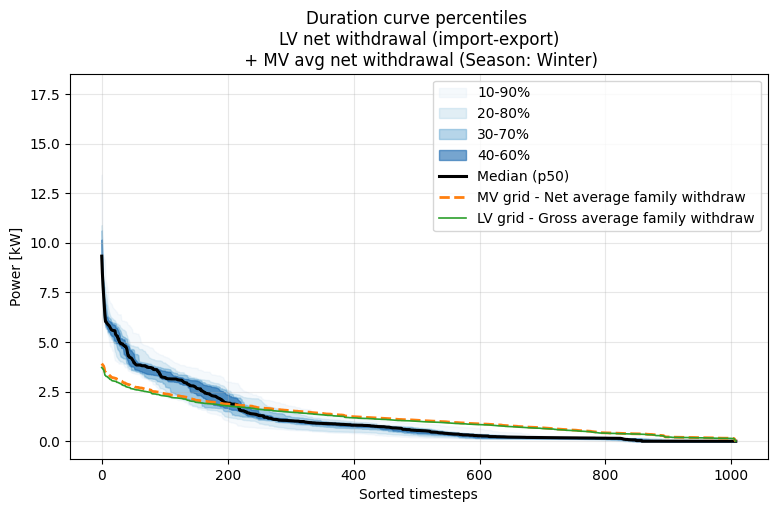

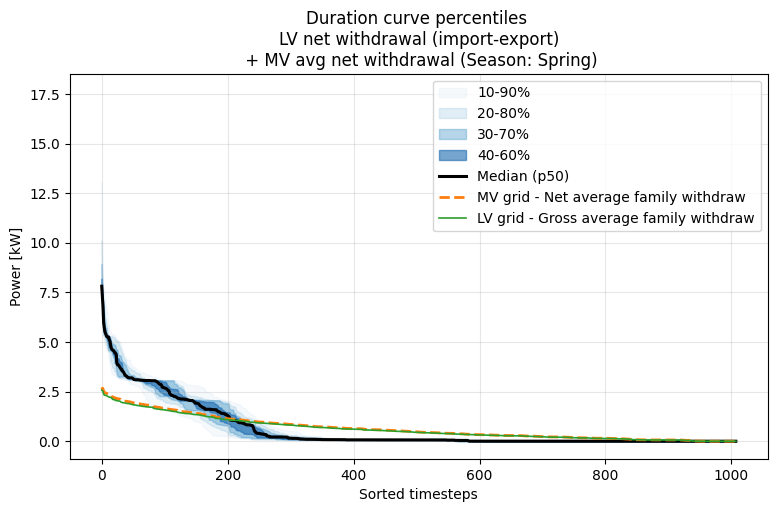

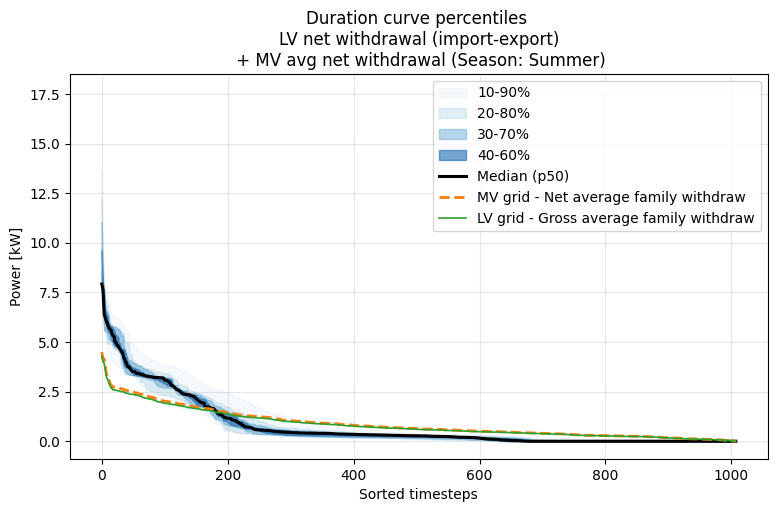

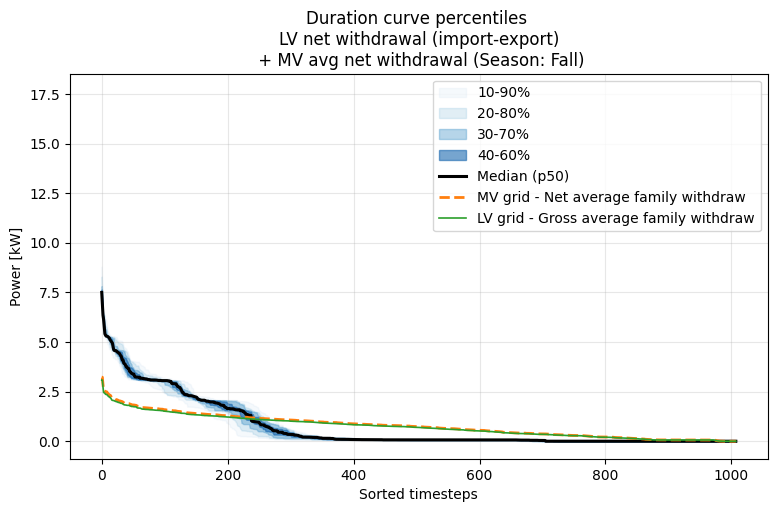

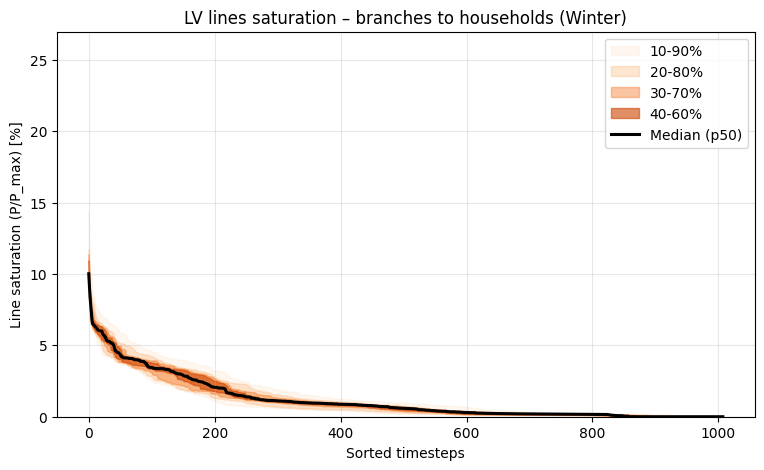

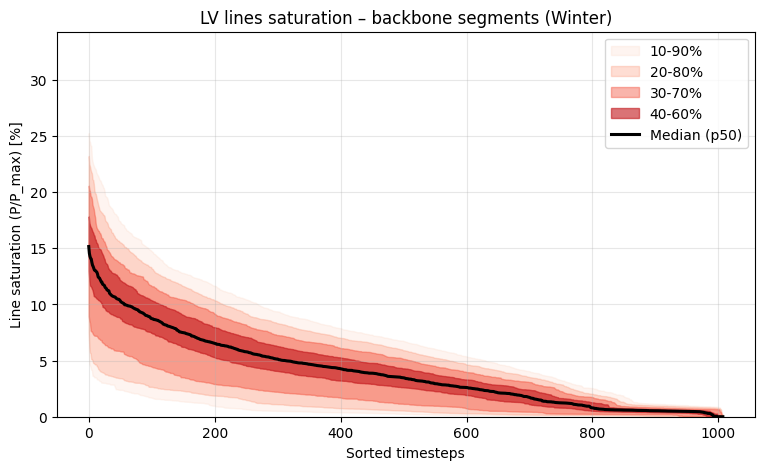

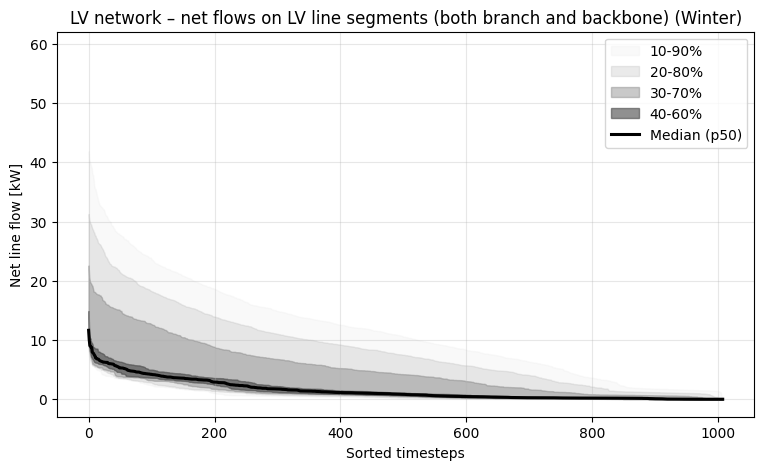

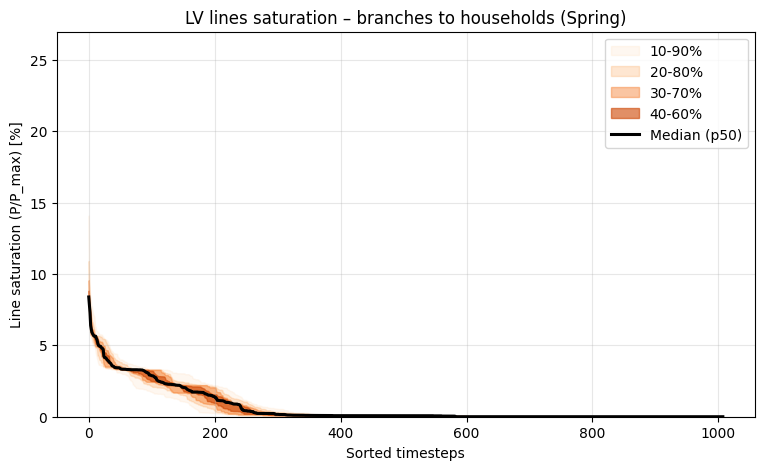

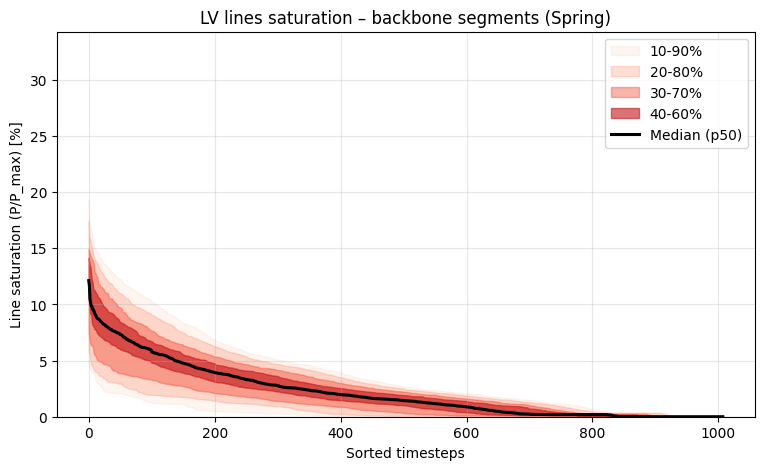

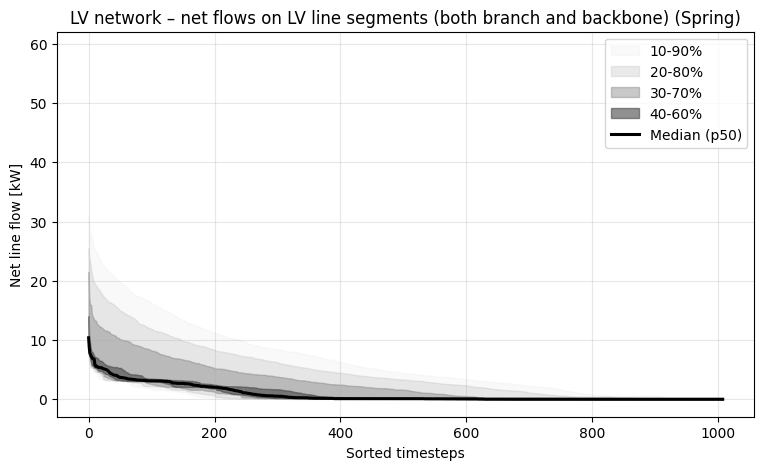

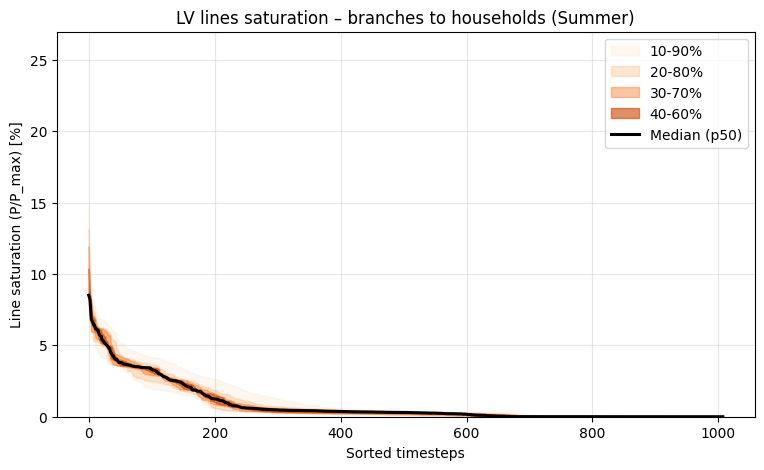

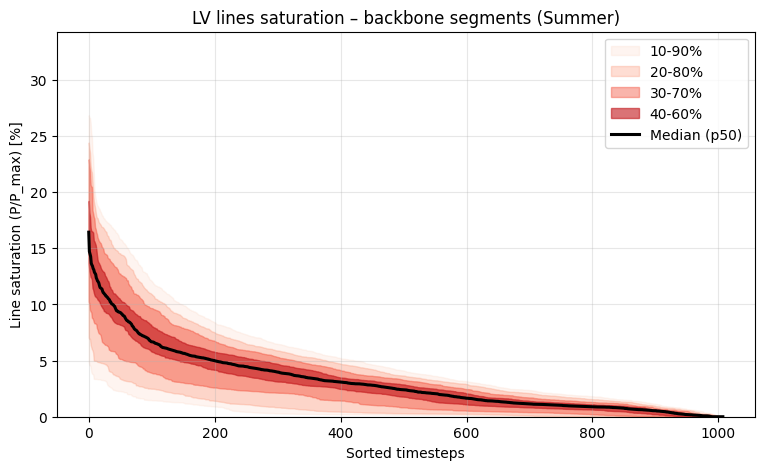

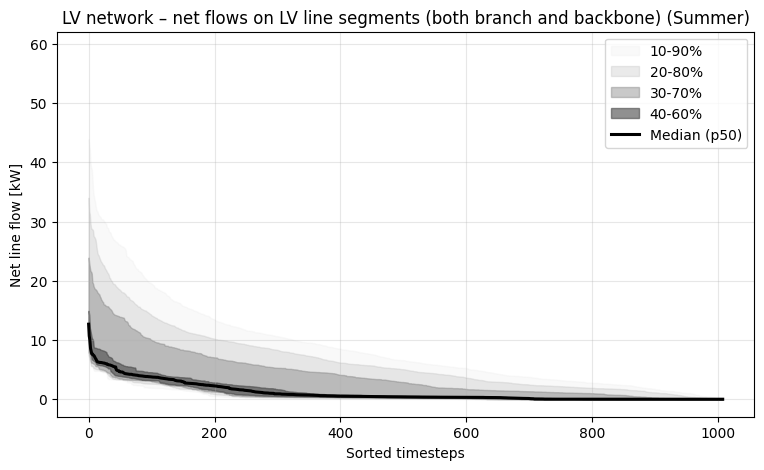

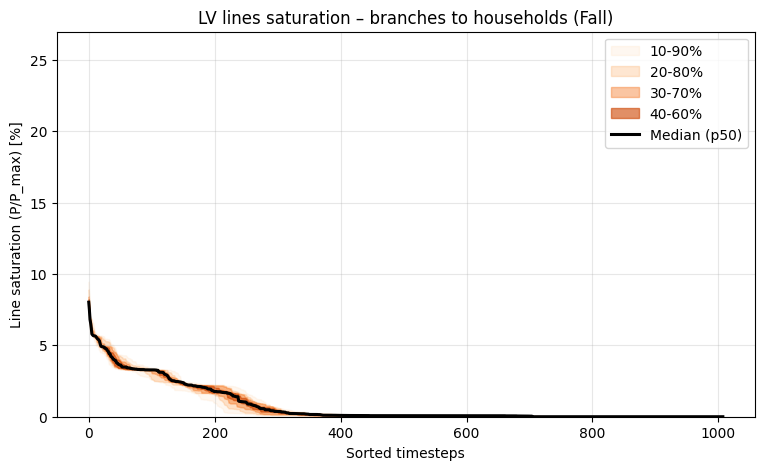

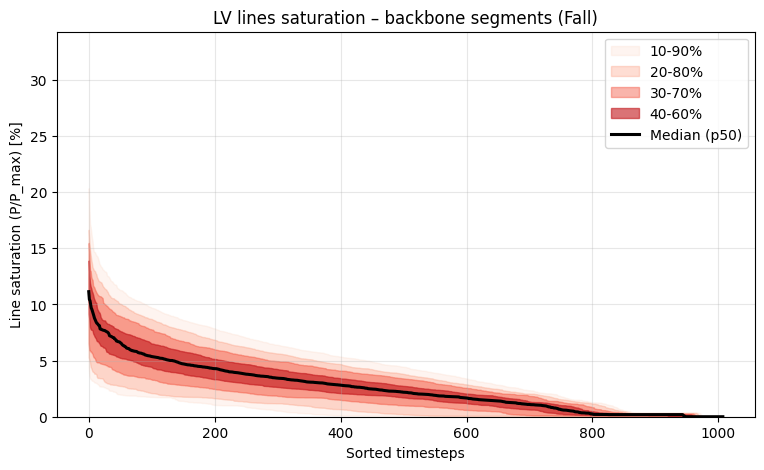

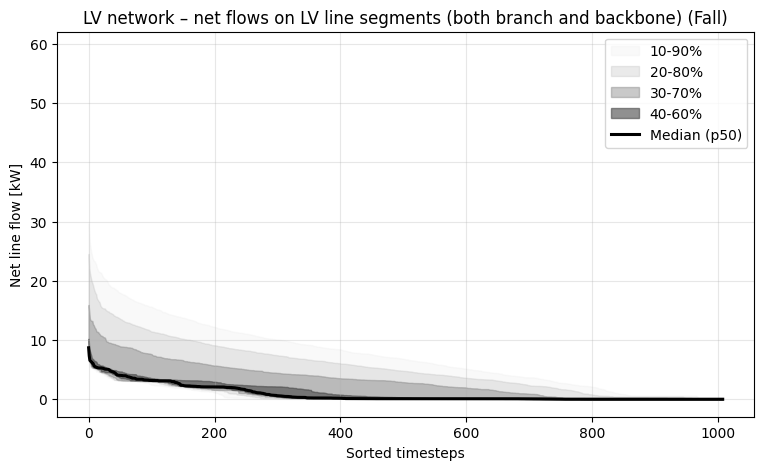

C:\Users\Francesco\AppData\Local\Temp\ipykernel_11100\3558198654.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)



[PLOT][4.11] MODE = MIX_BNO_VRB_HOPT
[PLOT][4.11] LABEL = BESS NO | EV RB | DHW OPT
[PLOT][4.11] CONTROL = {'BESS': 'NO', 'BEV': 'RB', 'DHW': 'OPT'}
[PLOT][4.11] Leggo pickle da: output\04_HGD_res_py\rural\MIX_BNO_VRB_HOPT
[PLOT][4.11] Salvo grafici in: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HOPT


Stagioni (settimane):   0%|          | 0/4 [00:00<?, ?it/s]

Top simultaneous forw&back (possible loops): [('line_forw_root_to_n001', 'line_back_n001_to_root', 0), ('line_forw_n001_to_h001', 'line_back_h001_to_n001', 0), ('line_forw_n001_to_n003', 'line_back_n003_to_n001', 0), ('line_forw_n003_to_h002', 'line_back_h002_to_n003', 0), ('line_forw_n003_to_n005', 'line_back_n005_to_n003', 0), ('line_forw_n005_to_h003', 'line_back_h003_to_n005', 0), ('line_forw_n005_to_n006', 'line_back_n006_to_n005', 0), ('line_forw_n006_to_h004', 'line_back_h004_to_n006', 0), ('line_forw_n006_to_n007', 'line_back_n007_to_n006', 0), ('line_forw_n007_to_h005', 'line_back_h005_to_n007', 0)]
[INFO][MIX_BNO_VRB_HOPT] BESS active da config: 0 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HOPT] DHW  active da config: 14 | inferiti da pkl: 14
[INFO][MIX_BNO_VRB_HOPT] BEV  active da config: 14 | inferiti da pkl: 0
[CHECK] df_result_rete_BT_lines max abs (post-load) = 47.53004096474734
Generando grafico per il periodo 2023-02-15 00:00:00 - 2023-02-21 23:50:00
[INFO][SOC PLOT] Skip

Stagioni (settimane):  25%|██▌       | 1/4 [00:07<00:22,  7.39s/it]

...

[INFO][SOC PLOT] Salvato: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HOPT\soc_bev_percentiles_rb_primavera.png
Top simultaneous forw&back (possible loops): [('line_forw_root_to_n001', 'line_back_n001_to_root', 0), ('line_forw_n001_to_h001', 'line_back_h001_to_n001', 0), ('line_forw_n001_to_n003', 'line_back_n003_to_n001', 0), ('line_forw_n003_to_h002', 'line_back_h002_to_n003', 0), ('line_forw_n003_to_n005', 'line_back_n005_to_n003', 0), ('line_forw_n005_to_h003', 'line_back_h003_to_n005', 0), ('line_forw_n005_to_n006', 'line_back_n006_to_n005', 0), ('line_forw_n006_to_h004', 'line_back_h004_to_n006', 0), ('line_forw_n006_to_n007', 'line_back_n007_to_n006', 0), ('line_forw_n007_to_h005', 'line_back_h005_to_n007', 0)]
[INFO][MIX_BNO_VRB_HOPT] BESS active da config: 0 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HOPT] DHW  active da config: 14 | inferiti da pkl: 14
[INFO][MIX_BNO_VRB_HOPT] BEV  active da config: 14 | inferiti da pkl: 0
[CHECK] df_result_rete_BT_lines max abs (post-load) = 51.04

Stagioni (settimane):  75%|███████▌  | 3/4 [00:26<00:08,  8.46s/it]

[INFO][SOC PLOT] Salvato: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HOPT\soc_bev_percentiles_rb_estate.png
Top simultaneous forw&back (possible loops): [('line_forw_root_to_n001', 'line_back_n001_to_root', 0), ('line_forw_n001_to_h001', 'line_back_h001_to_n001', 0), ('line_forw_n001_to_n003', 'line_back_n003_to_n001', 0), ('line_forw_n003_to_h002', 'line_back_h002_to_n003', 0), ('line_forw_n003_to_n005', 'line_back_n005_to_n003', 0), ('line_forw_n005_to_h003', 'line_back_h003_to_n005', 0), ('line_forw_n005_to_n006', 'line_back_n006_to_n005', 0), ('line_forw_n006_to_h004', 'line_back_h004_to_n006', 0), ('line_forw_n006_to_n007', 'line_back_n007_to_n006', 0), ('line_forw_n007_to_h005', 'line_back_h005_to_n007', 0)]
[INFO][MIX_BNO_VRB_HOPT] BESS active da config: 0 | inferiti da pkl: 0
[INFO][MIX_BNO_VRB_HOPT] DHW  active da config: 14 | inferiti da pkl: 14
[INFO][MIX_BNO_VRB_HOPT] BEV  active da config: 14 | inferiti da pkl: 0
[CHECK] df_result_rete_BT_lines max abs (post-load) = 36.87557

Stagioni (settimane): 100%|██████████| 4/4 [00:31<00:00,  7.86s/it]

[INFO][SOC PLOT] Salvato: output\04_HGD_res_pics\rural\MIX_BNO_VRB_HOPT\soc_bev_percentiles_rb_autunno.png


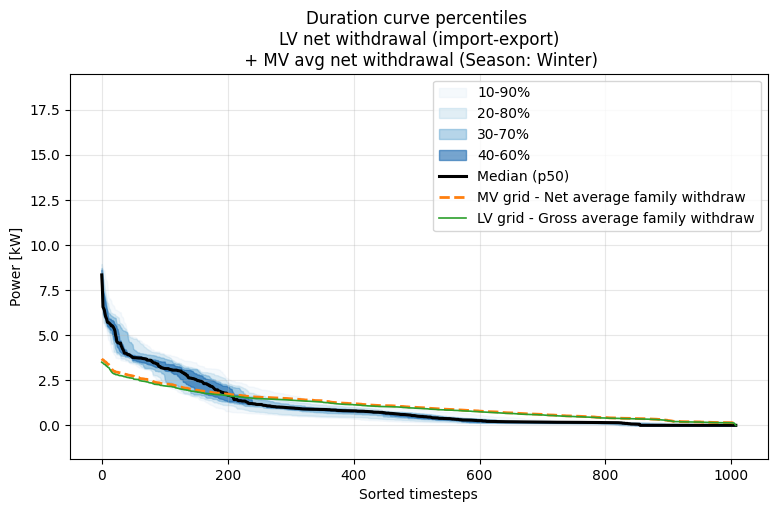

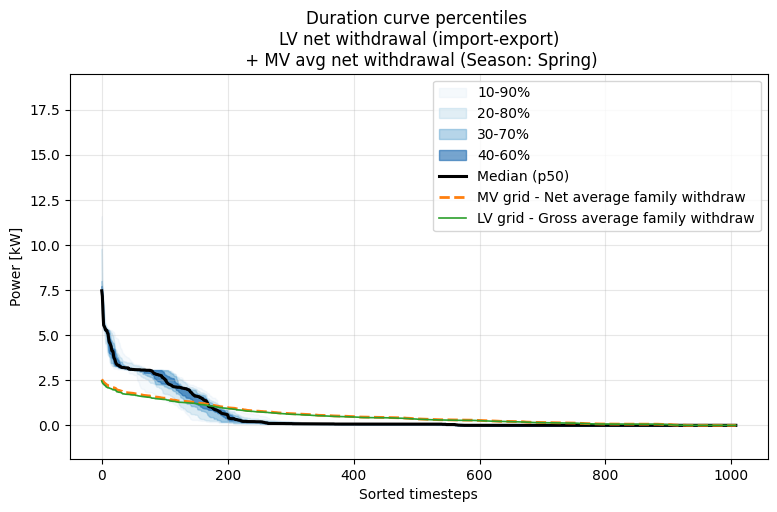

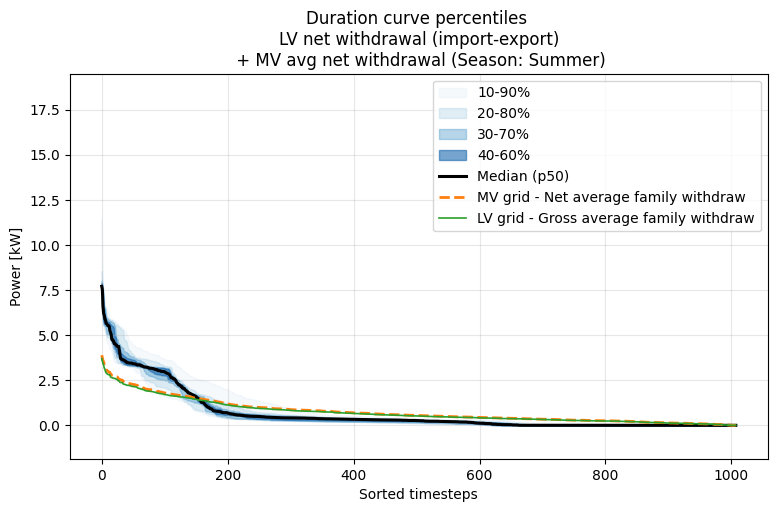

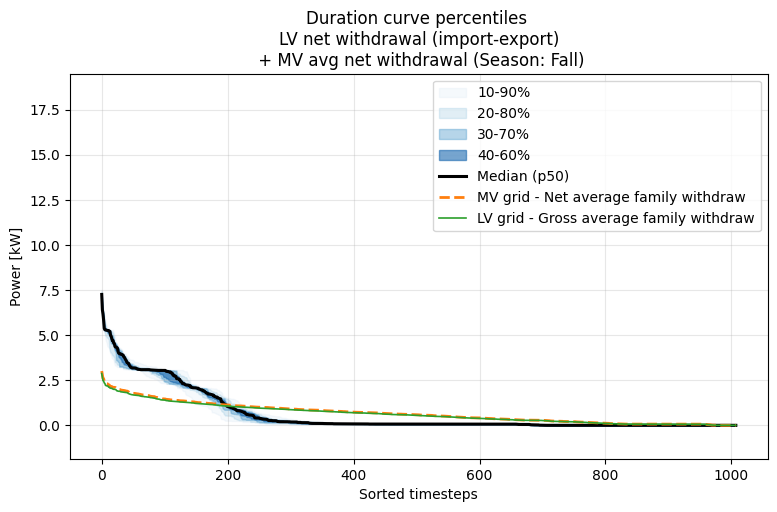

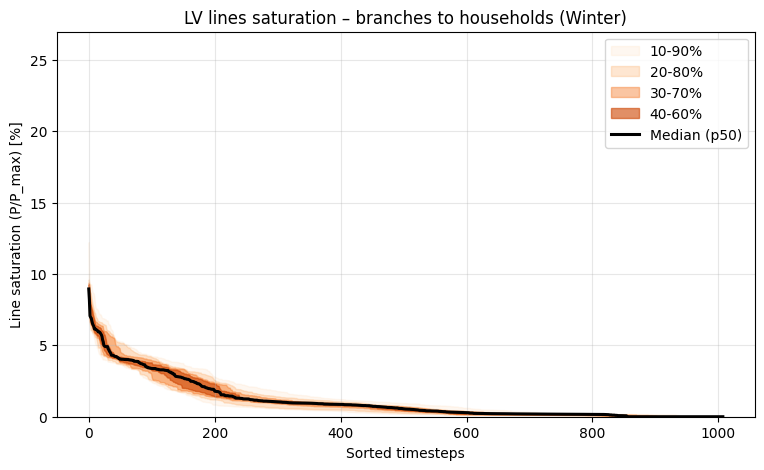

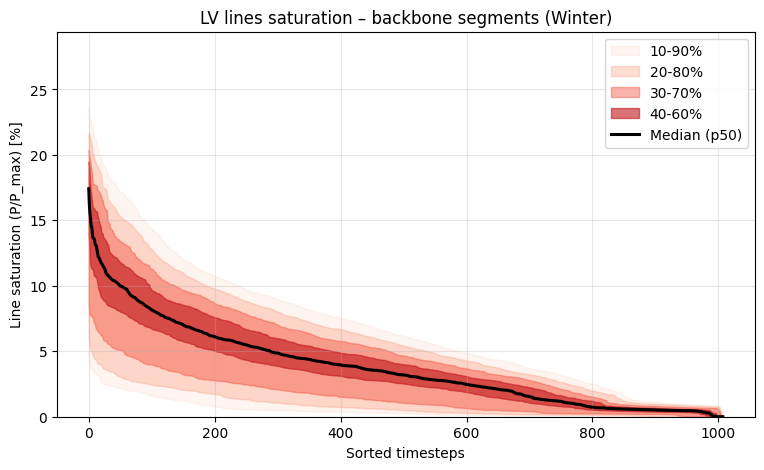

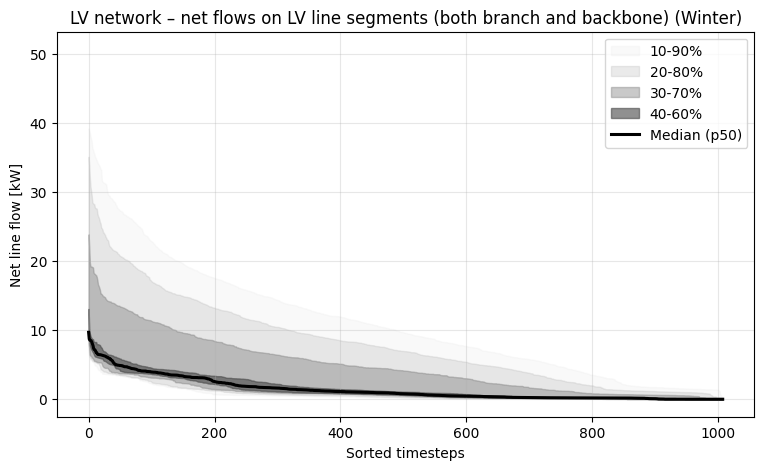

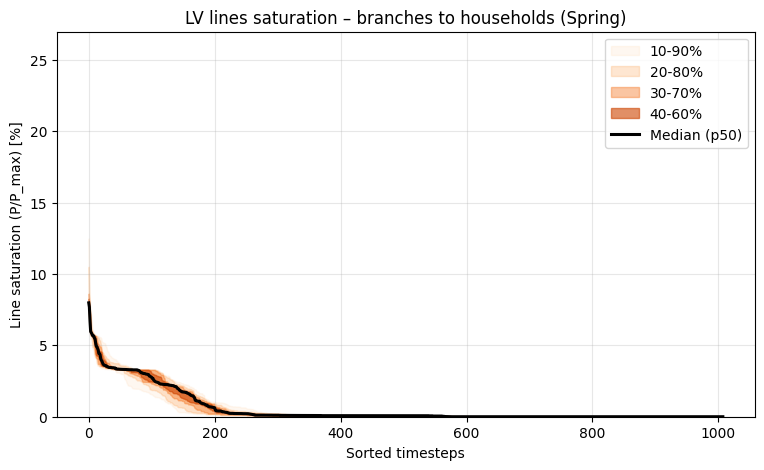

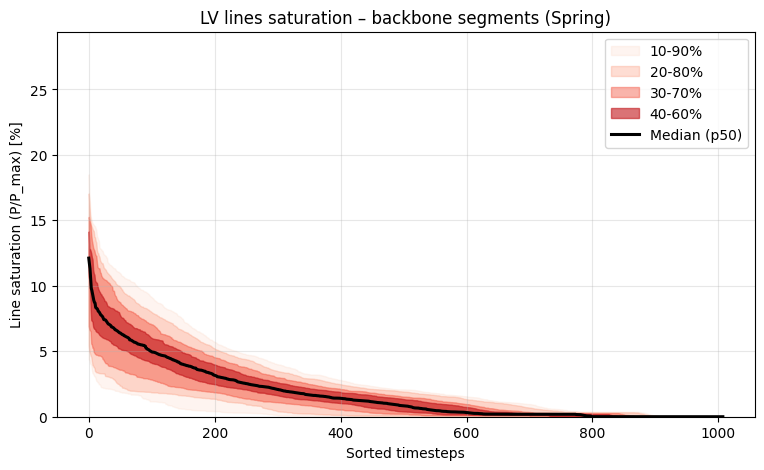

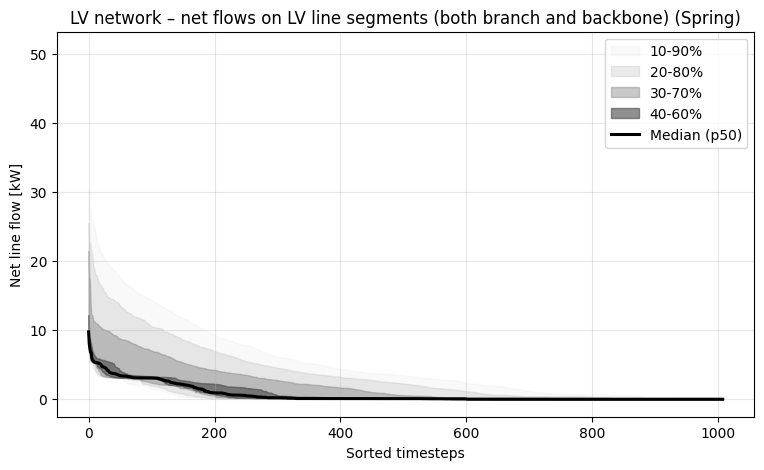

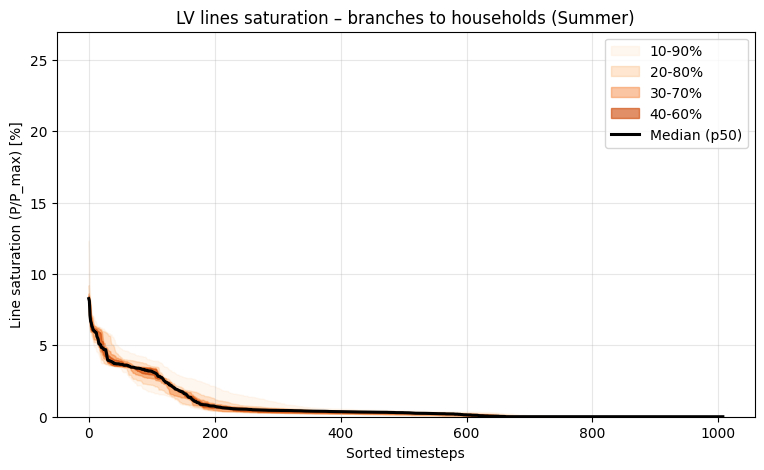

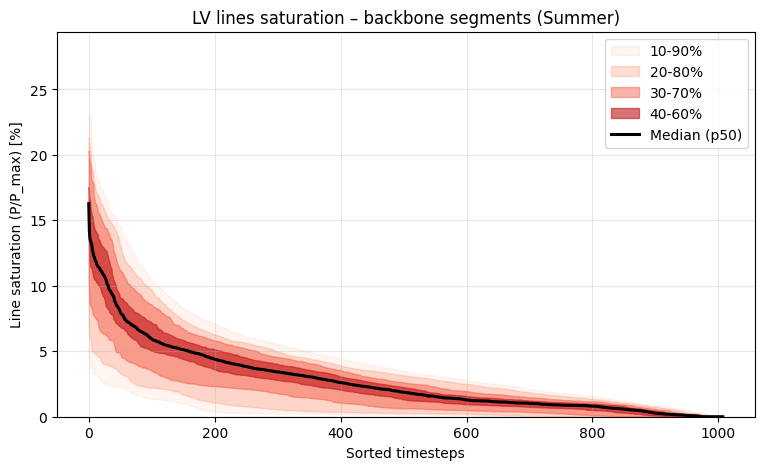

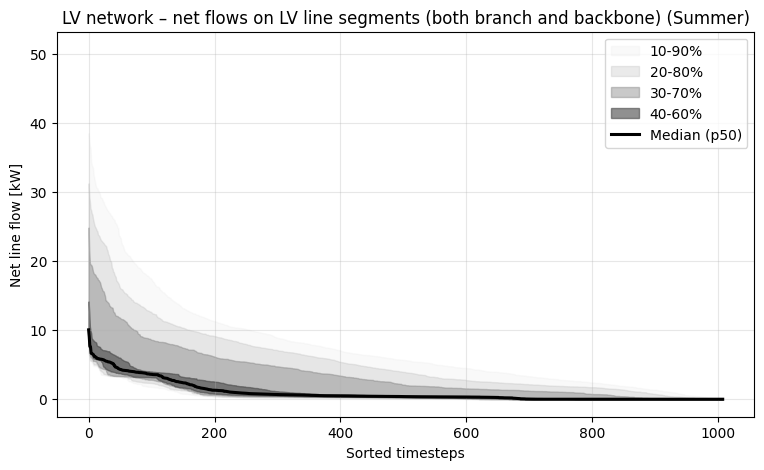

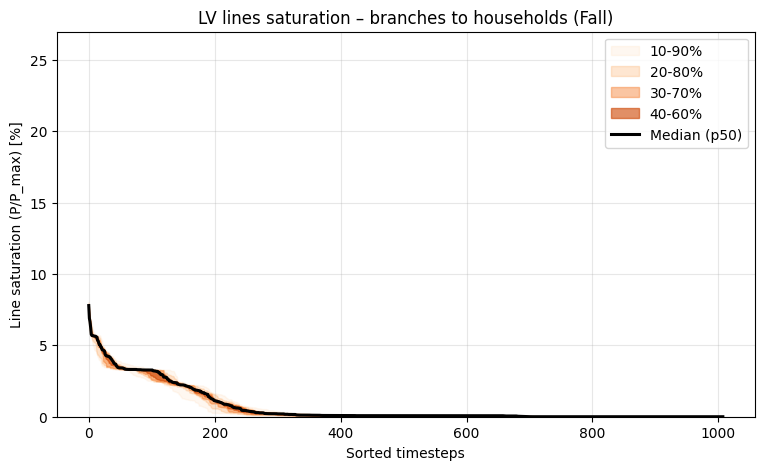

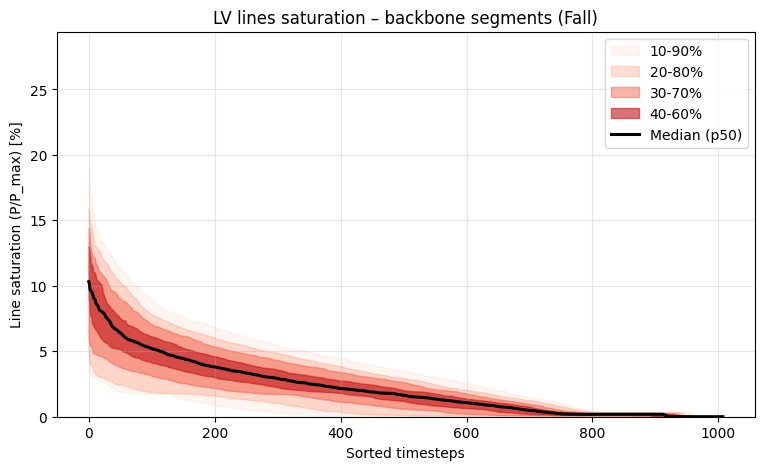

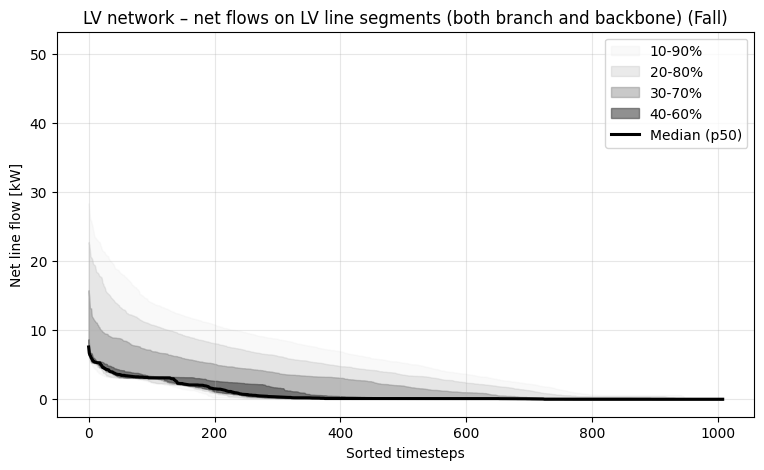

In [ ]:

# -----------------------------------------------------------------------------
#               Sec 4.11 -- 0) GLOBAL LIMITS (y-limits) per uniformare i grafici tra stagioni
# -----------------------------------------------------------------------------

# Definisco la variabile per scegliere il massimo da rappresentare sugli assi grafici generazione-domanda (sia Opt che RB) e su curve durata
ymax_gen_dmd_global = None
ymax_net_bt_global = -np.inf
ymin_net_bt_global =  np.inf
ymax_mt_global = -np.inf
ymin_mt_global =  np.inf

if RUN_PLOT_SCENARIO_GRAPHS:

    # -----------
    #   Sec 4.11 -- Loop stampa grafici su ogni configurazione analizzata in ""
    
    PLOT_RUN_CONFIGS = build_plot_run_configs_from_run_control_configs()            

    if len(PLOT_RUN_CONFIGS) == 0:
        print("[INFO][4.11] Nessuna configurazione da plottare. " "Controlla RUN_MIXED_TECH_CONTROL, RUN_CONTROL_CONFIGS, RUN_OPT, RUN_RULE_BASED.")


    for RUN_CFG_PLOT in PLOT_RUN_CONFIGS:
                
        # ============================================================
        # Sec 4.11 -- LOOP ESTERNO SULLE CONFIGURAZIONI
        # ============================================================

        MODE_PLOT = RUN_CFG_PLOT["mode"]
        MODE_LABEL_PLOT = RUN_CFG_PLOT.get("label", MODE_PLOT)
        CONTROL_MODE_PLOT = RUN_CFG_PLOT.get("control", {})
        RUN_SHARES_PLOT = _shares_from_cfg_or_global(RUN_CFG_PLOT)

        RUN_DIRS_PLOT = set_hagrid_output_dirs_for_mode(
            mode=MODE_PLOT,
            shares=RUN_SHARES_PLOT,
        )


        # Ricostruisco la dotazione attiva della configurazione da plottare.
        HAS_POTENTIAL_PLOT = _potential_has_for_config_shares(
            has_global=has,
            cfg_shares=RUN_SHARES_PLOT,
        )

        HAS_RUN_PLOT = _active_has_for_run(
            has_global=HAS_POTENTIAL_PLOT,
            control=CONTROL_MODE_PLOT,
        )

        has_FV_plot   = HAS_RUN_PLOT["FV"]
        has_BESS_plot = HAS_RUN_PLOT["BESS"]
        has_BEV_plot  = HAS_RUN_PLOT["BEV"]
        has_DHW_plot  = HAS_RUN_PLOT["DHW"]


        print("\n" + "=" * 100)
        print(f"[PLOT][4.11] MODE = {MODE_PLOT}")
        print(f"[PLOT][4.11] LABEL = {MODE_LABEL_PLOT}")
        print(f"[PLOT][4.11] CONTROL = {CONTROL_MODE_PLOT}")
        print(f"[PLOT][4.11] Leggo pickle da: {cartella_output_py_based}")
        print(f"[PLOT][4.11] Salvo grafici in: {cartella_output_ottimiz_graph}")
        print("=" * 100)

        os.makedirs(cartella_output_ottimiz_graph, exist_ok=True)




        # -----------------------------------------------------------------------------
        #               Sec 4.11 -- 0.bis) Costruzione CONTENITORE informazioni CONGESTIONE RETE LV
        # -----------------------------------------------------------------------------

        kerber_line_recipes = []
        if BT_ARCHETYPE in KERBER_BLUEPRINT_FILES:
            for e in KERBER_BP["lines_lv"]:
                fb = int(e["from_bus"])
                tb = int(e["to_bus"])
                a_key = KERBER_BUS_ID_TO_LABEL[fb]
                b_key = KERBER_BUS_ID_TO_LABEL[tb]
                a_s = _short_bt_bus_label(a_key)   # es: n001 / root / h001
                b_s = _short_bt_bus_label(b_key)

                # tipologia del pezzo di rete considerato (dorsale vs. verso utenza finale)
                role_a = KERBER_BUS_ROLE.get(a_key, "unknown")
                role_b = KERBER_BUS_ROLE.get(b_key, "unknown")

                # nominal capacity (kW) dal blueprint Kerber
                # pmax_kw = float(e.get("pmax_kw") or KERBER_DEFAULT_PMAX_KW)
                pmax_kw = _get_kerber_line_p_limit_kw(e, PF_LINE_LIMITS_MAP)

                # ramo utenza se tocca un bus "house" (h00Y), altrimenti dorsale
                kind = "branch_house" if ("house" in (role_a, role_b) or a_s.startswith("h") or b_s.startswith("h")) else "backbone"

                kerber_line_recipes.append({
                    "a_key": a_key, "b_key": b_key,
                    "a_s": a_s, "b_s": b_s,
                    "lab_forw": f"line_forw_{a_s}_to_{b_s}",
                    "lab_back": f"line_back_{b_s}_to_{a_s}",
                    "role_a": role_a, "role_b": role_b,
                    "pmax_kw": pmax_kw,
                    "kind": kind,
                })
        




        # ---------------------------------------------------------------------------------------------------------
        #               Sec 4.11 -- 1)  DEFINIZIONE COLORI/AREE/DIZIONARI COSTRUZIONE GRAFICI
        # --------------------------------------------------------------------------------------------------------- 
        # Richiamo la struttura degli elementi (colonne, aree, colori) da inserire nel grafico generazione-domanda
        # che vado ad usare sia in caso Opt che caso RB
        colonne_per_aree, colonne_per_linee, colori_colonne_gen, colori_colonne_dom, nomi_colonne = \
            init_gen_dmd_plot_maps(CATEGORIE_FLEX, make_gradient)



    # ---------------------------------------------------------------------------------------------------------
    #               Sec 4.11 -- 2)  PRIMO PASS (per stagione): carica dati, costruisce df plot, aggiorna limiti grafici
    # ----------------------------------------------------------------------------------------------------------
    # if RUN_GRAFICI_CONFIGS:

        # --------------------------------------------------
        #           Sec 4.11 -- 2.0) inizializza cache e massimi globali
        # --------------------------------------------------

        # massimo globale per asse Y (Generation/Demand), calcolato su stack cumulato
        ymax_gen_dmd_global = 0.0
        
        # qui salveremo i df già pronti per il plot
        df_opt_plot_data = {}
        ymax_tmp = 0.0

        # qui salvo le informazioni per le curve di durata
        durcurve_cache = {}
        durcurve_mt_cache = {}  

        # cache per curve di durata import BT (percentili) e congestione linee LV (Kerber)
        durcurve_import_bt_cache = {}
        durcurve_lv_lines_cache  = {}

        # limiti globali (uniformazione assi Y tra stagioni) per categorie di grafici
        ymax_import_bt_global = -np.inf
        ymin_import_bt_global =  np.inf

        ymax_net_lines_global = -np.inf
        ymin_net_lines_global =  np.inf

        ymax_sat_branch_global   = -np.inf
        ymax_sat_backbone_global = -np.inf



        # ----------------------------------  
        #         1_vecchio)  DEFINIZIONE COLORI/AREE/DIZIONARI COSTRUZIONE GRAFICI (prima veniva fatto qui)
        # ----------------------------------  
        # Anticipato con una funzione
        # -----------------------------------





        # ---------------------------------------------------------------------------------------------------------
        #               Sec 4.11 -- 2.1)  LOOP SULLE STAGIONI (import dati e costruzione grafici) (caso Opt)
        # ---------------------------------------------------------------------------------------------------------  
        
        stagioni_plot = globals().get("PLOT_ONLY_SEASONS", None)

        if stagioni_plot is None:
            stagioni_plot = stagioni
        else:
            stagioni_plot = [s for s in stagioni_plot if s in stagioni]

        for stagione_scelta in tqdm(stagioni_plot, desc="Stagioni (settimane)"):
            
            # -------------------------------------
            #           Sec 4.11 -- 2.1.1) file Input/Output
            # -------------------------------------
            # File input pickle per questa configurazione e stagione
            filename_pov_case = resolve_flow_pickle_path("flow_el_df", stagione_scelta, mode=MODE_PLOT,)
            filename_pov_BT = resolve_flow_pickle_path("flow_grid_df", stagione_scelta, mode=MODE_PLOT,)
            filename_pov_BT_root = resolve_flow_pickle_path("flow_grid_root",stagione_scelta, mode=MODE_PLOT,)
            file_dhw_use = resolve_flow_pickle_path("flow_DHW_use_df", stagione_scelta, mode=MODE_PLOT, required=False,)
            file_bev_charge = resolve_flow_pickle_path("flow_charge_el_BEV_df", stagione_scelta, mode=MODE_PLOT, required=False,)
            file_bev_dis = resolve_flow_pickle_path("flow_discharge_el_BEV_df", stagione_scelta, mode=MODE_PLOT, required=False,)
            
            file_line_LV_grid = resolve_flow_pickle_path("flow_grid_lines_only_df", stagione_scelta, mode=MODE_PLOT, required=False,)


            # Estrai il nome del file senza il percorso e l'estensione
            nome_file = os.path.basename(filename_pov_case).replace('.pkl.gz', '')
            
            # Suddividi il nome in parti e seleziona solo il numero di case e la data (VECCHIA NOMENCLATURA)
            parti_nome = nome_file.split('_')                                   # Divide la stringa in base agli underscore (_)
            numero_case = n_nuclei_familiari        

            num_induz = share_induzione
            num_FV = share_FV               
            num_BESS = share_BESS            
            num_cooler = share_cooler
            num_pdc = share_PdC
            stagione = stagione_scelta
            regione = regione_selezionata       
                    
            # Caricamento file nella configurazione attuale
            df_raw_case = carica_dataframe(filename_pov_case)
            df_result_rete_BT = carica_dataframe(filename_pov_BT)               # Include tutti i soli bus lungo la dorsale
            df_result_rete_BT_root = carica_dataframe(filename_pov_BT_root)     # Include solo il bus da cabina secondaria a inizio dorsale
            df_dhw_use = carica_dataframe(file_dhw_use)
            df_bev_charge = carica_dataframe(file_bev_charge)
            df_bev_dis = carica_dataframe(file_bev_dis)
            df_result_rete_BT_lines = carica_dataframe(file_line_LV_grid)




            # ---------------------------
            #   Sec 4.11 -- 2.1.1bis) DEBUG: controllo se vi siano flussi bidirezionali lungo la rete BT
            # ---------------------------
            # check: quante volte forw e back sono entrambi > 0 (possibili loop/artefatti)
            eps = 1e-6
            pairs = []
            for r in kerber_line_recipes:
                cf = (r["lab_forw"], r["b_key"], "flow")
                cb = (r["lab_back"], r["a_key"], "flow")
                if cf in df_result_rete_BT_lines.columns and cb in df_result_rete_BT_lines.columns:
                    forw = pd.to_numeric(df_result_rete_BT_lines[cf], errors="coerce").fillna(0.0)
                    back = pd.to_numeric(df_result_rete_BT_lines[cb], errors="coerce").fillna(0.0)
                    both = int(((forw > eps) & (back > eps)).sum())
                    pairs.append((r["lab_forw"], r["lab_back"], both))

            pairs = sorted(pairs, key=lambda x: x[2], reverse=True)
            print("Top simultaneous forw&back (possible loops):", pairs[:10])
            # -----------------------------------------------------------------------



            # -------------------------------------
            #       Sec 4.11 -- 2.1.2) flussi storage: DHW e BEV (pre-merge)
            # -------------------------------------

            # --- flussi per DHW storage: carica è in df_raw_case, scarica in df_dhw_use
            if df_dhw_use is not None:
                df_flussi_case_dhw = pd.concat([df_raw_case, df_dhw_use], axis=1)
            else:
                # fallback: solo elettrico (niente scarica DHW -> soc scende solo per perdite)
                print(f"[WARN DHW] Nessun df_dhw_use per stagione {stagione_scelta}, uso solo df_raw_case.")
                df_flussi_case_dhw = df_raw_case

            # --- flussi per BEV storage: charge + discharge
            dfs_bev = []
            if df_bev_charge is not None:
                dfs_bev.append(df_bev_charge)
            if df_bev_dis is not None:
                dfs_bev.append(df_bev_dis)

            if len(dfs_bev) > 0:
                df_flussi_case_bev = pd.concat(dfs_bev, axis=1)
            else:
                df_flussi_case_bev = None
                print(f"[WARN BEV] Nessun flow BEV per stagione {stagione_scelta}.")


            # -------------------------------------------------------------
            #       Sec 4.11 -- 2.1.3) identifica tecnologie realmente presenti nella configurazione plottata (da file)
            # -------------------------------------------------------------

            has_BESS_from_pkl = infer_has_bess_from_flows(df_raw_case)
            has_DHW_from_pkl  = infer_has_dhw_from_flows(df_flussi_case_dhw)
            has_BEV_from_pkl  = infer_has_bev_from_flows(df_bev_charge, df_bev_dis)

            # In mixed mode alcuni flussi RB non hanno gli stessi tag degli storage OPT.
            # Quindi la fonte principale resta HAS_RUN_PLOT.
            # L'inferenza da pkl è solo debug/sanity check.
            print(f"[INFO][{MODE_PLOT}] BESS active da config: {len(has_BESS_plot)} | inferiti da pkl: {len(has_BESS_from_pkl)}")
            print(f"[INFO][{MODE_PLOT}] DHW  active da config: {len(has_DHW_plot)} | inferiti da pkl: {len(has_DHW_from_pkl)}")
            print(f"[INFO][{MODE_PLOT}] BEV  active da config: {len(has_BEV_plot)} | inferiti da pkl: {len(has_BEV_from_pkl)}")


            # -------------------------------------------------------------
            #       Sec 4.11 -- 2.1.4) DHW: capacità/potenze SOLO per chi ha davvero DHW - BEV
            # -------------------------------------------------------------
            
            # DHW
            capacity_dhw_by_house_eff = {c: capacity_dhw_by_house[c]            for c in has_DHW_plot                if c in capacity_dhw_by_house}
            power_limit_dhw_by_house_eff = {c: power_limit_dhw_by_house[c]      for c in has_DHW_plot                if c in power_limit_dhw_by_house}
            loss_rate_dhw_by_house_eff = {c: loss_rate_dhw_by_house[c]          for c in has_DHW_plot                if c in loss_rate_dhw_by_house}
            initial_soc_dhw_by_house_eff = {c: initial_soc_dhw_by_house[c]      for c in has_DHW_plot                if c in initial_soc_dhw_by_house}
            
            
            # BEV
            bev_cap_eff = bev_cap_by_c.where(bev_cap_by_c.index.isin(has_BEV_plot), np.nan)

            capacity_bev_by_house = {c: float(bev_cap_eff.loc[c])
                for c in has_BEV_plot                if (c in bev_cap_eff.index)
                and pd.notna(bev_cap_eff.loc[c])   and (bev_cap_eff.loc[c] > 0)}


            initial_soc_bev_by_house = {
                c: initial_SoC_BEV * capacity_bev_by_house[c]
                for c in capacity_bev_by_house
            }


            # -------------------------------------------------------------
            #       Sec 4.11 -- 2.1.5) normalizza/appiattimento colonne
            # -------------------------------------------------------------
            df_result_el           = convert_busseq_to_flowtuple_df(df_raw_case)
            df_result_rete_BT      = convert_busseq_to_flowtuple_df(df_result_rete_BT)
            df_result_rete_BT_root = convert_busseq_to_flowtuple_df(df_result_rete_BT_root)

            df_flussi_case_dhw = convert_busseq_to_flowtuple_df(df_flussi_case_dhw)
            if df_flussi_case_bev is not None:
                df_flussi_case_bev = convert_busseq_to_flowtuple_df(df_flussi_case_bev)

            df_result_rete_BT_lines = convert_busseq_to_flowtuple_df(df_result_rete_BT_lines)
            # --- debug
            _tmp = df_result_rete_BT_lines.apply(pd.to_numeric, errors="coerce").fillna(0.0)
            print(f"[CHECK] df_result_rete_BT_lines max abs (post-load) = {float(_tmp.abs().to_numpy().max()) if _tmp.size else 0.0}")
            # -------------

            # -------------------------------------------------------------
            #       Sec 4.11 -- 2.1.6) Lettura flussi netti linee LV
            # -------------------------------------------------------------
            if plt_load_duration_LV_grid_lines:
                try:
                    net_line_outputs_plot = load_net_lines_outputs_for_plot(
                        stagione=stagione_scelta,
                        base_dir=cartella_output_ottimiz,
                    )

                    df_net_lines_ts_signed = net_line_outputs_plot["net_lines_ts_signed"]
                    df_net_lines_ts_for_dur = net_line_outputs_plot["net_lines_ts_for_dur"]
                    df_dur_net_lines = net_line_outputs_plot["durcurve_net_lines"]
                    df_lines_meta = net_line_outputs_plot["lines_meta"]
                    df_sat_lines_ts_pct = net_line_outputs_plot["sat_lines_ts_pct"]
                    df_dur_sat_lines = net_line_outputs_plot["durcurve_sat_lines_pct"]

                    if "kind" in df_lines_meta.columns:
                        s_kind = df_lines_meta["kind"]
                    else:
                        s_kind = pd.Series(index=df_dur_sat_lines.columns, dtype=object)

                    cols_branch = [
                        c for c in df_dur_sat_lines.columns
                        if s_kind.get(c) == "branch_house"
                    ]

                    cols_backbone = [
                        c for c in df_dur_sat_lines.columns
                        if s_kind.get(c) == "backbone"
                    ]

                    pct = (10, 20, 30, 40, 50, 60, 70, 80, 90)

                    durcurve_lv_lines_cache[stagione_scelta] = {
                        "df_dur_net_lines": df_dur_net_lines,
                        "df_dur_sat_lines": df_dur_sat_lines,
                        "cols_branch": cols_branch,
                        "cols_backbone": cols_backbone,
                        "pct": pct,
                    }

                    _arr_lines = df_dur_net_lines.to_numpy(dtype=float)
                    _arr_lines = _arr_lines[np.isfinite(_arr_lines)]

                    if _arr_lines.size:
                        ymax_net_lines_global = max(ymax_net_lines_global, float(_arr_lines.max()))
                        ymin_net_lines_global = min(ymin_net_lines_global, float(_arr_lines.min()))

                    if df_dur_sat_lines is not None and not df_dur_sat_lines.empty:
                        if cols_branch:
                            _arr_sb = df_dur_sat_lines[cols_branch].to_numpy(dtype=float)
                            _arr_sb = _arr_sb[np.isfinite(_arr_sb)]
                            if _arr_sb.size:
                                ymax_sat_branch_global = max(ymax_sat_branch_global, float(_arr_sb.max()))

                        if cols_backbone:
                            _arr_sbb = df_dur_sat_lines[cols_backbone].to_numpy(dtype=float)
                            _arr_sbb = _arr_sbb[np.isfinite(_arr_sbb)]
                            if _arr_sbb.size:
                                ymax_sat_backbone_global = max(ymax_sat_backbone_global, float(_arr_sbb.max()))

                except FileNotFoundError as e:
                    print(f"[WARN][4.11][NET LINES] {e}")


            # --------------------------------------------
            #       Sec 4.11 -- 2.2) CURVE DI DURATA flussi IMPORT BT (caso Opt) -> case
            #      e calcolo UTILIZZO BOOST in DHW
            # --------------------------------------------
            dt_hours = _dt_hours_from_index(df_raw_case.index, timestep_minutes_fallback=timestep_minutes)
            
            import_bt_dict = extract_import_bt_series_by_house(df_result_el, ID)
            export_bt_dict = extract_export_bt_series_by_house(df_result_el, ID)
            net_bt_dict    = compute_net_bt_by_house(import_bt_dict, export_bt_dict)


            # Curva di durata del solo import domestico da rete BT & curva durata del NETTO (import-cessione a) domestico da rete BT
            df_dur_import_bt = build_duration_curves(import_bt_dict)    if import_bt_dict else pd.DataFrame()
            df_dur_net_bt = build_duration_curves(net_bt_dict)          if net_bt_dict    else pd.DataFrame()       

            # numero timestep settimana (10')
            n_ts_week = len(next(iter(import_bt_dict.values()))) if import_bt_dict else 1008

            # (Two-pass) cache + limiti globali per curve durata IMPORT BT (percentili)
            if (df_dur_import_bt is not None) and (not df_dur_import_bt.empty):
                durcurve_import_bt_cache[stagione_scelta] = {
                    "df_dur_import_bt": df_dur_import_bt,
                    "dt_hours": dt_hours,
                }
                _arr_imp = df_dur_import_bt.to_numpy(dtype=float)
                _arr_imp = _arr_imp[np.isfinite(_arr_imp)]
                if _arr_imp.size:
                    ymax_import_bt_global = max(ymax_import_bt_global, float(_arr_imp.max()))
                    ymin_import_bt_global = min(ymin_import_bt_global, float(_arr_imp.min()))




            # --------------------------------------------
            #       Sec 4.11 -- 2.2.1) Calcolo flussi scambiati con rete MT
    
            # bus BT “root” verso MT
            bt_root = BT_ROOT_LABEL if BT_ROOT_LABEL is not None else ("bus_el_BT" if BT_ARCHETYPE == "single_bus" else "bus_el_BT_0")

            col_imp_mv = ('supply_from_grid_MT', bt_root, 'flow')
            col_exp_mv = (bt_root, 'excess_to_grid_MT', 'flow')

            s_imp_mv = pd.to_numeric(df_result_rete_BT_root[col_imp_mv], errors='coerce').fillna(0.0) if col_imp_mv in df_result_rete_BT_root.columns else pd.Series(0.0, index=df_result_rete_BT_root.index)
            s_exp_mv = pd.to_numeric(df_result_rete_BT_root[col_exp_mv], errors='coerce').fillna(0.0) if col_exp_mv in df_result_rete_BT_root.columns else pd.Series(0.0, index=df_result_rete_BT_root.index)

            s_net_mv = s_imp_mv - s_exp_mv                              # <--- quanto il quartiere chiede complessivamente a MT
            s_net_mv_avg = s_net_mv / float(n_nuclei_familiari)         # <--- quanto viene richiesto da una famiglia "media" (totale richiesta a rete MT/n° utenze nel quartiere; serve per vedere tasso di contemporaneità)

            # curva durata (quartiere)
            dur_mt = duration_curve_from_series(s_net_mv)

            # curva durata (famiglia media)
            dur_mt_avg = duration_curve_from_series(s_net_mv_avg)

            ymax_mt_global = max(ymax_mt_global, float(max(dur_mt.max(), dur_mt_avg.max())))
            ymin_mt_global = min(ymin_mt_global, float(min(dur_mt.min(), dur_mt_avg.min())))

            # salva per secondo pass
            durcurve_mt_cache[stagione_scelta] = {"dur_mt": dur_mt, "dur_mt_avg": dur_mt_avg}



            # --------------------------------------------
            #       Sec 4.11 -- 2.2.2) Curva durata della sommma prelievi da rete BT verso case (contemporaneità richiesta utenze)
            #           (LV “gross avg”: somma import BT di tutte le case / n_famiglie)


            # Se non c'è import_bt_dict, fallback a serie a zero coerente con indice
            if import_bt_dict:
                # DataFrame con colonne = case (c_1, c_2, ...), index = timesteps
                df_import_bt_all = pd.DataFrame(import_bt_dict)

                # Serie totale import da BT (kW) per timestep: somma su tutte le case
                total_import_bt = df_import_bt_all.sum(axis=1).fillna(0.0)   # kW

            else:
                # fallback: serie di zeri con indice coerente
                total_import_bt = pd.Series(0.0, index=df_result_el.index)

            # Curva di durata totale (ordinata decrescente) come Series indicizzata 0..N-1
            s_import_duration_total = pd.Series(np.sort(total_import_bt.values)[::-1]).reset_index(drop=True)

            # Curva di durata PER NUCLEO: divido per numero famiglie
            s_import_mv_avg = s_import_duration_total / float(n_nuclei_familiari)

            # cache per secondo pass: salvo df_dur_net_bt, overlay net MV avg e overlay import BT (Low Voltage LV) avg
            durcurve_cache[stagione_scelta] = {
                "df_dur_net_bt": df_dur_net_bt,
                "s_net_mv_avg": s_net_mv_avg,
                "s_import_mv_avg": s_import_mv_avg,
                "dt_hours": dt_hours,
            }
        

            # --------------------------------------------
            #      Sec 4.11 -- 2.2.3) aggiorna limiti globali (su asse Y grafici) curve durata BT

            if (df_dur_net_bt is not None) and (not df_dur_net_bt.empty):
                p95_series = df_dur_net_bt.quantile(0.95, axis=1)  # index=rank
                p05_series = df_dur_net_bt.quantile(0.05, axis=1)

                # overlay MT avg in durata
                dur_mv_avg = duration_curve_from_series(s_net_mv_avg)
                dur_import_mv_avg = duration_curve_from_series(s_import_mv_avg)

                ymax_here = max(float(p95_series.max()), float(dur_mv_avg.max()), float(dur_import_mv_avg.max()))
                ymin_here = min(float(p05_series.min()), float(dur_mv_avg.min()), float(dur_import_mv_avg.min()))

                ymax_net_bt_global = max(ymax_net_bt_global, ymax_here)
                ymin_net_bt_global = min(ymin_net_bt_global, ymin_here)





            # --------------------------------------------
            #       Sec 4.11 -- 2.4)  CLASSIFICAZIONE CASE PER FLESSIBILITà
            # --------------------------------------------

            categorie_da_aggregare = {
                "case_0": [],
                "case_B": [],
                "case_V": [],
                "case_H": [],
                "case_BV": [],
                "case_BH": [],
                "case_VH": [],
                "case_BVH": [],
            }

            for c in ID:
                cat = classify_flex_case(
                    c,
                    has_BESS_plot,
                    has_BEV_plot,
                    has_DHW_plot,
                )
                categorie_da_aggregare[cat].append(c)

            case_0   = categorie_da_aggregare["case_0"]
            case_B   = categorie_da_aggregare["case_B"]
            case_V   = categorie_da_aggregare["case_V"]
            case_H   = categorie_da_aggregare["case_H"]
            case_BV  = categorie_da_aggregare["case_BV"]
            case_BH  = categorie_da_aggregare["case_BH"]
            case_VH  = categorie_da_aggregare["case_VH"]
            case_BVH = categorie_da_aggregare["case_BVH"]
            

            # DataFrame di somme lato case e lato BT (per questa stagione)
            df_somme = pd.DataFrame(index=df_result_el.index)
            df_somme_rete_BT = pd.DataFrame(index=df_result_el.index)

            # Definisci inizio e fine del periodo: l'intera settimana contenuta nel dataframe
            period_start = df_somme_rete_BT.index.min()
            period_end   = df_somme_rete_BT.index.max()


            # --------------------------------------------
            #       Sec 4.11 -- 2.4.1) LATO CASE: aggregazioni
            for prefisso, case_list in categorie_da_aggregare.items():
                if not case_list:
                    continue

                # Domanda base
                somma_flussi_case(df_result_el, case_list,'bus_el', 'dmd_elc_base',(f'{prefisso}_bus_el', f'{prefisso}_dmd_elc_base'),df_somme)

                # Domanda cooling
                somma_flussi_case(df_result_el, case_list,'bus_el', 'dmd_elc_Cool',(f'{prefisso}_bus_el', f'{prefisso}_dmd_elc_Cool'),df_somme)

                # Domanda heating
                somma_flussi_case(df_result_el, case_list,'bus_el', 'dmd_elc_Heat',(f'{prefisso}_bus_el', f'{prefisso}_dmd_elc_Heat'),df_somme)

                # Domanda cooking
                somma_flussi_case(df_result_el, case_list,'bus_el', 'dmd_elc_Cook',(f'{prefisso}_bus_el', f'{prefisso}_dmd_elc_Cook'),df_somme)


                # Generazione FV (sia caso con curtailment "c_i_PV_to_house -> c_i_bus_el" che caso senza curtailment "c_i_PV -> c_i_bus_el")
                somma_flussi_case_from_pv(df_result_el, case_list, (f'{prefisso}_PV', f'{prefisso}_bus_el'), df_somme)

                # BESS (carica e scarica)
                somma_flussi_case(df_result_el, case_list,'bus_el', 'BESS',(f'{prefisso}_bus_el', f'{prefisso}_BESS'),df_somme)
                somma_flussi_case(df_result_el, case_list,'BESS', 'bus_el',(f'{prefisso}_BESS', f'{prefisso}_bus_el'),df_somme)

                # BEV: carica e V2G
                somma_flussi_case(df_result_el, case_list,'bus_el', 'charger',(f'{prefisso}_bus_el', f'{prefisso}_charger'),df_somme)
                somma_flussi_case(df_result_el, case_list,'V2G', 'bus_el',(f'{prefisso}_V2G', f'{prefisso}_bus_el'),df_somme)

                # DHW storage
                somma_flussi_case(df_result_el, case_list,'bus_el', 'DHW_storage',(f'{prefisso}_bus_el', f'{prefisso}_DHW_storage'),df_somme)

                # DHW addizionale con "boost"
                somma_flussi_case(df_result_el, case_list,'bus_el', 'DHW_boost',(f'{prefisso}_bus_el', f'{prefisso}_DHW_boost'),df_somme)


                # Scambi con rete BT
                somma_flussi_case(df_result_el, case_list,'bus_el', 'to_the_grid_BT',(f'{prefisso}_bus_el', f'{prefisso}_to_the_grid_BT'),df_somme)
                somma_flussi_case(df_result_el, case_list,'from_the_grid_BT_to', 'bus_el',(f'from_the_grid_BT_to_{prefisso}', f'{prefisso}_bus_el'),df_somme)


            # --------------------------------------------
            #       Sec 4.11 -- 2.4.2) LATO RETE BT: aggregazioni 

            for prefisso, case_list in categorie_da_aggregare.items():
                if not case_list:
                    continue

                # 2.4.2a) PRELIEVI: BT_segment -> from_the_grid_BT_to_<c_i>
                cols_import = []
                for bt in bt_bus_labels:
                    for c in case_list:
                        cols_import.append((bt, f"from_the_grid_BT_to_{c}", "flow"))

                s_import = _sum_cols_safe(df_result_rete_BT, cols_import)

                # salvo con chiave "logica" su bt_root (così la BT appare come un solo bus nei grafici)
                df_somme_rete_BT[(bt_root, f"from_the_grid_BT_to_{prefisso}", "flow")] = s_import

                # 2.4.2b) IMMISSIONI: <c_i>_to_the_grid_BT -> BT_segment
                cols_export = []
                for bt in bt_bus_labels:
                    for c in case_list:
                        cols_export.append((f"{c}_to_the_grid_BT", bt, "flow"))

                s_export = _sum_cols_safe(df_result_rete_BT, cols_export)

                df_somme_rete_BT[(f"{prefisso}_to_the_grid_BT", bt_root, "flow")] = s_export


            # --------------------------------------------
            #       Sec 4.11 -- 2.4.3) LATO CASE: appiattimento e aggregazione e assegnazione nomi per mappatura in grafici  

            df_somme_appiattito = df_somme.copy()
            df_somme_appiattito.columns = [(c[0][0], c[0][1], c[1]) for c in df_somme_appiattito.columns]
            df_somme_rete_BT_app = df_somme_rete_BT.copy() 

            nomi_colonne_BT = {}
            for pref, descr in descr_flex.items():
                nomi_colonne_BT[(bt_root, f'from_the_grid_BT_to_{pref}', 'flow')]   = f'Withdrawal from LV grid to {descr}'
                nomi_colonne_BT[(f'{pref}_to_the_grid_BT', bt_root, 'flow')]        = f'Electricity feed-in to LV grid from {descr}'
            
            nomi_colonne_BT[(bt_root, 'excess_to_grid_MT', 'flow')]     = 'Excess to MV grid'          
            nomi_colonne_BT[('supply_from_grid_MT', bt_root, 'flow')]   = 'Import from MV grid'



            # --------------------------------------------
            #       Sec 4.11 -- 2.4.4) COSTRUZIONE COLONNE AGGREGATE LATO DOMANDA 
            # Sommo le domande base / cool / heat / cook su tutte le casistiche di case

            demand_flows_agg = [
                ('dmd_elc_base', 'ALL_dmd_elc_base'),
                ('dmd_elc_Cool', 'ALL_dmd_elc_Cool'),
                ('dmd_elc_Heat', 'ALL_dmd_elc_Heat'),
                ('dmd_elc_Cook', 'ALL_dmd_elc_Cook'),
            ]

            for suffix, agg_name in demand_flows_agg:
                cols_da_sommare = [
                    (f'{pref}_bus_el', f'{pref}_{suffix}', 'flow')
                    for pref in CATEGORIE_FLEX
                    if (f'{pref}_bus_el', f'{pref}_{suffix}', 'flow') in df_somme_appiattito.columns
                ]
                if cols_da_sommare:
                    df_somme_appiattito[('ALL_bus_el', agg_name, 'flow')] = \
                        df_somme_appiattito[cols_da_sommare].sum(axis=1)


            # --------------------------------------------
            #       Sec 4.11 -- 2.4.5) Aggiungo anche import/export con MT direttamente da df_result_rete_BT

            col_imp_mv = ('supply_from_grid_MT', bt_root, 'flow')
            col_exp_mv = (bt_root, 'excess_to_grid_MT', 'flow')

            if col_imp_mv in df_result_rete_BT_root.columns:
                df_somme_rete_BT[(col_imp_mv[0], col_imp_mv[1], 'flow')] = pd.to_numeric(df_result_rete_BT_root[col_imp_mv], errors='coerce').fillna(0.0)
            else:
                df_somme_rete_BT[(col_imp_mv[0], col_imp_mv[1], 'flow')] = 0.0

            if col_exp_mv in df_result_rete_BT_root.columns:
                df_somme_rete_BT[(col_exp_mv[0], col_exp_mv[1], 'flow')] = pd.to_numeric(df_result_rete_BT_root[col_exp_mv], errors='coerce').fillna(0.0)
            else:
                df_somme_rete_BT[(col_exp_mv[0], col_exp_mv[1], 'flow')] = 0.0


            # --------------------------------------------
            #       Sec 4.11 -- 2.5) WEEKLY SUMMARY (somme settimanali) + costruzione df_grafico_case
            # --------------------------------------------

            somme_case = df_somme_appiattito.sum()
            somme_BT = df_somme_rete_BT_app.sum()

            if 'somme_settimanali_tutte_stagioni' not in globals():
                somme_settimanali_tutte_stagioni = pd.DataFrame()

            riepilogo_stagione = pd.DataFrame({
                'Stagione': [stagione_scelta] * (len(somme_case) + len(somme_BT)),
                'Tipo': ['Case'] * len(somme_case) + ['Rete BT'] * len(somme_BT),
                'Colonna': list(somme_case.index) + list(somme_BT.index),
                'Somma_Settimanale [kWh/week]': list(somme_case) + list(somme_BT),
                'FV_cases': [None] * (len(somme_case) + len(somme_BT)),
                'BESS_cases': [None] * (len(somme_case) + len(somme_BT)),
                'BESS [%]': [None] * (len(somme_case) + len(somme_BT))
            })

            # Rinomina colonne con mappa nomi_colonne / nomi_colonne_BT
            mappa_rinominata = {**nomi_colonne, **nomi_colonne_BT}
            riepilogo_stagione['Colonna_Rinom'] = riepilogo_stagione['Colonna'].map(mappa_rinominata)

            # Aggiungi al DataFrame globale
            somme_settimanali_tutte_stagioni = pd.concat(
                [somme_settimanali_tutte_stagioni, riepilogo_stagione],
                ignore_index=True
            )

            # df per grafici gen/dmd (settimana intera)
            inizio = period_start
            fine = period_end
            print(f"Generando grafico per il periodo {inizio} - {fine}")
            
            df_grafico_case = df_somme_appiattito[
                (df_somme_appiattito.index >= inizio) &
                (df_somme_appiattito.index <= fine)
            ]



            # --------------------------------------------
            #       Sec 4.11 -- 2.5.1) Aggiungi area che include DHW_boost (sempre: anche se tutto è zero)

            col_boost_all = ('ALL_bus_el', 'ALL_DHW_boost', 'flow')
            if col_boost_all not in colonne_per_linee:
                colonne_per_linee.append(col_boost_all)

            # Aggiungi area che include DHW_boost
            boost_cols = [
                col for col in df_grafico_case.columns
                if isinstance(col, tuple)
                and len(col) == 3
                and col[2] == 'flow'
                and str(col[1]).endswith('_DHW_boost')   # target = *_DHW_boost
                and str(col[0]).endswith('_bus_el')      # source = *_bus_el
            ]
            
            if boost_cols:
                df_grafico_case[col_boost_all] = df_grafico_case[boost_cols].sum(axis=1)
            else:
                # crea comunque la colonna, tutta a zero, così può comparire in legenda
                df_grafico_case[col_boost_all] = 0.0



            # --------------------------------------------
            #       Sec 4.11 -- 2.5.2) Selezione solo colonne che esistono realmente 

            colonne_per_aree_presenti = [col for col in colonne_per_aree
                                        if col in df_grafico_case.columns]
            colonne_per_linee_presenti = [col for col in colonne_per_linee
                                        if col in df_grafico_case.columns]

            if (not colonne_per_aree_presenti) or (not colonne_per_linee_presenti):
                print(f"[WARN] Nessuna colonna gen/dmd per stagione {stagione_scelta} -> skip grafico gen/dmd.")
                continue



            # ---------------------------------------------------
            #       Sec 4.11 -- 2.5.3) Aggiorna massimo globale per asse Y grafico
            # ---------------------------------------------------

            # Somma dei contributi di GENERATION per ogni timestep
            gen_stack = df_grafico_case[colonne_per_aree_presenti].sum(axis=1)

            # Somma dei contributi di DEMAND per ogni timestep
            dom_stack = df_grafico_case[colonne_per_linee_presenti].sum(axis=1)

            # massimo "altezza dello stack" per questa stagione
            max_here = max(gen_stack.max(skipna=True), dom_stack.max(skipna=True))

            if pd.notna(max_here):
                ymax_gen_dmd_global = max(ymax_gen_dmd_global, float(max_here))


            # Salvo ciò che serve per il secondo pass (solo stagioni con dati validi)
            df_opt_plot_data[stagione_scelta] = df_grafico_case



            # Colori e label legenda (solo per le colonne effettivamente presenti)
            colors_gen = [colori_colonne_gen.get(col, 'gray') for col in colonne_per_aree_presenti]
            colors_dom = [colori_colonne_dom.get(col, 'gray') for col in colonne_per_linee_presenti]
            labels_gen = [nomi_colonne.get(col, str(col)) for col in colonne_per_aree_presenti]
            labels_dom = [nomi_colonne.get(col, str(col)) for col in colonne_per_linee_presenti]
            edgecolors_gen = [darken_color(c, 0.6) for c in colors_gen]
            edgecolors_dom = [darken_color(c, 0.6) for c in colors_dom]
            #-------------------------------------------------------------------------------------------


            # -----------------------------
            #       Sec 4.11 -- 3) STAMPA GRAFICI PERCENTILI SOC
            # -----------------------------
            soc_techs_to_plot = globals().get(
                "PLOT_ONLY_SOC_TECHS",
                ["BESS", "DHW", "BEV"],
            )

            for tech_soc in soc_techs_to_plot:

                tech_soc = str(tech_soc).upper()

                # Se la tecnologia è NO nella configurazione, salto direttamente.
                if _tech_is_no(CONTROL_MODE_PLOT, tech_soc):
                    print(
                        f"[INFO][SOC PLOT] Skip {tech_soc} per {MODE_PLOT}: "
                        f"tecnologia assente nella configurazione."
                    )
                    continue

                plot_soc_percentiles_from_xlsx(
                    tech=tech_soc,
                    stagione=stagione_scelta,
                    out_dir_graph=cartella_output_ottimiz_graph,
                    mode=MODE_PLOT,
                    mode_label=MODE_LABEL_PLOT,
                    base_dir_soc=cartella_output_ottimiz,
                    control_mode=CONTROL_MODE_PLOT.get(tech_soc, "OPT"),
                )




        # --------------------------------------------
        #       Sec 4.11 -- 4) A fine RUN_GRAFICI_CONFIGS: normalizzazione limiti/massimi globali
        # --------------------------------------------
        # gen/dmd
        ymax_gen_dmd_global = 1.0 if (ymax_gen_dmd_global is None or ymax_gen_dmd_global <= 0) else 1.05 * ymax_gen_dmd_global

        # curve BT
        if not np.isfinite(ymax_net_bt_global): ymax_net_bt_global = 1.0
        if not np.isfinite(ymin_net_bt_global): ymin_net_bt_global = 0.0
        span = ymax_net_bt_global - ymin_net_bt_global
        span = span if span > 0 else max(1.0, abs(ymax_net_bt_global) if ymax_net_bt_global != 0 else 1.0)
        ymax_net_bt_global += 0.05 * span
        ymin_net_bt_global -= 0.05 * span

        # curve MT
        if not np.isfinite(ymax_mt_global): ymax_mt_global = 1.0
        if not np.isfinite(ymin_mt_global): ymin_mt_global = 0.0
        span = ymax_mt_global - ymin_mt_global
        span = span if span > 0 else max(1.0, abs(ymax_mt_global))
        ymax_mt_global += 0.05 * span
        ymin_mt_global -= 0.05 * span

        # curve IMPORT BT (percentili)
        if not np.isfinite(ymax_import_bt_global): ymax_import_bt_global = 1.0
        if not np.isfinite(ymin_import_bt_global): ymin_import_bt_global = 0.0
        span = ymax_import_bt_global - ymin_import_bt_global
        span = span if span > 0 else max(1.0, abs(ymax_import_bt_global))
        ymax_import_bt_global += 0.05 * span
        ymin_import_bt_global = max(0.0, ymin_import_bt_global - 0.05 * span)

        # curve LV lines (net flows su segmenti)
        if not np.isfinite(ymax_net_lines_global): ymax_net_lines_global = 1.0
        if not np.isfinite(ymin_net_lines_global): ymin_net_lines_global = 0.0
        span = ymax_net_lines_global - ymin_net_lines_global
        span = span if span > 0 else max(1.0, max(abs(ymax_net_lines_global), abs(ymin_net_lines_global)))
        ymax_net_lines_global += 0.05 * span
        ymin_net_lines_global -= 0.05 * span
        if USE_ABS_FOR_LINES_DURCURVE:
            ymin_net_lines_global = max(0.0, ymin_net_lines_global)

        # saturazione LV lines [%] (branch/backbone)
        if not np.isfinite(ymax_sat_branch_global): ymax_sat_branch_global = 100.0
        if not np.isfinite(ymax_sat_backbone_global): ymax_sat_backbone_global = 100.0
        ymax_sat_branch_global   = min(100.0, 1.05 * ymax_sat_branch_global)   if ymax_sat_branch_global   > 0 else 100.0
        ymax_sat_backbone_global = min(100.0, 1.05 * ymax_sat_backbone_global) if ymax_sat_backbone_global > 0 else 100.0




        
        # ------------------------------------------------
        #       Sec 4.11 -- 5) SECONDO PASS: stampa GRAFICI GENERATION/DEMAND (OTTIMIZZAZIONE)
        #       USANDO ymax_gen_dmd_global PER TUTTE LE STAGIONI
        # ------------------------------------------------
        for stagione_scelta, df_grafico_case in df_opt_plot_data.items():

            # ricostruisco le liste di colonne presenti a partire dai df salvati
            colonne_per_aree_presenti = [col for col in colonne_per_aree
                                        if col in df_grafico_case.columns]
            colonne_per_linee_presenti = [col for col in colonne_per_linee
                                        if col in df_grafico_case.columns]

            if not colonne_per_aree_presenti or not colonne_per_linee_presenti:
                continue


            # Mi assicuro di non inserire colonne impossibili (es El to DHW per case solo con B+V)
            colonne_per_aree_presenti  = filter_cols_structural(colonne_per_aree_presenti, CATEGORIE_FLEX)
            colonne_per_linee_presenti = filter_cols_structural(colonne_per_linee_presenti, CATEGORIE_FLEX)

            # Colori e label legenda (solo per le colonne effettivamente presenti)
            colors_gen = [colori_colonne_gen.get(col, 'gray') for col in colonne_per_aree_presenti]
            colors_dom = [colori_colonne_dom.get(col, 'gray') for col in colonne_per_linee_presenti]
            labels_gen = [nomi_colonne.get(col, str(col)) for col in colonne_per_aree_presenti]
            labels_dom = [nomi_colonne.get(col, str(col)) for col in colonne_per_linee_presenti]
            edgecolors_gen = [darken_color(c, 0.6) for c in colors_gen]
            edgecolors_dom = [darken_color(c, 0.6) for c in colors_dom]

            max_leg_cols = 2
            n_items_gen = len(labels_gen)
            n_items_dom = len(labels_dom)

            rows_gen = math.ceil(n_items_gen / max_leg_cols) if n_items_gen > 0 else 1
            rows_dom = math.ceil(n_items_dom / max_leg_cols) if n_items_dom > 0 else 1

            fig = plt.figure(figsize=(15, 7))

            gs = gridspec.GridSpec(
                2, 2,
                width_ratios=[4.7, 1.3],
                height_ratios=[1.0, 1.0],
                wspace=0.03,
                hspace=0.15
            )

            ax1 = fig.add_subplot(gs[0, 0])                 # Generation
            ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)     # Demand
            ax_leg1 = fig.add_subplot(gs[0, 1])             # Legend Generation
            ax_leg2 = fig.add_subplot(gs[1, 1])             # Legend Demand



            # ------------------------------------------------
            #       Sec 4.11 -- 5.1) PLOT GENERATION

            polys_gen = ax1.stackplot(
                df_grafico_case.index,
                [df_grafico_case[col] for col in colonne_per_aree_presenti],
                labels=labels_gen,
                colors=colors_gen,
                linewidth=0.3,
                alpha=0.85
            )
            for poly, c in zip(polys_gen, colors_gen):
                poly.set_edgecolor(darken_color(c, 0.55))
                poly.set_linewidth(0.3)

            ax1.set_title("Generation (optimized)", fontsize=11)
            ax1.set_ylabel("Power [kW]", fontsize=9)
            ax1.tick_params(axis='x', labelbottom=False)


            # ------------------------------------------------
            #       Sec 4.11 -- 5.2) PLOT DEMAND

            polys_dom = ax2.stackplot(
                df_grafico_case.index,
                [df_grafico_case[col] for col in colonne_per_linee_presenti],
                labels=labels_dom,
                colors=colors_dom,
                linewidth=0.3,
                alpha=0.85
            )
            for poly, c in zip(polys_dom, colors_dom):
                poly.set_edgecolor(darken_color(c, 0.55))
                poly.set_linewidth(0.3)

            ax2.set_title("Demand (optimized)", fontsize=11)
            ax2.set_ylabel("Power [kW]", fontsize=9)

            # Limite comune a tutte le stagioni
            ax1.set_ylim(0, ymax_gen_dmd_global)
            ax2.set_ylim(0, ymax_gen_dmd_global)


            # ------------------------------------------------
            #       Sec 4.11 -- 5.3) legenda 
            
            handles1, labels1 = ax1.get_legend_handles_labels()
            ncol1 = auto_ncol_legend(labels1, fig, max_cols=max_leg_cols,
                                    min_cols=1, char_px=7)
            ax_leg1.axis("off")
            leg1 = ax_leg1.legend(
                handles1, labels1,
                loc="upper left",
                bbox_to_anchor=(0.0, 1.0),
                ncol=ncol1,
                frameon=True,
                fontsize=7.5,
                title= "Legend – energy flows for generation\n"
                    "Flexibility options:\n(B = battery, V = el vehicle, W = hot water tank)\n ",
                title_fontsize=8,
                columnspacing=0.4,
                handlelength=0.9,
                handletextpad=0.25,
                borderpad=0.15,
                labelspacing=0.16
            )
            leg1.get_title().set_fontweight("bold")

            handles2, labels2 = ax2.get_legend_handles_labels()
            ncol2 = auto_ncol_legend(labels2, fig, max_cols=max_leg_cols,
                                    min_cols=1, char_px=7)
            ax_leg2.axis("off")
            leg2 = ax_leg2.legend(
                handles2, labels2,
                loc="upper left",
                bbox_to_anchor=(0.0, 1.0),
                ncol=ncol2,
                frameon=True,
                fontsize=7.5,
                title= "Legend – energy flows for demand\n"
                    "Flexibility options:\n(B = battery, V = el vehicle, W = hot water tank)\n ",
                title_fontsize=8,
                columnspacing=0.4,
                handlelength=0.9,
                handletextpad=0.25,
                borderpad=0.15,
                labelspacing=0.16
            )
            leg2.get_title().set_fontweight("bold")

            ore = pd.date_range(
                df_grafico_case.index.min(),
                df_grafico_case.index.max(),
                freq="1h"
            )
            ax2.set_xticks(ore)
            xticklabels = []
            for h in ore:
                if h.hour == 0:
                    xticklabels.append(h.strftime("%d-%b"))
                elif h.hour in [6, 12, 18]:
                    xticklabels.append(h.strftime("%H:%M"))
                else:
                    xticklabels.append("")
            ax2.set_xticklabels(xticklabels, rotation=45)
            ax2.tick_params(axis='x', pad=1)
            ax2.set_xlabel("Timestep", fontsize=9, labelpad=5)

            fig.suptitle(
                f"Optimized Generation v. Demand – {stagioni_ingl_dict[stagione_scelta]}",
                fontsize=13,
                fontweight="bold",
                y=0.98
            )

            fig.subplots_adjust(
                left=0.07,
                right=0.98,
                top=0.88,
                bottom=0.10
            )

            percorso = os.path.join(
                cartella_output_ottimiz_graph,
                f'prof_gen_dmd_{numero_case}_nuc_{regione_selezionata}_{stagione_scelta}.png'
            )
            fig.savefig(percorso, dpi=300, bbox_inches="tight", pad_inches=0.1)
            plt.close(fig)




        # ------------------------------------------------
        #       Sec 4.11 -- 6) SECONDO PASS: RISTAMPA GRAFICI CURVE DURATA rete MT-BT
        #       USANDO ymax_net_bt_global PER TUTTE LE STAGIONI
        # ------------------------------------------------
        for stagione_scelta, pack in durcurve_cache.items():
            df_dur_net_bt = pack["df_dur_net_bt"]
            s_net_mv_avg = pack["s_net_mv_avg"]
            s_import_mv_avg = pack.get("s_import_mv_avg")

            # costruisco overlays (includo import se presente)
            overlays = {}
            overlays_style = {}

            if s_net_mv_avg is not None:
                overlays["MV grid - Net average family withdraw"] = s_net_mv_avg
                overlays_style["MV grid - Net average family withdraw"] = {
                    "color": "tab:orange",
                    "linestyle": "--",
                    "linewidth": 2.0,
                    "zorder": 12,
                }

            if s_import_mv_avg is not None:
                overlays["LV grid - Gross average family withdraw"] = s_import_mv_avg
                overlays_style["LV grid - Gross average family withdraw"] = {
                    "color": "tab:green",
                    # "linestyle": "-.",
                    "linewidth": 1.2,
                    "zorder": 13,
                }



            out_png_pct_net = os.path.join(
                cartella_output_ottimiz_graph,
                f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_netBT_PCT_with_MVavg_{stagione_scelta}.png"
            )

            plot_duration_curve_percentile_bands_with_overlays(
                df_duration=df_dur_net_bt,
                percentiles=(5,10,20,30,40,50,60,70,80,90,95),
                title=f"Duration curve percentiles \nLV net withdrawal (import-export)\n + MV avg net withdrawal (Season: {stagioni_ingl_dict[stagione_scelta]})",
                xlabel="Sorted timesteps",
                ylabel="Power [kW]",
                overlays=overlays,
                overlays_style=overlays_style,
                cmap_name="Blues",
                ylim=(ymin_net_bt_global, ymax_net_bt_global),     
                savepath=out_png_pct_net
            )


        # ------------------------------------------------
        #       Sec 4.11 -- 6.b) SECONDO PASS: netBT "ALL houses"
        # ------------------------------------------------
        dt_hours = pack.get("dt_hours", None)

        # se dt_hours manca, lo ricavo in modo safe (fallback: 10 minuti)
        if dt_hours is None:
            dt_hours = 10.0 / 60.0

        out_png_all = os.path.join(
            cartella_output_ottimiz_graph,
            f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_netBT_{stagione_scelta}.png"
        )

        # curva durata per tutte le case (una curva per colonna) con asse Y uniforme tra stagioni
        plot_duration_curves(
            df_duration=df_dur_net_bt,
            dt_hours=dt_hours,
            stagione=stagione_scelta,
            out_png=out_png_all,
            ylim=(ymin_net_bt_global, ymax_net_bt_global),
        )




        # ------------------------------------------------
        #       Sec 4.11 -- 7) SECONDO PASS: RISTAMPA GRAFICI CURVA DURATA sola rete MT
        # ------------------------------------------------
        for stagione_scelta, pack in durcurve_mt_cache.items():
            dur_mt = pack["dur_mt"]

            out_png_mt = os.path.join(
                cartella_output_ottimiz_graph,
                f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_netMT_{stagione_scelta}.png"
            )

            plt.figure(figsize=(8, 4.5))
            plt.plot(
                np.arange(len(dur_mt)),
                dur_mt.values,
                linewidth=2.2,
                color="tab:blue",
                label="Net MV withdrawal (district)"
            )

            plt.axhline(0, color="k", linewidth=0.8, alpha=0.6)
            plt.ylim(ymin_mt_global, ymax_mt_global)   # <<< QUI

            plt.title(
                f"Duration curve – Net withdrawal from MV grid\n"
                f"(District total, Season: {stagioni_ingl_dict[stagione_scelta]})"
            )
            plt.xlabel("Sorted timesteps")
            plt.ylabel("Power [kW]")
            plt.grid(True, alpha=0.3)
            plt.legend()

            plt.savefig(out_png_mt, dpi=300, bbox_inches="tight")
            plt.close()


        # ------------------------------------------------
        # Sec 4.11 -- 8) SECONDO PASS: RISTAMPA IMPORT BT (percentili) con asse Y uniforme
        # ------------------------------------------------
        for stagione_scelta, pack in durcurve_import_bt_cache.items():
            df_dur_import_bt = pack.get("df_dur_import_bt")
            dt_hours = pack.get("dt_hours")
            if (df_dur_import_bt is None) or df_dur_import_bt.empty:
                continue

            out_png_pct = os.path.join(
                cartella_output_ottimiz_graph,
                f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_importBT_PCT_{stagione_scelta}.png"
            )

            plot_duration_curve_percentile_bands(
                df_duration=df_dur_import_bt,
                dt_hours=dt_hours,
                stagione=stagione_scelta,
                out_png=out_png_pct,
                x_mode="rank",
                cmap_name="Purples",
                ylim=(0.0, ymax_import_bt_global),
            )


        # ------------------------------------------------
        # Sec 4.11 -- 9) SECONDO PASS: RISTAMPA CONGESTIONE LV lines (Kerber) con assi Y uniformi
        # ------------------------------------------------
        for stagione_scelta, pack in (durcurve_lv_lines_cache.items() if plt_load_duration_LV_grid_lines else []):

            df_dur_net_lines = pack.get("df_dur_net_lines")
            df_dur_sat_lines = pack.get("df_dur_sat_lines")
            cols_branch = pack.get("cols_branch", [])
            cols_backbone = pack.get("cols_backbone", [])
            pct = pack.get("pct", (10,20,30,40,50,60,70,80,90))

            if (df_dur_net_lines is None) or df_dur_net_lines.empty:
                continue

            # 9.1) SAT branch
            if (df_dur_sat_lines is not None) and (not df_dur_sat_lines.empty) and cols_branch:
                out_png_sat_branch = os.path.join(
                    cartella_output_ottimiz_graph,
                    f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_SAT_lines_BRANCH_{stagione_scelta}.png"
                )
                plot_duration_curve_percentile_bands_with_overlays(
                    df_duration=df_dur_sat_lines[cols_branch],
                    percentiles=pct,
                    title=f"LV lines saturation – branches to households ({stagioni_ingl_dict[stagione_scelta]})",
                    xlabel="Sorted timesteps",
                    ylabel="Line saturation (P/P_max) [%]",
                    overlays=None,
                    cmap_name="Oranges",
                    ylim=(0.0, ymax_sat_branch_global),
                    savepath=out_png_sat_branch,
                )

            # 9.2) SAT backbone
            if (df_dur_sat_lines is not None) and (not df_dur_sat_lines.empty) and cols_backbone:
                out_png_sat_backbone = os.path.join(
                    cartella_output_ottimiz_graph,
                    f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_SAT_lines_BACKBONE_{stagione_scelta}.png"
                )
                plot_duration_curve_percentile_bands_with_overlays(
                    df_duration=df_dur_sat_lines[cols_backbone],
                    percentiles=pct,
                    title=f"LV lines saturation – backbone segments ({stagioni_ingl_dict[stagione_scelta]})",
                    xlabel="Sorted timesteps",
                    ylabel="Line saturation (P/P_max) [%]",
                    overlays=None,
                    cmap_name="Reds",
                    ylim=(0.0, ymax_sat_backbone_global),
                    savepath=out_png_sat_backbone,
                )

            # 9.3) NET lines percentili
            out_png_lines_pct = os.path.join(
                cartella_output_ottimiz_graph,
                f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_NET_grid_lines_pct_{stagione_scelta}.png"
            )

            plot_duration_curve_percentile_bands_with_overlays(
                df_duration=df_dur_net_lines,
                percentiles=(10,20,30,40,50,60,70,80,90),
                title=f"LV network – net flows on LV line segments (both branch and backbone) ({stagioni_ingl_dict[stagione_scelta]})",
                xlabel="Sorted timesteps",
                ylabel="|Net line flow| [kW]" if USE_ABS_FOR_LINES_DURCURVE else "Net line flow [kW]",
                overlays=None,
                cmap_name="Greys",
                ylim=(ymin_net_lines_global, ymax_net_lines_global),
                savepath=out_png_lines_pct,
            )

            # 9.4) NET lines ALL curves
            out_png_lines_all = os.path.join(
                cartella_output_ottimiz_graph,
                f"{n_nuclei_familiari}_nuc_{regione_selezionata}_durcurve_NET_grid_lines_ALL_{stagione_scelta}.png"
            )

            fig, ax = plt.subplots(figsize=(10, 5.2), dpi=160)
            x = np.arange(len(df_dur_net_lines))

            for c in df_dur_net_lines.columns:
                ax.plot(x, df_dur_net_lines[c].values, linewidth=0.7, alpha=0.12)

            ax.plot(x, df_dur_net_lines.median(axis=1).values, linewidth=1.4, label="Median across segments")

            ax.set_title(f"LV network – duration curves of ALL line segments ({stagioni_ingl_dict[stagione_scelta]})")
            ax.set_xlabel("Sorted timesteps")
            ax.set_ylabel("|Net line flow| [kW]" if USE_ABS_FOR_LINES_DURCURVE else "Net line flow [kW]")
            ax.set_ylim(ymin_net_lines_global, ymax_net_lines_global)
            ax.grid(True, alpha=0.25)
            ax.legend(loc="best", fontsize=9)

            fig.tight_layout()
            fig.savefig(out_png_lines_all, dpi=250, bbox_inches="tight")
            plt.close(fig)

   ## 4.14 Grafici confronto più simulazioni


[INFO][4.14] Avvio confronto multi-run
  Grafici richiesti: ['cost_percentiles', 'demand_coverage']
  Usa cache se completa: True
  Ricostruisci da pickle se serve: True
  Output opzionali:
    market TS/KPI:          False
    audit costi addiz.:     False
    tabella self-suff.:     True
    audit self-suff.:       True
    duration curves costi:  False


----------------------------------------------------------------------------------------------------
[INFO][MULTIRUN][PASS 1] Stagione: inverno
----------------------------------------------------------------------------------------------------
[INFO][MULTIRUN CACHE] File cache non trovato: output\04_HGD_cfr\rural\14_nuc_Cen_inverno_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_inverno_mixed_configs.xlsx
[INFO][MULTIRUN] Ricostruisco summary multi-run dai pickle.
[OK][MULTIRUN] Salvata cache aggiornata: output\04_HGD_cfr\rural\14_nuc_Cen_inverno_mixed_configs\cost_percentiles_vs_avg_household_wee

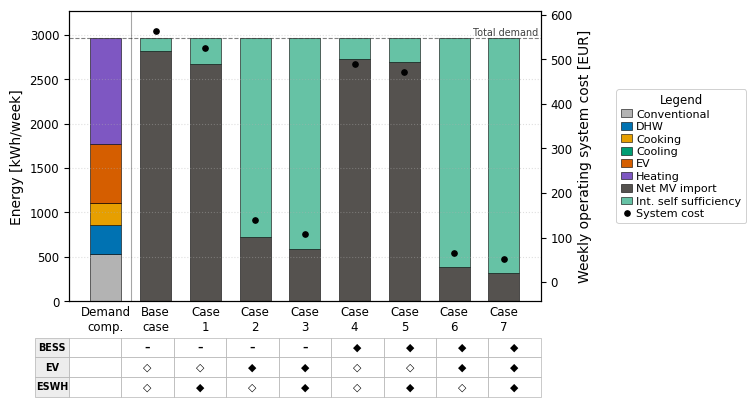

[OK] Salvato grafico demand coverage: output\04_HGD_cfr\rural\14_nuc_Cen_inverno_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_inverno_mixed_configs.png
[OK] Salvato grafico multi-run costi medi per household: output\04_HGD_cfr\rural\14_nuc_Cen_inverno_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_inverno_mixed_configs.png
[OK] Salvato grafico cost percentiles: output\04_HGD_cfr\rural\14_nuc_Cen_inverno_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_inverno_mixed_configs.png

----------------------------------------------------------------------------------------------------
[INFO][MULTIRUN][PASS 2] Plot stagione: primavera
  Fonte dati: rebuilt_from_pickle
----------------------------------------------------------------------------------------------------
[OK] Salvato grafico demand coverage/components: output\04_HGD_cfr\rural\14_nuc_Cen_primavera_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_primaver

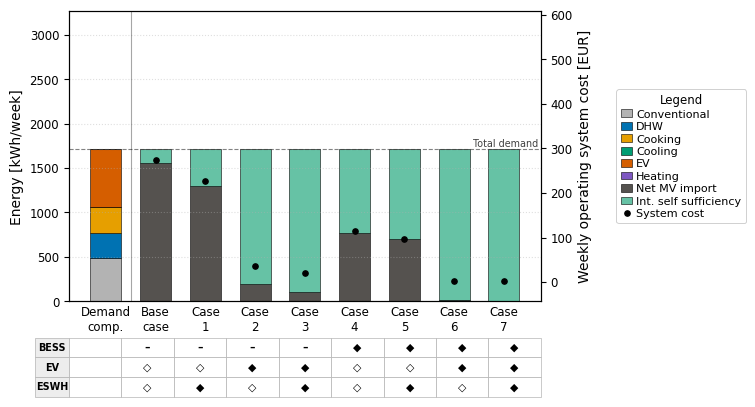

[OK] Salvato grafico demand coverage: output\04_HGD_cfr\rural\14_nuc_Cen_primavera_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_primavera_mixed_configs.png
[OK] Salvato grafico multi-run costi medi per household: output\04_HGD_cfr\rural\14_nuc_Cen_primavera_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_primavera_mixed_configs.png
[OK] Salvato grafico cost percentiles: output\04_HGD_cfr\rural\14_nuc_Cen_primavera_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_primavera_mixed_configs.png

----------------------------------------------------------------------------------------------------
[INFO][MULTIRUN][PASS 2] Plot stagione: estate
  Fonte dati: rebuilt_from_pickle
----------------------------------------------------------------------------------------------------
[OK] Salvato grafico demand coverage/components: output\04_HGD_cfr\rural\14_nuc_Cen_estate_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_es

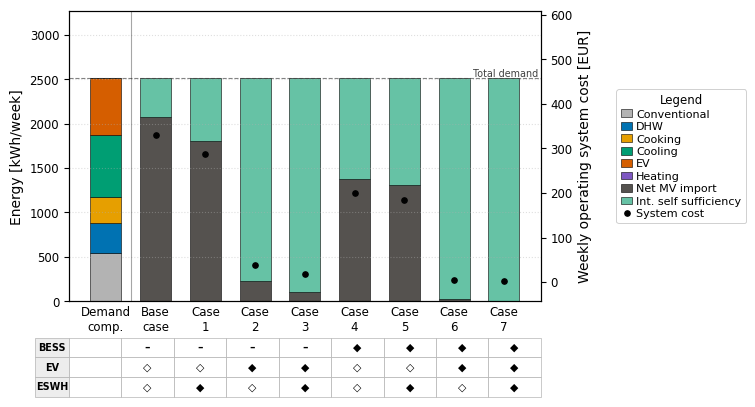

[OK] Salvato grafico demand coverage: output\04_HGD_cfr\rural\14_nuc_Cen_estate_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_estate_mixed_configs.png
[OK] Salvato grafico multi-run costi medi per household: output\04_HGD_cfr\rural\14_nuc_Cen_estate_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_estate_mixed_configs.png
[OK] Salvato grafico cost percentiles: output\04_HGD_cfr\rural\14_nuc_Cen_estate_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_estate_mixed_configs.png

----------------------------------------------------------------------------------------------------
[INFO][MULTIRUN][PASS 2] Plot stagione: autunno
  Fonte dati: rebuilt_from_pickle
----------------------------------------------------------------------------------------------------
[OK] Salvato grafico demand coverage/components: output\04_HGD_cfr\rural\14_nuc_Cen_autunno_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_autunno_mixed_conf

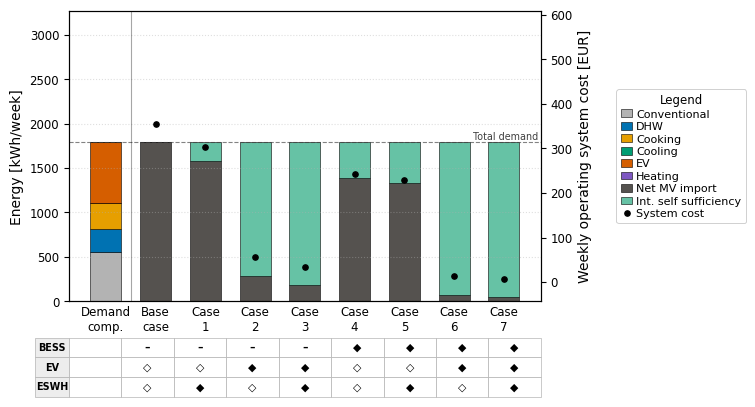

[OK] Salvato grafico demand coverage: output\04_HGD_cfr\rural\14_nuc_Cen_autunno_mixed_configs\self_sufficiency_total_cost_14_nuc_Cen_autunno_mixed_configs.png
[OK] Salvato grafico multi-run costi medi per household: output\04_HGD_cfr\rural\14_nuc_Cen_autunno_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_autunno_mixed_configs.png
[OK] Salvato grafico cost percentiles: output\04_HGD_cfr\rural\14_nuc_Cen_autunno_mixed_configs\cost_percentiles_vs_avg_household_weekly_system_cost_eur_14_nuc_Cen_autunno_mixed_configs.png


In [170]:
# ------------------------------------------------------------
# Sec 4.14 -- Confronto multi-run Case 0-7
# ------------------------------------------------------------
# Flusso ordinato:
#   PASS 1     carica/ricostruisce df_plot per ogni stagione
#              + opzionalmente salva audit/tabelle diagnostiche
#   PASS 1.bis calcola limiti Y comuni fra stagioni
#   PASS 2     stampa i grafici richiesti
#
# Le analisi di sicurezza ex-blocco commentato sono mantenute come opzionali:
#   - MULTIRUN_EXPORT_MARKET_TS
#   - MULTIRUN_SAVE_ADDITIONAL_COST_AUDIT
#   - MULTIRUN_SAVE_SELF_SUFFICIENCY_TABLE
#   - MULTIRUN_RUN_SELF_SUFFICIENCY_AUDIT
#   - MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES

if RUN_COMPARE_MULTIRUN:

    if len(MULTIRUN_GRAPHS_TO_PLOT) == 0:
        print("[INFO][4.14] RUN_COMPARE_MULTIRUN=True ma nessun grafico richiesto.")
    else:
        print("\n" + "=" * 100)
        print("[INFO][4.14] Avvio confronto multi-run")
        print(f"  Grafici richiesti: {MULTIRUN_GRAPHS_TO_PLOT}")
        print(f"  Usa cache se completa: {MULTIRUN_USE_CACHE_IF_COMPLETE}")
        print(f"  Ricostruisci da pickle se serve: {MULTIRUN_REBUILD_FROM_PICKLE_IF_NEEDED}")
        print("  Output opzionali:")
        print(f"    market TS/KPI:          {MULTIRUN_EXPORT_MARKET_TS}")
        print(f"    audit costi addiz.:     {MULTIRUN_SAVE_ADDITIONAL_COST_AUDIT}")
        print(f"    tabella self-suff.:     {MULTIRUN_SAVE_SELF_SUFFICIENCY_TABLE}")
        print(f"    audit self-suff.:       {MULTIRUN_RUN_SELF_SUFFICIENCY_AUDIT}")
        print(f"    duration curves costi:  {MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES}")
        print("=" * 100 + "\n")

    MULTIRUN_SEASON_CACHE = {}

    # ============================================================
    # PASS 1: carico o ricostruisco dati per tutte le stagioni
    # ============================================================
    for stagione_selezionata in stagioni:

        print("\n" + "-" * 100)
        print(f"[INFO][MULTIRUN][PASS 1] Stagione: {stagione_selezionata}")
        print("-" * 100)

        compare_tag = (
            f"{n_nuclei_familiari}_nuc_"
            f"{regione_selezionata}_"
            f"{stagione_selezionata}_"
            "mixed_configs"
        )

        cartella_output_confronti = os.path.join(
            cartella_hagrid_multirun_root,
            compare_tag,
        )

        os.makedirs(cartella_output_confronti, exist_ok=True)

        out_cost_xlsx = os.path.join(
            cartella_output_confronti,
            f"cost_percentiles_vs_avg_household_weekly_system_cost_eur_{compare_tag}.xlsx",
        )

        MULTIRUN_COST_SCENARIOS = build_multirun_cost_scenarios_for_season(
            stagione_selezionata
        )

        try:
            df_multirun_cost_plot, df_multirun_cost_skipped, data_source_used = (
                _get_or_build_multirun_plot_data(
                    cache_xlsx=out_cost_xlsx,
                    scenarios=MULTIRUN_COST_SCENARIOS,
                    graphs_to_plot=MULTIRUN_GRAPHS_TO_PLOT,
                    cartella_output=cartella_output,
                    n_nuclei_familiari=n_nuclei_familiari,
                    regione_selezionata=regione_selezionata,
                    share_FV=share_FV_TBCompared,
                    pot_FV=pot_FV,
                    preferred_total_cost_col=TOTAL_COST_COL_FOR_MULTIRUN_PLOT,
                    use_cache_if_complete=MULTIRUN_USE_CACHE_IF_COMPLETE,
                    rebuild_from_pickle_if_needed=MULTIRUN_REBUILD_FROM_PICKLE_IF_NEEDED,
                    save_updated_cache=MULTIRUN_SAVE_UPDATED_CACHE,
                )
            )

        except Exception as e:
            print(f"[ERRORE][MULTIRUN] Impossibile costruire dati per {stagione_selezionata}.")
            print(e)
            continue

        if df_multirun_cost_plot is None or df_multirun_cost_plot.empty:
            print(f"[WARN][MULTIRUN] Nessun dato valido per {stagione_selezionata}. Skip.")
            continue

        # ------------------------------------------------------------
        # PASS 1.1: market cost timeseries e KPI gross MV import/export
        # ------------------------------------------------------------
        df_market_ts_wide = pd.DataFrame()
        df_market_summary = pd.DataFrame()
        df_market_skipped = pd.DataFrame()

        need_market_ts = (
            MULTIRUN_EXPORT_MARKET_TS
            or (
                MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES
                and MULTIRUN_BUILD_MARKET_TS_FOR_DURATION_CURVES
            )
        )

        if need_market_ts:
            try:
                df_market_ts_wide, df_market_summary, df_market_skipped = (
                    build_multirun_market_cost_timeseries_dataset(
                        scenarios=MULTIRUN_COST_SCENARIOS,
                        cartella_output=cartella_output,
                        n_nuclei_familiari=n_nuclei_familiari,
                        regione_selezionata=regione_selezionata,
                        share_FV=share_FV_TBCompared,
                        pot_FV=pot_FV,
                        columns_to_export=MULTIRUN_MARKET_TS_COLUMNS,
                    )
                )

                # Porto alcuni KPI sintetici anche dentro df_multirun_cost_plot.
                # Questo è utile perché la tabella principale resta auto-contenuta.
                if df_market_summary is not None and not df_market_summary.empty:
                    cols_market_merge = [
                        "x_order",
                        "gross_mv_import_share_of_demand",
                        "gross_mv_export_share_of_demand",
                        "gross_mv_exchange_share_of_demand",
                        "market_mt_purchase_cost_eur",
                        "market_mt_sale_revenues_eur",
                        "market_mt_net_cost_eur",
                        "average_market_mt_net_cost_eur_per_timestep",
                        "average_market_mt_net_cost_eur_per_kwh_demand",
                        "average_total_system_cost_eur_per_timestep",
                    ]

                    cols_market_merge = [
                        c for c in cols_market_merge
                        if c in df_market_summary.columns
                    ]

                    if len(cols_market_merge) > 1:
                        # Evito duplicazioni se df_plot arriva da cache già arricchita.
                        cols_to_drop = [
                            c for c in cols_market_merge
                            if c != "x_order" and c in df_multirun_cost_plot.columns
                        ]

                        if cols_to_drop:
                            df_multirun_cost_plot = df_multirun_cost_plot.drop(
                                columns=cols_to_drop
                            )

                        df_multirun_cost_plot = df_multirun_cost_plot.merge(
                            df_market_summary[cols_market_merge],
                            on="x_order",
                            how="left",
                        )

                if MULTIRUN_EXPORT_MARKET_TS:
                    out_market_xlsx = os.path.join(
                        cartella_output_confronti,
                        f"market_cost_timeseries_{compare_tag}.xlsx",
                    )

                    with pd.ExcelWriter(out_market_xlsx, engine="openpyxl") as writer:
                        if df_market_ts_wide is not None and not df_market_ts_wide.empty:
                            df_market_ts_wide.to_excel(
                                writer,
                                sheet_name="market_ts_wide",
                                index=True,
                            )

                        if df_market_summary is not None and not df_market_summary.empty:
                            df_market_summary.to_excel(
                                writer,
                                sheet_name="market_summary",
                                index=False,
                            )

                        if df_market_skipped is not None and not df_market_skipped.empty:
                            df_market_skipped.to_excel(
                                writer,
                                sheet_name="skipped",
                                index=False,
                            )

                    print(f"[OK] Salvate timeseries/KPI market cost: {out_market_xlsx}")

            except Exception as e:
                print(
                    f"[WARN][MULTIRUN][MARKET TS] Errore export/ricostruzione "
                    f"market TS per {stagione_selezionata}: {type(e).__name__}: {e}"
                )

        # ------------------------------------------------------------
        # PASS 1.2: audit peso costi addizionali
        # ------------------------------------------------------------
        df_additional_cost_detail = pd.DataFrame()
        df_additional_cost_summary = pd.DataFrame()
        df_additional_cost_skipped = pd.DataFrame()

        if MULTIRUN_SAVE_ADDITIONAL_COST_AUDIT:
            try:
                (
                    df_additional_cost_detail,
                    df_additional_cost_summary,
                    df_additional_cost_skipped,
                ) = build_multirun_additional_cost_weight_audit(
                    scenarios=MULTIRUN_COST_SCENARIOS,
                    cartella_output=cartella_output,
                    n_nuclei_familiari=n_nuclei_familiari,
                    regione_selezionata=regione_selezionata,
                    share_FV=share_FV_TBCompared,
                    pot_FV=pot_FV,
                )

                out_additional_cost_xlsx = os.path.join(
                    cartella_output_confronti,
                    f"additional_cost_weight_audit_{compare_tag}.xlsx",
                )

                with pd.ExcelWriter(out_additional_cost_xlsx, engine="openpyxl") as writer:
                    if (
                        df_additional_cost_summary is not None
                        and not df_additional_cost_summary.empty
                    ):
                        df_additional_cost_summary.to_excel(
                            writer,
                            sheet_name="summary",
                            index=False,
                        )

                    if (
                        df_additional_cost_detail is not None
                        and not df_additional_cost_detail.empty
                    ):
                        df_additional_cost_detail.to_excel(
                            writer,
                            sheet_name="detail",
                            index=False,
                        )

                    if (
                        df_additional_cost_skipped is not None
                        and not df_additional_cost_skipped.empty
                    ):
                        df_additional_cost_skipped.to_excel(
                            writer,
                            sheet_name="skipped",
                            index=False,
                        )

                print(f"[OK] Salvato audit costi addizionali: {out_additional_cost_xlsx}")

            except Exception as e:
                print(
                    f"[WARN][MULTIRUN][ADDITIONAL COST AUDIT] Errore audit "
                    f"per {stagione_selezionata}: {type(e).__name__}: {e}"
                )

        # ------------------------------------------------------------
        # PASS 1.3: salvataggio tabella self-sufficiency / demand coverage
        # ------------------------------------------------------------
        out_self_suff_xlsx = os.path.join(
            cartella_output_confronti,
            f"self_sufficiency_{compare_tag}.xlsx",
        )

        if MULTIRUN_SAVE_SELF_SUFFICIENCY_TABLE:
            try:
                with pd.ExcelWriter(out_self_suff_xlsx, engine="openpyxl") as writer:
                    df_multirun_cost_plot.to_excel(
                        writer,
                        sheet_name="plot_data",
                        index=False,
                    )

                    if (
                        df_multirun_cost_skipped is not None
                        and not df_multirun_cost_skipped.empty
                    ):
                        df_multirun_cost_skipped.to_excel(
                            writer,
                            sheet_name="skipped",
                            index=False,
                        )

                    if df_market_summary is not None and not df_market_summary.empty:
                        df_market_summary.to_excel(
                            writer,
                            sheet_name="market_summary",
                            index=False,
                        )

                    metadata_df = pd.DataFrame([{
                        "compare_tag": compare_tag,
                        "stagione": stagione_selezionata,
                        "data_source_used": data_source_used,
                        "market_ts_built": bool(
                            df_market_ts_wide is not None
                            and not df_market_ts_wide.empty
                        ),
                        "additional_cost_audit": bool(MULTIRUN_SAVE_ADDITIONAL_COST_AUDIT),
                        "self_sufficiency_audit": bool(MULTIRUN_RUN_SELF_SUFFICIENCY_AUDIT),
                    }])

                    metadata_df.to_excel(writer, sheet_name="metadata", index=False)

                print(f"[OK] Salvata tabella multi-run self-sufficiency: {out_self_suff_xlsx}")

            except Exception as e:
                print(
                    f"[WARN][MULTIRUN][SELF SUFF TABLE] Errore salvataggio "
                    f"per {stagione_selezionata}: {type(e).__name__}: {e}"
                )

        # ------------------------------------------------------------
        # PASS 1.4: audit self-sufficiency corretto per Delta SoC
        # ------------------------------------------------------------
        df_self_suff_audit = pd.DataFrame()

        if MULTIRUN_RUN_SELF_SUFFICIENCY_AUDIT:
            try:
                out_self_suff_audit_xlsx = os.path.join(
                    cartella_output_confronti,
                    f"self_sufficiency_soc_corrected_audit_{compare_tag}.xlsx",
                )

                df_self_suff_audit = print_multirun_self_sufficiency_audit(
                    df_plot=df_multirun_cost_plot,
                    out_xlsx=out_self_suff_audit_xlsx,
                    gap_warn_pct_demand=MULTIRUN_SELF_SUFF_GAP_WARN_PCT_DEMAND,
                    gap_warn_abs_kwh=MULTIRUN_SELF_SUFF_GAP_WARN_ABS_KWH,
                )

            except Exception as e:
                print(
                    f"[WARN][MULTIRUN][SELF SUFF AUDIT] Errore audit "
                    f"per {stagione_selezionata}: {type(e).__name__}: {e}"
                )

        # ------------------------------------------------------------
        # PASS 1.5: risalvo la cache principale se è stata arricchita
        # ------------------------------------------------------------
        # _get_or_build_multirun_plot_data salva già la cache quando ricostruisce.
        # Però qui df_plot può essere stato arricchito con market_summary.
        # Quindi salvo di nuovo, ma solo se richiesto.
        if MULTIRUN_SAVE_UPDATED_CACHE:
            try:
                with pd.ExcelWriter(out_cost_xlsx, engine="openpyxl") as writer:
                    df_multirun_cost_plot.to_excel(
                        writer,
                        sheet_name="plot_data",
                        index=False,
                    )

                    if (
                        df_multirun_cost_skipped is not None
                        and not df_multirun_cost_skipped.empty
                    ):
                        df_multirun_cost_skipped.to_excel(
                            writer,
                            sheet_name="skipped",
                            index=False,
                        )

                    if df_market_summary is not None and not df_market_summary.empty:
                        df_market_summary.to_excel(
                            writer,
                            sheet_name="market_summary",
                            index=False,
                        )

                    if (
                        df_additional_cost_summary is not None
                        and not df_additional_cost_summary.empty
                    ):
                        df_additional_cost_summary.to_excel(
                            writer,
                            sheet_name="additional_cost_summary",
                            index=False,
                        )

                    metadata_df = pd.DataFrame([{
                        "cache_created_from": data_source_used,
                        "cache_policy": "use_cache_if_complete_else_rebuild_pickle",
                        "graphs_to_plot": ", ".join(MULTIRUN_GRAPHS_TO_PLOT),
                        "preferred_total_cost_col": TOTAL_COST_COL_FOR_MULTIRUN_PLOT,
                        "compare_tag": compare_tag,
                        "stagione": stagione_selezionata,
                        "market_ts_exported": bool(MULTIRUN_EXPORT_MARKET_TS),
                        "market_ts_built_for_duration": bool(
                            MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES
                            and MULTIRUN_BUILD_MARKET_TS_FOR_DURATION_CURVES
                        ),
                        "additional_cost_audit": bool(MULTIRUN_SAVE_ADDITIONAL_COST_AUDIT),
                        "self_sufficiency_table": bool(MULTIRUN_SAVE_SELF_SUFFICIENCY_TABLE),
                        "self_sufficiency_audit": bool(MULTIRUN_RUN_SELF_SUFFICIENCY_AUDIT),
                    }])

                    metadata_df.to_excel(writer, sheet_name="metadata", index=False)

                print(f"[OK][MULTIRUN] Salvata cache/tabella principale: {out_cost_xlsx}")

            except Exception as e:
                print(
                    f"[WARN][MULTIRUN][CACHE SAVE] Errore salvataggio cache "
                    f"per {stagione_selezionata}: {type(e).__name__}: {e}"
                )

        # ------------------------------------------------------------
        # PASS 1.6: salvo tutto nella cache in memoria per PASS 2
        # ------------------------------------------------------------
        MULTIRUN_SEASON_CACHE[stagione_selezionata] = {
            "compare_tag": compare_tag,
            "cartella_output_confronti": cartella_output_confronti,
            "df_plot": df_multirun_cost_plot,
            "df_skipped": df_multirun_cost_skipped,
            "df_market_ts_wide": df_market_ts_wide,
            "df_market_summary": df_market_summary,
            "df_market_skipped": df_market_skipped,
            "df_additional_cost_summary": df_additional_cost_summary,
            "df_self_suff_audit": df_self_suff_audit,
            "data_source_used": data_source_used,
        }

    # ============================================================
    # PASS 1.bis: calcolo limiti comuni, solo se richiesti
    # ============================================================
    if MULTIRUN_USE_COMMON_YLIMS and len(MULTIRUN_SEASON_CACHE) > 0:
        df_plot_by_season = {
            stagione: item["df_plot"]
            for stagione, item in MULTIRUN_SEASON_CACHE.items()
            if item.get("df_plot") is not None and not item["df_plot"].empty
        }

        common_y_limits = _compute_multirun_common_y_limits(df_plot_by_season)

        print("\n[INFO][MULTIRUN] Limiti comuni assi Y calcolati:")
        for k, v in common_y_limits.items():
            print(f"  {k}: {v}")

    else:
        common_y_limits = {
            "cost_y1_ylim": None,
            "cost_y2_ylim": None,
            "demand_y1_ylim": None,
            "demand_y2_ylim": None,
        }

    # ============================================================
    # PASS 2: stampa solo i grafici richiesti
    # ============================================================
    for stagione_selezionata, item in MULTIRUN_SEASON_CACHE.items():

        print("\n" + "-" * 100)
        print(f"[INFO][MULTIRUN][PASS 2] Plot stagione: {stagione_selezionata}")
        print(f"  Fonte dati: {item.get('data_source_used')}")
        print("-" * 100)

        compare_tag = item["compare_tag"]
        cartella_output_confronti = item["cartella_output_confronti"]
        df_multirun_cost_plot = item["df_plot"]

        if df_multirun_cost_plot is None or df_multirun_cost_plot.empty:
            print(f"[WARN][MULTIRUN] df_plot vuoto per {stagione_selezionata}. Skip.")
            continue

        # ------------------------------------------------------------
        # PASS 2.1: grafico demand coverage
        # ------------------------------------------------------------
        if RUN_PLOT_MULTIRUN_DEMAND_COVERAGE:

            out_self_suff_demand_png = os.path.join(
                cartella_output_confronti,
                f"self_sufficiency_total_cost_{compare_tag}.png",
            )

            plot_multirun_self_sufficiency_and_demand_components(
                df_plot=df_multirun_cost_plot,
                title=(
                    "Demand coverage and demand components by scenario\n"
                    f"Season: {stagioni_ingl_dict[stagione_selezionata]}"
                ),
                out_png=out_self_suff_demand_png,
                rotate_xticks=0,
                y1_label="Energy [kWh/week]",
                y2_label="Weekly operating system cost [EUR]",
                demand_tolerance_abs_kwh=10.0,
                demand_tolerance_rel=5e-4,
                demand_mismatch_action=MULTIRUN_DEMAND_MISMATCH_ACTION,
                print_checks=MULTIRUN_PRINT_DEMAND_COVERAGE_CHECKS,
                demand_reference_if_within_tolerance="max",
                y1_ylim=common_y_limits.get("demand_y1_ylim"),
                y2_ylim=common_y_limits.get("demand_y2_ylim"),
                legend_mode=globals().get(
                    "MULTIRUN_DEMAND_LEGEND_MODE",
                    "right_outside",
                ),
                show_title=SHOW_MULTIRUN_FIGURE_TITLE,
                save_pdf=SAVE_JOURNAL_PDF,
            )

            print(f"[OK] Salvato grafico demand coverage: {out_self_suff_demand_png}")

        # ------------------------------------------------------------
        # PASS 2.2: grafico cost percentiles + household average system cost
        # ------------------------------------------------------------
        if RUN_PLOT_MULTIRUN_COST_PERCENTILES:

            out_multirun_png = os.path.join(
                cartella_output_confronti,
                f"cost_percentiles_vs_avg_household_weekly_system_cost_eur_{compare_tag}.png",
            )

            plot_multirun_cost_percentiles_vs_household_avg_cost(
                df_plot=df_multirun_cost_plot,
                title=(
                    "Household cost percentiles by scenario + "
                    "mean weekly system cost per household\n"
                    f"Season: {stagioni_ingl_dict[stagione_selezionata]}"
                ),
                out_png=out_multirun_png,
                y1_label="Household weekly cost\npercentiles [EUR]",
                y2_label="Mean weekly system cost\nper household [EUR]",
                y1_ylim=common_y_limits.get("cost_y1_ylim"),
                y2_ylim=common_y_limits.get("cost_y2_ylim"),
                legend_mode=globals().get(
                    "MULTIRUN_COST_LEGEND_MODE",
                    "upper_right_inside",
                ),
                show_title=SHOW_MULTIRUN_FIGURE_TITLE,
                save_pdf=SAVE_JOURNAL_PDF,
            )

            print(f"[OK] Salvato grafico cost percentiles: {out_multirun_png}")

        # ------------------------------------------------------------
        # PASS 2.3: curve di durata del costo per timestep
        # ------------------------------------------------------------
        if MULTIRUN_PLOT_SYSTEM_COST_DURATION_CURVES:

            df_market_ts_wide = item.get("df_market_ts_wide", pd.DataFrame())

            if df_market_ts_wide is None or df_market_ts_wide.empty:
                print(
                    "[WARN][DURATION CURVE] df_market_ts_wide vuoto. "
                    "Attiva MULTIRUN_EXPORT_MARKET_TS=True oppure "
                    "MULTIRUN_BUILD_MARKET_TS_FOR_DURATION_CURVES=True."
                )

            else:
                duration_metric = globals().get(
                    "MULTIRUN_DURATION_CURVE_COST_COLUMN",
                    "total_system_cost_per_timestep_eur",
                )

                out_duration_png = os.path.join(
                    cartella_output_confronti,
                    f"duration_curve_{duration_metric}_{compare_tag}.png",
                )

                out_duration_xlsx = os.path.join(
                    cartella_output_confronti,
                    f"duration_curve_{duration_metric}_{compare_tag}.xlsx",
                )

                df_duration_curve = plot_multirun_system_cost_duration_curves(
                    df_market_ts_wide=df_market_ts_wide,
                    title=(
                        "Duration curves of system cost per timestep by scenario\n"
                        f"Season: {stagioni_ingl_dict[stagione_selezionata]}"
                    ),
                    metric_col=duration_metric,
                    out_png=out_duration_png,
                    out_xlsx=out_duration_xlsx,
                    legend_mode=globals().get(
                        "MULTIRUN_COST_LEGEND_MODE",
                        "upper_right_inside",
                    ),
                )

                print(f"[OK] Salvata duration curve costo sistema: {out_duration_png}")

else:
    print("[INFO][4.14] RUN_COMPARE_MULTIRUN=False. Salto confronto multi-run.")

## 4.15 Stampa grafici confronto fra 2 configurazioni

In [171]:
if RUN_COMPARE_DHW_SOC_TWO_CONFIGS:

    cartella_output_confronti_soc = _soc_compare_output_dir()

    soc_compare_seasons = globals().get("SOC_COMPARE_SEASONS", None)

    if soc_compare_seasons is None:
        soc_compare_seasons = stagioni
    else:
        soc_compare_seasons = [
            s for s in soc_compare_seasons
            if s in stagioni
        ]

    for stagione_scelta in soc_compare_seasons:

        print("\n" + "=" * 100)
        print(
            f"[SOC COMPARE] DHW - "
            f"{SOC_COMPARE_MODE_A} v. {SOC_COMPARE_MODE_B} - "
            f"stagione: {stagione_scelta}"
        )
        print("=" * 100)

        # 1) SOC DHW due configurazioni + profilo FV
        plot_compare_dhw_soc_two_configs_with_secondary(
            stagione=stagione_scelta,
            mode_a=SOC_COMPARE_MODE_A,
            mode_b=SOC_COMPARE_MODE_B,
            secondary_kind="pv",
            out_dir=cartella_output_confronti_soc,
            pv_source=SOC_COMPARE_PV_SOURCE,
            single_house=SOC_COMPARE_SINGLE_PV_HOUSE,
            save_xlsx=False,
            show_title=SHOW_SOC_COMPARE_TITLE,
            save_pdf=SAVE_JOURNAL_PDF,
        )

        # 2) SOC DHW due configurazioni + prezzo acquisto
        plot_compare_dhw_soc_two_configs_with_secondary(
            stagione=stagione_scelta,
            mode_a=SOC_COMPARE_MODE_A,
            mode_b=SOC_COMPARE_MODE_B,
            secondary_kind="price",
            out_dir=cartella_output_confronti_soc,
            save_xlsx=False,
            show_title=SHOW_SOC_COMPARE_TITLE,
            save_pdf=SAVE_JOURNAL_PDF,
        )


[SOC COMPARE] DHW - MIX_BNO_VRB_HRB v. MIX_BNO_VRB_HOPT - stagione: inverno
[OK] Salvato grafico confronto SOC DHW: output\04_HGD_cfr\rural\14_nuc_Cen_soc_compare\compare_soc_dhw_pv_generation_base_case_vs_case_1_inverno.png
[OK] Salvato grafico confronto SOC DHW PDF: output\04_HGD_cfr\rural\14_nuc_Cen_soc_compare\compare_soc_dhw_pv_generation_base_case_vs_case_1_inverno.pdf
[OK] Salvato grafico confronto SOC DHW: output\04_HGD_cfr\rural\14_nuc_Cen_soc_compare\compare_soc_dhw_price_base_case_vs_case_1_inverno.png
[OK] Salvato grafico confronto SOC DHW PDF: output\04_HGD_cfr\rural\14_nuc_Cen_soc_compare\compare_soc_dhw_price_base_case_vs_case_1_inverno.pdf

[SOC COMPARE] DHW - MIX_BNO_VRB_HRB v. MIX_BNO_VRB_HOPT - stagione: primavera
[OK] Salvato grafico confronto SOC DHW: output\04_HGD_cfr\rural\14_nuc_Cen_soc_compare\compare_soc_dhw_pv_generation_base_case_vs_case_1_primavera.png
[OK] Salvato grafico confronto SOC DHW PDF: output\04_HGD_cfr\rural\14_nuc_Cen_soc_compare\compare_soc_dh

 ## 4.16 Debug infeasibility

In [172]:
# -----------------------------------------------------------------------------
#       Sec 4.15 -- 1) -- ANALISI RUN INFEASIBLE (LP / IIS) — attiva con RUN_DEBUG_INFEASIBLE
# -----------------------------------------------------------------------------

if RUN_DEBUG_INFEASIBLE:
    season, lp_path, iis_json_path = auto_pick_paths()

    print("\n================ Ex-Post INFEASIBLE ================\n")
    print("Stagione selezionata:", season)
    print("LP:", lp_path)
    print("IIS JSON:", iis_json_path)

    if lp_path is None or (not Path(lp_path).exists()):
        print("[ERROR] LP non trovato. Imposta DEBUG_LP_PATH o controlla cartella_output_ottimiz.")
    else:
        if PRINT_LP_PREVIEW:
            preview_text_file(lp_path, head=LP_PREVIEW_HEAD, tail=LP_PREVIEW_TAIL)

        names = lp_constraint_names(lp_path, contains=None, max_names=MAX_LIST_NAMES)
        print(f"\nVincoli letti dal LP (n={len(names)})")
        summarize_names(names, top=30)

        # esempi “pronti” (modifica pattern a piacere)
        print("\nEsempi utili (modifica pattern):")
        print("  lp_grep(lp_path, r\"Balance\", max_hits=20, context=2)")
        print("  lp_grep(lp_path, r\"from_the_grid_BT_to_c_1\", max_hits=20, context=2)")
        print("  lp_grep(lp_path, r\"bt_h001\", max_hits=20, context=2)")

    # Se esiste IIS json, stampa subito la short-list
    if iis_json_path is not None and Path(iis_json_path).exists():
        iis = load_iis_json(iis_json_path)
        c_list = iis.get("constraints", [])
        print("\n================ IIS SHORT-LIST ================\n")
        print("n_constraints:", len(c_list))
        summarize_names(c_list, top=30)

        print("\n[IIS] primi 50 vincoli:")
        for name in c_list[:50]:
            print("  -", name)

        print("\nPer vedere la formula di un vincolo IIS nel LP:")
        print("  lp_grep(lp_path, r\"^<NOMEVINCOLO>:\\s\", max_hits=1, context=6)")
    else:
        print("\n[IIS] Nessun iis_*.json trovato (o SAVE_IIS_JSON=False / IIS non calcolato).")


# -----------------------------------------------------------------------------
#       Sec 4.15 -- 2) -- DEBUGGING CONFRONTO CASO OPT - RB (parte commentata)
# -----------------------------------------------------------------------------

# ######### DEBUGGING (serie in input uguali fra rule-based v. opt)
# # es. stagione come compare nei dizionari dmd_*_el_fix_dicts e nei file *.pkl.gz

# print("Confronto dei valori inseriti in ingresso in rule-based v. ottimizzazione")
# stagione_test = "inverno"    # o "inverno", "Winter_week1", ecc. -> adatta al tuo naming
# # nucleo_test   = "c_1"

# for c in ["c_1", "c_2", "c_7"]:
#     debug_totale_rule_vs_opt(
#             stagione  = stagione_test,
#             nucleo    = c,
#             timestep_minutes = timestep_minutes,
#             df_dmd_all       = df_dmd_all,
#             dmd_base_el_fix_dicts = dmd_base_el_fix_dicts,
#             dmd_base_pnom_dicts   = dmd_base_pnom_dicts,
#             dmd_ACS_el_fix_dicts  = dmd_ACS_el_fix_dicts,
#             dmd_ACS_pnom_dicts    = dmd_ACS_pnom_dicts,
#             dmd_Cool_el_fix_dicts = dmd_Cool_el_fix_dicts,
#             dmd_Cool_pnom_dicts   = dmd_Cool_pnom_dicts,
#             dmd_Heat_el_fix_dicts = dmd_Heat_el_fix_dicts,
#             dmd_Heat_pnom_dicts   = dmd_Heat_pnom_dicts,
#             dmd_Cook_el_fix_dicts = dmd_Cook_el_fix_dicts,
#             dmd_Cook_pnom_dicts   = dmd_Cook_pnom_dicts,
#             dmd_BEV_el_fix_dicts  = dmd_BEV_el_fix_dicts,
#             dmd_BEV_pnom_dicts    = dmd_BEV_pnom_dicts,
#             has_el_boiler = has_el_boiler,
#             has_cooler    = has_cooler,
#             has_HP        = has_HP,
#             has_induction = has_induction,
#             has_BEV       = has_BEV,
#         )
# #-----------------------------------------------------------------------------






# -----------------------------------------------------------------------------
#       Sec 4.15 -- 3) -- DEBUGGING GUROBIPY / IIS dentro risoluzione om di oemof.solph (Sec 4.10c)
#                           (da inserire manualmente in sottosezione 4.10c - 1.6.b) Debugging se "run infeasible")
# -----------------------------------------------------------------------------

                # if tc != TerminationCondition.optimal:
                #     # salva LP per analisi
                #     lp_path = os.path.join(cartella_output_ottimiz, f"debug_infeasible_{stagione_corrente}.lp")
                #     om.write(lp_path, io_options={"symbolic_solver_labels": True})
                #     print("[DEBUG] scritto LP:", lp_path)
                    
                #     # ---- 2) Carico LP con gurobipy
                #     print("[DEBUG] carico LP in gurobipy...")
                #     m = gp.read(lp_path)
                #     m.optimize()

                #     # ---- 3) Calcolo IIS se infeasible
                #     if m.status == gp.GRB.INFEASIBLE:
                #         print("[IIS] modello infeasible → calcolo IIS...")
                #         m.computeIIS()

                #         iis_path = os.path.join(
                #             cartella_output_ottimiz,
                #             f"iis_{stagione_corrente}.ilp"
                #         )
                #         m.write(iis_path)
                #         print("[IIS] scritto file:", iis_path)

                #         # ---- 4) Stampo i primi vincoli dell’IIS
                #         print("\n[IIS] Vincoli coinvolti (primi 30):")
                #         cnt = 0
                #         for constr in m.getConstrs():
                #             if constr.IISConstr:
                #                 print("  -", constr.ConstrName)
                #                 cnt += 1
                #                 if cnt >= 30:
                #                     break
                #     else:
                #         print("[WARN] modello non ottimo ma non marcato infeasible da gurobipy (status =", m.status, ")")

                #     # ---- 5) Ferma l’esecuzione del notebook per ispezione
                #     raise RuntimeError(
                #         f"INFEASIBLE in stagione={stagione_corrente}. "
                #         f"LP e IIS salvati in cartella output."
                #     )
                # # ---------------------------------------------------------


                # # # # ----DEBUGGING ----------------------------------------------------
                # # # tc = res.solver.termination_condition
                # # # print(">>> Solver termination_condition:", tc)

                # # # if tc != TerminationCondition.optimal:
                # # #     print("ATTENZIONE: il problema NON è ottimo (", tc, ")")
                # # #     print("Salto estrazione risultati per questa stagione.")
                # # #     continue  # passa alla prossima stagione
                # # # # print("\n=== META RESULTS ===")
                # # # # meta = processing.meta_results(om, undefined=True)
                # # # # print("Problem:", meta["problem"])
                # # # # print("Solver:", meta["solver"])
                
                # # print("\n=== DEBUG: create_dataframe ===")
                # # df_raw = processing.create_dataframe(om)

                # # # Quanti timestep ha ogni gruppo (oemof_tuple)?
                # # ts_counts = df_raw.groupby("oemof_tuple")["timestep"].nunique().sort_values()

                # # # Mostra i 20 gruppi con meno timestep (qui dovremmo vedere quelli con 1 o 2)
                # # print(ts_counts.head(20))

                # # # Decodifica e stampa "from -> to" per quei gruppi
                # # print("\n=== Flussi con pochi timestep ===")
                # # for tpl in ts_counts.head(20).index:
                # #     try:
                # #         frm, to = tpl
                # #         print(f"{frm.label} -> {to.label}  |  n_timesteps = {ts_counts[tpl]}")
                # #     except Exception:
                # #         print(f"{tpl}  |  n_timesteps = {ts_counts[tpl]}")
                #----------------------------------------------------------------


================ Ex-Post INFEASIBLE ================

Stagione selezionata: None
LP: None
IIS JSON: None
[ERROR] LP non trovato. Imposta DEBUG_LP_PATH o controlla cartella_output_ottimiz.

[IIS] Nessun iis_*.json trovato (o SAVE_IIS_JSON=False / IIS non calcolato).


## 4.1X  Archivio legacy (vecchi confronti)

In [173]:
# -------------------------------------------------------
#   (vecchia legacy) Sec 4.12) GRAFICI PROFILI RB REFERENCE LEGACY
# -------------------------------------------------------
if RUN_ENABLE_LEGACY_SECTIONS:
    print("[INFO][LEGACY][4.12] Eseguo grafici RB reference legacy.")
    
    """
    # ==================================================================
    # Sec 4.12 -- BLOCCO STORICO – grafico COMPLESSIVO SCAMBI SU N CASE (lato rete BT) e SOC storage
    #
    #       1) Se dovesse servire da recuperare, cercare versioni file
    #       "04_HAGRID_creazione_modello_locale_v22_topology_grid_Kerber_graph_RB_2026.03.03h17.py" 
    #       o precedenti --> per grafico SCAMBI SU N CASE
    #
    #       2) oppure file "04_HAGRID_creazione_modello_locale_v38_graphs_cmp_2026.07.06_h17.py"
    #       o precedenti --> per grafico SOC BESS, ESWHs e EVs
    #
    # ================== FINE BLOCCO STORICO ==================
    """
# -----------------------------------------------------------



# -------------------------------------------------------
#   (vecchia legacy) Sec 4.13) GRAFICI CONFRONTO OPT v. RULE BASED LEGACY
# -------------------------------------------------------
#  Qui ricostruito riepilogo-confronto informazioni Opt v. RB e mostrati i grafici distribuzione percentile dei "costi in bolletta" delle famiglie nelle due configurazioni

all_results = {}
# --------------
# Sec 4.13 -- PRIMO PASSAGGIO:
# - creazione file economici ottimizzazione
# - lettura costi RB
# - calcolo percentili + delta
# - calcolo limiti globali per assi
# --------------

season_plot_data = {}     # stag -> dict con s_opt, s_sim, delta
global_y1_min = np.inf    # asse costi (opt/sim)
global_y1_max = -np.inf
global_y2_min = np.inf    # asse delta
global_y2_max = -np.inf
for stag in stagioni:

    # Se voglio calcolare i parametri economici di confronto fra RB e Opt
    # if RUN_LEGACY_CONFRONTO_OPT_RB:
    if RUN_ENABLE_LEGACY_SECTIONS:
        print("[INFO][LEGACY][4.12] Eseguo grafici RB reference legacy.")

        #------------------------------------------------
        #   Sec 4.13 -- 0) CREAZIONE FILE ECONOMICI (OTTIMIZZAZIONE)
        #------------------------------------------------
        flow_path = os.path.join(
            cartella_output_ottimiz, 
            f'ris_OPT_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stag}.xlsx')
        if not os.path.exists(flow_path):
            print(f"[WARN] manca {flow_path}, salto.")
            continue
        try:
            out_xlsx, flow_df, detailed_df, summary_df = calcola_costi_per_una_stagione_flat(
                flow_path=flow_path,
                all_prezzi_sheets=all_prezzi_sheets,
                cartella_output=cartella_output,
                n_case=n_nuclei_familiari,
                stag=stag,
                energy_values_are_in_KW=energy_values_are_in_kW,
                minutes_per_timestep=minutes_per_timestep,
                price_col_map=None,
                save_detailed=True,
                debug=True   # metti False quando hai verificato
            )
            # # sanity check visivo: prime righe per c_1
            # c0 = 'c_1'
            # imp_col, exp_col = find_import_export_cols_flat(flow_df, c0)
            all_results[stag] = {
                'out_file': out_xlsx, 
                'flow_df': flow_df, 
                'detailed': detailed_df, 
                'summary': summary_df}
        
        except Exception as e:
            print(f"[ERROR] {stag}: {e}")


        #------------------------------------------------
        #   Sec 4.13 -- 1) CREAZIONE FILE DI CONFRONTO Opt v. RB
        #------------------------------------------------
        
        # file di output di confronto (uno per stagione)
        comparison_outfile = os.path.join(
            cartella_output_ottimiz,
            f'comparison_sim_vs_opt_{n_nuclei_familiari}_nuc_{regione_selezionata}_ECON_percentiles_{stag}.xlsx'
        )
        
        # file ottimizzazione
        opt_file = os.path.join(cartella_output_ottimiz, f'ris_opt_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stag}_costs.xlsx')
        # file simulazione
        sim_file = os.path.join(cartella_output_rule_based, f'ris_rule_based_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stag}.xlsx')

        # ----- 1.1) LETTURA FILE ottimizz v. Rule based -----
        opt_tot = pd.read_excel(opt_file, sheet_name='total_costs_per_nucleo', index_col=0, parse_dates=False)
        sim_tot = pd.read_excel(sim_file, sheet_name='economics_sum_week', index_col=0, parse_dates=False)

        # normalizza sim structure se esiste
        if sim_tot is not None:
            if sim_tot.shape[0] == 1 and sim_tot.shape[1] > 1:
                sim_tot = sim_tot.T
            if sim_tot.shape[1] > 1:
                sim_tot = sim_tot.iloc[:, [0]]
            sim_tot.columns = ['total_costs_eur']
            sim_tot.index = sim_tot.index.astype(str)
            sim_tot.index.name = 'Nucleo'

            # rimuovi righe TOTAL/summary da sim (es. 'TOTAL_all_nuclei')
            mask_drop_sim = sim_tot.index.str.contains(r'total|all_nuc', case=False, na=False)
            if mask_drop_sim.any():
                sim_tot = sim_tot.loc[~mask_drop_sim]

        # NORMALIZZA I NOMI DEI NUCLEI SU ENTRAMBI a 'Nucleo_X'
        opt_tot.index = opt_tot.index.map(to_nucleo_name)
        sim_tot.index = sim_tot.index.map(to_nucleo_name)

        # ----- 1.2) ALLINEAMENTO E ORDINE COERENTE DEI NUCLEI -----
        if sim_tot is not None:
            common_idx = opt_tot.index.intersection(sim_tot.index)
            if len(common_idx) == 0:
                print(f"[WARN] Nessun nucleo in comune tra opt ({len(opt_tot)}) e sim ({len(sim_tot)}) per {stag}. Skip confronto")
                continue
            def nuc_key(name):
                m = re.search(r'(\d+)', name)
                return int(m.group(1)) if m else 10**9  # nuclei senza numero vanno alla fine
        
            # costruisci l'ordered index (se tutti hanno numeri, verrà ordinato numericamente)
            ordered_common = sorted(list(common_idx), key=nuc_key)
        
            # riallinea opt_comp e sim_comp nello stesso ordine
            opt_comp = opt_tot.reindex(ordered_common).copy()
            sim_comp = sim_tot.reindex(ordered_common).copy()
        else:
            # se sim_tot non esiste, confrontiamo solo opt (ma senza sim non c'è delta)
            opt_comp = opt_tot.sort_index().copy()
            sim_comp = None


        # ----- 1.3) CALCOLO PERCENTILI rank e decile (inline) ------
        bins = np.linspace(0, 100, 11)
        labels = [f"{int(bins[i])}-{int(bins[i+1])}%" for i in range(len(bins)-1)]

        # per opt
        s_opt = opt_comp['total_costs_eur'].astype(float).copy()
        opt_ranks = s_opt.rank(method='average', pct=True) * 100.0
        bins = np.linspace(0, 100, 11)
        opt_deciles = pd.cut(opt_ranks, bins=bins, labels=labels, include_lowest=True, right=True)
        opt_pct_df = pd.DataFrame({
            'opt_total_eur': s_opt,
            'opt_percentile_rank': opt_ranks,
            'opt_decile_class': opt_deciles.astype(str)
        }, index=opt_comp.index)

        # per sim
        if sim_comp is not None:
            s_sim = sim_comp['total_costs_eur'].astype(float).copy()
            sim_ranks = s_sim.rank(method='average', pct=True) * 100.0
            sim_deciles = pd.cut(sim_ranks, bins=bins, labels=labels, include_lowest=True, right=True)
            sim_pct_df = pd.DataFrame({
                'sim_total_eur': s_sim,
                'sim_percentile_rank': sim_ranks,
                'sim_decile_class': sim_deciles.astype(str)
            }, index=sim_comp.index)
        else:
            sim_pct_df = pd.DataFrame(index=opt_comp.index, columns=['sim_total_eur','sim_percentile_rank','sim_decile_class'])

        # ------ 1.4) CALCOLO DELTA (RB - opt) -------
        if sim_comp is not None:
            delta = (sim_comp['total_costs_eur'] - opt_comp['total_costs_eur']).rename('delta_eur')
            delta_df = delta.to_frame()
        else:
            delta_df = pd.DataFrame(index=opt_comp.index, columns=['delta_eur'])


        # ------ 1.5) PERCENTILI DEI DELTA p10..p90 -------
        if sim_comp is not None:
            delta = (sim_comp['total_costs_eur'] - opt_comp['total_costs_eur']).rename('delta_eur')
            delta_ranks = delta.rank(method='average', pct=True) * 100.0
            delta_deciles = pd.cut(delta_ranks, bins=bins, labels=labels, include_lowest=True, right=True)
            delta_pct_df = pd.DataFrame({
                'delta_eur': delta,
                'delta_percentile_rank': delta_ranks,
                'delta_decile_class': delta_deciles.astype(str)
            }, index=delta.index)
        else:
            delta = pd.Series(index=opt_comp.index, name='delta_eur')
            delta_pct_df = pd.DataFrame(index=opt_comp.index, columns=['delta_eur','delta_percentile_rank','delta_decile_class'])

        # ------ 1.6) SCRITTURA FILE COMPARISON con informazioni percentili e scrivi fogli -------       
        prefix = stag[:24]
        
        with pd.ExcelWriter(comparison_outfile, engine='openpyxl') as writer:

            # foglio Opt
            try:
                opt_pct_df.to_excel(writer, sheet_name=f'{prefix}_opt_totals')
            except Exception:
                opt_pct_df.to_excel(writer, sheet_name=f'{prefix}_opt')
            # foglio RB
            try:
                sim_pct_df.to_excel(writer, sheet_name=f'{prefix}_sim_totals')
            except Exception:
                sim_pct_df.to_excel(writer, sheet_name=f'{prefix}_sim')
            # foglio delta
            try:
                delta_pct_df.to_excel(writer, sheet_name=f'{prefix}_delta')
            except Exception:
                delta_pct_df.to_excel(writer, sheet_name=f'{prefix}_dlt')

        print(f"[OK] Confronto percentili scritto in: {comparison_outfile}")
        
            
        # ------ 1.7) AGGIORNA STATISTICHE GLOBALI PER GLI ASSI ------
        season_plot_data[stag] = {
            "s_opt": s_opt,
            "s_sim": s_sim,
            "delta": delta
        }

        # asse 1: costi (opt + sim)
        y1_vals = [s_opt.min(), s_opt.max()]
        if s_sim is not None:
            y1_vals += [s_sim.min(), s_sim.max()]

        y1_min_here = np.nanmin(y1_vals)
        y1_max_here = np.nanmax(y1_vals)

        global_y1_min = min(global_y1_min, y1_min_here)
        global_y1_max = max(global_y1_max, y1_max_here)

        # asse 2: delta
        if sim_comp is not None and delta.dropna().shape[0] > 0:
            y2_min_here = delta.min()
            y2_max_here = delta.max()
            global_y2_min = min(global_y2_min, y2_min_here)
            global_y2_max = max(global_y2_max, y2_max_here)

        #-------------------------------------------------------------------------------------


# ------------------------------------------------
# Sec 4.13 -- CALCOLO LIMITI GLOBALI (dopo il primo passaggio)
# ------------------------------------------------

if not np.isfinite(global_y1_min) or not np.isfinite(global_y1_max):
    global_y1_min, global_y1_max = 0.0, 1.0

if not np.isfinite(global_y2_min) or not np.isfinite(global_y2_max):
    global_y2_min, global_y2_max = -1.0, 1.0

# padding assi
margin1 = 0.05 * (global_y1_max - global_y1_min) if global_y1_max > global_y1_min else 1.0
y1_min_plot = global_y1_min - margin1
y1_max_plot = global_y1_max + margin1

# per il delta uso limiti NON simmetrici (solo min/max osservati)
if global_y2_max > global_y2_min:
    margin2 = 0.05 * (global_y2_max - global_y2_min)
else:
    margin2 = 1.0

y2_min_plot = global_y2_min - margin2
y2_max_plot = global_y2_max + margin2




# --------------------------------
#   Sec 4.13 -- 2) GRAFICO 3 COLONNE PERCENTILI SIM - OPT - DELTA
# --------------------------------

for stag, stats in season_plot_data.items():
    s_opt = stats["s_opt"]
    s_sim = stats["s_sim"]
    delta = stats["delta"]

    # calcolo bande
    bands_opt = compute_percentile_bands(s_opt, "opt")
    bands_sim = compute_percentile_bands(s_sim, "sim") if s_sim is not None else None
    bands_delta = compute_percentile_bands(delta, "delta")

    fig, ax1 = plt.subplots(figsize=(8,6))
    ax2 = ax1.twinx()  # asse secondario per delta
    

    # plottiamo sim e opt sull'asse principale
    if bands_sim is not None:
        plot_bands(ax1, bands_sim, xpos=1, color="tab:red", label="Sim")
    plot_bands(ax1, bands_opt, xpos=2, color="tab:blue", label="Opt")
    
    # plottiamo delta sull'asse secondario
    if bands_delta is not None:
        plot_bands(ax2, bands_delta, xpos=3, color="tab:grey", label="Delta")
    
    # aggiustamenti assi
    ax1.set_xticks([1,2,3])
    ax1.set_xticklabels(["Rule-based \n individual case","Aggregator-controlled case","Delta"])
    ax1.set_ylabel("Weekly cost percentiles (EUR)")
    ax2.set_ylabel("Cost difference between Rule-based \n and Aggregator-controlled case (Delta) (EUR)")
    
    # <<< LIMITE ASSI COMUNI A TUTTE LE STAGIONI >>>
    ax1.set_ylim(y1_min_plot, y1_max_plot)
    ax2.set_ylim(y2_min_plot, y2_max_plot)
        
    # legenda generica
    legend_elements = [
        Patch(facecolor="grey", alpha=0.2, label="10-90%"),
        Patch(facecolor="grey", alpha=0.35, label="20-80%"),
        Patch(facecolor="grey", alpha=0.55, label="30-70%"),
        Patch(facecolor="grey", alpha=0.75, label="40-60%"),
        Line2D([0], [0], color="black", lw=2, label="Median")
    ]
    
    ax1.legend(handles=legend_elements, loc="best", title="Percentile bands")
        
    plt.title(f"Percentiles distribution - Season: {stagioni_ingl_dict[stag]}")
    plt.tight_layout()
    
    # ---- salvataggio ----
    plot_file = os.path.join(cartella_output_ottimiz_graph,
                             f'comparison_Opt_v_Sim_percentiles_plot_{n_nuclei_familiari}_nuc_{regione_selezionata}_{stagioni_ingl_dict[stag]}.png')
    plt.savefig(plot_file, dpi=300)
    plt.close(fig)


   ## 4.XX Conclusione

In [174]:
# Ottenere l'orario di fine
orario_fine = datetime.datetime.now()
print(f"L'orario di fine : {orario_fine}")

# Calcolare il tempo di esecuzione
tempo_esecuzione = orario_fine - orario_inizio
print(f"Tempo di esecuzione : {tempo_esecuzione}")

L'orario di fine : 2026-07-09 15:03:53.207356
Tempo di esecuzione : 1:16:34.159371
